In [1]:
import pandas as pd
import scipy as sp
import numpy as np
from lightfm import cross_validation
from lightfm.evaluation import precision_at_k
from lightfm.evaluation import recall_at_k
from lightfm.evaluation import auc_score
from lightfm import LightFM
import matplotlib.pyplot as plt
import pickle
import collections
import seaborn as sns
import gzip
import textwrap
import os
from datetime import date

**Data loading and processing (significant associations)**

In [2]:
#load data
data = []
with open("/home/nasi4/proj/GWAS/UKBB_201807/results/all.UKBB.hg38.sig.phenotype.bed")as f:
    for line in f:
        data.append(line.strip().split())

In [3]:
#combine label elements
for row in data:
    row.append(' '.join(row[5:]))
    del row[5:-1]

In [4]:
#create dataframe
df = pd.DataFrame(data, columns = ['Chromosome', 'p1', 'p2', 'Reference SNP cluster ID', 'p-value', 'Trait'])

In [5]:
df = df[df['p-value']!='0.00000e+00']
test_list = df['p-value'].to_list()
test_list = list(map(float, test_list))
print(max(test_list))

5e-08


In [6]:
#calculating the negative log of the p-value, setting infinite values to the max non-infinite value observed, and
#normalizing by max -log(p-value) score
pval_mlog = -np.log(list(map(float, list(df['p-value']))))

inf_mask = np.ma.array(pval_mlog, mask=~np.isfinite(pval_mlog))
max_ind = np.ma.argmax(inf_mask, fill_value=-np.inf)
print(max_ind)
max_val = pval_mlog[max_ind]
print(max_val)

for ind in range(len(pval_mlog)):
    if pval_mlog[ind] > pval_mlog[max_ind]:
        pval_mlog[ind] = pval_mlog[max_ind]
        
df['pval_mlog'] = pval_mlog/pval_mlog[max_ind]

736764
743.7469247408213


In [7]:
df[(df['Trait']=='Weight')&(df['Reference SNP cluster ID']=='16:53812770_ATTTT_A')]

# Reference SNP cluster ID: rs11642015, chr16:53768582-53768583, p-value = 1.14192e-191

,Chromosome,p1,p2,Reference SNP cluster ID,p-value,Trait,pval_mlog
4549554,chr16,53778858,53778859,16:53812770_ATTTT_A,1.34003e-176,Weight,0.544489
4549597,chr16,53778858,53778859,16:53812770_ATTTT_A,2.62388e-179,Weight,0.552874
4549621,chr16,53778858,53778859,16:53812770_ATTTT_A,3.70147e-168,Weight,0.518356
4549682,chr16,53778858,53778859,16:53812770_ATTTT_A,9.29532e-165,Weight,0.507830


In [8]:
#creating df with SNP, trait, and p-value
ts_df = df[['Reference SNP cluster ID', 'Trait', 'pval_mlog']]
ts_df.head(20)

,Reference SNP cluster ID,Trait,pval_mlog
0,rs547522712,Diagnoses - main ICD10: L98 Other disorders of...,0.061532
1,rs547522712,Other disorders of skin and subcutaneous tissu...,0.061532
2,rs547522712,#Spondylopathies,0.058265
3,rs547522712,Diagnoses - main ICD10: M48 Other spondylopathies,0.122894
4,rs547522712,Other and unspecified disorders of skin and su...,0.066955
5,rs547522712,Part of a multiple birth,0.032424
6,rs547522712,Spinal stenosis,0.131192
7,rs547522712,Treatment/medication code: amoxicillin,0.833959
8,rs547522712,"Cancer code, self-reported: malignant melanoma",0.087470
9,rs547522712,Malignant melanoma of skin,0.099252


In [9]:
#finding unique traits and SNPs
SNP_values = np.unique(ts_df['Reference SNP cluster ID'].values)
trait_values = np.unique(ts_df['Trait'].values)

In [10]:
# trait_values[600:700]

In [11]:
ts_df[(ts_df['Trait']=='Weight')&(ts_df['Reference SNP cluster ID']=='rs11642015')]

,Reference SNP cluster ID,Trait,pval_mlog
4546317,rs11642015,Weight,0.591143
4546395,rs11642015,Weight,0.580304
4546437,rs11642015,Weight,0.554625
4546450,rs11642015,Weight,0.541976


In [12]:
ts = ts_df.groupby(['Reference SNP cluster ID', 'Trait']).max()

#20211129 - changed from original way I did this. 
# I was averaging all -ln(p-values) from a given trait vs SNP combination
# now I am taking the max valeu
# ts = ts_df.groupby(['Reference SNP cluster ID', 'Trait']).mean()
ts = ts.reset_index()

In [13]:
# print(len(trait_values))
# print(len(SNP_values))

In [14]:
# ts[(ts['Trait']=='3mm strong meridian (right)') & (ts['Reference SNP cluster ID']=='rs570860110')]

In [15]:
# ts[(ts['Trait']=='3mm strong meridian (right)') & (ts['Reference SNP cluster ID']=='rs570860110')]

In [16]:
ts['trait_ind'] = ts.groupby(['Trait']).ngroup()
ts['snp_ind'] = ts.groupby(['Reference SNP cluster ID']).ngroup()

In [17]:
# ts.head(20)

In [18]:
columns = ts['snp_ind'].to_list()
rows = ts['trait_ind'].to_list()
pval_mlog_data = ts['pval_mlog'].to_list()

In [19]:
data_coo = sp.sparse.coo_matrix((pval_mlog_data, (rows, columns)), shape=(len(trait_values), len(SNP_values)))

In [20]:
print(data_coo.max())

1.0


**Pickling out data to use for generating multiple models**

In [ ]:
#splitting data into train and test and then splitting the test into tune and test
(train, test_to_split) = cross_validation.random_train_test_split(data_coo, test_percentage=0.2, random_state=None)
(tune, test) = cross_validation.random_train_test_split(test_to_split, test_percentage=0.5, random_state=None)

In [ ]:
data_CT20211130 = {'train': train, 'tune': tune, 'test': test, 'SNP_values' : SNP_values}

In [ ]:
pickle_out_data = open('/home/ctrader/Hold/GWAS/gwas_data_for_training_CT20211130.pickle', 'wb')
pickle.dump(data_CT20211130, pickle_out_data)
pickle_out_data.close()

In [2]:
pickle_in = open('/home/ctrader/Hold/GWAS/pickled_models_afo_alpha_epochs_dimensions/gwas_data_for_training_CT20211130.pickle', 'rb')
data_CT20211130=pickle.load(pickle_in)

In [3]:
train_np = data_CT20211130['train'].toarray()
train_np = np.ceil(train_np).astype(int)
train_np = sp.sparse.csr_matrix(train_np)

In [4]:
test_np = data_CT20211130['test'].toarray()
test_np = np.ceil(test_np).astype(int)
test_np = sp.sparse.csr_matrix(test_np)

In [5]:
tune_np = data_CT20211130['tune'].toarray()
tune_np = np.ceil(tune_np).astype(int)
tune_np = sp.sparse.csr_matrix(tune_np)

In [6]:
data_int_CT20211130 = {'train': train_np, 'tune': tune_np, 'test': test_np}

In [7]:
pickle_out_data = open('/home/ctrader/Hold/GWAS/gwas_int_data_for_pr_CT20211130.pickle', 'wb')
pickle.dump(data_int_CT20211130, pickle_out_data)
pickle_out_data.close()

**Finding the correct code for each trait**

In [23]:
trait_codes = []
with gzip.open('/home/nasi4/proj/GWAS/UKBB_201807/info/phenotypes.both_sexes.tsv.gz','r') as f:        
    for line in f:
        trait_codes.append(line.decode("utf-8").strip('\n').split('\t'))
#         arthrosis_data.append(line.decode("utf-8").strip('\n').split('\t'))

In [24]:
trait_codes_df = pd.DataFrame(trait_codes[1:], columns=trait_codes[0])
trait_codes_df.head()

,phenotype,description,variable_type,source,n_non_missing,n_missing,n_controls,n_cases,PHESANT_transformation,notes
0,G54,Diagnoses - main ICD10: G54 Nerve root and ple...,categorical,icd10,361194,0,361051,143,NA,NA
1,C21,Diagnoses - main ICD10: C21 Malignant neoplasm...,categorical,icd10,361194,0,361055,139,NA,NA
2,F45,Diagnoses - main ICD10: F45 Somatoform disorders,categorical,icd10,361194,0,360953,241,NA,NA
3,I35,Diagnoses - main ICD10: I35 Nonrheumatic aorti...,categorical,icd10,361194,0,360293,901,NA,NA
4,D38,Diagnoses - main ICD10: D38 Neoplasm of uncert...,categorical,icd10,361194,0,361087,107,NA,NA


In [30]:
# trait_codes_df[trait_codes_df['description']=='FEV/FVC']
trait_codes_df[trait_codes_df['description'].str.contains('Pulse rate, automated reading')]

,phenotype,description,variable_type,source,n_non_missing,n_missing,n_controls,n_cases,PHESANT_transformation,notes
3812,102_irnt,"Pulse rate, automated reading",continuous_irnt,phesant,340162,21032,NA,NA,102_0|| INTEGER || CONTINUOUS || IRNT ||,This is the pulse rate measured during the aut...
4086,102_raw,"Pulse rate, automated reading",continuous_raw,phesant,340162,21032,NA,NA,102_0|| INTEGER || CONTINUOUS || ||,This is the pulse rate measured during the aut...


In [84]:
traits

['Non-cancer illness code, self-reported: systemic lupus erythematosis/sle',
 'Mean corpuscular haemoglobin concentration',
 'QRS duration',
 'Corneal hysteresis (left)',
 'Number of unsuccessful stop-smoking attempts',
 'Diagnoses - main ICD10: N81 Female genital prolapse',
 'Illnesses of father: Chronic bronchitis/emphysema',
 'Reticulocyte count',
 'Pulse rate, automated reading']

**QRS duration**

In [91]:
qrs_duration_data = []
with gzip.open('/home/nasi4/proj/GWAS/UKBB_201807/phenotypes/12340_irnt.gwas.imputed_v3.both_sexes/12340_irnt.hg38.bed.gz','r') as f:        
    for line in f:        
        qrs_duration_data.append(line.decode("utf-8").strip('\n').split('\t'))
qrs_duration_df = pd.DataFrame(qrs_duration_data, columns=['Chromosome', 'Start', 'End', 'Reference SNP cluster ID', 'p-value'])

In [92]:
qrs_duration_df = pd.DataFrame(qrs_duration_data, columns=['Chromosome', 'Start', 'End', 'Reference SNP cluster ID', 'p-value'])

**Mean Corpuscular Heamaglobin Concentraition**

In [87]:
mchc_data = []
with gzip.open('/home/nasi4/proj/GWAS/UKBB_201807/phenotypes/30060_irnt.gwas.imputed_v3.both_sexes/30060_irnt.hg38.bed.gz','r') as f:        
    for line in f:        
        mchc_data.append(line.decode("utf-8").strip('\n').split('\t'))

In [88]:
mchc_df = pd.DataFrame(mchc_data, columns=['Chromosome', 'Start', 'End', 'Reference SNP cluster ID', 'p-value'])

**Lupus**

In [82]:
lupus_data = []
with gzip.open('/home/nasi4/proj/GWAS/UKBB_201807/phenotypes/20002_1381.gwas.imputed_v3.both_sexes/20002_1381.hg38.bed.gz','r') as f:        
    for line in f:        
        lupus_data.append(line.decode("utf-8").strip('\n').split('\t'))

In [83]:
lupus_df = pd.DataFrame(lupus_data, columns=['Chromosome', 'Start', 'End', 'Reference SNP cluster ID', 'p-value'])

**Data loading and processing (all Arthrosis associations)**

In [20]:
arthrosis_data = []
with gzip.open('/home/nasi4/proj/GWAS/UKBB_201807/phenotypes/M13_ARTHROSIS.gwas.imputed_v3.both_sexes/M13_ARTHROSIS.hg38.bed.gz','r') as f:        
    for line in f:        
        arthrosis_data.append(line.decode("utf-8").strip('\n').split('\t'))

In [21]:
arthrosis_df = pd.DataFrame(arthrosis_data, columns=['Chromosome', 'Start', 'End', 'Reference SNP cluster ID', 'p-value'])

In [23]:
arthrosis_df.head()

,Chromosome,Start,End,Reference SNP cluster ID,p-value
0,chr1,15791,15792,rs547522712,8.73836e-01
1,chr1,69487,69488,rs568226429,4.43737e-01
2,chr1,69569,69570,rs2531267,3.89513e-01
3,chr1,139853,139854,rs533633326,4.40010e-01
4,chr1,757414,757415,1:692794_CA_C,2.30699e-01


**Data loading and processing (all melanoma of the skin associations)**

In [22]:
melanoma_skin_data = []
with gzip.open('/home/nasi4/proj/GWAS/UKBB_201807/phenotypes/C3_MELANOMA_SKIN.gwas.imputed_v3.both_sexes/C3_MELANOMA_SKIN.hg38.bed.gz','r') as f:        
    for line in f:        
        melanoma_skin_data.append(line.decode("utf-8").strip('\n').split('\t'))

In [23]:
melanoma_skin_df = pd.DataFrame(melanoma_skin_data, columns=['Chromosome', 'Start', 'End', 'Reference SNP cluster ID', 'p-value'])

**Data loading and processing (all rheumatoid arthritis associations)**

In [24]:
rheu_seropos_data = []
with gzip.open('/home/nasi4/proj/GWAS/UKBB_201807/phenotypes/RHEUMA_SEROPOS.gwas.imputed_v3.both_sexes/RHEUMA_SEROPOS.hg38.bed.gz','r') as f:        
    for line in f:        
        rheu_seropos_data.append(line.decode("utf-8").strip('\n').split('\t'))

In [25]:
rheu_seropos_df = pd.DataFrame(rheu_seropos_data, columns=['Chromosome', 'Start', 'End', 'Reference SNP cluster ID', 'p-value'])

**Data loading and processing (all Weight associations)**

In [26]:
weight_data = []
with gzip.open('/home/nasi4/proj/GWAS/UKBB_201807/phenotypes/21002_irnt.gwas.imputed_v3.both_sexes/21002_irnt.hg38.bed.gz','r') as f:        
    for line in f:        
        weight_data.append(line.decode("utf-8").strip('\n').split('\t'))

In [27]:
weight_df = pd.DataFrame(weight_data, columns=['Chromosome', 'Start', 'End', 'Reference SNP cluster ID', 'p-value'])

**Data loading and processing (all Printers associations)**

In [28]:
printers_data = []
with gzip.open('/home/nasi4/proj/GWAS/UKBB_201807/phenotypes/22617_5422.gwas.imputed_v3.both_sexes/22617_5422.hg38.bed.gz','r') as f:        
    for line in f:        
        printers_data.append(line.decode("utf-8").strip('\n').split('\t'))

In [29]:
printers_df = pd.DataFrame(printers_data, columns=['Chromosome', 'Start', 'End', 'Reference SNP cluster ID', 'p-value'])

**1st model (k=10 components, epochs=30)**

In [ ]:
#splitting data into train and test
(train, test) = cross_validation.random_train_test_split(data_coo, test_percentage=0.2, random_state=None)

In [ ]:
data = {'train': train, 'test': test, 'SNP_values' : SNP_values}

In [ ]:
#creating model
gwas_model_e30_d10 = LightFM(no_components=10, loss='warp')

In [ ]:
#training model
gwas_model_e30_d10.fit(data['train'], epochs=30, num_threads=2)

In [ ]:
pickle_out_data = open('/home/ctrader/Hold/GWAS/gwas_data_e30_d10_CT20211004.pickle', 'wb')
pickle.dump(data, pickle_out_data)
pickle_out_data.close()

pickle_out_model = open('/home/ctrader/Hold/GWAS/gwas_model_e30_d10_CT20211004.pickle', 'wb')
pickle.dump(gwas_model_e30_d10, pickle_out_model)
pickle_out_model.close()

In [ ]:
pickle_in = open('/home/ctrader/Hold/GWAS/gwas_model_e30_d10_CT20211004.pickle', 'rb')
gwas_model_e30_d10=pickle.load(pickle_in)

pickle_in = open('/home/ctrader/Hold/GWAS/gwas_data_e30_d10_CT20211004.pickle', 'rb')
gwas_data_e30_d10=pickle.load(pickle_in)

In [ ]:
test_dense = data['test'].todense()
train_dense = data['train'].todense()

In [ ]:
#Calculating precision and recall for test set
test_precision_list_top = []
test_recall_list_top = []
for k in [1, 10, 100, 1000, 10000]: #
    print('k =', k)
    num = []
    n_known_pos = []
    for trait in range(n_traits): 
        if trait % 500 == 0:
            print(trait, '/', n_traits)
        scores = gwas_model_e30_d10.predict(trait, np.arange(n_snps)) 
        top_snps = [np.argsort(-scores)][0][0:k]
        known_pos = [i for i, snp_pos in enumerate(np.squeeze(np.asarray(test_dense[trait]))) if snp_pos > 0]
        top_in_known = len([i for i in known_pos if i in top_snps])
        num.append(top_in_known)
        known_pos_len = len(known_pos)
        if (known_pos_len == 0) and (top_in_known == 0):
            known_pos_len = 1
        n_known_pos.append(known_pos_len)
            
    num = np.array(num)
    precision = (num/k).mean()
    recall = (num/n_known_pos).mean()
    print('Precision for k=%s : %s' %(k, precision))
    print('Recall for k=%s : %s' %(k, recall))
    test_precision_list_top.append(precision)
    test_recall_list_top.append(recall)

In [ ]:
#Calculating precision and recall for train set
train_precision_list_top = []
train_recall_list_top = []
for k in [1, 10, 100, 1000, 10000]: #
    print('k =', k)
    num = []
    n_known_pos = []
    for trait in range(n_traits): 
        if trait % 500 == 0:
            print(trait, '/', n_traits)
        scores = gwas_model_e30_d10.predict(trait, np.arange(n_snps)) 
        top_snps = [np.argsort(-scores)][0][0:k]
        known_pos = [i for i, snp_pos in enumerate(np.squeeze(np.asarray(train_dense[trait]))) if snp_pos > 0]
        top_in_known = len([i for i in known_pos if i in top_snps])
        num.append(top_in_known)
        known_pos_len = len(known_pos)
        if (known_pos_len == 0) and (top_in_known == 0):
            known_pos_len = 1
        n_known_pos.append(known_pos_len)
            
    num = np.array(num)
    precision = (num/k).mean()
    recall = (num/n_known_pos).mean()
    print('Precision for k=%s : %s' %(k, precision))
    print('Recall for k=%s : %s' %(k, recall))
    train_precision_list_top.append(precision)
    train_recall_list_top.append(recall)

In [ ]:
test_precision_list_top = [0.03669724770642202, 0.0272608125819135, 0.0178348623853211, 0.013075753604193972, 0.009081572739187417]
test_recall_list_top = [0.00020642155121893197, 0.0015304969110941317, 0.009815519200025173, 0.044267974585764494, 0.19320361731253163]
train_precision_list_top = [0.15072083879423329, 0.13543905635648756, 0.09732634338138925, 0.07977745740498034, 0.05823874180865006]
train_recall_list_top = [0.000585768343423052, 0.002526797121104957, 0.013288515742045487, 0.06320866483635111, 0.2916133272199738]

In [ ]:
#Plot precision-recall curves for train and test data (1 epochs, 1 dimensions)
plt.plot(test_recall_list_top, test_precision_list_top)
plt.plot(train_recall_list_top, train_precision_list_top)
plt.xlabel('Average Recall@k')
plt.ylabel('Average Precision@k')
plt.legend(['Test Set', 'Train Set'])
plt.title('Precision-Recall Curves for GWAS LightFM model (30 epochs, 10 components)')

**2nd Model (k=10 components, epochs=30, L2 regularization=0.05)** 

In [ ]:
#creating model
gwas_model_e30_d10_reg05 = LightFM(no_components=10, loss='warp', item_alpha=0.05, user_alpha=0.05)
#training model
gwas_model_e30_d10_reg05.fit(data['train'], epochs=30, num_threads=2)

In [ ]:
user_b, user_e = gwas_model_e30_d10_reg05.get_user_representations()
print(user_e)

In [ ]:
pickle_out_data = open('/home/ctrader/Hold/GWAS/gwas_data_e30_d10_reg05_CT20211006.pickle', 'wb')
pickle.dump(data, pickle_out_data)
pickle_out_data.close()

pickle_out_model = open('/home/ctrader/Hold/GWAS/gwas_model_e30_d10_reg05_CT20211006.pickle', 'wb')
pickle.dump(gwas_model_e30_d10_reg05, pickle_out_model)
pickle_out_model.close()

**3rd Model (k=10 components, epochs=30, L2 regularization=0.00001)**

In [ ]:
#creating model
gwas_model_e30_d10_reg00001 = LightFM(no_components=10, loss='warp', item_alpha=0.00001, user_alpha=0.00001)
#training model
gwas_model_e30_d10_reg00001.fit(data['train'], epochs=30, num_threads=2)

In [ ]:
user_b, user_e = gwas_model_e30_d10_reg00001.get_user_representations()
print(user_e)
item_b, item_e = gwas_model_e30_d10_reg00001.get_item_representations()
print(item_e)

In [ ]:
pickle_out_data = open('/home/ctrader/Hold/GWAS/gwas_data_e30_d10_reg00001_CT20211006.pickle', 'wb')
pickle.dump(data, pickle_out_data)
pickle_out_data.close()

pickle_out_model = open('/home/ctrader/Hold/GWAS/gwas_model_e30_d10_reg00001_CT20211006.pickle', 'wb')
pickle.dump(gwas_model_e30_d10_reg00001, pickle_out_model)
pickle_out_model.close()

In [21]:
pickle_in = open('/home/ctrader/Hold/GWAS/gwas_model_e30_d10_reg00001_CT20211006.pickle', 'rb')
gwas_model_e30_d10_reg00001=pickle.load(pickle_in)

pickle_in = open('/home/ctrader/Hold/GWAS/gwas_data_e30_d10_reg00001_CT20211006.pickle', 'rb')
data_e30_d10_reg00001=pickle.load(pickle_in)

In [ ]:
sample_recommendation(gwas_model_e30_d10_reg00001, data_e30_d10_reg00001, ['#Arthrosis'])

In [ ]:
# list(df[(df['Reference SNP cluster ID']=='rs142570322')]['Trait'])

In [ ]:
#Precision and Recall @ k scores for GWAS_model_e30_d10_reg00001
with open('GWAS_model_e30_d10_reg00001_test_precision_recall.txt') as f:
    test_precision_recall = f.readlines()
print(test_precision_recall)
print()
with open('GWAS_model_e30_d10_reg00001_train_precision_recall.txt') as f:
    train_precision_recall = f.readlines()
print(train_precision_recall)

In [ ]:
test_precision_e30_d10_reg00001 = [0.047706422018348627, 0.03570117955439057, 0.02088597640891219, 0.014419134993446922, 0.009612686762778504]
test_recall_e30_d10_reg00001 = [0.0002961707086960372, 0.0020029763996970615, 0.011315624697549159, 0.051558639864080824, 0.20673388679643967]

train_precision_e30_d10_reg00001 = [0.1931847968545216, 0.17197903014416774, 0.1127732634338139, 0.08671638269986894, 0.06017397116644824]
train_recall_e30_d10_reg00001 = [0.0008907617239523477, 0.002966070034065296, 0.015061163811320196, 0.06995856147627036, 0.2891865702674004]


In [ ]:
#Plot precision-recall curves for train and test data (1 epochs, 1 dimensions)
plt.plot(test_recall_e30_d10_reg00001, test_precision_e30_d10_reg00001)
plt.plot(train_recall_e30_d10_reg00001, train_precision_e30_d10_reg00001)
plt.xlabel('Average Recall@k')
plt.ylabel('Average Precision@k')
plt.legend(['Test Set', 'Train Set'])
plt.title('Precision-Recall Curves for GWAS LightFM model (30 epochs, 10 components, a=0.00001)')

In [ ]:
#Plot precision-recall curves for train and test data (30 epochs, 10 dimensions)
fig = plt.figure()
fig.patch.set_facecolor('white')
plt.plot(test_recall_e30_d10_reg00001, test_precision_e30_d10_reg00001, color='steelblue')
plt.plot(train_recall_e30_d10_reg00001, train_precision_e30_d10_reg00001, color='blue')
plt.plot(test_recall_list_top, test_precision_list_top, color='lightcoral')
plt.plot(train_recall_list_top, train_precision_list_top, color='red')
plt.xlabel('Average Recall@k')
plt.ylabel('Average Precision@k')
plt.legend(['Test Set (a=1e-5)', 'Train Set (a=1e-5)', 'Test Set (a=0)', 'Train Set (a=0)'], 
           loc='upper right')
plt.title('Precision-Recall Curves for GWAS LightFM model (30 epochs, 10 components)')
# plt.savefig('PR_Curves_GWAS_model_e30_d10_LightFM_CT20211005.jpeg')

In [ ]:
n_traits, n_SNPs = data_e30_d10_reg00001['train'].shape

In [ ]:
def pr(model, test_data, train_data, k_vals):
    n_rows, n_cols = test_data.shape
    test_data_np = test_data.toarray()
    train_data_np = train_data.toarray()
    ordered_list = []
    test_count_list = []
    for row in range(n_rows):
        #known positives in train set
        train_kp = np.where(train_data_np[row]>0)[0]
        #every SNP index
        full_ind = np.arange(n_cols)
        #only the SNP indices that are not known positives in the train set
        test_only_ind = np.delete(full_ind, train_kp)
        #For each trait, the -log(p-values) for each SNP that does not exist as known positive in train set
        test_only_data = test_data_np[row, test_only_ind]
        #For each trait, counting the number of true positives in test set only
        test_only_count = np.count_nonzero(test_only_data > 0)
#         print(test_only_count)
        test_count_list.append(test_only_count)
        #For each trait, predicting scores for only SNP indices that are not known positives in train set
        scores = model.predict(row, test_only_ind)
        #ordering scores
        ordered = np.argsort(-scores)
#         print(ordered[493])
        #ordering SNP values that were not known positives in train set 
        ordered_test_only = test_only_data[ordered]
#         print(ordered_test_only[493])
        ordered_list.append(ordered_test_only)
    precision = []
    recall = []
    for k in k_vals:
        k_precision = []
        k_recall = []
        for row in range(n_rows):
#             k_precision.append(np.mean(ordered_list[row][:k])) #this is how we were going to calculate precision
            #for each trait, calculates precision for the top k SNP recs
            count = np.count_nonzero(ordered_list[row][:k] > 0)
            k_precision.append(count/k) #this is how lightFM calculates precision
            if test_count_list[row] == 0 and count == 0:
                k_recall.append(0)
            else:
                k_recall.append(count/test_count_list[row])
        precision.append(k_precision)
        recall.append(k_recall)
    return precision, recall

# p, r = pr(gwas_model_e30_d10_reg00001, data_e30_d10_reg00001['train'].tocsr()[0, :], data_e30_d10_reg00001['test'].tocsr()[0, :], [1, 10, 100, 1000, 10000, 100000, 1000000, n_SNPs])

In [ ]:
pr_test_e30_d10_reg00001 = pr(gwas_model_e30_d10_reg00001, data_e30_d10_reg00001['test'], data_e30_d10_reg00001['train'], [1, 10, 100, 1000, 10000, 100000, 1000000, n_SNPs])
print('test done')
pr_train_e30_d10_reg00001 = pr(gwas_model_e30_d10_reg00001, data_e30_d10_reg00001['train'], data_e30_d10_reg00001['test'], [1, 10, 100, 1000, 10000, 100000, 1000000, n_SNPs])
print('train done')

In [ ]:
p_test_e30_d10_reg00001, r_test_e30_d10_reg00001 = pr_test_e30_d10_reg00001
p_test_e30_d10_reg00001 = np.mean(np.array(p_test_e30_d10_reg00001), axis=1)
r_test_e30_d10_reg00001 = np.mean(np.array(r_test_e30_d10_reg00001), axis=1)

p_train_e30_d10_reg00001, r_train_e30_d10_reg00001 = pr_train_e30_d10_reg00001
p_train_e30_d10_reg00001 = np.mean(np.array(p_train_e30_d10_reg00001), axis=1)
r_train_e30_d10_reg00001 = np.mean(np.array(r_train_e30_d10_reg00001), axis=1)

In [ ]:
fig = plt.figure()
fig.patch.set_facecolor('white')
plt.plot(r_test_e30_d10_reg00001, p_test_e30_d10_reg00001)
plt.plot(r_train_e30_d10_reg00001, p_train_e30_d10_reg00001)

plt.xlabel('Average Recall@k')
plt.ylabel('Average Precision@k')
plt.legend(['Test', 'Train'])
plt.title('Precision-Recall Curves for GWAS LightFM model removing train interactions\nepochs=30, k=10 components, alpha=1e-5')

**Function to recommend SNPs given a trait**

In [ ]:
full_data = data_coo
trait = 'Impedance of leg (left)'
ts[ts['Trait']==trait]
trait_ind = ts[ts['Trait'] == trait]['trait_ind'].tolist()[0]

known_ranked = list(np.squeeze(np.asarray(np.argsort(-data_coo.todense()[trait_ind, :]))))
# print(known_ranked[0])
n_traits, n_snps = data['train'].shape
scores = gwas_model.predict(trait_ind, np.arange(n_snps))
top_SNPs = np.argsort(-scores)
# print(top_SNPs[2090232])

In [ ]:
#number of diseases and genes in training dataset
n_traits, n_snps = data_e30_d10_reg00001['train'].shape
print(n_traits, n_snps)

In [ ]:
# x = ts[(ts['Trait']=='#Arthrosis')].sort_values('pval_mlog', ascending=False)
# # x
# s = ts[ts['snp_ind'] == 1417868]['Reference SNP cluster ID'].tolist()[0]

# list(df.index[(df['Reference SNP cluster ID']==s) & (df['Trait']=='#Arthrosis')])[0]

# # df[(df['Trait']=='#Arthrosis')]['p1']
# df_reset = df.reset_index()
# # df_reset
# chrom_list = df_reset['Chromosome']
# # chrom_list
# df_reset[(df_reset['Reference SNP cluster ID']==s)]



# x = ts.groupby(by=['snp_ind']).first().reset_index()
# y = [1, 2, 3]
x = x[x['Trait']=='']
x = df.groupby(by=['Reference SNP cluster ID']).first()
# list(x.index[(x['Reference SNP cluster ID']=='rs547522712')])[0]
# x['Reference SNP cluster ID'][y]


In [ ]:
y = ['10:100014847_CT_C', '10:100175766_CT_C', '10:100394295_CTCTTT_C']
y = [1579853, 1136184,  505766]
# x[x['Reference SNP cluster ID']==y]
x.head()

In [22]:
#function to recommend SNPs for a given trait. Takes in the model, data, and a list of
#traits for SNPs to be recommend for. For each trait, prints out known associated SNPs
#and a list of recommended genes. Function modeled after tutorial 3, 'Recommendation Systems
#- Learn Python for Data Science' on LightFM github. 

def sample_recommendation(model, data, traits, print_num=5, full_data=data_coo):
    
    
    #generate gene recommendations for each disease
    return_list = []
    n_traits, n_snps = data['train'].shape
    for trait in traits:
        trait_list = []
        trait_ind = ts[ts['Trait'] == trait]['trait_ind'].tolist()[0]
        #SNPs known to relate to the trait
        known_ranked_df = ts[(ts['Trait']==trait)].sort_values('pval_mlog', ascending=False)
#         print(known_ranked_df)
        known_ranked = list(known_ranked_df['snp_ind'])
        
        not_known_ind = list(set(np.arange(n_snps)) - set(known_ranked))
        nki_series = pd.Series(not_known_ind)
    
        #SNPs model predicts that relate to trait
        filtered_scores = model.predict(trait_ind, np.array(not_known_ind))
        #rank from most related to least
        filtered_top_snps = [np.argsort(-filtered_scores)][0]
        top_SNPs = nki_series[filtered_top_snps]
        
        #print results
        print('Disease: ' + trait + ' (' + str(trait_ind) +')')
        print('   Known Positives (%s):' %(len(known_ranked)))
        
        ts_first = ts.groupby(by=['snp_ind']).first().reset_index()
        df_first = df[df['Trait']==trait]
        #new way to print smallest p-value
        df_first = df_first.sort_values('pval_mlog', ascending=False).groupby('Reference SNP cluster ID').first()
#         df_first = df_first.groupby(by=['Reference SNP cluster ID']).first()
#         print(df_first.loc['rs1421085'])
        known_s = list(ts_first.loc[known_ranked]['Reference SNP cluster ID'])
        known_chrom = list(df_first.loc[known_s]['Chromosome'])
        known_p1 = list(df_first.loc[known_s]['p1'])
        known_p2 = list(df_first.loc[known_s]['p2'])
        known_pval = list(df_first.loc[known_s]['p-value'])
        
        for i in range(print_num):
            s = known_s[i]
            chrom = known_chrom[i]
            p1 = known_p1[i]
            p2 = known_p2[i]
            pval = known_pval[i]
            print('      Reference SNP cluster ID: %s, %s:%s-%s, p-value = %s' %(s, chrom, p1, p2, pval))
        print('      ...')
        
#         df_reset = df.reset_index()
#         chrom_list = df_reset['Chromosome']
#         p1_list = df_reset['p1']
#         p2_list = df_reset['p2']
#         pval_list = df_reset['p-value']
    
#         for snp in known_ranked[:5]:
#             s = ts[ts['snp_ind'] == snp]['Reference SNP cluster ID'].tolist()[0]
#             s_ind = list(df_reset.index[(df_reset['Reference SNP cluster ID']==s) & (df_reset['Trait']==trait)])[0]
#             chrom = chrom_list[s_ind]
#             p1 = p1_list[s_ind]
#             p2 = p2_list[s_ind]
#             pval = pval_list[s_ind]
#             print('      Reference SNP cluster ID: %s, %s:%s-%s, p-value = %s' %(s, chrom, p1, p2, pval))
#         print('      ...')
        
        print()
        print('   Recommended:')
#         count = 0
#         rec_s = []
#         rec_chrom = []
#         rec_p1 = []
#         rec_p2 = []
        
        #new
#         ts_first = ts.groupby(by=['snp_ind']).first().reset_index()
        df_first = df.groupby(by=['Reference SNP cluster ID']).first()
        rec_s = list(ts_first.loc[list(top_SNPs)]['Reference SNP cluster ID'])
        rec_chrom = list(df_first.loc[rec_s]['Chromosome'])
        rec_p1 = list(df_first.loc[rec_s]['p1'])
        rec_p2 = list(df_first.loc[rec_s]['p2'])
        trait_list.append(rec_s)
        trait_list.append(rec_chrom)
        trait_list.append(rec_p1)
        trait_list.append(rec_p2)
        trait_list.append(list(np.array(filtered_scores)[filtered_top_snps]))
        
        for i in range(print_num):
            s = rec_s[i]
            chrom = rec_chrom[i]
            p1 = rec_p1[i]
            p2 = rec_p2[i]
            print('      Reference SNP cluster ID: %s, %s:%s-%s' %(s, chrom, p1, p2))
        
#         for snp in top_SNPs[:]:
#             s = ts[ts['snp_ind'] == snp]['Reference SNP cluster ID'].tolist()[0]
#             s_ind = list(df_reset.index[(df_reset['Reference SNP cluster ID']==s)])[0]
#             chrom = chrom_list[s_ind]
#             p1 = p1_list[s_ind]
#             p2 = p2_list[s_ind]
#             rec_s.append(s)
#             rec_chrom.append(chrom)
#             rec_p1.append(p1)
#             rec_p2.append(p2)
            
#             if count < print_num:
#                 print('      Reference SNP cluster ID: %s, %s:%s-%s' %(s, chrom, p1, p2))
#             count += 1
#             if count == recommend_num:
#                 trait_list.append(rec_s)
#                 trait_list.append(rec_chrom)
#                 trait_list.append(rec_p1)
#                 trait_list.append(rec_p2)
#                 break
                
        return_list.append(trait_list)
    return return_list
            
# rec_info = sample_recommendation(gwas_model_e30_d10_reg00001, data_e30_d10_reg00001, ['Weight'], print_num=100)

In [ ]:
# #expected output

# Disease: #Arthrosis (0)
#    Known Positives:
#       Reference SNP cluster ID: rs559230165, chr1:219580670-219580671, p-value = 2.51849e-11
#       Reference SNP cluster ID: rs1415293, chr1:219556664-219556665, p-value = 3.90813e-11
#       Reference SNP cluster ID: rs4846303, chr1:219557457-219557458, p-value = 3.98795e-11
#       Reference SNP cluster ID: rs2785998, chr1:219561656-219561657, p-value = 4.22478e-11
#       Reference SNP cluster ID: rs1337101, chr1:219552758-219552759, p-value = 4.29033e-11
#       ...

#    Recommended:
#       Reference SNP cluster ID: rs6088812, chr20:35386360-35386361
#       Reference SNP cluster ID: rs3751812, chr16:53784548-53784549
#       Reference SNP cluster ID: rs142570322, chr20:35415270-35415271
#       Reference SNP cluster ID: rs6088823, chr20:35406462-35406463
#       Reference SNP cluster ID: 20:34008020_CTTTTT_C, chr20:35420217-35420218

**Function to generate data for plots of traits associated with top recommended SNPs**

In [ ]:
#takes in a list of SNPs. Returns an ordered (top recommended SNPs at the top, traits with most associations
#with recommended SNPs on the left) presence/absence matrix for each trait associated with each SNP and an 
#ordered list of traits associated with the SNPs.
def rec_snp_traits(snp_list):
    total_traits = []
    snp_traits_list = []
    for snp in snp_list:
        snp_traits = np.unique(list(df[df['Reference SNP cluster ID']==snp]['Trait']))
        snp_traits_list.append(snp_traits)
        total_traits.extend(snp_traits)
    trait_counter = collections.Counter(total_traits)
    zipped_traits_counts = zip(list(trait_counter.values()), list(trait_counter.keys()))
    sorted_zipped = sorted(zipped_traits_counts, reverse=True)
    zipped_ordered = zip(*sorted_zipped)
    counts, traits = [ list(tuple) for tuple in  zipped_ordered]
    m = np.zeros((len(traits), len(snp_list)))
    for i in range(len(snp_list)):
        for element in snp_traits_list[i]:
            ind = traits.index(element)
            m[ind, i] = 1
    traits_trunc = []
    for i in range(len(traits)):
        traits_trunc.append(str(i) + ') ' + textwrap.shorten(traits[i], width=50, placeholder=' ...'))
    return m, traits, traits_trunc
    
m, traits, traits_trunc = rec_snp_traits(rec_info[0][0][:100])

In [ ]:
# df[df['Reference SNP cluster ID']==snp]['Trait']
total_snps_per_trait = []
for trait in traits:
    total_snps_per_trait.append(len(np.unique(list(df[df['Trait']==trait]['Reference SNP cluster ID']))))

In [ ]:
traits_rev = traits_trunc[::-1]
total_snps_per_trait_rev = total_snps_per_trait[::-1]

In [ ]:
y_pos = np.arange(len(traits_rev))
fig = plt.figure(figsize=(10,30))
fig.patch.set_facecolor('white')
ax = plt.barh(y_pos, total_snps_per_trait_rev)
ax = plt.yticks(y_pos, traits_rev, fontsize=9)
ax = plt.ylim([-1,y_pos.size])
ax = plt.title('Number of SNPs with Significant Associations to Each Trait', fontsize=15)
ax = plt.xlabel('Number of SNPs', fontsize=13)
ax = plt.ylabel('Traits', fontsize=13)

In [ ]:
# plt.imshow(m, cmap=plt.cm.Greys, interpolation='nearest', aspect='auto')
# plt.subplots(figsize=(20,30))
fig = plt.figure(figsize=(10,30))
fig.patch.set_facecolor('white')
ax = sns.heatmap(m, xticklabels=rec_info[0][0], yticklabels=traits_trunc, cmap='Blues', cbar=False)
ax.set_title('Traits Associated with Top 10 Recommended SNPs for #Arthrosis', fontsize=20)
ax.set_xlabel('Recommended SNPs', fontsize=15)
ax.set_ylabel('Traits with Associations to Top Recommended SNPs', fontsize=15)
ax.tick_params(labelsize=9)
# ax.set_xticklabels(ax.get_xticklabels(), rotation=80)
# print(traits[:5])

**Function to check full data for trait/recommended SNP associations**

In [25]:
#takes in dataframe of all known associations with trait of interest and a list of SNPs. Returns a 
#list of associations found between the trait and the given SNPs. 
def check_full_data(full_data, snp_recs):
    trait_snps = list(full_data['Reference SNP cluster ID'])
    trait_snps_set = set(trait_snps)
    return_list = []
    for snp in snp_recs:
        if snp in trait_snps_set:
            return_list.append(full_data[full_data['Reference SNP cluster ID']==snp].values.tolist())
    print('%s matches' %(len(return_list)))
    return return_list

**Generating Weight and Arthrosis recs from Known positives**

In [23]:
trait = 'Weight'
return_list = []
n_traits, n_snps = data_e30_d10_reg00001['train'].shape
trait_ind = ts[ts['Trait'] == trait]['trait_ind'].tolist()[0]
#SNPs known to relate to the trait
known_ranked_df = ts[(ts['Trait']==trait)].sort_values('pval_mlog', ascending=False)
known_ranked = list(known_ranked_df['snp_ind'])

known_ind = list(set(known_ranked))
ki_series = pd.Series(known_ind)

#SNPs model predicts that relate to trait
filtered_scores = gwas_model_e30_d10_reg00001.predict(trait_ind, np.array(known_ind))
#rank from most related to least
filtered_top_snps = [np.argsort(-filtered_scores)][0]
top_SNPs = ki_series[filtered_top_snps]

trait_list=[]
ts_first = ts.groupby(by=['snp_ind']).first().reset_index()
df_first = df.groupby(by=['Reference SNP cluster ID']).first()
rec_s = list(ts_first.loc[list(top_SNPs)]['Reference SNP cluster ID'])
rec_chrom = list(df_first.loc[rec_s]['Chromosome'])
rec_p1 = list(df_first.loc[rec_s]['p1'])
rec_p2 = list(df_first.loc[rec_s]['p2'])
trait_list.append(rec_s)
trait_list.append(rec_chrom)
trait_list.append(rec_p1)
trait_list.append(rec_p2)
trait_list.append(list(np.array(filtered_scores)[filtered_top_snps]))
return_list.append(trait_list)
rec_info_weight_kp = return_list

In [31]:
full_data_check_weight_kp_weight = check_full_data(weight_df, rec_info_weight_kp[0][0][:100])

100 matches


In [73]:
full_data_check_arthrosis_kp_weight = check_full_data(weight_df, rec_info_arthrosis_kp[0][0][:100])

100 matches


In [32]:
rec_info_arthrosis = sample_recommendation(gwas_model_e30_d10_reg00001, data_e30_d10_reg00001, ['#Arthrosis'], print_num=1)
full_data_check_arthrosis_weight = check_full_data(weight_df, rec_info_arthrosis[0][0][:100])

Disease: #Arthrosis (0)
   Known Positives (237):
      Reference SNP cluster ID: rs559230165, chr1:219580670-219580671, p-value = 2.51849e-11
      ...

   Recommended:
      Reference SNP cluster ID: rs6088812, chr20:35386360-35386361
100 matches


In [39]:
rec_info_weight = sample_recommendation(gwas_model_e30_d10_reg00001, data_e30_d10_reg00001, ['Weight'], print_num=1)
full_data_check_weight_weight = check_full_data(weight_df, rec_info_weight[0][0][:100])    

Disease: Weight (3744)
   Known Positives (72606):
      Reference SNP cluster ID: rs11642015, chr16:53768582-53768583, p-value = 1.14192e-191
      ...

   Recommended:
      Reference SNP cluster ID: rs10840357, chr11:10069431-10069432
100 matches


In [74]:
arthrosis_weight_list = []
for data, check in zip(rec_info_arthrosis[0][0], full_data_check_arthrosis_weight):
    arthrosis_weight_list.append(float(check[0][4]))
    
weight_kp_weight_list = []
for data, check in zip(rec_info_weight_kp[0][0], full_data_check_weight_kp_weight):
    weight_kp_weight_list.append(float(check[0][4]))
    
weight_weight_list = []
for data, check in zip(rec_info_weight[0][0], full_data_check_weight_weight):
    weight_weight_list.append(float(check[0][4]))

arthrosis_kp_weight_list = []
for data, check in zip(rec_info_arthrosis_kp[0][0], full_data_check_arthrosis_kp_weight):
    arthrosis_kp_weight_list.append(float(check[0][4]))

In [76]:
top_k_ave_pvals_arthrosis_weight = top_k_ave_p(arthrosis_weight_list)
top_k_ave_pvals_weight_kp_weight = top_k_ave_p(weight_kp_weight_list)
top_k_ave_pvals_weight_weight = top_k_ave_p(weight_weight_list)
top_k_ave_pvals_arthrosis_kp_weight = top_k_ave_p(arthrosis_kp_weight_list)

In [41]:
weight_df['p-value'] = weight_df['p-value'].astype(float)
full_weight_data_first_100_pvalues = list(weight_df.sort_values(['p-value'])['p-value'])[:100]
top_k_ave_pvals_full_weight_data_first_100_pvalues = top_k_ave_p(full_weight_data_first_100_pvalues) 

Text(0.5, 1.0, 'Average p-value of Top k Recommended SNPs for Arthrosis and Weight in Full Weight Dataset\nepochs=30, k=10 components, alpha=1e-5')

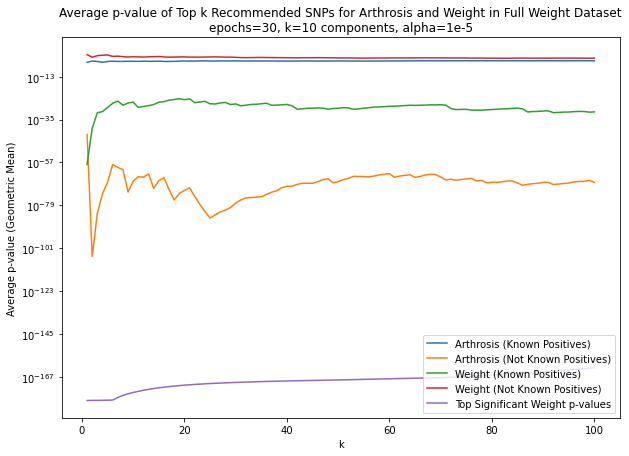

In [91]:
fig = plt.figure(figsize=(10, 7))
fig.patch.set_facecolor('white')
plt.yscale('log')

plt.plot(range(1, 101), top_k_ave_pvals_arthrosis_kp_weight)
plt.plot(range(1, 101), top_k_ave_pvals_arthrosis_weight)
plt.plot(range(1, 101), top_k_ave_pvals_weight_kp_weight)
plt.plot(range(1, 101), top_k_ave_pvals_weight_weight)
plt.plot(range(1, 101), top_k_ave_pvals_full_weight_data_first_100_pvalues)


plt.legend(['Arthrosis (Known Positives)', 'Arthrosis (Not Known Positives)', 'Weight (Known Positives)', 'Weight (Not Known Positives)', 'Top Significant Weight p-values'], loc='lower right')
plt.xlabel('k')
plt.ylabel('Average p-value (Geometric Mean)')
plt.title('Average p-value of Top k Recommended SNPs for Arthrosis and Weight in Full Weight Dataset\nepochs=30, k=10 components, alpha=1e-5')#gwas_model_e30_d10_reg00001

In [53]:
trait = '#Arthrosis'
return_list = []
n_traits, n_snps = data_e30_d10_reg00001['train'].shape
trait_ind = ts[ts['Trait'] == trait]['trait_ind'].tolist()[0]
#SNPs known to relate to the trait
known_ranked_df = ts[(ts['Trait']==trait)].sort_values('pval_mlog', ascending=False)
known_ranked = list(known_ranked_df['snp_ind'])

known_ind = list(set(known_ranked))
ki_series = pd.Series(known_ind)

#SNPs model predicts that relate to trait
filtered_scores = gwas_model_e30_d10_reg00001.predict(trait_ind, np.array(known_ind))
#rank from most related to least
filtered_top_snps = [np.argsort(-filtered_scores)][0]
top_SNPs = ki_series[filtered_top_snps]

trait_list=[]
ts_first = ts.groupby(by=['snp_ind']).first().reset_index()
df_first = df.groupby(by=['Reference SNP cluster ID']).first()
rec_s = list(ts_first.loc[list(top_SNPs)]['Reference SNP cluster ID'])
rec_chrom = list(df_first.loc[rec_s]['Chromosome'])
rec_p1 = list(df_first.loc[rec_s]['p1'])
rec_p2 = list(df_first.loc[rec_s]['p2'])
trait_list.append(rec_s)
trait_list.append(rec_chrom)
trait_list.append(rec_p1)
trait_list.append(rec_p2)
trait_list.append(list(np.array(filtered_scores)[filtered_top_snps]))
return_list.append(trait_list)
rec_info_arthrosis_kp = return_list

In [54]:
full_data_check_arthrosis_kp_arthrosis = check_full_data(arthrosis_df, rec_info_arthrosis_kp[0][0][:100])

100 matches


In [69]:
full_data_check_weight_kp_arthrosis = check_full_data(arthrosis_df, rec_info_weight_kp[0][0][:100])

100 matches


In [55]:
full_data_check_weight_arthrosis = check_full_data(arthrosis_df, rec_info_weight[0][0][:100])

100 matches


In [59]:
full_data_check_arthrosis_arthrosis = check_full_data(arthrosis_df, rec_info_arthrosis[0][0][:100])

100 matches


In [70]:
weight_arthrosis_list = []
for data, check in zip(rec_info_weight[0][0], full_data_check_weight_arthrosis):
    weight_arthrosis_list.append(float(check[0][4]))
    
arthrosis_kp_arthrosis_list = []
for data, check in zip(rec_info_arthrosis_kp[0][0], full_data_check_arthrosis_kp_arthrosis):
    arthrosis_kp_arthrosis_list.append(float(check[0][4]))
    
arthrosis_arthrosis_list = []
for data, check in zip(rec_info_arthrosis[0][0], full_data_check_arthrosis_arthrosis):
    arthrosis_arthrosis_list.append(float(check[0][4]))

weight_kp_arthrosis_list = []
for data, check in zip(rec_info_weight_kp[0][0], full_data_check_weight_kp_arthrosis):
    weight_kp_arthrosis_list.append(float(check[0][4]))

In [61]:
arthrosis_df['p-value'] = arthrosis_df['p-value'].astype(float)
full_arthrosis_data_first_100_pvalues = list(arthrosis_df.sort_values(['p-value'])['p-value'])[:100] 

In [71]:
top_k_ave_pvals_full_arthrosis_data_first_100_pvalues = top_k_ave_p(full_arthrosis_data_first_100_pvalues)
top_k_ave_pvals_arthrosis_arthrosis = top_k_ave_p(arthrosis_arthrosis_list)
top_k_ave_pvals_arthrosis_kp_arthrosis = top_k_ave_p(arthrosis_kp_arthrosis_list)
top_k_ave_pvals_weight_arthrosis = top_k_ave_p(weight_arthrosis_list)
top_k_ave_pvals_weight_kp_arthrosis = top_k_ave_p(weight_kp_arthrosis_list)

Text(0.5, 1.0, 'Average p-value of Top k Recommended SNPs for Arthrosis and Weight in Full Arthrosis Dataset\nepochs=30, k=10 components, alpha=1e-5')

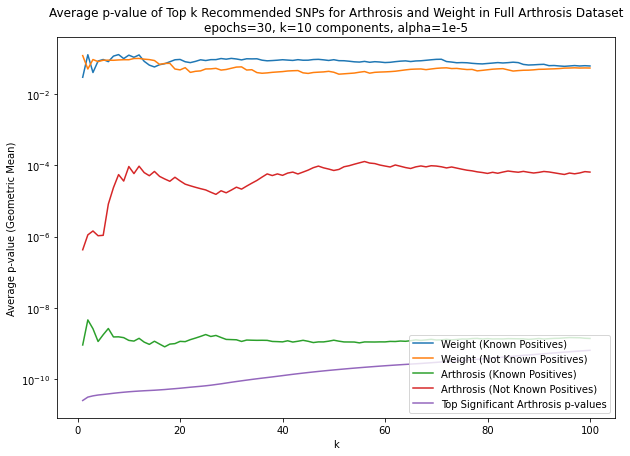

In [92]:
fig = plt.figure(figsize=(10, 7))
fig.patch.set_facecolor('white')
plt.yscale('log')
plt.plot(range(1, 101), top_k_ave_pvals_weight_kp_arthrosis)
plt.plot(range(1, 101), top_k_ave_pvals_weight_arthrosis)
plt.plot(range(1, 101), top_k_ave_pvals_arthrosis_kp_arthrosis)
plt.plot(range(1, 101), top_k_ave_pvals_arthrosis_arthrosis)
plt.plot(range(1, 101), top_k_ave_pvals_full_arthrosis_data_first_100_pvalues)


plt.legend(['Weight (Known Positives)', 'Weight (Not Known Positives)', 'Arthrosis (Known Positives)', 'Arthrosis (Not Known Positives)', 'Top Significant Arthrosis p-values'], loc='lower right')
plt.xlabel('k')
plt.ylabel('Average p-value (Geometric Mean)')
plt.title('Average p-value of Top k Recommended SNPs for Arthrosis and Weight in Full Arthrosis Dataset\nepochs=30, k=10 components, alpha=1e-5')

In [139]:
#these snps exist in arthrosis recommendations but not in known positive weight recs
not_in_rec_info_weight_kp = ['rs7193038', 'rs13401333', 'rs13428823', 'rs73572177', 'rs6995407', 'rs12927052', 'rs12921407', 'rs7192213', 'rs8052225', 'rs12925429', 'rs8049373', 'rs11417831', 'rs4821741', 'rs6677960', 'rs73568154', 'rs12927168', 'rs8063226', 'rs59989839', 'rs1500337', 'rs3790078', 'rs6682581', 'rs8044876', 'rs2362642', 'rs12925700', 'rs11390043', 'rs12598642', 'rs555625140', 'rs6499263', 'rs2012725', 'rs552338537', 'rs881984', 'rs12926791', 'rs62027787', 'rs7526373', 'rs7569646', 'rs4373767', 'rs4146819', 'rs7563834', 'rs12919094', 'rs3790080', 'rs1466863', 'rs6720422', 'rs3762177', 'rs12446197', 'rs1561289', 'rs143311886', '6:98326220_GC_G', 'rs713468', 'rs9387823', 'rs7544369', 'rs7190013', 'rs1368740', 'rs4665766', 'rs12493461', 'rs6738297']

In [237]:
#looking into where the SNP recs for Arthrosis are located in the known positive recs for weight
#taking first 1100 SNPs
rec_info_arthrosis_SNP_ids_np = np.array(rec_info_arthrosis[0][0][:1100])
print(len(rec_info_arthrosis_SNP_ids_np))
not_in_rec_info_weight_kp_np = np.array(not_in_rec_info_weight_kp)
#removing SNPs from first 1000 arthrosis recs that do not exist in weight kp recs from arthrosis recs list
rec_info_arthrosis_SNP_ids_filtered = list(rec_info_arthrosis_SNP_ids_np[~np.isin(rec_info_arthrosis_SNP_ids_np, not_in_rec_info_weight_kp_np)])
print(len(rec_info_arthrosis_SNP_ids))
print(len(not_in_rec_info_weight_kp))
#finding rec position of SNPs recommended for arthrosis in list of weight recs
rec_info_arthrosis_SNP_ids_filtered = rec_info_arthrosis_SNP_ids_filtered[:1000]
rec_info_weight_kp_SNP_ids = rec_info_weight_kp[0][0]
rec_info_weight_kp_SNP_ids_df = pd.DataFrame(rec_info_weight_kp_SNP_ids, columns=['Reference SNP cluster ID'])
rec_info_weight_kp_SNP_ids_df['position'] = rec_info_weight_kp_SNP_ids_df.index
rec_info_weight_kp_SNP_ids_ser = rec_info_weight_kp_SNP_ids_df.set_index(['Reference SNP cluster ID'])['position']
position_arthrosis_recs_in_weight_kp_recs = list(rec_info_weight_kp_SNP_ids_ser[rec_info_arthrosis_SNP_ids_filtered])

1100
1000
55


In [203]:
rec_info_weight_kp_SNP_ids_ser['rs6088812']

8224

In [174]:
#verification
print(position_arthrosis_recs_in_weight_kp_recs[999])
print(rec_info_arthrosis_SNP_ids_filtered[999])
print(rec_info_weight_kp[0][0][4613])

4613
rs7238450
rs7238450


Text(0.5, 0.98, 'Comparing SNP Recommendation Positions for Arthrosis and Known Positive Weight Recommendations\nepochs=30, k=10 dimensions, a=1e-5')

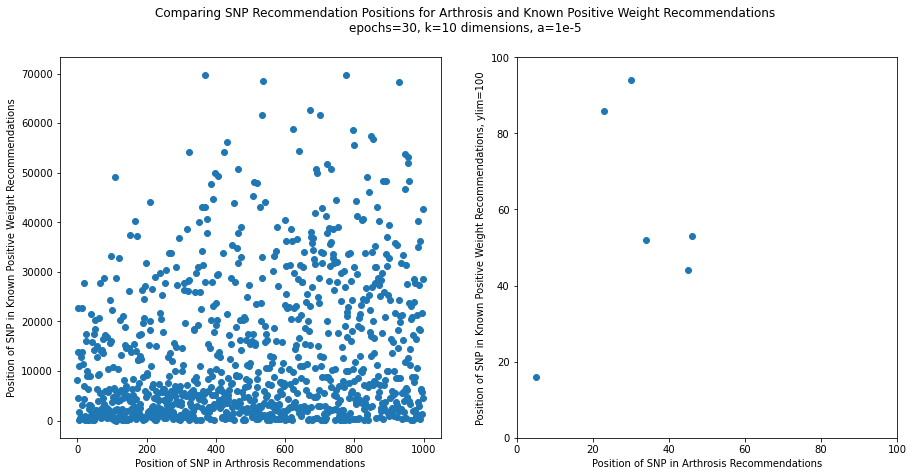

In [207]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15,7))
# fig = plt.figure(figsize=(12, 10))
fig.patch.set_facecolor('white')
ax1.scatter(range(len(position_arthrosis_recs_in_weight_kp_recs)), position_arthrosis_recs_in_weight_kp_recs)
ax2.scatter(range(len(position_arthrosis_recs_in_weight_kp_recs)), position_arthrosis_recs_in_weight_kp_recs)
ax2.set_ylim(0,100)
ax2.set_xlim(0,100)

# ax1.set_title('No ylim')
# ax2.set_title('ylim=2500')
ax1.set_xlabel('Position of SNP in Arthrosis Recommendations')
ax1.set_ylabel('Position of SNP in Known Positive Weight Recommendations')
ax2.set_xlabel('Position of SNP in Arthrosis Recommendations')
ax2.set_ylabel('Position of SNP in Known Positive Weight Recommendations, ylim=100')
fig.suptitle('Comparing SNP Recommendation Positions for Arthrosis and Known Positive Weight Recommendations\nepochs=30, k=10 dimensions, a=1e-5')

In [176]:
print(position_arthrosis_recs_in_weight_kp_recs.index(0))
print(rec_info_weight_kp[0][0][0])
print(rec_info_arthrosis_SNP_ids_filtered[111])

111
rs6785012
rs6785012


In [211]:
print(position_arthrosis_recs_in_weight_kp_recs.index(16))
print(rec_info_weight_kp[0][0][16])
print(rec_info_arthrosis[0][0][5])
print(full_data_check_weight_kp_weight[16])
print(full_data_check_arthrosis_weight[5])
print(weight_kp_weight_list[16])
print(arthrosis_weight_list[5])
first_100

5
rs66495454
rs66495454
[['chr1', '72282884', '72282885', 'rs66495454', '2.75208e-13']]
[['chr1', '72282884', '72282885', 'rs66495454', '2.75208e-13']]
2.75208e-13
2.75208e-13


array([ 8224,  4462, 22631, 13895, 10903,    16,  1690,   570,   234,
         396, 12900,   624, 13813,  3041, 22773, 11329,   445,   505,
        6879,  4334, 27840,   317,   885,    86,   302, 16050, 17544,
         336,  9907,  9027,    94,  6288,   541,  3087,    52,  2269,
        3217,  9077, 21561,  2966,  1196,  1247, 15896,  1229,   306,
          44,    53, 17407,   175, 14195, 20329,   577, 18429,  1012,
         827,  2175, 14967, 12772,  6352,  9273,  1739,  3966, 20763,
        9328,  2189,  5478, 27751, 13952,   451,  1369,   651, 14302,
        2553, 13645, 16527,  4619,  2101, 28792,  3370,  6021,  1158,
       17239,  2278,   974,   902,   441,  2456, 16842,  5828, 10402,
        2033,   753,  6375, 15720, 24224,  1708, 16139,   548, 33121,
        1047])

In [220]:
first_100 = position_arthrosis_recs_in_weight_kp_recs[:100]
first_100 = np.array(first_100)
rec_info_arthrosis_SNP_ids_filtered_np = np.array(rec_info_arthrosis_SNP_ids_filtered)
print(rec_info_arthrosis_SNP_ids_filtered_np[np.where(first_100<100)])
print(rec_info_weight_kp_SNP_ids_ser.iloc[first_100[np.where(first_100<100)]])
print(weight_df[weight_df['Reference SNP cluster ID']=='rs66495454'])
print()
print(weight_df[weight_df['Reference SNP cluster ID']=='rs7202116'])
print()
print(weight_df[weight_df['Reference SNP cluster ID']=='3:49959071_CT_C'])
print()
print(weight_df[weight_df['Reference SNP cluster ID']=='rs6749087'])
print()
print(weight_df[weight_df['Reference SNP cluster ID']=='rs13029479'])
print()
print(weight_df[weight_df['Reference SNP cluster ID']=='rs3101339'])

['rs66495454' 'rs7202116' '3:49959071_CT_C' 'rs6749087' 'rs13029479'
 'rs3101339']
Reference SNP cluster ID
rs66495454         16
rs7202116          86
3:49959071_CT_C    94
rs6749087          52
rs13029479         44
rs3101339          53
Name: position, dtype: int64
       Chromosome     Start       End Reference SNP cluster ID       p-value
327266       chr1  72282884  72282885               rs66495454  2.752080e-13

        Chromosome     Start       End Reference SNP cluster ID        p-value
4512634      chr16  53787703  53787704                rs7202116  7.477830e-168

        Chromosome     Start       End Reference SNP cluster ID       p-value
7824132       chr3  49921638  49921639          3:49959071_CT_C  2.372320e-29

        Chromosome   Start     End Reference SNP cluster ID       p-value
5778979       chr2  629818  629819                rs6749087  3.116530e-69

        Chromosome   Start     End Reference SNP cluster ID       p-value
5779247       chr2  655222  655223   

In [249]:
#setting up precision and recall calculations for arthrosis recs where positives = Known positive snps for weight
weight_kp_set = set(list(ts[ts['Trait']=='Weight']['Reference SNP cluster ID']))
arthrosis_recs_in_weight_kp_count = []
for i in rec_info_arthrosis[0][0]:
    if i in weight_kp_set:
        arthrosis_recs_in_weight_kp_count.append(1)
    else:
        arthrosis_recs_in_weight_kp_count.append(0)

In [248]:
k_vals = list(range(1, 1000))
k_vals.extend(list(np.arange(1000, len(rec_info_arthrosis[0][0]), 1000)))
print(len(k_vals))

3088


In [250]:
#calculating precision and recall for arthrosis recs where positives = Known positive snps for weight
arthrosis_recs_in_weight_kp_precision = []
arthrosis_recs_in_weight_kp_recall = []
total_sum = np.sum(arthrosis_recs_in_weight_kp_count)
for k in k_vals:
    count = np.sum(arthrosis_recs_in_weight_kp_count[:k])
    arthrosis_recs_in_weight_kp_precision.append(count/k)
    arthrosis_recs_in_weight_kp_recall.append(count/total_sum)

In [272]:
ts_traits_equal_arthrosis = ts[ts['Trait']=='#Arthrosis']
ts_traits_equal_weight = ts[ts['Trait']=='Weight']
ts_merged = ts_traits_equal_arthrosis.merge(ts_traits_equal_weight, left_on='Reference SNP cluster ID', right_on='Reference SNP cluster ID')
len(ts_merged)

19

In [274]:
len(ts_traits_equal_weight)-total_sum

19

Text(0.5, 1.0, 'Precision-Recall Curve for Arthrosis Recommendations where "Positives" are Known Positive SNPs for Weight\nepochs=30, k=10 components, alpha=1e-5')

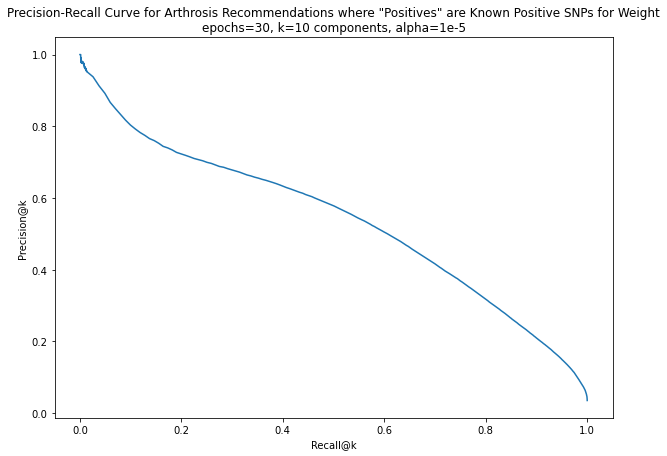

In [297]:
#Plot precision-recall curves for train and test data (1 epochs, 1 dimensions)
fig = plt.figure(figsize=(10,7))
fig.patch.set_facecolor('white')
plt.plot(arthrosis_recs_in_weight_kp_recall, arthrosis_recs_in_weight_kp_precision)
plt.xlabel('Recall@k')
plt.ylabel('Precision@k')
plt.title('Precision-Recall Curve for Arthrosis Recommendations where "Positives" are Known Positive SNPs for Weight\nepochs=30, k=10 components, alpha=1e-5')

**Looking at Printers known positives**

In [32]:
rec_info_printers = sample_recommendation(gwas_model_e30_d10_reg00001, data_e30_d10_reg00001, ['Job SOC coding: Printers'], print_num=10)

Disease: Job SOC coding: Printers (1649)
   Known Positives (2308):
      Reference SNP cluster ID: rs142221565, chr3:69104483-69104484, p-value = 4.24538e-164
      Reference SNP cluster ID: rs150743530, chr3:69193651-69193652, p-value = 1.47383e-163
      Reference SNP cluster ID: rs529513858, chr2:32209554-32209555, p-value = 1.55027e-163
      Reference SNP cluster ID: rs79506707, chr11:6794934-6794935, p-value = 1.84679e-163
      Reference SNP cluster ID: rs182221550, chr18:62838830-62838831, p-value = 2.22561e-163
      Reference SNP cluster ID: rs182355775, chr2:73816829-73816830, p-value = 2.32349e-163
      Reference SNP cluster ID: rs113652317, chr2:73780092-73780093, p-value = 2.32349e-163
      Reference SNP cluster ID: rs111539317, chr2:73775051-73775052, p-value = 2.34247e-163
      Reference SNP cluster ID: rs147626836, chr2:73766413-73766414, p-value = 2.34247e-163
      Reference SNP cluster ID: rs140434296, chr11:6785459-6785460, p-value = 2.40960e-163
      ...

   

In [33]:
printers_df['p-value'] = printers_df['p-value'].astype(float)
printers_df.sort_values('p-value')

,Chromosome,Start,End,Reference SNP cluster ID,p-value
7918796,chr3,69104483,69104484,rs142221565,4.245380e-164
7919300,chr3,69193651,69193652,rs150743530,1.473830e-163
5938939,chr2,32209554,32209555,rs529513858,1.550270e-163
1766749,chr11,6794934,6794935,rs79506707,1.846790e-163
5368992,chr18,62838830,62838831,rs182221550,2.225610e-163
...,...,...,...,...,...
13767910,chrX,148024871,148024872,rs138961586,NaN
13784908,chrX,153864647,153864648,rs782260124,NaN
13786001,chrX,154461419,154461420,rs145615075,NaN
13786047,chrX,154478417,154478418,rs782786534,NaN


**Looking into if the recs for a given trait are next in line in the full dataset**

In [34]:
rec_info = sample_recommendation(gwas_model_e30_d10_reg00001, data_e30_d10_reg00001, ['#Arthrosis', 'Malignant melanoma of skin', 'Weight', 'Seropositive rheumatoid arthritis', 'Job SOC coding: Printers'], print_num=1)
rec_info_arthrosis_SNPs = rec_info[0][0]
rec_info_melanoma_SNPs = rec_info[1][0]
rec_info_weight_SNPs = rec_info[2][0]
rec_info_sra_SNPs = rec_info[3][0]
rec_info_printers_SNPs = rec_info[4][0]

Disease: #Arthrosis (0)
   Known Positives (237):
      Reference SNP cluster ID: rs559230165, chr1:219580670-219580671, p-value = 2.51849e-11
      ...

   Recommended:
      Reference SNP cluster ID: rs6088812, chr20:35386360-35386361
Disease: Malignant melanoma of skin (2108)
   Known Positives (1801):
      Reference SNP cluster ID: rs201432166, chr1:176699286-176699287, p-value = 1.14919e-50
      ...

   Recommended:
      Reference SNP cluster ID: rs371089226, chr22:38599874-38599875
Disease: Weight (3744)
   Known Positives (72606):
      Reference SNP cluster ID: rs11642015, chr16:53768582-53768583, p-value = 1.14192e-191
      ...

   Recommended:
      Reference SNP cluster ID: rs10840357, chr11:10069431-10069432
Disease: Seropositive rheumatoid arthritis (2888)
   Known Positives (4459):
      Reference SNP cluster ID: rs374013240, chr22:38638800-38638801, p-value = 1.61150e-242
      ...

   Recommended:
      Reference SNP cluster ID: rs9273391, chr6:32659266-32659267
Dis

In [33]:
trait_names = ['arthrosis', 'melanoma', 'weight', 'sero_rheuma_arthritis', 'printers']
traits = ['#Arthrosis', 'Malignant melanoma of skin', 'Weight', 'Seropositive rheumatoid arthritis', 'Job SOC coding: Printers']

In [36]:
pickle_out_recs = open('/home/ctrader/Hold/GWAS/gwas_model_e30_d10_reg00001_rec_info_arthrosis_melanoma_weight_sra_printers.pickle', 'wb')
pickle.dump(rec_info, pickle_out_recs)
pickle_out_recs.close()

In [34]:
pickle_in = open('/home/ctrader/Hold/GWAS/gwas_model_e30_d10_reg00001_rec_info_arthrosis_melanoma_weight_sra_printers.pickle', 'rb')
rec_info=pickle.load(pickle_in)
rec_info_arthrosis_SNPs = rec_info[0][0]
rec_info_melanoma_SNPs = rec_info[1][0]
rec_info_weight_SNPs = rec_info[2][0]
rec_info_sra_SNPs = rec_info[3][0]
rec_info_printers_SNPs = rec_info[4][0]

In [46]:
#takes in dataframe of all known associations with trait of interest and a list of SNPs. Returns a 
#list of associations found between the trait and the given SNPs. 
def check_full_data_2(full_data, snp_recs):
    full_data_ser = full_data.set_index('Reference SNP cluster ID')['p-value']
    ordered_pvals = full_data_ser[snp_recs]
    return ordered_pvals

In [35]:
full_data_check_arthrosis_10000 = list(check_full_data_2(arthrosis_df, rec_info_arthrosis_SNPs[:10000]))
full_data_check_melanoma_10000 = list(check_full_data_2(melanoma_skin_df, rec_info_melanoma_SNPs[:10000]))
full_data_check_weight_10000 = list(check_full_data_2(weight_df, rec_info_weight_SNPs[:10000]))
full_data_check_sra_10000 = list(check_full_data_2(rheu_seropos_df, rec_info_sra_SNPs[:10000]))
full_data_check_printers_10000 = list(check_full_data_2(printers_df, rec_info_printers_SNPs[:10000]))

In [36]:
full_data_check_2_pvals = [full_data_check_arthrosis_10000, full_data_check_melanoma_10000, full_data_check_weight_10000, full_data_check_sra_10000, full_data_check_printers_10000]

In [48]:
ranks = list(range(10000))

In [40]:
#saving recs as bed files for iceberg plots
today = date.today()
for j in range(len(traits)):
    bed_path_name = os.path.join('/home/ctrader/Hold/GWAS/recommendations/', 'GWAS_e30_d10_reg00001_rec_info_' + trait_names[j] + '_CT' + today.strftime("%Y%m%d") + '.bed')
    f= open(bed_path_name, 'w')
    for i in range(10000):
        f.write(rec_info[j][1][i] + '\t' + str(rec_info[j][2][i]) + '\t' + str(rec_info[j][3][i]) + '\t' + str(rec_info[j][4][i]) + '\t' + str(rec_info[j][0][i]) + '\t' + str(full_data_check_2_pvals[j][i]) + '\t' + str(ranks[i]) + '\n')
    f.close()

In [302]:
#Arthrosis
arthrosis_df['p-value'] = arthrosis_df['p-value'].astype(float)
arthrosis_df = arthrosis_df.sort_values('p-value')
arthrosis_df_non_significant = arthrosis_df[arthrosis_df['p-value']>5e-8]
arthrosis_df_non_significant = arthrosis_df_non_significant.reset_index()
arthrosis_df_non_significant['index'] = arthrosis_df_non_significant.index
arthrosis_df_non_significant = arthrosis_df_non_significant.set_index(['Reference SNP cluster ID'])
arthrosis_df_non_significant_ser = arthrosis_df_non_significant['index']
non_significant_arthrosis_recs_position = list(arthrosis_df_non_significant_ser[rec_info_arthrosis_SNPs])

In [38]:
#Malignant melanoma of the skin
melanoma_skin_df['p-value'] = melanoma_skin_df['p-value'].astype(float)
melanoma_skin_df = melanoma_skin_df.sort_values('p-value')
melanoma_skin_df_non_significant = melanoma_skin_df[melanoma_skin_df['p-value']>5e-8]
melanoma_skin_df_non_significant = melanoma_skin_df_non_significant.reset_index()
melanoma_skin_df_non_significant['index'] = melanoma_skin_df_non_significant.index
melanoma_skin_df_non_significant = melanoma_skin_df_non_significant.set_index(['Reference SNP cluster ID'])
melanoma_skin_df_non_significant_ser = melanoma_skin_df_non_significant['index']
non_significant_melanoma_recs_position = list(melanoma_skin_df_non_significant_ser[rec_info_melanoma_SNPs])

In [39]:
#Weight
weight_df['p-value'] = weight_df['p-value'].astype(float)
weight_df = weight_df.sort_values('p-value')
weight_df_non_significant = weight_df[weight_df['p-value']>5e-8]
weight_df_non_significant = weight_df_non_significant.reset_index()
weight_df_non_significant['index'] = weight_df_non_significant.index
weight_df_non_significant = weight_df_non_significant.set_index(['Reference SNP cluster ID'])
weight_df_non_significant_ser = weight_df_non_significant['index']
#these two SNPs do not exist in full dataset
rec_info_weight_SNPs.remove('rs370681036')
rec_info_weight_SNPs.remove('rs190413347')
non_significant_weight_recs_position = list(weight_df_non_significant_ser[rec_info_weight_SNPs])

In [40]:
#Seropositive rheumatoid arthritis
rheu_seropos_df['p-value'] = rheu_seropos_df['p-value'].astype(float)
rheu_seropos_df = rheu_seropos_df.sort_values('p-value')
rheu_seropos_df_non_significant = rheu_seropos_df[rheu_seropos_df['p-value']>5e-8]
rheu_seropos_df_non_significant = rheu_seropos_df_non_significant.reset_index()
rheu_seropos_df_non_significant['index'] = rheu_seropos_df_non_significant.index
rheu_seropos_df_non_significant = rheu_seropos_df_non_significant.set_index(['Reference SNP cluster ID'])
rheu_seropos_df_non_significant_ser = rheu_seropos_df_non_significant['index']
non_significant_rheu_seropos_recs_position = list(rheu_seropos_df_non_significant_ser[rec_info_sra_SNPs])

In [41]:
not_in_printers_non_significant_full_data = ['rs77815840', 'rs201447515', 'rs563719782', 'rs368625295', 'rs539769126', 'rs147221532', 'rs546077003', 'rs151260103', 'rs530416232', 'rs140519341', 'rs104895430', 'rs555980638', 'rs148100123', 'rs148497570', 'rs185114210', 'rs188571773', 'rs540591044', 'rs576303490', 'rs553708686', 'rs547824816', 'rs201880929', 'rs373998853', 'rs114556043', 'rs201081714', 'rs537630641', 'rs139804478', 'rs116420052', 'rs201469408', 'rs147622465', 'rs6716782', 'rs529871486', 'Affx-89008190', 'rs369544043', 'rs140341744', 'rs151287310', 'rs149699425', 'rs150580252', 'rs72931627', 'rs151021379', 'rs148631523', 'rs200858786', 'rs61734960', 'rs537335234', 'rs557282296', 'rs2229107', 'rs12242384', 'rs199531593', 'rs143088014', 'rs201938176', 'rs56737889', 'rs577545383', 'rs150527574', 'rs373859283', 'rs137908658', 'rs61751154', 'rs199997948', 'rs149696931', 'rs200024416', 'rs150727372', 'rs34824876', 'rs147573752', 'rs149500485', 'rs140228766', 'rs200625438', 'rs192965228', 'rs111572553', 'rs202105292', 'rs148432146', 'rs376632669', 'rs55872061', 'rs530800595', 'rs376005400', 'rs565400729', 'rs530733277', 'rs138659144', 'rs183862699', 'rs542993646', 'rs148365707', 'rs561562230', 'rs115232659', 'rs145342112', 'rs77054338', 'rs547900184', 'rs191728325', 'rs75589461', 'rs147746065', 'rs192996860', 'rs573471533', 'rs61735520', 'rs563363846', 'rs60180055', 'rs201845569', 'rs141168573', 'rs114840330', 'rs41313031', 'rs140145107', 'rs545371063', 'rs546124449', 'rs141933761', 'rs143945485', 'rs149572207', 'rs544368328', 'rs143560777', 'rs148409263', 'rs138524298', 'rs535257518', 'rs574889711', 'rs567697961', 'rs369362135', 'rs142716458', 'rs115322542', 'rs146642388', 'rs141355470', 'rs149689401', 'rs145906734', 'rs538106019', 'rs137998120', 'rs142336603', 'rs550861405', 'rs145130069', 'rs200634890', 'rs7262873', 'rs61740627', 'rs563417218', 'rs374025310', 'rs540565978', 'rs200528144', 'rs145678669', 'rs139808535', 'rs142225522', 'rs559151727', 'rs147497475', 'rs145329488', 'rs186282504', 'rs148302547', 'rs144135379', 'rs570566550', 'rs142271678', 'rs556474084', 'rs368042301', 'rs190602542', 'rs112315516', 'rs182857825', 'rs142540692', 'rs76985854', 'rs564362481', 'rs530773745', 'rs141451008', 'rs564905233', 'rs187627402', 'rs561071711', 'rs542759861', 'rs185704507', 'rs139940282', 'rs61733022', 'rs144946747', 'rs138645358', 'rs142256935', 'rs2845563', 'rs185019136', 'rs556531467', 'rs555395531', 'rs144743183', 'rs539675158', 'rs543724783', 'rs140513282', 'rs148105276', 'rs61731722', 'rs148874863', 'rs201116726', 'rs148348903', 'rs148463763', 'rs61750625', 'rs561675338', 'rs142548792', 'rs115379999', 'rs57750167', 'rs144024361', 'rs533020242', 'rs147011033', 'rs2296651', 'rs185142903', 'rs148576098', 'rs34854792', 'rs113062643', 'rs181938117', 'rs144168661', 'rs374426095', 'rs17884957', 'rs191753687', 'rs199672137', 'rs142257239', 'rs111441932', 'rs139674390', 'rs138787768', 'rs556307695', 'rs544624379', 'rs561882274', 'rs372529845', 'rs200519273', 'rs150127553', 'rs114536874', 'rs200262580', 'rs112954305', 'rs587595911', 'rs143564151', 'rs201270462', 'rs368953418', 'rs142708410', 'rs551421793', 'rs531082359', 'rs140072002', 'rs186244950', 'rs573094394', 'rs200750351', 'rs193164370', 'rs201023213', 'rs151173074', 'rs76710074', 'rs545371945', 'rs35720727', 'rs578154613', 'rs563171879', 'rs377554974', 'rs17222632', 'rs139560074', 'rs144514511', 'rs143406914', 'rs11541541', 'rs35339236', 'rs369656195', 'rs185710659', 'rs533945076', 'rs200350605', 'rs575983394', 'rs377135624', 'rs201178550', 'rs143156281', 'rs546759760', 'rs532344850', 'rs201350340', 'rs201925617', 'rs150595875', 'rs139283268', 'rs17885655', 'rs146242609', 'rs146184522', 'rs144614902', 'rs114463099', 'rs186942770', 'rs551797269', 'rs201270274', 'rs200584784', 'rs188733917', 'rs571863743', 'rs140507994', 'rs199543162', '19:58363718_TG_T', 'rs143338649', 'rs201714190', 'rs149181442', 'rs374744704', 'rs138612527', 'rs144536215', 'rs374769239', 'rs3213173', 'rs147993981', 'rs577344713', 'rs534737466', 'rs148541483', 'rs114108445', 'rs145492156', 'rs111726902', 'rs554100812', 'rs201169452', 'rs533692248', 'rs542299684', 'rs147406105', 'rs137945646', 'rs564744260', '9:140325685_T_G', 'rs115096288', 'rs201173138', 'rs189246389', 'rs202107729', 'rs558641758', 'rs200102494', 'rs77984885', 'rs564653772', 'rs201768717', 'rs147284380', 'rs537876996', 'rs138771137', 'rs142816072', 'rs111749614', 'rs138477419', 'rs112181735', 'rs143568996', 'rs150407754', 'rs552756954', 'rs145519146', '9:140196334_C_A', 'rs138087514', 'rs146834034', 'rs201653433', 'rs144724549', 'rs548158408', '9:140328773_C_T', 'rs377732143', 'rs148327567', 'rs201539021', 'rs372440713', 'rs181020996', 'rs554920046', 'rs372611802', 'rs185393063', 'rs372309426', 'rs531793725', 'rs150055938', 'rs56391084', 'rs370457949', 'rs72999042', 'rs7128237', 'rs544106020', '19:58102635_AAC_A', 'rs199793257', 'rs371819463', 'rs372930527', 'rs2228271', 'rs144694933', 'rs149658464', 'rs200383612', 'rs144507273', 'rs541244427', 'rs375679720', 'rs200530619', 'rs138799538', 'rs200759347', 'rs147122911', 'rs180969361', 'rs145803209', 'rs531746754', 'rs149174692', 'rs570571625', 'rs563372059', 'rs556768733', 'rs116815894', 'rs538127489', 'rs371623584', 'rs200532772', 'rs201039935', 'rs575596742', 'rs529125628', 'rs149060494', 'rs111883392', 'rs146423675', 'rs200002676', 'rs558490742', 'rs140988229', 'rs150682094', 'rs148873732', 'rs199676790', 'rs534197455', 'rs137909519', 'rs567605468', 'rs147461403', 'rs143087318', 'rs368913580', 'rs73394756', 'rs551459565', 'rs142173097', 'rs151213644', 'rs144905283', 'rs76300532', 'rs114232288', 'rs2069380', 'rs150246562', 'rs576239233', 'rs189728809', 'rs143528608', 'rs571350661', 'rs143191258', 'rs116615990', 'rs202155357', 'rs568451027', 'rs200004303', 'rs199776201', 'rs143610596', 'rs138968424', 'rs537538033', 'rs371544634', 'rs575568934', 'rs11567962', 'rs553354514', 'rs532318094', 'rs569453359', 'rs552056481', 'rs561949979', 'rs574994287', 'rs74482326', 'rs12948434', 'rs552234260', 'rs141369006', 'rs140575096', 'rs550459981', 'rs78479224', 'rs370218166', 'rs147657405', 'rs150533375', 'rs147045782', 'rs572784064', 'rs554052175', 'rs138583401', 'rs571125128', 'rs568977268', 'rs143889768', 'rs374249911', 'rs114604356', 'rs147563485', 'rs151336429', 'rs151311268', 'rs200869545', 'rs536285042', 'rs527661866', 'rs112600680', 'rs145763601', 'rs200868600', '16:1271793_CAG_C', 'rs139679398', 'rs374231043', 'rs147930036', 'rs138168899', 'rs143969346', 'rs369899875', 'rs189594633', 'rs200569240', 'rs148457506', 'rs371522346', 'rs202096200', 'rs147984058', 'rs545917447', 'rs115374113', 'rs138259370', 'rs142051981', 'rs577400119', 'rs142884205', 'rs530601467', 'rs188404201', 'rs199885473', 'rs185552042', 'rs574384512', 'rs182346627', 'rs538772421', 'rs571259684', 'rs374080396', 'rs150461450', 'rs201776658', 'rs144683695', 'rs541454235', 'rs574789930', 'rs147165460', 'rs182319199', 'rs534523640', 'rs201875004', 'rs149266584', 'rs148922231', 'rs573299122', 'rs149693931', 'rs559471279', 'rs144489730', 'rs201505794', 'rs149887215', 'rs139459760', 'rs199934829', 'rs200172336', 'rs545343442', 'rs570645003', 'rs538270912', 'rs144079786', 'rs200344313', 'rs201395805', 'rs551660149', 'rs138979270', 'rs140218299', 'rs543314513', 'rs5744016', 'rs78311619', 'rs539305564', 'rs145190151', 'rs373988845', 'rs142782886', 'rs189232206', 'rs144679421', 'rs114495250', '9:140130396_G_A', 'rs145097656', 'rs369272246', 'rs576374556', 'rs61737888', 'rs564430878', 'rs141880507', 'rs11573598', 'rs199500373', 'rs149096573', 'rs371612347', 'rs34881036', 'rs141281478', 'rs191225974', 'rs112672659', 'rs141175381', 'rs150035089', 'rs148937367', 'rs187492325', 'rs182108836', 'rs547400718', 'rs370278031', 'rs144160852', 'rs115367873', 'rs184914524', 'rs565831375', 'rs186005100', 'rs201778703', 'rs549653182', 'rs142799522', 'rs144415810', 'rs555225002', 'rs73993548', 'rs145881911', 'rs149447818', 'rs140012085', 'rs143798431', 'rs533208137', 'rs148162251', 'rs201307934', 'rs551154538', 'rs199934247', 'rs189041235', 'rs146316052', 'rs201354562', 'rs575878889', 'rs150271208', 'rs530675894', 'rs373496180', 'rs138709216', 'rs199536909', 'rs369000213', 'rs543350729', 'rs200310087', 'rs142667188', 'rs143958148', 'rs192496216', 'rs139576513', 'rs147342829', 'rs531060384', 'rs115891498', 'rs142118461', 'rs139111190', 'rs140811480', 'rs77373295', 'rs143643360', 'rs182292920', 'rs562038092', 'rs368050604', 'rs141027782', 'rs567036234', 'rs575270915', 'rs147527758', 'rs140102475', 'rs531889326', '1:100626086_AGCTTGGT_A', 'rs141505678', 'rs377096813', 'rs200034773', 'rs141622697', 'rs371250005', 'rs145415310', 'rs140736445', 'rs371409662', 'rs553611640', 'rs145897230', 'rs573490046', 'rs76702938', 'rs571158691', 'rs146006151', 'rs557485083', 'rs367627396', 'rs193141134', 'rs557007416', 'rs191426106', 'rs141858181', 'rs187005190', 'rs181299906', 'rs145028680', 'rs202238258', 'rs201550948', 'rs376564487', 'rs3917429', 'rs199849336', 'rs35304756', 'rs79737608', 'rs77807333', 'rs151006917', 'rs147826913', 'rs552336969', 'rs34423210', 'rs371793819', 'rs547402777', 'rs554664280', 'rs141303233', 'rs142671314', 'rs34830712', 'rs201685421', 'rs116100727', 'rs34938201', 'rs57831260', 'rs201343502', 'rs192902075', 'rs140110202', 'rs4687793', 'rs202020703', 'rs192758588', 'rs186879295', 'rs61746364', 'rs566292000', 'rs142446757', 'rs75275319', '19:22940283_TTA_T', 'rs567716838', 'rs577303851', 'rs183792404', 'rs139143750', 'rs142369909', 'rs201720265', 'rs549374828', 'rs149445499', 'rs144937311', 'rs549493357', '9:140161737_C_T', 'rs545711298', 'rs181287620', 'rs139570211', '9:140115490_T_C', 'rs181529013', 'rs142872154', 'rs536559356', 'rs147658647', 'rs556014868', 'rs200551058', 'rs587652432', '9:35042932_GGAA_G', 'rs372513856', 'rs144377641', 'rs557412818', 'rs17184058', 'rs201775541', 'rs190978463', 'rs148930323', 'rs375439571', 'rs144269892', 'rs186054834', 'rs141383610', 'rs116197390', 'rs150831986', 'rs147673427', 'rs140575323', 'rs539762304', 'rs551933531', 'rs139388902', 'rs140664272', 'rs568567404', 'rs373784874', 'rs532234553', 'rs547803731', 'rs143883022', 'rs201846479', 'rs554680182', 'rs200272917', 'rs143293913', 'rs147087175', 'rs146616455', 'rs537795646', 'rs554835653', 'rs147419502', 'rs144827029', 'rs12091253', 'rs183644163', 'rs532463670', 'rs547551060', 'rs200074466', 'rs5998104', 'rs139329569', 'rs146153632', 'rs369961373', 'rs142902034', 'rs377716669', 'rs375056876', '9:140327689_C_G', 'rs149333067', 'rs111556626', 'rs140620720', 'rs140405180', 'rs201400073', '9:140318119_C_G', 'rs140417509', 'rs150056369', 'rs143615169', 'rs568767393', 'rs142997689', 'rs534326950', 'rs113208516', 'rs547001287', 'rs372593602', 'rs141344505', 'rs138592405', 'rs149711534', 'rs570060177', 'rs148519764', 'rs142060431', 'rs375641145', '9:140109389_G_A', 'rs201586656', 'rs78840700', 'rs369681198', 'rs533329297', 'rs372292959', 'rs140123211', 'rs572555898', 'rs116099947', 'rs146308829', 'rs200364798', 'rs200396163', 'rs142386076', 'rs139085745', 'rs150442838', 'rs571910239', 'rs200565505', 'rs147528900', 'rs565872876', 'rs147795840', 'rs371110390', 'rs542317875', 'rs374443913', 'rs564383457', 'rs569192492', 'rs374380028', 'rs148599494', 'rs376717625', 'rs535384375', 'rs367585089', 'rs144244281', '9:140128869_C_T', 'rs374709745', 'rs202039431', 'rs532001593', 'rs201992648', 'rs199721558', 'rs146343935', 'rs376434225', 'rs371162432', 'rs147095072', 'rs113146258', 'rs34928488', 'rs114079678', 'rs146285395', 'rs528479579', 'rs142608987', 'rs140297311', 'rs183047238', 'rs548206510', 'rs576527377', 'rs143602361', 'rs145268174', 'rs548351594', 'rs782260124', 'rs375221971', 'rs201524664', 'rs553617422', '9:140329525_G_C', 'rs77624079', 'rs5495', 'rs144919589', 'rs144070983', 'rs150120079', 'rs116203266', 'rs545486754', 'rs368128716', 'rs182392430', 'rs138578392', 'rs367759946', 'rs529543552', 'rs140591945', 'rs372158302', 'rs151187593', 'rs535599077', 'rs113155109', '9:140275706_T_C', 'rs151202823', 'rs116454042', 'rs111604607', 'rs141954373', 'rs73903305', 'rs564131660', 'rs564577177', 'rs571097830', 'rs369124503', 'rs116689515', 'rs782433303', 'rs574255794', 'rs143691635', 'rs199691660', 'rs147397431', 'rs61736435', 'rs140668639', 'rs373354080', 'rs35859404', 'rs144913308', 'rs200855969', 'rs140011802', 'rs559407977', 'rs531665453', 'rs782786534', 'rs372573622', 'rs148189817', 'rs547040339', 'rs146151791', 'rs569901358', 'rs201271231', 'rs143576513', 'rs146612508', 'rs35956512', 'rs556525831', 'rs143709902', 'rs540822809', '9:140248093_T_C', 'rs151149571', 'rs144269675', 'rs371268059', 'rs111624269', 'rs141882356', 'rs138423168', 'rs532062661', 'rs150470720', 'rs144635426', 'rs115290230', 'rs536672128', 'rs150341657', 'rs200561999', 'rs150795053', 'rs547123940', 'rs374419129', 'rs200065471', 'rs573681049', 'rs145670920', 'rs577356066', 'rs550094832', 'rs528017917', '9:140147162_G_T', 'rs552525010', 'rs145553596', 'rs536958788', 'rs199806972', 'rs148148316', 'rs201487340', 'rs545234511', 'rs144356897', 'rs201746064', 'rs559032408', 'rs143826988', 'rs553023026', 'rs147743758', '9:140249179_C_T', 'rs199717141', 'rs372838090', 'rs141405955', 'rs185219431', 'rs190099155', 'rs374458508', 'rs148430364', 'rs191045080', 'rs182899853', 'rs11539315', 'rs191555811', 'rs556905949', 'rs141332149', 'rs370229164', 'rs113067656', 'rs145855772', 'rs529785223', 'rs150427929', 'rs537666246', 'rs151058774', 'rs538572804', 'rs147705566', 'rs35264841', 'rs201820631', 'rs139541328', 'rs558959240', 'rs115901579', 'rs557509141', 'rs147477038', 'rs199655307', 'rs543164039', 'rs576103445', 'rs529241246', 'rs142217560', 'rs149490522', 'rs189194995', 'rs558581290', 'rs549953294', 'rs563847398', 'rs146731847', 'rs578152892', 'rs536001903', 'rs147548483', 'rs150066085', 'rs114352644', 'rs148595313', 'rs554984029', 'rs552738008', 'rs569878094', 'rs139909751', 'rs147659527', 'rs557427501', 'rs372345016', 'rs112973322', 'rs144494381', 'rs149415462', 'rs369898187', 'rs369529123', 'rs141567487', 'rs549005226', 'rs75030364', 'rs199994194', 'rs114896365', 'rs557098303', 'rs34704994', 'rs182090249', 'rs189625777', 'rs148363571', 'rs587711475', 'rs1521808', 'rs375042715', 'rs115409230', 'rs376359607', 'rs141969833', 'rs202053684', 'rs116121199', 'rs61736853', 'rs368075131', 'rs371316448', 'rs148012547', 'rs201232069', 'rs188876807', 'rs548384931', 'rs142844253', 'rs146946903', 'rs557308545', 'rs367890582', 'rs538319943', 'rs200684774', 'rs558188212', 'rs147711327', 'rs149495960', 'rs11544785', 'rs574456869', 'rs141504927', 'rs368660628', 'rs574569918', 'rs370634086', 'rs73488045', 'rs143938374', 'rs115595651', 'rs149349311', 'rs377173655', 'rs374773665', 'rs572091188', 'rs138192696', 'rs146777193', 'rs148025735', 'rs188813129', 'rs61747624', 'rs546002277', 'rs74317435', 'rs782075305', 'rs7696137', 'rs184880771', 'rs559883981', 'rs367944926', 'rs560016001', 'rs201616041', 'rs199906600', 'rs149703831', 'rs373127897', 'rs143236717', 'rs61733021', 'rs568397466', 'rs200313531', 'rs533890042', 'rs375986462', 'rs61733883', 'rs549565879', 'rs193126290', 'rs559624894', 'rs142219494', 'rs200243170', 'rs190197851', 'rs144661928', 'rs186121995', 'rs149414821', 'rs146046908', 'rs539557197', 'rs147452733', 'rs184278314', 'rs534376494', 'rs551406327', 'rs145359827', 'rs140470940', 'rs536204949', 'rs112117118', 'rs530468968', 'rs199615908', 'rs143513641', 'rs146485772', 'rs150800052', '9:140330987_C_T', 'rs113096800', 'rs372437635', 'rs577596223', 'rs535811260', 'rs201747594', 'rs146175770', 'rs189006246', 'rs549497811', 'rs113806212', 'rs150920213', 'rs201797109', 'rs112960305', 'rs570457132', 'rs148932387', 'rs563022985', 'rs148848526', 'rs201873954', 'rs372733155', 'rs202003275', 'rs143515757', 'rs112853298', 'rs200916097', 'rs369516328', 'rs190072564', 'rs371089226', 'rs545474995', 'rs200431441', 'rs146744453', 'rs114079572', 'rs182840438', 'rs5005771', 'rs368232843', 'rs145486377', 'rs553391207', 'rs199562757', 'rs141959251', 'rs373923523', 'rs16945946', 'rs140664656', 'rs202108516', 'rs143647342', 'rs188057660', 'rs74457909', 'rs372223602', 'rs139331110', 'rs556841355', 'rs186829304', 'rs55643406', 'rs74430256', 'rs138232522', 'rs74428123', 'rs548384070', 'rs186938508', '9:140087043_TCC_T', 'rs36052446', 'rs200200777', 'rs558226618', 'rs576954151', '9:140139656_C_T', 'rs375121850', 'rs144260319', 'rs145963430', 'rs141399202', 'rs150716378', 'rs535282575', 'rs116306564', 'rs548675904', 'rs192536821', 'rs187912240', 'rs115895016', 'rs149392380', 'rs530004450', 'rs369694814', 'rs542337660', 'rs147612932', 'rs149886485', 'rs142984971', 'rs77515942', 'rs558668826', 'rs143801580', 'rs182335661', 'rs370422239', 'rs76774578', 'rs557365474', 'rs144924394', 'rs560660167', 'rs541848444', 'rs191694871', 'rs566306688', 'rs112756835', 'rs375319088', 'rs180684648', 'rs201372955', 'rs571078087', 'rs549662786', 'rs184026566', 'rs78427006', 'rs368864321', 'rs563130958', 'rs114799698', 'rs112991946', 'rs142874874', 'rs138555701', 'rs184433622', 'rs75507283', 'rs143930780', 'rs147052074', 'rs201980498', 'rs143029667', 'rs186648174', 'rs374860840', 'rs528306964', 'rs374606822', 'rs141978579', 'rs569596497', 'rs370199297', 'rs150481557', 'rs569902822', 'rs568493483', 'rs533329793', 'rs564770593', 'rs147861149', 'rs201942688', 'rs569918568', 'rs17512877', 'rs116496912', 'rs146609079', 'rs562685455', 'rs566740788', 'rs150552076', 'rs147214175', '5:143757429_TTAGG_T', 'rs138677083', 'rs536931928', 'rs183001288', 'rs138635982', 'rs144662796', 'rs369417256', 'rs574794395', 'rs141377590', 'rs140332206', 'rs144234953', 'rs199909827', 'rs149721540', 'rs143518519', 'rs546842447', 'rs368807340', 'rs199615475', 'rs77963070', 'rs201648021', 'rs572402483', 'rs184758846', 'rs577626424', 'rs373674546', 'rs144441692', 'rs181566863', 'rs575456303', '9:140115257_C_A', 'rs35479032', 'rs186603174', 'rs7038451', 'rs142005186', 'rs145425294', 'rs140658331', 'rs201429460', 'rs567799767', 'rs544439135', 'rs61744574', 'rs144744180', 'rs150455097', 'rs569953104', 'rs373257450', 'rs566846367', 'rs201686460', 'rs374962575', 'rs145889610', 'rs138450053', 'rs114369311', 'rs543035977', 'rs79556800', 'rs368852045', 'rs202192406', 'rs141463671', 'rs543384323', 'rs151335104', 'rs150582291', 'rs190704778', 'rs373993220', 'rs147595873', 'rs187290995', 'rs200235342', 'rs551932836', 'rs76829163', 'rs377283955', 'rs547589952', 'rs377272529', 'rs560379786', 'rs139033408', 'rs146138646', 'rs544405143', 'rs143016806', 'rs555860663', 'rs147731637', 'rs536653446', 'rs191203557', 'rs553841906', 'rs529196333', 'rs372014231', 'rs548743423', 'rs561439651', 'rs540763634', 'rs147192886', 'rs201555141', 'rs532019224', 'rs375565374', 'rs368700420', 'rs138945081', 'rs554390480', 'rs372159380', 'rs541421744', 'rs557960190', 'rs532329476', 'rs554480269', 'rs73779542', 'rs140567712', 'rs546137847', 'rs200424451', 'rs370856154', 'rs569410899', 'rs182443406', 'rs11964847', 'rs371081137', 'rs139796030', 'rs150297508', 'rs147319497', 'rs35481467', 'rs34589480', 'rs376229752', 'rs372512148', 'rs144334321', 'rs202217070', 'rs144415900', 'rs374372464', 'rs140117865', 'rs375960143', 'rs141087114', 'rs34878592', 'rs376141767', 'rs112488180', 'rs143760165', 'rs550194728', 'rs375647301', 'rs149895631', 'rs576382288', 'rs554298331', 'rs200671433', 'rs199814928', 'rs187482608', 'rs150469831', 'rs373941516', 'rs540490736', 'rs541625725', 'rs201128714', 'rs563910734', 'rs147564718', 'Affx-52357858', 'rs190283462', 'rs141615393', 'rs149237231', 'rs181398214', 'rs80333749', 'rs140740176', 'rs192699400', 'rs149630750', 'rs548123734', 'rs201341174', 'rs201200405', 'rs539318764', '9:140130552_G_C', 'rs200878416', 'rs573591955', 'rs116704384', 'rs374576199', 'rs138689793', 'rs548726318', 'rs61746426', 'rs140460455', 'rs370336923', '9:140355171_G_A', 'rs138961586', 'rs61746437', 'rs561821620', 'rs376590878', 'rs111480507', 'rs369761537', 'rs543279513', 'rs114920421', 'rs373875040', 'rs188808287', 'rs200324593', 'rs540271797', 'rs554587235', 'rs113540514', '9:140328470_C_T', 'rs536327712', 'rs184528421', 'rs185154955', 'rs74977190', 'rs567187570', 'rs535191163', 'rs150429752', 'rs199527614', 'rs201689055', 'rs201758107', 'rs145441025', 'rs146729116', 'rs147525649', 'rs533396391', 'rs554608206', 'rs36051967', 'rs148810189', 'rs201692012', 'rs151229275', 'rs143548752', 'rs367984367', 'rs187212831', 'rs150286262', 'rs151097718', 'rs115157927', 'rs144070814', 'rs552066033', 'rs185415144', 'rs376094609', 'rs144478545', 'rs568354110', 'rs199571805', 'rs35564267', 'rs184513923', 'rs147376646', 'rs143551876', 'rs534665760', '20:35828886_GTTT_G', 'rs544952120', 'rs139517487', 'rs544678353', 'rs191043024', 'rs564125876', 'rs140545738', 'rs76354260', 'rs368118296', 'rs138557303', 'rs576524440', 'rs138109375', 'rs376077607', 'rs139574362', 'rs544032037', 'rs144900653', 'rs377407385', 'rs368422640', 'rs575274016', 'rs200246753', 'rs533678426', 'rs139609139', 'rs201222417', 'rs151338960', 'rs149809382', 'rs116478335', 'rs528631558', 'rs377382154', 'rs149568155', 'rs148102977', 'rs575961243', 'rs146243352', 'rs184070099', 'rs199569100', 'rs111823200', 'rs140517175', 'rs138167675', 'rs143720860', 'rs368245255', 'rs374667295', 'rs201496261', 'rs540012689', 'rs374077480', 'rs568707079', 'rs144339326', 'rs111633829', 'rs147430130', 'rs17844310', 'rs186620709', 'rs371434023', 'rs200927123', 'rs567344729', 'rs202126938', 'rs141852866', 'rs587726873', 'rs201316061', 'rs139476931', 'rs137884611', 'rs201876414', 'rs564742255', 'rs147648797', 'rs115010979', 'rs146127028', 'rs568485692', 'rs115886527', 'rs544861013', 'rs75519181', 'rs35915945', 'rs369375593', 'rs573767187', 'rs148157021', 'rs116444582', 'rs371439868', 'rs375088936', 'rs200624400', 'rs376296532', 'rs367559558', 'rs149087893', 'rs541727627', 'rs138985917', '11:5221426_TG_T', 'rs200321927', 'rs143064336', 'rs28667763', 'rs11542397', 'rs147112986', 'rs75287745', 'rs144163790', '15:90168090_TCTC_T', 'rs145376383', 'rs375055096', 'rs575123570', 'rs199939337', 'rs568048572', 'rs149746952', 'rs575521615', 'rs140339770', 'rs535962911', 'rs9311404', 'rs146165894', 'rs146952791', 'rs180803100', '9:140087045_C_T', 'rs116068549', 'rs200499325', 'rs144620711', 'rs201988029', 'rs375610161', 'rs201793694', 'rs567668761', 'rs546459648', 'rs372407945', 'rs200527749', 'rs55686910', 'rs369260535', 'rs142567548', 'rs114291110', 'rs200313391', 'rs543471487', 'rs541308608', 'rs146061085', 'rs201166604', 'rs182718956', 'rs368613430', 'rs139806596', 'rs368789764', 'rs535151842', 'rs112036311', 'rs199818464', 'rs148026339', 'rs34727572', 'rs115514040', 'rs565413022', 'rs141703809', 'rs370301026', 'rs199842876', 'rs56107455', 'rs147737191', 'rs200079015', 'rs143159188', 'rs544088620', 'rs375318596', 'rs143129429', 'rs199718702', 'rs570114517', 'rs144383443', 'rs199689117', 'rs370684491', 'rs547184186', 'rs568150282', 'rs376915760', 'rs142195148', 'rs546699965', 'rs151207159', 'rs556523681', 'rs199720987', 'rs141770913', 'rs140894316', 'rs141902278', 'rs374099793', 'rs115699616', 'rs146861483', 'rs544026902', 'rs35035064', 'rs187670750', 'rs200472524', 'rs565546078', 'rs140217300', 'rs572352336', 'rs533335590', 'rs576471280', 'rs560348247', 'rs532262171', 'rs148328539', '1:39339377_CTG_C', 'rs149527832', '9:140126193_C_A', 'rs142915684', 'rs140911886', 'rs146936997', 'rs573049582', 'rs554070457', 'rs115171026', 'rs35661574', 'rs577342455', 'rs534568550', 'rs532874327', 'rs12094630', 'rs35248744', 'rs554645051', 'rs527984715', 'rs28752016', 'rs79360759', 'rs200995809', 'rs372858526', 'rs551689131', 'rs530861601', 'rs199663267', 'rs200045749', 'rs142534536', 'rs144427399', 'rs546980465', 'rs150952426', 'rs570641266', 'rs184780740', 'rs147739514', 'rs141246836', 'rs138989209', 'rs141125275', 'rs199643124', 'rs190070597', 'rs199652066', 'rs149895584', 'rs28757183', 'rs78509400', 'rs201906152', 'rs189746950', 'rs201599069', 'rs556014670', 'rs190474037', 'rs138521033', 'rs369498103', 'rs141799814', 'rs550538165', 'rs78477360', 'rs142530328', 'rs374698370', 'rs143757236', 'rs9300757', 'rs186444962', 'rs56841160', 'rs532501678', 'rs371998230', 'rs115916491', 'rs567561162', 'rs115563091', 'rs756129853', 'rs572442181', 'rs183914800', 'rs17875402', 'rs558038560', 'rs532116526', 'rs201248962', 'rs140193705', 'rs372595984', 'rs140844253', 'rs199689739', 'rs183126324', 'rs146000651', 'rs200904266', 'rs201261326', 'rs45552436', 'rs572302586', 'rs554879227', 'rs146326563', 'rs142397976', 'rs536674457', 'rs184508172', 'rs147315468', 'rs201979058', 'rs370491617', 'rs142108986', 'rs150995773', 'rs540589213', 'rs773711634', 'rs538477292', 'rs188407935', 'rs375690201', 'rs532379614', 'rs147750747', 'rs200618242', 'rs373471680', 'rs138520896', 'rs370790334', 'rs113601725', 'rs368558349', 'rs201603032', 'rs138016489', 'rs141825852', 'rs190975208', 'rs141704215', 'rs376153549', 'rs150125891', 'rs34920114', 'rs200763732', 'rs371835482', 'rs547975049', 'rs191315204', 'rs143498680', 'rs375518793', 'rs200828405', 'rs201762466', 'rs147159415', 'rs554561807', 'rs573090797', 'rs145207953', 'rs572064900', 'rs201168602', 'rs185936527', 'rs142231603', 'rs145414185', 'rs143227824', 'rs188900568', 'rs370826969', 'rs559632435', 'rs188984654', 'rs532627305', 'rs112939660', 'rs548111352', 'rs150313058', 'rs543622929', 'rs529783908', 'rs201752163', 'rs142887009', 'rs569368236', 'rs532014327', 'rs374945386', 'rs142444234', 'rs567214967', 'rs147393952', 'rs35707071', 'rs575883734', 'rs185390881', 'rs115645622', 'rs74818824', 'rs550224188', 'rs140275267', 'rs138118364', 'rs147812454', 'rs563537111', 'rs188659958', 'rs568713571', 'rs113778244', 'rs201918447', 'rs558261598', 'rs138942007', '9:140115326_C_G', 'rs144283166', 'rs140015545', 'rs377494136', 'rs145812369', 'rs150597836', 'rs139273131', 'rs35730749', 'rs201958208', 'rs141089744', 'rs150754705', 'rs192662929', 'rs372088047', 'rs145467646', 'rs142508255', 'rs141585213', 'rs139002601', 'rs201802405', 'rs34072236', 'rs116628156', 'rs114192592', 'rs548522785', 'rs575445949', 'rs190020634', 'rs571196348', 'rs189308172', 'rs543895602', 'rs151241480', 'rs564360281', 'rs146157625', 'rs140286655', 'rs114618009', 'rs572235808', 'rs372905024', 'rs185902690', 'rs201394626', 'rs574621310', 'rs116571884', 'rs201487916', 'rs533483443', 'rs375962187', 'rs568538393', '9:140242601_C_A', 'rs116417406', 'rs140088317', 'rs546134984', 'rs200384578', 'rs148651970', 'rs368917948', 'rs147868528', 'rs374300805', 'rs147253969', 'rs61736031', 'rs113606646', 'rs369785145', 'rs554959947', 'rs201494622', 'rs576265885', 'rs199803228', 'rs146748659', 'rs536193055', 'rs571896665', 'rs665', 'rs201269179', 'rs189840848', 'rs575032413', 'rs187877947', 'rs572294827', 'rs181111036', 'rs558711067', 'rs202034447', 'rs61730973', 'rs587624326', 'rs368849809', 'rs535265639', 'rs113838704', 'rs61742977', 'rs140607512', 'rs185448327', 'rs182968439', 'rs527499981', 'rs569722156', 'rs148905697', 'rs147230672', 'rs145998268', 'rs35806322', 'rs376720790', 'rs139536393', 'rs138324974', 'rs111650505', 'rs533147534', 'rs75422658', 'rs534432753', 'rs138096265', 'rs145128374', 'rs527659781', 'rs143173308', 'rs139504522', 'rs200179863', 'rs561444783', 'rs182578138', 'rs75721182', 'rs573739290', 'rs189374193', 'rs370850884', 'rs80297119', 'rs368200561', 'rs144050651', 'rs537127866', 'rs565958779', 'rs144276880', 'rs143569736', 'rs533118486', 'rs111273908', 'rs543048330', 'rs374606578', 'rs61746141', 'rs79306830', 'rs200734308', 'rs376698155', 'rs372280992', 'rs184565410', 'rs200574613', 'rs572368787', 'rs138828077', 'rs576610223', 'rs201361943', 'rs370503382', 'rs549718132', 'rs76891512', 'rs192808554', 'rs531259214', 'rs562977598', 'rs202010807', 'rs530298916', 'rs144065175', 'rs377380230', 'rs187364945', 'rs199931734', 'rs3218597', 'rs202170773', 'rs61998180', 'rs61978561', 'rs41550812', 'rs137961390', 'rs782067279', 'rs144984094', 'rs139468471', 'rs541629491', 'rs151277761', 'rs565930339', 'rs199535750', 'rs200692495', 'rs530831534', 'rs377004832', 'rs199971484', 'rs142365524', 'rs200245072', 'rs538453902', 'rs192512106', 'rs189561765', 'rs151242117', 'rs62640002', 'rs536170311', 'rs543388875', 'rs149775311', 'rs377678026', 'rs556348437', 'rs148630553', 'rs112971776', 'rs537137333', 'rs534412395', 'rs572314710', 'rs376955385', 'rs114542118', 'rs574383200', 'rs111333222', 'rs147712872', 'rs116181632', 'rs142962530', 'rs199807206', 'rs148298609', 'rs554225579', 'rs145136636', 'rs554073112', 'rs149405775', 'rs370189808', 'rs149131360', 'rs372019231', 'rs145035180', 'rs150706108', 'rs76963708', 'rs144972033', 'rs116707564', 'rs569304686', 'rs562791097', 'rs114576811', 'rs149841873', 'rs151018154', 'rs142371310', 'rs116499170', 'rs147870989', 'rs535491182', 'rs371844597', 'rs141502040', 'rs201153647', 'rs138889209', 'rs201982830', 'rs113352474', 'rs542773994', 'rs559706400', 'rs144640096', 'rs542926777', 'rs371561369', 'rs201019170', 'rs147945249', 'rs149583113', 'rs148308496', 'rs113767662', 'rs149614093', 'rs200134025', 'rs150194316', 'rs116027944', 'rs148972396', 'rs11549924', 'rs201323032', 'rs143419532', 'rs564278466', 'rs138919605', 'rs149427970', 'rs2231261', 'rs146701910', 'rs115698674', 'rs562381353', 'rs147030351', 'rs190779402', 'rs145853251', 'rs144945350', 'rs575763342', 'rs201150212', 'rs199517637', 'rs146952088', 'rs536159419', 'rs558087264', 'rs566483883', 'rs73990239', 'rs145231926', '9:139990799_T_A', 'rs61733220', 'rs182356350', 'rs146280598', 'rs561386183', 'rs202115947', 'rs144496841', 'rs368866832', 'rs138199039', 'rs537933878', 'rs4151656', 'rs537058912', 'rs139027423', 'rs199945790', 'rs150743664', 'rs138240878', 'rs530890769', 'rs116764195', 'rs142772067', 'rs143204359', 'rs138508909', 'rs28940583', 'rs114407480', 'rs574496323', 'rs375511352', 'rs3087388', 'rs527829328', 'rs2308314', 'rs148118852', 'rs199808214', 'rs151338614', 'rs200296830', 'rs141711525', 'rs372491219', 'rs140500868', 'rs370745284', 'rs186593975', 'rs150907004', 'rs138320949', 'rs376035565', 'rs569415297', 'rs560758355', 'rs140585698', 'rs376118927', 'rs547843677', 'rs529657121', 'rs374375810', 'rs145673762', 'rs8178733', 'rs372804065', 'rs201606039', 'rs182457488', 'rs200605040', 'rs533433659', 'rs180808563', 'rs372238200', 'rs371546006', 'rs149174414', 'rs35155575', 'rs569168750', 'rs201899866', 'rs569571227', 'rs140931278', 'rs185742554', 'rs143100809', 'rs200275379', 'rs188009826', 'rs4619071', 'rs190446682', 'rs150076399', 'rs552224767', 'rs190240911', 'rs182542971', 'rs376914382', 'rs143558697', 'rs201185434', 'rs114012990', 'rs104893676', 'rs147696965', 'rs770943330', 'rs142296954', 'rs141517638', 'rs573088258', 'rs528231599', 'rs200019744', 'rs62000378', 'rs201951316', 'rs538529396', 'rs141998085', '9:140245550_G_A', 'rs538747463', 'rs78679667', 'rs539644515', 'rs144238532', 'rs140302361', 'rs143114305', 'rs552035710', 'rs201571829', 'rs576001045', 'rs202167056', 'rs377740893', 'rs79225819', 'rs146585233', 'rs146175429', 'rs115119858', 'rs201113513', 'rs28915677', 'rs564087094', 'rs186982217', 'rs564402015', 'rs141301644', 'rs114224033', 'rs142170985', 'rs139505440', 'rs558180267', 'rs57443665', 'rs138100796', 'rs200281591', 'rs115326222', 'rs545602747', 'rs368640774', 'rs78724690', 'rs533737300', 'rs543388347', 'rs551100835', 'rs530376117', 'rs115319397', 'rs528080014', 'rs138487625', 'rs150789396', 'rs141268714', 'rs149846233', 'rs144845402', 'rs368420421', 'rs200593885', 'rs528360087', 'rs377243858', 'rs151218005', 'rs138191084', 'rs200249904', 'rs376176269', 'rs372409227', 'rs570953248', 'rs147101613', 'rs199958304', 'rs201551175', 'rs562437323', 'rs141403535', 'rs142374178', 'rs199512997', 'rs140138182', 'rs186992412', 'rs141724228', 'rs147095176', 'rs201225467', 'rs373701632', 'rs182341643', 'rs142011957', 'rs199808048', 'rs542419286', 'rs373595762', 'rs561407540', 'rs781797965', 'rs569159443', 'rs77971350', 'rs200583958', 'rs142899177', 'rs201894428', 'rs200448267', 'rs372894716', 'rs536995324', 'rs182427493', 'rs533170369', 'rs781949823', 'rs72477389', 'rs145641107', 'rs115894086', 'rs139532496', 'rs145442546', 'rs139170229', 'rs80169877', 'rs137990308', 'rs200975586', 'rs568339706', 'rs139925715', 'rs368340441', 'rs145853577', 'rs201872996', 'rs141964540', 'rs141444954', 'rs542964055', 'rs148780223', 'rs142293713', 'rs553287257', 'rs201124410', 'rs112211849', 'rs141710223', 'rs375818110', 'rs181404495', 'rs536795031', 'rs144101770', 'rs553112069', 'rs547866870', 'rs569759592', 'rs558082752', 'rs577618906', 'rs541113476', 'rs536135762', 'rs376314461', 'rs565067994', 'rs568303257', 'rs536242748', 'rs146788972', 'rs201608381', 'rs368582018', 'rs138120822', 'rs2857818', 'rs201554213', 'rs150218102', 'rs544335792', 'rs559041874', 'rs199542988', 'rs139109943', 'rs141428904', 'rs571469721', 'rs150480930', 'rs139169825', 'rs114427612', 'rs140265815', 'rs566769897', 'rs76802407', 'rs139490011', 'rs137853183', 'rs564440290', 'rs550716589', 'rs113452563', 'rs372006173', 'rs147082609', 'rs25491', 'rs531703246', 'rs147470609', 'rs74825015', 'rs540718503', 'rs148809575', 'rs57179857', 'rs539178567', 'rs142401962', 'rs531275361', 'rs142215076', 'rs151319927', 'rs145908212', 'rs376264524', 'rs146700531', 'rs148531131', 'rs141860344', 'rs141649715', 'rs138122639', 'rs373663183', '9:140329720_G_A', 'rs34845894', 'rs148083939', 'rs144909840', 'rs367689970', 'rs140834382', 'rs141311356', 'rs36101726', 'rs149810124', 'rs3748934', '9:140109615_T_C', 'rs552494717', 'rs547460204', 'rs200108761', 'rs144576850', 'rs113826854', 'rs199908718', 'rs181702963', 'rs535530460', 'rs201443989', 'rs372878509', 'rs147155241', 'rs572453785', 'rs146080065', 'rs533486055', 'rs144574239', '9:140329411_C_T', 'rs150303132', '9:140087040_TC_T', 'rs115659765', 'rs146103170', 'rs143023999', 'rs531428565', 'rs201790508', 'rs199560188', 'rs139509065', 'rs200137967', '9:140130678_G_A', 'rs141556246', 'rs75956109', 'rs140796566', 'rs145379416', 'rs540694352', 'rs151208219', 'rs571875463', 'rs35435872', 'rs141902795', 'rs201964332', 'rs587747175', 'rs140953760', 'rs181135245', 'rs140899029', 'rs372382873', 'rs200857434', 'rs111912736', 'rs192828572', 'rs548225568', 'rs142834956', 'rs200147775', 'rs375347596', 'rs540241826', 'rs34132190', 'rs6121176', 'rs190641756', '9:140218560_C_T', 'rs563698915', 'rs576930870', 'rs144306678', 'rs149822174', 'rs147325501', 'rs372165759', 'rs6990761', 'rs140036870', 'rs536569341', 'rs142645304', 'rs181636427', 'rs150077724', 'rs144797128', 'rs369705683', 'rs139778919', 'rs575608844', 'rs544458900', 'rs148861582', 'rs201755795', 'rs141527391', 'rs191548091', 'rs560219178', 'rs374031972', 'rs201086674', 'rs367792130', 'rs78678736', 'rs552527048', 'rs143387966', 'rs566316997', 'rs142488935', 'rs202207744', 'rs200926092', 'rs140487937', 'rs150829777', 'rs144576108', 'rs570583891', 'rs141467551', 'rs145938028', 'rs144999621', 'rs149232525', 'rs201606637', 'rs17865959', 'rs370787028', 'rs201988790', 'rs111338645', 'rs140635687', '9:140330686_C_T', 'rs73411159', 'rs368373743', 'rs200284153', 'rs140875989', 'rs74127860', 'rs376991127', 'rs533823742', 'rs35468281', 'rs545339309', 'rs569291049', 'rs144673163', 'rs138278141', 'rs75014005', 'rs200824667', 'rs142816402', 'rs187002780', 'rs147348519', 'rs145830018', 'rs144311677', 'rs371988010', 'rs146329518', 'rs201404533', 'rs568054483', 'rs141931755', 'rs145917450', 'rs535279636', 'rs189871068', 'rs539726941', 'rs567771999', 'rs148938370', 'rs368993057', 'rs376171108', 'rs377578175', 'rs545394109', 'rs149749353', 'rs139161879', 'rs371972178', 'rs570228502', 'rs114243233', 'rs559966942', 'rs182870917', 'rs368247345', 'rs572287257', 'rs139292388', 'rs200717829', 'rs534768016', 'rs146836314', 'rs72547257', 'rs144799368', 'rs370447794', 'rs542239852', 'rs142982022', 'rs537344366', 'rs536128495', 'rs563458164', 'rs138973825', 'rs114819623', 'rs574645007', 'rs146038511', 'rs145175270', 'rs563226738', 'rs34732372', 'rs530632587', 'rs202120581', 'rs377095813', 'rs139158249', 'rs201406272', 'rs150811301', 'rs145050649', 'rs546440992', 'rs143144210', 'rs35843660', 'rs368116064', 'rs542721888', 'rs147617105', 'rs150225709', 'rs201571160', 'rs200832754', 'rs551270780', 'rs192934215', 'rs138743865', 'rs201448272', 'rs373809427', 'rs200759050', 'rs376502125', 'rs186136686', 'rs532044712', 'rs144429323', 'rs543124299', 'rs148403790', 'rs146330673', 'rs201359870', 'rs140036200', 'rs145260975', 'rs146378926', 'rs138278706', 'rs139928365', 'rs114000222', 'rs556440648', 'rs113585939', 'rs552398310', 'rs149661432', 'rs141900642', 'rs574794970', 'rs112851920', '9:140245581_T_A', 'rs144353931', 'rs200615462', 'rs187934946', 'rs188002699', 'rs147567923', 'rs538193424', 'rs145245264', 'rs200843771', 'rs142647186', 'rs1131106', 'rs114146899', 'rs138021274', 'rs556528184', 'rs147926428', 'rs200319439', 'rs377594585', 'rs201203425', 'rs192918169', 'rs141575513', 'rs111871025', 'rs140267024', 'rs201798268', 'rs555282850', 'rs536693439', 'rs367554815', 'rs189059377', 'rs548939401', 'rs567534733', 'rs372152420', 'rs138689511', 'rs533929038', 'rs150591641', 'rs141116165', 'rs373601877', 'rs183996407', 'rs372355349', 'rs146694365', 'rs528886314', 'rs373939927', 'rs142294229', 'rs147417577', 'rs115222767', 'rs201439692', 'rs146322225', 'rs369100755', 'rs113609956', 'rs368639044', 'rs200441317', 'rs146163504', 'rs183446552', 'rs150384782', 'rs140099356', 'rs373809408', 'rs566122784', 'rs201549370', 'rs141623402', 'rs200990546', 'rs138407853', '9:140147123_C_T', 'rs558810043', 'rs144692919', 'rs191705077', '19:52004935_GC_G', 'rs138071641', 'rs200823476', 'rs149117779', 'rs145510182', 'rs201517223', 'rs574891736', 'rs2071281', 'rs144257782', 'rs527847456', 'rs550955678', 'rs570614098', 'rs375020841', 'rs149674516', 'rs533595655', 'rs113022115', 'rs545896317', 'rs1057341', 'rs377235097', 'rs535324657', 'rs138183274', 'rs372405072', 'rs201216936', 'rs142673280', 'rs569503183', 'rs201554679', 'rs143085376', 'rs139606303', 'rs367616939', 'rs201258810', 'rs148269158', 'rs111352477', 'rs60656828', 'rs541004332', 'rs115673426', 'rs144285578', 'rs147434440', 'rs146600838', 'rs139578501', 'rs112693798', 'rs148543371', 'rs558773901', 'rs199523416', 'rs148114732', 'rs556355039', 'rs572873087', 'rs142932010', 'rs368077211', 'rs141526911', 'rs200604083', 'rs549640320', '9:140150805_G_A', 'rs149421061', 'rs183910847', 'rs145318953', '9:140347120_G_A', 'rs75105878', 'rs140780373', 'rs553872743', 'rs201392083', 'rs528447711', 'rs370979090', 'rs377395520', 'rs114134827', 'rs539591133', 'rs200130023', 'rs146776200', 'rs76146984', 'rs61740124', 'rs371662126', 'rs142979427', 'rs115594989', 'rs143549659', 'rs143283780', 'rs115836461', 'rs147104618', 'rs199998753', 'rs557458929', 'rs114511782', 'rs35194393', 'rs145740416', 'rs551227520', 'rs368726362', 'rs140939937', 'rs200010672', 'rs562061552', 'rs111886952', 'rs562392113', 'rs141505475', 'rs200265830', 'rs142488085', 'rs373802734', 'rs531602963', 'rs28630420', 'rs61740740', 'rs568096519', 'rs41548220', '15:90785086_CG_C', 'rs565168782', 'rs149669117', 'rs573301207', 'rs547941282', 'rs544105618', '9:140100304_T_G', 'rs570988671', 'rs373243894', 'rs184643087', 'rs61729301', 'rs147994761', 'rs557974240', 'rs143151063', 'rs369044239', 'Affx-52368506', 'rs567729608', 'rs373723374', 'rs201298117', 'rs369457667', 'rs184614863', 'rs111708593', 'rs181297239', 'rs150047198', 'rs547736214', 'rs374465325', 'rs587760653', 'rs138174628', 'rs115275866', 'rs148518738', 'rs539152978', 'rs148399552', 'rs148547094', 'rs540410315', 'rs141885406', 'rs572761575', 'rs149708579', 'rs190243040', 'rs201200809', 'rs147107380', 'rs191621832', '9:140127342_G_A', 'rs567016709', 'rs142770993', 'rs139384977', 'rs151149270', 'rs149064069', 'rs148935770', 'rs567171903', 'rs143526452', 'rs568436589', 'rs115583707', 'rs191342997', 'rs571907843', 'rs145374887', 'rs17001730', 'rs74142687', 'rs140762123', 'rs575379435', 'rs141835716', 'rs565470380', 'rs199502210', 'rs563633956', 'rs113174390', 'rs138881684', 'rs370753461', 'rs145273263', 'rs180693388', 'rs202097728', 'rs374106321', 'rs200855023', 'rs368431985', 'rs201322644', 'rs542239728', 'rs148200894', 'rs199997399', 'rs191978060', 'rs201576397', 'rs527538720', 'rs144029141', 'rs782749042', 'rs577956262', 'rs370337122', 'rs145085465', 'rs563881253', 'rs369426841', 'rs201218421', 'rs145849826', 'rs544177015', 'rs138043403', 'rs551061593', 'rs34770350', 'rs200058716', 'rs558674427', 'rs12285645', 'rs200149751', 'rs139635469', 'rs200918411', 'rs549102825', 'rs200033855', 'rs374786985', 'rs200547698', '9:140109329_G_A', 'rs371388891', 'rs138973950', 'rs574775945', 'rs183679247', 'rs376781876', 'rs7044798', 'rs372440113', 'rs546914908', 'rs575985355', 'rs371026448', 'rs33998556', 'rs145443669', 'rs546735538', 'rs575335688', 'rs371791129', 'rs542096837', 'rs144439510', 'rs141972736', 'rs565785423', 'rs572332973', 'rs146649312', 'rs142154718', 'rs147929213', 'rs146260073', 'rs187220982', 'rs150464212', 'rs139853675', 'rs11466318', 'rs372593815', 'rs142602400', 'rs532141958', 'rs142273325', 'rs13337464', 'rs140661801', 'rs368140492', 'rs558474027', 'rs575349014', 'rs567082942', 'rs575562332', 'rs191285214', 'rs145568584', 'rs138731353', 'rs563878881', 'rs199572212', 'rs150686604', 'rs2071282', 'rs73301413', 'rs139279956', 'rs564770421', 'rs73003466', 'rs139471471', 'rs72477390', 'rs565279114', 'rs75541112', 'rs568495802', 'rs111415954', 'rs141263661', 'rs139558505', 'rs142512027', 'rs150809868', 'rs375611189', 'rs527280375', 'rs199734856', 'rs184718586', 'rs184593719', 'rs371378860', 'rs544069907', 'rs55753701', 'rs150045050', 'rs367746359', 'rs534563463', 'rs145687850', 'rs368118572', 'rs139458755', 'rs200815320', 'rs145621380', '9:140344555_G_C', 'rs542087289', 'rs147318400', 'rs141306317', 'rs372623895', 'rs186289957', 'rs574456803', 'rs148620019', 'rs61732016', 'rs112828880', 'rs371890152', 'rs145338923', 'rs60553526', 'rs150707138', 'rs530190742', 'rs537044261', 'rs148052992', 'rs574171826', 'rs200153555', 'rs146767076', 'rs141890605', 'rs545061292', 'rs72547408', 'rs376445461', 'rs547493138', 'rs144225266', 'rs139690694', 'rs141979420', 'rs77686150', 'rs140343389', 'rs138703013', 'rs373454639', 'rs782465138', 'rs148786700', 'rs371515629', 'rs541156207', 'rs375056053', 'rs140594225', 'rs201618726', 'rs533894523', 'rs531574212', 'rs199937973', 'rs541980846', 'rs563720279', 'rs189321084', 'rs143174548', 'rs144941975', 'rs138522808', 'rs139718551', 'rs527641109', 'rs140690414', 'rs17865175', 'rs138598893', 'rs199530349', 'rs149740927', 'rs140044531', 'rs146465223', '9:140127799_G_A', 'rs567932760', 'rs147904337', 'rs561912524', 'rs539385800', 'rs541682766', 'rs202077582', 'rs78575161', 'rs375490912', 'rs150409406', 'rs146355720', 'rs183890703', 'rs145493403', 'rs370792318', 'rs577312427', 'rs372080024', 'rs535165350', 'rs61743019', 'rs73273316', 'rs200940300', 'rs147696402', 'rs141810641', 'rs199650392', 'rs150689389', 'rs5744950', 'rs148038224', 'rs574336046', 'rs139875610', 'rs187920867', 'rs568996667', 'rs145589942', 'rs148866170', 'rs375742678', 'rs574345028', 'rs143411142', 'rs189652435', 'rs564348535', 'rs148749223', 'rs535926372', 'rs530336088', 'rs116009595', 'rs535159862', 'rs183257097', 'rs61742270', 'rs570788536', 'rs188970231', 'rs146203165', 'rs143031574', 'rs537672961', 'rs142182214', 'rs145919102', 'rs372621686', 'rs147714647', 'rs199928355', 'rs372202417', 'rs200202979', 'rs202046429', 'rs536751997', 'rs141432979', 'rs369845869', 'rs565162399', 'rs141054346', 'rs148105837', 'rs527526434', 'rs186151755', 'rs185203350', 'rs545234557', 'rs550542305', 'rs191672812', 'rs367968016', 'rs547912043', 'rs137973386', 'rs560986343', 'rs183183946', 'rs199842814', 'rs201832541', 'rs201580764', 'rs544697683', 'rs113924349', 'rs144352999', 'rs148430436', 'rs368561351', 'rs141968165', 'rs35962811', 'rs200296939', 'rs145944137', 'rs147467886', 'rs561415936', 'rs370681036', 'rs147394515', 'rs202217097', 'rs201961309', 'rs12279284', 'rs140404137', 'rs142765962', 'rs143059247', 'rs200639643', 'rs151266052', 'rs568083182', 'rs141478116', 'rs574259894', 'rs144843822', 'rs146636131', 'rs576713308', 'rs147236943', 'rs201215099', 'rs139564431', 'rs114080239', 'rs183109235', 'rs145440469', 'rs147649485', 'rs200086170', 'rs186740809', 'rs200868833', '9:140100262_C_T', 'rs576428565', 'rs116160133', '9:140332762_G_T', 'rs146969843', 'rs545042886', 'rs72655939', 'rs138591939', 'rs185128492', 'rs372778660', 'rs373477800', 'rs375017289', 'rs562822225', 'rs75073433', 'rs145478769', 'rs200121766', 'rs527496621', 'rs201394875', 'rs572265520', 'rs200605932', 'rs146804862', 'rs371279036', 'rs181867047', 'rs148809365', 'rs116681118', 'rs553924130', 'rs370845057', 'rs571906331', 'rs193201565', 'rs201896358', 'rs566374746', 'rs562384478', 'rs202238445', 'rs145392185', 'rs577545203', 'rs146271117', 'rs528344801', 'rs199504696', 'rs574933916', 'rs550266573', 'rs368605117', 'rs200763245', 'rs142510036', 'rs142902005', 'rs201107968', '6:136685696_AGT_A', 'rs35094180', 'rs530630887', 'rs570583803', 'rs201757016', 'rs572394250', 'rs375907115', 'rs138751292', 'rs146896713', 'rs569765855', 'rs558955595', 'rs143797843', 'rs528800164', 'rs200865539', 'rs13353487', 'rs373965779', 'rs142514490', 'rs201559220', 'rs546695787', 'rs527552161', 'rs545405531', 'rs564741991', 'rs41562016', 'rs553488210', 'rs539159590', 'rs200445705', 'rs140352764', 'rs142631483', 'rs551703109', 'rs139927560', 'rs80165947', 'rs368409512', 'rs150282282', 'rs537111104', 'rs368337336', 'rs139415459', 'rs202033408', 'rs28382972', 'rs201587696', '5:149212944_AGAGGAG_A', 'rs201938433', 'rs141042742', 'rs543107183', 'rs367850336', 'rs4616051', 'rs542247538', 'rs75148532', 'rs200804328', 'rs139564947', 'rs142236563', 'rs141033984', 'rs116105604', 'rs200134575', 'rs370535953', 'rs529963175', 'rs140135976', 'rs150049052', 'rs199525495', 'rs201669606', 'rs567637417', 'rs367805772', 'rs142311564', 'rs545598317', 'rs371801898', 'rs142208633', 'rs145473653', 'rs112804383', 'rs374298000', 'rs543616754', 'rs200580645', 'rs529425173', 'rs78238509', 'rs149070070', 'rs367633420', 'rs587716100', 'rs61740260', 'rs557492102', 'Affx-52332214', 'rs557108773', 'rs17150317', 'rs139450609', 'rs201421121', 'rs558235638', 'rs781248585', 'rs144695545', 'rs552855063', 'rs140912569', 'rs61741643', 'rs190749071', 'rs567158085', 'rs193106513', 'rs141044177', 'rs142685897', 'rs138137752', 'rs567615944', 'rs374021225', 'rs61735912', 'rs374266378', 'rs200352813', 'rs149797757', 'rs146836152', 'rs114447620', 'rs140794195', 'rs140191669', 'rs144653402', 'rs150612938', 'rs145220925', 'rs80073754', 'rs140418667', 'rs376573960', 'rs141951648', 'rs139939708', 'rs531846892', 'rs577381610', 'rs41559316', 'rs150925114', 'rs190413347', 'rs146090082', 'rs143833769', 'rs201536922', 'rs375854987', 'rs368962521', 'rs140726617', 'rs145438308', 'rs202109631', 'rs367939205', 'rs530770250', 'rs368210062', 'rs374689283', 'rs573501926', 'rs115643329', 'rs554693079', 'rs201528705', 'rs142605836', 'rs144724289', 'rs372096666', 'rs567404013', 'rs530838661', 'rs149600847', 'rs62640004', 'rs141955007', 'rs149791429', 'rs549746151', 'rs571062437', 'rs550491448', 'rs146482643', 'rs535940421', 'rs140781730', 'rs201961957', 'rs149636647', 'rs200234957', 'rs116148705', 'rs370730146', 'rs146572729', 'rs530246425', 'rs78991091', 'rs61741890', 'rs146893537', 'rs145731932', 'rs144699331', 'rs564356192', 'rs147406751', 'rs535218313', 'rs373806129', 'rs140778041', 'rs563396011', 'rs138831885', 'rs139678705', 'rs143051814', 'rs532331365', 'rs201003363', 'rs562950788', 'rs201352578', 'rs35186856', 'rs185086751', 'rs377575891', 'rs149595086', 'rs560605066', 'rs186301471', 'rs140397132', 'rs534175817', 'rs558719400', 'rs372830543', 'rs149894049', 'rs34062345', 'rs567825285', 'rs142686490', 'rs138763729', 'rs116452853', 'rs562791284', 'rs10425755', 'rs147701856', 'rs538567560', 'rs138050841', 'rs567205027', 'rs180788955', 'rs141793449', 'rs193274032', 'rs373827182', 'rs143815300', 'rs202067002', 'rs150842866', 'rs200071705', 'rs199913101', 'rs561116722', 'rs138959125', 'rs145068770', 'rs563104349', 'rs537400492', 'rs533142072', 'rs112670485', 'rs77500937', 'rs144073756', 'rs181902708', 'rs201905010', 'rs554543027', 'rs144389427', 'rs552923966', 'rs372068519', 'rs201337168', 'rs562564164', 'rs201456156', 'rs138376837', 'rs200559878', 'rs150844852', 'rs146688962', 'rs551154843', 'rs569792948', 'rs558390057', 'rs567140647', 'rs368271092', 'rs143873941', 'rs369566872', 'rs571557412', 'rs200680400', 'rs149777275', 'rs146098584', 'rs1064845', 'rs369472293', 'rs560780645', 'rs145098318', 'rs41550817', 'rs2308907', 'rs373855578', 'rs199630030', 'rs151311642', 'rs370155844', 'rs566167088', 'rs373728766', 'rs199617465', 'rs149011172', 'rs551840543', 'rs532539691', 'rs537815197', 'rs181209119', 'rs376871745', 'rs370951522', 'rs148998705', 'rs551049145', 'rs142608789', 'rs147862367', 'rs114183325', 'rs537596404', 'rs199591730', 'rs145959014', 'rs147420235', 'rs376250506', 'rs531210836', 'rs146949784', '9:140161392_G_A', 'rs140194759', 'rs531732611', 'rs576625297', 'rs201244158', 'rs138763036', 'rs532986318', 'rs529308501', 'rs571006027', 'rs376790408', 'rs151049680', 'rs371366900', 'rs140836686', 'rs373773085', 'rs560198011', 'rs145813943', 'rs201244642', 'rs5744971', 'rs535640268', 'rs533836865', 'rs137905758', 'rs145418733', 'rs191263181', 'rs184949434', 'rs529034267', 'rs566187446', 'rs145837770', 'rs559780993', 'rs551491429', 'rs115618637', 'rs540474366', 'rs143037229', 'rs550682860', 'rs148106073', 'rs200844382', 'rs372768607', 'rs139771811', 'rs150282249', 'rs148011437', 'rs538998729', 'rs148445181', 'rs78508200', 'rs141599246', 'rs535155760', 'rs147024402', 'rs377122630', 'rs144551580', 'rs554638307', 'rs577178460', 'rs369781385', 'rs139078202', 'rs142233726', 'rs141159612', 'rs141907499', 'rs546297481', 'rs531943246', 'rs373219569', 'rs375134176', 'rs138208268', 'rs150191467', 'rs73341199', 'rs182895219', 'rs374322868', 'rs537426794', 'rs554605817', 'rs368199343', 'rs201822108', 'rs146079127', 'rs142201953', 'rs554871987', 'rs140681040', 'rs147616064', 'rs200290535', 'rs139900828', 'rs201951935', 'rs370507103', 'rs376750960', 'rs141391492', 'rs569141883', 'rs146894260', 'rs201230963', 'rs568575580', '9:140126159_C_T', 'rs555992054', 'rs146501021', 'rs540829159', 'rs373991169', 'rs112422281', 'rs189963337', 'rs538171519', 'rs536136802', 'rs191128410', 'rs553028102', 'rs567369483', 'rs114815908', 'rs530116408', 'rs143189394', 'rs565280668', 'rs150767214', 'rs368419459', 'rs373622413', 'rs139826802', 'rs140100252', 'rs567714443', 'rs575885603', 'rs11897628', 'rs200642801', 'rs148945182', '20:35828880_TTC_T', 'rs546737411', 'rs199924207', 'rs145704241', 'rs73438721', 'rs78580151', 'rs34289830', 'rs553639164', 'rs181809917', 'rs572753924', 'rs200914034', 'rs201575472', 'rs61746163', 'rs61746484', 'rs111973171', 'rs201856507', 'rs202043080', 'rs150360785', 'rs373307062', 'rs587713818', 'rs138122955', 'rs548483411', 'rs540119987', 'rs200125287', 'rs201632526', 'rs186225765', 'rs140777915', 'rs535114214', 'rs145157757', 'rs551996670', 'rs140941344', 'rs141579503', 'rs181433061', 'rs373078402', 'rs146045322', 'rs35111840', 'rs565861259', 'rs201946733', 'rs146619038', 'rs190152638', 'rs540283578', 'rs201784857', 'rs201804837', 'rs115746617', 'rs187314342', 'rs199499492', 'rs373297258', 'rs538469265', 'rs143227762', 'rs199808199', 'rs570354533', 'rs546448589', 'rs200678800', 'rs201445338', 'rs150701929', 'rs201777795', 'rs542535033', 'rs377330100', 'rs569688757', 'rs543388220', 'rs200238428', 'rs372114733', 'rs146949305', 'rs145542720', 'rs149564053', 'rs537498754', 'rs369424616', 'rs199885770', 'rs377307987', '9:140330593_C_T', '9:140330991_G_A', 'rs534812277', 'rs577547011', 'rs144286675', 'rs369441230', '9:140140098_G_A', 'rs147391900', 'rs34709007', 'rs111622564', 'rs142819769', '9:140245956_C_T', 'rs144761812', 'rs550062005', 'rs141972334', 'rs114284127', 'rs141724442', 'rs149857225', 'rs143772386', 'rs192766270', 'rs369129764', 'rs35398714', 'rs202143633', 'rs78509151', 'rs79299277', 'rs141871066', '9:140970267_G_A', 'rs369794948', 'rs201650833', 'rs143313156', 'rs572297139', 'rs375649871', '9:140287588_C_T', 'rs199794780', 'rs545867922', 'rs576935090', 'rs138899216', 'rs552383393', 'rs371625295', 'rs569502772', 'rs114437725', 'rs143918547', 'rs144076553', 'rs201642313', 'rs202059926', 'rs143019283', 'rs368433841', 'rs141198121', 'rs150349533', 'rs144219320', 'rs548148197', 'rs148550709', 'rs145247814', 'rs143197253', 'rs34097581', 'rs527869852', 'rs200242092', 'rs145836237', 'rs145905673', '9:140086811_G_A', 'rs546040018', 'rs548138856', 'rs141179179', 'rs373275258', 'rs201859991', 'rs368169145', 'rs546734913', 'rs147901051', 'rs140442757', 'rs538235131', 'rs143202392', 'rs146918957', 'rs184667601', 'rs369945019', 'rs141833535', 'rs142480486', 'rs201685530', 'rs150794237', 'rs545123045', 'rs76295174', 'rs140432716', 'rs150417087', 'rs535945744', 'rs369963945', 'rs568010267', 'rs368646160', 'rs140005302', 'rs562970564', 'rs550688724', 'rs556830769', 'rs148907509', 'rs562001300', 'rs145165709', 'rs142802105', 'rs140823997', 'rs544632069', 'rs537235260', 'rs3748933', 'rs552825825', 'rs34152582', 'rs182819610', 'rs149482869', 'rs138204543', 'rs544565058', '9:140347179_G_A', 'rs577738873', 'rs371480888', 'rs138493748', 'rs186404793', 'rs567407837', 'rs17176152', 'rs140281300', 'rs200829190', 'rs112497861', 'rs144170531', 'rs149549954', 'rs369470593', 'rs149677938', 'rs201048789', 'rs146115412', 'rs531494662', 'rs369983299', 'rs115066135', 'rs144174017', 'rs557107249', 'rs200254650', 'rs150528954', 'rs560033554', 'rs145404494', 'rs566383695', 'rs202140904', 'rs7580090', 'rs141699280', 'rs138497876', 'rs142694106', 'rs143172698', 'rs567281888', 'rs538621090', 'rs576467670', 'rs561374119', 'rs76376304', 'rs367773176', 'rs138147144', 'rs375496328', 'rs564161331', 'rs534103219', 'rs544738942', 'rs151122035', 'rs149241583', 'rs566630850', 'rs546632015', 'rs116058295', 'rs149451697', 'rs373960609', 'rs61732728', 'rs182001330', 'rs187481711', 'rs560398542', 'rs202055181', 'rs144059100', 'rs557120118', 'rs146028040', 'rs145914063', 'rs149791671', '11:47731971_CT_C', 'rs149099434', 'rs112019183', 'rs377041437', 'rs188291154', 'rs145625555', 'rs538510224', 'rs116267653', 'rs187519406', 'rs546052637', 'rs140946753', 'rs34488733', 'rs17509489', 'rs575250579', 'rs564431024', 'rs200583536', '9:140953611_C_T', 'rs573251633', 'rs373404571', 'rs575560034', 'rs565097087', 'rs113660947', 'rs190806916', 'rs147670958', 'rs373071613', 'rs551410388', 'rs111643637', 'rs138435606', 'rs111240887', 'rs185577779', 'rs115017300', 'rs147591633', 'rs201728008', 'rs199686942', 'rs190112934', 'rs540554203', 'rs200794276', 'rs73354398', 'rs146896395', 'rs147263330', 'rs114877532', 'rs376796525', '9:140173401_C_A', 'rs370902861', 'rs202191615', 'rs143504416', 'rs372355655', 'rs138454018', 'rs147679813', 'rs149210839', 'rs115966301', 'rs199724431', 'rs184954390', 'rs565447326', 'rs201093821', 'rs141361070', 'rs144666000', 'rs200197460', '9:140247089_C_T', 'rs201894814', 'rs35659477', 'rs554575991', 'rs147914986', 'rs190700452', 'rs145787978', 'rs140883612', 'rs59293244', 'rs574019995', '9:140109246_G_A', 'rs199875960', 'rs148506094', 'rs567876934', 'rs146056387', 'rs142672037', 'rs368387977', 'rs548658450', 'rs115635255', 'rs191885788', 'rs561463017', 'rs570605060', 'rs199670070', '9:140093946_G_A', 'rs554457466', 'rs181198645', 'rs74893124', 'rs186736441', 'rs149789872', 'rs369925068', 'rs139341911', 'rs190716158', 'rs184682642', 'rs568397742', 'rs140105311', 'rs140930424', 'rs543796857', 'rs200893894', 'rs57754755', 'rs143408771', 'rs530863029', 'rs142054879', 'rs186192288', 'rs142355647', 'rs181137679', 'rs367766515', 'rs370029088', 'rs149144520', 'rs144151163', 'rs371283912', 'rs200464210', 'rs146728457', 'rs183873641', 'rs34301364', 'rs548556294', 'rs201395121', 'rs74320183', 'rs370096580', 'rs145201244', 'rs558600124', 'rs145028250', 'rs146341748', '9:140082906_C_T', 'rs138946638', 'rs115026244', 'rs201119327', 'rs568500227', 'rs139547002', 'rs141256799', 'rs140745444', 'rs577978373', 'rs35815657', 'rs370565524', 'rs543598247', '22:50529896_TA_T', 'rs369710132', 'rs561508132', 'rs540920622', 'rs190194071', 'rs199742224', 'rs146347944', 'rs184187885', 'rs146950475', 'rs537162085', 'rs376717271', 'rs551953411', 'rs116612990', 'rs200420802', 'rs564848630', 'rs573969023', 'rs372346252', 'rs188073811', 'rs369145756', 'rs375145477', 'rs141161841', 'rs116633218', 'rs564447765', 'rs200398705', 'rs142693813', 'rs188789382', 'rs563936969', 'rs572688206', 'rs553854701', 'rs144574421', 'rs543395696', 'rs546810867', 'rs547689034', 'rs80198285', 'rs547522712', 'rs534898111', 'rs182629060', 'rs565044038', 'rs140866787', '9:140139806_C_T', 'rs369853132', 'rs574309369', 'rs548906707', 'rs147070618', 'rs562900935', 'rs139960088', 'rs557100166', 'rs143044541', 'rs150778380', 'rs147977217', 'rs373196114', 'rs139879505', 'rs369067723', 'rs140186161', 'rs566975066', 'rs551402261', 'rs139773794', 'rs377029116', 'rs552544045', 'rs145201297', 'rs9890362', 'rs28371759', 'rs150868237', 'rs145677688', 'rs186602166', 'rs535354399', 'rs371679069', 'rs562864937', 'rs148461891', 'rs146548754', 'rs569879310', 'rs148689290', 'rs187178608', 'rs141433545', 'rs150090237', 'rs140135838', 'rs531066338', 'rs144677564', 'rs377748825', 'rs149011573', 'rs535872853', 'rs141535090', 'rs35957013', 'rs546230569', 'rs545577153', 'rs182145144', 'rs140400345', 'rs558471539', 'rs536618849', 'rs528708281', 'rs541217165', 'rs376774572', 'rs151127945', 'rs140266307', 'rs544615262', 'rs201357247', 'rs201912542', 'rs547073595', 'rs182092307', 'rs115666825', 'rs199731883', 'rs146648216', 'rs147731862', 'rs143620567', 'rs147721514', 'rs201918596', 'rs199576746', 'rs186404898', 'rs74947574', 'rs563122522', 'rs143958752', 'rs573351208', 'rs150045663', 'rs138539654', 'rs576200116', 'rs200907976', 'rs142108380', 'rs202034810', 'rs372613103', 'rs200470977', 'rs201379952', 'rs143923359', 'rs138322078', 'rs113575767', 'rs551326839', 'rs531428835', 'rs199910432', 'rs149694124', 'rs141087407', 'rs34224062', 'rs374364566', 'rs144678899', 'rs191613196', '11:6173684_AG_A', 'rs529961724', 'rs145508532', '9:140201605_G_A', 'rs200380116', 'rs139476366', 'rs190756684', 'rs538388446', 'rs552540478', 'rs532417550', 'rs145372180', 'rs376195481', 'rs373789937', 'rs201382476', 'rs368494571', 'rs35765893', 'rs189606963', 'rs559622112', 'rs373052526', 'rs553356982', 'rs138660534', 'rs556756118', 'rs61745057', 'rs150065713', 'rs131223', 'rs142575178', 'rs75685607', 'rs550952791', 'rs185134409', 'rs201661480', 'rs568618884', 'rs36122049', 'rs545846257', 'rs148653835', 'rs144874749', 'rs376503137', 'rs547267314', 'rs186232617', 'rs534277277', 'rs140650086', 'rs182668480', 'rs140877998', 'rs201938606', 'rs138652181', '9:140120375_C_T', 'rs143699974', 'rs145158585', 'rs34905463', 'rs530318995', 'rs545915748', 'rs148905486', 'rs201674591', 'rs377359439', 'rs146663590', 'rs376788695', 'rs139440461', 'rs147528034', 'rs144287131', 'rs200133253', 'rs6151427', 'rs369327422', 'rs534938708', 'rs145433087', 'rs537437008', 'rs534280301', 'rs140057395', 'rs139823196', 'rs534056940', 'rs201488451', 'rs142583562', 'rs370071892', 'rs554726947', 'rs149929344', 'rs373687274', 'rs114136801', 'rs573194440', 'rs115220854', 'rs538947743', 'rs550636053', 'rs553954567', 'rs202125228', 'rs143088879', '9:140123190_C_T', 'rs145288622', 'rs181755164', 'rs566277741', 'rs377113189', 'rs142048126', 'rs141874161', 'rs142949601', 'rs201907258', 'rs572979146', 'rs201246064', 'rs138660088', 'rs116436235', 'rs142665855', 'rs542114461', 'rs139817057', 'rs151097610', 'rs144729226', 'rs564435323', 'rs143213149', 'rs529117517', 'rs140133472', 'rs538515009', 'rs142981237', 'rs373336408', 'rs140200776', 'rs139468404', 'rs114537787', 'rs368553985', 'rs569087860', 'rs116335001', 'rs551480051', 'rs150327548', 'rs114721709', 'rs201175120', 'rs201306062', 'rs144336046', 'rs140262404', 'rs574078216', 'rs79908700', 'rs116518022', 'rs115809570', 'rs545022441', 'rs200305944', 'rs560802947', 'rs575058249', 'rs61735975', 'rs564440258', 'rs574786070', 'rs200494713', 'rs146092355', 'rs141137180', 'rs147712155', 'rs372044653', 'rs150027992', 'rs183490100', 'rs143916090', 'rs369070076', 'rs540735521', 'rs147649051', 'rs148806544', 'rs140165828', 'rs185233871', 'rs79120882', 'rs144118342', 'rs375267004', 'rs148149998', 'rs570487647', 'rs373932109', 'rs530292306', 'rs556704243', 'rs145746760', 'rs151284588', 'rs150425212', 'rs534055026', 'rs200122184', 'rs142032316', 'rs537161126', 'rs146731467', 'rs202103992', 'rs188239739', 'rs530957915', 'rs146995579', 'rs137931386', 'rs535610984', 'rs147885622', 'rs550845947', 'rs149511938', 'rs140646945', 'rs73749289', 'rs565611109', 'rs200769692', 'rs115710749', 'rs376193228', 'rs542581614', 'rs140251972', 'rs547667997', 'rs149805431', 'rs569265754', 'rs147949297', 'rs559787041', 'rs537351371', 'rs572414108', 'rs202054476', 'rs55745422', 'rs188322065', 'rs201358760', 'rs141387013', 'rs530830725', 'rs543612197', 'rs114293463', 'rs562105023', 'rs532012059', 'rs150735821', 'rs142720945', 'rs143694906', 'rs562322841', 'rs111806974', 'rs150390222', 'rs147379132', 'rs538241344', 'rs150195342', 'rs138402830', 'rs142631355', 'rs147056703', 'rs565508885', 'rs192924272', 'rs143208581', 'rs199980675', 'rs554977202', 'rs531078341', 'rs201036641', 'rs138164747', 'rs369138447', 'rs375536782', 'rs557281237', 'rs531060521', 'rs149216613', 'rs111371881', 'rs540415926', 'rs149824393', 'rs28382926', 'rs112664000', 'rs79197620', 'rs114959175', 'rs149209714', 'rs558201728', 'rs530056247', 'rs374079400', '9:140347233_G_T', 'rs138599183', 'rs200828348', 'rs373771609', 'rs145018725', 'rs372995713', 'rs145130508', 'rs150811454', 'rs541256735', 'rs374846698', 'rs61735762', 'rs546963904', 'rs373779845', 'rs144841272', 'rs74163510', 'rs111559356', 'rs558442974', 'rs150735415', 'rs369388260', 'rs568649385', 'rs138725943', 'rs35949266', 'rs146045827', 'rs538273721', 'rs113658691', 'rs201138771', 'rs145607822', 'rs142104493', 'rs184313013', 'rs540982575', 'rs148993724', 'rs374620653', 'rs375795394', 'rs553240434', 'rs137980561', 'rs140576484', 'rs536440147', 'rs145453395', 'rs554755706', 'rs548120520', 'rs184367458', 'rs192661208', 'rs185774108', 'rs142120837', 'rs536394383', 'rs201748495', 'rs140051491', '17:61904040_AAAC_A', 'rs114134799', 'rs530997784', 'rs139388455', 'rs567595660', 'rs148344989', 'rs186900565', 'rs376975967', 'rs61744925', 'rs144010767', 'rs200092735', 'rs369875205', 'rs201009923', 'rs56262026', 'rs201593115', 'rs80290414', 'rs374173514', 'rs141629669', 'rs372766690', 'rs150255727', 'rs373741227', 'rs181774285', 'rs112475549', 'rs150593466', 'rs201433267', 'rs536784549', 'rs113493577', 'rs201821221', 'rs189003894', 'rs183477423', 'rs74669373', 'rs527834383', 'rs142235262', 'Affx-52361759', 'rs150190044', 'rs34048750', 'rs145762770', 'rs545969728', 'rs370252984', 'rs542601234', 'rs146721166', 'rs200686705', 'rs182850756', 'rs562456061', 'rs149235052', 'rs72655938', 'rs149218670', 'rs541056908', 'rs140653271', 'rs536232879', 'rs530915912', 'rs148135133', 'rs139944586', 'rs61758791', 'rs199726815', 'rs151310741', 'rs140917164', 'rs142927978', 'rs200900260', 'rs181926638', 'rs147401852', '9:140325539_A_G', 'rs148085904', 'rs151227020', 'rs143702414', 'rs61737967', 'rs577479852', 'rs202000474', 'rs541204900', 'rs575684608', 'rs537481672', 'rs146048392', 'rs115204987', 'rs376900698', 'rs558661494', 'rs561704678', 'rs576233044', 'rs567422421', 'rs147755255', 'rs202233060', 'rs201395285', 'rs577878685', 'rs567846928', 'rs35176670', 'rs36054935', 'rs150052320', 'rs202074851', 'rs202075762', 'rs143100889', 'rs199903821', 'rs150549884', '9:140137186_G_A', 'rs146159415', 'rs140067549', 'rs373805583', 'rs201971223', 'rs530200299', 'rs540221688', 'rs532824675', 'rs77486682', 'rs369261720', 'rs144971271', 'rs184337406', 'rs536245770', 'rs545620225', 'rs185313709', 'rs571700556', 'rs151039972', 'rs199970064', 'rs561705907', 'rs532523925', 'rs150999932', 'rs143343115', 'rs536970079', 'rs183687141', 'rs200396056', 'rs138576525', 'rs112006248', 'rs534689224', 'rs142105449', 'rs148498977', 'rs190870071', 'rs371138490', 'rs563308319', 'rs540929476', 'rs554681938', 'rs528882488', '9:140146231_T_C', 'rs114354377', 'rs202205337', 'Affx-52338454', 'rs370586596', 'rs141403585', 'rs139479440', 'rs564538484', 'rs143468867', 'rs184948245', 'rs201501349', 'rs199612317', 'rs143406770', 'rs371411239', 'rs115846020', 'rs202117533', 'rs151142538', 'rs377035281', 'rs371419596', 'rs147399103', 'rs375881737', 'rs553043532', 'rs150037304', 'rs537132263', 'rs151084567', 'rs139627738', 'rs139742511', 'rs749928252', 'rs565723618', 'rs148297150', 'rs538045169', 'rs370825353', 'rs147517104', 'rs193286305', 'rs141701245', 'rs149697227', 'rs531235026', 'rs9828782', 'rs150920425', 'rs376934355', 'rs536459458', 'rs562641303', 'rs78067230', 'rs113867661', 'rs368454282', 'rs574740376', 'rs140407041', 'rs191547100', 'rs146811868', 'rs146482232', 'rs531177526', 'rs200898346', 'rs142563384', 'rs545435007', 'rs149101834', 'rs148546348', 'rs146426583', 'rs5744801', 'rs191050307', 'rs148691045', 'rs562165640', 'rs140518408', 'rs375805106', 'rs532714318', 'rs371052954', 'rs140813933', 'rs538099072', 'rs138660137', 'rs145460597', 'rs540625179', 'rs112073031', 'rs115865111', 'rs371588466', 'rs151078954', 'rs562231349', 'rs139261860', 'rs150568382', 'rs370421524', 'rs200576500', 'rs138883931', 'rs542595002', 'rs150913753', 'rs374013240', 'rs35766691', 'rs571052244', 'rs567300887', 'rs147611410', 'rs61729289', 'rs146441861', 'rs116576966', 'rs192082799', 'rs140442422', 'rs562959258', 'rs192424860', 'rs201316868', 'rs61753580', 'rs202034531', 'rs190114930', 'rs143624178', 'rs184671981', 'rs145286613', 'rs138742498', 'rs549145016', 'rs61732157', 'rs139343886', 'rs11575585', 'rs45488304', 'rs145959966', 'rs199686906', 'rs148126788', 'rs145128382', 'rs140048797', 'rs186733826', 'rs559299100', 'rs145817207', 'rs367882404', 'rs369931564', 'rs543256710', 'rs371028097', 'rs113030613', 'rs538354557', 'rs116300236', 'rs144161032', 'rs149431059', 'rs139371426', 'rs141655958', 'rs370677208', 'rs138083769', 'rs146447917', 'rs372086924', 'rs570604690', 'rs199724667', 'rs142331325', 'rs147083051', 'rs551566084', 'rs191473078', 'rs142364630', 'rs146610892', 'rs79223253', 'rs144751047', 'rs573408912', 'rs143884286', 'rs139558758', 'rs143880962', 'rs74017934', 'rs547754436', 'rs568344365', 'rs147298290', 'rs370067669', 'rs112120285', 'rs544776336', 'rs375114979', 'rs533637129', 'rs199684655', 'rs76382883', 'rs150964437', 'rs538193251', 'rs150221634', 'rs140768402', 'rs200796491', 'rs146360251', 'rs753763227', 'rs141046996', 'rs534828770', 'rs115267978', 'rs377058205', 'rs369043041', 'rs73426355', 'rs200100333', 'rs150188938', 'rs368921321', 'rs146179294', 'rs565209005', 'rs548569433', 'rs186939373', 'rs201524326', 'rs535642133', 'rs149087080', 'rs143168339', 'rs535346292', 'rs200798080', 'rs369549441', 'rs147918435', 'rs544570141', 'rs138884755', 'rs571588482', 'rs200641486', 'rs541257011', 'rs114708609', 'rs145980634', 'rs186479748', 'rs545836623', 'rs200333366', 'rs138172448', 'rs192596591', 'rs145118454', 'rs17176145', 'rs116038324', 'rs541052542', 'rs544889153', 'rs531077454', 'rs148466411', 'rs144844508', 'rs373564217', 'rs201454699', 'rs370218564', 'rs200946170', 'rs571642362', 'rs139033109', 'rs559067432', 'rs116717261', 'rs139266313', 'rs575153163', 'rs200012233', 'rs553561165', 'rs200788659', 'rs571125430', 'rs112205103', 'rs189050822', 'rs537971903', 'rs551009388', 'rs181220473', 'rs115994428', 'rs144240524', 'rs544480745', 'rs573030289', 'rs559367716', 'rs143651137', 'rs149785679', 'rs199935024']

In [42]:
rec_info_printers_SNPs_np = np.array(rec_info_printers_SNPs)
print(len(rec_info_printers_SNPs_np))
not_in_printers_non_significant_full_data_np = np.array(not_in_printers_non_significant_full_data)
rec_info_printers_SNPs = list(rec_info_printers_SNPs_np[~np.isin(rec_info_printers_SNPs_np, not_in_printers_non_significant_full_data_np)])
print(len(rec_info_printers_SNPs))

2087922
2083433


In [44]:
#this cell takes a long time to run, try using np.where to create a boolean mask and filter results out next time
# for i in not_in_printers_non_significant_full_data:
#     rec_info_printers_SNPs.remove(i)

In [43]:
#Printers
printers_df['p-value'] = printers_df['p-value'].astype(float)
printers_df = printers_df.sort_values('p-value')
printers_df_non_significant = printers_df[printers_df['p-value']>5e-8]
printers_df_non_significant = printers_df_non_significant.reset_index()
printers_df_non_significant['index'] = printers_df_non_significant.index
printers_df_non_significant = printers_df_non_significant.set_index(['Reference SNP cluster ID'])
printers_df_non_significant_ser = printers_df_non_significant['index']
non_significant_printers_recs_position = list(printers_df_non_significant_ser[rec_info_printers_SNPs])

Text(0.5, 0.98, 'Comparing Job SOC coding: Arthrosis SNP Recommendation Positions to Rank in Non-Significant Dataset\nepochs=30, k=10 dimensions, a=1e-5')

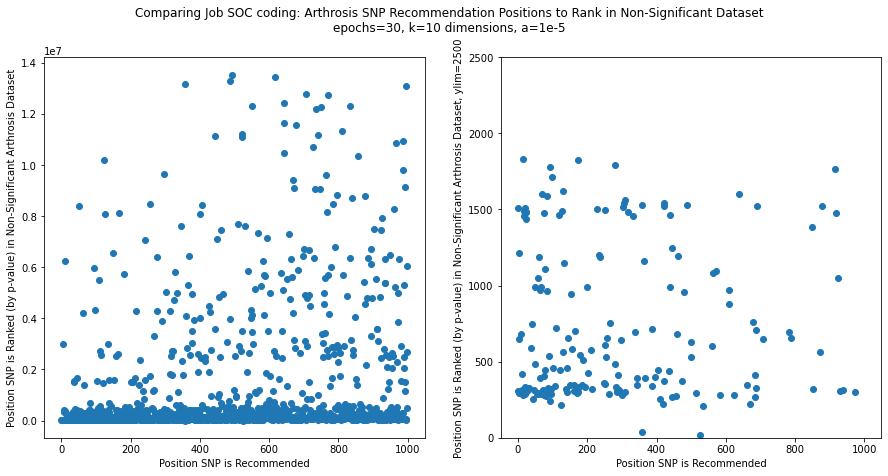

In [303]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15,7))
# fig = plt.figure(figsize=(12, 10))
fig.patch.set_facecolor('white')
ax1.scatter(range(len(non_significant_arthrosis_recs_position[:1000])), non_significant_arthrosis_recs_position[:1000])
ax2.scatter(range(len(non_significant_arthrosis_recs_position[:1000])), non_significant_arthrosis_recs_position[:1000])
ax2.set_ylim(0,2500)

# ax1.set_title('No ylim')
# ax2.set_title('ylim=2500')
ax1.set_xlabel('Position SNP is Recommended')
ax1.set_ylabel('Position SNP is Ranked (by p-value) in Non-Significant Arthrosis Dataset')
ax2.set_xlabel('Position SNP is Recommended')
ax2.set_ylabel('Position SNP is Ranked (by p-value) in Non-Significant Arthrosis Dataset, ylim=2500')
fig.suptitle('Comparing Job SOC coding: Arthrosis SNP Recommendation Positions to Rank in Non-Significant Dataset\nepochs=30, k=10 dimensions, a=1e-5')

**Generating recs for 5 traits and doing cross-full data checks**

In [ ]:
#generating arthrosis recs and comparing against full data for all traits
rec_info_arthrosis = sample_recommendation(gwas_model_e30_d10_reg00001, data_e30_d10_reg00001, ['#Arthrosis'], print_num=1)
full_data_check_arthrosis_arthrosis = check_full_data(arthrosis_df, rec_info_arthrosis[0][0][:100])
full_data_check_arthrosis_melanoma = check_full_data(melanoma_skin_df, rec_info_arthrosis[0][0][:100])
full_data_check_arthrosis_rheuseropos = check_full_data(rheu_seropos_df, rec_info_arthrosis[0][0][:100])
full_data_check_arthrosis_weight = check_full_data(weight_df, rec_info_arthrosis[0][0][:100])
full_data_check_arthrosis_printers = check_full_data(printers_df, rec_info_arthrosis[0][0][:100])

In [ ]:
#generating melanoma recs and comparing against full data for all traits
rec_info_melanoma = sample_recommendation(gwas_model_e30_d10_reg00001, data_e30_d10_reg00001, ['Malignant melanoma of skin'], print_num=1)
full_data_check_melanoma_arthrosis = check_full_data(arthrosis_df, rec_info_melanoma[0][0][:100])
full_data_check_melanoma_melanoma = check_full_data(melanoma_skin_df, rec_info_melanoma[0][0][:100])
full_data_check_melanoma_rheuseropos = check_full_data(rheu_seropos_df, rec_info_melanoma[0][0][:100])
full_data_check_melanoma_weight = check_full_data(weight_df, rec_info_melanoma[0][0][:100])
full_data_check_melanoma_printers = check_full_data(printers_df, rec_info_melanoma[0][0][:100])

In [ ]:
#generating weight recs and comparing against full data for all traits
rec_info_weight = sample_recommendation(gwas_model_e30_d10_reg00001, data_e30_d10_reg00001, ['Weight'], print_num=1)
full_data_check_weight_arthrosis = check_full_data(arthrosis_df, rec_info_weight[0][0][:100])
full_data_check_weight_melanoma = check_full_data(melanoma_skin_df, rec_info_weight[0][0][:100])
full_data_check_weight_rheuseropos = check_full_data(rheu_seropos_df, rec_info_weight[0][0][:100])
full_data_check_weight_weight = check_full_data(weight_df, rec_info_weight[0][0][:100])
full_data_check_weight_printers = check_full_data(printers_df, rec_info_weight[0][0][:100])

In [ ]:
#generating Seropositive rheumatoid arthritis recs and comparing against full data for all traits
rec_info_sra = sample_recommendation(gwas_model_e30_d10_reg00001, data_e30_d10_reg00001, ['Seropositive rheumatoid arthritis'], print_num=1)
full_data_check_rheuseropos_arthrosis = check_full_data(arthrosis_df, rec_info_sra[0][0][:100])
full_data_check_rheuseropos_melanoma = check_full_data(melanoma_skin_df, rec_info_sra[0][0][:100])
full_data_check_rheuseropos_rheuseropos = check_full_data(rheu_seropos_df, rec_info_sra[0][0][:100])
full_data_check_rheuseropos_weight = check_full_data(weight_df, rec_info_sra[0][0][:100])
full_data_check_rheuseropos_printers = check_full_data(printers_df, rec_info_sra[0][0][:100])

In [ ]:
#generating Job SOC coding: Printers recs and comparing against full data for all traits
rec_info_printers = sample_recommendation(gwas_model_e30_d10_reg00001, data_e30_d10_reg00001, ['Job SOC coding: Printers'], print_num=1)
full_data_check_printers_arthrosis = check_full_data(arthrosis_df, rec_info_printers[0][0][:100])
full_data_check_printers_melanoma = check_full_data(melanoma_skin_df, rec_info_printers[0][0][:100])
full_data_check_printers_rheuseropos = check_full_data(rheu_seropos_df, rec_info_printers[0][0][:100])
full_data_check_printers_weight = check_full_data(weight_df, rec_info_printers[0][0][:100])
full_data_check_printers_printers = check_full_data(printers_df, rec_info_printers[0][0][:100])

In [ ]:
arthrosis_arthrosis_list = []
for data, check in zip(rec_info_arthrosis[0][0], full_data_check_arthrosis_arthrosis):
    arthrosis_arthrosis_list.append(float(check[0][4]))
arthrosis_melanoma_list = []
for data, check in zip(rec_info_arthrosis[0][0], full_data_check_arthrosis_melanoma):
    arthrosis_melanoma_list.append(float(check[0][4]))
arthrosis_rheuseropos_list = []
for data, check in zip(rec_info_arthrosis[0][0], full_data_check_arthrosis_rheuseropos):
    arthrosis_rheuseropos_list.append(float(check[0][4]))
arthrosis_weight_list = []
for data, check in zip(rec_info_arthrosis[0][0], full_data_check_arthrosis_weight):
    arthrosis_weight_list.append(float(check[0][4]))
arthrosis_printers_list = []
for data, check in zip(rec_info_arthrosis[0][0], full_data_check_arthrosis_printers):
    arthrosis_printers_list.append(float(check[0][4]))

In [ ]:
melanoma_arthrosis_list = []
for data, check in zip(rec_info_melanoma[0][0], full_data_check_melanoma_arthrosis):
    melanoma_arthrosis_list.append(float(check[0][4]))
melanoma_melanoma_list = []
for data, check in zip(rec_info_melanoma[0][0], full_data_check_melanoma_melanoma):
    melanoma_melanoma_list.append(float(check[0][4]))
melanoma_rheuseropos_list = []
for data, check in zip(rec_info_melanoma[0][0], full_data_check_melanoma_rheuseropos):
    melanoma_rheuseropos_list.append(float(check[0][4]))
melanoma_weight_list = []
for data, check in zip(rec_info_melanoma[0][0], full_data_check_melanoma_weight):
    melanoma_weight_list.append(float(check[0][4]))
melanoma_printers_list = []
for data, check in zip(rec_info_melanoma[0][0], full_data_check_melanoma_printers):
    melanoma_printers_list.append(float(check[0][4]))

In [ ]:
weight_arthrosis_list = []
for data, check in zip(rec_info_weight[0][0], full_data_check_weight_arthrosis):
    weight_arthrosis_list.append(float(check[0][4]))
weight_melanoma_list = []
for data, check in zip(rec_info_weight[0][0], full_data_check_weight_melanoma):
    weight_melanoma_list.append(float(check[0][4]))
weight_rheuseropos_list = []
for data, check in zip(rec_info_weight[0][0], full_data_check_weight_rheuseropos):
    weight_rheuseropos_list.append(float(check[0][4]))
weight_weight_list = []
for data, check in zip(rec_info_weight[0][0], full_data_check_weight_weight):
    weight_weight_list.append(float(check[0][4]))
weight_printers_list = []
for data, check in zip(rec_info_weight[0][0], full_data_check_weight_printers):
    weight_printers_list.append(float(check[0][4]))

In [ ]:
rheuseropos_arthrosis_list = []
for data, check in zip(rec_info_sra[0][0], full_data_check_rheuseropos_arthrosis):
    rheuseropos_arthrosis_list.append(float(check[0][4]))
rheuseropos_melanoma_list = []
for data, check in zip(rec_info_sra[0][0], full_data_check_rheuseropos_melanoma):
    rheuseropos_melanoma_list.append(float(check[0][4]))
rheuseropos_rheuseropos_list = []
for data, check in zip(rec_info_sra[0][0], full_data_check_rheuseropos_rheuseropos):
    rheuseropos_rheuseropos_list.append(float(check[0][4]))
rheuseropos_weight_list = []
for data, check in zip(rec_info_sra[0][0], full_data_check_rheuseropos_weight):
    rheuseropos_weight_list.append(float(check[0][4]))
rheuseropos_printers_list = []
for data, check in zip(rec_info_sra[0][0], full_data_check_rheuseropos_printers):
    rheuseropos_printers_list.append(float(check[0][4]))

In [ ]:
printers_arthrosis_list = []
for data, check in zip(rec_info_printers[0][0], full_data_check_printers_arthrosis):
    printers_arthrosis_list.append(float(check[0][4]))
printers_melanoma_list = []
for data, check in zip(rec_info_printers[0][0], full_data_check_printers_melanoma):
    printers_melanoma_list.append(float(check[0][4]))
printers_rheuseropos_list = []
for data, check in zip(rec_info_printers[0][0], full_data_check_printers_rheuseropos):
    printers_rheuseropos_list.append(float(check[0][4]))
printers_weight_list = []
for data, check in zip(rec_info_printers[0][0], full_data_check_printers_weight):
    printers_weight_list.append(float(check[0][4]))
printers_printers_list = []
for data, check in zip(rec_info_printers[0][0], full_data_check_printers_printers):
    printers_printers_list.append(float(check[0][4]))

In [ ]:
print('Average p-value of Arthosis SNP recs to Arthrosis:', sum(arthrosis_list)/len(arthrosis_list))
print('Average p-value of Melanoma SNP recs to Arthrosis:', sum(melanoma_list)/len(melanoma_list))

print('Smallest p-value in Arthrosis SNP recs to Arthrosis:', min(arthrosis_list))
print('Smallest p-value in Melanoma SNP recs to Arthrosis:', min(melanoma_list))

In [34]:
def top_k_ave_p(p_vals):
    not_nan_vals = ~np.isnan(p_vals)
    p_vals = np.array(p_vals)[not_nan_vals]
    averages = []
    for k in range(len(p_vals)):
#         averages.append(np.average(p_vals[:(k+1)]))
        averages.append(sp.stats.mstats.gmean(p_vals[:(k+1)]))
    return averages

top_k_ave_pvals_arthrosis_arthrosis = top_k_ave_p(arthrosis_arthrosis_list)
top_k_ave_pvals_melanoma_arthrosis = top_k_ave_p(melanoma_arthrosis_list)
top_k_ave_pvals_weight_arthrosis = top_k_ave_p(weight_arthrosis_list)
top_k_ave_pvals_rheuseropos_arthrosis = top_k_ave_p(rheuseropos_arthrosis_list)
top_k_ave_pvals_printers_arthrosis = top_k_ave_p(printers_arthrosis_list)

top_k_ave_pvals_arthrosis_melanoma = top_k_ave_p(arthrosis_melanoma_list)
top_k_ave_pvals_melanoma_melanoma = top_k_ave_p(melanoma_melanoma_list)
top_k_ave_pvals_weight_melanoma = top_k_ave_p(weight_melanoma_list)
top_k_ave_pvals_rheuseropos_melanoma = top_k_ave_p(rheuseropos_melanoma_list)
top_k_ave_pvals_printers_melanoma = top_k_ave_p(printers_melanoma_list)

top_k_ave_pvals_arthrosis_weight = top_k_ave_p(arthrosis_weight_list)
top_k_ave_pvals_melanoma_weight = top_k_ave_p(melanoma_weight_list)
top_k_ave_pvals_weight_weight = top_k_ave_p(weight_weight_list)
top_k_ave_pvals_rheuseropos_weight = top_k_ave_p(rheuseropos_weight_list)
top_k_ave_pvals_printers_weight = top_k_ave_p(printers_weight_list)

top_k_ave_pvals_arthrosis_rheuseropos = top_k_ave_p(arthrosis_rheuseropos_list)
top_k_ave_pvals_melanoma_rheuseropos = top_k_ave_p(melanoma_rheuseropos_list)
top_k_ave_pvals_weight_rheuseropos = top_k_ave_p(weight_rheuseropos_list)
top_k_ave_pvals_rheuseropos_rheuseropos = top_k_ave_p(rheuseropos_rheuseropos_list)
top_k_ave_pvals_printers_rheuseropos = top_k_ave_p(printers_rheuseropos_list)

top_k_ave_pvals_arthrosis_printers = top_k_ave_p(arthrosis_printers_list)
top_k_ave_pvals_melanoma_printers = top_k_ave_p(melanoma_printers_list)
top_k_ave_pvals_weight_printers = top_k_ave_p(weight_printers_list)
top_k_ave_pvals_rheuseropos_printers = top_k_ave_p(rheuseropos_printers_list)
top_k_ave_pvals_printers_printers = top_k_ave_p(printers_printers_list)

In [ ]:
fig = plt.figure(figsize=(10, 7))
fig.patch.set_facecolor('white')
plt.yscale('log')
plt.plot(range(1, 101), top_k_ave_pvals_arthrosis_arthrosis)
plt.plot(range(1, 101), top_k_ave_pvals_melanoma_arthrosis)
plt.plot(range(1, 101), top_k_ave_pvals_weight_arthrosis)
plt.plot(range(1, 101), top_k_ave_pvals_rheuseropos_arthrosis)
plt.plot(range(1, 101), top_k_ave_pvals_printers_arthrosis)

plt.legend(['Arthrosis', 'Malignant melanoma of skin', 'Weight', 'Seropositive rheumatoid arthritis', 'Job SOC coding: Printers'], loc='lower right')
plt.xlabel('k')
plt.ylabel('Average p-value (Geometric Mean)')
plt.title('Average p-value of Top k Recommended SNPs for Different Traits to Arthrosis')

In [ ]:
fig = plt.figure(figsize=(10, 7))
fig.patch.set_facecolor('white')
plt.yscale('log')
plt.plot(range(1, 101), top_k_ave_pvals_arthrosis_melanoma)
plt.plot(range(1, 101), top_k_ave_pvals_melanoma_melanoma)
plt.plot(range(1, 101), top_k_ave_pvals_weight_melanoma)
plt.plot(range(1, 101), top_k_ave_pvals_rheuseropos_melanoma)
plt.plot(range(1, 101), top_k_ave_pvals_printers_melanoma)

plt.legend(['Arthrosis', 'Malignant melanoma of skin', 'Weight', 'Seropositive rheumatoid arthritis', 'Job SOC coding: Printers'], loc='lower right')
plt.xlabel('k')
plt.ylabel('Average p-value (Geometric Mean)')
plt.title('Average p-value of Top k Recommended SNPs for Different Traits to Malignant Melanoma of Skin')

In [ ]:
fig = plt.figure(figsize=(10, 7))
fig.patch.set_facecolor('white')
plt.yscale('log')
plt.plot(range(1, 101), top_k_ave_pvals_arthrosis_weight)
plt.plot(range(1, 101), top_k_ave_pvals_melanoma_weight)
plt.plot(range(1, 101), top_k_ave_pvals_weight_weight)
plt.plot(range(1, 101), top_k_ave_pvals_rheuseropos_weight)
plt.plot(range(1, 101), top_k_ave_pvals_printers_weight)

plt.legend(['Arthrosis', 'Malignant melanoma of skin', 'Weight', 'Seropositive rheumatoid arthritis', 'Job SOC coding: Printers'], loc='lower right')
plt.xlabel('k')
plt.ylabel('Average p-value (Geometric Mean)')
plt.title('Average p-value of Top k Recommended SNPs for Different Traits to Weight')

In [ ]:
fig = plt.figure(figsize=(10, 7))
fig.patch.set_facecolor('white')
plt.yscale('log')
plt.plot(range(1, 101), top_k_ave_pvals_arthrosis_rheuseropos)
plt.plot(range(1, 101), top_k_ave_pvals_melanoma_rheuseropos)
plt.plot(range(1, 101), top_k_ave_pvals_weight_rheuseropos)
plt.plot(range(1, 101), top_k_ave_pvals_rheuseropos_rheuseropos)
plt.plot(range(1, 101), top_k_ave_pvals_printers_rheuseropos)

plt.legend(['Arthrosis', 'Malignant melanoma of skin', 'Weight', 'Seropositive rheumatoid arthritis', 'Job SOC coding: Printers'], loc='lower right')
plt.xlabel('k')
plt.ylabel('Average p-value (Geometric Mean)')
plt.title('Average p-value of Top k Recommended SNPs for Different Traits to Seropositive Rheumatoid Arthritis')

In [ ]:
fig = plt.figure(figsize=(10, 7))
fig.patch.set_facecolor('white')
plt.yscale('log')
plt.plot(range(1, 101), top_k_ave_pvals_arthrosis_printers)
plt.plot(range(1, 97), top_k_ave_pvals_melanoma_printers)
plt.plot(range(1, 101), top_k_ave_pvals_weight_printers)
plt.plot(range(1, 100), top_k_ave_pvals_rheuseropos_printers)
plt.plot(range(1, 101), top_k_ave_pvals_printers_printers)

plt.legend(['Arthrosis', 'Malignant melanoma of skin', 'Weight', 'Seropositive rheumatoid arthritis', 'Job SOC coding: Printers'], loc='lower right')
plt.xlabel('k')
plt.ylabel('Average p-value (Geometric Mean)')
plt.title('Average p-value of Top k Recommended SNPs for Different Traits to Job SOC coding: Printers')

**Generating SNP recs for Traits in Figure 4c of DHS paper and saving as bed files**

In [ ]:
trait_codes_df[trait_codes_df['description'].str.contains('unsuccessful')]

In [23]:
traits = []
# traits.append('Gap coding: Full-time or part-time education')
traits.append('Non-cancer illness code, self-reported: systemic lupus erythematosis/sle')
traits.append('Mean corpuscular haemoglobin concentration')
traits.append('QRS duration')
traits.append('Corneal hysteresis (left)')
# traits.append('Number of full sisters')
traits.append('Number of unsuccessful stop-smoking attempts')
traits.append('Diagnoses - main ICD10: N81 Female genital prolapse')
traits.append('Illnesses of father: Chronic bronchitis/emphysema')
traits.append('Reticulocyte count')
traits.append('Pulse rate, automated reading')

In [24]:
print(traits)

['Non-cancer illness code, self-reported: systemic lupus erythematosis/sle', 'Mean corpuscular haemoglobin concentration', 'QRS duration', 'Corneal hysteresis (left)', 'Number of unsuccessful stop-smoking attempts', 'Diagnoses - main ICD10: N81 Female genital prolapse', 'Illnesses of father: Chronic bronchitis/emphysema', 'Reticulocyte count', 'Pulse rate, automated reading']


In [25]:
trait_names_4c = ['lupus', 'mean_corpuscular_haemoglobin_concentration', 'QRS_duration', 'Corneal_hysteresis_left', 'unsuccessful_stop_smoking_attempts', 'female_genital_prolapse', 'father_chronic_bronchitis_emphysema', 'reticulocyte_count', 'pulse_rate_automated_reading']

In [26]:
pickle_in = open('/home/ctrader/Hold/GWAS/pickled_models_afo_alpha_epochs_dimensions/GWAS_model_e30_d20_reg1e-05_lr01_CT20211130.pickle', 'rb')
model_e30_d20_reg00001_lr01_CT20211130=pickle.load(pickle_in)

pickle_in = open('/home/ctrader/Hold/GWAS/pickled_models_afo_alpha_epochs_dimensions/gwas_data_for_training_CT20211130.pickle', 'rb')
gwas_data_for_training_CT20211130=pickle.load(pickle_in)

In [27]:
#trait recs for model_e30_d20_reg0005_lr01 
rec_info_4c_top_traits = sample_recommendation(model_e30_d20_reg00001_lr01_CT20211130, gwas_data_for_training_CT20211130, traits, print_num=1)

Disease: Non-cancer illness code, self-reported: systemic lupus erythematosis/sle (2543)
   Known Positives (4100):
      Reference SNP cluster ID: rs148297150, chr2:26313027-26313028, p-value = 1.00162e-191
      ...

   Recommended:
      Reference SNP cluster ID: rs9272426, chr6:32637412-32637413
Disease: Mean corpuscular haemoglobin concentration (2160)
   Known Positives (26368):
      Reference SNP cluster ID: rs116615990, chr16:30084966-30084967, p-value = 2.66651e-305
      ...

   Recommended:
      Reference SNP cluster ID: rs562289, chr6:32609269-32609270
Disease: QRS duration (2805)
   Known Positives (361):
      Reference SNP cluster ID: rs183155578, chr19:17206250-17206251, p-value = 1.71093e-35
      ...

   Recommended:
      Reference SNP cluster ID: rs556642707, chr16:67660381-67660382
Disease: Corneal hysteresis (left) (317)
   Known Positives (5046):
      Reference SNP cluster ID: rs113265906, chr16:57756026-57756027, p-value = 8.10853e-168
      ...

   Recommend

In [28]:
cols = ['reference snp cluster ID', 'chr', 'start', 'end', 'pred score']

In [31]:
lupus_recs_df = pd.DataFrame(rec_info_4c_top_traits[0][0], columns = ['reference snp cluster ID'])
mean_corpuscular_haemoglobin_concentration_recs_df = pd.DataFrame(rec_info_4c_top_traits[1][0], columns = ['reference snp cluster ID'])
QRS_duration_recs_df = pd.DataFrame(rec_info_4c_top_traits[2][0], columns = ['reference snp cluster ID'])
Corneal_hysteresis_left_recs_df = pd.DataFrame(rec_info_4c_top_traits[3][0], columns = ['reference snp cluster ID'])
unsuccessful_stop_smoking_attempts_recs_df = pd.DataFrame(rec_info_4c_top_traits[4][0], columns = ['reference snp cluster ID'])
female_genital_prolapse_recs_df = pd.DataFrame(rec_info_4c_top_traits[5][0], columns = ['reference snp cluster ID'])
father_chronic_bronchitis_emphysema_recs_df = pd.DataFrame(rec_info_4c_top_traits[6][0], columns = ['reference snp cluster ID'])
reticulocyte_count_recs_df = pd.DataFrame(rec_info_4c_top_traits[7][0], columns = ['reference snp cluster ID'])
pulse_rate_automated_reading_recs_df = pd.DataFrame(rec_info_4c_top_traits[8][0], columns = ['reference snp cluster ID'])

In [32]:
#merging dataframes together to compare snp ranks for each trait
lupus_recs_df['lupus rank'] = lupus_recs_df.index
mean_corpuscular_haemoglobin_concentration_recs_df['mchc rank'] = mean_corpuscular_haemoglobin_concentration_recs_df.index
QRS_duration_recs_df['QRS rank'] = QRS_duration_recs_df.index
Corneal_hysteresis_left_recs_df['corneal hysteresis rank'] = Corneal_hysteresis_left_recs_df.index
unsuccessful_stop_smoking_attempts_recs_df['stop smoking rank'] = unsuccessful_stop_smoking_attempts_recs_df.index
female_genital_prolapse_recs_df['genital prolapse rank'] = female_genital_prolapse_recs_df.index
father_chronic_bronchitis_emphysema_recs_df['chronic bronchitis rank'] = father_chronic_bronchitis_emphysema_recs_df.index
reticulocyte_count_recs_df['reticulocyte count rank'] = reticulocyte_count_recs_df.index
pulse_rate_automated_reading_recs_df['pulse rate rank'] = pulse_rate_automated_reading_recs_df.index

merged_df = lupus_recs_df.merge(mean_corpuscular_haemoglobin_concentration_recs_df[['reference snp cluster ID', 'mchc rank']], left_on='reference snp cluster ID', right_on='reference snp cluster ID')
merged_df = merged_df.merge(QRS_duration_recs_df[['reference snp cluster ID', 'QRS rank']], left_on='reference snp cluster ID', right_on='reference snp cluster ID')
merged_df = merged_df.merge(Corneal_hysteresis_left_recs_df[['reference snp cluster ID', 'corneal hysteresis rank']], left_on='reference snp cluster ID', right_on='reference snp cluster ID')
merged_df = merged_df.merge(unsuccessful_stop_smoking_attempts_recs_df[['reference snp cluster ID', 'stop smoking rank']], left_on='reference snp cluster ID', right_on='reference snp cluster ID')
merged_df = merged_df.merge(female_genital_prolapse_recs_df[['reference snp cluster ID', 'genital prolapse rank']], left_on='reference snp cluster ID', right_on='reference snp cluster ID')
merged_df = merged_df.merge(father_chronic_bronchitis_emphysema_recs_df[['reference snp cluster ID', 'chronic bronchitis rank']], left_on='reference snp cluster ID', right_on='reference snp cluster ID')
merged_df = merged_df.merge(reticulocyte_count_recs_df[['reference snp cluster ID', 'reticulocyte count rank']], left_on='reference snp cluster ID', right_on='reference snp cluster ID')
merged_df = merged_df.merge(pulse_rate_automated_reading_recs_df[['reference snp cluster ID', 'pulse rate rank']], left_on='reference snp cluster ID', right_on='reference snp cluster ID')

In [33]:
merged_df['ranks averaged'] = (merged_df['lupus rank'] + merged_df['mchc rank'] + merged_df['QRS rank'] + merged_df['corneal hysteresis rank'] + merged_df['stop smoking rank'] + merged_df['genital prolapse rank'] + merged_df['chronic bronchitis rank'] + merged_df['reticulocyte count rank'] + merged_df['pulse rate rank'])/9
ranks_averaged_list = list(merged_df['ranks averaged'])
lupus_ranks = list(merged_df['lupus rank'])
merged_df.head()

,reference snp cluster ID,lupus rank,mchc rank,QRS rank,corneal hysteresis rank,stop smoking rank,genital prolapse rank,chronic bronchitis rank,reticulocyte count rank,pulse rate rank,ranks averaged
0,rs9275426,789,7326,2009900,1877067,13047,1845768,1542,31183,2028919,868393.444444
1,rs9275422,878,8145,1980114,2062789,15707,1773845,3208,41624,2026279,879176.555556
2,rs9275442,895,13829,2005932,1950046,12964,1829154,1813,50831,2032724,877576.444444
3,rs56051108,954,8164,2030169,1971316,12658,1922989,2963,43426,2006271,888767.777778
4,rs71565338,978,11529,1933235,2016347,28091,1437184,1468,63845,2046874,837727.888889


Text(0.5, 1.0, 'Comparing SNP Recommendation Rankings from 9 Traits from Extended Data Fig. 9a and 9d of DHS Paper\nepochs=30, k=20 components, alpha=1e-5, learning rate=0.01')

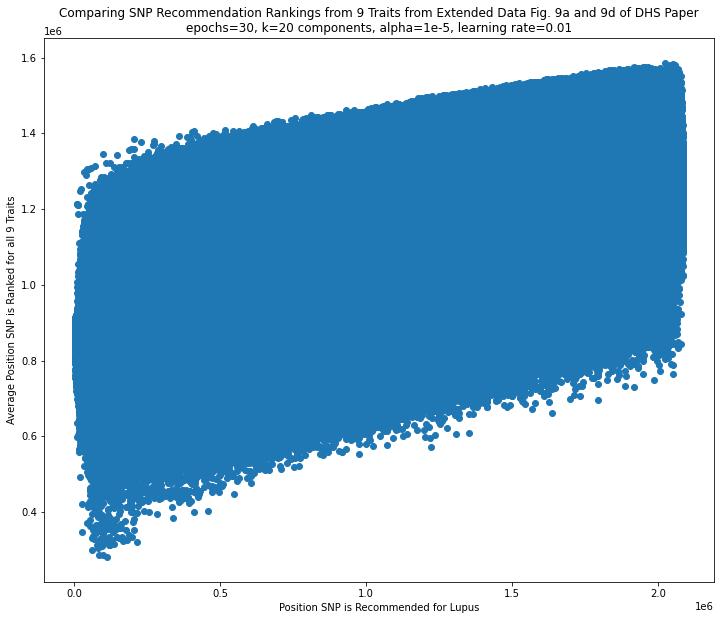

In [34]:
fig = plt.figure(figsize=(12, 10))
fig.patch.set_facecolor('white')
plt.scatter(lupus_ranks, ranks_averaged_list)

plt.xlabel('Position SNP is Recommended for Lupus')
plt.ylabel('Average Position SNP is Ranked for all 9 Traits')
plt.title('Comparing SNP Recommendation Rankings from 9 Traits from Extended Data Fig. 9a and 9d of DHS Paper\nepochs=30, k=20 components, alpha=1e-5, learning rate=0.01')

In [87]:
trait_b, trait_e = model_e30_d20_reg0005_lr01.get_user_representations()
snp_b, snp_e = model_e30_d20_reg0005_lr01.get_item_representations()

In [88]:
trait_e

array([[ 1.04482081e-19,  4.81603067e-20, -1.21061010e-19, ...,
        -1.69186857e-19, -1.08570415e-19,  5.71507939e-20],
       [ 2.21226240e-20,  4.84902904e-20, -9.52965865e-21, ...,
         5.49887247e-20, -2.67631823e-21,  3.52998002e-20],
       [-3.16523440e-20,  8.98788216e-20,  2.32316567e-20, ...,
        -1.08067774e-19,  9.87704219e-21, -8.41507575e-20],
       ...,
       [-4.16110138e-20, -3.39998503e-20,  2.38953712e-19, ...,
         1.17286521e-19,  2.45639089e-19,  9.34969920e-21],
       [-8.68527688e-21, -7.44556837e-20, -1.09582351e-20, ...,
         6.14055460e-20,  5.22519298e-20, -4.40650357e-20],
       [-1.76181858e-19,  1.68596844e-19,  1.85140198e-19, ...,
        -1.41885773e-20, -5.38055171e-20, -2.44422905e-20]], dtype=float32)

In [89]:
snp_e

array([[-3.65214561e-19, -8.44882795e-19, -1.72968119e-19, ...,
         2.45590286e-19, -2.65970724e-19,  2.61968772e-19],
       [ 3.68358713e-20,  2.44079776e-19,  6.19454623e-19, ...,
        -3.33946837e-20,  2.27103626e-19,  2.91092535e-19],
       [-9.94174730e-19, -1.01144936e-18, -1.13954759e-18, ...,
        -6.33162427e-20, -1.13232175e-18, -1.20963022e-17],
       ...,
       [-2.75392879e-19,  1.87311586e-19, -2.05738895e-19, ...,
         2.83460941e-19, -2.18746440e-19,  3.55738819e-19],
       [ 1.93776532e-19,  2.89401778e-19, -6.25382096e-19, ...,
         1.55304938e-18,  5.19027142e-20, -2.20135508e-18],
       [ 1.04365223e-19, -1.04254503e-19,  2.76924495e-20, ...,
        -5.59944665e-20,  3.84644827e-19,  5.61443929e-19]], dtype=float32)

In [29]:
today = date.today()
for j in range(len(traits)):
    pickle_path_name = os.path.join('/home/ctrader/Hold/GWAS/recommendations/', 'GWAS_e30_d20_reg1e-05_lr01_rec_info_' + trait_names_4c[j] + '_CT' + today.strftime("%Y%m%d") + '.pickle')
    pickle_out = open(pickle_path_name, 'wb')
    pickle.dump(rec_info_4c_top_traits[j], pickle_out)
    pickle_out.close()

In [30]:
today = date.today()
for j in range(len(traits)):
    bed_path_name = os.path.join('/home/ctrader/Hold/GWAS/recommendations/', 'GWAS_e30_d20_reg1e-05_lr01_rec_info_' + trait_names_4c[j] + '_CT' + today.strftime("%Y%m%d") + '.bed')
    f= open(bed_path_name, 'w')
    for i in range(len(rec_info_4c_top_traits[j][1])):
        f.write(rec_info_4c_top_traits[j][1][i] + '\t' + str(rec_info_4c_top_traits[j][2][i]) + '\t' + str(rec_info_4c_top_traits[j][3][i]) + '\t' + str(rec_info_4c_top_traits[j][4][i]) + '\t' + str(rec_info_4c_top_traits[j][0][i]) + '\n')
    f.close()

In [68]:
rec_info_4c_top_traits = sample_recommendation(gwas_model_e30_d10_reg00001, data_e30_d10_reg00001, traits, print_num=1)

Disease: Non-cancer illness code, self-reported: systemic lupus erythematosis/sle (2543)
   Known Positives (4100):
      Reference SNP cluster ID: rs148297150, chr2:26313027-26313028, p-value = 1.00162e-191
      ...

   Recommended:
      Reference SNP cluster ID: rs9273367, chr6:32658661-32658662
Disease: Mean corpuscular haemoglobin concentration (2160)
   Known Positives (26368):
      Reference SNP cluster ID: rs116615990, chr16:30084966-30084967, p-value = 2.66651e-305
      ...

   Recommended:
      Reference SNP cluster ID: rs35186928, chr6:32614827-32614828
Disease: QRS duration (2805)
   Known Positives (361):
      Reference SNP cluster ID: rs183155578, chr19:17206250-17206251, p-value = 1.71093e-35
      ...

   Recommended:
      Reference SNP cluster ID: rs58107700, chr7:6621598-6621599
Disease: Corneal hysteresis (left) (317)
   Known Positives (5046):
      Reference SNP cluster ID: rs113265906, chr16:57756026-57756027, p-value = 8.10853e-168
      ...

   Recommended

In [40]:
#creatng generating recommendations for iceberg plots and SNP Recommendation Positions to Rank in 
#Non-Significant Dataset plots
traits = []
traits.append('Non-cancer illness code, self-reported: systemic lupus erythematosis/sle')
traits.append('Mean corpuscular haemoglobin concentration')
traits.append('QRS duration')

In [41]:
rec_info_4c_lupus_mchc_qrsduration = sample_recommendation(gwas_model_e30_d10_reg00001, data_e30_d10_reg00001, traits, print_num=1)

Disease: Non-cancer illness code, self-reported: systemic lupus erythematosis/sle (2543)
   Known Positives (4100):
      Reference SNP cluster ID: rs148297150, chr2:26313027-26313028, p-value = 1.00162e-191
      ...

   Recommended:


KeyboardInterrupt: 

In [81]:
rec_info_lupus_SNPs = rec_info_4c_lupus_mchc_qrsduration[0][0]
rec_info_mchc_SNPs = rec_info_4c_lupus_mchc_qrsduration[1][0]
rec_info_qrs_duration_SNPs = rec_info_4c_lupus_mchc_qrsduration[2][0]

In [82]:
#Lupus
lupus_full_df['p-value'] = lupus_full_df['p-value'].astype(float)
lupus_full_df = lupus_full_df.sort_values('p-value')
lupus_full_df_non_significant = lupus_full_df[lupus_full_df['p-value']>5e-8]
lupus_full_df_non_significant = lupus_full_df_non_significant.reset_index()
lupus_full_df_non_significant['index'] = lupus_full_df_non_significant.index
lupus_full_df_non_significant = lupus_full_df_non_significant.set_index(['Reference SNP cluster ID'])
lupus_full_df_non_significant_ser = lupus_full_df_non_significant['index']
non_significant_lupus_recs_position = list(lupus_full_df_non_significant_ser[rec_info_lupus_SNPs])

In [83]:
not_in_mchc_non_significant_full_data = ['rs143088879', 'rs566316997', 'rs202192406', 'rs200893894', 'rs141968165', 'rs142863654', 'rs201216936', 'rs532824675', 'rs189194995', 'rs191951798', 'rs149131360', 'rs539687412', 'rs530861601', 'rs370681036', 'rs142488085', 'rs549565879', 'rs538567560', 'rs142512027', 'rs200678800', 'rs146730930', 'rs531177526', 'rs144118342', 'rs146869026', 'rs73411159', 'rs61743800', 'rs372096666', 'rs569560776', 'rs545234557', 'rs531494662', 'rs141950704', 'rs149541806', 'rs143595376', 'rs367805772', 'rs368868996', 'rs567369483', 'rs151227020', 'rs560460299', 'rs149721540', 'rs151335104', 'rs73751111', 'rs140194759', 'rs201152025', 'rs563122522', 'rs560198011', 'rs115530229', 'rs142766345', 'rs146203622', 'rs552221383']
print(len(not_in_mchc_non_significant_full_data))
rec_info_mchc_SNPs_np = np.array(rec_info_mchc_SNPs)
print(len(rec_info_mchc_SNPs_np))
not_in_mchc_non_significant_full_data_np = np.array(not_in_mchc_non_significant_full_data)
rec_info_mchc_SNPs = list(rec_info_mchc_SNPs_np[~np.isin(rec_info_mchc_SNPs_np, not_in_mchc_non_significant_full_data_np)])
print(len(rec_info_mchc_SNPs))

48
2063862
2063814


In [84]:
#mean corpuscular haemoglobin concentration
mean_corpuscular_haemoglobin_concentration_full_df['p-value'] = mean_corpuscular_haemoglobin_concentration_full_df['p-value'].astype(float)
mean_corpuscular_haemoglobin_concentration_full_df = mean_corpuscular_haemoglobin_concentration_full_df.sort_values('p-value')
mean_corpuscular_haemoglobin_concentration_full_df_non_significant = mean_corpuscular_haemoglobin_concentration_full_df[mean_corpuscular_haemoglobin_concentration_full_df['p-value']>5e-8]
mean_corpuscular_haemoglobin_concentration_full_df_non_significant = mean_corpuscular_haemoglobin_concentration_full_df_non_significant.reset_index()
mean_corpuscular_haemoglobin_concentration_full_df_non_significant['index'] = mean_corpuscular_haemoglobin_concentration_full_df_non_significant.index
mean_corpuscular_haemoglobin_concentration_full_df_non_significant = mean_corpuscular_haemoglobin_concentration_full_df_non_significant.set_index(['Reference SNP cluster ID'])
mean_corpuscular_haemoglobin_concentration_full_df_non_significant_ser = mean_corpuscular_haemoglobin_concentration_full_df_non_significant['index']
non_significant_mchc_recs_position = list(mean_corpuscular_haemoglobin_concentration_full_df_non_significant_ser[rec_info_mchc_SNPs])

In [93]:
not_in_qrs_duration_non_significant_full_data = ['rs375829783', 'rs556642707', 'rs201681851', 'rs115674060', 'rs145177562', 'rs546358522', 'rs148527788', 'rs111722751', 'rs138443906', 'rs570224400', 'rs199796609', 'rs568878521', 'rs554751435', 'rs138172966', 'rs536683304', 'rs541288921', 'rs548563662', 'rs560585459', 'rs574813846', 'rs565024096', 'rs115009304', 'rs530087387', 'rs538223867', 'rs35224402', 'rs199514462', 'rs138545268', 'rs189822486', 'rs2068243', 'rs150511923', 'rs538372230', 'rs540414385', 'rs569068324', 'rs35654708', 'rs142188467', 'rs148215125', 'rs142806010', 'rs138763496', 'rs61740147', 'rs571793569', 'rs113444393', 'rs536449046', 'rs115702747', 'rs373701632', 'rs77815840', 'rs141371381', 'rs567007654', 'rs147306012', 'rs540415870', 'rs140623081', 'rs199553775', 'rs561603477', 'rs187430722', 'rs148444990', 'rs142277567', 'rs139437329', 'rs562804818', 'rs141751043', 'rs150004751', 'rs200576346', 'rs61734045', 'rs531594229', 'rs370110205', 'rs138395129', 'rs137909519', 'rs116600135', 'rs151208219', 'rs200547024', 'rs62000453', 'rs536264084', 'rs148478498', 'rs200655179', 'rs148355444', 'rs548367126', 'rs149516161', 'rs146574385', 'rs139784416', 'rs199580679', 'rs145395391', 'rs149130310', 'rs528173288', 'rs111926990', 'rs142253130', 'rs75008861', 'rs57725422', 'rs575669681', 'rs185448327', 'rs147634480', 'rs143691369', 'rs150017839', 'rs540832166', 'rs182725627', 'rs191499924', 'rs532053506', 'rs180736640', 'rs201302371', 'rs34041945', 'rs144389427', 'rs202055538', 'rs376411203', 'rs371973497', 'rs35036619', 'rs181260849', 'rs371706716', 'rs34256013', 'rs575691378', 'rs373808092', 'rs555368347', 'rs138673535', 'rs111326671', 'rs377166311', 'rs35375999', 'rs374544992', 'rs61746392', 'rs34803755', 'rs192598874', 'rs567491448', 'rs371140684', 'rs371139134', 'rs28940885', 'rs145950613', 'rs184211583', 'rs532644782', 'rs143520192', 'rs137871355', 'rs199639247', 'rs147685072', 'rs61743383', '11:48239137_CT_C', 'rs372810597', 'rs138953266', 'rs75471387', 'rs116238028', 'rs546219561', 'rs146157839', 'rs111759871', 'rs191723490', 'rs533121789', 'rs139634188', 'rs138208049', 'rs150585610', 'rs568303257', 'rs143547637', 'rs199497561', 'rs138285636', 'rs149190046', 'rs183795056', 'rs371962113', 'rs139974951', 'rs146921625', 'rs201865282', 'rs377296839', 'rs371870934', 'rs186151755', 'rs141529027', 'rs141271240', 'rs560732386', 'rs186902443', 'rs543657618', 'rs199821391', 'rs192158429', 'rs148733148', 'rs148950746', 'rs192243687', 'rs538965336', 'rs189876952', 'rs138408187', 'rs144724390', 'rs148693918', 'rs141373924', 'rs140908390', 'rs141624294', 'rs529881754', 'rs539211233', 'rs543092318', 'rs35432631', 'rs201618273', 'rs139888108', 'rs146098391', 'rs201304559', 'rs143610596', 'rs183392250', 'rs374794979', 'rs186809089', 'rs138537245', 'rs138492532', 'rs113225770', 'rs145174974', 'rs137958059', 'rs112889393', 'rs118066970', 'rs2232787', 'rs186606579', 'rs201189180', 'rs145848231', 'rs146067486', 'rs533733453', 'rs79096553', 'rs76992529', 'rs541621477', 'rs139031286', 'rs141122140', 'rs551141144', 'rs142662990', 'rs79984281', 'rs142163721', 'rs143384624', 'rs199767748', 'rs566219944', 'rs149244748', 'rs528604984', 'rs200351774', 'rs140589234', 'rs201231959', 'rs141724442', 'rs373827792', 'rs201688116', 'rs148448946', 'rs140719911', 'rs144292473', 'rs148480631', 'rs190316360', 'rs149011538', 'rs546171608', 'rs16840956', 'rs113597275', 'rs138888235', 'rs544381487', 'rs149507464', 'rs139640936', 'rs540340877', 'rs368896641', 'rs558049660', '9:140109389_G_A', 'rs61746192', 'rs113451915', 'rs140126918', 'rs118062293', 'rs533099097', 'rs141529529', 'rs145708001', 'rs188175424', 'rs147275739', 'rs182651188', 'rs115647449', 'rs191798690', 'rs533249283', 'rs140984413', 'rs147136470', 'rs200840954', 'rs193179116', 'rs553093185', 'rs148393062', 'rs61729593', 'rs16989105', 'rs148931659', 'rs2297417', 'rs114513539', 'rs181570462', 'rs141552726', 'rs193265694', 'rs55656713', 'rs201686148', 'rs767920285', 'rs543685758', 'rs141719529', 'rs147152497', 'rs34524265', 'rs144791420', 'rs73517551', 'rs138465494', 'rs545585481', 'rs140794370', 'rs17060941', 'rs562635733', 'rs61734412', 'rs189104598', 'rs141684275', 'rs149772688', 'rs377370844', 'rs142120837', 'rs567079410', 'rs368417374', 'rs115530122', 'rs536266992', 'rs139185707', 'rs143696910', 'rs141324828', 'rs36216910', 'rs150595465', 'rs202010872', 'rs181901202', 'rs374863227', 'rs549746836', 'rs545834123', 'rs146226591', 'rs201032908', 'rs77245714', 'rs113160746', 'rs537181001', 'rs76755411', 'rs145165443', 'rs200329367', 'rs568877287', 'rs73692606', 'rs145299598', 'rs17096969', 'rs574248032', 'rs114789019', 'rs570106143', 'rs1051949', 'rs779861392', 'rs111974142', 'rs199861876', 'rs201334709', 'rs201992648', 'rs149335809', 'rs184559206', 'rs186156814', 'rs201707139', 'rs567832274', 'rs111630745', 'rs114197223', 'rs139693607', 'rs201443444', 'rs111499130', 'rs185330237', 'rs1110020', 'rs564734737', 'rs144061396', 'rs200935930', 'rs34448930', 'rs61743943', 'rs141845943', 'rs376630294', 'rs201616473', 'rs569695290', 'rs531482489', 'rs529657121', 'rs112206544', 'rs149552496', 'rs139046850', 'rs577525219', 'rs141424464', 'rs187099869', 'rs548780711', 'rs143010465', 'rs370529416', 'rs115124215', 'rs137914136', 'rs201259331', 'rs191617067', 'rs141738557', 'rs150871246', 'rs142005186', 'rs371906160', 'rs377498068', 'rs150375746', 'rs143821486', 'rs577379114', 'rs55902832', 'rs145256530', 'rs138901264', 'rs141969833', 'rs373009795', 'rs147785481', 'rs150997327', 'rs571708422', 'rs139476931', 'rs536216899', 'rs74135743', 'rs115783644', 'rs149550268', 'rs560948877', 'rs114600103', 'rs80130403', 'rs563851361', 'rs140430323', 'rs377011618', 'rs534747867', 'rs199537775', 'rs149065924', 'rs371992268', 'rs187914531', '3:58304301_AG_A', 'rs2228656', '9:140332516_C_T', 'rs141484570', 'rs577168872', 'rs73767784', 'rs59461308', 'rs200747448', 'rs193249052', 'rs144936776', 'rs569434437', 'rs554891628', 'rs571300871', 'rs369180703', 'rs561138914', 'rs73967112', 'rs148663600', 'rs542634007', 'rs144097137', 'rs144484046', 'rs145302297', 'rs139841411', 'rs138778256', 'rs187848097', 'rs77504671', 'rs185040860', 'rs138852178', 'rs368007583', 'rs146552050', 'rs35791889', 'rs371089226', 'rs547676556', 'rs74408211', 'rs79756836', 'rs558639756', 'rs546904374', 'rs367564020', 'rs199553530', 'rs371283478', 'rs535615357', 'rs17335452', 'rs145964223', 'rs181142643', 'rs56089364', 'rs371867108', 'rs559356352', 'rs74826042', 'rs73928631', 'rs144670021', 'rs545434777', 'rs147315081', 'rs77122651', 'rs141309351', 'rs113049675', 'rs569188659', 'rs141178444', 'rs570840624', 'rs183392673', 'rs143931022', 'rs191314989', 'rs552116966', 'rs368370389', 'rs576608701', 'rs147402577', 'rs77561254', 'rs531715668', 'rs370582561', 'rs138701701', 'rs377533687', 'rs77170752', 'rs574694398', 'rs370337184', 'rs183269704', 'rs567462605', 'rs35720809', 'rs121908202', 'rs77922978', 'rs150379192', 'rs558650011', 'rs149474517', 'rs139056290', 'rs141531709', 'rs146575678', 'rs146456583', 'rs116718869', 'rs544273625', 'rs36028197', 'rs142962530', 'rs139202319', 'rs141843958', 'rs8178332', 'rs112196547', 'rs149008212', 'rs142693095', 'rs148131699', 'rs112026097', 'rs149099749', 'rs146382972', 'rs4537', 'rs115031907', 'rs138563147', 'rs554714928', 'rs146352763', 'rs533138514', 'rs370673410', 'rs141578108', 'rs111631396', 'rs190783749', 'rs562891814', 'rs201618488', 'rs192992102', 'rs77154598', 'rs140617954', 'rs548401870', 'rs115348383', 'rs187643707', 'rs200562564', 'rs142408719', 'rs544251129', 'rs75912940', 'rs114039410', 'rs148881682', 'rs142929495', 'rs115042261', 'rs139632884', 'rs190975208', 'rs182450773', 'rs151019291', 'rs144512255', 'rs113027102', 'rs376162444', 'rs150904756', 'rs148777356', 'rs116417406', 'rs201861005', 'rs7742995', 'rs149836624', 'rs562407605', 'rs556636235', 'rs138799019', 'rs370681036', 'rs566197619', 'rs370938067', 'rs150977455', 'rs77327236', 'rs140540931', 'rs144476686', 'rs371935054', 'rs560209839', 'rs201413781', 'rs546855219', 'rs149410116', 'rs373730937', 'rs75272959', 'rs186098993', 'rs114222189', 'rs7215148', 'rs145106493', 'rs79466425', 'rs113704391', 'rs5959969', 'rs147152025', 'rs12685968', 'rs192612525', 'rs376537890', 'rs374554351', 'rs35234213', 'rs150743664', 'rs185257851', 'rs186717254', 'rs118181419', 'rs558581290', 'rs538000912', 'rs566757618', 'rs199978081', 'rs146164508', 'rs10427371', 'rs141136161', 'rs138711511', 'rs144612088', 'rs150956774', 'rs536554797', 'rs190044046', '9:140328778_G_A', 'rs150928521', 'rs201772546', 'rs57682233', 'rs144233469', 'rs149921520', 'rs114667676', 'rs544177015', 'rs138646616', 'rs549934568', 'rs148193280', 'rs139699062', 'rs184824201', 'rs116293399', 'rs553337725', 'rs141729484', 'rs145654028', 'rs143959915', 'rs142659036', 'rs528209014', 'rs570317622', 'rs150253672', 'rs539060063', 'rs199735542', 'rs368544526', 'rs35567709', 'rs116475741', 'rs148888527', 'rs541328826', 'rs115827904', 'rs541489372', 'rs371035141', 'rs138567683', 'rs61750769', 'rs150597836', 'rs531603937', 'rs374987545', 'rs111945364', 'rs146692150', 'rs373106011', 'rs147001069', 'rs732186', 'rs115378494', 'rs202054993', 'rs61747888', 'rs201502121', 'rs199591078', 'rs570291736', 'rs563910734', 'rs139657703', 'rs544267389', 'rs538529396', 'rs533336501', 'rs140745215', 'rs149508924', 'rs201166676', 'rs567429522', 'rs139606197', 'rs569792948', 'rs143116225', 'rs142147961', 'rs116663267', 'rs45460497', 'rs148320274', 'rs34737938', 'rs142335229', 'rs149923357', 'rs115861271', 'rs549504969', 'rs34459048', 'rs111363334', 'rs142667203', 'rs546981627', 'rs16910366', 'rs138245177', 'rs140973670', 'rs9988907', 'rs146740233', 'rs371636673', 'rs78211237', 'rs370136916', 'rs9390227', 'rs144778412', 'rs570536169', 'rs114409213', 'rs144903475', 'rs200804305', 'rs147381270', 'rs138562746', 'rs150696057', 'rs146660838', 'rs149714173', 'rs140912550', 'rs140669662', 'rs144672667', 'rs574093895', 'rs372668741', 'rs76751052', 'rs377300136', 'rs140842472', 'rs373148836', 'rs188245257', 'rs782327901', 'rs200579750', 'rs114223788', 'rs556499474', 'rs35802968', 'rs551335241', 'rs56081375', 'rs104894005', 'rs141763753', 'rs146748659', 'rs143972395', 'rs151200929', 'rs138567317', '7:21948130_TAA_T', 'rs143802836', 'rs201936380', 'rs567369483', 'rs150297407', 'rs374216085', 'rs200735729', 'rs112913154', 'rs114345151', 'rs34817773', 'rs150154438', 'rs367606595', 'rs377221649', 'rs148426184', 'rs35134032', 'rs148254002', 'rs150407952', 'rs146231360', 'rs150374461', 'rs546844787', 'rs75880769', 'rs114601626', 'rs79327004', 'rs534407654', 'rs78888823', 'rs2478007', 'rs373762797', 'rs146614254', 'rs144742248', 'rs149693049', 'rs186859650', 'rs561899797', 'rs146914457', 'rs113445311', 'rs368247345', 'rs191151496', 'rs538504593', 'rs184535083', 'rs574842437', 'rs138527852', 'rs201282046', 'rs141399719', '6:158535756_TTTC_T', 'rs150498801', 'rs61742691', 'rs138951793', 'rs537313022', 'rs140734493', '9:140140138_C_A', 'rs142956522', 'rs185641221', 'rs145070635', 'rs148341631', 'rs111909281', 'rs150537161', 'rs72552768', 'rs148963657', 'rs148357753', 'rs559068139', 'rs115657588', 'rs558558313', 'rs141228360', 'rs548709190', 'rs141357439', 'rs572193263', 'rs564692287', 'rs115307391', 'rs200686705', 'rs558291525', 'rs562337249', 'rs549610610', 'rs568427370', 'rs574924831', 'rs148986484', 'rs148752234', 'rs374627950', 'rs143305160', 'rs150994160', 'rs151333396', 'rs544815967', 'rs138824749', 'rs372975124', 'rs149677108', 'rs569359058', 'rs73407439', 'rs530222076', 'rs191945631', 'rs115615162', 'rs199755535', 'rs79991946', 'rs146475540', 'rs139517699', 'rs535530460', 'rs116127803', 'rs114424225', 'rs200786509', 'rs78225840', 'rs80083279', 'rs201550309', 'rs145720393', 'rs200373607', 'rs181495977', 'rs200303706', 'rs143330576', 'rs376045281', 'rs577325129', 'rs61729389', 'rs111476645', 'rs61735142', 'rs61746946', 'rs180787507', 'rs143334635', 'rs200453196', 'rs201062535', 'rs371289114', 'rs56035657', 'rs147022968', 'rs377452240', 'rs146700531', 'rs140699115', 'rs78215199', 'rs201938606', 'rs149180041', 'rs563144839', 'rs533512435', 'rs533508558', '2:84924864_AG_A', 'rs544391736', 'rs61736031', 'rs140902364', 'rs149262326', 'rs57174146', 'rs576846295', 'rs79336371', 'rs535869886', 'rs537380923', 'rs547001287', 'rs143395310', 'rs3745226', 'rs146090173', 'rs75846927', 'rs538235131', 'rs543436991', 'rs557347375', 'rs145214707', 'rs148771081', 'rs34550263', 'rs115261157', 'rs7664937', 'rs542344827', 'rs144015985', 'rs577248023', 'rs202214902', 'rs150060329', 'rs139956268', 'rs189452931', 'rs34714252', 'rs574761772', 'rs559721706', 'rs201380388', 'rs574634251', 'rs371663744', 'rs114464632', 'rs149887824', 'rs367789559', 'rs372824730', 'rs150440100', 'rs190710814', 'rs200190513', 'rs74899279', 'rs143014223', 'rs114819623', 'rs566555617', 'rs73930983', 'rs34986695', 'rs150043409', 'rs114332129', 'rs183494414', 'rs368646606', 'rs35398830', 'rs112779751', 'rs372232106', 'rs34080917', 'rs377451293', 'rs142359030', 'rs577156253', 'rs372619852', 'rs181925915', 'rs147415938', 'rs147377810', 'rs148365707', 'rs139863822', 'rs35884667', 'rs536119962', 'rs74795999', 'rs183150602', 'rs371241326', 'rs61741747', 'rs568978951', 'rs61764219', 'rs182989479', 'rs17884957', 'rs143044329', 'rs371935614', 'rs150393255', 'rs56291926', 'rs35978122', 'rs138839050', 'rs199760830', 'rs6965052', 'rs111422841', 'rs373462130', 'rs139638496', 'rs150779994', 'rs538068390', 'rs142179394', 'rs76082832', 'rs151058158', 'rs144294657', 'rs112777023', 'rs143979324', 'rs150717829', 'rs371851319', 'rs143084059', 'rs200726158', 'rs145919469', 'rs181342861', 'rs143915496', 'rs144359957', 'rs139146419', 'rs190718878', 'rs201924750', 'rs147366495', 'rs557974240', 'rs369504609', 'rs201357046', 'rs370747546', 'rs199986147', 'rs114829238', 'rs371030507', 'rs192870663', 'rs141937467', 'rs147393144', 'rs142958800', 'rs114937221', 'rs137967085', 'rs145504661', 'rs61740198', 'rs149903072', 'rs546336948', 'rs377385599', 'rs551080631', 'rs552213670', 'rs371601286', 'rs142498651', 'rs34841026', 'rs139116362', 'rs112475590', 'rs144139038', 'rs560780645', 'rs554868657', 'rs116395665', 'rs114399480', 'rs569304686', 'rs184660818', 'rs144704761', 'rs578049597', 'rs73414297', 'rs80089865', 'rs61742358', 'rs139985763', 'rs567950713', 'rs149010855', 'rs57507652', 'rs148158774', 'rs7282000', 'rs560671190', 'rs149555004', 'rs141440299', 'rs141334238', 'rs566501356', 'rs564037543', 'rs186960598', 'rs113301188', 'rs146528078', 'rs200537682', 'rs75187071', 'rs118003416', 'rs111033470', 'rs16879428', 'rs182154149', 'rs527915264', 'rs149495656', 'rs149027544', 'rs528462079', 'rs73058408', 'rs148543951', 'rs148013345', 'rs561515144', 'rs139038037', 'rs147806327', 'rs139952669', 'rs45616934', 'rs200405668', 'rs574512459', 'rs17172932', 'rs770943330', 'rs567122633', 'rs569717972', 'rs115474010', 'rs139263656', 'rs141234977', 'rs543598247', 'rs74026080', 'rs143346098', 'rs370836330', 'rs184548649', 'rs148499769', 'rs139163410', 'rs527588054', 'rs180718678', 'rs368677084', 'rs568753504', '2:85628670_TG_T', 'rs148377179', 'rs202005375', 'rs551393418', 'rs375044295', 'rs73438721', 'rs142138388', 'rs35717484', 'rs146209392', 'rs534795814', 'rs140375314', 'rs145794885', 'rs145179934', 'rs542705120', 'rs140485421', 'rs185514403', 'rs183035645', 'rs72655932', 'rs74928753', 'rs555428254', 'rs147562770', 'rs111336910', 'rs187126645', 'rs181924090', 'rs201292469', 'rs141941529', 'rs147827424', 'rs78656612', 'rs147404752', 'rs73831520', 'rs76169061', 'rs138552151', 'rs113314442', 'rs563990497', 'rs145874381', 'rs181091976', 'rs527659781', 'rs13330140', 'rs147194699', 'rs35327613', 'rs555266791', 'rs145641921', 'rs550188620', 'rs189743904', 'rs145294678', 'rs151292848', 'rs528884233', 'rs142108380', 'rs548962568', 'rs555044911', 'rs145691791', 'rs34852821', 'rs141045937', 'rs140528029', 'rs139349071', 'rs142120776', 'rs142098764', 'rs574670755', 'rs114183970', 'rs145182736', 'rs181920301', 'rs150452598', 'rs202229437', 'rs139596791', 'rs552285360', 'rs200436988', 'rs370924181', 'rs182292920', 'rs566482981', 'rs58453991', 'rs576427704', 'rs145368715', 'rs137905415', 'rs372412953', 'rs528673871', 'rs373427977', 'rs200994796', 'rs192023702', 'rs139985267', 'rs115335815', 'rs150964903', 'rs147218371', 'rs144461387', 'rs150812210', 'rs148398789', 'rs12671170', 'rs183497281', 'rs115970610', 'rs114241857', 'rs556208173', 'rs139346586', 'rs182389290', 'rs114189752', 'rs141847429', 'rs535261258', 'rs145450590', 'rs80239392', 'rs138917285', 'rs141481685', 'rs60226346', 'rs142190608', '17:73230909_TC_T', 'rs58449083', 'rs139403831', 'rs574453051', 'rs146091043', 'rs144152945', 'rs548760913', 'rs570361429', 'rs535994306', 'rs145245598', 'rs183808038', 'rs79656636', 'rs150424002', 'rs201209222', 'rs556351859', 'rs76492332', 'rs181685539', 'rs368116064', 'rs553994940', 'rs201528843', 'rs139129340', 'rs138221907', 'rs367835325', 'rs550381432', 'rs200675546', 'rs183331344', 'rs140510249', 'rs61745973', 'rs530726373', 'rs142906924', 'rs35369023', 'rs142775124', 'rs143708376', 'rs200908650', 'rs561369653', 'rs143361353', 'rs115824313', 'rs138111872', 'rs11063987', 'rs368917948', 'rs548097476', 'rs527366898', 'rs201001175', 'rs572525971', 'rs199942404', 'rs782505264', 'rs200011964', 'rs116121413', 'rs149434443', 'rs555535399', 'rs556469651', 'rs149479551', 'rs78221443', 'rs201187340', 'rs543155783', 'rs371084198', 'rs560954150', 'rs370768036', 'rs563421722', 'rs201860546', 'rs78504541', 'rs549846374', 'rs554397041', 'rs375627540', 'rs536436049', 'rs570409272', 'rs201635559', 'rs144583373', 'rs148199351', 'rs34362004', 'rs114095548', 'rs150098757', 'rs548495900', 'rs111631528', 'rs562320787', 'rs139938503', 'rs117635810', 'rs562717417', 'rs151307981', 'rs75485863', 'rs146558057', 'rs538416195', 'rs144773469', 'rs565294240', 'rs560111886', 'rs543974514', 'rs552494717', 'rs142053338', 'rs145327448', 'rs143033560', 'rs548750725', 'rs563830215', 'rs539919372', 'rs77776247', 'rs149851021', 'rs145273391', 'rs549744145', 'rs140772502', 'rs187760483', 'rs533057264', 'rs560310742', 'rs148450184', 'rs143002700', 'rs576197715', 'rs144539468', 'rs115937003', 'rs548513201', 'rs143021112', 'rs116065398', 'rs147245145', 'rs566156848', 'rs147924883', 'rs374745886', 'rs112728182', 'rs138134914', 'rs17122412', 'rs539136401', 'rs34971004', 'rs112829970', 'rs185615367', 'rs370360126', 'rs534823543', 'rs539490014', 'rs72885819', 'rs28720350', 'rs141190148', 'rs553771451', 'rs367926389', 'rs140075877', 'rs374961373', 'rs564119472', 'rs117857885', 'rs558834892', 'rs111822893', 'rs201777829', 'rs12943824', 'rs148662857', 'rs200731018', 'rs142278952', 'rs114056442', 'rs370044528', 'rs116698077', 'rs138066240', 'rs144717803', '9:140332610_A_G', 'rs148929910', 'rs200593845', 'rs200992340', 'rs538599868', 'rs547418317', 'rs375012171', 'rs186232617', 'rs567823759', 'rs553844519', 'rs142623073', 'rs147043971', 'rs3748934', 'rs76547444', 'rs12001631', 'rs372847962', 'rs551310703', 'rs373034990', 'rs531891863', 'rs74315352', 'rs141570904', 'rs150388299', 'rs572119016', 'rs143363612', 'rs569021434', 'rs62620172', 'rs114216623', 'rs376471769', 'rs181069353', 'rs555142180', 'rs143689515', 'rs74507746', 'rs559993963', 'rs546617253', 'rs140251743', 'rs149527164', 'rs73733789', 'rs146940267', 'rs571875463', 'rs575873204', 'rs541615844', 'rs146065064', 'rs544736620', 'rs374719362', 'rs116038324', 'rs187499384', 'rs149075315', 'rs114249678', 'rs200385471', 'rs143379489', 'rs115503048', 'rs376396220', 'rs61748989', 'rs369424218', 'rs61743043', 'rs150388476', 'rs143171724', 'rs137989705', 'rs572079060', 'rs549662786', 'rs144353308', 'rs563266139', 'rs148334511', 'rs148784140', 'rs546432678', 'rs76268440', 'rs148293064', 'rs116226041', 'rs141314140', 'rs552868630', 'rs202109366', 'rs146165026', 'rs144863210', 'rs145939178', 'rs759933264', 'rs532383266', 'rs149471226', 'rs140863311', 'rs144253083', 'rs138750713', 'rs115746833', '9:140139289_C_T', 'rs535523717', 'rs539790989', 'rs569130866', 'rs374744182', 'rs367759946', 'rs532897882', 'rs146069171', 'rs201931616', 'rs142488101', 'rs527636188', 'rs202193367', 'rs187382639', 'rs150637770', 'rs371175801', 'rs144108474', 'rs139975529', 'rs376338996', 'rs530672818', 'rs574808065', 'rs373009361', 'rs146802703', 'rs35976098', 'rs77793692', 'rs138657959', 'rs369306278', 'rs77296801', 'rs149897266', 'rs144999621', 'rs184367458', 'rs145921136', 'rs570863189', 'rs141177570', 'rs148813418', 'rs140386372', 'rs549544710', 'rs372640159', 'rs34514482', 'rs369445382', 'rs115594989', 'rs142505459', 'rs147057333', 'rs76100543', 'rs146677916', 'rs199938294', 'rs79725985', 'rs372794745', 'rs74097352', 'rs144375581', 'rs142931494', 'rs540234409', 'rs111239786', 'rs150323671', 'rs34064543', 'rs142822908', 'rs144086685', 'rs568935223', 'rs199818878', 'rs574535436', 'rs569558990', 'rs560982223', 'rs116281803', 'rs145696105', 'rs149899336', 'rs140065005', 'rs544539173', 'rs147712872', 'rs140414813', 'rs139815591', 'rs146002202', 'rs76231557', 'rs116632009', 'rs115928916', 'rs16941036', 'rs184610937', 'rs113126355', 'rs61746364', 'rs141885902', 'rs550339074', 'rs73527668', 'rs140931278', 'rs186227392', 'rs567535305', 'rs149028713', 'rs564835434', 'rs188648849', 'rs552097729', 'rs574369653', 'rs10171090', 'rs530097928', 'rs538179355', 'rs141226650', 'rs372681735', 'rs149894086', 'rs564655462', 'rs150459624', 'rs201366322', 'rs112613526', 'rs368942099', 'Affx-52341077', 'rs35769851', 'rs150645094', 'rs143027666', 'rs368726362', 'rs147984699', 'rs145221265', 'rs587770919', 'rs372173050', 'rs201705049', 'rs369181343', 'rs368475161', 'rs144273747', 'rs149921775', 'rs114051835', 'rs78626330', 'rs370022660', 'rs187290995', 'rs561439651', 'rs201922087', 'rs143564011', 'rs572886978', 'rs185178790', 'rs202236298', 'rs527922844', 'rs143652476', 'rs367547310', 'rs200373323', 'rs548120520', 'rs148490439', 'rs199734308', 'rs576833928', 'rs565639153', 'rs111485276', 'rs112971942', 'rs201684735', 'rs141276821', 'rs116448422', 'rs557897530', 'rs139119204', 'rs201804825', 'rs78644100', 'rs570379635', 'rs560514658', 'rs147860570', 'rs147026086', 'rs200965700', 'rs199802058', 'rs148518212', 'rs148002629', 'rs61524789', 'rs145239390', 'rs143738959', 'rs143191258', 'rs142588247', 'rs115585711', 'rs12449', 'rs140742872', 'rs556562482', 'rs142794598', 'rs35400293', 'rs570857982', 'rs537811182', 'rs117793265', 'rs140942477', 'rs146193091', 'rs144984094', 'rs571863743', 'rs139212069', 'rs74996907', 'rs150695752', 'rs57497763', 'rs142358238', 'rs149978591', 'rs200178842', 'rs141531302', 'rs142372468', 'rs115618657', 'rs370128756', 'rs139558505', 'rs145573310', 'rs138671319', 'rs181340777', 'rs1062656', 'rs201437777', 'rs372720433', 'rs563042955', 'rs5959130', 'rs142558157', 'rs539158429', 'rs188271713', 'rs562754099', 'rs558273652', 'rs17875379', 'rs61740553', 'rs140186161', 'rs41521545', 'rs146986172', 'rs7047681', 'rs146421591', 'rs565025247', 'rs376586626', 'rs148202016', 'rs62640871', 'rs72648903', 'rs368689811', 'rs551421793', 'rs200387345', 'rs376449068', 'rs140435814', 'rs116784032', 'rs149686889', 'rs74607574', 'rs144166773', 'rs185704649', 'rs114999931', 'rs201282523', 'rs117008450', 'rs183481368', 'rs149147457', 'rs200818459', 'rs532714506', 'rs570264215', 'rs185819767', 'rs138487121', 'rs571909632', 'rs537114438', 'rs200744016', 'rs199672312', 'rs116285844', 'rs113998384', 'rs146969620', 'rs201717101', 'rs543828502', 'rs201177523', 'rs571944994', 'rs574068134', 'rs528262308', 'rs72861448', 'rs374530192', 'rs568498010', 'rs199735447', 'rs74327902', 'rs111402402', 'rs61754762', 'rs538319943', 'rs200427772', 'rs147819380', 'rs149473090', 'rs147484679', 'rs371862356', 'rs142260841', 'rs28378907', 'rs529241246', 'rs376573960', 'rs150530456', 'rs572746963', 'rs201209495', 'rs147838234', 'rs115057148', 'rs115907080', 'rs201954301', 'rs141381958', 'rs201894404', 'rs116454042', 'rs35129924', 'rs199803784', 'rs371789705', 'rs11111008', 'rs35755074', 'rs138540912', 'rs182583278', 'rs62637581', 'rs73074874', 'rs148523845', 'rs529987315', 'rs373698539', 'rs141723721', 'rs150423564', 'rs531054649', 'rs72546675', 'rs140584840', 'rs148627417', 'rs189222545', 'rs72470556', 'rs114716391', 'rs79742727', 'rs78593056', 'rs77359014', 'rs200627167', 'rs575687014', 'rs150082041', 'rs138918545', 'rs190257381', 'rs187008307', 'rs2071072', 'rs191928354', 'rs61733342', 'rs146729759', 'rs61756145', 'rs147548483', 'rs142944742', 'rs201042184', 'rs369804807', 'rs572278827', 'rs148080392', 'rs144333010', 'rs142638391', 'rs555522471', 'rs201688964', 'rs144429524', 'rs193280002', 'rs115300336', 'rs148686768', 'rs367995491', 'rs544224850', 'rs139540399', 'rs186654489', 'rs190344718', 'rs116879618', 'rs561923616', 'rs530657692', 'rs9475580', 'rs146458320', 'rs371048513', 'rs61735762', 'rs61746204', 'rs538389504', 'rs75637615', 'rs546606582', 'rs544231293', 'rs201058595', 'rs61732410', 'rs369282113', 'rs144914640', 'rs371020371', 'rs187958003', 'rs139026931', 'rs530549118', 'rs114650711', 'rs536586608', 'rs548275322', 'rs191683092', 'rs79809527', 'rs201129554', 'rs191662435', 'rs200864918', 'rs191091347', 'rs145630307', 'rs527326290', 'rs115007185', 'rs545865972', 'rs370710210', 'rs200057311', 'rs150091985', 'rs183191346', 'rs60551236', 'rs538241344', 'rs201957775', 'rs148091091', 'rs368802969', 'rs141549106', 'rs145822369', 'rs147612968', 'rs148003788', 'rs559503020', 'rs144418972', 'rs189273585', 'rs17003166', 'rs145876711', 'rs377630367', 'rs149022976', 'rs138770585', 'rs545702407', 'rs61738655', 'rs78915828', 'rs201615050', 'rs114908705', 'rs377200766', 'rs201644816', 'rs553242967', 'rs371295542', 'rs149417595', 'rs200105999', 'rs187385288', 'rs139280000', '9:140325772_G_A', 'rs145834168', 'rs111881084', 'rs372726982', 'rs117013822', 'rs369983423', 'rs73693125', 'rs545577153', 'rs141658242', 'rs184216853', 'rs148129112', 'rs532323423', 'rs542408280', 'rs143629026', 'rs555135854', 'rs77107178', 'rs79967289', 'rs146418089', 'rs182692156', 'rs150444926', 'rs72477393', 'rs201709535', 'rs376105192', 'rs147017625', 'rs527696306', 'rs147343281', 'rs183942740', 'rs115388023', '9:140135863_C_T', 'rs142089852', 'rs181020996', 'rs373761987', 'rs554318943', 'rs76562800', 'rs573487550', 'rs79164465', 'rs374079400', 'rs76200272', 'rs528510028', 'rs150017918', '1:28835423_CTG_C', 'rs146280598', 'rs148868529', 'rs371774101', 'rs547495754', 'rs191443253', 'rs577597607', 'rs138678049', 'rs528866197', 'rs572047686', 'rs115503884', 'rs200022152', 'rs73499790', 'rs200959519', 'rs150448499', 'rs73764462', 'rs79645637', 'rs144843179', 'rs541434931', 'rs574391638', 'rs202092368', 'rs114043407', 'rs530232493', 'rs140354638', 'rs7103932', 'rs150581567', 'rs192910254', 'rs79483116', 'rs145839001', 'rs111352477', 'rs553549691', 'rs141559731', 'rs146760649', 'rs372991016', 'rs546060091', 'rs577346796', 'rs551301563', 'rs563106937', 'rs201517784', 'rs199645058', 'rs374612024', 'rs140462332', 'rs11000008', 'rs184121520', 'rs45565936', 'rs28705326', 'rs538459412', 'rs73854411', 'rs201894544', 'rs202033888', 'rs116837130', 'rs200214226', 'rs528874319', 'rs148234399', 'rs140643849', 'rs144742201', 'rs140493415', 'rs200318120', 'rs115793379', 'rs144039601', 'rs200707525', 'rs201533499', 'rs181923542', 'rs45458701', 'rs142191000', 'rs531700611', 'rs539526159', 'rs374891672', 'rs114955344', 'rs112896959', 'rs560671239', 'rs61747598', 'rs139690921', 'rs543968189', 'rs45518335', 'rs191924584', 'rs562768546', 'rs560348247', 'rs373617404', 'rs199568117', '9:139983329_T_C', 'rs140538499', 'rs113840840', 'rs561184346', 'rs369168742', 'rs142273664', 'rs573103442', 'rs372936004', 'rs75076520', 'rs546842447', 'rs573747830', 'rs201142286', 'rs115060838', 'rs76212539', 'rs17865175', 'rs115503899', 'rs61736337', 'rs149585221', 'rs185924078', 'rs200703509', 'rs372037200', 'rs531129353', 'rs72477383', 'rs72477384', 'rs150751171', 'rs115258403', 'rs148459448', 'rs146234015', 'rs568818694', 'rs181705702', 'rs558012795', 'rs569634993', 'rs147855137', 'rs147060997', 'rs10417532', 'rs564211780', 'rs35586212', 'rs55642287', 'rs150098320', 'rs536992900', 'rs34612917', 'rs180934785', 'rs569411702', 'rs148497570', 'rs568135080', 'rs3733748', 'rs141060878', 'rs528631558', 'rs138915422', 'rs141844806', 'rs537340027', 'rs73741344', 'rs568109142', 'rs373912778', 'rs188372756', 'rs139404083', 'rs147689373', 'rs142976966', 'rs149253278', 'rs141787544', 'rs145663467', 'rs6879044', 'rs532538118', 'rs534658921', 'rs151202823', 'rs536482365', 'rs140031589', 'rs528875608', 'rs138035523', 'rs140862613', 'rs114860054', 'rs545421792', 'rs372181308', 'rs147938299', 'rs200151026', 'rs368940692', 'rs142048126', 'rs532463670', 'rs558410105', 'rs564485342', 'rs138647261', 'rs142953140', 'rs113506045', 'rs183053881', 'rs79906565', 'rs113595171', 'rs74456733', 'rs113978418', 'rs145896080', 'rs150441263', 'rs199774840', '15:42983017_TTAA_T', 'rs562477828', 'rs200432206', 'rs17184058', 'rs144029141', 'rs377346267', 'rs546236816', 'rs142685897', 'rs141412552', 'rs144614895', 'rs150161484', '7:64453199_G_C', 'rs137912279', 'rs547868223', 'rs116425421', 'rs144056103', 'rs2234016', 'rs150361670', 'rs111483355', 'rs201905010', 'rs565160327', 'rs143665378', 'rs146821586', 'rs200344943', 'rs78751736', 'rs4647750', 'rs377227289', 'rs200703629', 'rs140976108', 'rs143372639', 'rs182236814', 'rs575970926', 'rs28590040', 'rs35212254', 'rs201733523', 'rs370215970', 'rs144336324', 'rs144151968', 'rs370968831', 'rs113438034', 'rs147439442', 'rs144592458', 'rs139625756', 'rs375370012', 'rs138819759', 'rs190324060', 'rs3802774', 'rs143197341', 'rs373065987', 'rs577650666', 'rs148618359', 'rs151091410', 'rs140901243', 'rs138064276', 'rs572347248', 'rs375778014', 'rs141337128', 'rs143380213', 'rs143613026', 'rs150511473', 'rs150341628', 'rs200417501', 'rs145744729', 'rs188002937', 'rs138003548', 'rs542917020', 'rs376832252', 'rs200519273', 'rs139387430', 'rs375665368', 'rs145178582', 'rs538688612', 'rs200312432', 'rs35438756', 'rs34887859', 'rs79245589', 'rs189197382', 'rs35694910', 'rs143496445', 'rs76081119', 'rs148539877', 'rs376711157', 'rs34748076', 'rs76850132', 'rs11539947', 'rs555235729', 'rs200249696', 'rs571744728', 'rs184926354', 'rs9995771', 'rs201757338', 'rs141840169', 'rs139575643', 'rs146401647', 'rs138672467', 'rs139727469', 'rs11941441', 'rs5273', 'rs573965743', 'rs4551616', 'rs200509134', 'rs192512106', 'rs139485288', 'rs577602507', 'rs550577283', 'rs147850775', 'rs370795866', 'rs148089397', 'rs529007014', 'rs146385150', 'rs138733039', 'rs191135679', 'rs73814539', 'rs192657438', 'rs529334290', 'rs199927578', 'rs73494464', 'rs114585401', 'rs533663796', 'rs560353070', 'rs141428904', 'rs202235772', 'rs202228898', 'rs141682815', 'rs145414185', 'rs757313613', 'rs557513677', 'rs79982539', 'rs202095663', 'rs371172036', 'rs150686604', 'rs80145928', 'rs368954457', 'rs78046731', 'rs111687262', 'rs149526922', 'rs141725405', 'rs150603065', 'rs150993247', 'rs374753323', 'rs559552668', 'rs144021070', 'rs199997031', 'rs371466859', 'rs146586865', 'rs551570946', 'rs183268816', 'rs150809894', 'rs141906162', 'rs145936388', 'rs143945485', 'rs74945428', 'rs530397959', 'rs558930019', 'rs536111967', 'rs111474643', 'rs61735576', 'rs115646828', 'rs372673436', 'rs201331308', 'rs116793188', 'rs142301612', 'rs142234201', 'rs199855026', 'rs112029722', 'rs146127028', 'rs189318877', 'rs192588830', 'rs536495962', 'rs200828005', 'rs183536507', 'rs28504322', 'rs145377551', 'rs35098282', 'rs145577568', 'rs74109744', 'rs187173455', 'rs370503382', 'rs140950764', 'rs151200657', 'rs17879685', 'rs143568996', 'rs201593796', 'rs146700420', 'rs199917289', 'rs143470802', 'rs201134613', 'rs140521544', 'rs141876588', 'rs201484462', 'rs555757931', 'rs185908015', 'rs139680176', 'rs61743033', 'rs146009413', 'rs561486183', 'rs549177191', 'rs111846078', 'rs375897439', 'rs576955344', 'rs374693794', 'rs115033268', 'rs375278162', 'rs2232902', 'rs143526587', 'rs377761509', 'rs374964128', 'rs201958902', 'rs61738724', 'rs542498051', 'rs115658425', 'rs369732120', 'rs61729334', 'rs34412692', 'rs61744962', 'rs138729211', 'rs78255362', 'rs80169877', 'rs16866477', 'rs58241708', 'rs148757465', 'rs35021228', 'rs149143221', 'rs535662451', 'rs577136681', 'rs201260827', 'rs555361670', '9:140246557_C_T', 'rs139493548', 'rs147970737', 'rs11573581', 'rs77915386', 'rs139745617', 'rs35051256', 'rs140599630', 'rs186386802', 'rs137950394', 'rs141910644', 'rs112910113', 'rs199556208', 'rs146651553', 'rs138489743', 'rs150092512', 'rs201145311', 'rs374565904', 'rs73007784', 'rs189783666', 'rs76224047', 'rs144604909', 'rs143043221', 'rs536159419', 'rs574786070', 'rs148851846', 'rs530814439', 'rs373169282', 'rs201883107', '9:140137237_C_T', 'rs116584693', 'rs142616407', 'rs193006130', 'rs376035565', 'rs116536846', 'rs115992022', 'rs552049134', '14:76330194_GCCCGGC_G', 'rs144889716', 'rs142693813', '9:140329411_C_T', 'rs139728770', 'rs374159387', 'rs572225798', 'rs191767705', 'rs145732118', 'rs114594978', 'rs550700273', 'rs116840681', 'rs147132354', 'rs201537364', 'rs570884354', 'rs369429157', 'rs138092357', 'rs148439082', 'rs540169574', 'rs61747186', 'rs139672829', 'rs186329393', 'rs371336985', 'rs529120446', '9:140115257_C_A', 'rs151188411', 'rs141015974', 'rs363212', 'rs142719833', 'rs143572782', 'rs150527574', 'rs35100425', 'rs540420817', 'rs567853124', 'rs537285931', 'rs139760966', 'rs144383443', 'rs75618094', 'rs149245922', 'rs553164974', 'rs545106279', 'rs149165530', 'rs61729653', 'rs137861730', 'rs547911655', 'rs8191472', 'rs140455646', 'rs149500485', 'rs200517074', 'rs115822333', 'rs191499985', 'rs114645401', 'rs202185529', 'rs202087119', 'rs199642534', 'rs140358824', 'rs530585966', 'rs138881803', 'rs78919061', 'rs74136386', 'rs150109347', 'rs372162375', 'rs116406284', 'rs539153516', 'rs148210603', 'rs116088871', 'rs183549458', 'rs115742687', 'rs146800609', 'rs561939015', 'rs34123123', 'rs542200430', 'rs543121899', 'rs183356632', 'rs374855183', 'rs116448324', 'rs191382130', 'rs138583090', 'rs528676420', 'rs140048797', 'rs34671330', 'rs374021225', 'rs61753551', 'rs141430018', 'rs148810594', 'rs556460791', 'rs142752739', 'rs569101326', 'rs143681721', 'rs114187957', 'rs372692701', 'rs141346724', 'rs113210971', 'rs116520088', 'rs144409622', 'rs138358489', 'rs61740190', 'rs553550581', 'rs568397466', 'rs564383457', 'rs114854839', 'rs138502131', 'rs536031300', 'rs560435453', 'rs140495935', 'rs78345508', 'rs151134465', 'rs140654562', 'rs74137740', 'rs201492867', 'rs367793265', 'rs372759495', 'rs146319184', 'rs34838640', 'rs560991616', 'rs144483053', 'rs566357407', 'rs115885893', 'rs549122604', 'rs563483217', 'rs139620478', 'rs186965235', 'rs142728622', 'rs191263181', 'rs377528277', 'rs9282546', 'rs111390143', 'rs114392274', 'rs560902570', 'rs536471811', 'rs200397589', 'rs183265310', 'rs187867808', 'rs201287604', 'rs148149998', 'rs202014798', 'rs56387705', 'rs534918636', 'rs147638039', 'rs199772940', 'rs200375563', 'rs192497923', 'rs373601877', 'rs192617380', 'rs146051624', 'rs75780325', 'rs76701112', 'rs142816072', 'rs200140585', 'rs145042066', 'rs114693585', 'rs139743836', 'rs150393340', 'rs546423899', 'rs201341174', 'rs529554075', 'rs200630681', 'rs577167954', 'rs372409338', 'rs201063442', 'rs61736441', 'rs12849161', 'rs201046527', 'rs146469983', 'rs143359617', 'rs148809294', 'rs113051141', 'rs148684762', 'rs17147990', 'rs372290126', 'rs116670960', 'rs142874874', 'rs145959014', 'rs201659121', 'rs139879021', 'rs7252882', 'rs576609606', 'rs574607334', 'rs77177699', 'rs11843248', 'rs200824426', 'rs144874807', 'rs148298609', 'rs80325569', 'rs199789467', 'rs180844882', 'rs565301304', 'rs142236563', 'rs113179382', 'rs201009066', 'rs185000816', 'rs200024416', 'rs201229761', 'rs45563247', 'rs139809600', 'rs139511040', 'rs61480474', 'rs115932273', 'rs541279648', 'rs115073548', 'rs572336497', 'rs377740820', 'rs141950704', 'rs146986676', 'rs544061459', 'rs188945281', 'rs2233251', 'rs150417087', 'rs150672640', 'rs554853285', 'rs200947459', 'rs551643471', 'rs534729039', 'rs145035405', 'rs574071543', 'rs145991142', 'rs548352099', 'rs375404483', 'rs140641227', 'rs550493250', 'rs143407310', 'rs374445335', 'rs146530640', 'rs147929881', 'rs187273590', 'rs61739311', 'rs200318773', 'rs61751206', 'rs557427510', 'rs202179884', 'rs116796602', 'rs144980188', 'rs189746589', 'rs370636849', 'rs139679311', 'rs151332463', 'rs77517837', 'rs575878889', 'rs185034442', 'rs199862207', 'rs144256653', 'rs139173313', 'rs541193805', 'rs185103458', 'rs150456852', 'rs75758339', 'rs191753687', 'rs143801580', 'rs150032924', 'rs557898007', 'rs143042511', 'rs200773637', 'rs111330705', 'rs138900187', 'rs34254650', 'rs562381353', 'rs566005827', 'rs115719809', 'rs201375865', 'rs75479230', 'rs114380004', 'rs146326563', 'rs61730866', 'rs180869501', 'rs78386089', 'rs201856127', 'rs6926561', 'rs139755404', 'rs201300780', 'rs189185131', 'rs112622656', 'rs61733794', 'rs374830003', 'rs186608585', 'rs34039531', 'rs146398243', 'rs149738203', 'rs200872109', 'rs535770515', 'rs141405321', 'rs201835306', 'rs199952882', 'rs76163409', 'rs188415093', 'rs199543911', 'rs541648385', 'rs570866961', 'rs369536346', 'rs371601937', 'rs140596899', 'rs377481358', 'rs141277535', 'rs562561003', 'rs150957564', 'rs61732835', 'rs145458791', 'rs140138182', 'rs4134901', 'rs145245264', 'rs148942084', 'rs573384985', 'rs201518545', 'rs182276812', 'rs143148436', 'rs368245255', 'rs538400292', 'rs144616937', '9:140000708_C_T', 'rs146934927', 'rs372830873', 'rs141742272', 'rs140327344', 'rs201583640', 'rs531246319', 'rs200710259', 'rs527499981', 'rs145131028', 'rs138911578', 'rs139880372', 'rs142629362', 'rs147162720', 'rs201883887', 'rs192391968', 'rs746210905', 'rs367984367', 'rs114688628', 'rs112807920', 'rs146623514', 'rs115672213', 'rs200330582', 'rs35937181', 'rs191229293', 'rs113652402', 'rs554346890', 'rs61729361', 'rs146081504', 'rs372080024', 'rs200545205', 'rs138848276', 'rs140018008', 'rs142607263', 'rs367566750', 'rs202059067', 'rs2243187', 'rs74573581', 'rs201598677', 'rs554085056', 'rs150194589', 'rs587682214', 'rs115738650', 'rs116804719', 'rs374650137', 'rs115426998', 'rs112415970', 'rs372489280', 'rs140329120', 'rs193002939', 'rs144336585', 'rs79920259', 'rs575283731', 'rs149232525', 'rs368937798', 'rs150297602', 'rs575475266', 'rs115307318', 'rs562297321', 'rs143204051', 'rs149067310', 'rs146727497', 'rs115714027', 'rs112667487', 'rs77465152', 'rs191505000', 'rs573872184', 'rs113534388', 'rs148493313', 'rs371547096', 'rs374874347', 'rs374313004', 'rs150595875', 'rs150245488', 'rs148427051', 'rs61735534', 'rs139002546', 'rs537627129', 'rs368222195', 'rs147516990', 'rs5203', 'rs74466658', 'rs149717631', 'rs546427209', 'rs139843226', 'rs137975172', 'rs138719219', 'rs575003767', 'rs559475635', 'rs546754201', 'rs17851642', 'rs200130461', 'rs567621235', 'rs182565081', 'rs150900282', 'rs190197851', 'rs146725149', 'rs566179741', 'rs113640022', 'rs115782087', 'rs374524735', 'rs17156893', 'rs138852341', 'rs200308666', 'rs187645447', 'rs61353224', 'rs530216146', 'rs16866490', 'rs200370699', 'rs190999185', 'rs138351858', 'rs139335342', 'rs202231256', 'rs139393604', 'rs201294610', 'rs149806516', 'rs61742882', 'rs111835858', 'rs145609436', 'rs551624003', 'rs189432330', 'rs111918827', 'rs374390884', 'rs142254384', 'rs151127945', 'rs758302822', 'rs145824229', 'rs181577831', 'rs61729405', 'rs529243486', 'rs375918282', 'rs201715627', 'rs149758992', 'rs200940788', 'rs149747801', 'rs149257166', 'rs200532524', 'rs140485896', 'rs139283268', 'rs200256772', 'rs140877474', 'rs35729907', 'rs372464585', 'rs113096800', 'rs372042825', 'rs143473050', 'rs373069459', 'rs56974135', 'rs141405119', 'rs544095442', 'rs34682707', 'rs113058610', 'rs10407047', 'rs150230127', 'rs532846531', 'rs142368982', 'rs139517301', 'rs139276077', 'rs140983832', 'rs144673801', 'rs147259744', 'rs115093728', 'rs371515629', 'rs562541959', 'rs74991942', 'rs113953699', 'rs114155983', 'rs138871406', 'rs150562707', 'rs149120109', 'rs376586172', 'rs141906655', 'rs79019010', 'rs537190557', 'rs536899986', 'rs147494970', 'rs4321039', 'rs370070204', 'rs200529521', 'rs144761622', 'rs149100313', 'rs34419732', 'rs183968646', 'rs61745836', 'rs575956298', 'rs568533425', 'rs564465845', 'rs535159862', 'rs150727372', 'rs566434375', 'rs181647494', 'rs549269195', 'rs141928852', 'rs112808093', 'rs200747610', 'rs148383425', 'rs201256321', 'rs183396708', 'rs142912996', 'rs144789254', 'rs142443879', 'rs374104909', 'rs151144845', 'rs550270595', 'rs150820542', 'rs190719786', 'rs78319441', 'rs202123221', 'rs144943422', 'rs111903177', 'rs148397357', 'rs79454633', 'rs571579404', 'rs139802337', 'rs56077582', 'rs145199320', 'rs35757547', 'rs200374261', 'rs137942569', 'rs371276097', 'rs2228240', 'rs114585674', 'rs533295376', 'rs553756390', 'rs76102696', 'rs200428112', 'rs35073849', 'rs527556722', 'rs539485113', 'rs376129674', 'rs368964809', 'rs142785985', 'rs184935940', 'rs116276815', 'rs190255875', 'rs143336539', 'rs549084069', 'rs200031449', 'rs199989702', 'rs150206007', 'rs145663124', 'rs559446017', 'rs370179180', 'rs150811488', 'rs547585011', 'rs375331074', 'rs370523367', 'rs117797834', 'rs149155920', 'rs116051216', 'rs60854777', 'rs555238210', 'rs565435346', 'rs116792594', 'rs140828306', 'rs61737499', 'rs34664437', 'rs200009167', 'rs199950234', 'rs146321347', 'rs546330651', 'rs147168137', 'rs76567936', 'rs144473968', 'rs182221105', 'rs145410701', 'rs151140317', 'rs138236905', '9:140320714_C_T', 'rs115240670', 'rs147939107', 'rs114554088', 'rs183524387', 'rs78185568', 'rs548946020', 'rs200343420', 'rs550372274', 'rs145638188', 'rs534654534', 'rs113241501', 'rs143210369', 'rs148650737', 'rs138741584', 'rs199911947', 'rs149346027', 'rs560660167', 'rs546023898', 'rs199952690', 'rs116681444', 'rs540133010', 'rs61729948', 'rs139499433', 'rs201737764', 'rs563531168', 'rs138989209', 'rs201510850', 'rs143112068', 'rs549465351', 'rs377716628', 'rs75988779', 'rs77712233', 'rs190602950', 'rs146777193', 'rs16866489', 'rs139339372', 'rs34431085', 'rs372286619', 'rs200165340', 'rs200226647', 'rs143411522', 'rs147193772', 'rs143475803', 'rs201469408', 'rs574894457', 'rs573304415', 'rs201316005', 'rs148876598', 'rs187247861', 'rs200149460', 'rs151204027', 'rs140347847', 'rs150345313', 'rs73620932', 'rs116271948', 'rs151075470', 'rs553822688', 'rs369210045', 'rs147886632', 'rs114933334', 'rs143087712', 'rs10416799', 'rs113940082', 'rs151112761', 'rs191405175', '8:133819962_TG_T', 'rs544968716', 'rs199704028', '15:42982582_GGCA_G', 'rs200669105', 'rs114354377', 'rs370711135', 'rs149656913', 'rs140365536', 'rs549931514', 'rs146785063', 'rs148879560', 'rs138167675', 'rs539982627', 'rs550073900', 'rs552201239', 'rs142374527', 'rs372269463', 'rs139025287', 'rs34863826', 'rs34394477', 'rs372932175', 'rs34060770', 'rs56069016', 'rs140404507', 'rs556815713', 'rs140295451', 'rs114234514', 'rs201926426', 'rs16872923', 'rs34688192', 'rs375472780', 'rs572929447', 'rs181516672', 'rs140432105', 'rs201686718', 'rs77256337', 'rs74629680', 'rs183274811', 'rs35759430', 'rs569346127', 'rs2232034', 'rs143131504', 'rs78686282', 'rs189914793', 'rs143639783', 'rs563477880', 'rs138764398', 'rs372629459', 'rs202211100', 'rs112168987', 'rs571232531', 'rs190314042', 'rs144814689', 'rs142186054', 'rs146212021', 'rs147634857', 'rs569576386', 'rs146906622', 'rs200129355', 'rs9930526', 'rs199739700', 'rs116670456', 'rs142091462', 'rs138405277', 'rs367657995', 'rs539433347', 'rs139962336', 'rs10034987', 'rs146344936', 'rs114899589', 'rs140674300', 'rs374898440', 'rs148352897', 'rs201586656', 'rs73341383', 'rs142792812', 'rs74681806', 'rs199831047', 'rs540592253', 'rs111970336', 'rs192896520', 'rs112614800', 'rs373297258', 'rs139089184', 'rs138605791', 'rs138208452', 'rs115149308', 'rs111350670', 'rs373562734', 'rs74718983', 'rs138382714', 'rs145762575', 'rs114827737', 'rs188091523', 'rs78694994', 'rs78054727', 'rs536704812', 'rs75161557', 'rs537698189', 'rs141011007', 'rs74775599', 'rs139847292', '9:140160395_C_T', 'rs112181141', 'rs74056006', 'rs61739913', 'rs72554691', 'rs201354316', 'rs546933810', 'rs191132880', 'rs141670583', 'rs112433681', 'rs149301273', 'rs150849833', 'rs567638929', 'rs146196275', 'rs377397902', 'rs1791634', 'rs140635687', 'rs144089286', 'rs140389540', 'rs115050754', 'rs190007176', 'rs36111383', 'rs145081312', 'rs61738376', 'rs142445351', 'rs572964548', 'rs372124226', 'rs143173043', 'rs531002886', 'rs75527781', 'rs149490245', 'rs231696', 'rs138691968', 'rs141121485', 'rs576775922', 'rs41316657', 'rs112039037', 'rs78127134', 'rs148320735', 'rs146870581', 'rs556124970', 'rs548600419', 'rs782074571', 'rs201081598', 'rs140761053', 'rs564858245', 'rs9981448', 'rs140164718', 'rs150795805', 'rs148823310', 'rs768905127', 'rs189107499', 'rs201067487', 'rs370792058', 'rs144926997', 'rs556615358', 'rs61733368', 'rs570885620', 'rs145698662', 'rs567442828', 'rs367627396', 'rs61738535', 'rs115841196', 'rs13106984', 'rs138693096', 'rs139394937', 'rs141510885', 'rs531649047', 'rs116695220', 'rs188002348', 'rs114988042', 'rs200002006', 'rs115423919', 'rs140163631', 'rs201901788', 'rs148921654', 'rs368479596', 'rs552527048', 'rs57213993', 'rs554214225', 'rs34159425', 'rs143092715', 'rs142147619', 'rs147553247', 'rs115624293', 'rs115190774', 'rs112091150', 'rs146065311', 'rs143104528', 'rs147151035', 'rs36006687', 'rs34074602', 'rs554287463', 'rs143014711', 'rs572467913', 'rs545740321', 'rs150727510', 'rs200831077', 'rs201983499', 'rs372557659', 'rs35730749', 'rs34174579', 'rs184664440', 'rs142854411', 'rs201064128', 'rs200033549', 'rs569743283', 'rs192442382', 'rs576196849', 'rs140781730', 'rs148376498', 'rs569747701', 'rs139549309', 'rs541265571', 'rs200936208', 'rs572567724', 'rs535281825', 'rs150813673', 'rs550932911', 'rs12091253', 'rs368295198', 'rs141862095', 'rs376519670', 'rs142712023', 'rs191938301', 'rs76262546', 'rs556897576', 'rs140959510', 'rs560873168', 'rs541848444', 'rs61738809', 'rs568646514', 'rs368924701', 'rs777568037', 'rs144234953', 'rs545061292', 'rs148948883', 'rs146683642', 'rs199902400', 'rs150585317', 'rs148993724', 'rs62636646', 'rs1027354', 'rs111391305', 'rs140182583', 'rs199836181', 'rs75044156', 'rs200317285', 'rs185758366', 'rs150248027', 'rs566793359', 'rs147230738', 'rs114324097', 'rs377082277', 'rs9311404', 'rs144465202', 'rs188974824', 'rs144532430', 'rs142427583', 'rs140544152', 'rs150395736', 'rs370578308', 'rs74112013', 'rs148129437', 'rs587674418', 'rs193272323', 'rs572813532', 'rs200010499', 'rs151261114', 'rs139214563', 'rs369570128', 'rs112891247', 'rs782221537', 'rs376502125', 'rs200906758', 'rs142545038', 'rs146728457', 'rs145976909', 'rs146838609', 'rs368098236', 'rs571920415', 'rs375440698', 'rs201553400', 'rs374895319', 'rs149697053', 'rs538922436', 'rs143006779', 'rs112360515', 'rs115518597', 'rs376308554', 'rs368953071', 'rs145894839', 'rs74003243', 'rs202175324', 'rs150895924', 'rs200398000', 'rs559221175', 'rs138929210', 'rs367770672', 'rs146945979', 'rs144893101', 'rs560253984', 'rs142551229', 'rs766488151', 'rs141171220', 'rs78131558', 'rs782499429', 'rs75255607', 'rs146924036', 'rs192828572', 'rs114396949', 'rs377402929', 'rs539031498', 'rs541226358', 'rs143707360', 'rs71539660', 'rs144689801', 'rs534234510', 'rs537777022', 'rs34830957', 'rs567215968', 'rs111989463', 'rs147045459', 'rs116506890', 'rs527280375', 'rs546120018', 'rs148399552', 'rs114564370', 'rs138161346', 'rs111838162', 'rs141086589', 'rs577912292', 'rs147559750', 'rs140020979', 'rs189435656', 'rs56815474', 'rs536224198', 'rs544150173', 'rs75903943', 'rs114321099', 'rs191058952', 'rs141852866', 'rs200571955', 'rs147671915', 'rs17333991', 'rs373486170', 'rs200078273', 'rs114539190', 'rs201091314', 'rs200786116', 'rs114356103', 'rs150401236', 'rs376005400', 'rs186818358', 'rs182571219', 'rs201116532', 'rs536989518', 'rs147039791', 'rs79114668', 'rs571387243', 'rs373762233', 'rs193251825', 'rs147920229', 'rs149435957', 'rs548487383', 'rs61731415', 'rs529413096', 'rs141025324', 'rs181172875', 'rs141811542', 'rs138553563', 'rs142057815', 'rs114286292', 'rs140901922', 'rs141393426', 'rs147413603', 'rs114891085', 'rs200543207', 'rs138071140', 'rs149497882', 'rs370791782', 'rs113784788', 'rs549661384', 'rs142764338', 'rs536787443', 'rs147885320', 'rs551410388', 'rs575854499', 'rs34208374', 'rs376374139', 'rs144562701', 'rs61748864', 'rs34010066', 'rs201775145', 'rs536394383', 'rs545598317', 'rs139044055', 'rs546080230', 'rs141409999', 'rs145520330', 'rs369417840', 'rs56030954', 'rs146998954', 'rs376965444', 'rs560101290', 'rs201078519', 'rs528406956', 'rs145177921', 'rs557590687', 'rs76927441', 'rs555032553', 'rs202000474', 'rs552921278', 'rs144894118', 'rs141774124', 'rs72551366', 'rs531032132', 'rs75658132', 'rs144266676', 'rs138134552', 'rs113127952', 'rs541515893', 'rs531097892', 'rs150614702', 'rs112909663', 'rs61729332', 'rs76891512', 'rs149329546', 'rs201932458', 'rs189359524', 'rs576653617', 'rs181154175', 'rs568096368', 'rs77779696', 'rs61737803', 'rs150808805', 'rs75288720', 'rs114799541', 'rs149476860', 'rs568396377', 'rs538489921', 'rs536104053', 'rs575419412', 'rs150589352', 'rs146732803', 'rs554359056', 'rs7931716', 'rs146819341', 'rs201455737', 'rs138311234', 'rs190073399', 'rs76401288', 'rs191796885', 'rs201306244', 'rs201460078', 'rs146125423', 'rs35936107', 'rs79890174', 'rs557342659', 'rs376545140', 'rs75152480', 'rs141319367', 'rs116662669', 'rs571092818', 'rs200007082', 'rs57389274', 'rs190483418', 'rs571320078', 'rs371780656', 'rs145033652', 'rs145821235', 'rs112267968', 'rs79117792', 'rs148549870', 'rs142826385', 'rs112406141', 'rs545258288', 'rs143832445', 'rs555914644', 'rs149496915', 'rs78410316', 'rs73483491', 'rs140746680', 'rs553009645', 'rs543186261', 'rs369183362', 'rs139942119', 'rs376581530', 'rs61747713', 'rs115581743', 'rs139685051', 'rs569823173', 'rs61755309', 'rs76886140', 'rs45585331', 'rs189773500', 'rs151325176', 'rs139105351', 'rs2229997', 'rs373694632', 'rs59815620', 'rs150161276', 'rs557350005', 'rs543630562', 'rs568805921', 'rs373876902', 'rs574573425', 'rs148078992', 'rs200166889', 'rs149338186', 'rs532429180', 'rs201665089', 'rs148220303', 'rs571113285', 'rs114343410', 'rs150286220', 'rs114336218', 'rs145480281', 'rs76860541', 'rs138437710', 'rs369723671', 'rs539261829', 'rs369754208', 'rs200700973', 'rs571669847', 'rs145453817', 'rs200801518', 'rs150159924', 'rs368050604', 'rs16945153', 'rs61741739', 'rs115704147', 'rs528039246', 'rs368338951', 'rs114855926', 'rs144605010', 'rs182100722', 'rs200604082', 'rs5959371', 'rs189750959', 'rs202238018', 'rs147253969', 'rs74879881', 'rs202048164', 'rs79954518', 'rs146858930', 'rs200064118', 'rs61733242', 'rs375976726', 'rs554615274', 'rs368482545', 'rs147272417', 'rs149739256', 'rs114373840', 'rs34505045', 'rs533805081', 'rs545298846', 'rs201370124', 'rs75843082', 'rs138154416', 'rs370743740', 'rs184777792', 'rs77898224', 'rs376171108', 'rs147705864', 'rs184312176', 'rs147462573', 'rs561456947', 'rs149820236', 'rs546538459', 'rs78894866', 'rs79489715', 'rs142075904', 'rs34938201', 'rs577716494', 'rs150502485', 'rs117325492', 'rs539558133', 'rs371819463', 'rs114888059', 'rs541940275', 'rs183137634', 'rs116313397', 'rs117579862', 'rs143421824', 'rs181321699', 'rs531243590', 'rs151153639', 'rs375834100', 'rs7824402', 'rs150111949', 'rs138254226', 'rs16026', 'rs61731394', 'rs3818664', 'rs148418437', 'rs139897319', 'rs142412711', 'rs569044558', 'rs201558480', 'rs144101770', 'rs140624304', 'rs5933', 'rs374474509', 'rs183358698', 'rs140752551', 'rs373515634', 'rs371194644', 'rs183989129', 'rs61742750', 'rs374551287', 'rs113496703', 'rs4687793', 'rs142480773', 'rs146202052', 'rs9891515', 'rs539027617', 'rs139739780', 'rs34595034', 'rs556383112', 'rs139431813', 'rs201045619', 'rs144109844', 'rs10122075', 'rs535192955', 'rs182399786', 'rs371530091', 'rs138096293', 'rs113325473', 'rs140552892', 'rs112968834', 'rs183840901', 'rs188375130', 'rs56079833', 'rs146640631', 'rs140065746', 'rs148169214', 'rs144898250', 'rs141508989', 'rs143306274', 'rs556974571', 'rs76130496', 'rs28521141', 'rs571090574', 'rs112272688', 'rs147117209', 'rs182236509', 'rs138915508', 'rs112860684', 'rs200702801', 'rs142154718', 'rs189308172', 'rs191242701', 'rs567532943', 'rs149797505', 'rs570369820', 'rs112120821', 'rs577045079', 'rs377213314', 'rs182800030', 'rs199591849', 'rs6094114', 'rs562018506', 'rs145057589', 'rs187877947', 'rs372885040', 'rs192459454', 'rs538818272', 'rs61214343', 'rs77857435', 'rs550219867', 'rs201023213', 'rs147863754', 'rs140603482', 'rs147502184', 'rs35664900', 'rs557333548', 'rs570011811', 'rs149518721', 'rs144924394', 'rs143909555', 'rs139603676', 'rs186199942', 'rs530750510', 'rs534190996', 'rs145672201', 'rs72885818', 'rs537603113', 'rs116054286', 'rs114644008', 'rs34590975', 'rs141979961', 'rs374979239', 'rs550415903', 'rs568151115', 'rs200075214', 'rs376289858', 'rs149664498', 'rs143332338', 'rs574533269', 'rs142674758', 'rs186776679', 'rs370825353', 'rs140442757', 'rs141062211', 'rs114053717', 'rs143004930', 'rs115896530', 'rs6031671', 'rs551873219', 'rs575707726', 'rs143826852', 'rs150682094', 'rs111718014', 'rs150397923', 'rs111654536', 'rs529414786', 'rs144417314', 'rs6031841', 'rs138787124', 'rs5769', 'rs141756791', 'rs536076311', 'rs201546188', '9:140128695_G_A', 'rs556366714', 'rs75871009', 'rs547035706', 'rs558131244', 'rs181227741', 'rs576331951', 'rs534273229', 'rs200986442', 'rs555992054', 'rs562481054', 'rs145655367', 'rs34727372', 'rs200922006', 'rs559197009', 'rs150988512', 'rs79662083', 'rs570737533', 'rs140542184', 'rs114509251', 'rs556624097', 'rs564826890', 'rs377335499', 'rs200157449', 'rs565063566', 'rs201180565', 'rs556382162', 'rs141585213', 'rs147296471', 'rs61737360', 'rs563811542', 'rs191742480', 'rs114446594', 'rs190135698', 'rs574994287', 'rs532463222', 'rs142065196', 'rs115263911', 'rs77944398', 'rs116304324', 'rs76260917', 'rs34830712', 'rs369366328', 'rs35877350', 'rs140024206', 'rs201220955', 'rs540759685', 'rs16903518', 'rs374250280', 'rs189943166', 'rs151286081', 'rs199770076', 'rs147087346', 'rs34989499', 'rs138352828', 'rs147590133', 'rs151224923', 'rs142052016', '9:140146952_A_G', 'rs371501265', 'rs541360853', 'rs374208742', 'rs141996268', 'rs140048484', 'rs144858315', 'rs149022790', 'rs76024639', 'rs145662674', 'rs189041235', 'rs571117694', 'rs201274551', 'Affx-80271222', 'rs537338046', 'rs17096302', 'rs34970037', 'rs564730444', 'rs199732295', 'rs189858078', 'rs56212569', 'rs534419629', '11:61126896_AC_A', 'rs374489610', 'rs148381251', 'rs373979297', 'rs576985376', 'rs151241025', 'rs143498431', 'rs115203824', 'rs530773745', 'rs142086969', 'rs192306349', 'rs114505631', 'rs199515473', 'rs73829668', 'rs577755756', 'rs34052957', 'rs201581065', 'rs537094698', 'rs149034301', 'rs61749192', 'rs143766591', 'rs374145708', 'rs79243763', 'rs150836526', 'rs374812491', 'rs369063518', 'rs552466064', 'rs537692426', 'rs149863373', 'rs35661574', 'rs138792854', 'rs112617226', 'rs138435606', 'rs147127000', 'rs561959447', 'rs528505626', 'rs144333151', 'rs369762787', 'rs148378635', 'rs145668984', 'rs75501143', 'rs74126911', 'rs537552094', 'rs200799369', 'rs368232843', 'rs566781996', 'rs138307707', 'rs78598590', 'rs541378922', 'rs16908484', 'rs149789123', 'rs144516487', 'Affx-52349413', 'rs34871247', 'rs144262960', 'rs150889470', 'rs139145302', 'rs61741717', 'rs530077580', 'rs145996525', 'rs61741557', 'rs140513440', 'rs549760830', 'rs199963684', 'rs115453277', 'rs145146038', 'rs147765457', 'rs139508776', 'rs201784236', 'rs17847065', 'rs375741346', 'rs17848516', 'rs373559194', 'rs78179759', 'rs201203425', 'rs201269607', 'rs140418667', 'rs374168031', 'rs202090294', 'rs115714636', 'rs184189038', 'rs139167759', 'rs539806326', 'rs549981671', 'rs140726013', 'rs139815542', 'rs149079787', 'rs572700834', 'rs139564557', 'rs61750924', 'rs146897402', 'rs141703809', 'rs200666107', 'rs139534727', 'rs143175019', 'rs558181629', 'rs146150239', 'rs191065032', 'rs138165581', 'rs374962575', 'rs377236152', 'rs150072531', 'rs145761179', 'rs201043063', 'rs182579196', 'rs144332316', 'rs778717253', 'rs532670344', 'rs75707968', 'rs148040990', 'rs545389586', 'rs181433061', 'rs143595580', 'rs186432755', 'rs367598413', 'rs527322992', 'rs534035579', 'rs555507350', 'rs112931776', 'rs558351382', 'rs558020104', 'rs147760980', 'rs200570010', 'rs569143026', 'rs35843660', 'rs147465498', 'rs199630660', 'rs550050643', '9:139982579_C_T', 'rs145180020', 'rs199964506', 'rs377187180', 'rs558900997', 'rs144993798', 'rs539230939', 'rs115011238', 'rs144286675', 'rs529917428', 'rs149134342', 'rs28913887', 'rs149734213', 'rs531443561', 'rs140151836', 'rs149765742', 'rs144527582', 'rs546943843', 'rs369157142', 'rs201968871', 'rs186772669', 'rs150968668', 'rs34062020', 'rs35909286', 'rs542056284', 'rs151304762', 'rs61733980', 'rs542942282', 'rs143715117', 'rs557597598', 'rs35737596', 'rs146025917', 'rs138211175', 'rs574957190', 'rs373000501', 'rs543385215', 'rs534907927', 'rs61734669', 'rs372890994', 'rs115177266', 'rs147337704', 'rs147277630', 'rs201972471', 'rs150594739', 'rs200126480', 'rs199841978', 'rs185961871', 'rs73078542', 'rs145985334', 'rs564132684', 'rs535179470', 'rs531440944', 'rs139379772', 'rs192941869', 'rs200001809', 'rs529972175', 'rs56048258', 'rs141016436', 'rs555364985', 'rs116405083', 'rs567247021', 'rs146998210', 'rs140158248', 'rs141568382', 'rs538973084', 'rs143861381', 'rs557372169', 'rs551105924', 'rs182097373', 'rs73339100', 'rs148867165', 'rs199910176', 'rs190366874', 'rs36079186', 'rs563375231', 'rs146087696', 'rs74827372', 'rs141978531', 'rs114349810', 'rs532012059', 'rs58848916', 'rs141050339', 'rs145248590', 'rs35694840', 'rs35297226', 'rs115830715', 'rs200389362', 'rs371505721', 'rs142128351', 'rs115326368', 'rs147303161', 'rs558623154', 'rs145275611', 'rs3802771', 'rs373460308', 'rs145541648', 'rs28424187', 'rs188220033', 'rs147143904', 'rs112868646', 'rs148078521', 'rs370406948', 'rs190809517', 'rs374963897', 'rs569676680', 'rs147794418', 'rs535384375', 'rs146962706', 'rs140752943', 'rs578023026', 'rs150696959', 'rs187040898', 'rs139871286', 'rs56769649', 'rs112771575', 'rs115350827', 'rs35135181', 'rs143086237', 'rs200503388', 'rs569142727', 'rs186161405', 'rs147670958', 'rs201820631', 'rs139865930', 'rs116224124', 'rs116581016', 'rs201979443', 'rs375318596', 'rs567713103', 'rs147655878', 'rs138331412', 'rs148362631', 'rs558748119', 'rs573067546', 'rs537033742', 'rs200507601', 'rs564853803', 'rs730031', 'rs373411879', 'rs183437633', 'rs151161560', 'rs6512', 'rs144604113', 'rs147407889', 'rs184556274', 'rs114361948', 'rs140702961', 'rs77291049', 'rs569511768', 'rs142248480', 'rs542398863', 'rs143191002', 'rs200639395', 'rs200304190', 'rs373510945', 'rs373708198', 'rs75034975', 'rs61737297', 'rs58080629', 'rs554911037', 'rs142114415', 'rs75217405', 'rs564139178', 'rs146346317', 'rs115268049', 'rs545581940', 'rs201547344', 'rs144757870', 'rs112750421', 'rs372321802', 'rs7594136', 'rs375749944', 'rs370817439', 'rs137958291', 'rs543455254', 'rs140811480', '19:39521673_CAG_C', 'rs150844852', 'rs34349100', 'rs141224373', 'rs146796870', 'rs3802775', 'rs142480526', 'rs148470336', 'rs145329305', 'rs145872153', 'rs540934841', 'rs116695673', 'rs114863350', 'rs139787687', 'rs141056335', 'rs140707986', 'rs116704373', 'rs148566929', 'rs10410120', 'rs142256215', 'rs116533307', 'rs115748025', 'rs375635334', '17:42466645_AC_A', 'rs61735238', 'rs149523862', 'rs116395890', 'rs199523491', 'rs150829463', 'rs61743313', 'rs200866760', 'rs147153850', 'rs144720520', 'rs200916684', 'rs201553444', 'rs144942589', 'rs200465902', 'rs200347698', 'rs558082752', 'rs142609902', 'rs201036193', 'rs192142123', 'rs555360212', 'rs200158813', 'rs151056729', 'rs200300305', 'rs140509002', 'rs41540214', 'rs542248328', 'rs534877746', 'rs558622309', 'rs112564142', 'rs572243364', 'rs543363868', 'rs563382720', 'rs547453410', 'rs536447170', 'rs73795941', 'rs140119882', 'rs529468140', 'rs190946509', 'rs542903579', 'rs149472520', 'rs78205695', 'rs563804216', 'rs74818824', 'rs140661399', 'rs536299213', 'rs17540957', 'rs199794686', 'rs145037403', 'rs548699723', 'rs80269424', 'rs114864468', 'rs183879016', 'rs149049769', 'rs369911944', 'rs150286172', 'rs145785987', 'rs11568421', 'rs569110087', 'rs77774556', 'rs201933656', 'rs150795053', 'rs575183698', 'rs139924287', 'rs377490228', 'rs569082578', 'rs73815964', 'rs148011101', 'rs530116408', 'rs150099561', 'rs557254350', 'rs149415694', 'rs562645817', 'rs143324515', 'rs140138653', 'rs200103530', 'rs371285982', 'rs533482481', '9:140115512_C_T', 'rs528505050', 'rs147226551', 'rs567605468', 'rs74008339', 'rs142002256', 'rs537713071', 'rs57217499', 'rs142718587', 'rs111252193', 'rs35800405', 'rs113553233', 'rs146122581', 'rs199625357', 'rs139111878', 'rs141917423', 'rs147466228', 'rs7280001', 'rs146736101', 'rs112168081', 'rs201399166', 'rs184909209', 'rs138191774', 'rs143379631', 'rs148819160', 'rs558773009', 'rs559225392', 'rs150188938', 'rs547708516', 'rs148891676', 'rs200281591', 'rs34021890', 'rs79690779', 'rs191719684', 'rs34449921', 'rs61733883', 'rs75823828', 'rs576278078', 'rs374231043', 'rs552056481', 'rs115448463', 'rs148388060', 'rs115823771', 'rs151268424', 'rs551789211', 'rs138428918', 'rs201659453', 'rs555308253', 'rs201178152', 'rs144971271', 'rs187312070', 'rs144444098', 'rs548523899', 'rs57586526', 'rs116197349', 'rs553925637', 'rs533171147', 'rs199870772', 'rs201355711', 'rs578066508', 'rs545235241', 'rs150351713', 'rs115793888', 'rs201876707', 'rs143894795', 'rs201084497', 'rs114855106', 'rs201983435', 'rs115431604', 'rs151167039', 'rs35401352', 'rs142709816', 'rs575984388', 'rs77597686', 'rs199783404', 'rs193135919', 'rs574264649', 'rs576051518', 'rs144898988', 'rs201316759', 'rs145707057', 'rs145596280', 'rs377718797', 'rs116050862', 'rs143553579', 'rs538517319', 'rs142695020', 'rs181092713', 'rs150946557', 'rs151106761', 'rs189346594', 'rs538255158', 'rs572115607', 'rs146668962', 'rs375910171', 'rs148406708', 'rs60817514', 'rs113983688', 'rs114660587', 'rs143680435', 'rs201642313', 'rs568825127', 'rs201761554', 'rs375917177', 'rs200488186', 'rs145901155', 'rs116332299', 'rs182201774', 'rs563470187', 'rs35264841', 'rs149596230', 'rs77090512', 'rs145839945', 'rs543709317', 'rs564430745', 'rs148396178', 'rs371538088', 'rs17137007', 'rs201700362', 'rs201252625', 'rs200604747', 'rs200475649', 'rs187644314', 'rs148490706', 'rs557024762', 'rs376571093', 'rs199728374', 'rs200405659', 'rs574866467', 'rs180690304', 'rs80014803', 'rs115509849', 'rs111901174', 'rs114410606', 'rs137946969', 'rs546363738', 'rs114345865', 'rs183514159', 'rs115864475', 'rs532626731', 'rs146135491', 'rs566509363', 'rs139989175', 'rs115767872', 'rs78218556', 'rs555343402', 'rs377135624', 'rs201173707', 'rs545474995', 'rs35496743', 'rs76158089', 'rs368153260', 'rs151273872', 'rs142283145', 'rs576242825', 'rs150357760', 'rs372681591', 'rs569747216', '9:140354873_G_C', 'rs183864874', 'rs145204534', 'rs75776460', 'rs539046003', 'rs34535949', 'rs201846490', 'rs377541352', 'rs35119507', 'rs61740381', 'rs540805936', 'rs375321131', 'rs368808097', 'rs146532736', 'rs139675088', 'rs200577842', 'rs575885603', 'rs144274050', 'rs201493419', 'rs572141527', 'rs544826646', 'rs370670441', 'rs554748658', 'rs139318263', 'rs541231607', 'rs374636165', 'rs61736149', 'rs139694386', 'rs562300500', 'rs142364482', 'rs200058847', 'rs143873045', 'rs116817969', 'rs139804851', 'rs141040522', 'rs114166030', 'rs146010044', 'rs149822835', 'rs147379770', 'rs574164748', 'rs142583624', 'rs201321352', 'rs145554881', 'rs116215072', 'rs377766887', 'rs137913082', 'rs376690554', 'rs180930799', 'rs78676655', 'rs116821057', 'rs34722280', 'rs180811462', 'rs566748479', 'rs573759143', 'rs149965966', 'rs138146170', 'rs201649218', 'rs577595485', 'rs376109558', 'rs555292144', 'rs374826255', 'rs61733027', 'rs146635817', 'rs558073457', 'rs114187931', 'rs76275197', 'rs117613659', 'rs200850386', 'rs150383112', 'rs201499131', 'rs368848717', 'rs145034109', 'rs575378437', 'rs6031732', 'rs114077055', 'rs148737427', 'rs536193544', 'rs142876524', 'rs12323601', 'rs200160467', 'rs28735175', 'rs113149778', 'rs572272931', 'rs191915577', 'rs61731908', 'rs76255262', 'rs200594635', 'rs147415156', 'rs111489505', 'rs61733010', 'rs182100868', 'rs202064571', 'rs545091666', 'rs56365810', 'rs61733460', 'rs189431308', 'rs34083173', 'rs10466085', 'rs76661956', 'rs560915333', 'rs560673802', 'rs200063748', 'rs765593474', 'rs149303254', 'rs146696500', 'rs577356066', 'rs115859277', 'rs530627458', 'rs140578385', 'rs143141188', 'rs554548758', 'rs149363953', 'rs199808241', 'rs111504084', 'rs141937955', 'rs149755140', 'rs144696614', 'rs61751058', 'rs150402304', 'rs142320215', 'rs115143919', 'rs146897059', 'rs146701910', 'rs200533249', 'rs550737946', 'rs73381253', 'rs111735338', 'rs146308918', 'rs115125845', 'rs142097853', 'rs563034902', 'rs144427288', 'rs369920504', 'rs181190537', 'rs201814253', 'rs149927288', '1:86914158_AG_A', 'rs368447345', 'rs148551474', 'rs557275294', 'rs114926034', 'rs191315204', 'rs116379377', 'rs36008495', '9:140245956_C_T', 'rs538214169', 'rs570720427', 'rs199644087', 'rs565360210', 'rs192063486', 'rs143204667', 'rs115222504', 'rs149477152', 'rs143021118', 'rs77185976', 'rs191287230', 'rs190340724', 'rs148402453', 'rs145361667', 'rs573371735', 'rs35369012', 'rs202077993', 'rs141563640', 'rs547134763', 'rs202214066', 'rs2308909', 'rs555720941', 'rs374163211', 'rs116734338', 'rs77587097', 'rs145479132', 'rs146002269', 'rs115865959', 'rs150870104', 'rs75216124', 'rs146890321', 'rs35250375', 'rs74870422', 'rs185128492', 'rs112792812', 'rs565341168', 'rs527483873', 'rs145956524', '8:99960464_C_CCCTCCCAGGGCCCTCTGGCCCAGGAGGATGAAGCGCGCCGGCTTCGCTCTTGCACG', 'rs114464365', 'rs17026866', 'rs111945488', 'rs61590128', 'rs554397404', 'rs201036641', 'rs529613099', 'rs115536529', 'rs142152337', 'rs369966656', 'rs61729351', 'rs144965230', 'rs371287034', 'rs142035848', 'rs570988671', 'rs372292959', 'rs148259739', 'rs550194728', 'rs187783779', 'rs567398627', 'rs115473902', 'rs558108271', 'rs374415680', 'rs143564326', 'rs145785091', 'rs151338960', 'rs112645348', 'rs115284805', 'rs147190713', 'rs140277288', 'rs553859355', 'rs200383612', 'rs181193740', 'rs144692725', 'rs140088317', 'rs143382241', 'rs558668826', 'rs77172887', 'rs111463064', 'rs201863463', 'rs139728623', 'rs78486783', 'rs137961390', 'rs147793905', 'Affx-80280793', 'rs146568738', 'rs113389278', 'rs376449998', 'rs563226547', 'rs75269203', 'rs200119436', 'rs113578474', 'rs200000642', '1:205064198_GGACA_G', 'rs200005780', 'rs368479747', 'rs376438996', 'rs199561933', 'rs149944086', 'rs140048110', 'rs547261080', '22:50484353_GC_G', 'rs10152513', 'rs62000455', 'rs142357930', 'rs201562054', 'rs201580086', 'rs539557197', 'rs116533786', 'rs367938359', 'rs56705397', 'rs376991093', 'rs61746553', 'rs543117524', 'rs139058886', 'rs530528855', 'rs202051528', 'rs142415940', 'rs191784932', 'rs147668138', 'rs199928220', 'rs115316083', 'rs79306830', 'rs372333155', 'rs148145167', 'rs138699603', 'rs138817613', 'rs34607566', 'rs771244670', 'rs199584785', 'rs368835841', 'rs78630784', 'rs537427840', 'rs558401021', 'rs540606021', 'rs62459150', 'rs371519199', 'rs61742544', 'rs376174997', 'rs147696162', 'rs150919148', 'rs34607655', 'rs370331663', 'rs149757899', 'rs577238694', 'rs190650501', 'rs139614717', 'rs541206852', 'rs186762259', 'rs569332998', 'rs150861111', 'rs199884162', 'rs141965996', 'rs138136621', '6:4074682_TA_T', 'rs7582688', 'rs150952426', 'rs368868996', 'rs150364600', 'rs573626854', 'rs201555141', 'rs530622734', 'rs180951498', 'rs75476466', 'rs370876150', 'rs140049507', 'rs12170597', 'rs201336660', 'rs78910436', 'rs368985938', 'rs144762648', 'rs374021299', 'rs146550371', 'rs201702321', '5:140772551_GA_G', 'rs139992616', 'rs190064493', 'rs557801781', 'rs200550828', 'rs527899146', 'rs528160901', 'rs140413541', 'rs374545571', 'rs199620630', 'rs142331557', 'rs143962454', 'rs147382787', 'rs114771256', '9:140710431_G_A', 'rs150204094', 'rs145135490', 'rs551151823', 'rs114044880', 'rs144186721', 'rs576399427', 'rs541616679', 'rs5513', 'rs143822761', 'rs115222767', 'rs151126678', 'rs374641885', 'rs144138972', 'rs35303526', 'rs540600192', 'rs146959869', 'rs188970231', 'rs200462903', 'rs145269474', 'rs537876996', 'rs749335344', 'rs528329049', 'rs368978604', 'rs138440981', 'rs371039240', 'rs141835096', 'rs146165014', 'rs563019349', 'rs184393509', 'rs61747477', 'rs369453956', 'rs115594216', 'rs146106964', 'rs200901909', 'rs149792165', 'rs73976517', 'rs35483886', 'rs71524354', 'rs367800767', 'rs182648445', 'rs556542553', 'rs550128751', 'rs148121612', 'rs200333515', 'rs187142528', 'rs572155737', 'rs144765229', 'rs10417394', 'rs139514138', 'rs201325313', 'rs138389235', 'rs538023334', 'rs144968626', 'rs201851098', 'rs72932308', 'rs143998175', 'rs116438906', 'rs139638516', 'rs62642483', 'rs150890132', 'rs202015210', '9:140146520_G_A', 'rs534439966', 'rs139627071', 'rs144662796', 'rs577423777', 'rs560349694', 'rs201414938', 'rs115881577', 'rs534522486', 'rs151037104', 'rs75877114', 'rs191885788', 'rs61733294', 'rs143099568', 'rs114900775', 'rs534036949', 'rs190072564', 'rs61731634', 'rs148417834', 'rs145199285', 'rs191534681', 'rs200811470', 'rs142140169', 'rs537437008', 'rs140056923', 'rs187745069', 'rs200286023', 'rs114759470', 'rs374230946', 'rs12291622', 'rs200264162', 'rs78950779', 'rs189215632', 'rs79528680', 'rs145685060', 'rs568285574', 'rs146642388', 'rs77726302', 'rs183616290', 'rs370351929', 'rs150257776', 'rs372768781', 'rs145550009', 'rs140624366', 'rs138173690', 'rs201589846', 'rs566701447', 'rs143131185', 'rs150221634', 'rs554426957', 'rs149231506', 'rs77139740', 'rs146176366', 'rs552622526', 'rs142983190', 'rs189216032', 'rs143949072', 'rs576427247', 'rs3092857', 'rs147266131', 'rs564540710', 'rs535630079', 'rs530458608', 'rs200440314', 'rs182929455', 'rs149587429', 'rs116764195', 'rs555037483', 'rs532516650', 'rs528442669', 'rs188547252', 'rs199664444', 'rs200870999', 'rs373875040', 'rs145146001', 'rs115671524', 'rs145889914', 'rs368053696', 'rs563719782', 'rs188123994', 'rs549139396', 'rs372178016', 'rs200450561', 'rs79201191', 'rs149953644', 'rs200025042', 'rs193106513', 'rs150856931', 'rs192024023', 'rs139587569', 'rs147677490', 'rs200775174', 'rs148432146', 'rs148391212', 'rs61744288', 'rs144764842', 'rs543517022', 'rs77493382', 'rs577620830', 'rs145011524', 'rs144447354', 'rs149652400', 'rs201395121', 'rs112543409', 'rs535432438', 'rs184283341', 'rs182684593', 'rs202059926', 'rs563573076', 'rs113998025', 'rs374795624', 'rs138425349', 'rs577804120', 'rs73283470', 'rs529177557', 'rs142134831', 'rs566825438', 'rs142884205', 'rs202114364', 'rs150706108', 'rs202207219', 'rs150358598', 'rs61737421', 'rs142623986', 'rs146419593', 'rs139745647', 'rs546834312', 'rs186666690', 'rs556118803', 'rs61751153', 'rs151029560', 'rs369605640', 'rs61731851', 'rs377675355', 'rs79603985', 'rs189817127', 'rs143341257', 'rs574557756', 'rs139230501', 'rs537666246', 'rs375302474', 'rs534081801', 'rs551137847', 'rs368299754', 'rs143080431', 'rs151310174', 'rs763641646', 'rs183068429', 'rs144227972', 'rs201531475', 'rs115159138', 'rs113227209', 'rs115194113', 'rs551126860', 'rs190738010', 'rs559044871', 'rs116776002', 'rs150357778', 'rs554333846', 'rs140717384', 'rs147956476', 'rs78099370', 'rs116535186', 'Affx-52357858', 'rs145682565', 'rs563015572', 'rs116338283', 'rs148233715', 'rs184652984', 'rs552885154', 'rs368583452', 'rs77562614', 'rs142592309', 'rs372053516', 'rs150240690', 'rs139306149', 'rs144743444', 'rs372510702', 'rs536042555', 'rs61741124', 'rs201323654', 'rs114554195', 'rs148323350', 'rs144073594', 'rs576008618', 'rs371143444', 'rs373614429', 'rs34465413', 'rs140466221', 'rs77920193', 'rs150028156', 'rs150269165', 'rs140191619', 'rs146059128', 'rs111387223', 'rs149445923', 'rs150528954', 'rs578187783', 'rs58093963', 'rs577178460', 'rs550755440', 'rs181045189', 'rs141624151', 'rs141416764', 'rs553513714', 'rs63749091', 'rs150906204', 'rs11983250', 'rs150333779', 'rs115490425', 'rs559383118', 'rs143804433', 'rs144648348', 'rs144775506', 'rs61749435', 'rs3783581', 'rs552198706', 'rs191688605', 'rs782608615', 'rs192110325', 'rs139886039', 'rs145085465', '9:140196037_C_T', 'rs116755607', 'rs114872568', 'rs187547495', 'rs141117905', 'rs200140753', 'rs116330875', 'rs201982112', 'rs148935720', 'rs112217103', 'rs190237910', 'rs528202675', 'rs577587970', 'rs780739722', 'rs144964170', 'rs142374840', 'rs554437510', 'rs577049617', 'rs147415500', 'rs112222496', 'rs111443920', 'rs115187240', 'rs147049142', 'rs182779815', 'rs183265714', 'rs145951923', 'rs184149817', 'rs202144648', 'rs369520897', 'rs139545747', 'rs184921642', 'rs138723600', 'rs186454091', 'rs113199212', 'rs570979595', 'rs11126879', 'rs568260702', 'rs74448198', 'rs147200694', 'rs200117471', 'rs201283251', 'rs61739495', 'rs139301244', 'rs141478697', 'rs143667857', 'rs200020834', 'rs544740828', 'rs587714176', 'rs149948733', 'rs572311851', 'rs200362168', 'rs139483311', 'rs36028765', 'rs111772923', 'rs201421121', 'rs538113545', 'rs144474499', 'rs2233261', 'rs543172828', 'rs143189394', 'rs139569723', 'rs371961080', 'rs192924272', 'rs35423325', 'rs370236261', 'rs571522178', 'rs561416077', 'rs555151297', 'rs148802326', 'rs575191952', 'rs563988648', 'rs34401395', 'rs376296346', 'rs527549205', 'rs149407661', 'rs149425243', 'rs143264346', 'rs138414710', 'rs62636591', 'rs369498103', 'rs200007571', 'rs145510182', 'rs143947332', 'rs532954210', 'rs540214847', 'rs144252622', 'rs144384483', 'rs142972079', 'rs374156625', '3:51978199_GCTT_G', 'rs144610386', 'rs5030713', 'rs143842489', 'rs544901815', 'rs201228420', 'rs80198735', 'rs200354958', 'rs141344015', 'rs560920527', 'rs140561888', 'rs201388017', 'rs149853698', 'rs144683695', 'rs200249458', 'rs200045422', 'rs547815903', 'rs142210980', 'rs373501669', 'rs201312529', 'rs575985355', 'rs151230720', 'rs147264705', 'rs146000212', 'rs144385271', 'rs114955602', 'rs139381733', 'rs16972517', 'rs200173947', 'rs548388193', 'rs74403538', 'rs141405955', 'rs150047198', 'rs536262466', 'rs61740051', '9:140130727_C_T', 'rs111465495', 'rs61743658', 'rs73625290', 'rs374022270', 'rs142780674', 'rs113149881', 'rs141668297', 'rs116809825', 'rs145421881', 'rs61741614', 'rs140896123', 'rs557932954', 'rs200108650', 'rs573267962', 'rs150738036', 'rs143839369', 'rs568956266', 'rs920629', 'rs144204269', 'rs772826177', 'rs199742224', 'rs61753803', 'rs147962946', 'rs199840661', 'rs557007416', 'rs377555406', 'rs2230180', 'rs369183982', 'rs773428750', 'rs150506310', 'rs115906516', 'rs573986534', 'rs146375664', 'rs546721822', 'rs140141033', '9:140115273_G_A', 'rs199971538', 'rs74100109', 'rs140378496', 'rs532069625', 'rs115331928', 'rs138100405', 'rs139647623', 'rs566827675', 'rs145358315', 'rs148000382', 'rs143165826', 'rs137969988', 'rs36079890', 'rs141092706', 'rs760615802', 'rs190183597', 'rs79512666', 'rs374152758', 'rs139515355', 'rs79942701', 'rs370125881', 'rs140111826', 'rs144970873', 'rs114817210', 'rs566098264', 'rs187258677', 'rs148684069', 'rs113041810', 'rs183811122', 'rs148411233', 'rs3093554', 'rs537042619', 'rs549502920', 'rs79924249', 'rs527729794', 'rs183591149', 'rs537107508', 'rs116090433', 'rs574551048', 'rs150579060', 'rs551831142', 'rs61738770', 'rs61733329', 'rs576245927', 'rs150238105', 'rs72648906', 'rs200464210', 'rs112935646', 'rs565109973', 'rs554306867', 'rs192685679', 'rs146557170', 'rs34185988', 'rs144019457', 'rs374124706', 'rs149070505', 'rs148962722', 'rs10936535', 'rs115969845', 'rs532768944', 'rs146043446', 'rs116823334', 'rs138523783', 'rs116277272', 'rs144405556', 'rs61733644', 'rs565995134', '10:5093823_CTT_C', 'rs150735415', 'rs180932312', 'rs138504318', 'rs4149839', 'rs373618289', 'rs35357262', 'rs61656364', 'rs114096520', 'rs10404519', 'rs532161027', 'rs144740379', 'rs138323767', 'rs565878130', 'rs149255317', 'rs201715468', 'rs180742146', 'rs575525687', 'rs115475128', 'rs572348567', 'rs144663868', 'rs60980399', 'rs35617674', 'rs144900499', 'rs143459175', 'rs543809400', 'rs531634538', 'rs138210707', 'rs565917725', 'rs372095352', 'rs576884318', 'rs16866469', 'rs73480303', 'rs147234352', 'rs61735775', 'rs144275999', '9:140122599_G_A', 'rs36080987', 'rs140937221', 'rs146455658', 'rs186040503', 'rs200781006', 'rs111360507', 'rs199670070', 'rs77006793', 'rs374528723', 'rs148421662', 'rs375764263', 'rs540902758', 'rs141141270', 'rs372886681', 'rs143341184', 'rs148082830', 'rs111339569', 'rs114597839', 'rs140420856', 'rs368357676', 'rs374664049', 'rs369299486', 'rs144678282', 'rs373426079', 'rs536871005', 'rs551306070', 'rs200368303', 'rs146416979', 'rs149035058', 'rs200623916', 'rs574918431', 'rs138132875', 'rs61731613', 'rs77299668', 'rs527653671', 'rs567502691', 'rs144024025', 'rs373386231', 'rs190285567', 'rs114889836', 'rs149360213', 'rs145456322', 'rs541177303', 'rs140202230', 'rs150729041', 'rs370845057', 'rs528500247', 'rs200707057', 'rs143042061', 'rs11567962', 'rs567676487', 'rs199591191', 'rs111281680', 'rs61732459', 'rs200014648', 'rs138880727', 'rs558490742', 'rs115948513', 'rs557546762', 'rs539543662', 'rs143710874', 'rs577335074', 'rs200250056', 'rs74423943', 'rs546693791', 'rs185865769', 'rs201354363', 'rs114771389', 'rs140246329', 'rs143569736', 'rs114991166', 'rs201494824', 'rs377119630', 'rs139593758', 'rs114496868', 'rs74354373', 'rs148100123', 'rs61733020', 'rs140190170', 'rs534197455', 'rs541322073', 'rs115045153', 'rs114200805', 'rs148620245', 'rs144930507', 'rs112929070', 'rs148407288', 'rs548356359', 'rs187612663', 'rs148490600', 'rs369323877', 'rs35204082', 'rs545330660', 'rs556557999', 'rs534098368', 'rs151324468', 'rs138717931', 'rs138116973', 'rs199988811', 'rs151205080', 'rs192728116', 'rs367586490', 'rs116350731', 'rs140393165', 'rs559283233', 'rs146836152', 'rs201215118', 'rs56167251', 'rs540662751', 'rs547313607', 'rs538290362', 'rs150095875', 'rs144470339', 'rs150052125', 'rs372623895', 'rs149106831', 'rs533933961', 'rs139004105', 'rs149482869', 'rs539082641', 'rs138356189', 'rs201745069', 'rs373593345', 'rs373334900', 'rs539312079', 'rs200815320', 'rs183398380', 'rs368387977', 'rs200954409', 'rs375145477', 'rs375641145', 'rs28444266', 'rs112880315', 'rs369162922', 'rs200483715', 'rs16866488', 'rs182653716', 'rs114305826', 'rs149115561', 'rs147767913', 'rs191545221', 'rs148803928', 'rs572737135', 'rs150532224', 'rs570629655', 'rs189988277', 'rs190836072', 'rs141826928', 'rs78889206', 'rs554029574', 'rs376468503', 'rs561423263', 'rs140273404', 'rs367769997', 'rs370031307', 'rs202094185', 'rs201653433', 'rs148196696', 'rs141446819', 'rs144643184', 'rs115374724', 'rs184173771', 'rs542892514', 'rs541656232', 'rs6017425', 'rs558291810', 'rs200243840', 'rs539182258', 'rs202138177', 'rs148314455', 'rs141584041', 'rs200907976', 'rs545891110', 'rs61749049', 'rs531328193', 'rs374846698', 'rs147008651', 'rs79312289', 'rs202078745', 'rs139268412', 'rs267600197', 'rs73548765', 'rs35525432', 'rs61995747', 'rs143738551', 'rs551307440', 'rs372374186', 'rs181722382', 'rs143406890', 'rs575521615', 'rs77898999', 'rs148050307', 'rs149805514', 'rs550602215', 'rs115678925', 'rs79247100', 'rs587596492', 'rs370271186', 'rs150862789', '9:140372565_G_A', 'rs73263803', 'rs200061217', 'rs143623169', '4:98156880_A_G', 'rs192669730', 'rs138098998', 'rs191382851', 'rs373174833', 'rs376034819', 'rs199835442', 'rs113996842', 'rs200873091', 'rs115721462', 'rs74087069', 'rs56394151', 'rs185077113', 'rs112670485', 'rs41557614', 'rs186736441', 'rs528581660', 'rs530984403', 'rs61743400', 'rs78217273', 'rs139581644', 'rs542662729', 'rs144298209', 'rs557957226', 'rs574329415', 'rs143585080', 'rs138922654', 'rs28915677', 'rs149660873', 'rs545076394', 'rs566906261', 'rs150721615', 'rs559866051', 'rs148056762', 'rs143564151', 'rs562945009', 'rs145966134', 'rs150707138', 'rs35859650', 'rs201473743', 'rs141955007', 'rs144464811', '9:140006153_C_T', 'rs199929555', 'rs142590557', 'rs548538312', 'rs180673806', 'rs184235213', 'rs201699939', '9:140086940_C_T', 'rs191623651', 'rs104893676', 'rs201143945', 'rs142372046', 'rs140386500', 'rs112324522', 'rs556032744', 'rs61735594', 'rs199539956', 'rs16958096', 'rs568326280', 'rs73579353', 'rs371190776', 'rs199777902', 'rs113025105', 'rs114387774', 'rs141539500', 'rs145110271', 'rs111625807', 'rs149763284', 'rs144792752', 'rs138551406', 'rs200629708', 'rs535373904', 'rs142195598', 'rs189671220', 'rs80015617', 'rs11466530', 'rs35859404', 'rs561675338', 'rs192370302', 'rs114014320', 'rs528386162', 'rs552374016', 'rs201039935', 'rs79983394', 'rs369018506', 'rs202170773', 'rs112479067', 'rs201094471', 'rs201708546', 'rs73478299', '9:140850273_C_T', 'rs144909750', 'rs111291624', 'rs144487728', 'rs184149838', 'rs150745761', 'rs144603252', 'rs142435782', 'rs201473836', 'rs200246318', 'rs373384814', 'rs140760824', 'rs77851114', 'rs149137886', 'rs60550593', 'rs143618927', 'rs74861823', 'rs191494575', 'rs142258857', 'rs191171943', 'rs73891516', 'rs545189771', 'rs200114478', 'rs140932797', 'rs200595633', 'rs376868750', 'rs148554346', 'rs137955029', 'rs142542867', 'rs144977669', 'rs181053127', 'rs183160445', 'rs565638291', 'rs113887175', 'rs146631328', '9:140331044_C_T', 'rs116427277', 'rs374731279', 'rs146407444', 'rs58952244', 'rs367665140', 'rs34946978', 'rs200811658', 'rs578235508', 'rs569688757', 'rs114766766', 'rs138575011', 'rs573577299', 'rs2307083', 'rs141712646', 'rs139322374', 'rs142792552', 'rs202132560', 'rs141677462', 'rs557633400', 'rs56920166', 'rs113342491', 'rs113772230', 'rs56056839', 'rs137941449', 'rs534624566', 'rs151137146', 'rs367610420', 'rs376182769', 'rs547402777', 'rs192835644', 'rs146127832', 'rs374940153', 'rs559754357', 'rs371140788', 'rs143010073', 'rs530647865', 'rs189083411', 'rs58614276', 'rs567401189', 'rs150151717', 'rs78351282', 'rs147788083', 'rs183095906', 'rs114031257', 'rs200214824', 'rs543181655', 'rs145613582', 'rs149185175', 'rs543832354', 'rs540335971', 'rs61735494', 'rs139218322', 'rs142306397', 'rs35798420', 'rs147807471', 'rs77105959', 'rs185706535', 'rs182153642', 'rs368561351', 'rs34325043', 'rs148385798', 'rs374562814', 'rs531182243', 'rs149390119', 'rs569765855', 'rs115960994', 'rs200002676', 'rs139251147', 'rs76249824', 'rs117889746', 'rs34761321', 'rs138868011', 'rs141061981', 'rs375639056', 'rs114616764', 'rs17159563', 'rs139805919', 'rs200312759', 'rs114134799', 'rs201459866', 'rs3218625', 'rs145932322', 'rs78772032', 'rs540589213', 'rs192508599', 'rs145522069', 'rs199543864', 'rs142033692', 'rs375110485', 'rs144455066', 'rs76297624', 'rs187471965', 'rs201261747', 'rs191754172', '9:140109576_C_T', 'rs113689392', 'rs142801645', 'rs35893626', 'rs372092054', 'rs17855698', 'rs149493908', 'rs79274952', 'rs77424348', 'rs141379239', 'rs200127587', 'rs558239578', 'rs150917044', 'rs140924205', 'rs201987498', 'rs377668778', 'rs143773020', 'rs145557649', 'rs145861811', 'rs146343271', 'rs146471967', 'rs554869556', 'rs201958664', 'rs367739315', 'rs140558106', 'rs200378080', 'rs142233726', 'rs577221577', 'rs185235980', 'rs61744340', 'rs138067004', 'rs562952365', 'rs139004670', 'rs80073754', 'rs201727778', 'rs146714021', 'rs368984050', 'rs77943551', 'rs149234304', 'rs148269665', 'rs201708521', 'rs181256947', 'rs147519290', 'rs148366063', 'rs149438648', 'rs146010356', 'rs151252990', 'rs144161131', 'rs9672064', 'rs141021422', 'rs116585620', 'rs145742397', 'rs73385988', 'rs138389654', 'rs147223870', 'rs543412067', 'rs115224016', 'rs77128616', 'rs373316094', 'rs2233833', 'rs114513764', 'rs144935548', 'rs200939257', 'rs141209926', 'rs145384092', 'rs201358664', 'rs541976828', 'rs200708917', 'rs184059459', 'rs367566006', 'rs144360987', 'rs200996147', 'rs375611189', 'rs200340222', '19:43226160_CTT_C', 'rs556349980', 'rs34121213', 'rs371493863', 'rs545414060', 'rs5031013', 'rs199680125', 'rs190007414', 'rs57111538', 'rs146345821', 'rs567896276', 'rs138481821', 'rs550925255', 'rs542455621', 'rs140736002', 'rs149299349', 'rs185134369', 'rs577822604', 'rs149676692', 'rs149299177', 'rs61742331', 'rs61736435', 'rs542051932', 'rs138755793', 'rs371084484', 'rs139607201', 'rs139199314', 'rs565369932', 'rs115065798', 'rs151125573', 'rs115924441', 'rs140919186', 'rs144916314', 'rs149550090', 'rs533513523', 'rs146773822', 'rs60374269', 'rs201134508', 'rs370933137', 'rs181678050', 'rs201946860', 'rs62000373', 'rs113577372', 'rs535567428', 'rs112286236', 'rs571378487', 'rs116687179', 'rs145276289', 'rs74679372', 'rs565562431', 'rs72648228', 'rs570970782', 'rs539116633', 'rs199656531', 'rs77737647', 'rs145030670', 'rs114276662', 'rs5005771', 'rs549954981', 'rs530262034', 'rs115265256', 'rs142889109', 'rs199806599', '9:140150039_G_T', 'rs79171361', 'rs141057713', 'rs148821171', 'rs561442177', 'rs367633650', 'rs150488459', 'rs190912157', 'rs142807238', 'rs139214585', 'rs369903710', 'rs34819281', 'rs115539348', 'rs116557867', 'rs144892674', 'rs187192840', 'rs537127866', 'rs147740113', 'rs1719922', 'rs116142148', 'rs75652679', 'rs141486408', 'rs35455790', 'rs375060512', 'rs548822314', 'rs543617167', 'rs61747671', 'rs140877407', 'rs61741771', 'rs73713509', 'rs111993782', 'rs186699018', 'rs148380980', 'rs151328660', 'rs142324607', 'rs572882140', 'rs115015305', 'rs375204371', 'rs199528219', 'rs145374664', 'rs114331860', 'rs115748420', 'rs139155292', 'rs150187836', 'rs139771811', 'rs142505562', '9:140173454_A_G', 'rs371370573', 'rs139923645', 'rs147058580', 'rs139342835', 'rs538622553', 'rs61740081', 'rs150345391', 'rs189683566', 'rs200460667', 'rs182659785', 'rs530788494', 'rs147267388', 'rs189510024', '14:55646421_AAAC_A', 'rs142112207', 'rs147405870', 'rs200751049', 'rs545889598', 'rs148622636', 'rs561170625', 'rs118154954', 'rs565204292', 'rs138591939', 'rs9468694', 'rs565507306', 'rs566079280', 'rs61995869', 'rs115385197', 'rs377244661', 'rs115590156', 'rs183217259', 'rs145781697', 'rs114169229', 'rs192288826', 'rs141255148', 'rs141784567', 'rs139830274', 'rs569778463', 'rs570373884', 'rs141471456', 'rs115835241', 'rs145198573', 'rs375281433', 'rs113658691', 'rs115707485', 'rs148575477', 'rs147043821', 'rs116790691', 'rs551620732', 'rs115521366', 'rs527276788', 'rs150604901', 'rs201067206', 'rs143688686', 'rs150324584', 'rs532665239', 'rs576042398', 'rs145762770', 'rs145761355', 'rs187961973', 'rs143886238', 'rs190622245', 'rs200551058', 'rs759864259', 'rs61730302', 'rs114208608', 'rs202126084', 'rs73654012', 'rs11549986', 'rs138353554', 'rs570532077', 'rs150128794', 'rs114064359', 'rs146294622', 'rs551689775', 'rs144070983', 'rs146105751', 'rs149962461', 'rs145294917', 'rs139802822', 'rs563348585', 'rs140726859', 'rs377217672', 'rs528492518', 'rs142074911', 'rs116816134', 'rs138074920', 'rs150060745', 'rs542187223', 'rs556721878', 'rs199724740', 'rs114583055', 'rs34298257', 'rs369124503', 'rs144175871', 'rs140460455', 'rs140788075', 'rs139523666', 'rs113155109', 'rs542739194', 'rs16943091', 'rs562977598', 'rs145152190', 'rs556412634', 'rs557443055', 'rs202136346', 'rs77373295', 'rs576625297', 'rs115789414', 'rs561291546', 'rs34788998', 'rs188849668', 'rs142622776', 'rs534621967', 'rs150740880', 'rs3749156', 'rs75516871', 'rs114745625', 'rs137947729', 'rs186501222', 'rs75408782', 'rs9534126', 'rs114719960', 'rs149308343', 'rs141764046', 'rs543324583', 'rs550440842', 'rs34199613', 'rs577370586', 'rs539643806', 'rs373844412', '9:140173861_C_T', 'rs370398580', 'rs75099211', 'rs563556086', 'rs535125415', 'rs377626038', 'rs77617616', 'rs4616051', 'rs141632606', 'rs375102725', 'rs555313960', 'rs115386969', 'rs566379429', 'rs536149372', 'rs544270191', 'rs576257098', 'rs202117533', 'rs199793990', 'rs538045991', 'rs149364914', 'rs182440153', 'rs148463763', 'rs368156580', 'rs183013073', 'rs200010736', 'rs375987946', 'rs191672812', 'rs112622970', 'rs111441823', 'rs576909349', 'rs551750494', 'rs147559103', 'rs375289482', 'rs531158774', 'rs371316448', 'rs529570698', 'rs186577948', 'rs552359588', 'rs557945519', 'rs570839353', 'rs367572247', 'rs539159590', 'rs144128773', 'rs141158997', 'rs11570146', 'rs7231928', 'rs564430444', 'rs148074231', 'rs139222484', 'rs148896371', 'rs150422546', 'rs541053205', 'rs574701361', 'rs200962041', 'rs200855969', 'rs556492652', 'rs115132479', 'rs534762045', 'rs563267736', 'rs116403181', 'rs201012343', 'rs139730240', 'rs114349611', 'rs549472451', 'rs144344573', 'rs146927624', 'rs79270751', 'rs202197070', 'rs137972214', 'rs200149751', 'rs567182964', 'rs140639753', 'rs141066689', 'rs561492741', 'rs541308608', 'rs34310142', 'rs180795245', 'rs551026367', 'rs114453757', 'rs72993421', 'rs115989144', 'rs377502791', 'rs112222727', 'rs539039607', 'rs142593051', 'rs150661838', 'rs12242384', 'rs138709216', 'rs112815332', 'rs370539038', 'rs36004911', 'rs6833399', 'rs554076347', 'rs371628768', 'rs143292027', 'rs572813230', 'rs34622833', 'rs531696133', 'rs370900121', 'rs375359835', 'rs182145623', 'rs147147399', 'rs79043861', 'rs557622972', 'rs201208474', 'rs191559587', 'rs142631451', 'rs143981992', 'rs183679247', 'rs117010404', 'rs61740116', 'rs115598051', 'rs36042742', 'rs114694017', 'rs61731461', 'rs150140984', 'rs186711423', 'rs565545239', 'rs544669011', 'rs569928275', 'rs368084083', 'rs34385327', 'rs145204073', 'rs139765463', 'rs141378767', 'rs200397361', 'rs544018239', 'rs200903332', 'rs149884399', 'rs186969165', 'rs572714597', 'rs114564192', 'rs150559707', 'rs115171026', 'rs192471092', 'rs139913573', 'rs368389233', 'rs150463109', 'rs573343291', 'rs190082654', 'rs145613562', 'rs34063722', 'rs113731555', 'rs530580826', 'rs142424556', 'rs548290499', 'rs76751952', 'rs34368976', 'rs143699974', 'rs61753464', 'rs561528559', 'rs138010284', 'rs149927113', 'rs543320712', 'rs148704374', 'rs566515869', 'rs140812450', 'rs148548325', '19:38843076_AGT_A', 'rs138282947', 'rs148715298', 'rs142510036', 'rs537445397', 'rs148265165', 'rs138113275', '1:54610403_CTG_C', 'rs6591569', 'rs146764905', 'rs554846237', 'rs577747632', 'rs547141690', 'rs199969103', 'rs111033462', 'rs58396798', 'rs376734571', 'rs75501942', 'rs147359626', 'rs555536846', 'rs141040049', 'rs141882356', 'rs149079952', 'rs560946593', 'rs112858125', 'rs542125516', 'rs140305892', 'rs375714112', 'rs116773838', 'rs149849028', 'rs200921207', 'rs146170014', 'rs374588791', 'rs73617043', 'rs146669983', 'rs587652629', 'rs542851147', 'rs77083204', 'rs56300224', 'rs74373347', 'rs2233460', 'rs55693002', 'rs150352195', 'rs199953477', 'rs143931193', 'rs191805921', 'rs552930634', 'rs149172104', 'rs61739358', 'rs192996860', 'rs113877701', 'rs563849642', 'rs114578256', 'rs147898623', 'rs35320927', 'rs201502793', 'rs201203376', 'rs536198157', 'rs148720450', 'rs151222278', 'rs200982434', 'rs539592756', 'rs143390162', 'rs375530140', 'rs182423241', 'rs59021407', 'rs143646592', 'rs181135245', 'rs375404118', 'rs558955595', 'rs571231634', 'rs200923392', 'rs144825674', 'rs367686291', 'rs111570520', 'rs141613938', 'rs201179267', 'rs552213341', 'rs569779719', 'rs528406493', 'rs558331977', 'rs145264667', 'rs540823902', 'rs199877230', 'rs375741753', 'rs61731082', 'rs149775657', 'rs148115434', 'rs559581260', 'rs139728180', 'rs77106044', 'rs545645103', 'rs202041693', 'rs138032062', 'rs200298289', 'rs61063080', 'rs534767600', 'rs35665586', 'rs575046204', 'rs78114513', 'rs377765579', 'rs146603794', 'rs147209853', 'rs75351629', 'rs75303204', 'rs141766739', 'rs531616884', 'rs140019647', 'rs201422873', 'rs531557946', 'rs146360251', 'rs563121602', 'rs112694600', 'rs201374829', 'rs541450223', 'rs35670527', 'rs73749289', 'rs557545457', 'rs116631005', 'rs199876953', 'rs367703815', 'rs201835507', 'rs34219547', 'rs150056709', 'rs561199707', 'rs140187029', 'rs9903184', 'rs559933448', 'rs115257622', 'rs149019191', 'rs76436256', 'rs151264959', 'rs141545267', 'rs35121369', 'rs145078864', 'rs143222880', 'rs34255722', 'rs45488304', 'rs201880318', 'rs140594546', 'rs531360161', 'rs574639229', 'rs61748274', 'rs114564922', 'rs143536618', 'rs140695896', 'rs189241882', 'rs554243110', 'rs570457132', 'rs121918643', 'rs147753901', 'rs373437061', 'rs10107826', 'rs113699158', 'rs146239645', 'rs148950642', 'rs73278719', 'rs375533433', 'rs61749034', 'rs76646252', 'rs560731179', 'rs138373475', 'rs140190376', 'rs201342118', 'rs185792698', 'rs201966876', 'rs148225674', 'rs184125702', 'rs114315540', 'rs190548814', 'rs201773203', 'rs576670335', 'rs3892221', 'rs115334501', 'rs189425146', 'rs183722776', 'rs537489872', 'rs148344770', 'rs576683386', 'rs535591839', 'rs141409908', 'rs150935129', 'rs35652367', 'rs182364139', 'rs181704426', 'rs552276383', 'rs140071466', 'rs139806812', 'rs141839927', 'rs374251700', 'rs140407415', 'rs35731902', 'rs549324577', 'rs35173688', 'rs191808719', 'rs142228205', 'rs142422990', 'rs138071153', 'rs143283780', 'rs78629321', 'rs539421583', 'rs144166470', 'rs201606878', 'rs185854736', 'rs75497821', 'rs144929246', 'rs372114733', 'rs200442117', '8:30704971_GTCC_G', 'rs531080040', '9:140128165_G_A', 'rs150397767', 'rs566644936', 'rs9282816', 'rs140878813', 'rs148835620', 'rs144613214', 'rs527525307', 'rs151202803', 'rs114203198', 'rs201745875', 'rs181328810', 'rs149639654', 'rs139976301', 'rs547900184', 'rs199875074', 'rs569874398', 'rs375643066', 'rs144826804', 'rs146826602', 'rs76761936', 'rs145323146', 'rs368605117', 'rs369129764', 'rs202226664', 'rs35528984', 'rs578153711', 'rs200581584', 'rs11571554', 'rs143485209', 'rs140432716', 'rs74942769', 'rs142159746', 'rs534898048', 'rs143469135', 'rs186443546', 'rs199802863', 'rs532559940', 'rs151136805', 'rs149234804', 'rs146822847', 'rs114721010', 'rs547438767', 'rs114812418', 'rs149051365', 'rs538270912', 'rs35447433', 'rs146748610', 'rs564430878', 'rs138810435', 'rs553959982', 'rs149316863', 'rs147379132', 'rs140842479', 'rs147243198', 'rs116288933', 'rs137945646', 'rs544920657', 'rs548134736', 'rs576954151', 'rs140696022', 'rs546510430', 'rs546002277', 'rs370018440', 'rs530902814', '9:140325539_A_G', 'rs575142699', 'rs373203357', 'rs150496399', 'rs79048610', 'rs377244811', 'rs61745985', 'rs568010267', 'rs148654343', 'rs112167634', 'rs557405894', 'rs141067069', 'rs144204450', 'rs111831826', 'rs75949282', 'rs141203270', 'rs79796143', 'rs562470020', 'rs371426893', 'rs200251444', 'rs149864235', 'rs2305820', 'rs146071306', 'rs577282030', 'rs566506948', 'rs371935670', 'rs201443898', 'rs530574703', 'rs563278854', 'rs201094179', 'rs199631165', 'rs140902804', 'rs139744042', 'rs75145370', 'rs529444755', 'rs76793318', 'rs145621380', 'rs552798194', 'rs377687344', 'rs139433241', 'rs140144319', 'rs568544829', 'rs541719986', 'rs369153392', 'rs373239623', 'rs139791956', 'rs142173910', 'rs139189601', 'rs193198859', 'rs537677282', 'rs188467730', 'rs142585848', 'rs554704533', 'rs145378817', 'rs200680509', 'rs138812345', 'rs202033408', 'rs530451478', 'rs140021878', 'rs142502423', 'rs61744983', 'rs200382171', 'rs564171283', 'rs138758439', 'rs61735596', 'rs573681049', 'rs201616323', 'rs148176335', 'rs377106907', 'rs75912350', 'rs536259150', 'rs527930987', 'rs557532610', 'rs201036866', 'rs537061154', 'rs112363564', 'rs113473008', 'rs534409825', 'rs375189625', 'rs551001881', 'rs144821583', 'rs782757065', 'rs148918153', 'rs553061107', 'rs143843752', 'rs143294144', 'rs79269828', 'rs148477709', 'rs201941411', 'rs61741740', 'rs555107833', 'rs144479638', 'rs73923317', 'rs370645751', 'rs137888852', 'rs200207999', 'rs145958840', 'rs114108483', 'rs575730273', 'rs141783628', 'rs537102487', 'rs143412556', 'rs201382413', 'rs142895459', 'rs201374270', 'rs371038542', 'rs201134418', 'rs143108071', 'rs372690709', 'rs187802279', 'rs139348402', 'rs374263530', 'rs61729237', 'rs113269326', 'rs200184686', 'rs148459095', 'rs564557711', 'rs138682414', 'rs368773475', 'rs141463565', 'rs201781607', 'rs150199226', 'rs181862575', 'rs114857837', 'rs138164747', 'rs145644388', 'rs145805649', 'rs142947188', 'rs146156426', 'rs116357930', 'rs563690900', 'rs113997631', 'rs567971239', 'rs138174628', 'rs572964712', 'rs375785459', 'rs140445816', 'rs78270968', 'rs79336999', 'rs147166780', 'rs545163598', 'rs577355049', 'rs76802407', 'rs146605026', 'rs113242008', 'rs554232357', 'rs201608381', 'rs200896400', 'rs146379907', 'rs72902602', 'rs201489583', 'rs147521584', 'rs148013820', 'rs57174646', 'rs184567216', 'rs148599364', 'rs138620921', 'rs142315389', 'rs564171625', 'rs369511596', 'rs187519406', 'rs374328410', 'rs139007171', 'rs375434740', 'rs376044597', 'rs558830502', 'rs114952469', 'rs145694020', 'rs144829875', 'rs148936723', 'rs202155507', 'rs142694106', 'rs371307704', 'rs201964940', 'rs199748407', 'rs150204756', 'rs568323371', 'rs369552849', 'rs61730918', 'rs201129950', 'rs143820637', 'rs566616408', 'rs138044459', 'rs114600793', 'rs140669507', 'rs142643786', 'rs201492572', 'rs548648624', 'rs35980030', 'rs144845995', 'rs112764712', 'rs115147146', 'rs140918672', 'rs35668211', 'rs62000454', 'rs201847055', 'rs200449509', 'rs200140712', 'rs374077480', '9:140109445_A_G', 'rs35435872', 'rs538890504', 'rs556050068', 'rs61742545', 'rs145749319', 'rs141831407', 'rs571910239', 'rs373512659', 'rs150839567', 'rs34517537', 'rs574079156', 'rs534692527', 'rs375088936', 'rs147934334', 'rs140110202', 'rs189988334', 'rs149460505', 'rs180930377', 'rs139039407', 'rs570903801', 'rs116156024', 'rs529378223', 'rs78152999', 'rs536138658', 'rs80266635', 'rs543513978', 'rs547431815', 'rs570039720', 'rs544999445', 'rs139025176', 'rs200102494', 'rs143128672', 'rs190390987', 'rs148193754', 'rs577863838', 'rs553282546', 'rs550698804', 'rs572833971', 'rs140251519', 'rs377529304', 'rs117237810', 'rs148595973', 'rs112739878', 'rs145767522', 'rs139371426', 'rs147477364', 'rs62637585', 'rs201271231', 'rs568545677', 'rs75856665', 'rs145495867', 'rs577542814', 'rs554140016', 'rs535626674', 'rs140567100', 'rs147654100', 'rs538108288', 'rs145543914', 'rs145461623', 'rs113208744', 'rs141578777', 'rs145272174', 'rs542084033', 'rs140483745', 'rs149096573', 'rs373732722', 'rs368164117', 'rs569274032', 'rs146310331', 'rs112152984', '5:149212944_AGAGGAG_A', 'rs536456703', 'rs142662267', 'rs562003409', 'rs187969124', 'rs5408', 'rs145025180', 'rs562239109', 'rs571438182', 'rs530837222', 'rs141153706', 'rs149639767', 'rs41302366', 'rs144246903', 'rs138299701', 'rs373305291', 'rs142990157', 'rs372221809', 'rs148379239', 'rs146080065', 'rs201975841', 'rs116703620', 'rs137934853', 'rs574729115', 'rs150930840', 'rs80213703', 'rs45570339', 'rs199579636', 'rs200364361', 'rs140630375', 'rs142520642', 'rs183312809', 'rs146638729', 'rs150622990', 'rs565074056', 'rs151034440', '9:139848395_G_A', 'rs201555861', 'rs116707564', 'rs1060428', 'rs144253175', 'rs143553358', 'rs538640305', 'rs530367417', 'rs61738698', 'rs78932733', 'rs59807745', 'rs115338799', 'rs182370117', 'rs79518776', 'rs147036683', 'rs571358159', 'rs116099947', 'rs368183021', 'rs73307391', 'rs115107176', 'rs182402380', 'rs116247729', 'rs147475714', 'rs147311074', 'rs146763279', 'rs184423793', 'rs146657981', 'rs559217085', 'rs150243744', 'rs143130515', 'rs142417212', 'rs377042732', 'rs376851327', 'rs138125296', 'rs189417708', 'rs373619014', 'rs183022825', 'rs112128894', 'rs139049237', 'rs533096591', 'rs539249557', 'rs146408041', 'rs367650982', 'rs73841964', 'rs529962457', 'rs115253144', 'rs146126721', 'rs184804243', 'rs376402035', 'rs545123045', 'rs145776911', 'rs371310793', 'rs201490050', '9:140109615_T_C', 'rs201266825', 'rs138772734', 'rs563628758', 'rs527960538', 'rs114408345', 'rs540653401', 'rs369251473', 'rs143236717', 'rs146502735', 'rs554390480', 'rs147452100', 'rs571159007', 'rs143227762', 'rs566426475', 'rs140112372', 'rs566818527', 'rs61733679', 'rs3749771', 'rs112979986', 'rs199685395', 'rs199711865', 'rs61746180', 'rs144862955', 'rs371689163', 'rs547232143', 'rs146320757', '6:71483134_TA_T', 'rs374476127', 'rs143547792', 'rs189606963', 'rs147685764', 'rs527609757', 'rs144472791', 'rs572976550', 'rs573394371', 'rs576653145', 'rs143101864', 'rs531145240', 'rs571199386', 'rs147172274', 'rs557282296', 'rs143885808', 'rs150487212', 'rs201455116', 'rs572688206', 'rs564207157', 'rs56173896', 'rs74015705', 'rs61732679', 'rs569137948', 'rs148361325', 'rs553279016', 'rs139939708', 'rs539327956', 'rs185899371', 'rs557587343', 'rs114310588', 'rs200605932', 'rs149632681', 'rs563481067', 'rs183342096', 'rs139254423', 'rs186392666', 'rs139990352', 'rs151150599', 'rs191842362', 'rs116499498', 'rs182039124', '9:140245581_T_A', 'rs116399034', 'rs10835639', 'rs201987810', 'rs141148796', 'rs1883206', 'rs35882196', 'rs577267950', 'rs542437719', 'rs371196706', 'rs372183807', 'rs199715117', 'rs147932775', 'rs145065166', '9:140115096_C_A', 'rs149606167', 'rs141871066', 'rs35495138', 'rs28505481', 'rs143001382', 'rs141193056', 'rs2229752', 'rs190318927', 'rs371414090', 'rs546024678', 'rs143876651', 'rs150529054', 'rs201154153', 'rs115347328', 'rs370308369', 'rs202057961', 'rs561723791', 'rs61743318', 'rs608118', 'rs376250796', 'rs143032462', 'rs183569708', 'rs112971744', 'rs546961260', 'rs75931901', 'rs16832602', 'rs41434246', 'rs73588388', 'rs116693558', 'rs532523925', 'rs145400780', 'rs116786430', 'rs549369623', 'rs115170497', '9:140127055_C_T', 'rs147501825', 'rs147685291', 'rs147492503', 'rs199516484', 'rs113871177', 'rs61743849', 'rs553906448', 'rs61733162', 'rs202180616', 'rs34006615', 'rs200904019', 'rs569224431', 'rs146718843', 'rs141719745', 'rs530902230', 'rs569922103', 'rs559685966', 'rs540457943', 'rs141343607', 'rs150605230', 'rs370879584', 'rs144862290', 'rs550352618', 'rs138539711', 'rs61998219', 'rs147174162', 'rs150825099', 'rs373627104', 'rs145828342', 'rs144065175', 'rs141815570', 'rs115374113', 'rs377219038', 'rs17001796', 'rs114664527', 'rs146285677', 'rs112872873', 'rs370595432', 'rs147040180', 'rs115108623', 'rs200204303', 'rs143280923', 'rs576471280', 'rs146170211', 'rs140343683', 'rs533637129', 'rs138461499', 'rs193187446', 'rs192745189', 'rs17849101', 'rs61735750', 'rs576536579', 'rs185305653', 'rs139889819', 'rs371981916', 'rs201684098', 'rs150671256', 'rs10231144', 'rs75872480', 'rs191578818', 'rs150939323', 'rs142289115', 'rs200490116', 'rs374709745', 'rs114052212', 'rs143313156', 'rs145201297', 'rs141966435', 'rs377607401', 'rs538520371', 'rs550682860', 'rs115353095', 'rs371172122', 'rs116258209', 'rs201307934', 'rs143403369', 'rs112960305', 'rs113075608', 'rs185540374', 'rs146343272', 'rs111737559', 'rs146589803', 'rs140912569', 'rs149365806', '11:65649644_AGAG_A', 'rs751965645', 'rs571521793', 'rs150591179', 'rs35253872', 'rs558803433', 'rs557194577', 'rs147085966', 'rs145407593', 'rs552851610', 'rs367870203', 'rs201829260', 'rs559056873', 'rs150945066', 'rs144353480', 'rs142092792', 'rs61745704', 'rs34939643', 'rs551371704', 'rs114177619', 'rs201011723', 'rs150749198', 'rs146510478', 'rs149625115', 'rs551270485', 'rs148920604', 'rs570228502', 'rs138968088', 'rs147104612', 'rs138752223', 'rs560317562', 'rs544041072', 'rs148745216', 'rs199650392', 'rs78149518', 'rs75200581', 'rs141575513', 'rs115873559', 'rs199751353', 'rs149799908', 'rs61745091', 'rs148217224', 'rs574456869', 'rs201130558', 'rs35177403', 'rs561407540', 'rs112737770', 'rs149879954', 'rs371522346', 'rs74021320', 'rs148344989', 'rs7530633', 'rs146802529', 'rs547943153', 'Affx-80287427', 'rs529606702', 'rs201471848', 'rs375974662', 'rs576213444', 'rs139694843', 'rs145115837', 'rs554682614', 'rs145497000', 'rs61738027', 'rs143156281', 'rs375020715', 'rs533368287', 'rs530027937', 'rs16953677', 'rs149349623', 'rs549496407', 'rs186114115', 'rs558661494', 'rs199519992', 'rs554798027', 'rs111726465', 'rs566140402', '9:140707601_G_A', 'rs192073121', 'rs144894322', 'rs145885719', 'rs146037309', 'rs117808303', 'rs144376816', 'rs112831734', 'rs148689290', 'rs144654710', '9:140006172_G_A', 'rs146579093', 'rs200178788', 'rs377113691', 'rs201506755', 'rs567602704', 'rs200915022', 'rs202048478', 'rs201367153', 'rs13306411', 'rs369448239', 'rs111868428', 'rs549451105', 'rs140963222', 'rs111791016', 'rs141484936', 'rs149588532', 'rs113525688', 'rs532529677', 'rs183497483', 'rs139878698', 'rs115475138', 'rs553102659', 'rs200873266', 'rs143108637', 'rs141016713', 'rs148792420', 'rs112616892', 'rs201951316', 'rs143097819', 'rs142992475', 'rs55711161', 'rs115133994', 'rs147656413', 'rs200119998', 'rs139059904', 'rs186151848', 'rs142661250', 'rs151160418', 'rs114179365', 'rs371058611', 'rs141591050', 'rs201043961', 'rs149417689', 'rs146303784', 'rs570839374', 'rs143000003', 'rs2092306', 'rs188148448', 'rs200211640', 'rs115336700', 'rs75302722', 'rs558465', 'rs556312336', 'rs144168661', 'rs114208832', 'rs558647907', 'rs202097976', 'rs147252582', 'rs200047115', 'rs551814194', 'rs199567590', 'rs151332356', 'rs551931470', 'rs185190490', 'rs577638220', 'rs201107249', 'rs112510657', 'rs150858671', '9:140322543_G_A', 'rs140194717', 'rs2230917', 'rs200702753', 'rs370551174', 'rs199637354', 'rs149875208', 'rs143310953', 'rs554782960', 'rs137865691', 'rs201095081', 'rs763639612', 'rs370202384', 'rs1059438', 'rs147225789', 'rs116052053', 'rs6031640', 'rs143288655', 'rs188303468', 'rs201056861', 'rs572542760', 'rs147209481', 'rs541980846', 'rs148109760', 'rs143889104', 'rs115848453', 'rs567527688', 'rs373464992', 'rs140118518', 'rs201647246', 'rs144715439', 'rs142814072', 'rs45450092', 'rs200306248', 'rs148636537', 'rs144916492', 'rs143316254', 'rs138478334', 'rs562194626', 'rs139185139', 'rs200796136', 'rs142536672', 'rs150563388', 'rs115398922', 'rs368411379', 'rs117729108', 'rs147127829', 'rs149358702', 'rs200601821', 'rs398123700', 'rs527931362', 'rs139578296', 'rs9297560', 'rs61738942', 'rs147109185', 'rs191156798', 'rs369584483', 'rs556812119', 'rs192028283', 'rs116136306', 'rs184208851', 'rs138660088', 'rs547164798', 'rs372729268', 'rs146482232', 'rs570112158', 'rs140362628', 'rs558064192', 'rs201911743', 'rs553112069', 'rs149836219', 'rs45549037', 'rs77084987', 'rs144759014', 'rs373154701', 'rs145894908', 'rs566897115', 'rs114132371', 'rs577965947', 'rs201470149', 'rs140786503', 'rs148291156', 'rs190162382', 'rs552354724', 'rs76442271', 'rs149888021', 'rs16823579', 'rs374680163', 'rs150039896', 'rs143378969', 'rs139606625', 'rs370513621', 'rs570594678', 'rs202217586', 'rs566347829', 'rs142919273', 'rs530374899', 'rs200182755', 'rs201059974', 'rs78457527', 'rs577682549', 'rs376229251', 'rs199966726', 'rs143262271', 'rs201065998', 'rs200923236', 'rs150329640', 'rs558572922', 'rs5982097', 'rs139243794', 'rs556014868', 'rs114543305', 'rs139277780', 'rs149846866', 'rs571642187', 'rs149428637', 'rs114254531', 'rs368579592', 'rs113020957', 'rs548155057', 'rs150655492', 'rs144554318', 'rs572442181', 'rs11229006', 'rs146112116', '9:140354875_C_G', 'rs372275351', 'rs149592392', 'rs138058799', 'rs202169679', 'rs545196166', 'rs532899398', 'rs187279903', 'rs8071713', 'rs559726539', 'rs181029762', 'rs578125408', 'rs143565958', 'rs530124841', 'rs147125842', 'rs61729814', 'rs115067885', 'rs138173942', 'rs547312711', 'rs115953688', 'rs548655406', 'rs200190989', 'rs537964563', 'rs142280699', 'rs73980038', 'rs192467325', 'rs201939861', 'rs138839944', 'rs73310179', 'rs61755621', 'rs533886131', 'rs202237199', 'rs550359181', 'rs116692290', 'rs140813933', 'rs115312045', 'rs111773484', 'rs5983120', 'rs199520224', 'rs143672671', 'rs200378186', 'rs149360723', 'rs112468317', 'rs368772555', 'rs141229733', 'rs370009456', 'rs138874311', 'rs138278141', 'rs202168295', 'rs145578616', 'rs201860402', 'rs114690445', 'rs199999333', 'rs202238445', 'rs151164700', 'rs35010579', 'rs112897114', 'rs150804177', 'rs141106500', 'rs541909432', 'rs150034505', 'rs114307677', 'rs200904266', 'rs200169427', 'rs35620413', 'rs113482271', 'rs61736774', 'rs200313075', 'rs146246780', 'rs375042302', 'rs111932993', 'rs139264479', 'rs145230197', 'rs142982332', 'rs150569534', 'rs61742187', 'rs571508787', 'rs199858592', 'rs575003682', 'rs144213713', 'rs371075231', 'rs113352474', 'rs369958242', 'rs183480730', 'rs72477385', 'rs80228945', 'rs185949718', 'rs61742843', 'rs150281491', 'rs111978925', 'rs112390366', 'rs200378965', 'rs115984555', 'rs140243641', 'rs140108637', 'rs570425579', 'rs150954860', 'rs3138290', 'rs144193184', 'rs372794975', 'rs554100812', 'rs150604117', 'rs368011140', 'rs542290574', 'rs201075237', 'rs531556313', 'rs115886527', 'rs142274946', 'rs574706458', 'rs138699045', 'rs148792963', 'rs138614113', '11:6173684_AG_A', '3:33134707_GTCC_G', 'rs537672961', 'rs199897318', 'rs374179884', '9:140120079_C_A', 'rs144926418', 'rs139303382', 'rs141587421', 'rs115052337', 'rs193225211', 'rs527358215', 'rs115559383', 'rs115314798', 'rs35145691', 'rs202174410', 'rs140294450', 'rs61729670', 'rs189838552', 'rs150732520', 'rs184766347', 'rs55698627', 'rs116239239', 'rs6697155', 'rs551132842', 'rs147525649', 'rs147284874', 'rs115537499', 'rs183724236', 'rs79969687', 'rs144795941', 'rs140249948', 'rs143918547', 'rs569159671', 'rs145984715', 'rs149400613', '9:140473111_C_T', 'rs139053702', 'rs61548169', 'rs148371622', 'rs141508306', 'rs34873950', 'rs190781275', 'rs2710330', 'rs191160373', 'rs146039146', 'rs59926524', 'rs367657345', 'rs200007340', 'rs61744156', 'rs188322065', 'rs202111246', 'rs551014892', 'rs144413202', 'rs147520920', 'rs577545203', 'rs542812589', 'rs16952828', 'rs527699321', 'rs148267869', 'rs375673718', 'rs148583822', 'rs201662134', 'rs199771490', 'rs148080037', 'rs114901298', 'rs191066115', 'rs372198621', 'rs191050307', 'rs148967118', 'rs111806898', 'rs189737615', 'rs74119784', 'rs151075525', 'rs150653493', 'rs141634861', 'rs375212442', 'rs11466318', 'rs199900819', 'rs16924507', '11:95569303_GGC_G', 'rs150680064', 'rs61729734', 'rs534452905', 'rs146073679', 'rs527577832', 'rs2233609', 'rs118014438', 'rs370351677', 'rs184396670', 'rs150635335', 'rs189132628', 'rs147341905', 'Affx-52346345', 'rs144151608', 'rs200988234', 'rs183141256', 'rs75371895', 'rs150568367', 'rs145568584', 'rs564258970', 'rs143731450', 'rs148504431', 'rs190865579', 'rs143389379', 'rs550520312', 'rs111708531', 'rs112186927', 'rs115846020', 'rs115664845', 'rs143695270', 'rs540077160', 'rs528743477', 'rs561554121', 'rs116384900', 'rs34616021', 'rs148907509', 'rs200163787', 'rs148412611', 'rs541200240', 'rs576621038', 'rs143304016', 'rs72477387', 'rs372291480', 'rs149062051', 'rs201478200', 'rs142579108', 'rs189673050', 'rs143783083', 'rs6002130', 'rs143119219', 'rs372026923', 'rs199909814', 'rs375475284', 'rs375190515', 'rs200098335', 'rs564905233', 'rs571709285', 'rs573251633', 'rs558164927', 'rs200907939', 'rs556688255', 'rs148709494', 'rs144788007', 'rs140778911', 'rs376132414', 'rs568566401', 'rs73280563', 'rs112067101', 'rs151266937', 'rs201514808', 'rs115698674', 'rs75548629', 'rs545013693', 'rs57371627', 'rs34389000', 'rs372345936', 'rs372835378', 'rs2234565', 'rs547040732', 'rs80346282', 'rs199885606', 'rs200856848', 'rs147867541', 'rs201714133', 'rs199653952', 'rs115927352', 'rs372345016', 'rs569364767', 'rs141312980', 'rs114175266', 'rs184927780', 'rs373333894', 'rs151089946', 'rs561309974', 'rs149219625', 'rs202021066', 'rs147588752', 'rs375574687', 'rs781925750', 'rs76091063', 'rs150924278', 'rs574345028', 'rs148159328', 'rs145783087', 'rs140465249', 'rs186329476', 'rs201001000', 'rs537630641', 'rs539661835', 'rs77218913', 'rs569849172', 'rs139640372', 'rs202131629', 'rs150456040', 'rs78324737', 'rs144087810', 'rs139825109', 'rs142166859', 'rs561385142', 'rs202156564', 'rs200272820', 'rs111838801', 'rs76237080', 'rs139606576', 'rs374822025', 'rs141182185', 'rs200427986', 'rs373771609', 'rs144605615', 'rs151116796', 'rs150453554', 'rs115832654', 'rs201238944', 'rs77257306', 'rs563516937', 'rs200338436', 'rs144279445', 'rs538791344', 'rs150804586', 'rs549079298', 'rs2303790', 'rs61737325', 'rs144377641', 'rs557350284', 'rs200146258', 'rs547967420', 'rs201867641', 'rs34762911', 'rs569188115', 'rs192615351', 'rs2066532', 'rs146674730', 'rs35474877', 'rs76577786', 'rs369192616', 'rs201342978', '9:140123301_C_T', 'rs374364566', 'rs558812705', 'rs116546543', 'rs186898006', 'rs578075425', 'rs528241867', 'rs143859818', 'rs149866283', 'rs141870005', 'rs372956877', 'rs145626584', 'rs139698167', 'rs35563574', 'rs146693600', 'rs148624317', 'rs78543922', 'rs138826144', 'rs150056369', 'rs143277335', 'rs150182125', 'rs140239583', 'rs671', 'rs201790561', 'rs11938980', 'rs139458755', 'rs75296316', 'rs181189219', 'rs115708984', 'rs116730753', 'rs147569979', 'rs113187830', 'rs200398959', 'rs200103246', 'rs137932118', 'rs374097190', 'rs374495641', 'rs75858820', 'rs61746163', 'rs139710179', 'rs34016670', 'rs150676407', 'rs137993810', 'rs547866870', 'rs61744443', 'rs200452412', 'rs200047466', 'rs372018113', 'rs201659311', 'rs112566204', 'rs181398214', 'rs113985196', 'rs541669981', 'rs577267650', 'rs143467587', 'rs146566121', 'rs141708140', 'rs554263574', 'rs551916291', 'rs145198807', 'rs560626465', 'rs148829936', 'rs535331906', 'rs116574664', 'rs77506766', 'rs142807630', 'rs371170571', 'rs371347987', 'rs150215024', 'rs61748535', 'rs149245456', 'rs371167667', 'rs182508939', 'rs371107353', 'rs142966468', 'rs61754658', 'rs141099891', 'rs61742715', 'rs376333903', 'rs150277901', 'rs200988103', 'rs149096794', 'rs564636615', 'rs140621874', 'rs201714190', 'rs199497860', 'rs145899000', 'rs138443173', 'rs116380402', 'rs147284380', 'rs540768733', 'rs148208225', 'rs146692874', 'rs200669578', '9:139835882_G_A', 'rs577970312', 'rs200508337', 'rs148026840', 'rs140681302', 'rs139800364', 'rs141494621', 'rs374979115', 'rs61747745', 'rs145332092', 'rs371365867', 'rs146609079', 'rs141339947', 'rs149809140', 'rs184526400', 'rs557387645', 'rs547215531', 'rs538461662', 'rs142339349', 'rs139455190', 'rs113634625', 'rs148397021', 'rs74085888', 'rs140840563', 'rs139471672', 'rs148743086', 'rs113133490', 'rs35870539', 'rs28914533', 'rs202217973', 'rs2405095', 'rs182622828', 'rs200792871', 'rs34900239', 'rs575508695', 'rs555907828', 'rs201080354', 'rs371249431', 'rs147008200', 'rs138043403', 'rs147690345', 'rs9688653', 'rs199764732', 'rs111232332', 'rs185172422', 'rs139332237', 'rs142634835', 'rs531055913', 'rs200881992', 'rs143199078', 'rs142263208', 'rs184796258', 'rs143859379', 'rs138775576', 'rs541582612', 'rs201496987', 'rs147000290', 'rs572294354', 'rs150101142', 'rs568523797', 'rs61740010', 'rs199512204', 'rs139276622', 'rs376086238', 'rs35902890', 'rs62639303', 'rs116466139', 'rs202018684', 'rs77261041', 'rs149355683', 'rs147612932', 'rs550693796', 'rs117517372', 'rs112257415', 'rs190320024', 'rs200128542', 'rs150475521', 'rs201141535', 'rs368359669', 'rs16945946', 'rs7783048', 'rs559555417', 'rs147950813', 'rs200350940', 'rs117900528', 'rs150567536', 'rs533332243', 'rs200053412', 'rs116729342', 'rs143160976', 'rs148195696', 'rs573527180', 'rs138688284', 'rs114422947', 'rs78731303', 'rs190046748', 'rs149119136', 'rs145392371', 'rs150805479', 'rs191409527', 'rs149984556', 'rs185751515', 'rs142122011', 'rs142553340', 'rs151238403', 'rs193117791', 'rs200156229', 'rs557128543', 'rs143828400', 'rs199849336', 'rs201861420', 'rs182735973', 'rs186633035', 'rs372065038', 'rs17097809', 'rs199711217', 'rs77760721', '6:167741871_AG_A', 'rs367832750', 'rs147440267', 'rs201352578', 'rs150039184', 'rs138963753', 'rs145233601', 'rs200758373', 'rs543443460', 'rs55795842', 'rs138945274', 'rs147847168', 'rs138154701', 'rs138349492', 'rs367720570', 'rs140818548', 'rs5274', 'rs139588567', 'rs532715393', 'rs116404146', 'rs374198646', 'rs151012825', 'rs34382636', 'rs188404201', 'rs148845051', 'rs555866791', 'rs368570489', 'rs145157757', 'rs138853483', 'rs542541652', 'rs35009380', 'rs376071709', 'rs34916795', 'rs78565560', 'rs147055529', 'rs182070378', 'rs373877082', 'rs150719986', 'rs76485920', 'rs200933021', '17:7147256_CGCCTGTGTCCCA_C', 'rs138484229', 'rs150806754', 'rs17182941', 'rs552334847', 'rs554297237', 'rs543738656', 'rs147293762', 'rs185260305', 'rs138742347', 'rs113101447', 'rs375907115', 'rs782229396', 'rs188287958', 'rs62001882', 'rs575621631', 'rs191978060', 'rs115996530', 'rs142170985', 'rs376706294', 'rs145274258', 'rs144628412', 'rs143886196', 'rs142012150', 'rs148614502', 'rs115489921', 'rs541520263', 'rs199725228', 'rs201490378', 'rs180778449', 'rs374430539', 'rs111771569', 'rs117211621', 'rs371265750', 'rs148829093', 'rs558647788', 'rs143162880', 'rs148612997', 'rs543409184', 'rs144622986', 'rs200797977', 'rs145470024', 'rs559921931', 'rs189819930', 'rs746791120', 'rs200644729', 'rs573855951', 'rs144109211', 'rs140000927', 'rs563836663', 'rs143630974', 'rs116521824', 'rs186073400', 'rs201213654', 'rs530211731', 'rs113742728', '9:140123516_C_A', 'rs375314972', 'rs572581150', 'rs377147324', 'rs78316943', 'rs35898295', 'rs576070838', 'rs562194298', 'rs534055172', 'rs368477001', 'rs531546282', 'rs61733120', 'rs376730468', 'rs148595313', 'rs112230218', 'rs140916362', 'rs114461412', 'rs573982667', 'rs141810661', '9:140245572_T_G', 'rs58206296', 'rs568968104', 'rs573245869', 'rs149998530', 'rs80083249', 'rs140689114', 'rs530908678', 'rs375027373', '1:46499736_TC_T', 'rs200198760', 'rs567205027', 'rs148082583', 'rs536674457', 'rs150722934', 'rs34409131', 'rs575250579', 'rs79912019', 'rs150198509', 'rs536572222', 'rs143404517', 'rs201316737', 'rs199652066', 'rs553555953', 'rs61730639', 'rs138905927', 'rs138752565', 'rs550071849', 'rs574262433', 'rs183856902', 'rs543295527', 'rs199849680', 'rs542791141', 'rs532816418', 'rs138949669', 'rs145478769', 'rs146201781', 'rs141585665', 'rs148448631', 'rs539350353', 'rs202142190', 'rs79607078', 'rs144924911', 'rs536098547', 'rs185571842', 'rs192963293', 'rs147837423', 'rs564429116', 'rs150398727', 'rs111571211', 'rs142271497', 'rs377450275', 'rs570614098', 'rs554064175', 'rs564454039', 'rs376684690', 'rs115628106', 'rs191588472', 'rs189550961', 'rs78565810', 'rs111904261', 'rs4986933', 'rs140975053', '9:140161392_G_A', 'rs56108230', 'rs143742782', 'rs150737353', 'rs150978572', 'rs139895480', 'rs181861494', 'rs139763599', 'rs185742554', 'rs35134265', 'rs187318251', 'rs142758799', 'rs117987880', 'rs73653971', 'rs114109914', 'rs115194021', 'rs146019354', 'rs192178250', 'rs201935723', 'rs111512451', 'rs377201424', 'rs527332989', 'rs199554453', 'rs112000802', 'rs565105902', 'rs112386326', 'rs199670885', 'rs61737532', 'rs201755546', 'rs143238633', 'rs200385261', 'rs113037101', 'rs114578308', 'rs567783540', 'rs2232557', 'rs189668026', 'rs3782886', 'rs61738865', 'rs549711902', 'rs550108794', 'rs142720468', 'rs370825178', 'rs200376395', 'rs147997677', 'rs201600507', 'rs568243269', 'rs113820495', 'rs574780153', 'rs138327042', 'rs149508178', 'rs201770958', 'rs201043872', 'rs538199283', 'rs571469721', 'rs141418999', 'rs140236499', 'rs540073928', 'rs142135197', 'rs78788861', 'rs185876325', 'rs147388572', 'rs201547846', 'rs144255767', 'rs201311857', 'rs548054654', 'rs77984203', 'rs376434225', 'rs533658484', 'rs201919612', 'rs116363564', 'rs35416426', 'rs146175770', 'rs574236737', 'rs115150250', 'rs375189210', 'rs142252684', 'rs116584868', 'rs151077178', 'rs146666327', 'rs61733664', 'rs199628566', 'rs144893277', 'rs139451670', 'rs558199993', 'rs568933533', 'rs139791484', 'rs61741451', 'rs151279780', 'rs6658792', 'rs146843391', 'rs374686297', '9:140087033_C_T', 'rs559107869', 'rs79148248', 'rs200719432', 'rs200828405', 'rs45552436', 'rs556405388', 'rs75589461', 'rs528805663', 'rs200290213', 'rs149732909', 'rs199835421', 'rs5744933', 'rs34826255', 'rs187816551', 'rs147476634', 'rs557885420', 'rs149885571', 'rs200541288', 'rs142850920', 'rs372520245', 'rs184098361', 'rs200631257', 'rs112381702', 'rs200226479', 'rs569033807', 'rs570657599', 'rs61747997', 'rs539655351', 'rs77269727', 'rs201790508', 'rs61731108', 'rs141784700', 'rs200190676', 'rs34260986', 'rs749709049', 'rs113288934', 'rs112971497', 'rs547193595', 'rs548830618', 'rs192804372', 'rs374099847', 'rs112187376', 'rs141925323', 'rs148301071', 'rs576702316', 'rs193126999', 'rs182841537', 'rs550004919', 'rs182403839', 'rs534386095', 'rs545889378', 'rs147340549', 'rs11544267', 'rs142232164', 'rs555787706', 'rs34441665', 'rs143871480', 'rs559853480', 'rs35840937', 'rs7194407', 'rs567722956', 'rs570727205', 'rs142891822', 'rs139576987', 'rs377069922', 'rs116320466', 'rs201517616', 'rs145018797', 'rs35746374', 'rs61736276', 'rs116708671', 'rs144781407', 'rs34085933', 'rs143938582', 'rs74935043', 'rs147989919', 'rs377404137', 'rs145413249', '5:143757429_TTAGG_T', 'rs375231078', 'rs142495898', 'rs149414821', 'rs148560996', 'rs192064604', 'rs143019865', 'rs367599923', 'rs77958325', 'rs77337283', 'rs141805087', 'rs79092575', 'rs143471757', 'rs573415766', 'rs201123667', 'rs375867774', 'rs200978094', 'rs371896670', 'rs61741746', 'rs145442311', 'rs374237980', 'rs61740813', 'rs115924008', 'rs190837494', 'rs117243697', 'rs138400831', 'rs557118889', 'rs574701606', 'rs61729707', 'rs749158402', 'rs79863139', 'rs142903351', 'rs375950011', 'rs60742235', 'rs201315596', 'rs141068400', 'rs376183277', 'rs115450316', 'rs138945034', 'rs13334069', 'rs140846217', 'rs2233292', 'rs373824948', 'rs143064096', 'rs201444896', 'rs143036401', 'rs555822305', 'rs142687690', 'rs115715859', 'rs182630489', 'rs111246749', 'rs577563958', 'rs140238609', 'rs539849333', 'rs573501926', 'rs201013911', 'rs201409514', 'rs113786445', 'rs17156895', 'rs139270796', 'rs544723390', 'rs146629037', 'rs140562693', 'rs6918431', 'rs200561904', 'rs143861259', 'rs73565847', 'rs369546116', 'rs201917170', 'rs558306979', 'rs146472388', 'rs11171743', 'rs200190488', 'rs555346066', 'rs61745417', 'rs561147653', 'rs556371991', 'rs536458944', 'rs181534101', 'rs114589936', 'rs538401701', 'rs34584053', 'rs73319052', 'rs139014427', 'rs201848994', 'rs199543587', 'rs545766779', 'rs189625164', 'rs374449795', 'rs371153917', 'rs201820421', 'rs143304000', 'rs569754494', 'rs55872461', 'rs151263636', 'rs375284132', 'rs141265232', 'rs187399031', 'rs76320448', 'rs149140589', 'rs143444064', 'rs201089630', 'rs200825086', 'rs35784105', 'rs142400732', 'rs200586718', 'rs375852855', 'rs539178567', 'rs79749347', 'rs140424584', 'rs541885157', 'rs137937801', 'rs572313740', 'rs116162834', 'rs144474730', 'rs34879141', 'rs567171903', 'rs561061219', 'rs139549180', 'rs185462709', 'rs201865496', 'rs144960853', 'rs371673791', 'rs145706906', 'rs151228609', 'rs542441775', 'rs144202509', 'rs115472527', 'rs188922693', 'rs115150439', 'rs543326837', 'rs147762841', 'rs577220887', 'rs143110000', 'rs141625205', 'rs201708001', 'rs139580687', 'rs147347002', 'rs72653059', 'rs139658899', 'rs144520197', 'rs6709752', 'rs138050254', 'rs138247698', 'rs531487054', 'rs558834711', 'rs531385815', 'rs537090716', 'rs536452915', 'rs565955901', 'rs186236996', 'rs116742815', 'rs73480414', 'rs549829277', 'rs116837855', 'rs11977264', 'rs559348665', 'rs139277668', 'rs371856749', 'rs199713255', 'rs56867868', 'rs541014660', 'rs146855679', 'rs538139852', 'rs143239767', 'rs35652947', 'rs202189914', 'rs140101384', 'rs140942553', 'rs181624297', 'rs142514816', 'rs141209951', 'rs527814073', 'rs115992196', 'rs140184058', 'rs73492472', 'rs150827046', 'rs144996309', 'rs61740500', 'rs552731400', 'rs143652718', 'rs572042410', '2:152320880_TCTC_T', 'rs56214134', 'rs368692184', 'rs150999227', 'rs372698234', 'rs142372284', 'rs148358153', 'rs61759025', 'rs182005927', 'rs137963149', 'rs183257437', 'rs145498575', 'rs115920291', 'rs146578323', 'rs200413325', 'rs148523295', 'rs200591893', 'rs200108022', 'rs147340713', 'rs60969882', 'rs201251247', 'rs191577552', 'rs143155609', 'rs144435957', 'rs139036118', 'rs199751225', 'rs187542620', 'rs147537497', 'rs372953422', 'rs569250030', 'rs545880965', 'rs151083959', 'rs112978886', 'rs118065520', 'rs143739960', 'rs201389385', 'rs148768872', 'rs144661494', 'rs140883567', 'rs139899615', 'rs538947743', 'rs139609315', 'rs148800393', 'rs201400073', 'rs142974822', 'rs149796645', 'rs139952827', 'rs202138470', 'rs368547432', 'rs199779739', 'rs147372245', 'rs576568698', 'rs113169913', 'rs573591955', 'rs536458711', 'rs28363303', 'rs2296651', 'rs371835482', 'rs151296973', '9:140108448_G_A', 'rs201093245', 'rs150193165', 'rs149616380', 'rs184890744', 'rs369884055', 'rs61735964', 'rs201239522', 'rs34577322', 'rs181368417', 'rs200168598', 'rs185007191', 'rs142611404', 'rs62000452', 'rs28752016', 'rs144100380', 'rs143334329', 'rs149421061', 'rs138308684', 'rs190396933', 'rs576524440', 'rs528134042', 'rs7914982', 'rs759267036', 'rs34248042', 'rs143585143', 'rs143258359', 'rs531942134', 'rs184915163', 'rs375804228', 'rs79009580', 'rs527678796', 'rs7023473', 'rs140448320', 'rs147476601', 'rs532689480', 'rs34588434', 'rs369242199', 'rs150054973', 'rs143399790', 'rs142074071', 'rs150682764', 'rs143805717', 'rs147408036', 'rs200928022', 'rs138107992', 'rs34010574', 'rs138752243', 'rs560222995', 'rs530294334', 'rs139314936', 'rs180916285', 'rs80191183', 'rs13609', 'rs368045716', 'rs202128129', 'rs143667620', 'rs368165930', 'rs61745640', 'rs150220874', 'rs567139102', 'rs369613576', '9:140351867_C_G', 'rs139625191', 'rs67902340', 'rs1800746', 'rs190964678', 'rs184611390', 'rs183330174', 'rs562828823', 'rs75442741', 'rs144089648', 'rs373776334', 'rs56128296', 'rs140984394', 'rs371627713', 'rs201495945', 'rs201589267', '9:140136997_C_T', 'rs149114466', 'rs116775667', 'rs141484846', 'rs551228795', 'rs61731962', 'rs140510405', 'rs144024361', 'rs531746754', 'rs2230778', 'rs140640355', 'rs547611046', 'rs76171161', 'rs150138438', 'rs565954118', 'rs117826294', 'rs34563565', 'rs150972331', 'rs35867476', 'rs138289009', 'rs75241836', 'rs186057899', 'rs116730397', 'rs143559178', 'rs36011681', 'rs200917877', 'rs73887403', 'rs149925480', 'rs144762578', 'rs139507058', 'rs199954255', 'rs375693076', '6:136685696_AGT_A', 'rs143785315', 'rs73901577', 'rs74090254', 'rs200731801', 'rs200773011', 'rs145612988', 'rs146634521', 'rs140547039', 'rs113477585', 'rs74332701', 'rs202119505', 'rs376842688', 'rs145566935', 'rs538433714', 'rs574454836', 'rs146360086', 'rs147291498', 'rs192728067', 'rs565246438', 'rs143185351', 'rs143108902', 'rs148619179', 'rs146022741', 'rs200246753', 'rs369618779', 'rs146242609', 'rs565861259', 'rs149644302', 'rs140313765', 'rs147704763', 'rs115116400', 'rs138693194', 'rs151245692', 'rs143411261', 'rs574188656', 'rs188871908', 'rs144478545', 'rs201996026', 'rs199687051', 'rs548478316', 'rs375335468', 'rs79468957', 'rs142184978', 'rs78539031', 'rs140302416', 'rs376397244', 'rs190855421', 'rs199574409', 'rs141450062', 'rs78270083', 'rs200716966', 'rs2234697', 'Affx-52329849', 'rs143910392', 'rs116452080', 'rs368606136', 'rs151096381', 'rs139990606', 'rs144830970', 'rs140532159', 'rs183600698', 'rs114325413', 'rs148853412', 'rs371426960', 'rs200868600', 'rs58282176', 'rs150468286', 'rs187598528', 'rs34533754', 'rs150886878', 'rs150429857', 'rs554583478', 'rs191820463', 'rs201864410', 'rs552559804', 'rs140103131', 'rs142486413', 'rs532062661', 'rs142405158', 'rs568740656', 'rs555462493', 'rs536913619', 'rs373591578', 'rs540706153', 'rs182068004', 'rs149558193', 'rs570971990', 'rs78372332', 'rs552995842', 'rs193164370', 'rs372858526', 'rs572982361', 'rs373556651', 'rs114755302', 'rs113782950', 'rs144156539', 'rs201753798', 'rs560451590', 'rs201676898', 'rs532141958', 'rs554298331', 'rs138512052', 'rs180962051', 'rs17161697', 'rs34586911', 'rs192199811', 'rs141346625', 'rs116017106', 'rs145519821', 'rs549292053', 'rs146286014', 'rs76542431', 'rs114473169', 'rs188470976', 'rs200029214', 'rs547531928', 'rs138821993', 'rs147654811', 'rs34338935', 'rs145893682', 'rs375751608', 'rs150927042', 'rs571388481', 'rs199969625', 'rs377180782', 'rs193922562', 'rs72472388', 'rs61745326', 'Affx-52369548', 'rs115350338', 'rs141144834', 'rs374555702', 'rs568748618', 'rs534463378', 'rs16840360', 'rs74507482', 'rs559268072', 'rs141007836', 'rs144756089', 'rs564585435', 'rs115217520', 'rs147852912', 'rs200633097', 'rs541363269', 'rs141739969', 'rs143602361', 'rs147513071', 'rs201802405', 'rs71534208', 'rs115326587', 'rs137960715', 'rs148891849', 'rs201059861', 'rs574770080', 'rs201223458', 'rs561792925', 'rs114835363', 'rs185255666', 'rs114156972', 'rs532574828', 'rs188662605', 'rs144636226', 'rs373291101', 'rs111726894', 'rs371966909', 'rs186829587', 'rs150094394', 'rs144727064', 'rs201916415', 'rs61743011', 'rs559252635', 'rs143769922', 'rs75761402', 'rs142112499', 'rs374618426', 'rs147123510', 'rs373232511', 'rs201234639', 'rs148784342', 'rs374802467', 'rs553942484', 'rs186036075', 'rs116253215', 'rs536548136', 'rs538864838', 'rs149549954', 'rs549686730', 'rs544307335', 'rs72559703', 'rs74825015', 'rs138955182', 'rs186121995', 'rs151194396', 'rs200570277', 'rs563814006', 'rs371546006', 'rs201352755', 'rs59096253', 'rs146485772', 'rs77356170', 'rs151171824', 'rs530416232', 'rs532714318', 'rs150567970', 'rs149683598', 'rs144870942', 'rs151071851', 'rs528991232', 'rs145897903', 'rs193079644', 'rs200179660', 'rs576189578', 'rs143421103', 'rs62642961', 'rs550659978', 'rs183511400', 'rs554915830', 'rs143258617', 'rs115987181', 'rs145410346', 'rs200183151', 'rs548987428', 'rs56171980', 'rs145279124', 'rs147850230', 'rs183927835', 'rs113745031', 'rs561301973', 'rs567647210', 'rs114452231', 'rs142692981', 'rs140673111', 'rs116001340', 'rs532098587', 'rs142464444', 'rs145046442', 'rs7956459', 'rs141676260', 'rs114108445', 'rs61997174', 'rs73088777', 'rs137987403', 'rs201471589', 'rs559513848', 'rs139528234', 'rs200750736', 'rs374823061', 'rs141149968', 'rs61171200', 'rs139929439', 'rs146382324', 'rs183151984', 'rs187129542', 'rs556897929', 'rs566910178', 'rs200430872', 'rs146510224', 'rs561580495', 'rs145187350', 'rs543389746', 'rs143111808', 'rs369985660', 'rs79128900', 'rs146021397', 'rs143364643', 'rs376308036', 'rs376857956', 'rs544615262', 'rs529517783', 'rs140067549', 'rs17120784', 'rs139508497', 'rs562447930', 'rs150834256', 'rs183444239', 'rs143065022', 'rs185742203', 'rs140261388', 'rs35386158', 'rs200748601', 'rs114744903', 'rs144111275', 'rs140785516', 'rs200634890', 'rs375439571', 'rs548426920', 'rs199638946', 'rs150865690', 'rs7197424', 'rs116150853', 'rs554302965', 'rs141235894', 'rs138244178', 'rs575475836', 'rs138319082', 'rs34214251', 'rs375657783', 'rs143932035', 'rs533688918', 'rs552292698', 'rs13354242', 'rs200972189', 'rs35679882', 'rs538729337', 'rs140229894', 'rs533159207', 'rs114769939', 'rs375198803', 'rs186575796', 'rs577393296', 'rs35282133', 'rs71647891', 'rs76086153', 'rs61326562', 'rs544799456', 'rs374493028', 'rs372527112', 'rs72993485', 'rs145188624', 'rs369778989', 'rs141035673', 'rs576347858', 'rs144493756', 'rs375221972', 'rs567629629', 'rs543979133', 'rs201846479', 'rs202017137', 'rs147499555', 'rs373622413', 'rs192887838', 'rs142524973', 'rs192176115', 'rs111410426', 'rs187898599', 'rs564722712', 'rs376140033', 'rs199501778', 'rs139618268', 'rs200082871', 'rs559331475', 'rs142492595', 'rs138358081', 'rs142484355', 'rs147640909', 'rs184720448', 'Affx-52366147', 'rs145600622', 'rs114746886', 'rs200342791', 'rs146965071', 'rs139479346', 'rs368044990', 'rs138909927', 'rs555533450', 'rs548307143', 'rs371650543', 'rs143844924', 'rs144278051', 'rs115275866', 'rs138763972', 'rs61749486', 'rs114131127', 'rs574391255', 'rs201570320', 'rs149496183', 'rs573083690', 'rs112137683', 'rs114309802', 'rs145834847', 'rs147456179', 'rs142420008', 'rs528400956', 'rs571035519', 'rs139005733', 'rs111744380', 'rs571003372', 'rs142766345', 'rs149338841', 'rs376364425', 'rs115283326', 'rs144054015', 'rs148836546', 'rs138265569', 'rs145972417', 'rs482145', 'rs114210105', 'rs201961515', 'rs150936480', 'rs566917747', 'rs377033505', 'rs560883015', 'rs111945653', 'rs116299450', 'rs142753832', 'rs184573935', 'rs113139501', 'rs201608269', 'rs572738349', 'rs28411311', 'rs186421191', 'rs201061198', 'rs74097359', 'rs150519570', 'rs150440839', 'rs566533595', 'rs145903695', 'rs149441716', 'rs535096915', 'rs185913719', 'rs142823355', 'rs376816952', 'rs145490506', 'rs34299975', 'rs181247763', 'rs191891370', 'rs375761697', 'rs11999094', 'rs144225573', 'rs190426879', 'rs145781915', 'rs7958709', 'rs148342568', 'rs75275319', 'rs141765733', 'rs188113151', 'rs112624761', 'rs116268850', 'rs115303964', 'rs145161862', 'rs577210022', 'rs142425984', 'rs35147576', 'rs140246474', 'rs73640833', 'rs145756754', 'rs561009885', 'rs77433327', 'rs149330691', 'rs146184286', 'rs555618220', 'rs80354016', 'rs116266095', 'rs200243170', 'rs139943005', 'rs149127759', 'rs370996657', 'rs73884899', 'rs148128278', 'rs542197647', 'rs371308264', 'rs78467275', 'rs565451023', 'rs143663444', 'rs147628105', 'rs372665115', 'rs140730676', 'rs144158821', 'rs138615882', 'rs115802719', 'rs559689472', 'rs553846709', 'rs146465223', 'rs576459063', 'rs539768860', 'rs143623628', 'rs143676973', 'rs568014813', 'rs149843751', 'rs141172987', 'rs143590775', 'rs182050138', 'rs555980638', 'rs138193709', 'rs190930947', 'rs180996804', 'rs35988131', 'rs554638307', 'rs143384053', 'rs143388299', 'rs371024652', 'rs79859848', 'rs113174390', 'rs558228832', 'rs782348816', 'rs140056672', 'rs147545035', 'rs151289050', 'rs143760812', 'rs200603850', 'rs567980823', 'rs180927898', 'rs567178918', 'rs570057552', 'rs149086010', 'rs114102564', 'rs191913439', 'rs144293264', 'rs145868131', 'rs145875125', 'rs547958959', 'rs58914649', 'rs530863029', 'rs34520315', 'rs138046040', 'rs11544244', 'rs375895643', 'rs111374045', 'rs150297508', 'rs114442246', 'rs76751596', 'rs148664209', 'rs114265283', 'rs139256526', 'rs182928199', 'rs148928565', 'rs575882359', 'rs183723314', 'rs532249930', 'rs115106223', 'rs530193574', 'rs201981603', 'rs374940410', 'rs141955959', 'rs12159334', 'rs28696899', 'rs145723329', 'rs145725729', 'rs145862890', 'rs143282113', 'rs116042470', 'rs142154804', 'rs143767594', 'rs148132220', 'rs140885882', 'rs142149505', 'rs531905447', 'rs183076370', 'rs571750620', 'rs540905465', 'rs75087194', 'rs535436560', 'rs374541015', 'rs143716190', 'rs201983356', 'rs144578566', 'rs377049196', 'rs143516229', 'rs139078977', 'rs570743104', 'rs146306275', 'rs142919190', 'rs375017422', 'rs577969588', 'rs151218463', 'rs200515984', 'rs141564658', 'rs114311533', 'rs201337221', 'rs200820864', 'rs76217322', 'rs539528423', 'rs149568107', 'rs144691858', 'rs552668912', 'rs148089002', 'rs539030235', 'rs201146715', 'rs116485868', 'rs375881737', 'rs116746965', 'rs73480308', 'rs201946654', 'rs545735578', 'rs564717169', 'rs187031144', 'rs112446429', 'rs144466953', 'rs114832108', 'rs138450053', 'rs150646346', 'rs3917429', 'rs574740376', 'rs568972858', 'rs143868906', 'rs117712488', 'rs141251799', 'rs190106219', 'rs573145650', 'rs112514477', 'rs140950391', 'rs115655712', 'rs201336155', 'rs151239262', 'rs147996833', 'rs149011876', 'rs113778559', 'rs73814779', 'rs79439514', 'rs149634946', 'rs147657405', 'rs192686275', '6:151674312_AAAG_A', 'rs190538058', 'rs12270203', 'rs4134824', 'rs16989263', '9:140262421_C_T', 'rs145374887', 'rs138163499', 'rs149618321', 'rs200788927', 'rs201834250', 'rs146374447', 'rs143389778', 'rs151078954', 'rs115618637', 'rs61744328', 'rs78858299', '9:140328270_G_C', 'rs371081398', 'rs146439855', 'rs563715191', 'rs148268768', 'rs142849696', 'rs35435766', 'rs139384977', 'rs370189808', 'rs72561499', 'rs147455569', 'rs534401733', 'rs377712802', 'rs114630680', 'rs74138705', 'rs193297393', 'rs35194608', 'rs572666042', 'rs142512551', 'rs144283166', 'rs140392638', 'rs572542208', 'rs146069372', 'rs181866651', 'rs150715917', 'rs201877595', 'rs141898256', 'rs57547885', 'rs116452853', 'rs141192416', 'rs372154199', 'rs148094649', 'rs537430673', 'rs146298944', 'rs142534265', 'rs140151060', 'rs142955992', 'rs201168147', 'rs551689879', 'rs139461801', 'rs193059246', 'rs142843495', 'rs575389977', 'rs531627493', 'rs373029180', 'rs142564279', 'rs147079195', 'rs138744530', 'rs200825300', 'rs147033047', 'rs556122712', 'rs189288473', 'rs113306719', 'rs150521220', 'rs185112635', 'rs147336515', 'rs193004341', 'rs557928066', 'rs11567735', 'rs61736242', 'rs114351470', 'rs201846921', 'rs141218319', 'rs373682252', 'rs556983902', 'rs117616494', 'rs377058205', 'rs529432579', 'rs200451612', 'rs142317339', 'rs17217716', 'rs34806213', 'rs369988594', 'rs199654933', 'rs369486412', 'rs566729653', 'rs146468430', 'rs190577232', 'rs201615105', 'rs189230735', 'rs533490725', 'rs571513646', 'rs200184619', 'rs528690169', 'rs144268058', 'rs146303771', 'rs201078106', 'rs146829380', 'rs150578126', 'rs572706396', 'rs140951084', 'rs554626862', 'rs149617002', 'rs60578863', 'rs201253342', 'rs544238346', 'rs186193978', 'rs144711887', 'rs200732818', 'rs139881591', 'rs570457179', 'rs147091354', 'rs61735456', 'rs201399892', 'rs112006248', 'rs141017649', 'rs532018719', 'rs148977737', 'rs142516478', 'rs143257690', 'rs376540600', 'rs147276782', 'rs150190699', 'rs553959427', 'rs149172580', 'rs567471342', 'rs200265830', 'rs140577100', 'rs182944447', 'rs3815491', 'rs144329468', 'rs547943721', 'rs530221032', 'rs75530800', 'rs527714278', 'rs34540580', 'rs75268199', 'rs143749617', 'rs539984401', 'rs201388704', 'rs372611802', 'rs144086091', 'rs373268616', 'rs535089911', 'rs73426355', 'rs537301298', 'rs79224373', 'rs28399531', 'rs151260449', 'rs183450464', 'rs534267095', 'rs139658669', 'rs35766388', 'rs560661048', 'rs148116155', 'rs374492618', 'rs143270711', 'rs113080762', 'rs555085923', 'rs138674204', 'rs199422213', 'rs555252540', 'rs115693717', 'rs141048617', 'rs150357037', 'rs146674309', 'rs139690334', 'rs114697547', 'rs140459908', 'rs532642441', 'rs568247147', 'rs187634547', 'rs543995910', 'rs149235489', 'rs146891517', 'rs140470940', 'rs116407347', 'rs34966234', 'rs141564520', 'rs139072161', 'rs73613940', 'rs566634818', 'rs151133206', 'rs77244433', 'rs150631941', 'rs542624576', 'rs192495800', 'rs146575952', 'rs79715861', 'rs374759187', 'rs189967386', 'rs147172253', 'rs141577322', 'rs113691794', 'rs200109220', 'rs115047813', 'rs75483222', 'rs370337122', 'rs576057022', 'rs565447326', 'rs571588482', 'rs532707199', 'rs146574748', 'rs74937439', 'rs138120094', 'rs114605528', 'rs76913135', 'rs567746955', 'rs77836443', 'rs572228579', 'rs140378669', 'rs555091424', 'rs115809286', 'rs1042041', 'rs184570514', 'rs538121092', 'rs145872906', 'rs200948890', 'rs138436848', 'rs143290834', 'rs188026796', 'rs2456022', 'rs371882393', 'rs59240016', 'rs140659769', 'rs141774422', 'rs200823110', 'rs146650320', 'rs372805782', 'rs144012713', 'rs545371063', 'rs61737523', 'rs145223985', 'rs3811031', 'rs138752838', 'rs142178722', 'rs550605047', 'rs573490046', 'rs181742672', 'rs373516334', 'rs201759474', 'rs150696331', 'rs1064845', 'rs111643867', 'rs569901358', 'rs61732991', 'rs138060012', 'rs191357389', 'rs78240090', 'rs372440713', 'rs201314561', 'rs181979702', 'rs551998599', 'rs202183013', 'rs538137003', 'rs181755942', 'rs542317875', 'rs544069907', 'rs201309675', 'rs147305883', 'rs368016704', 'rs552652826', 'rs17848498', 'rs138677083', 'rs147295101', 'rs140395579', 'rs140324556', 'rs141490699', 'rs139595667', 'rs371843905', 'rs140030984', 'rs148744813', 'rs569876569', 'rs77551206', '9:140087021_C_A', 'rs189758107', 'rs148914404', 'rs139851123', 'rs116488166', 'rs34200949', 'rs112822174', 'rs200118348', 'rs200028937', 'rs143595376', 'rs545022441', 'rs76011433', 'rs529474114', 'rs554445205', 'rs140983786', 'rs143718876', 'rs148343502', 'rs201043281', 'rs34795446', 'rs545602747', 'rs143887717', 'rs150548337', 'rs150463540', 'rs140937277', 'rs149265975', 'rs150557584', 'rs376267285', 'rs111648246', 'rs554755706', 'rs111580027', 'rs148807753', 'rs144583320', 'rs529548720', 'rs545343442', 'rs376135423', 'rs141872658', 'rs199809188', 'rs201081714', 'rs143321089', 'rs541109819', 'rs149915970', 'rs138871162', 'rs191234582', 'rs374972165', 'rs146851397', 'rs116502459', 'rs192315559', 'rs377601269', 'rs115139636', 'rs61755663', 'rs149265547', 'rs201889290', 'rs182018544', 'rs565181467', 'rs201229868', 'rs140378684', 'rs4253227', 'rs61746160', 'rs144132436', 'rs35365771', 'rs371846081', 'rs200147602', 'rs145853102', 'rs114341618', 'rs200016864', 'rs150312907', 'rs143054754', 'rs150554446', 'rs78538997', 'rs142244984', 'rs150744013', 'rs199730748', 'rs192894239', 'rs200557763', 'rs566896623', 'rs555268910', 'rs148221556', 'rs371844597', 'rs144573357', 'rs539927453', 'rs150760589', 'rs369560983', 'rs144794373', 'rs115026244', 'rs573182305', 'rs142466369', 'rs190430267', 'rs148689929', 'rs112759014', 'rs148982754', 'rs142356613', 'rs545943612', 'rs562099283', 'rs370084228', 'rs557339280', 'rs74709169', 'rs575248985', 'rs147277389', 'rs141698805', 'rs189189243', 'rs142890717', 'rs147887396', 'rs144562384', 'rs147263934', 'rs551902548', 'rs61729806', 'rs150906566', 'rs148229004', 'rs115258034', 'rs141590006', 'rs116436235', 'rs555767944', 'rs149144047', 'rs550474338', 'rs113894806', 'rs369441230', 'rs199956941', 'rs376248073', 'rs376364496', 'rs549139049', 'rs116117325', 'rs527631374', 'rs140799064', 'rs139112722', 'rs183271545', 'rs557273137', 'rs200766993', 'rs61529312', 'rs574621310', 'rs375756464', 'rs149846741', 'rs61729289', 'rs553420551', 'rs12952204', 'rs377403554', '9:140242576_C_T', 'rs543641042', 'rs547327754', 'rs138176405', 'rs145703021', 'rs202177206', 'rs150279505', 'rs146378151', 'rs112742374', 'rs571750292', 'rs143960839', 'rs73405733', 'rs375347596', 'rs573408912', 'rs529925373', 'rs540403289', 'rs539781649', 'rs115322272', 'rs563393027', '9:140161419_C_T', 'rs151003394', 'rs73456968', 'rs587695666', '9:140120321_C_A', 'rs142073097', 'rs62001004', 'rs377548845', 'rs142725331', 'rs76596241', 'rs76672664', 'rs141643699', 'rs142406311', 'rs570016978', 'rs148380106', 'rs189027282', 'rs181926638', 'rs150562945', 'rs148343092', 'rs536222583', 'rs114738831', 'rs192594681', 'rs2076955', 'rs112555675', 'rs566519841', 'rs181055064', 'rs150545495', 'rs146417018', 'rs566090388', 'rs201950242', 'rs190481775', 'rs144657295', 'rs116196721', 'rs145607822', 'rs188521676', 'rs142782886', 'rs143359595', 'rs142798084', 'rs142301463', 'rs116723640', 'rs370410242', 'rs11568487', 'rs116035822', 'rs562384478', 'rs76063088', 'rs114810857', 'rs138784133', 'rs370604524', 'rs200453415', 'rs115716101', 'rs371564471', 'rs374970639', 'rs141514601', 'rs554559748', 'rs562372037', 'rs140101700', 'rs573097664', 'rs61737765', 'rs184176637', 'rs551824479', 'rs115974511', 'rs150794249', 'rs548658688', 'rs369585190', 'rs573301220', 'rs367731133', 'rs552738008', 'rs535187227', 'rs369812370', 'rs74526969', 'rs569894965', 'rs181466701', 'rs150395518', 'rs535126599', 'rs78978129', 'rs145158585', 'rs11546736', 'rs142259744', 'rs554703453', '15:76426507_AG_A', 'rs148662301', 'rs116191708', 'rs553781532', 'rs114080591', 'rs61731799', 'rs377280329', 'rs201643872', 'rs541740810', 'rs149734623', 'rs78678736', 'rs377712536', 'rs202132200', 'rs151051569', 'rs570849508', 'rs142641693', 'rs201887151', 'rs540526155', 'rs150560228', 'rs375750495', 'rs368868012', 'rs148448511', 'rs75008729', 'rs114591790', 'rs377077174', 'rs199663267', 'rs141137180', 'rs185545120', 'rs79645812', 'rs143269247', 'rs200069640', 'rs148606237', 'rs201483899', 'rs75706205', 'rs371235933', 'rs138788132', 'rs182566540', 'rs59600851', 'rs117492633', 'rs150071262', 'rs112486694', 'rs36017347', 'rs541872403', 'rs543610245', 'rs202187267', 'rs147900658', 'rs564770593', 'rs184719765', 'rs140517175', 'rs201595252', 'rs142847041', 'rs374780659', 'rs61747213', 'rs113200471', 'rs117118365', 'rs115458073', 'rs147155241', 'rs77146582', 'rs141480970', 'rs73768853', 'rs113058779', 'rs114396429', 'rs35893910', 'rs201034441', 'rs367882404', 'rs532001593', 'rs567650961', 'rs200850619', 'rs200086170', 'rs572932660', 'rs140749690', 'rs372488948', 'rs199570521', 'rs61741465', 'rs140130380', 'rs536590316', 'rs145008247', 'rs148393417', 'rs139536146', 'rs201869587', 'rs142958982', 'rs79571582', 'rs61739592', 'rs62000449', 'rs146565475', 'rs61730368', 'rs539856863', 'rs138035262', 'rs149260680', 'rs568713571', 'rs544630275', 'rs61733026', 'rs149790448', 'rs372263327', 'rs115088568', 'rs574191857', 'rs115632253', 'rs550952791', 'rs187946156', 'rs147975195', 'rs558709059', 'rs146789444', 'rs79393216', 'rs550747611', 'rs141993772', 'rs538858627', 'rs193168898', '10:5093820_AGT_A', 'rs572849401', 'rs61736447', 'rs140348929', 'rs147610271', 'rs149016373', 'rs34730666', 'rs75136801', 'rs138367372', 'rs186462782', 'rs41550817', 'rs570868902', 'rs117115765', 'rs146160844', 'rs148200426', 'rs148597063', 'rs113674861', 'rs141773637', 'rs377257721', 'rs145730289', 'rs149561973', 'rs146601292', 'rs141245541', 'rs147077816', 'rs554588666', 'rs200633247', 'rs3812131', 'rs149777275', 'rs199741182', 'rs75760923', 'rs114636381', 'rs374468033', 'rs2979086', 'rs553076836', 'rs568318205', 'rs144397269', 'rs137979947', 'rs566328117', 'rs367794751', 'rs565598315', 'rs200350207', 'rs553847803', 'rs4252654', 'rs199958304', 'rs562937738', 'rs189205568', 'rs554172861', 'rs201488285', 'rs77006383', 'rs542545521', 'rs77220751', 'rs141175381', 'rs111285761', 'rs367977178', 'rs141306464', 'rs143359371', 'rs540475427', 'rs61745904', 'rs539016194', 'rs57678022', 'rs200794203', 'rs142328958', 'rs535945744', 'rs150642437', 'rs143260721', 'rs141979109', 'rs181481124', 'rs145042199', 'rs140810320', 'rs142378065', 'rs72896208', 'rs183464369', '9:140358885_G_A', 'rs199770666', '9:140145812_A_G', 'rs141453466', 'rs201458471', 'rs145629444', 'rs368274575', 'rs116764016', 'rs141024211', 'rs145302928', 'rs117281323', 'rs116105604', 'rs533038363', 'rs150781110', 'rs565275790', 'rs137947263', 'rs115225438', 'rs78972735', 'rs142011785', 'rs367584794', 'rs79265330', 'rs202230563', 'rs137976788', 'rs369506071', 'rs551933531', 'rs9934849', 'rs112884195', 'rs4986923', 'rs560763245', 'rs138178449', 'rs61733211', 'rs147373151', 'rs189398829', 'rs35188020', 'rs544431594', 'rs530131846', 'rs148616786', 'rs2855111', 'rs112756835', 'rs368539892', 'rs116682108', 'rs35267642', 'rs146071407', 'rs34533564', 'rs191561054', 'rs144364240', 'rs150665060', 'rs147229491', 'rs61729608', 'rs555722757', 'rs141730458', 'rs58721077', 'rs41541913', 'rs377102310', 'rs111576934', 'rs34612384', 'rs142054879', 'rs55950599', 'rs372231094', 'rs570263893', 'rs149017568', 'rs76162535', 'rs144376972', 'rs200066826', 'rs150687712', 'rs141543354', 'rs537885732', 'rs150210050', 'rs182042144', 'rs185146517', 'rs587595911', 'rs189499330', 'rs115527378', 'rs370712864', 'rs138978230', 'rs147695092', 'rs200380008', 'rs149702220', 'rs571727671', '9:140082906_C_T', 'rs138790591', 'rs115807121', 'rs200782104', 'rs141558140', 'rs144854312', 'rs10472941', 'rs61730698', 'rs377675936', 'rs552854013', 'rs114303514', 'rs143574131', 'rs142803831', 'rs180903699', 'rs372405072', 'rs138919111', 'rs138555152', '9:140243954_G_A', 'rs187873309', 'rs148664994', 'rs61745528', 'rs368276153', 'rs367926929', 'rs528711301', 'rs144490662', 'rs141710973', 'rs552212219', 'rs73007748', 'rs201993219', 'rs36051967', 'rs562725113', 'rs113679330', 'rs566719703', 'rs79914407', 'rs147127195', 'rs200948871', 'rs200636276', 'rs183430608', 'rs145474429', '9:140242601_C_A', 'rs144303096', 'rs147119308', 'rs191737698', 'rs373832771', 'rs150770296', 'rs545849312', 'rs201660817', 'rs145626141', 'rs61734027', 'rs2071282', 'rs142090957', 'rs200107216', 'rs138007993', 'rs191092709', 'rs574704523', 'rs75094146', 'rs112241748', 'rs112441933', 'rs374802983', 'rs147853641', 'rs78656464', 'rs202155649', 'rs191813020', 'rs376984126', 'rs151265184', 'rs148260597', 'rs114547169', 'rs200134824', 'rs147079926', 'rs572703674', 'rs35352203', 'rs372825632', 'rs560103351', 'rs557463809', 'rs114786885', 'rs60930728', 'rs6805216', 'rs181772355', 'rs148101006', 'rs74854525', 'rs143242888', 'rs78170515', 'rs371608263', 'rs78350333', 'rs574838038', 'rs139581322', 'rs10034957', 'rs571259246', 'rs372803111', 'rs149080426', 'rs537125675', 'rs141811954', 'rs201910266', 'rs533181515', 'rs183362463', 'rs148234879', 'rs148184903', 'rs544745052', 'rs138896151', 'rs567619929', 'rs190849582', 'rs200050791', 'rs141897799', 'rs151095581', 'rs559949852', 'rs369978802', 'rs373945276', 'rs76150148', 'rs377017665', 'rs199653855', 'rs376445654', 'rs139879505', 'rs372246714', 'rs377194035', 'rs549237263', 'rs139445813', 'rs115246035', 'rs542447914', 'rs145892352', 'rs145992184', 'rs146602259', 'rs61354909', 'rs142554239', 'rs116061506', 'rs6748554', 'rs201586158', 'rs140015545', 'rs114488848', 'rs182468887', 'rs376324964', 'rs371934164', 'rs539329702', 'rs569291049', 'rs202196308', 'rs35942508', 'rs113715262', 'rs529350155', 'rs61730671', 'rs200263300', 'rs144947842', 'rs140043575', 'rs138815959', 'rs73715599', '9:140330991_G_A', 'rs144782925', 'rs199656285', 'rs201494855', 'rs202111005', 'rs115819573', 'rs149989782', 'rs59589815', 'rs116100727', 'rs577886780', 'rs116488305', 'rs138025237', 'rs140872588', 'rs568096117', 'rs77382281', 'rs115470168', 'rs116462549', 'rs369883129', 'rs145484568', 'rs116679304', 'rs146165770', 'rs140610095', 'rs142660787', 'rs151028459', 'rs116329758', 'rs113282901', 'rs150178245', 'rs562325074', 'rs111777273', 'rs146443968', 'rs149353985', 'rs147415229', 'rs552035710', 'rs116121798', 'rs143921953', 'rs2071281', 'rs529325521', 'rs141141955', 'rs74028217', 'rs372591021', 'rs151335708', 'rs149929115', 'rs61742629', 'rs564440290', 'rs533568553', 'rs150635928', 'rs201599069', 'rs535852437', 'rs201253866', 'rs147482112', 'rs188743793', 'rs79442311', 'rs115598432', 'rs557121401', 'rs148059922', 'rs147726602', 'rs72624905', 'rs146990947', 'rs114225578', 'rs545637664', 'rs536439367', 'rs368116932', 'rs140157894', 'rs76839993', 'rs144067219', 'rs151056270', 'rs139675396', 'rs114482146', 'rs553669430', 'rs138897437', 'rs201056231', 'rs372229079', 'rs201721964', 'rs542761271', 'rs141556246', 'rs149133845', 'rs532379394', 'rs201290358', 'rs145179725', 'rs376948291', 'rs537257417', 'rs141119389', 'rs145978365', 'rs370447039', 'rs138896884', 'rs140207104', 'rs150073732', 'rs140942284', 'rs147498630', 'rs141727692', 'rs138399496', 'rs75169009', 'rs76663870', 'rs535899638', 'rs567825969', 'rs115808383', 'rs369502184', 'rs45466796', 'rs182726093', 'rs142253169', 'rs200492045', 'rs782281012', 'rs1126462', 'rs145405879', 'rs116531885', 'rs147108868', 'rs201959305', 'rs28490403', 'rs531491155', 'rs201680040', 'rs138501873', 'rs190553343', 'rs34141917', 'rs542776808', 'rs143577523', 'rs61995688', 'rs34301364', 'rs201356364', 'rs369855402', 'rs141949216', 'rs113145794', 'rs138288770', 'rs114031404', 'rs184078361', 'rs143251588', 'rs148060531', 'rs139048558', 'rs60174212', 'rs199766619', 'rs536487843', 'rs115109037', 'rs545915748', 'rs370691154', 'rs200102428', 'rs532534784', 'rs538586282', 'rs114476062', 'rs367656778', 'rs35012974', 'rs115568763', 'rs537031260', 'rs559292525', 'rs564311662', 'rs576988305', 'rs9624036', 'rs367845550', 'rs77192045', 'rs139091750', 'rs142356935', 'rs140017969', 'rs200957951', 'rs564744260', 'rs181763844', 'rs188620146', 'rs572108190', 'rs201158667', 'rs564152350', 'rs140353738', 'rs28478911', 'rs77170610', 'rs139361529', 'rs138883799', 'rs564851886', 'rs140838462', 'rs536784549', 'rs142806397', 'rs547682467', 'rs545435007', 'rs111337293', 'rs145220444', 'rs140587590', 'rs544604053', 'rs549790166', 'rs371387407', 'rs555844222', 'rs540715521', 'rs147432132', 'rs182825918', 'rs142800411', 'rs369692800', 'rs113657203', 'rs142151549', 'rs150008398', 'rs138743748', 'rs34293530', 'rs151075873', 'rs577463503', 'rs147504887', 'rs149332910', 'rs78907927', 'rs375441164', 'rs564994617', 'rs6922986', 'rs114790401', '17:75878286_TG_T', 'rs148132081', 'rs141656211', 'rs143959492', 'rs372299084', 'rs28568599', 'rs562817753', 'rs200606164', 'rs144000079', 'rs115508553', 'rs146574307', 'rs527438804', 'rs528267237', 'rs376809420', 'rs143049130', 'rs141301985', 'rs201280195', 'rs139792478', 'rs150427929', 'rs371288264', 'rs376539476', 'rs539117669', 'rs535554316', 'rs56218308', 'rs373073485', 'rs138677111', 'rs145917629', 'rs547745960', 'rs569652175', 'rs73374672', 'rs61746941', 'rs535815286', 'rs114957005', 'rs147764548', 'rs571296706', 'rs183920917', 'rs41543215', 'rs61743712', 'rs537957540', 'rs536588565', 'rs150629404', 'rs140821327', 'rs150490780', 'rs200735310', 'rs546842516', 'rs147908494', 'rs150111371', 'rs9620217', 'rs184984749', 'rs34392712', 'rs116691727', 'rs150446442', 'rs141213545', 'rs35041809', 'rs146372321', 'rs374439618', 'rs59796499', 'rs114490088', 'rs144309486', 'rs141118399', 'rs202046588', 'rs145349565', 'rs534426729', 'rs112073031', 'rs74339345', 'rs147598425', 'rs115873410', 'rs201413296', 'rs142256832', 'rs140405180', 'rs138171902', 'rs137975783', 'rs111341265', 'rs532576187', 'rs150666101', 'rs115826912', 'rs138725838', 'rs373228160', 'rs143942881', 'rs143499448', 'rs141230259', 'rs34255002', 'rs577146764', 'rs202046429', 'rs147213872', 'rs375878052', 'rs114319700', 'rs531650551', 'rs147211401', 'rs141898298', 'rs200287122', 'rs200474350', 'rs148659145', 'rs145649417', 'rs78079967', 'rs201322204', 'rs782433303', 'rs192082799', 'rs201655861', 'rs201122249', 'rs565278506', 'rs28720326', 'rs200730993', 'rs35957083', 'rs142470035', 'rs573319891', 'rs115770016', 'rs141584217', 'rs146063347', 'rs200308610', 'rs143390511', 'rs562336097', 'rs117195019', 'rs147252886', 'rs538106019', 'rs148106073', 'rs138520896', 'rs201962042', 'rs72972816', 'rs151155909', 'rs554638644', 'rs147828738', 'rs202032196', 'rs533347154', 'rs199549367', 'rs146130105', 'rs148052992', 'rs578081891', 'rs34548086', 'rs377542947', 'rs148589426', 'rs147377639', 'rs556893770', 'rs79827181', 'rs373828657', 'rs34468898', 'rs547979452', 'rs190932713', 'rs139943406', 'rs142311851', 'rs184906468', 'rs200778168', 'rs530505865', 'rs375358318', 'rs149434536', 'rs146407591', 'rs115723671', 'rs145915551', 'rs550436039', 'rs115195927', 'rs76846020', 'rs141831128', 'rs145797078', 'rs144479719', 'rs552825825', 'rs145601682', 'rs115711780', 'rs552993785', 'rs144704617', 'rs377611333', 'rs571308247', 'rs181611369', 'rs141987547', 'rs143384152', 'rs200292412', 'rs186017590', 'rs7222276', 'rs115319615', 'rs11213538', 'rs376615302', 'rs192846566', 'rs34883586', 'rs115791795', 'rs137908658', 'rs145917450', 'rs375248049', 'rs141010564', 'rs36002764', 'rs200726568', 'rs151070881', 'rs145940742', 'rs142605642', 'rs367624838', 'rs546701448', 'rs186726580', 'rs373730181', 'rs550164559', 'rs564484481', 'rs539556127', 'rs139103759', 'rs189718468', 'rs142507755', 'rs116194858', 'rs79216051', 'rs552633470', 'rs147065454', 'rs536315203', 'rs563351046', 'rs112603618', 'rs547788111', 'rs56177555', 'rs375993172', 'rs148050363', 'rs551919699', 'rs111324959', 'rs200565283', 'rs75059669', 'rs368239813', 'rs141146573', 'rs77555114', 'rs141041541', 'rs144329224', 'rs184070099', 'rs145208016', 'rs183047238', 'rs371360205', 'rs199884901', 'rs143289913', 'rs377226218', 'rs41558014', 'rs146838012', 'rs376223276', 'rs202064143', 'rs116203669', 'rs116978399', 'rs114498428', 'rs142435406', 'rs573134322', 'rs200581777', 'rs182701217', 'rs553561165', 'rs370621107', 'rs543181185', 'rs111572553', 'rs183464864', 'rs114744232', 'rs577222050', 'rs566328724', 'rs149697227', 'rs374853627', 'rs80197979', 'rs201044031', 'rs112061448', 'rs553580198', 'rs545307253', 'rs201416687', 'rs148541483', 'rs139958722', 'rs149170140', 'rs569929702', 'rs142799108', 'rs144954909', 'rs149717460', 'rs146894466', 'rs33929366', 'rs534129667', 'rs73432654', 'rs75859569', 'rs570441437', 'rs111482397', 'rs146241425', 'rs199624371', 'rs28364528', 'rs557844478', 'rs150345345', 'rs529448705', 'rs138732308', 'rs556985139', 'rs146035728', 'rs149782127', 'rs375170514', 'rs542001289', 'rs138988095', 'rs377029462', 'rs116010541', 'rs146731847', 'rs139073740', 'rs77988877', 'rs372997201', 'rs143880962', 'rs140747670', 'rs111401415', 'rs113943164', 'rs144823276', 'rs369704485', 'rs138134819', 'rs181938025', 'rs181561058', 'rs114354531', 'rs34451260', 'rs79922686', 'rs199820204', 'rs546566327', 'rs61730928', 'rs143498680', 'rs75562971', 'rs201474464', 'rs532116430', 'rs7116027', 'rs146505222', 'rs181034097', 'rs149906130', 'rs146287967', 'rs538283459', 'rs74333991', 'rs148934296', 'rs374025310', 'rs139858014', 'rs201929387', 'rs540004466', 'rs149276543', 'rs200590424', 'rs188028215', '19:39401493_CCTT_C', 'rs547400718', 'rs143536122', 'rs143909889', 'rs9890362', 'rs143196702', 'rs74806300', 'rs139387371', 'rs528218022', 'rs569738352', 'rs577807241', 'rs548021046', 'rs200974304', 'rs200144774', 'rs140182352', '22:50529896_TA_T', 'rs548943507', 'rs535599077', 'rs111405424', 'rs534175817', 'rs115668266', 'rs199721189', 'rs77180956', 'rs200117955', 'rs149775738', 'rs2069380', 'rs139157201', 'rs115915191', 'rs575452421', 'rs140846988', 'rs573409569', 'rs188612034', 'rs534547509', 'rs115606097', 'rs143391538', 'rs377682474', 'rs377312367', 'rs545356487', 'rs574113287', 'rs144064658', 'rs559770090', 'rs114538315', 'rs534656103', 'rs150901100', 'rs567071369', 'rs186366418', 'rs201753383', 'rs558193921', 'rs148441000', 'rs145011872', 'rs142628363', 'rs73310127', 'rs568854442', 'rs117792851', 'rs374619662', 'rs201801618', 'rs369605035', 'rs145629087', 'rs150616375', 'rs201425737', 'rs201487423', 'rs138925964', 'rs561380533', 'rs145722873', 'rs536695050', 'rs144317897', 'rs77369205', 'rs148083759', 'rs201556646', 'rs527526434', 'rs35965584', '14:24974725_AT_A', 'rs544156565', 'rs151061371', 'rs374859078', 'rs187409294', 'rs148696589', 'rs114382555', 'rs577337838', 'rs114632703', 'rs547319928', 'rs200908972', 'rs527746685', 'rs77530912', 'rs201628473', 'rs540755001', 'rs562476045', 'rs374068550', 'rs28706872', 'rs574426190', 'rs146966573', 'rs537017257', 'rs555957876', 'rs577089696', 'rs551328891', 'rs587726403', 'rs189783969', 'rs200146836', 'rs556267493', 'rs140802306', 'rs114557263', 'rs200506437', 'rs145725163', 'rs554587919', 'rs146589086', 'rs150217523', 'rs555776606', 'rs201322845', 'rs74475452', 'rs150314345', 'rs150869063', 'rs34228830', 'rs200831133', 'rs536887912', 'rs368014160', 'rs544678353', 'rs559480950', 'rs148102977', 'rs4646422', 'rs144517184', 'rs142641967', 'rs143317123', 'rs146200772', 'rs369277476', 'rs200684468', 'rs575326948', 'rs587599118', 'rs536494385', 'rs544187850', 'rs567826716', 'rs73459264', 'rs577830794', 'rs149461573', 'rs111789738', 'rs141303233', 'rs141559332', 'rs144165022', 'rs201141955', 'rs140046515', 'rs35043576', 'rs563919994', 'rs116764947', 'rs531924524', 'rs151070471', 'rs564748472', 'rs180803100', 'rs115334880', 'rs149927060', 'rs553205303', 'rs150447169', 'rs116133259', 'rs116081669', 'rs577721965', 'rs537072051', 'rs575799340', 'rs541492356', 'rs556665072', 'rs202121913', 'rs576303490', 'rs374375526', 'rs146366037', 'rs114851656', 'rs147348349', 'rs144666000', 'rs145996491', 'rs143114102', 'rs138522949', 'rs376115742', 'rs144394568', 'rs145566052', 'rs550980888', 'rs76085420', 'rs148768430', 'rs77870470', 'rs148922571', 'rs114019169', 'rs139176278', 'rs140931416', '9:140139656_C_T', 'rs548123734', 'rs140746565', 'rs201885570', 'rs150463891', 'rs139246606', 'rs375207612', 'rs189021392', 'rs529203881', 'rs537654145', 'rs137879844', 'rs140323493', 'rs183721976', 'rs563537111', 'rs201452553', 'rs114099220', 'rs200190046', 'rs114717889', 'rs140622601', '15:90785086_CG_C', 'rs185727822', 'rs557645711', 'rs114088179', 'rs140516632', 'rs561996240', 'rs75233149', 'rs147916679', 'rs565706914', 'rs144751047', 'rs141314206', 'rs145891889', 'rs193279432', 'rs112232831', 'rs375034064', 'rs145940323', 'rs149296522', 'rs139083381', 'rs370737025', 'rs181134801', 'rs201313961', 'rs144733551', 'rs115175017', 'rs2654325', 'rs536807171', 'rs141009431', 'rs201392523', 'rs574543076', 'rs377696388', 'rs184004762', 'rs77890376', 'rs151166999', 'rs200709343', 'rs140386513', 'rs558306325', 'rs116575761', 'rs377747108', 'rs147928797', 'rs147354424', 'rs201215986', 'rs146040116', 'rs2242569', 'rs141225904', 'rs199718702', 'rs113067656', 'rs148417895', 'rs144280778', 'rs536039018', 'rs147347140', 'rs149447433', 'rs148188703', 'rs575349061', 'rs146981351', 'rs115093044', 'rs114335781', 'rs150602839', 'rs538039690', 'rs149889210', 'rs9909351', 'rs79803080', 'rs61735742', 'rs528312855', 'rs139968816', 'rs114439812', 'rs573687973', 'rs759144414', 'rs146856628', 'rs181263868', 'rs542799026', 'rs373869642', 'rs573166856', 'rs143685847', 'rs141139774', 'rs527829328', 'rs150738102', 'rs115217386', 'rs190957381', 'rs369247456', 'rs374051976', 'rs61734922', 'rs538066444', 'rs201694574', 'rs546040018', 'rs13306588', 'rs375509594', 'rs565854035', 'rs61747295', 'rs76724451', 'rs573164905', 'rs527769844', 'rs149274270', 'rs147978909', 'rs568684643', 'rs199635053', 'rs148543371', 'rs116472698', 'rs142932010', 'rs139296611', 'rs560997959', 'rs200245072', 'rs532588174', 'rs138473402', 'rs150455204', 'rs112806328', 'rs202060146', 'rs184207193', 'rs564175384', 'rs191370765', '9:140158742_A_G', 'rs140481718', 'rs369845869', 'rs544027657', 'rs549374828', 'rs145829400', 'rs200244374', 'rs374807873', 'rs536658556', 'rs554664280', 'rs150285580', 'rs61753616', 'rs201488822', 'rs74161994', 'rs138968608', 'rs73354398', 'rs201557299', 'rs549112981', 'rs149698443', 'rs200138884', 'rs141944410', 'rs141054346', 'rs114392040', 'rs112553592', 'rs144928483', 'rs199929795', 'rs140185297', 'rs147686810', 'rs147202180', 'rs201139339', 'rs201407127', 'rs201161743', 'rs368572182', 'rs150947290', 'rs576733612', 'rs147166471', 'rs113320245', 'rs201669422', 'rs142971646', 'rs138846351', 'rs61736586', 'rs149246864', 'rs191308779', 'rs189694612', 'rs116193083', 'rs35773092', 'rs199703895', 'rs148572722', 'rs201775476', 'rs149860093', 'rs147736171', 'rs561346698', 'rs543288813', 'rs148804135', 'rs139206651', 'rs149143780', 'rs148299902', 'rs535873894', 'rs34150443', 'rs200007847', 'rs558076900', 'rs369721947', 'rs115298665', 'rs544785504', 'rs45454994', 'rs561419923', 'rs151048887', 'rs149070070', 'rs202067168', 'rs28382961', 'rs114786817', 'rs576869277', 'rs534412395', 'rs574309369', 'rs554879099', 'rs78121836', 'rs147752848', 'rs140710321', 'rs139225216', 'rs188656109', 'rs143493156', 'rs139863395', 'rs546608637', 'rs535927981', 'rs7672707', 'rs550359091', 'rs143093593', 'rs138497876', 'rs150222115', 'rs148946417', 'rs373399001', 'rs201400719', 'rs587698690', 'rs76274604', 'rs114195476', 'rs372398638', 'rs151068583', 'rs575520313', 'rs117019969', 'rs146031397', 'rs145174802', 'rs201081275', 'rs201559220', 'rs149354112', 'rs61735065', 'rs61744291', 'Affx-80286682', 'rs529988015', 'rs373404571', 'rs367778989', 'rs200426546', 'rs116332816', 'rs141770511', 'rs74863634', 'rs61741415', 'rs138225850', 'rs570404672', 'rs59248588', 'rs115100168', 'rs201903736', 'rs535257518', 'rs149136572', 'rs146207311', 'rs74332027', 'rs114091109', 'rs138278706', 'rs144339935', 'rs185264847', 'rs201468240', 'rs372970312', 'rs530997784', 'rs192758588', 'rs201296458', 'rs538666182', 'rs113066819', 'rs141957436', 'rs570715685', 'rs559395661', 'rs137928436', 'rs372616463', 'rs369632719', 'rs61753583', 'rs565760911', 'rs147484226', 'rs544344077', 'rs200012972', 'rs147683550', 'rs149511633', 'rs200902944', 'rs577345218', 'rs145922792', 'rs61732458', 'rs143026777', 'rs563320098', 'rs60867847', 'rs150844243', 'rs535902302', 'rs200811971', 'rs80326263', 'rs561309225', 'rs370461033', 'rs146096793', 'rs181946084', 'rs542532901', 'rs200381879', 'rs889057', 'rs371778972', 'rs189329451', 'rs187182557', 'rs374344018', 'rs114929483', 'rs140736162', 'rs201570380', 'rs144797699', 'rs189662738', 'rs199522239', 'rs186675141', 'rs183216928', 'rs201128198', 'rs34225309', 'rs147878070', 'rs139421367', 'rs61746091', 'rs201139916', 'rs142365524', 'rs202215735', 'rs552224767', 'rs148689361', 'rs116100382', 'rs34704994', 'rs150731986', 'rs201974817', 'rs376296532', 'rs267607185', 'rs75686841', 'rs147673427', 'rs547581771', 'rs61762980', 'rs200498274', 'rs146800432', 'rs143196754', 'rs112069106', 'rs758374278', 'rs201507040', 'rs551732310', 'rs201879483', 'rs150890302', 'rs28362268', 'rs7903281', 'rs146847386', 'rs200605636', 'rs577234679', 'rs200279596', 'rs571875062', 'rs144592743', 'rs72647878', 'rs201520998', 'rs540436629', 'rs143213883', 'rs542456992', 'rs538998729', 'rs369784105', 'rs200104968', 'rs190759386', 'rs562564270', 'rs79898922', 'rs36021300', 'rs6772054', 'rs145699325', 'rs61754495', 'rs147552663', 'rs141618303', 'rs145599827', 'rs113579447', 'rs139075027', 'rs143781726', 'rs146962383', 'rs535289627', 'rs567634067', 'rs545771428', 'rs143960105', 'rs139086777', 'rs111368171', 'rs61742770', 'rs768764339', 'rs188586020', 'rs528288012', 'rs150009268', 'rs121908823', 'rs149568155', 'rs374199786', 'rs773652445', 'rs544961427', 'rs144430260', 'rs141727410', 'rs374734504', 'rs61737836', 'rs141907499', 'rs75270283', 'rs200114053', 'rs114974607', 'rs375107993', 'rs199673149', 'rs151159456', 'rs138660878', 'rs34796596', 'rs138271667', 'rs149623667', 'rs148458723', 'rs3136022', 'rs61738585', 'rs148446546', 'rs184093799', 'rs61747367', 'rs575693594', 'rs569316541', 'rs181996011', 'rs199706890', 'rs141025671', 'rs534048314', 'rs147195202', 'rs61680572', 'rs535640053', 'rs139864710', 'rs116611200', 'rs12315699', 'rs116716122', 'rs554038988', 'rs115419893', 'rs145553394', 'rs61745146', 'rs61978584', 'rs552891990', 'rs138310278', 'rs118014613', 'rs140177407', 'rs148155987', 'rs140883913', 'rs113518488', 'rs148974369', 'rs140545868', 'rs41559316', 'rs75769623', 'rs368075131', 'rs147323689', 'rs149346088', 'rs34883783', 'rs548593015', 'rs145377546', 'rs202048210', 'rs144095070', 'rs541521657', 'rs369774751', 'rs142696796', 'rs199668525', 'rs145659720', 'rs377538515', 'rs199672137', 'rs146479789', 'rs149061794', 'rs79987978', 'rs115587659', 'rs145980033', 'rs113380460', 'rs138031222', 'rs142770993', 'rs183569784', 'rs528515371', 'rs540474622', 'rs544357486', 'rs35413161', 'rs112859649', 'rs201680235', 'rs533657559', 'rs11570147', 'rs146731467', 'rs183612932', 'rs115970356', 'rs532665506', 'rs62637588', 'rs149185954', 'rs140031758', 'rs200559878', 'rs556296068', 'rs137852787', 'rs201366383', 'rs200776562', 'rs559485096', 'rs143071022', 'rs199538196', 'rs146256790', 'rs140863907', 'rs150312172', 'rs145407778', 'rs74346706', 'rs545887745', 'rs367754223', 'rs35450554', 'rs568001779', 'rs149500692', 'rs181951731', 'rs528802257', 'rs191216887', 'rs145708845', 'rs180718219', 'rs139564947', 'rs115054458', 'rs565181850', 'rs2636890', 'rs191249840', 'rs139883863', 'rs61733607', 'rs201632218', 'rs370587312', 'rs149282523', 'rs184388803', 'rs566717234', 'rs572058775', 'rs5744972', 'rs141519534', 'rs576423434', 'rs565167986', 'rs141699280', 'rs147237521', 'rs190464654', 'rs190555602', 'rs555311309', 'rs57478337', 'rs151226313', 'rs182659090', 'rs199644383', 'rs563620555', 'rs370144407', 'rs111838285', 'rs141319994', 'rs145508532', 'rs35666279', 'rs201224197', 'rs145209085', 'rs9911283', 'rs555184668', 'rs534112805', 'rs569860898', 'rs116590886', 'rs61744436', 'rs202196373', 'rs146120983', 'rs199822178', 'rs35097308', 'rs573029011', 'rs374368905', 'rs199717141', 'rs554619316', 'rs55724159', 'rs116065052', 'rs200184881', 'rs149618625', 'rs541854434', 'rs149174437', 'rs141444847', 'rs149017990', 'rs146162868', 'rs144497660', 'rs182490592', 'rs115173830', 'rs375201152', 'rs114635812', 'rs139167042', 'rs201983151', 'rs149928197', 'rs143942282', 'rs113080067', 'rs78976120', 'rs113495925', 'rs142014233', 'rs45526537', 'rs201644946', 'rs143599784', 'rs150451673', 'rs140978586', 'rs537272237', 'rs375838031', 'rs185249779', 'rs565735992', 'rs114511237', 'rs114597208', 'rs533335590', 'rs114206274', 'rs113957513', 'rs562284475', 'rs183126324', 'rs114351139', 'rs548370110', 'rs149561416', 'rs149314387', 'rs572332973', 'rs148525631', 'rs141908834', 'rs535279636', 'rs201530386', 'rs144677125', 'rs139894046', 'rs188142065', 'rs2642419', 'rs147610316', 'rs202187229', 'rs187501574', 'rs546033974', 'rs112372255', 'rs530329347', 'rs372044653', 'rs77984885', 'rs189588796', 'rs199561461', 'rs138907399', 'rs76335415', 'rs548428344', 'rs138897694', 'rs376878854', 'rs141699386', 'rs144291179', 'rs375244738', 'rs147955721', 'rs147411515', 'rs576239233', 'rs574383993', 'rs147133669', 'rs147870989', 'rs141011948', 'rs151013771', 'rs543319755', 'rs370621028', 'rs76970546', 'rs146702874', 'rs183802797', 'rs76605732', 'rs61739947', 'rs143308694', 'rs546297481', 'rs137944747', 'rs562499631', 'rs144620711', 'rs61203654', 'rs143963437', 'rs376492782', 'rs138997814', 'rs141452762', 'rs114874273', 'rs147245711', 'rs191516556', 'rs141636566', 'rs34446466', 'rs201793694', 'rs115750112', 'rs149824069', 'rs374022566', 'rs151289731', 'rs532311843', 'rs189870681', 'rs546116718', 'rs140112832', 'rs184546026', 'rs558192194', '9:140204112_A_T', 'rs62637623', 'rs566727690', 'rs142056500', 'rs186060216', 'rs5998288', 'rs113877334', 'rs376262705', 'rs149403149', 'rs112399796', 'rs143135505', 'rs201980677', 'rs578048061', 'rs377136573', 'rs140628646', 'rs367648509', 'rs35029737', 'rs142445582', 'rs142744410', 'rs368367608', 'rs372236038', 'rs200952004', 'rs373111136', 'rs529999429', 'rs146688962', 'rs562934082', 'rs190090440', 'rs113960203', 'rs139159572', 'rs573508906', 'rs587727388', 'rs560255011', 'rs552091385', 'rs138511609', 'rs199841533', 'rs148879913', 'rs367588342', 'rs200658214', 'rs144244281', 'rs148602621', 'rs577000074', 'rs7904077', 'rs115877973', 'rs7295256', 'rs75277834', 'rs373440277', 'rs35368013', 'rs376515426', 'rs148656767', 'rs138763036', 'rs782097214', 'rs146728582', 'rs148423286', 'rs550886780', 'rs118004991', 'rs369523378', 'rs568575580', 'rs545735875', 'rs2287901', 'rs189988659', 'rs137916859', 'rs146442340', 'rs184245173', 'rs138074064', 'rs61739331', 'rs140146831', 'rs144054688', 'rs200553623', '9:140128622_C_T', 'rs61738478', 'rs555461817', 'rs576097143', 'rs61750267', 'rs570087085', 'rs114038492', 'rs142759655', '9:140140246_G_A', 'rs201606765', 'rs560932106', 'rs72648979', 'rs114774495', 'rs150912590', 'rs543471487', 'rs140646945', 'rs539494626', 'rs185981876', 'rs118033581', 'rs35709935', 'rs113456821', 'rs190756684', 'rs150955757', 'rs115466792', 'rs75717272', 'rs138488202', 'rs114235369', 'rs140813782', 'rs11568708', 'rs377551153', 'rs147450920', 'rs111725596', 'rs185753971', 'rs142184332', 'rs112804444', 'rs111881808', 'rs201029363', 'rs575887528', 'rs115751132', 'rs573070326', 'rs138240658', 'rs142085794', 'rs377116527', 'rs150567744', 'rs150572039', 'rs138577724', 'rs201252548', 'rs147958676', 'rs137895993', 'rs199560188', 'rs377478882', 'rs139309711', 'rs7108474', 'rs553066144', 'rs541468373', 'rs371346926', 'rs191448487', 'rs142106181', 'rs545849816', 'rs137961728', 'rs116669536', 'rs146235649', 'rs114947445', 'rs547065189', 'rs200130889', 'rs538325836', 'rs2233570', 'rs201364792', 'rs367669608', 'rs574498978', 'rs34905463', 'rs146215689', 'rs142740213', 'rs200103144', 'rs182027427', 'rs529248853', 'rs148509945', 'rs143067215', 'rs143898219', 'rs147487402', 'rs139813823', 'rs142578327', 'rs569921017', 'rs145914797', 'rs539368449', 'rs141844424', 'rs34166734', 'rs143498175', 'rs145722328', 'rs149917491', 'rs115483407', 'rs78613732', 'rs41358045', 'rs376358599', 'rs149485209', 'rs562055281', 'rs577227033', 'rs371588466', 'rs199803228', 'rs200503323', 'rs199960015', 'rs140968188', 'rs145991766', 'rs149956122', 'rs201517920', 'rs569571227', 'rs193110872', 'rs9598144', 'rs113826854', 'rs529349503', 'rs140499647', 'rs111710242', 'rs186926332', 'rs145401403', 'rs146607868', 'rs75360338', 'rs189771994', 'rs190710687', 'rs34160562', 'rs140133472', 'rs182143694', 'rs532071348', 'rs143579873', 'rs200379562', 'rs200406381', 'rs116121199', 'rs533054999', 'rs116798538', 'rs149895528', 'rs200464332', 'rs1059441', 'rs143446619', 'rs149863046', 'rs148307536', 'rs139038438', 'rs146728776', 'rs202168990', 'rs146483692', 'rs79830630', 'rs149100081', 'rs572101866', 'rs148491349', 'rs35605204', 'rs112290300', 'rs150035089', 'rs569090126', 'rs368976764', 'rs34276371', 'rs570395056', 'rs2234048', 'rs200278984', 'rs183084544', 'rs544673055', 'rs116169359', 'rs148247595', 'rs368748511', 'rs114979939', 'rs116552491', 'rs137960724', 'rs531732611', 'rs114853295', 'rs151070841', 'rs149447818', 'rs189533519', 'rs146248068', 'rs61756079', 'rs202069030', 'rs138112513', 'rs140805193', 'rs200192248', 'rs536839584', 'rs140692918', 'rs373443354', 'rs373760509', 'rs143065665', 'rs782431299', 'rs143775907', 'rs201448049', 'rs149237231', 'rs141344754', 'rs543984465', 'rs116017815', 'rs201048693', 'rs146375175', 'rs200642331', 'rs116069534', 'rs61741449', 'rs545642436', 'rs13324082', 'rs145538707', 'rs76096306', 'rs34532796', '9:140357859_C_G', 'rs147588532', 'rs138103878', 'rs144269675', 'rs146432122', 'rs115334843', 'rs11907285', 'rs572265520', 'rs147955834', 'rs146619481', 'rs368424779', 'rs2229972', 'rs34722917', 'rs146772036', 'rs145393038', 'rs531268120', 'rs532203636', 'rs562685455', 'rs140449162', 'rs138982650', 'rs112823079', 'rs2274827', 'rs375181224', 'rs563186681', 'rs529787997', 'rs115839038', 'rs570060177', 'rs540940518', 'rs143140014', 'rs139923173', 'rs113204966', 'rs574456803', 'rs114723164', 'rs201254284', 'rs138405802', 'rs182055289', 'rs140884663', 'rs148347386', 'rs750303397', 'rs143604482', 'rs552631539', 'rs528252533', 'rs147936975', 'rs369841243', 'rs201410231', 'rs115433836', 'rs113156562', 'rs186879554', 'rs201549370', 'rs34313161', 'rs61737490', 'rs528918248', 'rs144411585', 'rs77640959', 'rs56347161', 'rs78197291', 'rs571187309', 'rs2959895', 'rs74055693', 'rs199747239', 'rs17844584', 'rs140602498', 'rs143354895', 'rs535910691', 'rs182406906', 'rs374478320', 'rs141342777', 'rs570761001', 'rs114567398', 'rs188019995', 'rs73509614', 'rs77702567', 'rs201048789', 'rs76211559', 'rs73495759', 'rs138580388', 'rs544472740', 'rs375698498', 'rs561781541', 'rs200934951', 'rs140421144', 'rs146774074', 'rs78387918', 'rs565947974', 'rs138588942', 'rs200073122', 'rs144871450', 'rs139047018', 'rs567934131', 'rs149295992', 'rs142827185', 'rs146402126', 'rs150171206', 'rs142556497', 'rs116570470', 'rs141691604', 'rs200555982', 'rs570456771', 'rs116143945', 'rs549270863', 'rs143034614', 'rs143766322', 'rs201584313', 'rs548007920', 'rs138985917', 'rs557412818', 'rs548598350', 'rs144691300', 'rs8035608', 'rs201341419', 'rs570923866', 'rs146625385', 'rs192934215', 'rs201766055', 'rs202212437', 'rs201534878', 'rs200525250', 'rs149643762', 'rs61730179', 'rs376319946', 'rs534665760', 'rs575582844', 'rs368890254', 'rs147849239', 'rs555749395', 'rs112826952', 'rs115940628', 'rs115885173', 'rs567480426', 'rs111263230', 'rs547723716', 'rs1057341', 'rs181128140', 'rs201888917', 'rs200811440', 'rs372661873', 'rs554283232', 'rs139060082', 'rs149086274', 'rs144652932', 'rs186235323', 'rs201384778', 'rs573874999', 'rs41399348', 'rs61729368', 'rs76787264', 'rs151082658', 'rs199946928', 'rs116732769', 'rs532293788', 'rs143828367', 'rs34522103', 'rs571656535', 'rs566366964', 'rs568392472', 'rs182248281', 'rs567456181', 'rs181902775', 'rs199582225', 'rs35339236', 'rs144566043', 'rs532368075', 'rs150946713', 'rs536423979', 'rs144141109', 'rs114761543', 'rs138357487', 'rs563124216', 'rs201900540', '6:56917512_AG_A', 'rs782172995', 'rs186732746', 'rs193068394', 'rs577981288', 'rs147255526', 'rs143177748', 'rs142830945', 'rs146554064', 'rs199728612', 'rs149571298', 'rs148203909', 'rs149312047', 'rs552972781', 'rs201631331', 'rs34839498', 'rs190831970', 'rs73728965', 'rs183043349', 'rs375956428', 'rs573538428', 'rs115678044', 'rs143539614', 'rs145603121', 'rs200278699', 'rs115562448', 'rs114898118', 'rs78628025', 'rs147146477', 'rs147327991', 'rs77009616', 'rs546107115', 'rs114438035', 'rs546049246', 'rs181041655', 'rs9624643', 'rs562956165', 'rs200108761', 'rs558959240', 'rs564433130', 'rs541625725', 'rs369427319', 'rs555625611', 'rs139388902', 'rs551797269', 'rs139823533', 'rs144431784', 'rs765543180', 'rs10139346', 'rs143631487', 'rs143280202', 'rs140126462', 'rs142037003', 'rs201381678', 'rs144640710', 'rs146014465', 'rs538491465', 'rs144963167', 'rs146102906', 'rs114610098', 'rs374427745', 'rs377732143', 'rs537176435', 'rs113835820', 'rs116286061', 'rs373478461', 'rs374669124', 'rs142089853', 'rs553888413', 'rs143311597', 'rs373598220', 'rs150008607', 'rs576265435', 'rs564213204', 'rs140245862', 'rs201783171', 'rs34822377', 'rs140500868', 'rs142743626', 'rs547560214', 'rs555853333', 'rs376268978', 'rs17843775', 'rs146129761', 'rs115948762', 'rs201395805', 'rs112881027', 'rs9820660', 'rs545760645', 'rs138586862', 'rs116822367', 'rs536781673', 'rs147688351', 'rs146503557', 'rs557092899', 'rs540912713', 'rs61735357', 'rs140616804', 'rs200401658', 'rs199932910', 'rs200097233', 'rs115267445', 'rs143606220', 'rs368346002', 'rs199801774', 'rs200319439', 'rs536931928', 'rs61734352', 'rs141171093', 'rs199549466', '9:140100298_A_T', 'rs374326454', 'rs375270786', 'rs199721272', 'rs114477833', 'rs139909751', 'rs201181290', 'rs556654678', 'rs143517341', 'rs189525770', 'rs371730279', 'rs141549002', 'rs149889186', 'rs377358791', 'rs558298045', 'rs370753088', 'rs201920603', 'rs79917141', 'rs201177469', 'rs567534733', 'rs143638017', 'rs552270602', 'rs115414288', 'rs363766', 'rs11568405', 'rs188407935', 'rs116733906', 'rs139125002', 'rs35960830', 'rs142708410', 'rs114640507', 'rs115487574', 'rs376230430', 'rs373173296', 'rs116335001', 'rs184703314', 'rs146396399', 'rs183402342', 'rs182871540', 'rs180889966', 'rs60479672', 'rs150402780', 'rs146203165', 'rs535606357', 'rs200082806', 'rs575965702', 'rs181071037', 'rs199569137', 'rs574389555', 'rs142329442', 'rs113753178', 'rs373807490', 'rs369751618', 'rs201464785', 'rs61736628', 'rs559706400', 'rs186735185', 'rs370493214', 'rs539840886', 'rs144016931', 'rs374682127', 'rs190565627', 'rs114893794', 'rs569722156', 'rs72934809', 'rs148776608', 'rs374648438', 'rs140656554', 'rs138387875', 'rs138022689', 'rs148804693', 'rs75519181', 'rs140664333', 'rs201534646', 'rs201435267', 'rs115875661', 'rs148283666', 'rs201288992', 'rs201232084', 'rs146868495', 'rs115800799', 'rs199508652', 'rs149105632', 'rs373809427', 'rs369473233', 'rs115085086', 'rs140460019', 'rs565532988', 'rs376889496', 'rs147015580', '17:33801963_AAACC_A', 'rs181779669', 'rs928946', 'rs147972998', 'rs184228916', 'rs528302926', 'rs62000392', 'rs199814121', 'rs11545198', 'rs373196315', 'rs147533787', 'rs569974732', 'rs537086765', 'rs369582866', 'rs199998753', 'rs201048096', 'rs369362135', 'rs200544338', 'rs150618709', 'rs147468253', 'rs201675211', 'rs191291981', 'rs201590109', 'rs137854214', 'rs73319050', 'rs72552386', 'rs140107046', 'rs533801108', 'rs80277352', 'rs143417910', 'rs190786640', 'rs375356175', 'rs149060494', 'rs182542971', 'rs543696274', 'rs8178733', 'rs139823990', 'rs201591982', 'rs79877896', 'rs73884900', 'rs139284478', 'rs549113572', 'rs551277224', 'rs545021222', 'rs542259178', 'rs73461182', 'rs561072991', 'rs138779159', 'rs73280906', 'rs373311928', 'rs113692684', 'rs200161734', 'rs139248794', 'rs185245099', 'rs202208841', 'rs541078571', 'rs566598088', 'rs58168448', 'rs199637959', 'rs142934616', 'rs367543107', 'rs140506930', 'rs202020778', 'rs774907345', 'rs139245429', 'rs370139181', 'rs529563966', 'rs115380280', 'rs139826615', 'rs183272965', 'rs181429046', 'rs201698538', 'rs114048012', 'rs555769229', 'rs140690414', 'rs201694227', 'rs138444873', 'rs114095246', 'rs202082771', 'rs11114776', 'rs538752260', 'rs150351644', 'rs528480160', 'rs371762664', 'rs576132113', 'rs559367716', 'rs72883814', 'rs111033690', 'rs138345843', 'rs140188034', 'rs145422765', 'rs567846928', 'rs138914499', 'rs77093936', 'rs143702416', 'rs377500390', 'rs138110438', 'rs188526490', 'rs562111372', 'rs540891010', 'rs116317547', 'rs148961092', 'rs113589703', 'rs542531474', 'rs6957030', 'rs139292388', 'rs368675679', 'rs149844170', 'rs148565623', 'rs139034792', 'rs146885608', 'rs61730589', 'rs34419602', 'rs186592461', 'rs563273481', 'rs149595328', 'rs530045042', 'rs35610053', 'rs73927405', 'rs200000616', 'rs142156308', 'rs540221688', 'rs199943496', 'rs140109010', 'rs148897173', 'rs184519338', 'rs144238113', 'rs35754868', 'rs566323316', 'rs538597471', 'rs573314206', 'rs147781759', 'rs143098996', 'rs2032586', 'rs111446193', 'rs149464303', 'rs149850506', 'rs373157959', 'rs7224292', 'rs183332539', 'rs60887846', 'rs148527860', 'rs142879492', 'rs540217661', 'rs200001411', 'rs28940583', 'rs61740836', 'rs139676750', 'rs575370818', 'rs368771436', 'rs113569227', 'rs113833376', 'rs535063377', 'rs200019545', 'rs35517822', 'rs368259073', 'rs143294539', 'rs373848534', 'rs199717092', 'rs544683275', 'rs116550473', 'rs549069697', 'rs201234369', 'rs61745309', 'rs12044358', 'rs149997819', 'rs200105739', 'rs149295701', 'rs61740524', 'rs150878837', 'rs202105292', 'rs142037616', 'rs190134164', 'rs137952827', 'rs529132251', 'rs201499761', 'rs200431386', 'rs199757983', 'rs527395853', 'rs148719618', 'rs150665459', 'rs528797266', 'rs201060671', 'rs564807423', 'rs35862400', 'rs190831044', 'rs113007282', 'rs144289219', 'rs77518404', 'rs148287685', 'rs144019007', 'rs563154381', 'rs554637225', 'rs185557608', 'rs141087907', 'rs532959688', 'rs61732643', 'rs534698941', 'rs112724726', 'rs73587211', 'rs76155491', 'rs115086457', 'rs200034653', 'rs138147144', 'rs151003145', 'rs201987479', 'rs149634752', 'rs545142141', 'rs146098584', 'rs151243201', 'rs148940330', 'rs112053753', 'rs149417932', 'rs559887589', 'rs545043145', 'rs145527334', 'rs369627224', 'rs374576199', 'rs193261187', 'rs184305497', 'rs200424213', 'rs202197997', 'rs368588446', 'rs569902822', 'rs143153059', 'rs200870861', 'rs35273414', 'rs367688786', 'rs144678883', 'rs144730385', 'rs373324285', 'rs200027906', 'rs56996196', 'rs376232550', 'rs149064623', 'Affx-52347965', 'rs114786796', 'rs112738952', 'rs200074449', '9:140160398_G_T', 'rs113714495', 'rs145982834', 'rs151056999', 'rs142426609', 'rs148276250', 'rs182896657', 'rs114165993', 'rs144384060', 'rs145193842', 'rs35744699', 'rs543724783', 'rs61734327', 'rs148495191', 'rs376141767', 'rs150722692', 'rs61735093', 'rs181708008', 'rs36115367', 'rs529030582', 'rs570984418', 'rs200834318', 'rs73972107', 'rs144870163', 'rs766618028', 'rs201124410', 'rs112284114', 'rs182688649', 'rs374164943', 'rs546016694', 'rs147523624', 'rs140934769', 'rs543683431', 'rs147095176', 'rs186837229', 'rs35527141', 'rs140166424', 'rs201731584', 'rs34452482', 'rs143172762', 'rs112805866', 'rs151097610', 'rs577439388', 'rs150240514', 'rs138112058', 'rs114427612', 'rs35617573', 'rs145763601', 'rs566187431', 'rs74511605', 'rs200644162', 'rs147388235', 'rs184586988', 'rs369261169', 'rs368113090', 'Affx-52361759', 'rs147977217', 'rs544043870', 'rs139983252', 'rs376359607', 'rs35782247', 'rs147952562', 'rs150450230', 'rs572753924', 'rs578108817', 'rs34709007', 'rs138985690', 'rs145098318', 'rs542697394', 'rs143259402', 'rs146747759', 'rs182678917', 'rs76959486', 'rs369189890', 'rs148697674', 'rs180787556', 'rs116024781', 'rs200532029', 'rs202107509', 'rs529853901', 'rs150270557', 'rs114706110', 'rs538995824', 'rs560702757', 'rs75098601', 'rs36011077', 'rs150651158', 'rs376054249', 'rs147813082', 'rs73373840', 'rs142932327', 'rs544561474', 'rs148467516', 'rs371566329', 'rs374280097', 'rs141220136', 'rs116210807', 'rs138849741', 'rs560986343', 'rs530322862', 'rs145947009', 'rs60632569', 'rs140362700', 'rs146048288', 'rs200636614', 'rs189180157', 'rs139154852', 'rs556097345', 'rs574905228', 'rs373454639', 'rs143130491', 'rs369544915', 'rs147908030', 'rs2228088', 'rs57932685', 'rs201222417', 'rs202094140', 'rs149970240', 'rs200494713', 'rs138489477', 'rs138228835', 'rs184513923', 'rs75058642', 'rs191288886', 'rs571321208', 'rs372730251', 'rs200713134', 'rs147255191', 'rs115660558', 'rs537137333', 'rs61910718', 'rs188135653', 'rs144653789', 'rs146747814', 'rs76370825', 'rs80001203', 'rs552348576', 'rs553817505', 'rs371165669', 'rs561949979', 'rs61745993', 'rs116027996', 'rs202143072', 'rs148142383', 'rs538634248', 'rs145647571', 'rs142364630', 'rs532468553', 'rs562350593', 'rs113793806', 'rs200131761', 'rs185428457', 'rs200424850', 'rs80059119', 'rs186486235', 'rs199566022', 'rs539659509', 'rs186054834', 'rs149729316', 'rs540102286', 'rs200019657', 'rs141059401', 'rs41346546', 'rs145026814', 'rs201324374', 'rs377180286', 'rs145002586', 'rs138748436', 'rs200503931', 'rs199934485', 'rs149527832', 'rs2114664', 'rs138538072', 'rs767217888', 'rs61742277', 'rs116810476', 'rs535811260', 'rs8110714', 'rs531997589', 'rs149949673', 'rs149541806', 'rs530459635', 'rs576912308', 'rs199977056', 'rs150210622', 'rs139598237', 'rs146203622', 'rs141132474', 'rs147511545', 'rs189865958', 'rs535152071', 'rs138387396', 'rs571316339', 'rs139850751', 'rs146952791', 'rs200243699', 'rs572999177', 'rs542403323', 'rs199521991', 'rs41550812', 'rs114705520', 'rs142890313', 'rs190752560', 'rs531689157', 'rs34682332', 'rs138439520', 'rs572324624', 'rs137872209', 'rs142635084', 'rs142644575', 'rs376259807', 'rs549208029', 'rs556911068', 'rs138502006', 'rs142784426', 'rs180829729', 'rs181305303', 'rs373321482', 'rs138728553', 'rs202126938', 'rs76890302', 'rs151015416', 'rs201379952', 'rs146216886', 'rs9729276', 'rs142002314', 'rs139026074', 'rs34850928', 'rs564128011', 'rs78373345', 'rs145650051', 'rs145106221', 'rs76267535', 'rs377303931', 'rs531717039', 'rs186342472', 'rs139734476', 'rs112275854', 'rs369544974', 'rs549578544', 'rs142938712', 'rs141704215', 'rs112970413', 'rs565967282', 'rs141479682', 'rs536436075', 'rs530371374', 'rs560535903', 'rs114984079', 'rs145330597', 'rs532234553', 'rs117670320', 'rs200075429', 'rs146092355', 'rs111339092', 'rs541551571', 'rs545439408', 'rs200389060', 'rs376851494', 'rs201582551', 'rs141068486', 'rs138402830', 'rs143121266', 'rs369080643', 'rs149034042', 'rs73958766', 'rs149835200', 'rs137951957', 'rs374550776', 'rs375408698', 'rs145560089', 'rs370974757', 'rs569400848', 'rs187580863', 'rs201322505', 'rs150960051', 'rs138742498', 'rs201504973', 'rs558388003', 'rs116550351', 'rs567311373', 'rs201925617', 'rs185185243', 'rs147795840', 'rs34169190', 'rs115600591', 'rs142729687', 'rs142395169', 'rs146014869', 'rs147851214', 'rs545736576', 'rs146803708', 'rs564469530', 'rs181234213', 'rs114255005', 'rs548351594', 'rs139301285', 'rs575093773', 'rs537618446', 'rs140776979', 'rs138941073', 'X:38145198_TTCC_T', 'rs147544761', 'rs567839601', 'rs528286926', 'rs61737160', 'rs543847978', 'rs61746459', 'rs17215633', 'rs139564431', 'rs546187432', 'rs200351490', 'rs577154713', 'rs566593583', 'rs143701774', 'rs192909311', 'rs374612362', 'rs139672137', 'rs141093245', 'rs114063013', 'rs150811454', 'rs188300790', 'rs145670920', 'rs111650505', 'rs149658004', 'rs144713310', 'rs565958020', 'rs34161538', 'rs368253730', 'rs141182594', 'rs149334244', 'rs148445833', 'rs145281185', 'rs140949534', 'rs140263823', 'rs199847780', 'rs150538953', 'rs147311676', 'rs531889326', 'rs202144960', 'rs144460051', 'rs200879205', 'rs199498849', 'rs115743976', 'rs182362492', 'rs200456357', 'rs557445610', 'rs376287006', 'rs201955746', 'rs79967334', 'rs200967331', 'rs55774285', 'rs149355122', 'rs140910102', 'rs187927770', 'rs183526939', 'rs138984099', 'rs141860344', 'rs146811414', 'rs41555922', 'rs61737968', 'rs377153774', 'rs7522606', 'rs147104405', 'rs31852', 'rs546578669', 'rs566143625', 'rs150898395', 'rs552651151', 'rs536262408', 'rs201757428', 'rs376890990', 'rs146260066', 'rs534753035', 'rs141625687', 'rs148809575', 'rs558446801', 'rs78228206', 'rs143311833', 'rs111265233', 'rs144661928', 'rs536459458', 'rs186976987', 'rs190962863', 'rs201686460', 'rs138190862', 'rs375324986', 'rs201293144', 'rs543839244', 'rs552097992', 'rs189051335', 'rs150215116', 'rs114157340', 'rs151160635', 'rs782744933', 'rs143589656', 'rs538269234', 'rs76897041', 'rs146378926', 'rs5669', 'rs574945218', 'rs149673205', 'rs148417392', 'rs140424791', 'rs113698409', 'rs142852591', 'rs75721182', 'rs77920250', 'rs374028467', 'rs138625164', 'rs200325192', 'rs35636619', 'Affx-52368506', 'rs182976079', 'rs568650635', 'rs556045576', 'rs537663389', 'rs201471247', 'X:38145915_TTCC_T', 'rs190020634', 'rs147705613', 'rs376310535', 'rs145784113', 'rs57403878', 'rs144024296', 'rs138991752', 'rs570583891', 'rs151062978', 'rs548206510', 'rs142090901', 'rs146434958', 'rs554063441', 'rs61730509', 'rs183495511', 'rs372158302', 'rs554865322', 'rs540007218', 'rs201153025', 'rs536639314', 'rs139063293', 'rs566630850', 'rs532855477', 'rs143757857', 'rs191056902', 'rs190229508', 'rs143836127', 'rs577820760', 'rs113273712', 'rs61738745', 'rs146864690', 'rs541136999', 'rs201084361', 'rs147704094', 'rs138272885', 'rs375974849', 'rs114784447', 'rs372005842', 'rs147564845', 'rs144649739', 'rs139321904', 'rs150801699', 'rs116357144', 'rs374096637', 'rs76602063', 'rs143059983', 'rs146549832', 'rs185181696', 'rs368150653', 'rs144511102', 'rs149368447', 'rs199749783', 'rs145526430', 'rs371559371', 'rs141281478', 'rs537815197', 'rs112837504', 'rs569090890', 'rs555831183', 'rs561706674', 'rs140872258', 'rs192401229', 'rs114950751', 'rs5695', 'rs200834921', 'rs138742804', 'rs202034810', 'rs139864999', 'rs749394496', 'rs191688336', 'rs148740330', 'rs151083176', 'rs201246355', 'rs201729104', 'rs552066033', 'rs571431297', 'rs199621816', 'rs34510328', 'rs142125818', 'rs535642474', 'rs570835021', 'rs143605121', 'rs142124217', 'rs142010233', 'rs114416356', 'rs76192856', 'rs567918405', 'rs145252296', 'rs185415144', 'rs201126695', 'rs150808848', 'rs567432230', '9:140137765_C_T', 'rs201264188', 'rs201218998', 'rs139141184', 'rs567961282', 'rs201410052', 'rs187920867', 'rs138986388', 'rs535697561', 'rs147992500', 'rs576124859', 'rs149550435', 'rs146137858', 'rs6000992', 'rs558839605', 'rs142458192', 'rs114509267', 'rs375553510', 'rs201961201', 'rs368688530', 'rs138367057', 'rs186684161', 'rs145958684', 'rs373959953', 'rs139104578', 'rs200152165', 'rs138199039', 'rs139255719', 'rs146230809', 'rs562641303', 'rs538211784', 'rs141150905', 'rs370018326', 'rs137999689', '9:140138708_G_A', 'rs114062474', 'rs181917652', 'rs570077313', 'rs149002266', 'rs75248026', 'rs190441995', 'rs150344097', 'rs138239785', 'rs200971595', 'rs61741251', 'rs7309587', 'rs75975968', 'rs192183513', 'rs35714670', 'rs201069672', 'rs114909456', 'rs201386609', 'rs565496001', 'rs74142901', 'rs144403346', 'rs533883462', 'rs141977965', 'rs375022647', 'rs546898445', 'rs201470712', 'rs199755408', 'rs145069543', 'rs147553354', 'rs185338332', 'rs147731637', 'rs148409436', 'rs143199058', 'rs73779542', 'rs193922586', 'rs145447555', 'Affx-52332214', 'rs140321664', 'rs558864951', 'rs554545928', 'rs6151427', 'rs199500382', 'rs202041604', 'rs17222610', 'rs145792427', 'rs552929702', 'rs141242300', 'rs370684491', 'rs182074815', 'rs61734022', 'rs199806972', 'rs549814541', 'rs541921745', 'rs562268376', 'rs545419006', 'rs145605377', 'rs144566354', 'rs139959689', 'rs149838843', 'rs545851295', 'rs148774557', 'rs139883194', 'rs544289862', 'rs143057378', 'rs143166498', 'rs75354902', 'rs528784832', 'rs148478527', 'rs555783727', 'rs538164130', 'rs146272567', 'rs114164912', 'rs201429246', 'rs200344902', 'rs555885361', 'rs200867175', 'rs116342739', 'rs11840392', 'rs186507529', 'rs201351319', 'rs35908845', 'rs139718551', 'rs561068055', 'rs141258644', 'rs539922291', 'rs113052722', 'rs201002001', 'rs73922692', 'rs143953070', 'rs566435135', 'rs180722664', 'rs371385605', 'rs186510733', 'rs182902396', 'rs139816240', 'rs140411083', 'rs555375961', 'rs6995610', 'rs139377205', 'rs528572765', 'rs76923280', 'rs115902001', 'rs147106046', 'rs6733774', 'rs549468178', 'rs150556740', 'rs145684106', 'rs78486098', 'rs553767305', 'rs150608601', 'rs145750961', 'rs148211804', 'rs77127533', 'rs61753882', 'rs79799851', 'rs140751697', 'rs547137834', 'rs374504156', 'rs367965770', 'rs114275628', 'rs139093547', 'rs144849244', 'rs11835230', 'rs138830323', 'rs35929700', 'rs191133798', 'rs149339696', 'rs146590898', 'rs201145172', 'rs147914999', 'rs561415936', 'rs185619085', 'rs574930448', 'rs559140401', 'rs546999433', 'rs573037946', 'rs148635510', 'rs61744831', 'rs535346292', 'rs190384194', 'rs139527899', 'rs183364364', 'rs151079759', 'rs553960053', 'rs199573763', 'rs116356935', 'rs112973322', 'rs35973343', 'rs147366706', 'rs192317402', 'rs367968016', 'rs138659144', 'rs201906152', 'rs200223302', 'rs184086507', 'rs61742243', 'rs369701153', 'rs141880774', 'rs373554527', 'rs138872001', 'rs377095813', 'rs78861886', 'rs142645304', 'rs143841916', 'rs34773184', 'rs145388107', 'rs141887230', 'rs541454235', 'rs35205749', 'rs114702742', 'rs139346945', 'rs200198697', 'rs199597858', 'rs140953760', 'rs34770350', 'rs200625798', 'rs180687747', 'X:38145693_TTCC_T', 'rs188218811', 'rs141445104', 'rs182208896', 'rs200987782', 'rs534943447', 'rs141322370', 'rs377074898', 'rs546665604', 'rs141011613', 'rs144615050', 'rs143938374', 'rs77607750', 'rs116310349', 'rs142807269', 'rs544572146', 'rs147186134', 'rs566383695', 'rs549196634', 'rs140592402', 'rs372154163', 'rs534678582', 'rs200338014', 'rs189586751', 'rs146783898', 'rs3731008', 'Affx-52370579', 'rs139903297', 'rs142930935', 'rs151073358', 'rs537435436', 'rs201818140', 'rs118174336', 'rs201011483', 'rs56355831', 'rs544594499', 'rs552738912', 'rs56967655', 'rs141392708', 'rs140282256', 'rs368321679', 'rs116635547', 'rs57702102', 'rs140230502', 'rs148986553', 'rs138457857', 'rs191134866', 'rs568500227', 'rs35364817', 'rs147205513', 'rs555474634', 'rs370639273', 'rs150066085', 'rs536109057', 'rs114023239', 'rs151266058', 'rs187005190', 'rs2020960', 'rs34038740', 'rs141955563', 'rs148712142', 'rs78185540', 'rs202247121', 'rs146219782', 'rs138936425', 'rs200970790', 'rs147171722', 'rs146898365', 'rs190081239', 'rs148114732', 'rs147595045', 'rs151149144', 'rs141408431', '19:49657206_ACCT_A', 'rs147060511', 'rs200446829', 'rs201670063', 'rs199856457', 'rs529143490', 'rs140518408', 'rs145092417', 'rs35576540', 'rs76600419', 'rs542698432', 'rs188459613', 'rs28580436', 'rs148415335', 'rs372748005', 'rs58366731', 'rs572730466', 'rs139896734', 'rs150404773', 'rs80018189', 'rs528120798', 'rs144520842', 'rs79648056', 'rs371088882', 'rs115462323', 'rs148997212', 'rs566174531', 'rs116816516', 'rs144979147', 'rs369203473', 'rs199810224', 'rs139061769', 'rs61733040', 'rs370127987', 'rs183629412', 'rs192991525', 'rs114187022', 'rs138760550', 'rs571454488', 'rs151253907', 'rs34327883', 'rs138707582', 'rs148228618', 'rs61753898', 'rs145156759', 'rs148011437', 'rs114311157', 'rs552537408', 'rs151134438', 'rs201057717', 'rs533303500', 'rs139586793', 'rs116310150', 'rs74041712', 'rs116741030', 'rs73587227', 'rs145959966', 'rs139023249', 'rs139648072', 'rs8004621', 'rs200376796', 'rs113898987', 'rs557058047', 'rs559664814', 'rs138379441', 'rs200805732', 'rs61759481', 'rs138044064', 'rs138027697', 'rs371398512', 'rs144071564', 'rs367886781', 'rs113169138', 'rs138138468', 'rs115070904', 'rs199761832', 'rs4986893', 'rs77831520', 'rs34708887', 'rs564090348', 'rs114808250', 'rs147821122', 'rs143740561', 'rs544351336', 'rs34206158', 'rs116783031', 'rs75651507', 'rs554168497', 'rs116653457', 'rs763073199', 'rs556442783', 'rs61751555', 'rs372164252', 'rs61751154', 'rs538153415', 'rs538967563', 'rs142329294', 'rs138667885', 'rs561824782', 'rs575759317', 'rs376350190', 'rs201603130', 'rs34327181', 'rs535606616', 'rs150623081', 'rs139799036', 'rs186898886', 'rs137938593', 'rs148705906', 'rs148745966', 'rs563128698', 'rs529196333', 'rs372288648', 'rs369561521', 'rs560310049', 'rs112715569', 'rs115131067', 'rs187715440', '9:140327947_G_A', 'rs150122579', 'rs375947748', 'rs538804942', 'rs148132847', 'rs148396251', 'rs545743613', 'rs77791584', 'rs139372744', 'rs367806504', 'rs115916491', 'rs79360759', 'rs573137772', 'rs77179930', 'rs529312848', 'rs201023108', 'rs534199254', 'rs115547998', 'rs182105663', 'rs148861333', 'rs142890506', 'rs116377419', 'rs149376928', 'rs143969096', 'rs377765100', 'rs536617319', 'rs201548238', 'rs201308435', 'rs569246296', 'rs61742270', 'rs565690554', 'rs538636209', 'rs200258046', 'rs111756273', 'rs140326200', 'rs146856524', 'rs563772670', 'rs4841433', 'rs144536215', 'rs143470110', 'rs114847355', 'rs150711678', 'rs577946652', 'rs182746342', 'rs189127887', 'rs138073893', 'rs201626120', 'rs141439711', 'rs116206676', 'rs140099230', 'rs528703507', 'rs372541305', 'rs143812175', 'rs560605066', 'rs143776711', 'rs555764794', 'rs77373684', 'rs202041584', 'rs368231244', 'rs116181726', 'rs140145811', 'rs192423622', 'rs111790539', 'rs199851515', 'rs151274687', 'rs184785676', 'rs140224856', 'rs142436276', 'rs148759078', 'rs144356360', '9:140953611_C_T', 'rs559083570', 'rs201375679', 'rs142563346', 'rs558969466', 'rs552631520', 'rs74483341', 'rs200282956', 'rs149683043', 'rs372098137', 'rs369264011', 'rs145909805', 'rs183870099', 'rs150307925', 'rs146729116', 'rs115947278', 'rs777124246', 'rs149742130', 'rs548393612', 'rs374298000', 'rs147389383', 'rs201791851', 'rs558332944', 'rs145178639', 'rs116097974', 'rs574506483', 'rs572399683', 'rs80178223', 'rs560023514', 'rs184758846', 'rs137925945', 'rs564119298', 'rs139991468', 'rs140864045', 'rs186282823', '9:140330627_C_T', 'rs536850553', 'rs367775317', 'rs529961724', 'rs560903108', 'rs576030557', 'rs114693421', 'rs202186382', 'rs535844632', 'rs146920588', 'rs200883028', 'rs142617120', 'rs79612261', 'rs549115951', 'rs3136092', 'rs143845997', 'rs553461468', 'rs533775458', 'rs528239700', 'rs199542988', 'rs145822661', 'rs147353011', 'rs141386095', 'rs139868117', 'rs564555725', 'rs554920226', 'rs2230093', 'rs199580186', 'rs546288629', 'rs559323992', 'rs148932506', 'rs77260485', '9:140250770_G_A', 'rs138102124', 'rs147024402', 'rs191672938', 'rs550462430', 'rs201123337', 'rs185295167', 'rs187217680', 'rs147994992', 'rs145233420', 'rs145401184', 'rs143472146', 'rs146020288', 'rs115017300', 'rs556087852', 'rs114986234', 'rs149473178', 'rs551480051', 'rs369552502', 'rs150271208', 'rs572784064', 'rs369457667', 'rs76548077', 'rs370141969', 'rs529771499', 'rs2072285', 'rs553399300', 'rs558600124', 'rs147859809', 'rs145010278', 'rs544305755', 'rs146353313', 'rs201943486', 'rs7245558', 'rs61750209', 'rs188164030', 'rs376842368', 'rs183390147', 'rs114092911', 'rs552221383', 'rs115321488', 'rs115145937', 'rs566194816', 'rs185625145', 'rs138878584', 'rs149989823', 'rs111869242', 'rs146756895', 'rs202184861', 'rs375496328', 'rs150778380', 'rs535155760', 'rs145451215', 'rs547147183', 'rs138113288', 'rs2465576', 'rs369853132', 'rs538509833', 'rs150417764', 'rs147271727', 'rs151160591', 'rs573215484', 'rs112793062', 'rs34499026', 'rs373231511', 'rs199858061', 'rs145589058', 'rs114077479', 'rs116413529', 'rs368476377', 'rs577070781', 'rs12107254', 'rs185319822', 'rs376249800', 'rs149183773', 'rs541913490', 'rs116638249', 'rs557211562', 'rs35361421', 'rs577185359', 'rs548045051', 'rs150992885', 'rs562816643', 'rs145707096', 'rs80108105', 'rs75848621', 'rs112552143', 'rs527740679', 'rs567011607', 'rs568643552', 'rs112333219', 'rs529829062', 'rs28667763', 'rs111633829', 'rs140603', 'rs35228276', 'rs577893359', 'rs536907537', 'rs149649831', 'rs149961175', 'rs554835653', 'rs73303685', 'rs147743782', 'rs150349533', 'rs78683901', 'rs188454626', 'rs530869739', 'rs201267098', 'rs17875402', 'rs56299709', 'rs138809319', 'rs144195793', 'rs56408406', 'rs114173947', 'rs201047759', 'rs140053395', 'rs572472869', 'rs140501146', 'rs186620709', 'rs547329059', 'rs187037474', 'rs139287840', 'rs148374093', 'rs527641109', 'rs116619983', 'rs113486550', 'rs144210449', 'rs148328539', '22:43230224_AATGATGTGAAGCATAAT_A', 'rs199980437', 'rs568370617', 'rs187413888', 'rs11210975', 'rs185730176', 'rs148945598', 'rs115922380', 'rs183691340', 'rs77565309', 'rs544189433', 'rs77300017', 'rs200935158', 'rs61735374', 'rs144342898', 'rs377237809', 'rs374249911', 'rs202130166', 'rs147952447', 'rs140731980', 'rs143318002', 'rs61740627', 'rs534568550', 'rs140860893', 'rs545951012', 'rs74621026', 'rs186377152', 'rs200738707', 'rs116337278', 'rs116171550', 'rs147477038', 'rs369043863', '9:140243738_T_C', 'rs544376915', 'rs151067156', 'rs116310633', 'rs138081816', 'rs200521542', 'rs142948882', 'rs537420885', 'rs200530953', 'rs562918921', 'rs116683551', 'rs546074794', 'rs114187073', 'rs145722717', 'rs146562378', 'rs532090985', 'rs535610984', 'rs532916357', 'rs80040845', 'rs147170563', 'rs373258662', 'rs75100670', 'rs141107955', 'rs180760026', 'rs114618009', 'rs17150578', 'rs538109265', 'rs527496621', 'rs371473961', 'rs369899875', 'rs181250645', 'rs185985671', 'rs144718618', 'rs61739655', 'rs61731567', 'rs139536393', 'rs147994994', 'rs201744187', 'rs140937568', 'rs144609604', 'rs200922294', 'rs144634558', 'rs201606637', 'rs144694933', 'rs116846245', 'rs141517147', 'rs148276430', 'rs202127119', 'rs199935024', 'rs544527439', 'rs61740549', 'rs201337168', 'rs552238957', 'rs142512628', 'rs199657282', 'rs185279905', 'rs191825484', 'rs148873419', 'rs551362478', 'rs17485947', 'rs115715785', 'rs202193708', 'rs375400196', 'rs559085893', 'rs115731336', 'rs202155220', 'rs377663666', 'rs189059377', 'rs143209049', 'rs138469562', 'rs28463775', 'rs75411800', 'rs138986552', 'rs76829163', 'rs61735400', 'rs150323558', 'rs112055389', 'rs188076983', 'rs534938708', 'rs186192288', 'rs201487930', 'rs200250939', 'rs201215099', 'rs61736311', '9:140137903_C_T', 'rs536136802', 'rs139258756', 'rs73357833', 'rs200745233', 'rs564528967', 'rs147261972', 'rs553180680', 'rs200289425', 'rs77859631', 'rs182585094', 'rs199596332', 'rs138403196', 'rs114856255', 'rs148923549', 'rs148034510', 'rs113208516', 'rs557600215', 'rs112019183', 'rs145097741', 'rs73979090', 'rs566685296', 'rs113335442', 'rs139467418', 'rs552808598', 'rs185362161', 'rs199530238', 'rs376133075', 'rs141308810', 'rs552972505', 'rs74351218', 'rs575685398', 'rs141411241', 'rs145097656', 'rs534628782', 'rs142237154', 'rs74032867', 'rs147777853', 'rs35575273', 'rs140592848', 'rs764196932', 'rs140044531', 'rs563278270', 'rs369597242', 'rs568547982', 'rs199705951', 'rs149048131', 'rs140950239', '12:113633454_GCTT_G', 'rs544735169', 'rs562262960', 'rs185500029', 'rs201932856', 'rs79889002', 'rs148372053', 'rs375601930', 'rs546016360', 'rs184028709', 'rs35378260', 'rs138772997', 'rs62642519', 'rs114928867', 'rs374848566', 'rs58758035', 'rs143751394', 'rs79817474', 'rs200181922', 'rs570418299', '9:140246650_C_T', 'rs551996670', 'rs534779954', 'rs35442268', 'rs200506099', 'rs569513375', 'rs373243894', 'rs575883734', 'rs140611790', 'rs201491139', 'rs182231642', 'rs201723110', 'rs531798393', 'rs111762231', 'rs534270732', 'rs184473799', 'rs61995921', 'rs528204454', 'rs576540152', 'rs140852530', 'rs546310980', 'rs79388169', 'rs148573924', 'rs553731651', 'rs370369920', 'rs113931414', 'rs75613131', 'rs144009130', 'rs202110208', 'rs137915807', 'rs530055805', 'rs556898687', 'rs150463706', 'rs73565006', 'rs557960190', 'rs138789031', 'rs116803327', 'rs144957515', 'rs560229956', 'rs139981025', 'rs184528421', 'rs756129853', 'rs149767423', 'rs138019352', 'rs200631985', 'rs201524326', 'rs145391233', 'rs146989767', 'rs149287029', 'rs137990308', 'rs558245507', 'rs565867923', 'rs150035525', 'rs188615821', 'rs183614856', 'rs367620860', 'rs546187548', 'rs80023903', 'rs56976253', 'rs551817941', 'rs144658924', 'rs371028097', 'rs147742866', 'rs367795978', 'rs73857226', 'rs148055737', 'rs115153713', 'rs141127674', 'rs370108604', 'rs201758107', 'rs556952102', 'rs145959785', 'rs369810160', 'rs62641747', 'rs59468283', 'rs142857717', 'rs187414039', 'rs527737425', 'rs187574560', 'rs148778036', 'rs199879855', 'rs80137154', 'rs147117631', 'rs140094166', 'rs1800077', 'rs146988458', 'rs200424451', 'rs146319222', 'rs149175132', 'rs75808917', 'rs567508980', 'rs115914202', 'rs545975920', 'rs546396536', 'rs138531528', 'rs529256518', 'rs199519905', 'rs561386183', 'rs146372159', 'rs142237326', 'rs545313495', 'rs114248676', 'rs141620374', 'rs147613491', 'rs370187720', 'rs377035281', 'rs138917060', 'rs139623533', 'rs139087221', 'rs149711551', 'rs115764010', 'rs191441658', 'rs182084226', 'rs201562489', 'rs61730227', 'rs116029377', 'rs139834668', 'rs138569779', 'rs75892745', 'rs538077500', 'rs201701933', 'rs35589865', 'rs138100635', 'rs56921747', 'rs200527749', 'rs140297311', 'rs149165364', 'rs149315348', 'rs180775977', 'rs112333778', 'rs145405616', 'rs116374358', 'rs547108740', 'rs144070814', 'rs192189640', 'rs151335011', 'rs34136956', 'rs199758049', 'rs79234060', 'rs540378296', 'rs145341657', 'rs114711297', 'rs201820518', 'rs375496913', 'rs549181582', 'rs572956680', 'rs146168181', 'rs199628924', 'rs138645441', 'rs147839487', 'rs573941593', 'rs76410546', 'rs148645046', 'rs564265351', 'rs189370941', 'rs531882716', 'rs142602400', 'rs148033080', 'rs193273029', 'rs145392185', 'rs138836971', 'rs145560912', 'rs142162854', 'rs200913678', 'rs138258308', 'rs556215029', 'rs201728008', 'rs143293913', 'rs145717621', 'rs114134559', 'rs142398478', 'rs368705243', 'rs145096977', 'rs557108773', 'rs577164283', 'rs185154955', 'rs185757664', 'rs145227129', 'rs116182003', 'rs144569563', 'rs115265574', 'rs538166515', 'rs535823956', 'rs537626972', 'rs369099681', 'rs112819417', 'rs376732385', 'rs116823198', 'rs116034433', 'rs569604047', 'rs189274617', 'rs564658959', 'rs543591209', 'rs146030322', 'rs112911892', 'rs116723576', 'rs141467771', 'rs145254209', 'rs147349802', 'rs587673613', 'rs568363712', 'rs117976142', 'rs560164112', 'rs76449826', 'rs529042050', 'rs146260073', 'rs116366112', 'rs567902594', 'rs61736299', 'rs146654070', 'rs145731229', 'rs199776201', 'rs139548826', 'rs150065713', 'rs181359441', 'rs142692470', 'rs566441586', 'rs541257011', 'rs145971999', 'rs560691993', 'rs35919889', 'rs372677225', 'rs182817989', 'rs201686470', 'rs141390145', 'rs113361507', 'rs200684774', 'rs576602291', 'rs201073147', 'rs104894396', 'rs542240996', 'rs192842957', 'rs149167696', 'rs139880560', 'rs143484443', 'rs147195989', 'rs375914112', 'rs79436363', 'rs536646854', 'rs150622795', 'rs540145750', 'rs543041951', 'rs147961376', 'rs147776688', 'rs201748605', 'rs61575550', 'rs149131360', 'rs142418208', 'rs78915481', 'rs146918355', 'rs200376501', 'rs140211096', 'rs373277217', 'rs566339815', 'rs571316585', 'rs2880984', 'rs200362596', 'rs115495504', 'rs201908493', 'rs187711048', 'rs114965500', 'rs200235342', 'rs114317694', 'rs376836849', 'rs371945124', 'rs77253171', 'rs139855741', 'rs116087494', 'rs148337814', 'rs374393704', 'rs113786684', 'rs147995526', 'rs61741322', 'rs575426571', 'rs139106840', 'rs374371908', 'rs115454355', 'rs35463712', 'rs115471434', 'rs59901544', 'rs527473644', 'rs139563964', 'rs144091023', 'rs407925', 'rs397507176', 'rs139944942', 'rs199681575', 'rs375232078', 'rs190661154', 'rs78077484', 'rs138860115', 'rs199628956', 'rs146753226', 'rs143319354', 'rs566605925', 'rs567435611', 'rs573394211', 'rs61743928', 'rs74959767', 'rs199660124', 'rs35020821', 'rs7602647', 'rs36078704', 'rs17027114', 'rs185584106', 'rs182853992', 'rs34909412', 'rs535912872', 'rs368433841', 'rs201987434', 'rs573539258', 'rs530061335', 'rs372698433', 'rs368970484', 'rs78117294', 'rs142976418', 'rs375793445', 'rs551142801', 'rs111422517', 'rs187681883', 'rs201755795', 'rs543165750', 'rs145298684', 'rs191131426', 'rs142687727', 'rs142210500', 'rs114175189', 'rs150977996', 'rs568037106', 'rs149583557', 'rs180803822', 'rs186762440', 'rs147015748', 'rs536452297', 'rs145381210', '22:38045938_AG_A', 'rs369535345', 'rs143223159', 'rs377004832', 'rs61733220', 'rs116615727', 'rs116076976', 'rs9748611', 'rs7748563', 'rs113634649', 'rs566022176', 'rs367691811', 'rs76776657', 'rs569141883', 'rs61738561', 'rs568130003', 'rs144217451', 'rs72647886', 'rs566003906', 'rs201560532', 'rs556217414', 'rs72902601', 'rs146117324', 'rs11971167', 'rs541174960', 'rs567863552', 'rs201757402', 'rs553341245', '4:57244435_GTTC_G', 'rs190709252', 'rs140786099', 'rs142902034', 'rs149081868', 'rs531275361', 'rs531202204', 'rs142337603', 'rs138624241', 'rs191203557', 'rs370119470', 'rs147401852', 'rs61756134', 'rs575596742', 'rs538588580', 'rs61737441', 'rs534591654', 'rs372152420', 'rs561444783', 'rs183114040', 'rs149187752', 'rs548956512', 'rs536970079', 'rs77764676', 'rs147591340', 'rs77499057', 'rs146951881', 'rs77555300', 'rs150610083', 'rs571593458', 'rs568810956', 'rs142383929', 'rs151299743', 'rs150010654', 'rs149509806', 'rs72952624', 'rs45596339', 'rs200045749', 'rs373530345', 'rs543654811', 'rs78859901', 'rs144613889', 'rs115329263', 'rs74085882', 'rs34802534', 'rs377609790', 'rs140585235', 'rs151149571', 'rs143435480', 'rs181774906', 'rs140966004', 'rs375805106', 'rs79236046', 'rs199581984', 'rs115095833', 'rs532831199', 'rs146116518', 'rs75657861', 'rs139399585', 'rs150580252', 'rs73560586', 'rs28383472', 'rs201848957', 'rs138418906', 'rs139187349', 'rs145371998', 'rs140289761', 'rs561709807', 'rs538066196', 'rs201415370', 'rs35597223', 'rs538418163', 'rs141702590', 'rs959328', 'rs34057086', 'rs199509985', 'rs149786471', 'rs141240728', 'rs1950504', 'rs151211604', 'rs115924692', 'rs80026831', 'rs149375520', 'rs375895021', 'rs75504949', 'rs184100518', 'rs139876840', 'rs528227509', 'rs556675684', 'rs571078087', 'rs147486009', 'rs567775033', 'rs184639580', 'rs145086605', 'rs559264063', 'rs373886730', 'rs587707748', 'rs746106829', 'rs115609438', 'rs146155568', 'rs533393186', 'rs539095105', 'rs201727550', 'rs372152944', 'rs61732263', 'rs76910333', '6:89868185_TAA_T', '9:140287617_C_T', 'rs61729282', 'rs150015309', 'rs146574746', 'rs200750351', 'rs76744706', 'rs141374844', 'rs141576786', 'rs527783846', 'rs560167579', 'rs141412618', 'rs201300386', 'rs146906924', 'rs143497401', 'rs138753425', 'rs115614731', 'rs551227520', 'rs201650833', 'rs113995240', 'rs369620826', 'rs190978463', 'rs41300674', 'rs561223406', 'rs115414373', 'rs570046366', 'rs141880547', 'rs148467711', 'rs138204392', 'rs200315477', 'rs116454785', 'rs73565028', 'rs139771164', 'rs144722349', 'rs540343612', 'rs141187835', 'rs544856756', 'rs201053287', 'rs200715939', 'rs558682985', 'rs111551189', 'rs146941664', 'rs148519764', 'rs575547797', 'rs370572443', 'rs376415306', 'rs151042656', 'rs141844567', 'rs61756270', 'rs146445212', 'rs201758864', 'rs528296646', 'rs61747624', 'rs374666172', 'rs532986318', 'rs6691379', 'rs114028181', 'rs115989365', 'rs539623310', 'rs111365749', 'rs113495026', 'rs372340703', 'rs188966938', '9:140123248_G_A', '9:140173401_C_A', 'rs150414701', 'rs201331576', 'rs143833769', 'rs149949158', 'rs565089874', 'rs551120651', 'rs116477881', 'rs146249139', 'rs61740304', 'rs376651478', 'rs144225266', 'rs114338555', 'rs138934242', 'rs142039657', 'rs200285837', 'rs143317829', 'rs199803839', 'rs144888692', 'rs79689614', 'rs181470100', 'rs376679676', 'rs147325067', 'rs150408623', 'rs183990520', 'rs115859701', 'rs201840554', 'rs370312220', '11:59190350_ATCT_A', 'rs547595755', 'rs145881911', 'rs200054628', 'rs370730146', 'rs146783459', 'rs147303608', 'rs147738484', 'rs200059663', 'rs61996264', 'rs376197752', 'rs568127183', 'rs1819318', '9:140127256_T_G', 'rs2234457', 'rs373001870', 'rs148657007', 'rs115397261', 'rs140267472', 'rs79117928', 'rs201303618', 'rs142987399', 'rs115947628', 'rs144656819', 'rs76173501', 'rs146605294', 'rs574456714', 'rs568334912', 'rs115800430', 'rs192027686', 'rs35892492', 'rs148498977', 'rs540779667', 'rs140178777', 'rs575562084', 'rs140870025', 'rs577379721', 'rs200366304', 'rs377760070', 'rs138068339', 'rs140151110', 'rs373299490', 'rs145877399', 'rs375381435', 'rs145035489', 'rs17866172', 'rs576596832', 'rs141449044', 'rs116257574', 'rs142853808', 'rs575608844', 'rs139420290', 'rs191139913', 'rs116690964', '9:140094003_C_T', 'rs567040206', 'rs2234521', 'rs138141868', 'rs78880369', 'rs143540346', 'rs115380050', 'rs137903346', 'rs571736076', 'rs139394038', 'rs115871129', 'rs34505807', 'rs199819595', 'rs116697432', 'rs112035176', 'rs115954396', 'rs114292104', 'rs549759152', 'rs138118991', 'rs184725663', 'rs202181493', 'rs79807163', 'rs5744971', 'rs747415192', 'rs568229648', 'rs200365767', 'rs139447263', 'rs116411594', 'rs139080732', 'rs139507659', 'rs375553981', 'rs181413728', 'rs547193721', 'rs140442548', 'rs146771223', 'rs144585693', 'rs61738593', 'rs200547219', 'rs34711121', 'rs141766620', 'rs561704678', 'rs142347762', 'rs145892168', 'rs374173514', 'rs367563021', 'rs8187797', 'rs144905080', 'rs141969914', 'rs532573577', 'rs566271902', 'rs146460294', 'rs55817530', 'rs62642564', 'rs373981757', 'rs139713230', 'rs201014368', 'rs143016806', 'rs190533016', 'rs548308096', 'rs80259798', 'rs112284186', 'rs571700556', 'rs369547491', 'rs141933761', 'rs145183022', 'rs190402360', 'rs138050264', 'rs137907958', 'rs532154338', 'rs193035848', 'rs138645358', 'rs540668952', 'rs141023728', 'rs41421946', 'rs142389050', 'rs192644399', 'rs151064606', 'rs148735400', 'rs139428491', 'rs192344841', '9:140123190_C_T', 'rs142618670', 'rs533329297', 'rs144406792', 'rs555256259', 'rs74072095', 'rs376112963', 'rs3745467', 'rs552464979', 'rs200211229', 'rs111661097', 'rs545028733', 'rs150918808', 'rs139453298', 'rs113183536', 'rs552010052', 'rs375004574', 'rs550224188', 'rs61733163', 'rs539705245', 'rs368526993', 'rs570953388', 'rs149415525', 'rs200326505', 'rs17161454', 'rs111226925', 'rs140407941', 'rs140343389', 'rs558671948', 'rs151184559', 'rs549196715', 'rs193147454', 'rs61740740', 'rs553587727', 'rs199637358', 'rs148027517', 'rs35951300', 'rs371524081', 'rs561112695', 'rs190700452', 'rs541204900', 'rs149884210', 'rs142950253', 'rs138676911', 'rs368993057', 'rs567525549', 'rs149604308', 'rs137922181', 'rs191533681', 'rs151321698', 'rs149240463', 'rs202144137', 'rs370785157', 'rs139756712', 'rs145528866', 'rs112384237', 'rs559257600', 'rs140417615', 'rs200759465', 'rs61998231', 'rs145428042', 'rs140637251', 'rs140032389', 'rs146001055', 'rs529170689', 'rs551337283', 'rs147045782', 'rs572292173', 'rs61996325', 'rs115802744', 'rs533774833', 'rs144800430', 'rs568481663', 'rs142367101', 'rs530292306', 'rs570015778', 'rs141118201', 'rs371439868', 'rs35181492', 'rs145606686', 'rs536678525', 'rs199594771', 'rs114136038', 'rs757366996', 'rs142480486', 'rs545917447', 'rs369621429', 'rs78685508', 'rs558748879', 'rs564459471', 'rs34460464', '9:140128316_C_A', 'rs145604577', 'rs61733773', 'rs148946122', 'rs35108781', 'rs200509552', 'rs183237351', 'rs530470775', 'rs190347033', 'rs61737694', '9:140328470_C_T', 'rs193126290', 'rs140722808', 'rs79047578', 'rs180808563', 'rs116188920', 'rs190407996', 'rs138159499', 'rs186459505', 'rs145467105', 'rs74762071', 'rs150533375', '9:140128712_G_A', 'rs549932212', 'rs530575086', 'rs533046653', 'rs150270406', 'rs563733977', 'rs539446074', 'rs142471911', 'rs147288033', 'rs34457757', 'rs139884556', 'rs533705119', 'rs551275158', 'rs34358040', 'rs193176157', 'rs114429668', 'rs371903513', 'rs111808262', 'rs191368547', 'rs145255789', 'rs574999424', 'rs34874824', 'rs142615352', 'rs142784735', 'rs182700479', 'rs141444380', 'rs139333853', 'rs372845389', 'rs143493876', 'rs138372665', 'rs372194552', 'rs114667966', 'rs143638501', 'rs149724360', 'rs560519847', 'rs138799361', 'rs147868956', 'rs150916454', 'rs35465632', 'rs55815226', 'rs535559650', 'rs199888158', 'rs369320470', 'rs192116961', 'rs543262797', 'rs549255296', 'rs529504943', 'rs544331072', 'rs114770292', 'rs138257989', 'rs147083051', 'rs200139706', 'rs146012721', 'rs147696402', 'rs113804973', 'rs139282085', 'rs201237497', 'rs35638832', 'rs185922526', 'rs139093890', 'rs144835192', 'rs559078826', 'rs138099104', 'rs73265846', 'rs138863361', 'rs76022888', 'rs188326084', 'rs139571974', 'rs138628532', 'rs145828942', 'rs534308556', 'rs146536021', 'rs370152610', 'rs200582831', 'rs61730548', 'rs190698163', 'rs145321049', 'rs7256403', 'rs151018154', 'rs555756236', 'rs142454880', 'rs75458512', 'rs150039088', 'rs78840700', 'rs370617353', 'rs541225496', 'rs182339723', 'rs572064900', 'rs531823084', 'rs140266790', 'rs116574399', 'rs577518480', 'rs561194518', 'rs145889899', 'rs557153617', 'rs571975421', 'rs536672128', 'rs139079618', 'rs569396091', 'rs534102944', 'rs566311141', 'rs200220156', 'rs145472480', 'rs75317785', 'rs151288599', 'rs188720458', 'rs116165908', 'rs143691635', 'rs140869022', 'rs563372059', 'rs61755632', 'rs142764636', 'rs199564466', 'rs78861748', 'rs571479805', 'rs79960135', 'rs113216635', 'rs116377895', 'rs184220860', 'rs368320657', 'rs200589022', 'rs115165442', 'rs201648021', 'rs151033668', 'rs190631896', 'rs184667601', 'rs201068693', 'rs781827931', 'rs112720090', 'rs190024283', 'rs150802428', 'rs535443888', 'rs199815006', 'rs149841873', 'rs372819631', 'rs145449397', 'rs184935917', 'rs116496912', 'rs190170389', 'rs57859541', 'rs140417984', 'rs138083633', 'rs376829639', 'rs139991416', 'rs535567224', 'rs144217005', 'rs188662130', 'rs536142565', 'rs188723128', 'rs549164456', 'rs111530020', 'rs72647845', 'rs200228898', 'rs376802220', 'rs141034739', 'rs9448884', 'rs114153238', 'rs140212937', 'rs543244636', 'rs571391939', 'rs371046040', 'rs150015072', 'rs149004960', 'rs73399322', 'rs199732858', 'rs114730569', 'rs113605696', 'rs200243523', 'rs78264456', 'rs150286432', 'rs144999560', 'rs139225553', 'rs553174801', 'rs539350596', 'rs200432722', 'rs371279887', 'rs534737466', 'rs61745651', 'rs139096419', 'rs138628849', 'rs80042247', 'rs116129221', 'rs191818542', 'rs560983390', 'rs370718612', 'rs372427333', 'rs545594924', 'rs552367937', 'rs555189159', 'rs201185434', 'rs575178948', 'rs565647243', 'rs542161166', 'rs544039325', 'rs74883660', 'rs376059806', 'rs545372395', 'rs10409124', 'rs377166364', 'rs146748626', 'rs544335806', 'rs371474819', 'rs143009584', 'rs376808332', 'rs116630918', 'rs145006705', '6:41196756_GA_G', 'rs139784697', 'rs144455532', 'rs79908208', 'rs147318141', 'rs112350099', 'rs143685749', 'rs144916545', 'rs150072757', 'rs532379676', 'rs77315503', 'rs75537788', 'rs115187074', 'rs144841272', 'rs150407754', 'rs72648976', 'rs200153555', 'rs560929926', 'rs113307578', 'rs201930325', 'rs115880351', 'rs140074711', 'rs143390610', 'rs145720846', 'rs533008895', 'rs55853696', 'rs188018817', 'rs547243308', 'rs191584337', 'rs372238200', 'rs75740781', 'rs200226757', 'rs191925614', 'rs555812810', 'rs114981457', 'rs191884883', 'rs190703840', 'rs531094036', 'rs147507376', 'rs574178999', 'rs141650385', 'rs188805437', 'rs115443337', 'rs376913078', 'rs45606237', 'rs140666989', 'rs368118572', 'rs148592489', 'rs201092686', 'rs1060250', 'rs115268220', 'rs552538763', 'rs142820214', 'rs145772909', 'rs200864923', 'rs541195682', 'rs142915532', 'rs150131889', 'rs557509141', '20:42908241_GGA_G', 'rs552186811', 'rs543388875', 'rs56323755', 'rs184877244', 'rs140899029', 'rs76600379', 'rs202191066', 'rs61729370', 'rs372553409', 'rs529704524', 'rs146465651', 'rs534806611', 'rs545944035', 'rs532656548', 'rs372734381', 'rs201777347', '9:140329561_C_T', 'rs151032401', 'rs200397675', 'rs200092269', 'rs578159659', 'rs566093293', 'rs377220897', 'rs61731074', 'rs141722089', 'rs151172418', 'rs184038560', 'rs200529494', 'rs575064371', 'rs116398106', 'rs150911467', 'rs149084316', 'rs114386666', 'rs375416277', 'rs112313782', 'rs2233221', 'rs372940829', 'rs145096935', 'rs562123736', 'rs367791229', 'rs200218220', 'rs35758879', 'rs376462712', 'rs202198850', 'rs534271101', 'rs147204964', 'rs78991540', 'rs558261598', 'rs568482369', 'rs530718899', 'rs138334204', 'rs371026448', 'rs150555348', 'rs1044196', 'rs147834546', 'rs61999316', 'rs149449071', 'rs113284733', 'rs140238257', 'rs62638201', 'rs541618173', 'rs186845111', 'rs142824791', '9:140139806_C_T', 'rs548954718', 'rs141177706', 'rs187258004', 'rs550999055', 'rs140219483', 'rs143724618', 'rs115234428', 'rs142951081', 'rs57537930', 'rs142765962', 'rs540921551', 'rs190755853', 'rs151056734', 'rs137998021', 'rs61729739', 'rs200872739', 'rs151283957', 'rs11569680', 'rs557627515', 'rs74460127', 'rs571204172', '1:245397681_TCACA_T', 'rs140910527', 'rs569251030', 'rs536727207', 'rs149098281', 'rs201453370', 'rs147328747', 'rs200984360', 'rs115308139', 'rs148525464', 'rs148337971', 'rs151048083', 'rs565649774', 'rs199979749', 'rs35243998', 'rs141472329', 'rs61736327', 'rs141442868', 'rs76659610', 'rs558440989', 'rs115710749', 'rs143144580', 'rs531793725', 'rs149116648', 'rs200132944', 'rs192246902', 'rs565261873', 'rs191883247', 'rs183210755', 'rs534508931', 'rs35580144', 'rs576468643', 'rs545564591', 'rs535151842', 'rs138324713', 'rs373506906', 'rs146157959', 'rs530228890', '12:54349161_GGC_G', 'rs199529072', 'rs544537868', 'rs35828349', 'rs75769701', 'rs148951521', 'rs556405797', 'rs200249904', 'rs149099494', 'rs541933949', 'rs115453161', 'rs144926546', 'rs568239858', 'rs528529583', 'rs150834465', 'rs16941611', 'rs148406810', 'rs2275061', 'rs529236041', 'rs149953316', 'rs77021636', 'rs138177808', 'rs113228909', 'rs116569216', 'rs192181497', 'rs549234993', 'rs146721166', 'rs142605836', 'rs12081902', 'rs201347487', 'rs139061654', 'rs148733464', 'rs140243093', 'rs185875678', 'rs148629639', 'rs77271987', 'rs116755952', 'rs148743956', 'rs569904858', 'rs202197748', 'rs144872511', 'rs150545264', 'rs201745937', 'rs74852547', 'rs147595873', 'rs553060641', 'rs61754619', 'rs149028222', 'rs143770601', 'rs534055026', 'rs201106426', 'rs145897230', 'rs201286112', 'rs374419165', 'rs151152661', 'rs532851739', 'rs138443305', 'rs80251258', 'rs8050974', 'rs149583035', 'rs61738983', 'rs554707761', 'rs181889826', 'rs525941', 'rs112237413', 'rs201548237', 'rs143989093', 'rs565026541', 'rs559007072', 'rs114105023', 'rs372999996', 'rs150837200', 'rs527729078', 'rs538040922', 'rs141910489', 'rs559883981', 'rs559033158', 'rs191555811', 'rs151184444', 'rs369655847', 'rs142658210', 'rs573686646', '9:140086657_T_C', 'rs138940892', 'rs229639', 'rs373802734', 'rs567041440', 'rs150770943', 'rs45470697', 'rs147262014', 'rs143765035', 'rs182693757', 'rs74122866', 'rs540804468', 'rs149584929', 'rs148913962', 'rs547819311', 'rs116541276', 'rs201586456', 'rs73560588', 'rs148736800', 'rs115910810', 'rs61732157', 'rs115924997', 'rs529145043', '9:140140141_G_A', 'rs576492431', 'rs150360785', 'rs568768305', 'rs115876139', 'rs115043425', 'rs138281079', 'rs150327548', 'rs34118664', 'rs371643448', 'rs193191368', 'rs114525686', 'rs375157277', 'rs115036182', 'rs200547698', 'rs181198645', 'rs139952440', 'rs76048624', 'rs185503998', 'rs186431341', 'rs112407759', 'rs368259845', 'rs150671682', 'rs144673163', 'rs568657526', 'rs569918568', 'rs146185244', 'rs139189718', 'rs562811826', 'rs56237941', 'rs144957480', 'rs557752146', 'rs41552317', 'rs60831116', 'rs557492102', 'rs150988345', 'rs61748996', 'rs61734489', 'rs35369677', 'rs201056216', 'rs143406914', 'rs116624188', 'rs371324697', 'rs35865314', 'rs548460503', 'rs567344729', 'rs79499688', 'rs34975996', 'rs138495529', 'rs140204963', 'rs141281403', 'rs35209214', 'rs564720448', 'rs28381326', 'rs150227868', 'rs113493577', 'rs200207353', 'rs200582863', 'rs140944514', 'rs540634723', 'rs61733255', 'rs558724433', 'rs573626187', 'rs142903253', 'rs527643219', 'rs140145107', 'rs548520675', 'rs139721768', 'rs371153038', 'rs77554199', 'rs199476092', 'rs549218090', 'rs575741710', 'rs146749725', 'rs139486208', 'rs143788297', 'rs147448807', 'rs200771920', 'rs61732728', 'rs35020605', 'rs377036999', 'rs371614157', 'rs561158629', 'rs199657476', 'rs201797898', 'rs540000079', 'rs41481445', 'rs147374351', 'rs527419301', 'rs182090249', 'rs569337999', 'rs141725156', 'rs144749824', 'rs558644268', 'rs191555579', 'rs377585820', 'rs367721561', 'rs184660626', 'rs370729707', 'rs150493524', 'rs189641199', 'rs566015330', '1:39339377_CTG_C', 'rs545273821', 'rs201863754', 'rs61997179', 'rs189665027', 'rs115645622', 'rs115395941', '9:140347179_G_A', 'rs200385779', 'rs369189658', 'rs115321388', 'rs115384436', 'rs374376221', 'rs149756244', 'rs149384097', 'rs201887643', 'rs3093136', 'rs72646517', 'rs557271064', 'rs199514238', 'rs562014329', 'rs138118364', 'rs115798378', 'rs192911803', 'rs184718586', 'rs149027682', 'rs112577989', 'rs545481658', 'rs28411890', 'rs145903862', 'rs533377985', 'rs368392804', 'rs143101102', 'rs188074637', 'rs578122938', 'rs141344505', 'rs144564533', 'rs568157731', 'rs202207552', 'rs200195188', 'rs558872341', 'rs181912785', 'rs61746446', 'rs17562', 'rs146519714', 'rs376193228', 'rs199856833', 'rs139685753', 'rs529676702', 'rs566537822', 'rs547736214', 'rs73930414', 'rs115278752', 'rs148658213', 'rs375551327', 'rs139609537', 'rs141898117', 'rs199531140', 'rs200149451', 'rs148609307', 'rs536357787', 'rs149283443', 'rs371588107', 'rs74005937', 'rs531241321', 'rs150417900', 'rs534759478', 'rs557336595', 'rs146411391', 'rs573539643', 'rs149833250', 'rs61729552', 'rs115390219', 'rs528599074', 'Affx-52333237', 'rs144862302', 'rs139584064', 'rs557605388', 'rs142190071', 'rs145932513', 'rs115599558', 'rs553883859', 'rs189772599', 'rs138476114', 'rs117096762', 'rs137885817', 'rs35175837', 'rs140228268', 'rs369219454', 'rs34495182', 'rs192162119', 'rs184717453', 'rs536204949', 'rs200137477', 'rs547733077', 'rs147331639', 'rs565784637', 'rs148930837', 'rs141833592', 'rs368419858', 'rs577689018', 'rs577397725', 'rs140069323', 'rs149138557', 'rs201639314', 'rs143652370', 'rs73137716', 'rs371576734', 'rs115132348', 'rs144909840', 'rs143976596', 'rs142456697', 'rs533724202', 'rs147401454', 'rs542299684', 'rs375597867', 'rs560917149', 'rs146463017', 'rs541939571', 'rs574789930', 'rs145956175', 'rs183040536', 'rs565673874', 'rs149184595', 'rs547184186', 'rs151334446', 'rs200864702', 'rs572348048', 'rs200475013', 'rs200962285', 'rs186831120', 'rs202108211', 'rs201520878', 'rs191244915', 'rs571350245', 'rs115635670', 'rs150052320', 'rs61739294', 'rs147787530', 'rs74011408', 'rs559867579', 'rs368412650', 'rs141110178', 'rs543636934', 'rs192557241', 'rs73432789', 'rs45628534', 'rs112615474', 'rs149226217', 'rs376838526', 'rs200081301', 'rs199473339', 'rs139298917', 'rs141771149', 'rs142131007', 'rs199878321', 'rs77170067', 'rs376482427', 'rs115865608', 'rs116163387', 'rs142178120', 'rs113618758', 'rs371997199', 'rs115023808', 'rs138756386', 'rs550354111', 'rs113413897', 'rs532380414', 'rs140979604', 'rs538125679', 'rs564091262', 'rs186939373', 'rs190743421', 'rs115568058', 'rs138774728', 'rs534951625', 'rs566975066', 'rs114936851', 'rs113135692', 'rs144333106', 'rs145891100', 'rs201106348', 'rs113798047', 'rs115505839', 'rs148775168', 'rs116792154', 'rs375465014', 'rs545531081', 'rs149524933', 'rs369549441', 'rs141649715', 'rs139386621', 'rs551132450', 'rs542530727', 'rs3087388', 'rs574564000', 'rs549821144', 'rs576133808', 'rs368910462', 'rs200933422', 'rs546831378', 'rs201691474', 'rs373885968', 'rs149754486', 'rs375266316', 'rs139507398', 'rs150657573', 'rs541519457', 'rs141709230', 'rs549051034', 'rs150853919', 'rs192619359', 'rs561414175', 'rs151058774', 'rs142713546', 'rs201642901', 'rs529879064', 'rs150265097', 'rs114057392', 'rs547126619', 'rs199615908', 'rs373789937', 'rs141260588', 'rs367992818', 'rs141855380', 'rs7167318', 'rs568943123', 'rs368082189', 'rs529116402', 'rs141383610', 'rs76300532', 'rs182759956', 'rs530175116', 'rs539606269', 'rs148456240', 'rs115042182', 'rs201243236', 'rs114300819', 'rs147101613', 'rs375121850', 'rs550697849', 'rs34026778', 'rs61747588', 'rs552784227', 'rs373405565', 'rs181107316', 'rs144699839', 'rs113828279', 'rs186796175', 'rs111593569', 'rs115079379', 'rs142326197', 'rs138268904', 'rs192265913', 'rs2819420', 'rs200727675', 'rs374048763', 'rs533070525', 'rs551961857', 'rs150957205', 'rs150146785', 'rs528949734', 'rs143163204', 'rs74770705', 'rs573351208', 'rs202190197', 'rs11897628', 'rs142751629', 'rs184646552', 'rs367751980', 'rs138938726', 'rs574425293', 'rs149978112', 'rs551977170', 'rs142123678', 'rs755421435', 'rs535252626', 'rs191549837', 'rs536232879', 'rs186186306', 'rs185192726', 'rs377574229', 'rs562607079', 'rs576926197', 'rs142530328', 'rs371181397', 'rs115411283', 'rs115791954', 'rs57292906', 'rs144918959', 'rs149926336', 'rs201445178', 'rs201150212', 'rs115292122', 'rs191884040', 'rs1801888', 'rs150262566', 'rs201403187', 'rs116831109', 'rs149553341', 'rs201823490', 'rs144851898', 'rs79170417', 'rs73050313', 'rs138344650', 'rs371178459', 'rs374139131', 'rs557497898', 'rs562707283', 'rs145738465', 'rs189927028', 'rs368603235', 'rs367824629', 'rs140567712', 'rs148990271', 'rs34585442', 'rs115521862', 'rs139516622', 'rs142079027', 'rs144295883', 'rs369027851', 'rs147506847', 'rs143406343', 'rs121912759', 'rs141615112', 'rs4134823', 'rs368166400', 'rs59030804', 'rs572453785', 'rs199923313', 'rs56812642', 'rs577871537', 'rs540269710', 'rs149063473', 'rs144695545', 'rs36012375', 'rs372512148', 'rs80267179', 'rs183068071', '3:38159464_G_A', 'rs151213644', 'rs35612775', 'rs150544160', 'rs144724289', 'rs141640860', 'rs139882675', 'rs145342353', 'rs556036732', 'rs149594498', 'rs76972353', 'rs369543890', 'rs147765170', 'rs150385353', 'rs200605180', 'rs548608092', 'rs369603991', 'rs115306618', 'rs138620321', 'rs116690988', 'rs3093686', 'rs532019224', 'rs534432753', 'rs200418422', 'rs115450078', 'rs563130559', 'rs144170531', 'rs149908828', 'rs547318304', 'rs375315198', 'rs142673280', 'rs149384607', 'rs200140922', 'rs199812877', 'rs574411567', 'rs146514301', 'rs143688180', 'rs140812494', 'rs370856154', 'rs568340500', 'rs145205809', 'rs35622288', 'rs138959125', 'rs80192997', 'rs140058365', 'rs151113520', 'rs546462468', 'rs149700997', 'rs200868733', 'rs143069816', 'rs540953045', 'rs200238877', 'rs79984266', 'rs375960143', 'rs150750079', 'rs561247044', 'rs201562303', 'rs374945386', 'rs148799606', 'rs189460474', 'rs570532042', 'rs587767142', 'rs75876980', 'rs142444234', 'rs150759880', 'rs565067994', 'rs140060332', 'rs144189579', 'rs192958871', 'rs3730412', 'rs374909823', 'rs149491508', 'rs147110749', 'rs374099897', 'rs147176765', 'rs79852288', 'rs528154811', 'rs28365020', 'rs534428089', 'rs145700876', 'rs191636438', 'rs140179949', 'rs373505281', 'rs565405677', 'rs144592242', 'rs116787237', 'rs144904702', 'rs145598091', 'rs146852100', 'rs565282523', 'rs141949495', 'rs555327046', 'rs144311647', 'rs146559587', 'rs34282765', 'rs151225998', 'rs150301168', 'rs35353219', 'rs551708596', 'rs560378526', 'rs142893035', 'rs200876870', 'rs144780956', 'rs146507928', 'rs148778938', 'rs142686490', 'rs563944649', 'rs146356393', 'rs561071711', 'rs558681075', 'rs150787833', 'rs61750930', 'rs148170165', 'rs555970731', 'rs150680317', 'rs201797109', 'rs149070918', 'rs202044372', 'rs113013759', 'rs114721709', 'rs150914837', 'rs542059624', 'rs553872743', 'rs116782322', 'rs144884952', 'rs200225304', 'rs202004495', 'rs143796440', 'rs537235260', 'rs141771017', 'rs200900260', 'rs534103219', 'rs59369667', 'rs140387257', 'rs147461403', 'rs116019599', 'rs138656438', 'rs146867024', 'rs114589487', 'rs189935634', 'rs200271004', 'rs533237839', 'rs115931523', 'rs138926644', 'rs246727', 'rs76550666', 'rs371139675', 'rs35504437', 'rs201244749', 'rs377276777', 'rs199858801', 'rs114041054', 'rs538793387', 'rs141665683', 'rs139293673', 'rs535329438', 'rs140899472', 'rs201269179', 'rs147984058', 'rs201756873', 'rs188974157', 'rs143472887', 'rs530720503', 'rs116159485', 'rs181048367', 'rs201846350', 'rs370657215', 'rs149614054', 'rs116162513', 'rs374966627', 'rs536593946', 'rs202134792', 'rs145351282', 'rs61744477', 'rs146856249', 'rs191150143', 'rs370612575', 'rs190849937', 'rs143975327', 'rs374443913', 'rs567598753', 'rs148128872', 'rs547333934', 'rs570924268', 'rs62000437', 'rs150942525', 'rs114343344', 'rs80143994', 'rs147044454', 'rs540410315', 'rs150161736', 'rs4499292', 'rs146027803', 'rs575431793', 'rs200903166', 'rs572769531', 'rs192766270', 'rs144252169', 'rs76593109', 'rs142407884', 'rs557019101', 'rs143948325', 'rs144435690', '1:89630478_TG_T', 'rs141602893', 'rs140240214', 'rs576975573', 'rs559094786', 'rs376455325', 'rs191502460', 'rs373742505', 'rs189618595', 'rs544311240', 'rs116033027', 'rs551893648', 'rs556183211', 'rs185226689', 'rs574026593', 'rs200294044', 'rs558197494', 'rs186277039', 'rs533186383', 'rs142686920', 'rs181983649', 'rs200095330', 'rs530237846', 'rs55674039', 'rs200384834', 'rs149565927', 'rs116454233', 'rs556482884', 'rs552783293', 'rs61747154', 'rs116008823', 'rs371951145', 'rs5744016', 'rs145330936', 'rs138998381', 'rs146458704', 'rs112531153', 'rs148186790', 'rs184209905', 'rs142115583', 'rs147483344', 'rs138621439', 'rs61734905', 'rs547207199', 'rs16826105', 'rs143913118', 'rs202119075', 'rs143639142', 'rs373630805', 'rs150497723', '9:140247241_G_C', 'rs577588355', 'rs79006410', 'rs138428594', 'rs148518025', 'rs141982595', 'rs146650437', 'rs75327844', 'rs35557109', 'rs140249951', 'rs199802825', 'rs112441786', 'rs556283266', 'rs566359631', 'rs115143821', 'rs151273800', 'rs141662106', 'rs373779845', 'rs142616668', 'rs182965391', 'rs143493268', 'rs199872103', 'rs533465385', 'rs143181701', 'rs146927723', 'rs189206841', 'rs529669013', 'rs505760', 'rs185251055', 'rs200920159', 'rs369488221', 'rs138393470', 'rs147909015', 'rs575597263', 'rs143781703', 'rs145976563', 'rs200038870', 'rs144540894', 'rs569634871', 'rs79393135', 'rs371005930', 'rs184160513', 'rs200802985', 'rs200327143', 'rs143214563', 'rs188588679', 'rs140336712', 'rs534584578', 'rs200660705', 'rs150227947', 'rs574124683', 'rs537426794', 'rs751672952', 'rs199702939', 'rs565864231', 'rs185004934', 'rs542508299', 'rs142503478', 'rs36046300', 'rs1985418', 'rs112717328', 'rs147918435', 'rs553520783', 'rs569480508', 'rs34557223', 'rs138465945', 'rs55662892', 'rs369216122', 'rs538901173', 'rs146377246', 'rs201703963', 'rs143295873', 'rs115592596', 'rs34017428', 'rs73014554', 'rs142420265', 'rs148613524', 'rs148790978', 'rs141655331', 'rs149659877', 'rs553356982', 'rs73670287', 'rs73557265', 'rs72940349', 'rs145171991', 'rs558020346', 'rs115901579', 'rs79318041', 'rs200262580', 'rs539789389', 'rs141881558', 'rs142475556', 'rs150286262', '16:825655_GC_G', 'rs147029879', 'rs190209925', 'rs570861889', 'rs144152522', 'rs142082313', 'rs187204080', 'rs374039717', 'rs184634237', 'rs79900076', 'rs541556627', 'rs572338307', 'rs547589952', '9:140245550_G_A', 'rs74613460', 'rs186499459', 'rs144935155', 'rs560016001', 'rs115265659', 'rs148957596', 'rs529551422', 'rs370840968', 'rs143453367', 'rs79028669', 'rs187249639', '9:140109453_C_T', 'rs202020703', 'rs557409640', 'rs201958208', 'rs142699664', 'rs138168987', 'rs140394267', 'rs182901349', 'rs149679266', 'rs117202066', 'rs552157595', 'rs540275398', 'rs199906065', 'rs17512877', 'rs144755363', 'rs35101468', 'rs147391900', 'rs144118342', 'rs373264286', 'rs56794580', 'rs192881539', 'rs35398652', 'rs140132837', 'rs181299906', 'rs74976465', 'rs548185172', 'rs568579952', 'rs201603032', 'rs142247133', 'rs76405247', 'rs192699400', 'rs548111352', 'rs375986462', 'rs538402044', 'rs566965579', 'rs112538977', 'rs139330546', 'rs201076971', 'rs183725967', 'rs138074225', 'rs181339224', 'rs74861804', 'rs570757020', 'rs560130630', 'rs562016675', 'rs141368249', 'rs151236237', 'rs73487452', 'rs149946100', 'rs531153694', 'rs114390057', 'rs151022743', 'rs553241967', 'rs185851499', 'rs144530902', 'rs559979588', 'rs114810174', 'rs146894026', 'rs34850342', 'rs183538599', 'rs75025067', 'rs535374230', 'rs146341748', 'rs371388891', 'rs73411159', 'rs61756005', 'rs138610065', 'rs541489689', 'rs112604586', 'rs111834376', 'rs377578175', 'rs139939938', 'rs185490917', 'rs139522829', 'rs34373712', 'rs148141495', 'rs144947644', 'rs563434937', 'rs79609954', 'rs187050700', 'rs148634159', 'rs149805154', 'rs17540624', 'rs139653763', 'rs371121087', 'rs146230186', 'rs148971572', 'rs537734677', 'rs200290535', 'rs180713211', 'rs181532763', 'rs539212221', 'rs577351861', 'rs182646905', 'rs186315515', 'rs139127322', 'rs191321151', 'rs557274087', 'rs139312649', 'rs150414482', 'rs76412233', 'rs575043860', 'rs201585844', 'rs55794887', 'rs146367921', 'rs147104951', 'rs72996203', 'rs144761620', 'rs147433946', 'rs569089323', 'rs537808176', 'rs373993220', 'rs150146360', 'rs6948907', 'rs140268195', 'rs542386683', 'rs191629176', 'rs540895096', 'rs370490968', 'rs553555601', 'rs113595914', 'rs533762083', 'rs182066475', 'rs115130936', 'rs533252393', 'rs199542687', 'rs576610223', 'rs587643002', 'rs144659191', 'rs140017060', 'rs147801772', 'rs61729304', 'rs115052399', 'rs201249114', 'rs540319052', 'rs145402970', 'rs564839002', 'rs150337870', 'rs115621242', 'rs145586647', 'rs535265639', 'rs149753643', 'rs141162454', 'rs34700024', 'rs140679001', 'rs200729891', 'rs59779270', 'rs76705400', 'rs140230946', 'rs112227741', 'rs577479852', 'rs75947847', 'rs144942291', 'rs139328780', 'rs534602280', 'rs142275990', 'rs142667188', 'rs199814928', 'rs528501990', 'rs114998631', 'rs201951935', 'rs374423340', 'rs546502316', 'rs137956058', 'rs28630420', 'rs369106860', 'rs137863298', 'rs142041363', 'rs200055760', 'rs566859259', 'rs200900489', 'rs181099150', 'rs370210187', 'rs376958418', 'rs143352256', 'rs34784472', 'rs755133990', 'rs756573220', 'rs531340526', 'rs530298531', 'rs553686435', 'rs376978526', 'rs373939927', 'rs142185536', 'rs587615576', 'rs199535750', 'rs371364267', 'rs192992547', 'rs111512605', 'rs182638003', 'rs148877532', 'rs551717245', 'rs148751506', 'rs539791471', 'rs187520313', 'rs138925698', 'rs78427006', 'rs201146062', 'rs116578309', 'rs2229242', 'rs143253931', 'rs144913038', 'rs184665589', 'rs201691896', 'rs113823236', 'rs543242235', 'rs150009653', 'rs149346461', '22:35729014_GTCT_G', 'rs143338269', 'rs113626096', 'rs2232161', 'rs150803009', 'rs147588939', 'rs143017410', 'rs114864072', 'rs572720067', 'rs3737553', 'rs986371', 'rs549275386', 'rs114728485', 'rs142953011', 'rs41501545', 'rs188407403', 'rs544596911', 'rs150599810', 'rs200012233', 'rs73278757', 'rs200543168', 'rs146575754', 'rs116753327', 'rs17887152', 'rs576233044', 'rs563315649', 'rs140061594', 'rs558966847', 'rs372804065', 'rs557879674', 'rs535634415', 'rs56400751', 'rs146308441', 'rs577262603', 'rs534718602', 'rs147138798', 'rs532136751', 'rs149858385', 'rs368283618', 'rs539769126', 'rs148558144', 'rs141099710', 'rs143992655', 'rs142429792', 'rs539483672', 'rs111996284', 'rs567625084', 'rs577219986', 'rs149077801', 'rs201666749', 'rs531060521', 'rs147661331', 'rs577802794', 'rs148561399', 'rs200565505', 'rs113787330', 'rs557131192', 'rs576069862', 'rs186119136', 'rs374308422', 'rs375427806', 'rs78575161', 'rs151293171', 'rs149419744', 'rs193097728', 'rs141482002', 'rs543157226', 'rs144605322', 'rs565172247', 'rs138748193', 'rs116183067', 'rs11553397', 'rs148348952', 'rs186376456', 'rs188900682', 'rs61746317', 'rs76303905', 'rs10188052', 'rs145847315', 'rs12721629', 'rs141351312', 'rs16967812', 'rs376543839', 'rs369638833', 'rs368454282', 'rs200453699', 'rs140768402', 'rs112533262', 'rs139998682', 'rs141982460', 'rs116009595', 'rs138309831', 'rs536639997', 'rs369138447', 'rs80013498', 'rs374483821', 'rs145068225', 'rs11266873', 'rs374506056', 'rs111360541', 'rs144304339', 'rs200798080', 'rs199921180', 'rs186578003', 'rs201448272', 'rs147055375', 'rs149677938', 'rs137980356', 'rs146516847', 'rs62639969', 'rs371279036', 'rs367939205', 'rs113015847', 'rs117222182', 'rs140392764', 'rs116618659', 'rs112059370', 'rs200254047', 'rs369133404', 'rs139918297', 'rs140757795', 'rs200005060', 'rs151311268', 'rs554719860', 'rs200743352', 'rs146659496', 'rs146283042', 'rs533002611', 'rs373806129', 'rs140053073', 'rs149359674', 'rs72993423', 'rs139388119', 'rs372109636', 'rs72648977', 'rs368166103', 'rs377042940', 'rs200651620', 'rs200897149', 'rs115545327', 'rs150058325', 'rs560494628', 'rs116320983', 'rs139815357', 'rs201801250', 'rs115323530', 'rs200365164', 'rs148978000', 'rs201178300', 'rs190134860', 'rs13306186', 'rs115534729', 'rs116625909', 'rs115563631', 'rs577738873', 'rs148023070', 'rs138351602', 'rs587612028', 'rs571097830', 'rs12091956', 'rs77470533', 'rs17572791', 'rs78189323', 'rs139110908', 'rs74669373', 'rs112597909', 'rs139006374', 'rs377544338', 'rs2955231', 'rs145497350', 'rs202149539', 'rs551154843', 'rs61738581', 'rs35991093', 'rs1131321', 'rs374454174', 'rs192457260', 'rs61736269', 'rs140492448', 'rs544213241', 'rs539632081', 'rs200110768', 'rs112405978', 'rs141725731', 'rs376193103', 'rs73282731', 'rs144250390', 'rs16828257', 'rs114808659', 'rs189516597', 'rs114759358', 'rs61742638', 'rs555508922', 'rs527590735', 'rs573970470', 'rs151066838', 'rs138332752', 'rs567932760', 'rs147689079', 'rs61735359', 'rs78558275', 'rs146677946', 'rs3734303', 'rs140327735', 'rs576974821', '2:185800857_GATT_G', 'rs544564458', 'rs145517005', 'rs370781584', 'rs549501093', 'rs114009564', 'rs202006648', 'rs149612149', 'rs146623193', 'rs3213468', 'rs139140754', 'rs6029545', 'rs200275528', 'rs558541490', 'rs150359459', 'rs138001052', 'rs532659201', 'rs34136180', 'rs6520156', 'rs113958280', 'rs115589475', 'rs138241099', 'rs367596673', 'rs532199067', 'rs146750525', 'rs564810436', 'rs201230867', 'rs200341456', 'rs7544538', 'rs553122513', 'rs144588760', 'rs142090654', 'rs551939397', 'rs201201895', 'rs550470813', 'rs148100548', 'rs573623384', 'rs148955716', 'rs115373700', 'rs141311356', 'rs148239295', 'rs193168552', 'rs377117691', 'rs139629762', 'rs376604055', 'rs188572864', 'rs529143854', 'rs565741208', 'rs149101010', 'rs114413082', 'rs57667003', 'rs201256037', 'rs201879229', 'rs113885497', 'rs562890143', 'rs531243130', 'rs561374119', 'rs141138406', 'rs181829734', 'rs142298823', 'rs141602020', 'rs200678549', 'rs555295527', 'rs1050346', 'rs139249269', 'rs531368390', 'rs149661432', 'rs115937902', 'rs147091895', 'rs1442139', 'rs373633207', 'rs200400895', 'rs186126754', 'rs772625017', 'rs141159612', 'rs151021379', 'rs114691990', 'rs141404620', 'rs142446757', 'rs181258480', 'rs570247559', 'rs2339421', 'rs61745974', 'rs186636152', 'rs201894028', 'rs532262171', 'rs77642796', 'rs193163333', 'rs2087360', 'rs116592778', 'rs150051354', 'rs548138856', 'rs578118592', 'rs149180442', 'rs144557301', 'rs201478326', 'rs529657077', 'rs61750835', 'rs115610773', 'rs200092735', 'rs530637872', 'rs371318608', 'rs137971039', 'rs199600417', 'rs114536452', 'rs143548752', 'rs568217949', 'rs200758573', 'rs369777455', 'rs11570854', 'rs372570685', 'rs144437659', 'rs567679501', 'rs145814247', 'rs139763861', 'rs151201155', 'rs532168189', 'rs551576238', 'rs369529123', 'rs141746462', 'rs146240138', 'rs182071786', 'rs138096265', 'rs184648570', 'rs527571212', 'rs573523273', 'rs575640830', 'rs538091773', 'rs560273448', 'rs530675894', 'rs140281300', 'rs142649158', 'rs559395364', 'rs79183244', 'rs111765932', 'rs200006906', 'rs571310995', 'rs529740771', 'rs114235967', 'rs144162534', 'rs145714388', 'rs544686664', 'rs368953427', 'rs181910198', 'rs560566513', 'rs531378397', 'rs529703098', 'rs367721264', 'rs182618581', 'rs114410083', 'rs144011227', 'rs149449652', 'rs116203266', 'rs138358295', 'rs369139423', 'rs139576513', 'rs200671072', 'rs150547672', 'rs74713007', 'rs141972048', 'rs201203517', 'rs150746203', 'rs568226115', 'rs201779076', 'rs80207279', 'rs193201565', 'rs140841244', 'rs200984831', 'rs147324383', 'rs547522712', 'rs201315141', 'rs191212830', 'rs202216652', 'rs367818285', 'rs371389894', 'rs149801255', 'rs115961809', 'rs77636133', 'rs546187670', 'rs370909121', 'rs200234957', 'rs151314564', 'rs148283639', 'rs141360227', 'rs115219766', 'rs142325705', 'rs188425418', 'rs36101370', 'rs111753634', 'rs566584137', 'rs138275568', 'rs146098518', 'rs151278136', 'rs116452537', 'rs149373794', 'rs533483443', 'rs141237130', 'rs201119327', 'rs200125287', 'rs115796933', 'rs138759578', 'rs557100166', 'rs113718069', 'rs189963854', 'rs138376837', 'rs538431512', 'rs80057208', 'rs559940161', 'rs187385180', 'rs61743630', 'rs144760631', 'rs11538061', 'rs543035977', 'rs115852530', 'rs578242191', 'rs141404643', 'rs375649871', 'rs141968165', 'rs201738560', 'rs374606578', 'rs115196369', 'rs142389362', 'rs17491075', '10:53458587_ATGC_A', 'rs144731780', 'rs149970107', 'rs531813691', 'rs182282381', 'rs141481476', 'rs372334535', 'rs183894580', 'rs569860908', 'rs201508650', 'rs556889668', 'rs533543630', 'rs115523943', 'rs150034773', 'rs148885660', 'rs536693439', 'rs111299050', 'rs144947145', 'rs56039839', 'rs61753580', 'rs144312388', 'rs183281929', 'rs185289477', 'rs62000381', 'rs567987817', 'rs200594239', 'rs146377382', 'rs539222159', 'rs80246170', 'rs563768242', 'rs144069451', 'rs73291848', 'rs546640806', 'rs200584784', 'rs202096434', 'rs138203308', 'rs145207953', 'rs148120004', 'rs114311199', 'rs114973771', 'rs76309529', 'rs73565196', 'rs534297688', 'rs145671265', 'rs112912651', 'rs144373141', 'rs74365027', 'rs560936667', 'rs190655277', 'rs568298382', 'rs187489227', 'rs149588226', 'rs200868116', 'rs34938903', 'rs373101405', 'rs61742647', 'rs556714153', 'rs199882733', 'rs150283068', 'rs573338038', 'rs149174414', 'rs146289102', 'rs535642133', 'rs149932459', 'rs76766434', 'rs79916554', 'rs61747528', 'rs371079987', 'rs113795503', 'rs76314363', 'rs115604294', 'rs59380159', 'rs577489361', 'rs143374313', 'rs569453359', 'rs138577779', 'rs553172184', 'rs562977612', 'rs114629391', 'rs200518861', 'rs74017934', 'rs528673895', 'rs140400345', 'rs79559162', 'rs543656955', '9:140277835_GAGATA_G', 'rs57572180', 'rs556345883', 'rs368801557', 'rs554959947', 'rs5107', 'rs192204108', 'rs545249978', 'rs146152375', 'rs35712917', 'rs80328842', 'rs149604732', 'rs151335428', 'rs543369426', 'rs555877011', 'rs202191629', 'rs182321835', 'rs147340203', 'rs559544072', '15:69238773_TAACATGCTGTGTAATTCTAGATCTA_T', 'rs201723525', 'rs565847900', 'rs147766103', 'rs199597694', 'rs150800052', 'rs61737787', 'rs190812128', 'rs114791090', 'rs146622166', 'rs200953241', 'rs185340396', 'rs140939937', 'rs146026692', 'rs568567404', 'rs115317761', 'rs139666837', 'rs138799538', 'rs552599285', 'rs562432024', 'rs191523331', 'rs112170026', 'rs192051533', 'rs151195997', 'rs140608146', 'rs142724320', 'rs146763647', 'rs144574421', 'rs200201332', 'rs201246207', 'rs140251972', 'rs141131451', 'rs146189983', 'rs148047738', 'rs139732410', 'rs114251607', 'rs181297239', 'rs200917712', 'rs369000213', 'rs532919015', 'rs138557426', 'rs138394993', 'rs201117742', 'rs138534041', 'rs139306091', 'rs147940200', 'rs143243243', 'rs201865227', 'rs748893036', 'rs376865778', 'rs138320949', 'rs141553600', 'rs146393762', 'rs147117796', 'rs115132632', 'rs562950788', 'rs148165644', 'rs550094832', 'rs544350479', 'rs116052222', 'rs144664981', 'rs527335824', 'rs149893270', 'rs201680483', 'rs199724667', 'rs142307777', 'rs145868749', 'rs149157349', 'rs139349926', 'rs370464839', 'rs376230477', 'rs547501237', 'rs544952120', 'rs199914820', 'rs149273627', 'rs186639840', 'rs567716838', 'rs528369789', 'rs574664508', 'rs559818454', 'rs147918774', 'rs560939156', 'rs146824903', 'rs144721473', 'rs191867158', 'rs556754519', 'rs140332206', 'rs149726667', 'rs184011291', 'rs182940159', 'rs373913240', 'rs150730516', 'rs147286318', 'rs139993389', 'rs149155318', 'rs138638475', 'rs139576876', 'rs148126788', 'rs541068743', 'rs139882003', 'rs143970554', 'rs35348545', 'rs201904231', 'rs34070114', 'rs144279282', 'rs536723284', 'rs138996802', 'rs368310262', 'rs145246231', 'rs570021658', 'rs144635426', 'rs145354685', 'rs6661410', 'rs148860179', 'rs113329222', 'rs146194047', 'rs147004064', 'rs536812968', 'rs139727538', 'rs114788132', 'rs553509454', 'rs534643127', 'rs141336913', 'rs114391103', 'rs569265074', 'rs200084488', 'rs539104077', 'rs533056439', 'rs144403687', 'rs201456156', 'rs560654523', 'rs561318996', 'rs576264099', 'rs149359042', 'rs11559189', 'rs150461450', 'rs60857559', 'rs540957895', 'rs530636519', 'rs145421010', 'rs536298942', 'rs542419286', 'rs574686849', 'rs554656536', 'rs377603435', 'rs139658198', 'rs200134733', 'rs148790782', 'rs533430441', 'rs147191332', 'rs537779609', 'rs559681824', 'rs145354148', 'rs114267234', 'rs144474812', 'rs188964371', 'rs145305767', 'rs144332852', 'rs150656087', 'rs532152729', 'rs541493300', 'rs146509878', 'rs143233479', 'rs1421031', 'rs530104530', 'rs141236032', 'rs553065959', 'rs138935511', 'rs142248439', 'rs35329973', 'rs146193282', 'rs77851390', 'rs138053198', 'rs146467656', 'rs186983598', 'rs143485348', 'rs148558216', 'rs145376383', 'rs141701245', 'rs34949533', 'rs145167688', 'rs200020809', 'rs138637231', 'rs556967476', 'rs185941563', 'rs561090165', 'rs141899121', 'rs201843208', 'rs113015930', 'rs61735239', 'rs79556800', 'rs60080240', 'rs147746065', 'rs556605523', 'rs114284127', 'rs13347177', 'rs140738630', 'rs550738928', 'rs145540985', 'rs368060197', 'rs573299122', 'rs150767214', 'rs141313878', 'rs565930339', 'rs75654370', 'rs114199549', 'rs540539268', 'rs35806322', 'rs200554524', 'rs554225579', 'rs202090872', 'rs374415212', 'rs141407429', 'rs41317132', 'rs192455660', 'rs145597376', 'rs143559120', 'rs116628156', 'rs531887279', 'rs566292000', 'rs199745182', 'rs202015049', 'rs140980639', 'rs150970767', 'rs79352824', 'rs149095712', 'rs139099680', 'rs138287882', 'rs115915578', 'rs113637838', 'rs138965281', 'rs113187203', 'rs144307399', 'rs34730237', 'rs138141030', 'rs199934247', 'rs144291222', 'rs142756745', 'rs556960982', 'rs112422281', 'rs73278581', 'rs148457683', 'rs560232932', 'rs116478335', 'rs150303132', 'rs146280936', 'rs35155720', 'rs149116161', 'rs193004172', 'rs546211104', 'rs114664141', 'rs182457488', 'rs201214319', 'rs144850362', 'rs201721641', 'rs186479748', 'rs371196774', 'rs140464706', 'rs4711284', 'rs372019231', 'rs145460597', 'rs139943753', 'rs115732707', 'rs201357247', 'rs138509133', 'rs537869728', 'rs150104836', 'rs112342645', 'rs142058362', 'rs200305944', 'rs530831534', 'rs143631198', 'rs74342080', 'rs534459554', 'rs200122419', '1:22357189_AGCTCAG_A', 'rs184355295', 'rs371544634', 'rs541516827', 'rs116503116', 'rs145047641', 'rs554170593', 'rs34615735', 'rs559299100', 'rs566784395', 'rs200882031', 'rs148453565', 'rs369395842', 'rs149749581', 'rs16925882', 'rs141588462', 'rs115817728', 'rs148433584', 'rs149848044', 'rs375685184', 'rs577935298', 'rs192496216', 'rs190009374', 'rs113485015', 'rs147078955', 'rs144294718', 'rs61730243', 'rs150311153', 'rs34658230', 'rs200208264', 'rs533989624', 'rs575606137', 'rs200344424', 'rs375531301', 'rs569646839', 'rs370909020', 'rs143408771', 'rs73299460', 'rs115168915', 'rs142871734', 'rs115269140', 'rs200799646', 'rs375818110', 'rs145063139', 'rs144478268', 'rs534523640', 'rs534596870', 'rs12299012', 'rs61742709', 'rs4998902', 'rs550213086', 'rs558931275', 'rs140491944', 'rs115883468', 'rs543787765', 'rs75224202', 'rs572255467', 'rs537566605', 'rs77193883', 'rs112591151', 'rs115491632', 'rs527387925', 'rs187997427', 'rs546067080', 'rs552714462', 'rs140201636', 'rs150687485', 'rs556139520', 'rs188288592', 'rs144708625', 'rs767075199', 'rs539379857', 'rs539749063', 'rs141317302', 'rs199612317', 'rs201554679', 'rs537044261', 'rs535408234', 'rs145767987', 'rs142065065', 'rs190179360', 'rs200918411', 'rs143179218', 'rs111940546', 'rs138330475', 'rs143647743', 'rs114536874', 'rs140309344', 'rs115877425', 'rs72477390', 'rs560999190', 'rs200445568', 'rs531487010', 'rs140738723', 'rs149470983', 'rs115366708', 'rs2307181', 'rs60236492', 'rs143768101', 'rs139552419', 'rs150946074', 'rs150644808', 'rs140246311', 'rs61732342', 'rs542732963', 'rs544200226', 'rs141406053', 'rs377740893', 'rs114687015', 'rs115407353', 'rs115318940', 'rs533974672', 'rs139400559', 'rs143958752', 'rs150113467', 'rs556826917', 'rs191597594', 'rs113778244', 'rs369096532', 'rs61743704', 'rs539384073', 'rs191621832', 'rs73763022', 'rs146995189', 'rs149715058', 'rs56053398', 'rs28382960', 'rs148579531', 'rs143401125', 'rs532376742', 'rs142743710', 'rs141291775', 'rs200130856', 'rs115799546', 'rs560353945', 'rs189728809', 'rs76722191', 'rs149258775', 'rs200022475', 'rs139674390', 'rs61736670', 'rs184430142', 'rs141558701', 'rs576265885', 'rs139695323', '9:140331342_G_A', 'rs113164146', 'rs140528770', 'rs577616759', 'rs61739901', 'rs115966301', '9:140329525_G_C', 'rs144545544', 'rs184060131', 'rs138579810', 'rs377406224', 'rs76726265', 'rs151227020', 'rs150904906', 'rs116969494', 'rs369036820', 'rs143142339', 'rs61729484', 'rs140785944', 'rs138137752', 'rs61732016', 'rs571721064', 'rs202164332', 'rs147649122', 'rs145175270', 'rs140350778', 'rs114520645', 'rs202097240', 'rs562231349', 'rs74683403', 'rs142252953', 'rs375834358', 'rs11840224', 'rs143205954', 'rs141689456', 'rs111613271', 'rs376011437', 'rs145028250', 'rs150211570', 'rs141027782', 'rs760940134', 'rs377154331', 'rs76354260', 'rs199515427', 'rs529605946', 'rs372995713', 'rs142489464', 'rs547354707', 'rs368788025', 'rs147387623', 'rs199758873', 'rs115421646', 'rs74942548', 'rs151068348', 'rs60466806', 'rs116155541', 'rs531508917', 'rs80201845', 'rs78384312', 'rs192714754', 'rs140361328', 'rs571798477', 'rs1950503', 'rs199524662', 'rs368593611', 'rs576382288', 'rs369710132', 'rs75552749', 'rs556285385', 'rs147399103', 'rs139293438', 'rs61732441', 'rs111972561', 'rs557010188', 'rs190283462', 'rs115283006', 'rs373203725', 'rs146391553', 'rs199618264', 'rs527389326', 'rs140011802', 'rs538218224', 'rs560438908', 'rs531717587', 'rs144497235', 'rs566089650', 'rs138597740', 'rs368323127', 'rs147042358', 'rs143839375', 'rs147356176', 'rs530558151', 'rs186235856', 'rs115229396', 'rs371317043', 'rs140117865', 'rs142131770', 'rs548483411', 'rs201615410', 'rs138939950', 'rs368852477', 'rs541825951', 'rs147589666', 'rs374206571', 'rs558118601', 'rs200561706', 'rs569690132', 'rs144491071', 'rs370753461', 'rs144909002', 'rs551000851', 'rs751748003', 'rs202053684', 'rs201097220', 'rs78095589', 'rs59517107', 'rs200339342', 'rs141474808', 'rs182733370', 'rs566002656', 'rs138405027', 'rs375690201', 'rs375057619', 'rs554984029', 'rs141436461', 'rs74140999', 'rs113256823', 'rs185684587', 'rs201381045', 'rs149227770', 'rs151084567', 'rs201305567', 'rs112200350', 'rs61730228', 'rs201372955', 'rs16824215', 'rs537322305', 'rs190355862', 'rs185469113', 'rs141201350', 'rs549689238', 'rs112799955', 'rs571098618', 'rs151029601', 'rs145685489', 'rs202235130', 'rs61734353', 'rs149775311', 'rs570322502', 'rs200377356', 'rs61740352', 'rs146086334', 'rs563308319', 'rs201777997', 'rs202151662', 'rs146415627', 'rs200619583', 'rs370728412', 'rs202208782', 'rs139730700', 'rs558719400', 'rs201835479', 'rs34072236', 'rs201200809', 'rs558114586', 'rs146511012', 'rs181126640', 'rs146472547', 'rs146923247', '5:150666905_C_A', 'rs200110938', 'rs371433372', 'rs199781013', 'rs574337316', '6:38670755_TG_T', 'rs143712228', 'rs568096519', 'rs191728325', 'rs146608263', 'rs116785815', 'rs79915261', 'rs540012689', 'rs62641741', 'rs558343653', 'rs148297848', 'rs116476549', 'rs191792387', 'rs115528402', 'rs145991257', 'rs557067615', 'rs145351881', 'rs573013129', 'rs533293650', 'rs200351525', 'rs181999445', 'rs140988229', 'rs190252814', 'rs529141086', 'rs537901236', 'rs534056940', 'rs200987829', 'rs143173321', 'rs145655843', 'rs200024163', 'rs114129064', 'rs377376347', 'rs182157622', '9:140094547_G_A', 'rs572528088', 'rs144676152', 'rs536221236', 'rs539800778', 'rs183575813', 'rs73406269', 'rs554912771', 'rs539163968', 'rs549844379', 'rs59283185', 'rs564621227', 'rs138706127', 'rs569356165', 'rs147133475', 'rs138116571', 'rs145489134', 'rs114529792', 'rs116554938', 'rs141403076', 'rs115232659', 'rs139958398', 'rs200061712', 'rs111953413', 'rs149706719', 'rs377111554', 'rs75569924', 'rs34849865', 'rs201105747', 'rs373030974', 'rs368642106', '9:140146203_G_A', 'rs139699246', 'rs373990870', 'rs114788199', 'rs78017655', 'rs8000044', 'rs148810189', 'rs535116130', 'rs141019774', 'rs185219770', 'rs116325774', 'rs138980858', 'rs565237510', '8:105393479_TG_T', 'rs147509489', 'rs138788557', 'rs201129506', 'rs190903270', 'rs369014422', 'rs76250622', 'rs568077792', 'rs146042452', 'rs143151408', 'rs545489702', 'rs116413101', 'rs140147341', 'rs147057895', 'rs3733569', 'rs560264929', 'rs200223749', 'rs538821177', 'rs188514035', 'rs200720789', 'rs547199528', 'rs528976367', 'rs201705384', 'rs145266061', 'rs201075969', 'rs149703398', 'rs530872878', 'rs113722862', 'rs146241522', 'rs17222624', 'rs370507983', 'rs142017026', 'rs184841146', 'rs73398389', 'rs563507222', 'rs368126322', 'rs376756764', 'rs569503183', 'rs145111971', 'rs529232728', 'rs575665330', 'rs144445577', 'rs116148705', 'rs147317231', 'rs10010434', 'rs77555508', 'rs571332351', 'rs539743439', 'rs141592197', 'rs201901235', 'rs140455291', 'rs149099434', 'rs150731729', 'rs200491378', 'rs549300463', 'rs569572584', 'rs570077096', 'rs558693422', 'rs141792408', 'rs142118461', 'rs147005473', 'rs558773901', 'rs534882851', 'rs188110701', 'rs193043219', 'rs562467634', 'rs554681938', 'rs202125813', 'rs183328735', 'rs140516386', 'rs182356616', 'rs140447585', 'rs144825489', 'rs35276012', 'rs201266597', 'rs76000693', 'rs372617775', 'rs147664410', 'rs149359320', 'rs112063106', 'rs137979686', 'rs192631663', 'rs148965654', 'rs188735683', 'rs146903932', 'rs140325055', 'rs143291962', 'rs111033423', 'rs192332058', 'rs201768717', 'rs573566102', 'rs542933158', 'rs539428426', '9:35042932_GGAA_G', 'rs34966542', '9:140137246_C_T', 'rs538273721', 'rs78123717', 'rs190919960', 'rs554914997', 'rs201102329', 'rs201163014', 'rs563963299', 'rs374470844', 'rs62641703', 'rs200990091', 'rs199714657', 'rs75909303', 'rs201506614', 'rs116549128', 'rs147166766', 'rs140580029', 'rs58353703', 'rs61733350', 'rs149669402', 'rs200975586', 'rs140656564', 'rs369043386', 'rs142407881', 'rs550661048', 'rs146518052', '9:139927625_G_C', 'rs370674376', 'rs144586865', 'rs76234817', 'rs139656202', 'rs142824452', 'rs369895511', 'rs143627830', 'rs139578501', 'rs369604811', 'rs202197173', 'rs61735601', 'rs550840075', 'rs573931160', 'rs141527141', 'rs34535722', 'rs532485121', 'rs6469258', 'rs201156448', 'rs16834603', 'rs138717312', 'rs73670275', 'rs146078644', 'rs201216737', 'rs115256211', 'rs79238506', 'rs150412505', 'rs34637393', 'rs149272498', 'rs73906050', 'rs76468836', 'rs140788830', 'rs149045168', 'rs79502417', 'rs200454908', 'rs558200018', 'rs530246425', 'rs200410696', 'rs115797486', 'rs528448816', 'rs144690744', 'rs201575472', 'rs182415391', 'rs77289958', 'rs114576811', 'rs372834759', 'rs144625549', 'rs138623643', 'rs554963939', 'rs139200226', 'rs375336457', 'rs544776336', 'rs374040588', 'rs12336746', 'rs139506321', 'rs137925718', 'rs73955792', 'rs34251877', 'rs28408840', 'rs140352764', 'rs183130427', 'rs115905174', 'rs141421810', 'rs138741721', 'rs369154260', 'rs142246742', 'rs142417773', 'rs138749129', 'rs201776035', 'rs144069409', 'rs576374556', 'rs192144057', 'rs531772729', 'rs142422032', 'rs186255207', 'rs375644567', 'rs199622950', 'rs144653284', 'rs146174460', 'rs202069791', 'rs142688123', 'rs146394238', 'rs527522913', 'rs547872135', 'rs536904632', 'rs369904876', 'rs77990038', 'rs369549053', 'rs41304886', 'rs115242516', 'rs551068346', 'rs201406272', 'rs569222928', 'rs183136314', 'rs199834341', 'rs149788185', 'rs139336917', 'rs573723558', 'rs573267725', 'rs537795646', 'rs146536241', 'rs10439144', 'rs140402364', 'rs114296196', 'rs200161050', 'rs146633957', 'rs200598210', 'rs116725367', 'rs145814667', 'rs139784666', 'rs375770152', '9:140637550_A_G', '13:76397840_CAGA_C', 'rs577878685', 'rs61732049', 'rs202030797', 'rs369962968', 'rs200930585', 'rs529796559', 'rs138675020', 'rs200681866', 'rs112198025', 'rs150004910', 'rs11542397', 'rs148008634', 'rs148599208', 'rs34146449', 'rs146681871', 'rs80165947', 'rs145944021', 'rs143352267', 'rs201830619', 'rs199621913', 'rs534799300', 'rs201749187', 'rs140620720', 'rs561364007', 'rs145873632', 'rs200332406', 'rs5761', 'rs148197561', 'rs375045944', 'rs553281120', 'rs139227000', 'rs569050703', 'rs146826045', 'rs190238227', 'rs181492006', 'rs148749895', 'rs199525495', 'rs370479226', 'rs556525831', 'rs116563932', 'rs115276777', 'rs564448431', 'rs200089121', 'rs150407538', 'rs527732371', 'rs62000361', 'rs9429087', 'rs145694508', 'rs572940555', 'rs114664499', 'rs562686406', 'rs371267597', 'rs143078054', 'rs139631138', 'rs61736946', 'rs142863014', 'rs375066150', 'rs144458458', 'rs146637219', 'rs184808605', 'rs185669184', 'rs186853391', 'rs142834956', 'rs6805302', 'rs192896948', 'rs142984757', 'rs184230550', 'rs546930435', 'rs183984704', 'rs577981423', 'rs112239985', 'rs78141541', 'rs568402749', 'rs530170321', 'rs146436929', 'rs570645003', 'rs144973796', 'rs200672143', 'rs61733155', 'rs149080191', 'rs145460911', 'rs61746437', 'rs554917035', 'rs142045487', 'rs149242911', 'rs114411021', 'rs144913593', 'rs9937393', 'rs139806342', 'rs148637767', 'rs3093248', 'rs144459613', 'rs146296418', 'rs73285641', 'rs150482301', 'rs201722762', 'rs188572742', 'rs377575891', 'rs2234426', 'rs150925114', 'rs2233298', 'rs147452605', 'rs61734891', 'rs55724025', 'rs139570211', 'rs185167361', 'rs185233871', 'rs61745393', 'rs565790485', 'rs535137975', 'rs116572520', 'rs377022636', 'rs559007998', 'rs141397048', 'rs542578133', 'rs142502010', 'rs144855145', 'rs373287346', 'rs150697998', 'rs537204974', 'rs537481731', 'rs114399740', 'rs568432302', 'rs79854597', 'rs192640610', 'rs145431733', 'rs182676914', 'rs552527360', 'rs116206336', 'rs41562016', 'rs538477292', 'rs55698140', 'rs144901157', 'rs200401527', 'rs41303439', 'rs145664374', 'rs139000172', 'rs114622252', 'rs112387560', 'rs192171554', 'rs140681040', 'rs146612508', 'rs535537897', 'rs114266141', 'rs79909111', 'rs200004303', 'rs564118547', 'rs139199141', 'rs546491643', 'rs567082624', 'rs186370335', 'rs374389317', 'rs200649974', 'rs189378138', 'rs61744785', 'rs148445666', 'rs7300405', 'rs138229469', 'rs147818031', 'rs562092952', 'rs115964828', 'rs147040198', 'rs61735380', 'rs557616559', 'rs568483690', 'rs549839037', 'rs73996251', 'rs564343881', 'rs140258530', 'rs562257963', 'rs61063930', 'rs144937311', 'rs138281308', 'rs143626675', 'rs199719655', 'rs149731845', 'rs143617157', 'rs572971798', 'rs200420802', 'rs78525660', 'rs141003657', 'rs377622361', 'rs112869528', 'rs532532643', 'rs146896713', 'rs374460752', 'rs116576966', 'rs563887033', 'rs568915094', 'rs61742435', 'rs113078978', 'rs189586920', 'rs144517590', 'rs587716100', 'rs114984146', 'rs188696608', 'rs146475470', 'rs62636649', 'rs529031740', 'rs781761868', '16:1271793_CAG_C', 'rs368669131', 'rs190610209', 'rs142488935', 'rs181812555', 'rs541915418', 'rs373211634', 'rs556048348', 'rs115646074', 'rs150345936', 'rs541322938', 'rs139137149', 'rs114055523', 'rs150591586', 'rs567425904', 'rs369234436', 'rs183586338', 'rs570352010', 'rs572916420', 'rs375961403', 'rs368088673', 'rs397516934', 'rs28364201', 'rs58663950', 'rs184086916', 'rs761009017', 'rs184128714', 'rs369015266', 'rs571125128', 'rs34383881', 'rs77385288', 'rs368487764', 'rs542325589', 'rs138773157', 'rs144828198', 'rs180894698', 'rs61736748', 'rs767240586', 'rs143359857', 'rs1800414', 'rs548783482', 'rs201994222', 'rs374783494', 'rs183821257', 'rs533836466', 'rs548038695', 'rs7788865', '9:140355171_G_A', 'rs75183068', 'rs550841943', 'rs2227841', 'rs181287620', 'rs115276229', 'rs371694842', 'rs150726185', 'rs200490327', 'rs143058902', 'rs113916966', 'rs573060784', 'rs536524142', 'rs574404616', 'rs61732405', 'rs188082959', 'rs145601545', 'rs139768586', 'rs547460204', 'rs558825666', 'rs201830745', 'rs35549826', 'rs563647023', 'rs140306975', 'rs187364945', 'rs143832399', 'rs189382979', 'rs148922137', 'rs111643637', 'rs35165565', '1:155173335_AGAG_A', 'rs191128410', 'rs34920114', 'rs115019262', 'rs531297774', 'rs530592366', 'rs541806917', 'rs199786293', 'rs568629348', 'rs534372377', 'rs148327567', 'rs150183816', 'rs199721558', 'rs139055650', 'rs563360979', 'rs17885655', 'rs570609776', 'rs113208348', 'rs140695185', 'rs61744040', 'rs199523492', 'rs201938063', 'rs568268529', 'rs573579275', 'rs371370931', 'rs144906721', 'rs565415424', 'rs561518286', 'rs570812444', 'rs185073400', 'rs17003869', 'rs149376594', 'rs535302577', 'rs201626789', 'rs546897123', 'rs201842974', 'rs542966397', 'rs140600188', 'rs61745578', 'rs556715013', 'rs34845894', 'rs34760964', 'rs189782625', 'rs61261057', 'rs191872830', 'rs200594132', 'rs183413824', 'rs35919224', '10:27280933_AC_A', 'rs182790129', 'rs538248668', 'rs200605040', 'rs182706068', 'rs548835362', 'rs531104510', 'rs373373660', 'rs553488210', 'rs73466090', 'rs184726766', 'rs186662742', 'rs145934706', 'rs200372604', 'rs201229556', 'rs201568741', 'rs192385732', 'rs34983953', 'rs140503337', 'rs150375971', 'rs140194759', '9:140093905_G_A', 'rs77320543', 'rs547941282', 'rs143165101', 'rs572151165', 'rs76334696', 'rs144725552', 'rs182589262', 'rs149994270', 'rs9843510', 'rs576676808', 'rs143174548', 'rs200272917', 'rs538658887', 'rs41280146', 'rs139169825', 'rs550220953', 'rs139110575', 'rs139633601', 'rs201628120', 'rs150732326', 'rs557308545', 'rs7277917', 'rs149490522', 'rs764934249', 'rs138037294', 'rs138976471', 'rs200072585', 'rs200724000', 'rs148782448', 'rs145123059', 'rs369713134', 'rs145845790', 'rs138621982', 'rs116324839', 'rs147254896', 'rs77012108', 'rs186492258', 'rs560044100', 'rs549565879', 'rs116090148', 'rs200751390', 'rs79038190', 'rs202019493', 'rs139940282', 'rs374820739', 'rs323870', 'rs80198285', 'rs2066832', 'rs551157561', 'rs201310531', 'rs201970896', 'rs144365133', 'rs199831437', 'rs143307366', 'rs559726373', 'rs73598394', 'rs373710198', 'rs142210627', 'rs368472782', 'rs577811192', 'rs202195176', 'rs111515657', 'rs147037368', 'rs185142903', 'rs574734517', 'rs558926063', 'rs142518257', 'rs531737230', 'rs536971917', 'rs146044204', 'rs146992170', 'rs374963004', '9:140323350_C_T', 'rs112117118', 'rs72647885', 'rs41425744', 'rs61741773', 'rs28730852', 'rs138269416', 'rs563720279', 'rs560417818', 'rs151060643', 'rs76574461', 'rs116402695', 'rs61736853', 'rs536891314', 'rs28932471', 'rs2308907', 'rs183448616', 'rs151066227', 'rs377243858', 'rs143624178', 'rs199553763', 'rs149973281', 'rs144614902', 'rs149866850', 'rs34358597', 'rs139798242', 'rs140365525', 'rs148261180', 'rs537638130', 'rs539640610', 'rs150328465', 'rs138547236', 'rs147493225', 'rs141918529', 'rs139358407', 'rs147719256', 'rs371623584', 'rs141522100', 'rs550668937', 'rs141029569', 'rs112713987', 'rs548949951', 'rs377761740', 'rs35634377', 'rs181692754', 'rs9843840', 'rs112108153', 'rs61735426', 'rs188613702', 'rs150172588', 'rs184690159', 'rs370167428', 'rs377718048', 'rs536774368', 'rs148669851', 'rs200014559', 'rs182986217', '9:140139117_T_C', 'rs201074950', 'rs188074438', 'rs182595193', 'rs148754953', 'rs570798531', 'rs564531656', 'rs201014037', 'rs148529836', 'rs567954872', 'rs111863978', 'rs560735833', 'rs200960770', 'rs143037229', 'rs557690042', 'rs533774975', '12:55641345_TACA_T', 'rs374085431', 'rs200296939', 'rs79367470', 'rs190109995', 'rs139757584', 'rs115474368', 'rs61733209', 'rs79688177', 'rs374124505', 'rs35828352', 'rs377302405', 'rs533060606', 'rs553943988', 'rs561613329', 'rs555958173', 'rs534294301', 'rs143076012', 'rs551061593', 'rs138604787', 'rs562025469', 'rs377186981', 'rs200521380', 'rs200154930', 'rs376621806', 'rs144883416', 'rs199764925', 'rs199920245', 'rs373072247', 'rs73281023', 'rs532134138', 'rs148497704', 'rs544100694', 'rs570810407', 'rs138493551', 'rs34004459', 'rs190420984', 'rs367718582', 'rs3735454', 'rs117589215', 'rs113660947', 'rs140393895', 'rs143673247', 'rs139823196', 'rs201815764', 'rs548089389', 'rs377693864', 'rs144653402', 'rs142261202', 'rs115563929', 'rs373615451', 'rs61743201', 'rs201712493', 'rs377449286', 'rs145879411', 'rs142791153', 'rs180928492', 'rs138707572', 'rs140100133', 'rs61733036', 'rs545722357', 'rs144460745', 'rs74428123', 'rs61120003', 'rs79124649', 'rs139129900', 'rs201424891', 'rs193021661', 'rs567503716', 'rs114777258', 'rs73541416', 'rs533287883', 'rs34908091', 'rs180788955', 'rs541328082', 'rs138244213', 'rs140907954', 'rs116318622', 'rs115364098', 'rs147737191', 'rs573253452', 'rs200500263', 'rs572500270', 'rs553748816', 'rs142132088', 'rs530832116', 'rs116587312', 'rs6673570', 'rs149226904', 'rs146577149', 'rs563847398', 'rs199602263', 'rs114896365', 'rs58548156', 'rs201981695', 'rs150850619', 'rs11822473', 'rs181922158', 'rs199547894', 'rs145081859', 'rs553252899', 'rs200427832', 'rs144285578', 'rs2001186', 'rs371679069', 'rs201382367', 'rs201679335', 'rs138524166', 'rs536441871', 'rs2232168', 'rs371414599', 'rs141040687', 'rs556963807', 'rs34805848', 'rs141157304', 'rs149068416', 'rs371369161', 'rs142104493', 'rs554779004', 'rs377577144', 'rs150454554', 'rs146523702', 'rs57831260', 'rs370575686', 'rs557088645', 'Affx-52347735', 'rs201426931', 'rs563478700', 'rs373207152', 'rs200308248', 'rs147581121', 'rs558763857', 'rs62000970', 'rs375167428', 'rs575168546', 'rs9885448', 'rs554749966', 'rs150361127', 'rs145673762', 'rs183874030', 'rs184268761', 'rs146627673', 'rs201246064', 'rs142034772', 'rs141176374', 'rs75108927', 'rs150639454', 'rs573296826', 'rs2231869', 'rs149759773', 'rs139871060', 'rs113062643', 'rs146049243', 'rs149897918', 'rs553829342', 'rs200684170', 'rs559210526', 'rs137931485', 'rs200611503', 'rs143694906', 'rs151028998', 'rs78719741', 'rs143921217', 'rs201392610', 'rs376565376', 'rs34515208', 'rs199684655', 'rs139621376', 'rs186404898', 'rs187545887', 'rs543776650', 'rs148663483', 'rs532585277', 'rs146835002', 'rs567549261', 'rs188950684', 'rs558303192', 'rs146162152', 'rs116599708', 'rs28730851', 'rs199873105', 'rs147569364', 'rs572414108', 'rs201257879', 'rs145318690', 'rs568682375', 'rs114213479', 'rs111531400', 'rs183986754', 'rs147862095', 'rs146798373', 'rs61746381', 'rs62000419', 'rs114263309', 'rs145453395', 'rs189448516', 'rs371835741', 'rs147580120', 'rs141567487', 'rs182235954', 'rs377308512', 'rs139396991', 'rs144994244', 'rs146560056', 'rs373984201', 'rs137951907', 'rs111687149', 'rs150602416', 'rs140192152', 'rs149959711', 'rs555845471', 'rs142592980', 'rs139775280', 'rs146806296', 'rs12316019', '9:140130407_G_A', 'rs3731130', 'rs78724690', 'rs148945182', 'rs367746359', 'rs61732350', 'rs141916607', 'rs541542528', 'rs148434197', 'rs200752877', 'rs372447412', 'rs750212663', 'rs2229149', 'rs201049906', 'rs532802799', 'rs2308949', 'rs201460658', 'rs558149406', 'rs75106663', 'rs184266995', 'rs77212403', 'rs116811460', 'rs377238314', 'rs113606646', 'rs76180484', 'rs76419727', 'rs138511589', 'rs113758584', 'rs201890253', 'rs186801686', 'rs533208137', 'rs2275415', 'rs138100796', 'rs541306472', 'rs114233286', 'rs137878800', 'rs201323898', 'rs79221420', 'rs140768515', 'rs545921186', 'rs200432623', 'rs144940876', 'rs114920421', 'rs546943857', 'rs372898956', 'rs115680792', 'rs148741609', 'rs150073459', 'rs2231364', 'rs374689283', 'rs73899382', 'rs200877326', 'rs540474366', 'rs148989150', 'rs145442546', 'rs117161979', 'rs34149789', 'rs138648273', 'rs150688391', 'rs56071414', 'rs150552076', 'rs35398714', 'rs531053557', 'rs142844253', 'rs570583803', 'rs115112312', 'rs62001879', 'rs200187498', 'rs138689511', 'rs577596223', 'rs527753689', 'rs200071466', 'rs546340050', 'rs141068956', 'rs142261716', 'rs564728676', 'rs139418007', 'rs77594030', 'rs142872154', 'rs35202579', 'rs371327892', 'rs147611410', 'rs146081440', 'rs567330553', 'rs145044224', 'rs142722847', 'rs147165803', 'rs146045322', 'rs200355275', 'rs538454847', 'rs150120079', 'rs560678469', 'rs139690983', 'rs148079513', 'rs137880828', 'rs369260535', 'rs189271190', 'rs563417218', 'rs564189766', 'rs202137470', 'rs112938926', 'rs202102345', 'rs73579025', 'rs137937625', 'rs149860989', 'rs149159356', 'rs76774578', 'rs544105618', 'rs60577627', 'rs563948062', 'rs150319735', 'rs150734220', 'rs145567409', 'rs556339609', 'rs138427224', 'rs150188813', 'rs372945086', 'rs141223462', 'rs78041051', 'rs144136219', 'rs556219687', 'rs142048778', 'rs142010380', 'rs145087546', 'rs115145963', 'rs73038337', 'rs374783097', 'rs145072986', 'rs186982217', 'rs201392187', 'rs531609375', 'rs143558697', 'rs533678426', 'rs142078021', 'rs144434959', 'rs139970721', 'rs375407444', 'rs113621890', 'rs149914624', 'rs115563091', 'rs371855136', 'rs116607330', 'rs150701551', 'rs562184274', 'rs199676934', 'rs34098037', 'rs530800595', 'rs114217341', 'rs59777368', 'rs34342271', 'rs77474263', 'rs371575595', 'rs189966800', 'rs138937772', 'rs139057106', 'rs533414407', 'rs372620518', 'rs368524359', 'rs376805372', 'rs372628591', 'rs202067944', 'rs142961352', 'rs145652579', 'rs199798269', 'rs141647333', 'rs145476799', 'rs45570639', 'rs182710992', 'rs57844687', 'rs376633413', 'rs183447663', 'rs546801771', 'rs140710763', 'rs138435985', 'rs144409927', 'rs535062329', 'rs555345679', 'rs149915690', 'rs558536834', 'rs114719837', 'rs551308939', 'rs372979080', 'rs549974087', 'rs146547620', 'rs77535085', 'rs376628149', 'rs138123155', 'rs201322644', 'rs372619923', 'rs548945244', 'rs202097347', 'rs200802664', 'rs138549338', 'rs145111205', 'rs549054426', 'rs577870493', 'rs147659527', 'rs8124576', 'rs554505714', 'rs17844366', 'rs200521938', 'rs151064317', 'rs139126842', 'rs77492341', 'rs186648174', 'rs181086783', 'rs34312887', 'rs61741142', 'rs112844454', 'rs112037053', 'rs113996675', 'rs145415472', 'rs147067721', 'rs367579635', 'rs141986170', 'Affx-52352003', 'rs199725507', 'rs113407536', 'rs148655332', 'rs140423925', 'rs112088940', 'rs533735444', 'rs79854690', 'rs557350923', 'rs143339181', 'rs749928252', 'rs73731146', 'rs138493748', 'rs138561117', 'rs149720931', 'rs147325501', 'rs150410961', 'rs138031417', 'rs534601737', 'rs149332312', 'rs142269288', 'rs576200022', 'rs201988790', 'rs201372839', 'rs61735163', 'rs138753435', 'rs149060458', '9:140147606_G_A', 'rs138554199', 'rs114304236', 'rs146038511', 'rs12293481', 'rs146740147', 'rs377527367', 'rs138757022', 'rs565089282', 'rs577547011', 'rs75287745', 'rs530770250', 'rs141895770', 'rs541956593', 'rs547518941', '8:67546902_TCAGTACCAC_T', 'rs148915648', 'rs144087607', 'rs139702043', 'rs370096580', 'rs146330673', 'rs201979851', 'rs542787208', 'rs562900935', 'rs35046964', 'rs147869920', 'rs201526389', 'rs148831920', 'rs145834648', 'rs143682100', 'rs184328898', 'rs3218593', 'rs190840783', 'rs190063164', 'rs142332581', 'rs370367734', 'rs78238509', 'rs201333824', 'rs145338501', 'rs148673802', 'rs138520880', 'rs187361642', 'rs116271401', 'rs202003275', 'rs146903061', 'rs200594681', 'rs35135520', 'rs144535553', 'rs45458196', 'rs528778797', 'rs181695170', 'rs144326071', 'rs114922225', 'rs77677767', 'rs114723743', 'rs773473588', 'rs146265946', 'rs149651574', 'rs575642095', 'rs9655672', 'rs186011389', 'rs143297835', 'rs147731862', 'rs200634954', 'rs142319085', 'rs138122955', 'rs35127634', 'rs72999238', 'rs199603', 'rs116680199', 'rs536389570', 'rs148508342', 'rs11577561', 'rs568219381', 'rs371366900', 'rs533942127', 'rs111459275', 'rs140658331', 'rs76328169', 'rs61742774', 'rs73034403', 'rs61735671', 'rs74370473', 'rs535146713', 'rs563389819', 'rs113962741', 'rs200924110', 'rs142565418', 'rs144344332', 'rs558180267', 'rs138919605', 'rs79737608', 'rs201632217', 'rs146532415', 'rs116355882', 'rs150341657', 'rs114737869', 'rs552396941', 'rs575488096', 'rs115637950', 'rs367696898', 'rs555860663', 'rs372111746', 'rs149623910', 'rs544006329', 'rs185988280', 'rs116069205', 'rs146704728', 'rs76241377', 'rs115121485', 'rs139137842', 'rs34604548', 'rs574261412', 'rs552053487', 'rs147488297', 'rs141575204', 'rs201719002', 'rs145065111', 'rs373060622', 'rs199747312', 'rs555630016', 'rs182709254', 'rs367810877', 'rs187334067', 'rs540255387', 'rs376153549', 'rs183774505', 'rs563417268', 'rs61758745', 'rs5744950', 'rs147453999', 'rs139822086', 'rs202097728', 'rs8191798', 'rs113247278', 'rs183441903', 'rs149586667', 'rs144361985', 'rs78039319', 'rs78356740', 'rs149696907', 'rs145092859', 'rs539006361', 'rs74457909', 'rs202033278', 'rs536915989', 'rs115872800', 'rs149371181', 'rs199700915', 'rs375527061', 'rs61735094', 'rs150593466', 'rs182819610', 'rs116543089', 'rs41482547', 'rs571909816', 'rs150004332', 'rs73520970', 'rs539000565', 'rs138352791', 'rs143023999', 'rs140374506', 'rs188283751', 'rs569998360', 'rs187742338', 'rs137924462', 'rs565736604', 'rs528888832', 'rs149437493', 'rs187323501', 'rs138266222', 'rs150827355', 'rs57764649', 'rs12112917', 'rs61729834', 'rs189512325', 'rs181882698', 'rs376000371', 'rs111775432', 'rs141200206', 'rs60321142', 'rs149973647', 'rs573030289', 'rs373596023', 'rs575270915', 'rs146880136', 'rs140397132', 'rs137925518', 'rs373201889', 'rs148959399', 'rs144209047', 'rs57546482', 'rs141078693', 'rs367764991', 'rs558656652', 'rs186585336', 'rs188945880', 'rs370801291', 'rs141180790', 'rs147195918', 'rs143085376', 'rs76326086', 'rs116173933', 'rs138168899', 'rs543108170', 'rs55853199', 'rs377635155', 'rs544910459', 'rs200324593', 'rs552128204', 'rs377415683', 'rs61730973', 'rs372596323', 'rs200549419', 'rs373732877', 'rs114495250', 'rs139394148', 'rs145890791', 'rs144692919', 'rs112532783', 'rs369538551', 'rs115323422', 'rs59293244', 'rs138656422', 'rs140396274', 'rs202063115', 'rs187494067', '9:140100304_T_G', 'rs200836987', 'rs566769666', 'rs185215745', 'rs151148041', 'rs542105729', 'rs147829082', 'rs184412279', 'rs564922172', 'rs373389175', 'rs189194995', 'rs61741940', 'rs151249338', 'rs200762614', 'rs542355493', 'rs144427052', 'rs554954671', 'rs567526951', 'rs563625660', 'rs142009346', 'rs139961717', 'rs548006174', 'rs184790852', 'rs114985437', 'rs369218541', 'rs116146411', 'rs201290313', 'rs201412413', 'rs138621323', 'rs188101230', 'rs199556591', 'rs28376707', 'rs557365474', 'rs545327879', 'rs191951798', 'rs146329518', 'rs145972102', 'rs529793342', 'rs149046158', 'rs75817283', 'rs576192098', 'rs143398240', 'rs12491265', 'rs9913494', 'rs545886697', 'rs146254354', 'rs9333005', 'rs187738323', 'rs149571950', 'rs35926013', 'rs140047579', 'rs538375535', 'rs141321984', 'rs545486754', 'rs34502835', 'rs561414148', 'rs368613430', 'rs201782750', 'rs150767122', 'rs201201789', 'rs73458808', 'rs540004069', 'rs148125949', 'rs369829971', 'rs114192384', 'rs139211797', 'rs142064736', 'rs549633848', 'rs76710074', 'rs567532043', 'rs181472401', 'rs146308127', 'rs138254897', 'rs553250329', 'rs35658867', 'rs564019672', 'rs139196575', 'rs539726941', 'rs148599494', 'rs73873651', 'rs138766215', 'rs143357119', 'rs576243565', 'rs143284796', 'rs145323612', 'rs371162432', 'rs376959379', 'rs151024645', 'rs147506897', 'rs115472109', 'rs144037510', 'rs200387881', 'rs59901407', 'rs543962453', 'rs183877636', '9:140330510_G_A', 'rs61745057', 'rs531089227', 'rs143439475', 'rs199606408', 'rs115850223', 'rs150387539', 'rs116707975', 'rs76390138', 'rs139574362', 'rs372103073', 'rs146799699', 'rs56903885', 'rs144747158', 'rs138071641', 'rs200636665', 'rs572826520', 'rs537040606', 'rs146210985', 'rs142591816', 'rs531918334', 'rs145483011', '16:67580037_CT_C', 'rs9496308', 'rs561339871', 'rs144944440', 'rs143978448', 'rs201649861', 'rs533392898', 'rs377554974', 'rs182603585', 'rs554575991', 'rs557172740', 'rs183328503', 'rs536456072', 'rs201979058', 'rs559860241', 'rs148159031', 'rs202042867', 'rs144136735', 'rs148915520', 'rs200421426', 'rs527677825', 'rs901754', 'rs149789872', 'rs142573448', 'rs371614873', 'rs138119962', 'rs28637504', 'rs144945350', 'rs151229784', 'rs369198676', 'rs570219474', 'rs148544847', 'rs61731495', 'rs531395229', 'rs141940534', 'rs533198805', 'rs587767779', 'rs548150930', 'rs72875605', 'rs150309500', 'rs115512471', 'rs201948157', 'rs73491896', 'rs191150038', 'rs201982104', 'rs184026566', 'rs61742002', 'rs182850756', 'rs560399897', 'rs572285257', 'rs80349132', 'rs572093445', 'rs138764385', 'rs145118454', 'rs72477389', 'rs554645051', 'rs145098096', 'rs77568167', 'rs150469831', 'rs79079712', 'rs138302651', 'rs149496905', 'rs554434415', 'rs201350340', 'rs78333507', 'rs201706170', 'rs139438591', 'rs200442116', 'rs61999322', 'rs180779365', 'rs549321829', 'rs537461951', 'rs371620126', 'rs567964703', 'rs78309877', 'rs190673767', 'rs200992183', 'rs143815300', 'rs199914797', 'rs200095834', 'rs373707570', 'rs147720294', 'rs137920767', 'rs138791463', 'rs570154455', 'rs560838174', 'rs556800635', 'rs568136827', 'rs143936861', 'rs186188319', 'rs78891457', 'rs183134488', 'rs72649855', 'rs201137983', 'rs189545870', 'rs371142876', 'rs148103972', 'rs533836865', 'rs142225854', 'rs376629837', 'rs111570664', 'rs544143684', 'rs372346318', 'rs112564284', 'rs141908054', 'rs561177084', 'rs563784286', 'rs7555267', 'rs201343502', 'rs150934948', 'rs201589060', 'rs36056172', 'rs113315575', 'rs372741317', 'rs2229107', 'rs780834392', 'rs184279356', 'rs61744343', 'rs116807540', 'rs148997555', 'rs146301480', 'rs550965293', 'rs369939918', 'rs141034112', 'rs78756596', 'rs553790456', 'rs201747594', 'rs200538559', 'rs545371945', 'rs189577321', '1:39717526_AG_A', 'rs188239739', 'rs149562948', 'rs541564861', 'rs114346514', 'rs142136240', 'rs146548754', 'rs544861013', 'rs146168043', 'rs555381764', 'rs139313892', 'rs142222223', 'rs150127553', 'rs138027674', 'rs563954238', 'rs190446682', 'rs571668367', 'rs61734965', 'rs557984531', 'rs372529845', 'rs187912240', 'rs558235638', 'rs61739452', 'rs369112375', 'rs116160850', 'rs140844253', 'rs370301026', 'rs77810848', 'rs185733722', 'rs565508885', 'rs116119247', 'rs1860543', 'rs536135762', 'rs147790846', 'rs137878385', 'rs560323568', 'rs141034027', 'rs188907447', 'rs76088304', 'rs146303063', 'rs200328804', 'rs145811412', 'rs543796857', 'rs547408770', 'rs115514040', 'rs61733446', 'rs115843472', 'rs145802942', 'rs111686968', 'rs374979108', 'rs566727693', 'rs551244091', 'rs201931870', 'rs144929293', 'rs116610214', 'rs74697345', 'rs115147134', 'rs771394059', 'rs139022158', 'rs567259332', 'rs201387142', 'rs369833893', 'rs532116526', 'rs556528184', 'rs114407249', 'rs73681526', 'rs112460819', 'rs140675492', 'rs114475995', 'rs141704971', 'rs8187844', 'rs148393425', 'rs138727464', 'rs143696415', 'rs542480204', 'rs142112483', 'rs72864045', 'rs545333772', 'rs35472059', 'rs370730070', 'rs148443666', 'rs574292274', 'rs61746252', 'rs149209714', 'rs201340013', 'rs149263435', 'rs35467513', 'rs569687224', 'rs202074851', 'rs148350606', 'rs150443065', 'rs144221350', 'rs561399017', 'rs140383594', 'rs564770004', 'rs79655969', 'rs142947527', 'rs549011328', 'rs542773994', 'rs548387299', 'rs62637637', 'rs77321871', 'rs566680341', 'rs149431598', 'rs35030308', 'rs540049936', 'rs148282946', 'rs373336408', 'rs559114748', 'rs115631951', 'rs369089288', 'rs147994761', 'rs201244642', 'rs73946321', 'rs116293987', 'rs150383727', 'rs139302153', 'rs367766515', 'rs139690694', 'rs138015263', 'rs144361590', 'rs142137716', 'rs113650656', 'rs552135042', 'rs149693931', 'rs139121564', 'rs5108', 'rs376500574', 'rs201293394', 'rs567685839', 'rs35941002', 'rs190463703', 'rs757267490', 'rs200624804', 'rs115135971', 'rs530641178', 'rs72542427', 'rs143213955', 'rs140135976', 'rs200410731', 'rs113407134', 'rs115994428', 'rs141089827', 'rs543295156', 'rs112955838', 'rs554036022', 'rs7875283', 'rs142742962', 'rs552461456', 'rs34086109', 'rs201778896', 'rs143969346', 'rs142644340', 'rs147426409', 'rs146765583', 'rs61731026', 'rs142622833', 'rs144922238', 'rs142949601', 'rs34329355', 'rs200448267', 'rs548040862', 'rs137868363', 'rs138631468', 'rs138192696', 'rs142388351', 'rs73993548', 'rs72851542', 'rs201248962', 'rs139570869', 'rs372593602', 'rs562839386', 'rs200350579', 'rs138521502', 'rs148861582', 'rs144639083', 'rs55787008', 'rs61745432', 'rs61746271', 'rs529884195', 'rs563152757', 'rs538047872', 'rs548552179', 'rs148937367', 'rs201964332', 'rs144580290', 'rs184478299', 'rs141622697', 'rs150320508', 'rs561062059', 'rs200314039', 'rs116591583', 'rs114821665', 'rs541613199', 'rs12350674', 'rs543287668', 'rs201714953', 'rs2228518', 'rs184652662', 'rs527920852', 'rs556173059', 'rs114079678', 'rs139595158', 'rs144276880', 'rs141087114', 'rs199553284', 'rs369526675', 'rs189321084', 'rs75859318', 'rs16987290', 'rs184613889', 'rs571164649', 'rs144178989', '6:82462460_C_G', 'rs11991521', 'rs372270776', 'rs375303004', 'rs141026601', 'rs147888193', 'rs377284729', 'rs201318919', 'rs138598893', 'rs35155575', 'rs540474575', 'rs531573910', 'rs369591733', 'rs115468571', 'rs367876457', 'rs142850465', 'rs182038163', 'rs572055026', 'rs564664360', 'rs112531377', 'rs142226258', 'rs148885650', 'rs142376716', 'rs180671960', 'rs137861024', 'rs572544668', 'rs202050285', 'rs556776277', 'rs188220301', 'rs80119745', 'rs554007872', 'rs116855870', 'rs56931633', 'rs562683517', 'rs79598096', 'rs146635428', 'rs12284316', 'rs533990893', 'rs201698772', 'rs202017934', 'rs376322855', 'rs145996408', 'rs527311385', 'rs142717010', 'rs75108298', 'rs187212831', 'rs34100547', 'rs548896136', 'rs138494252', 'rs115760926', 'rs528326776', 'rs150436638', 'rs199793257', 'rs569714371', 'rs145340246', 'rs148719141', 'rs140954236', 'rs7074707', 'rs72989583', 'rs537884186', 'rs188940488', 'Affx-76984823', 'rs146326046', 'rs557966408', 'rs541727627', 'rs114378477', 'rs146687883', 'rs143122166', 'rs139906124', 'rs141998750', 'rs183340231', 'rs140713236', 'rs555011193', 'rs370797974', 'rs9658588', 'rs529749929', 'rs141331545', 'rs141046906', 'rs35905937', 'rs534623200', 'rs377125749', 'rs372448889', 'rs376437841', 'rs568978734', 'rs73488045', 'rs556492721', 'rs149131555', 'rs529353290', 'rs575763342', 'rs74372431', 'rs367715600', 'rs151152248', 'rs571588033', 'rs113997299', 'rs574149754', 'rs373509153', 'rs371250005', 'rs200955387', 'rs564745975', 'rs142105449', 'rs574607618', 'rs112471026', 'rs146390169', 'rs149733245', 'rs201779703', 'rs11544075', 'rs374003970', 'rs182994334', 'rs142576091', 'rs116360466', 'rs201466491', 'rs79661166', 'rs61740957', 'rs538641628', 'rs375565374', 'rs144387617', 'rs200856053', 'rs554288890', 'rs550971586', 'rs185043204', 'rs149987639', 'rs151143923', 'rs138156449', 'rs34322392', 'rs141161841', 'rs6780543', 'rs112433170', 'rs377102842', 'rs115096288', 'rs74050751', 'rs777288389', 'rs199504782', 'rs527977364', 'rs73382863', 'rs566802064', 'rs201433428', 'rs143163061', 'rs114708917', 'rs554702040', 'rs573483316', 'rs77012485', 'rs142703868', 'rs202081986', 'rs140469953', 'rs528479579', 'rs568326932', 'rs146283892', 'rs143188829', 'rs190312271', 'rs80332184', 'rs112086658', 'rs148113070', 'rs201501549', 'rs74423492', 'rs148712761', 'rs148998705', 'rs144492050', 'rs115479312', '9:140123244_G_A', 'rs367963591', 'rs74365536', 'rs190619742', 'rs375490912', 'rs548736873', 'rs559816686', '9:140005406_T_C', 'rs139388844', 'rs200719332', 'rs201323032', 'rs145714341', 'rs192835123', 'rs141859850', 'rs147349121', 'rs141353328', 'rs73754840', 'rs200167143', 'rs144209644', 'rs141432979', 'rs147165460', 'rs34908107', 'rs199529194', 'rs201950441', 'rs201723060', 'rs150820953', 'rs113957215', 'rs200642801', 'rs117211503', 'rs145044850', 'rs116369229', 'rs201192149', 'rs115666825', 'rs368168812', 'rs111883392', 'rs147926428', 'rs546248779', 'rs149333067', 'rs61656396', 'rs149591742', 'rs181833249', 'rs147206734', 'rs558413778', 'rs190314338', 'rs73633457', 'rs201848676', 'rs145733598', 'rs2857818', 'rs75559029', 'rs146273773', 'rs150432230', 'rs45519432', 'rs61736595', 'rs192263998', 'rs140013560', 'rs554237189', 'rs145274580', 'rs375856534', 'rs368808280', 'rs146745096', 'rs115502075', 'rs138681270', 'rs374287459', 'rs375076880', 'rs374513715', 'rs73719626', 'rs144502161', 'rs77807333', 'rs139343924', 'rs187157895', 'rs145154617', 'rs557466671', 'rs147314418', 'rs535245094', 'rs185170849', 'rs372198066', 'rs138322078', 'rs150374036', 'rs139573143', 'rs140116298', 'rs534086155', 'rs554511936', 'rs143227824', 'rs562071968', 'rs16842529', 'rs140573350', 'rs183837737', 'rs149092699', 'rs115759005', 'rs138035000', 'rs142215076', 'rs564360541', 'rs568436589', 'rs149500884', 'rs200869556', 'rs78421432', 'rs558957085', 'rs115699849', 'rs572535070', 'rs545753325', 'rs144441706', 'rs140379482', 'rs201685530', 'rs35897621', 'rs7604797', 'rs111878266', 'rs387906815', 'rs531795244', 'rs375395829', 'rs199619868', 'rs143042487', 'rs369875205', 'rs559966942', 'rs113123350', 'rs138890218', 'rs151043533', 'rs140944726', 'rs115489079', 'rs145880345', 'rs201394875', 'rs201354562', 'rs184263655', 'rs562700361', 'rs201469185', 'rs12279284', 'rs185203350', 'rs143617359', 'rs367621958', 'rs146687604', 'rs115977073', 'rs138982886', 'rs139505147', 'rs767978553', 'rs547975049', 'rs572885000', 'rs369644935', 'rs140005316', 'rs527525623', 'rs183756056', 'rs367827960', 'rs143205514', 'rs140393712', 'rs146780443', 'rs74674242', 'rs144370841', 'rs140971558', 'rs549397446', 'rs560160050', 'rs73491901', 'rs374108002', 'rs201438986', 'rs201574005', 'rs200692495', 'rs569522277', 'rs376863164', 'rs146637878', 'rs138590260', 'rs115335623', 'rs147584015', 'rs190040847', 'rs77106788', 'rs532344850', 'rs35956512', 'rs145018725', 'rs577852592', 'rs199937973', 'rs543069607', 'rs144695853', 'rs143085313', 'rs200147775', 'rs143445018', 'rs184719998', 'rs138423168', 'rs530670111', 'rs145332380', 'rs556347627', 'rs190331368', 'rs548441536', 'rs182039726', 'rs368666656', 'rs144972979', 'rs145781561', 'rs147812454', 'rs193142121', 'rs572790599', 'rs115638008', 'rs145941027', 'rs143239029', 'rs115128292', 'rs564246714', 'rs61758157', 'rs200552769', 'rs550062005', 'rs79286302', 'rs143515757', 'rs113645272', 'rs567745658', 'rs61729374', 'rs552540478', 'rs555301906', 'rs201962311', 'rs150110192', 'rs149144520', 'rs56096707', 'rs61729553', 'rs149399272', 'rs555705282', 'rs561858113', 'rs144287131', 'rs147275271', 'rs58179195', 'rs61747010', 'rs557603306', 'rs568344365', 'rs141641746', 'rs144864308', 'rs141507678', 'rs199808048', 'rs142481217', 'rs369901706', 'rs529706241', 'rs571259684', 'rs554136864', 'rs142358839', 'rs114727660', 'rs563818865', 'rs577035419', 'rs115891498', 'rs575196537', 'rs572610922', 'rs574079278', 'rs147215692', 'rs541745439', 'rs147144310', 'rs141827488', 'rs114032679', 'rs141912810', 'rs79304860', 'rs143509844', 'rs372175150', 'rs186960547', 'rs560758355', 'rs144577500', 'rs59995125', 'rs201142320', 'rs571981678', 'rs146835072', 'rs200484535', 'rs188353745', 'rs373835880', 'rs202069470', 'rs141915348', 'rs149854151', 'rs144341696', 'rs368953418', 'rs536619673', 'rs201354453', 'rs145828651', 'rs200383596', 'rs149347641', 'rs200568447', 'rs35330053', 'rs200124802', 'rs182342705', 'rs560778845', 'rs112770088', 'rs544886477', 'rs74836180', 'rs370299705', 'Affx-52338454', 'rs187382490', 'rs148105837', 'rs139466992', 'rs561757097', 'rs570877665', 'rs553099772', 'rs73702542', 'rs139808535', 'rs371998238', 'rs143139213', 'rs141709912', 'rs540415926', 'rs11550622', 'rs139330535', 'rs564742614', 'rs144699601', 'rs371069318', 'rs553678036', 'rs184025657', 'rs191692293', 'rs201622848', 'rs549493357', 'rs139563105', 'rs183683129', 'rs181137225', 'rs141120342', 'rs35505193', 'rs143378903', 'rs76635897', 'rs539324578', 'rs372011666', 'rs773694848', 'rs148477287', 'rs370264946', 'rs549709098', 'rs116328658', 'rs186591691', 'rs189581496', '9:140372521_G_A', 'rs532438085', 'rs61737534', 'rs140698184', 'rs192068413', 'rs200352813', 'rs79861974', 'rs139641299', '9:140323352_T_A', 'rs141940308', 'rs142349403', 'rs543500543', 'rs143257000', 'rs140957941', 'rs149400028', 'rs147973576', 'rs73959760', 'rs199527360', 'rs145529428', 'rs539253610', 'rs569953104', 'rs374880765', 'rs200760130', 'rs192780320', 'rs58193594', 'rs143647812', 'rs200042063', 'rs143196444', 'rs553608312', 'rs201609022', 'rs147328317', 'rs144346527', 'rs201676704', 'rs370496305', 'rs367750488', 'rs146414294', 'rs142822150', 'rs369655363', 'rs201598222', 'rs144998518', 'rs144442065', 'rs548317868', 'rs368420421', 'rs372086924', 'rs139002601', 'rs539644515', 'rs61744824', 'rs577006534', 'rs112974762', 'rs144015319', 'rs140113993', 'rs78983503', 'rs141130465', 'rs140555922', 'rs62620054', 'rs72945898', 'rs56352599', 'rs201961957', 'rs55745422', 'rs148107258', 'rs199498664', 'rs201987717', 'rs10412527', 'rs137982469', 'rs150255045', 'rs149490135', 'rs190565711', 'rs147249126', 'rs114321262', 'rs148220856', 'rs16921613', 'rs563946470', 'rs115477327', 'rs139103979', 'rs115036001', 'rs149946921', 'rs567293136', 'rs143936720', 'rs546003292', 'rs398122684', 'rs544480745', 'rs146984806', 'rs372798416', 'rs201033457', 'rs189822933', 'rs149699425', 'rs139944586', 'rs532602601', 'rs139431492', 'rs112072429', 'rs369946029', 'rs546889370', 'rs115074661', 'rs549311364', 'rs541419300', 'rs116528762', 'rs17225943', 'rs192049896', 'rs146341178', 'rs115114957', 'rs191352620', 'rs573932910', 'rs146817723', 'rs532417550', 'rs57366551', 'rs79621077', 'rs61738711', 'rs145177132', 'rs532123253', 'rs200558990', 'rs369721759', 'rs111371881', 'rs147122911', 'rs546375480', 'rs143147921', 'rs369999347', 'rs368291134', 'rs55655202', 'rs538580995', 'rs373471680', 'rs73339457', 'rs35055560', 'rs149465240', 'rs115743416', 'rs150396423', 'rs115369710', 'rs145333207', 'rs570004695', 'rs115220854', 'rs567714443', 'rs200149107', 'rs116137618', 'rs6719551', 'rs73932934', 'rs147721058', 'rs199842814', 'rs551760005', 'rs141236237', 'rs140255091', 'rs35761343', 'rs150082808', 'rs561248120', 'rs144756712', 'rs139223161', 'rs150913120', 'rs187314342', 'rs550256493', 'rs146591828', 'rs138555701', 'rs577381610', 'rs140649599', 'rs144125864', 'rs114636648', 'rs377076795', 'rs146200620', 'rs73528576', 'rs587615220', 'rs566040682', 'rs552610909', 'rs147418170', 'rs545188647', 'rs145587345', 'rs368128716', 'rs529017295', 'rs145680651', 'rs375782714', 'rs574645007', 'rs201631397', 'rs370408315', 'rs139755080', 'rs532129722', 'rs546735538', 'rs76884157', 'rs192397485', 'rs373216967', 'rs139695815', 'rs149626858', 'rs149297913', 'rs374322868', 'rs536642969', 'rs114645645', 'rs116135594', 'rs187419001', 'rs140267024', 'rs147494238', 'rs201720265', 'rs533371477', 'rs61996281', 'rs116456291', 'rs41291696', 'rs140273166', 'rs559508462', 'rs149732125', 'rs187257033', 'rs370728248', 'rs531003807', 'rs139341911', 'rs546963904', 'rs115731024', 'rs547404316', 'rs150636710', 'rs145641168', 'rs144147304', 'rs182542443', 'rs201559472', 'rs146276706', 'rs183901201', 'rs201198101', 'rs149028062', 'rs142873318', 'rs78175317', 'rs375588516', 'rs374773665', 'rs550556878', 'rs369808738', 'rs150598676', 'rs115387719', 'rs567656814', 'rs75971826', 'rs192075410', 'rs143006643', 'rs145217792', 'rs534143059', 'rs560577318', 'rs111803690', 'rs115223492', 'rs111649998', 'rs199837822', 'rs77197579', 'rs79043487', 'rs201346908', 'rs149438060', 'rs375056876', 'rs141367120', 'rs538081576', 'rs143772386', 'rs201332324', 'rs138036524', 'rs183079562', 'rs149859498', 'rs569543560', 'rs150859891', 'rs61736542', 'rs144347526', 'rs116463365', 'rs73983116', 'rs145115378', 'rs564614021', 'rs538008666', 'rs139753562', 'rs200815011', 'rs146351506', 'rs146326033', 'rs201314858', 'rs555395531', 'rs35219501', 'rs543043546', 'rs543526502', 'rs533487825', 'rs114840956', 'rs553586532', 'rs183601232', 'rs370846800', 'rs35563960', 'rs139817057', 'rs116588275', '9:140201636_C_T', 'rs75170791', 'rs376077607', 'rs375055096', 'rs140454360', 'rs571941291', 'rs772702741', 'rs144537249', 'rs199689151', 'rs114747836', 'rs138319189', 'rs201876414', 'rs546837100', 'rs373341813', 'rs55643406', 'rs148902254', 'rs78335375', 'rs545162612', 'rs139242730', 'rs58871384', 'rs565431650', 'rs531235026', 'rs60063068', 'rs189243185', 'rs141916716', 'rs76343124', 'rs370570459', 'rs199677730', 'rs35424651', 'rs535598404', 'rs138285755', 'rs201901491', 'rs140156695', 'rs545762859', 'rs140980095', 'rs59116841', 'rs139484082', 'rs115204987', 'rs115738898', 'rs113170770', 'rs547414671', 'rs141230933', 'rs145193307', 'rs11539898', 'rs140169338', 'rs56280722', 'rs143747628', 'rs139433990', 'rs376408697', 'rs115044329', 'rs199550554', 'rs148295935', 'rs147090126', 'rs76977798', 'rs575907887', 'rs34151071', 'rs140613062', 'rs551009388', 'rs138207380', 'rs190159416', 'rs142086556', 'rs77945587', 'rs373368870', 'rs373107748', 'rs36054877', 'rs569108476', 'rs76959651', 'rs141732646', 'rs80058195', 'rs372084926', 'rs144007137', 'rs111819189', 'rs146970797', 'rs5495', 'rs532114291', 'rs148062055', 'rs142318812', 'rs144738060', 'rs374703772', 'rs201604714', 'rs541452071', 'rs150880895', 'rs146721823', '9:140268007_G_A', 'rs559831598', 'rs138508909', 'rs114877303', 'rs200043406', 'rs142646230', 'rs10403904', 'rs199996250', 'rs372818382', 'rs35896697', 'rs527707953', 'rs138735133', 'rs184433510', 'rs6510', 'rs369070076', 'rs202247646', 'rs200147178', 'rs200955527', 'rs79408814', 'rs116815894', 'rs139976973', 'rs148674068', 'rs113332285', 'rs36095128', 'rs758842701', 'rs373923523', 'rs149624505', 'rs183276533', 'rs142061334', 'rs201905804', 'rs151128765', 'rs530601467', 'rs146979084', 'rs146985743', 'rs183821496', 'rs116518022', 'rs191961918', 'rs115215539', 'rs76718173', 'rs139819774', 'rs560310919', 'rs114005357', 'rs377023302', 'rs146691258', 'rs116102961', 'rs140387141', 'rs11545480', 'rs201554213', 'rs143406770', 'rs150031440', 'rs371062792', 'rs149711534', 'rs201980507', 'rs75056466', 'rs547452410', 'rs140027467', '15:44128385_AGAG_A', 'rs140864103', 'rs536573684', 'rs540761456', 'rs527847456', 'rs115595651', 'rs17040157', 'rs182681928', 'rs114400407', 'rs147717518', 'rs114420888', 'rs61730168', 'rs111384663', 'rs557085579', 'rs201925292', 'rs141201599', 'rs113613637', 'rs146967928', 'rs115673426', 'rs147363281', '16:4815690_TGCTCCAGCACCAGCA_T', 'rs79755990', 'rs146127619', 'rs558161526', 'rs532135569', 'rs535385331', 'rs541649061', 'rs150241406', 'rs79620906', 'rs371662126', 'rs150440292', 'rs375114979', 'rs3087483', 'rs372716510', 'rs76282567', 'rs565400729', 'rs144423272', 'rs17880118', 'rs149738399', 'rs555549506', 'rs11575588', 'rs202144389', 'rs538460279', 'rs113062064', 'rs546137847', 'rs572172183', 'rs140735525', 'rs73482817', 'rs185849747', 'rs181140640', 'rs141158294', 'rs182201647', 'rs138366863', 'rs76328232', 'rs111235088', 'rs201288341', 'rs199815861', 'rs186881637', 'rs181288789', 'rs547583882', 'rs142235262', 'rs73758125', 'rs149543778', 'rs146850011', 'rs12327812', 'rs370956931', 'rs35194393', 'rs61744624', 'rs75295961', 'rs552516460', 'rs114728464', 'rs397517251', 'rs147112986', 'rs146543306', 'rs572058292', 'rs145404494', 'rs562331027', 'rs144374358', 'rs115927818', 'rs561395469', 'rs148189817', 'rs554073112', 'rs145066065', 'rs549670620', 'rs558523460', 'rs114935406', 'rs141355658', 'rs187707242', 'rs111661061', 'rs138633833', 'rs150851500', 'rs377649542', 'rs539031621', 'rs116032033', 'rs559334007', 'rs182349156', 'rs186005100', 'rs145499324', 'rs141141592', 'rs75782239', 'rs150387973', 'rs140430191', 'rs112263100', 'rs140105311', 'rs547267872', 'rs369000281', 'rs150282249', 'rs141461849', 'rs146336412', 'rs142140274', 'rs77870376', 'rs140358896', 'rs559924592', 'rs546034278', 'rs374013240', 'rs139564374', 'rs75531227', 'rs191721118', 'rs141168279', 'rs199563909', 'rs111255512', 'rs142229889', 'rs535640268', 'rs577187628', 'rs140286266', 'rs144735514', 'rs377078082', '9:140318119_C_G', 'rs372773053', 'rs142293713', 'rs72646894', 'rs550289850', 'rs114463099', 'rs141260998', 'rs372642636', 'rs187220982', 'rs139594702', 'rs201789861', 'rs538317960', 'rs190150971', 'rs115245528', 'rs201968721', 'rs144862123', 'rs139757817', 'rs551388949', 'rs142744911', 'rs142820200', 'rs530047396', 'rs181809917', 'rs528344801', 'rs148626062', 'rs151074270', 'rs189081622', 'rs140918101', 'rs144180480', 'rs115749419', 'rs534644299', 'rs371138490', 'rs182355775', 'rs200575739', 'rs200610367', 'rs192596591', 'rs535810559', 'rs376272330', 'rs114352644', 'rs555706078', 'rs149087893', 'rs150389358', 'rs147290344', 'rs555672436', 'rs150282282', 'rs141314884', 'rs16897529', 'rs142363404', 'rs547952503', 'rs147655222', 'rs35724976', 'rs151329283', 'rs140228181', 'rs185158721', 'rs6910984', 'rs142856046', 'rs370216109', 'rs149322072', 'rs531704766', 'rs567503683', 'rs141281583', 'rs114012990', 'rs569101180', 'rs141457255', 'rs573139009', 'rs79836031', 'rs142072860', 'rs116604107', 'rs143669846', 'rs556396914', 'rs149300380', 'rs113867661', 'rs200657807', 'rs372660268', 'rs556905949', 'rs139485976', 'rs572761575', 'rs61737738', 'rs113936360', 'rs150794237', 'rs142474754', 'rs148154047', 'rs17334395', 'rs115081675', 'rs146348766', 'rs148653205', 'rs36000181', 'rs201288047', 'rs542807400', 'rs113101993', 'rs76978816', 'rs368484426', 'rs562303097', 'rs550618810', 'rs143694785', 'rs113032142', 'rs543935863', 'rs200929837', 'rs139328138', 'rs372011292', 'rs527304527', 'rs146060866', 'rs540746739', 'rs113487525', 'rs181404495', 'rs78749687', 'rs148457506', 'rs150897182', 'rs111431053', 'rs77864349', 'rs143208581', 'rs371094975', 'rs151335941', 'rs367585089', 'rs553970264', 'rs148437444', 'rs377167290', 'rs547986881', 'rs369016641', 'rs191537238', 'rs527486645', 'rs567906582', 'rs202080269', 'rs183861150', 'rs114065699', 'rs148129755', 'rs140953503', 'rs141930087', 'rs114604356', 'rs375003376', 'rs141527391', 'rs200927123', 'rs115038777', 'rs183201500', 'rs553634935', 'rs201386852', 'rs60553526', 'rs534389609', 'rs200945406', 'rs12433571', 'rs111505996', 'rs112865107', 'rs114352168', 'rs375742620', 'rs146322392', 'rs140135838', 'rs141193695', 'rs199859786', 'rs61018723', 'rs7578864', 'rs140244380', 'rs150101622', 'rs73757900', 'rs575123570', 'rs150568382', 'rs2229537', 'rs140868002', 'rs140819650', 'rs528305209', 'rs141589872', 'rs112394253', 'rs138474634', 'rs16824580', 'rs140676897', 'rs533140373', 'rs115177758', 'rs145181470', 'rs151240721', 'rs111331374', 'rs199790231', 'rs149775310', 'rs140293205', 'rs45596335', 'rs149471878', 'rs112828866', 'rs201913565', 'rs146691144', 'rs200315521', 'rs200472524', 'rs544269725', 'rs145047229', 'rs142527333', 'rs148209475', 'rs199910432', 'rs562360644', 'rs567767623', 'rs139035515', 'rs554205982', 'rs115470856', 'rs34668322', 'rs75943754', 'rs142051981', 'rs200164689', 'rs146657445', 'rs151172291', 'rs6977072', 'rs201665496', 'rs189020148', 'rs59612842', 'rs61736169', 'rs61731724', 'rs75090710', 'rs202155357', 'rs145560518', 'rs146483988', 'rs61743307', 'rs200730225', 'rs555247917', 'rs59564576', 'rs149089142', 'rs151003204', 'rs146153489', 'rs144161032', 'rs114152043', 'rs192834831', 'rs115135917', 'rs138535480', 'rs80284023', 'rs202233102', 'rs766255700', 'rs61741833', 'rs115932877', 'rs185240178', 'rs534066397', 'rs143767422', 'rs546994171', 'rs201695585', 'rs147452733', 'rs142201408', 'rs539675158', 'rs546125732', 'rs564554337', 'rs765798973', 'rs550182975', 'rs140675864', 'rs144756207', 'rs377075058', 'rs146886839', 'rs577631399', 'rs187411373', 'rs140473254', 'rs58976638', 'rs199727665', 'rs116492860', 'rs375716501', 'rs546237964', 'rs139757854', 'rs185549934', 'rs191325559', 'rs536627299', 'rs150733105', 'rs148959741', 'rs145299072', 'rs143239174', 'rs536511410', 'rs151033591', 'rs74789950', '9:140173316_A_G', 'rs200339331', 'rs2234108', 'rs61757681', 'rs530541842', 'rs113763420', 'rs151304822', 'rs140082126', 'rs139631215', 'rs192358698', 'rs10261090', 'rs139341753', 'rs547967000', 'rs375900586', 'rs188837124', 'rs146210288', 'rs200625438', 'rs537610565', 'rs536795031', 'rs544151949', 'rs562984462', 'rs372178245', 'rs199874408', 'rs142647924', 'rs142397976', 'rs116808318', 'rs561459113', 'rs145454151', 'rs148460168', 'rs375279810', 'rs373167034', 'rs146293552', 'rs576932503', 'rs542757742', 'rs527456481', 'rs576858032', 'rs141396668', 'rs143574886', 'rs200796491', 'rs116596416', 'rs201964783', 'rs199695338', 'rs570121206', 'rs369287653', 'rs202191919', 'rs571252457', 'rs372294629', 'rs530946421', 'rs146537215', 'rs375944183', 'rs546065246', 'rs544818019', 'rs200885149', 'rs140223581', 'rs201323601', 'rs138376977', 'rs564842271', 'rs555713768', 'rs546294800', 'rs35153125', '18:28710778_CAG_C', 'rs73905908', 'rs191929290', 'rs200934017', 'rs188984654', 'rs150764340', 'rs116768700', 'rs148226418', 'rs138376716', 'rs370229164', 'rs536655299', 'rs142978237', 'rs115463013', 'rs186482754', 'rs375873739', 'rs150377449', 'rs148296125', 'rs112513448', 'rs193143560', 'rs368407272', 'rs200574898', 'rs150369438', 'rs151216257', 'rs141133344', 'rs148932308', 'rs193274032', 'rs116498325', 'rs182726660', 'rs149950926', 'rs6909298', 'rs534688418', 'rs61997217', 'rs577449763', 'rs571653341', 'rs9332719', 'rs199768856', 'rs534002169', 'rs191547100', 'rs150718434', 'rs185219431', 'rs547564678', 'rs542494476', 'rs201983397', 'rs147739115', 'rs151138782', 'rs201961309', 'rs199714667', 'rs75344357', 'rs9915342', 'rs545627649', 'rs372112967', 'rs138901079', 'rs374882141', 'rs34062345', 'rs142946844', 'rs151205333', 'rs186311090', 'rs6095771', 'rs147258789', 'rs142883811', 'rs150225709', 'rs542121480', 'rs200788897', 'rs201685421', 'rs544452463', 'rs191097561', 'rs199792067', 'rs143386224', 'rs61734044', 'rs371675950', 'rs374896717', 'rs146337514', 'rs28565358', 'rs186801092', 'rs184524441', 'rs377655353', 'rs559013080', 'rs148209453', 'rs143029667', 'rs556555272', 'rs151127650', 'rs114305481', 'rs371793819', 'rs77559509', 'rs571196348', 'rs546117120', 'rs62638719', 'rs113442797', 'rs145072406', 'rs544559313', 'rs113032229', 'rs113837792', 'rs80138297', 'rs75557466', 'rs144729226', 'rs551932836', 'rs536128495', 'rs199588930', 'rs79071245', 'rs202125228', '9:140109329_G_A', 'rs144493873', 'rs147652255', 'rs34329337', 'rs372005947', 'rs200092223', 'rs527538720', 'rs200121766', 'rs17509489', 'rs146491000', 'rs149054978', 'rs536618849', 'rs202183602', 'rs113211683', 'rs149055334', 'rs112211849', 'rs546323465', 'rs547710767', '9:140147123_C_T', 'rs17079818', 'rs112760306', 'rs374465325', 'rs371629017', 'rs184412193', 'rs755428959', 'rs199591357', 'rs148015953', 'rs149948269', 'rs115450895', 'rs148441576', 'rs376685986', 'rs138725943', 'rs148332808', 'rs373082225', 'rs201221821', 'rs567084563', 'rs567140647', 'rs137853183', 'rs112624043', 'rs367723134', 'rs538527260', 'rs141489091', 'rs143075939', 'rs201259375', 'rs113841575', 'rs139971497', 'rs145391424', 'rs200931939', 'rs140912415', 'rs539817070', 'rs2235941', 'rs28757183', 'rs181303084', 'rs80168976', 'rs201316868', 'rs558423433', 'rs145313430', 'rs574365252', 'rs79568748', 'rs200706481', 'rs114811758', 'rs141619366', 'rs186689652', 'rs369681198', 'rs568312345', 'rs140958101', 'rs35524230', 'rs148902081', 'rs142631483', 'rs76327980', 'rs150673481', 'rs560352332', 'rs554358940', 'rs2228271', 'rs191266872', 'rs201980498', 'rs569410899', 'rs149216613', 'rs146576269', 'rs144776489', 'rs201404410', 'rs143877028', 'rs114012161', 'rs75338000', 'rs531778231', 'rs144257782', 'rs191964228', 'rs72902919', 'rs532026717', 'rs533756182', 'rs200554274', 'rs145423513', 'rs188892735', 'rs557020966', 'rs199576069', 'rs149142579', 'rs375014703', 'rs185276552', 'rs199624405', 'rs202082835', 'rs558952821', 'rs201927307', 'rs559772031', 'rs142921936', 'rs374824550', 'rs576125753', 'rs149153544', 'rs138542134', 'rs200502126', 'rs561144802', 'rs562574841', 'rs77363313', 'rs545484784', 'rs144760068', 'rs555022726', 'rs574889711', 'rs11240604', 'rs544555116', 'rs144802688', 'rs373960609', 'rs556503445', 'rs138260841', 'rs145244853', '17:18820825_T_A', 'rs533929038', 'rs11865916', 'rs145296956', 'rs377514360', 'rs79046186', 'rs200209742', 'rs545711298', 'rs376229752', 'rs201090868', 'rs546817338', 'rs192751329', 'rs562466127', 'rs145803544', 'rs112964536', 'rs144036986', 'rs146551703', 'rs199626362', 'rs138612904', 'rs201559715', 'rs199542933', 'rs369417256', 'rs200785718', 'rs181963507', 'rs145028680', 'rs142395215', 'rs139924779', 'rs146282549', 'rs546425742', 'rs199910537', 'rs143737097', 'rs556731644', '9:140151416_C_T', 'rs546059430', 'rs199928355', 'rs142296954', 'rs140301218', 'rs200658067', 'rs115633798', 'rs143601393', 'rs77990513', 'rs145771944', 'rs148130297', 'rs146591742', 'rs61746484', 'rs76963708', 'rs369288131', 'rs147658517', 'rs199663915', 'rs73751111', 'rs536653446', 'rs115674272', 'rs199726815', 'rs781931747', 'rs116702311', 'rs561822628', 'rs144521315', 'rs114184492', 'rs374042199', 'rs146047246', 'rs188964068', 'rs139261860', 'rs190578464', 'rs553902736', 'rs148660762', 'rs145803209', 'rs146165894', 'rs112367336', 'rs561709903', 'rs147754824', 'rs139171595', 'rs138963902', 'rs143183316', 'rs62637693', 'rs150190031', 'rs368728485', 'rs573049582', 'rs114959175', 'rs144893887', 'rs61735912', 'rs139265608', 'rs34832229', 'rs544661352', 'rs186547707', 'rs75815246', 'rs9461544', 'rs557458929', 'rs73445689', 'rs144684415', 'rs529999144', 'rs181938117', 'rs142658902', 'rs189006246', 'rs370069240', 'rs187452226', 'rs150632586', 'rs111639703', 'rs139982106', 'rs142260798', 'rs530468968', 'rs139679398', 'rs537175102', 'rs138087806', 'rs151338355', 'rs149733474', 'rs139852370', 'rs145498999', 'rs114240585', 'rs138015683', 'rs151161815', 'rs150482035', 'rs551035453', 'rs145228643', 'rs138044157', 'rs116059211', 'rs142514490', 'rs148914953', 'rs147900764', 'rs115320814', 'rs4150522', 'rs563115443', 'rs569828117', 'rs540951326', 'rs35766691', 'rs28938798', 'rs149510185', 'rs138331584', 'rs77986377', 'rs147165335', 'rs571062437', 'rs116139089', 'rs369096502', 'rs375378609', 'rs148043585', 'rs113742785', 'rs367610744', 'rs192502338', 'rs145545838', 'rs146330054', 'rs560389650', 'rs150995773', 'rs369641951', 'rs147741348', 'rs565266661', 'rs113135329', 'rs573076985', 'rs564431024', 'rs150918445', 'rs186169643', 'rs115453505', 'rs141510967', 'rs150467142', 'rs200732681', 'rs78951730', 'rs527746894', 'rs201113841', 'rs140072002', 'rs150589189', 'rs577801159', 'rs34676437', 'rs74802004', 'rs147603635', 'rs536513492', 'rs201916757', 'rs574553092', 'rs138357152', 'rs61733028', 'rs143523323', 'rs782250868', 'rs547527003', 'rs139044985', 'rs138168329', 'rs35206129', 'rs147856526', 'rs138644050', 'rs571748097', 'rs558480225', 'rs139266128', 'rs143873941', 'rs544964252', '9:140128704_G_A', 'rs370723066', 'rs184614863', 'rs573548061', 'rs148711393', 'rs561785807', 'rs116623742', 'rs111772696', 'rs367777789', 'rs147289806', 'rs139180545', 'rs2234461', 'rs2233431', 'rs116101547', 'rs138994428', 'rs181591810', 'rs199641255', 'rs547487220', 'rs577449650', 'rs200855023', 'rs558290991', 'rs201612257', 'rs114581236', 'rs116693665', 'rs575102840', 'rs137891694', 'rs372786074', 'rs61737809', 'rs144420612', 'rs372491219', 'rs561116722', 'rs74142689', 'rs80132141', 'rs201775541', 'rs56251804', 'rs200193852', 'rs149480515', 'rs546230569', 'rs538701413', 'rs555984618', 'rs368915047', 'rs72991083', 'rs567853736', 'rs142929551', 'rs61733824', 'rs192298497', 'rs186857044', 'rs148685975', 'rs550428312', 'rs372214909', 'rs186393524', 'rs144900653', 'rs145728752', 'rs374969402', 'rs143833890', 'rs137944125', 'rs371319985', 'rs143993571', 'rs577827383', 'rs202079500', 'rs148148456', 'rs146212509', 'rs370244807', 'rs557947221', 'rs201363694', 'rs114980769', 'rs140814023', 'rs73792266', 'rs370936520', 'rs74745253', 'rs376509886', 'rs114164084', 'rs147995594', 'rs143945091', 'rs547268540', 'rs199838343', 'rs114069673', 'rs35915945', 'rs140840609', 'rs200914034', 'rs372878509', 'rs536901099', 'rs74457466', 'rs149511938', 'rs149121189', 'rs138332470', 'rs148304216', 'rs183879740', 'rs368140961', 'rs141152252', 'rs200086112', 'rs1136028', 'rs150477463', 'rs139751304', 'rs116406807', 'rs534951562', 'rs545007039', 'rs201544896', 'rs150323950', 'rs568943580', 'rs7924754', 'rs191165214', 'rs28919922', 'rs184260291', 'rs369872520', 'rs200408065', 'rs202117570', 'rs551976180', 'rs144766586', 'rs145359827', 'rs577328578', 'rs140459675', 'rs534804097', 'rs61737606', 'rs2227329', 'rs114953645', 'rs376616067', 'rs199851857', 'rs201505657', 'rs143476764', 'rs149114343', 'rs549341061', 'rs149499282', 'rs138369597', 'rs140109989', 'rs150258727', 'rs139432471', 'rs150429752', 'rs201997210', 'rs192441480', 'rs371687374', 'rs374017172', 'rs199713070', 'rs558390057', 'rs34589822', 'rs531876629', 'rs73838807', 'rs541283882', 'rs41308124', 'rs61734463', 'rs138588521', 'rs143094550', 'rs572935267', 'rs368542745', 'rs535086729', 'rs34967261', 'rs149339463', 'rs61738012', 'rs144927821', 'rs139462653', 'rs150098008', 'rs141868357', 'rs556196419', 'rs74003543', 'rs559295966', 'rs145790323', 'rs547599976', 'rs61299560', 'rs142179299', 'rs564479975', 'rs34367968', 'rs150683381', 'rs369272246', 'rs141405839', 'rs145351674', 'rs138616060', 'rs147201109', 'rs141588559', 'rs556077207', 'rs201857595', 'rs142292939', 'rs116547998', 'rs202077582', 'rs145633220', 'rs147104618', 'rs147669445', 'rs537589618', 'rs145027721', 'rs150220855', 'rs149344471', 'rs61743229', 'rs59645599', 'rs145201244', 'rs557666659', 'rs143085480', 'rs148091519', 'rs138864546', 'rs372323929', 'rs149672385', 'rs61729795', 'rs146872571', 'rs569211240', 'rs141677918', 'rs148683509', 'rs571419166', 'rs200759050', 'rs199586162', 'rs146695440', 'rs202046887', 'rs61733901', 'rs367815475', 'rs112339372', 'rs111297930', 'rs1805322', 'rs141970914', 'rs372830543', 'rs147753139', 'rs138171989', 'rs372101860', 'rs376160285', 'rs61742107', 'rs143051032', 'rs535724457', 'rs561256094', 'rs553048572', 'rs62637589', '6:64430579_TACA_T', 'rs80297119', 'rs60537690', 'rs140937382', 'rs114878910', 'rs544026902', 'rs140449664', 'rs35313378', 'rs182895219', 'rs553074588', 'rs557045047', 'rs367689970', 'rs76512188', 'rs374088599', 'rs73467955', 'rs565831899', 'rs570926194', 'rs371086775', 'rs562565180', 'rs562753230', 'rs200651822', 'rs143122090', 'rs553103949', 'rs141044177', 'rs112932753', 'rs35070098', 'rs114160426', 'rs115859684', 'rs370065778', 'rs115983341', 'rs374380028', 'rs75170007', 'rs140964854', 'rs112206586', 'rs138074552', 'rs189849692', 'rs375717690', 'rs144753898', 'rs144375337', 'rs148485365', 'rs148233447', 'rs369931564', 'rs61730321', 'rs145861289', 'rs148428233', 'rs114158487', 'rs530916092', 'rs140166356', 'rs200597513', 'rs371153966', 'rs143807085', 'rs146377316', 'rs145817389', 'rs186353772', 'rs73763017', 'rs377697497', 'rs114470361', 'rs77961452', 'rs201193809', 'rs370718664', 'rs140677170', 'rs146010752', 'rs576393729', 'rs146205996', 'rs561753465', 'rs199944691', 'rs199585538', 'rs141355470', 'rs555226712', 'rs148664831', 'rs77729067', 'rs73979321', 'rs191090381', 'rs139633391', 'rs116121482', 'rs142650503', 'rs376837340', 'rs541923804', 'rs148941386', 'rs533823742', 'rs560598713', 'rs554509593', 'rs138102891', 'rs137887553', 'rs144731998', 'rs182024827', 'rs558270096', 'rs146566671', 'rs180881468', 'rs145582808', 'rs537743302', 'rs1759122', 'rs547988627', 'rs116048760', 'rs372595984', 'rs9679234', 'rs201315836', 'rs567310386', 'rs200999334', 'rs140930963', 'rs143615379', 'rs150948955', 'rs373809267', 'rs200037893', 'rs149541168', 'rs144356897', 'rs200471047', 'rs151138240', 'rs143523583', 'rs192389025', 'rs200508022', 'rs537971903', 'rs147924675', 'rs111576698', 'rs567095370', 'rs141894460', 'rs74163510', 'rs141684812', 'rs138760396', 'rs199873868', 'rs373275258', 'rs114090190', 'rs115865111', 'rs188813129', 'rs138423302', 'rs72648931', 'rs11541541', 'rs202124207', 'rs140256102', 'rs576395689', 'rs115800169', 'rs369371805', 'rs543402367', 'rs148200894', 'rs201194863', 'rs544440334', 'rs575692370', 'rs558473246', 'rs200605915', 'rs148808105', 'rs370301989', 'rs566776050', 'rs145888457', 'rs145276064', 'rs55900886', 'rs145478892', 'rs149960020', 'rs138825602', 'rs149157215', 'rs534579467', 'rs111524352', 'rs34604531', 'rs759881102', 'rs146423675', 'rs139664510', 'rs140117526', 'rs143536191', 'rs76654835', 'rs570566550', 'rs540620422', 'rs556333695', 'rs149846328', 'rs573904982', 'rs56125830', 'rs35731433', 'rs373941516', 'rs201953637', 'rs369966771', 'rs12390371', 'rs145592588', 'rs114887054', 'rs189546337', 'rs562348739', 'rs567681312', 'rs541212612', 'rs201258810', 'rs147891330', 'rs61750932', 'rs145630440', 'rs138961586', 'rs569878094', 'rs34009740', 'rs113961840', 'rs138647246', 'rs143173791', 'rs545237572', 'rs187956441', 'rs368487246', 'rs527882164', 'rs201587840', 'rs35707071', 'rs150004766', 'rs373380709', 'rs143173145', 'rs201040008', 'rs140758670', 'rs188319622', 'rs55760402', 'rs150642468', 'rs186136686', 'rs73276768', 'rs139746964', 'rs45516494', 'rs201613304', 'rs149944417', 'rs202019332', 'rs139806596', 'rs139560074', 'rs75696445', 'rs587760653', 'rs200396163', 'rs577098103', 'rs537377034', 'rs61745902', 'rs76410072', 'rs148444938', 'rs556715750', 'rs200828348', 'rs189035005', 'rs77322543', 'rs570231338', 'rs140517030', 'rs200969817', 'rs139434794', 'rs372275700', '9:140147821_C_T', 'rs561899209', 'rs375361151', 'rs6795530', 'rs140193705', 'rs201843133', 'rs546908598', 'rs377193037', 'rs562800627', 'rs11571656', 'rs565411452', 'rs148012547', 'rs114329733', 'rs149969128', 'rs61733654', 'rs368717514', 'rs114191522', 'rs548091199', 'rs183606230', 'rs145848155', 'rs533396391', 'rs111238299', 'rs149059930', 'rs150221871', 'rs564790949', 'rs150316658', '1:100626086_AGCTTGGT_A', 'rs188798499', 'rs140889955', 'rs568938479', 'rs111333222', 'rs543451716', 'rs185704507', 'rs200965223', 'rs193044900', 'rs145115041', 'rs113239728', 'rs141931755', 'rs140604427', 'rs201641732', 'rs370405104', 'rs147993969', 'rs142137616', 'rs138120492', 'rs368526752', 'rs554195668', 'rs121434437', 'rs111740883', 'rs552947160', 'rs11896293', 'rs371438262', 'rs199691660', 'rs202059022', 'rs1056698', 'rs138482043', 'rs548148197', 'rs188539932', 'rs140033951', 'rs112314563', 'rs373110725', 'rs587625921', 'rs111888319', 'rs570368138', 'rs115512222', 'rs565948564', 'rs149058627', 'rs144772522', 'rs200449257', 'rs147546143', 'rs201005565', '9:140245985_G_A', 'rs7927827', 'rs549971251', 'rs139558758', 'rs77532752', 'rs192288757', 'rs139111190', 'rs5744164', 'rs111898225', 'rs550540717', 'rs547803731', 'rs142251558', 'rs139722687', 'rs150274953', 'rs142503620', '9:140146231_T_C', 'rs202034531', 'rs145135759', 'rs148935770', '15:42166559_CAT_C', 'rs559411871', 'rs34660193', 'rs150585516', 'rs142673817', 'rs34784813', 'rs201266590', 'rs375727184', 'rs527314428', 'rs541629491', 'rs35176670', 'rs184593719', 'rs200884294', 'rs567960961', 'rs201402480', 'rs140107312', 'rs565569352', 'rs143696470', 'rs139896336', 'rs144076164', 'rs574679119', 'rs150143436', 'rs145884575', 'rs141770913', 'rs547101628', 'rs552111367', 'rs371123711', 'rs374375810', 'rs200038862', 'rs185710659', 'rs115089529', 'rs528306964', 'rs145677141', 'rs200128573', 'rs527693185', 'rs548651664', 'rs185558371', 'rs73006938', 'rs183920511', 'rs576461642', 'rs531392657', 'rs561026366', 'rs199777818', 'rs200395665', 'rs115312146', 'rs200300816', 'rs564848630', 'rs141373644', 'rs148063619', 'rs148794726', 'rs565280668', 'rs374309666', 'rs140701676', 'rs756296175', 'rs139511383', 'rs192965228', 'rs150141966', 'rs563736640', 'rs138973825', 'rs76927619', 'rs148623288', 'rs201711885', 'rs112910027', 'rs138352992', 'rs368762338', 'rs189616842', 'rs114763573', 'rs141127727', 'rs45471099', 'rs186579124', 'rs141768130', 'rs143201084', 'rs78372304', 'rs78291298', 'rs144047665', 'rs377272529', 'rs111774835', 'rs200203760', 'rs543962317', 'rs548745420', 'rs149787460', 'rs555572310', 'rs146426896', 'rs143915412', 'rs34244712', 'rs112741962', 'rs138342075', '17:61904040_AAAC_A', '9:140123529_C_T', 'rs574383200', 'rs200990546', 'rs148102372', 'rs145591028', 'rs144551580', 'rs142893579', 'rs116694238', 'rs1889586', 'rs145338213', 'rs61736569', 'rs140979369', 'rs113114953', 'rs145418733', 'rs372099501', 'rs151336429', 'rs150828591', 'rs147596189', 'rs12102590', 'rs564356192', 'rs140093831', 'rs41548220', 'rs751322212', 'rs367854786', 'rs111512770', '9:140139915_T_G', 'rs148202760', 'rs533371448', 'rs148923822', 'rs185291015', 'rs146339508', 'rs114814733', 'rs61734722', 'rs116499851', 'rs56212551', 'rs146707923', 'rs201882230', 'rs138686861', 'rs60656828', 'rs140246156', 'rs151049680', 'rs569088787', 'rs150773426', 'rs148807065', 'rs2271188', 'rs575925691', 'rs147705566', 'rs139332701', 'rs150652785', 'rs534898111', 'rs113838704', 'rs200509350', 'rs370792318', '21:44840224_CGGG_C', 'rs575386588', 'rs372355389', 'rs563611907', 'rs61745931', 'rs190114930', 'rs61734972', 'rs139853675', 'rs375880529', 'rs3744692', 'rs150912912', 'rs183792404', 'rs180947562', 'rs538670385', 'rs114609366', 'rs538772421', 'rs61737533', 'rs144571721', 'rs372895853', 'rs549811858', 'rs139573807', 'rs574255794', 'rs114615752', 'rs532623040', 'rs112082204', 'rs188312204', 'rs200724447', 'rs115365240', 'rs201748495', 'rs192051972', 'rs187657144', 'rs200119730', 'rs138557303', 'rs111811311', 'rs200863693', 'rs138023808', 'rs143149360', 'rs115169939', 'rs149015688', 'rs201621593', 'rs146843767', 'rs540452931', 'rs562864937', 'rs199510186', 'rs531965918', 'rs543264216', 'rs534824912', 'rs79577543', 'rs147391627', 'rs61748821', 'rs566167088', 'rs540763634', 'rs116250981', 'rs61739565', 'rs2230239', 'rs202009740', 'rs61740124', 'rs144641395', 'rs560702391', 'rs540929476', 'rs555127439', 'rs200137967', 'rs34126205', 'rs200583536', 'rs199617465', 'rs554693079', 'rs146949784', 'rs569766277', 'rs189906628', 'rs114448506', 'rs116593362', 'rs536246703', 'rs558841814', 'rs140610263', 'rs554475242', 'rs147785095', 'rs34577365', 'rs374942731', 'rs549597278', 'rs566622041', 'rs552514749', 'rs115927646', 'rs145524708', 'rs187033576', 'rs114930147', 'rs184671981', 'rs114643436', 'rs141962023', 'rs186900565', 'rs41300670', 'rs569741348', 'rs111556626', 'rs116229584', 'rs530212976', 'rs147192886', 'rs560121644', 'rs149482437', 'rs201618726', 'rs199818405', 'rs182858322', 'rs116252997', 'rs139907625', 'rs551253525', 'rs574891736', 'rs79701142', 'rs145256969', 'rs147918987', 'rs141269559', 'rs2228169', 'rs563718500', 'rs113369532', 'rs188714467', 'rs571636248', 'rs372407945', 'rs538453902', 'rs142573570', 'rs551154538', 'rs145240049', 'rs200218489', 'rs111818726', 'rs373285946', 'rs149210444', 'rs375589442', 'rs199571805', 'rs144600978', 'rs201276360', 'rs145140312', 'rs149324360', 'rs146066695', 'rs143721235', 'rs201340688', 'rs147218231', 'rs145549270', 'rs116080195', 'rs549718132', 'rs145669286', 'rs61736890', 'rs137902239', 'rs141263661', 'rs139250084', 'rs144486006', 'rs139388455', 'rs566828909', 'rs373844476', 'rs782749042', 'rs199775065', 'rs377623821', 'rs142428368', 'rs139822454', 'rs200287592', 'rs55880052', 'rs61739501', 'rs114626713', 'rs371972576', 'rs375068133', 'rs577978373', 'rs141947010', 'rs61731424', 'rs201593115', 'rs147039170', 'rs138544512', 'rs146706966', 'rs141442372', 'rs201822314', 'rs137974014', 'rs189310030', 'rs200857434', 'rs75322564', 'rs143797790', 'rs17860996', 'rs191694871', 'rs371766367', 'rs112097002', 'rs143126838', '9:140120141_G_A', 'rs373478419', 'rs186717476', 'rs62001033', 'rs141965419', 'rs564360281', 'rs557848911', 'rs527984715', '9:140127342_G_A', 'rs568340062', 'rs562456061', 'rs188183099', 'rs142887009', 'rs150859191', 'rs141502002', 'rs554327834', 'rs548353161', 'rs79951875', 'rs566594780', 'rs115300455', 'rs200185603', 'rs149628160', 'rs556704243', 'rs139884562', 'rs149039432', 'rs147880144', 'rs35248744', 'rs11539315', 'rs142787154', 'rs546483328', 'rs1802813', 'rs114244127', 'rs116549212', 'rs61730412', 'rs541772831', 'rs563556941', 'rs143749109', 'rs148982643', 'rs576391331', 'rs200030709', 'rs141026251', 'rs114145835', 'rs148285753', 'rs143884286', 'rs558103324', 'rs549071207', 'rs72931627', 'rs202239820', 'rs202062118', 'rs560943140', 'rs185708225', 'rs115409230', 'rs34024942', 'rs200394211', 'rs371187450', 'rs200253809', 'rs115994870', 'rs142355647', 'rs376250463', 'rs140263268', 'rs567082942', 'rs139624123', 'rs371010116', 'rs61739704', 'rs150164577', 'rs554810044', 'rs138693571', 'rs200276195', 'rs115379999', 'rs202096200', 'rs575795769', 'rs140492803', 'rs147163771', 'rs569233577', 'rs140686694', 'rs573797955', 'rs115885846', 'rs185613557', 'rs147237033', 'rs137983611', 'rs565113831', 'rs144706748', 'rs371944783', 'rs140089239', 'rs150381512', 'rs115110562', 'rs35514734', 'rs201366865', 'rs539694871', 'rs142998354', 'rs201907036', 'rs549369877', 'rs148594770', 'rs139674448', 'rs116583568', 'rs534718482', 'rs563244751', 'rs139076928', 'rs199971372', 'rs548743423', 'rs76985854', 'rs144743183', 'rs151217931', 'rs373012181', 'rs140421782', 'rs144874997', 'rs371633827', 'rs150876029', 'rs185645295', 'rs180957182', 'rs544724208', 'rs549900882', 'rs145784646', 'rs138204543', 'rs148039467', 'rs35293353', 'rs76343259', 'rs201024198', 'rs145209035', 'rs74966396', 'rs575566111', 'rs373389063', 'rs139265600', 'rs368070226', 'rs116219738', 'rs61730701', 'rs538947855', 'rs116020989', 'rs537127625', 'rs28407985', 'rs201788463', 'rs146649219', 'rs62623676', 'rs145764627', 'rs190197904', 'rs186450060', 'rs146942345', 'rs150453320', 'rs570087322', 'rs151127935', 'rs146426583', 'rs143589515', 'rs201957645', 'rs142304505', 'rs573984507', 'rs12063186', 'rs201950696', 'rs549460711', 'rs548101215', 'rs73930974', 'rs111971648', 'rs530336088', 'rs369311156', 'rs143173949', 'rs66472932', 'rs200567187', 'rs149421790', 'rs371561369', 'rs11882271', 'rs28364196', 'rs145823665', 'rs200601717', 'rs201815694', 'rs568996667', 'rs13410886', 'rs138893671', 'rs540296376', 'rs149174454', 'rs140332551', 'rs75956109', 'rs537227136', 'rs144837322', 'rs140170729', 'rs149380379', 'rs192772936', 'rs151122611', 'rs73495736', 'rs145615158', 'rs57603484', 'rs553291342', 'rs116348889', 'rs544439135', 'rs575317463', 'rs575931091', 'rs138264013', 'rs112353924', 'rs149785679', 'rs148674271', 'rs143378298', 'rs372900932', 'rs61743019', 'rs375511352', 'rs201628202', 'rs141900642', 'rs143396124', 'rs566899988', 'rs111777159', 'rs374033929', 'rs139568647', 'rs201284253', 'rs145492156', 'rs367873602', 'rs145913498', 'rs780524483', 'rs549647149', 'rs371582107', 'rs576820574', 'rs139956360', 'rs138991391', 'rs138792603', 'rs146949305', 'rs557124314', 'rs199562757', 'rs114859205', 'rs73617694', 'rs4987168', 'rs145467878', 'rs148297150', 'rs79980452', 'rs143379048', 'rs547964063', 'rs139328664', 'rs144236614', 'rs535388755', 'rs61734710', 'rs112833942', 'rs577303851', 'rs200854477', 'rs545304731', 'rs151307747', 'rs143491304', 'rs143943207', 'rs185019136', 'rs2229062', 'rs182234888', 'rs114134827', 'rs35102652', 'rs142838806', 'rs115237033', 'rs554190385', '4:83994509_AAT_A', 'rs143843778', 'rs142217560', 'rs74533283', 'rs572114179', 'rs76115696', 'rs151291081', 'rs374826256', 'rs201037775', 'rs150382719', 'rs151159912', 'rs146950475', 'rs139555085', 'rs201719975', 'rs587713818', 'rs141153229', 'rs201475558', 'rs34177811', '9:140196334_C_A', 'rs575971536', 'rs202039431', 'rs117170973', 'rs373595762', 'rs142798033', 'rs576280744', 'rs150538799', 'rs201112635', 'rs114188301', 'rs537588168', 'rs192452083', 'rs551551280', 'rs35185820', 'rs34289830', 'rs16967805', 'rs148116183', 'rs143753764', 'rs148786700', 'rs146663590', 'rs142378896', 'rs143435496', 'rs150409406', 'rs139519365', 'rs142038546', 'rs141869477', 'rs199705935', 'rs17232973', 'rs542888769', 'rs115351133', 'rs373946869', 'rs556968725', 'rs567729608', 'rs73711300', 'rs570295403', 'rs145938028', 'rs138540590', 'rs202197209', 'rs11944484', 'rs35925435', 'rs202040079', 'rs545493335', 'rs543447292', 'rs377133037', 'rs141377590', 'rs533514486', 'rs73791833', 'rs2271437', 'rs185734795', 'rs147797286', 'rs139510975', 'rs148719736', 'rs150228871', 'rs145849826', 'rs369006372', 'rs189625777', 'rs139043621', 'rs146249441', 'rs144148394', 'rs115552583', 'rs546288690', 'rs150007121', 'rs139353902', 'rs143732446', 'rs144579045', 'rs16900312', 'rs184313013', 'rs776310828', 'rs558372234', 'rs530156950', 'rs561268225', 'rs144218993', 'rs144679421', 'rs140538227', 'rs541221563', 'rs145173125', 'rs116438342', 'rs57754755', 'rs200136328', 'rs187929882', 'rs559765407', 'rs73922933', 'rs181469519', 'rs568797057', 'rs145509688', 'rs142501344', 'rs146804862', 'rs74771707', 'rs79082734', 'rs202063609', 'rs79987248', 'rs116785119', 'rs200068250', 'rs191813608', 'rs570490740', 'rs34317968', 'rs182057232', 'rs535785846', 'rs74906746', 'rs552585653', 'rs114482922', 'rs545230938', 'rs200097950', 'rs143699405', 'rs187194280', 'rs149245457', 'rs370634086', 'rs72895743', 'rs139964868', 'rs147639420', 'rs188590703', 'rs143269783', 'rs143551876', 'rs150619344', 'rs144051405', 'rs139541395', 'rs185314058', 'rs144878478', 'rs549057783', 'rs550425371', 'rs147868528', 'rs145413043', 'rs562559927', 'rs143414819', 'rs370565524', 'rs560110771', 'rs73959261', 'rs200238428', 'rs375279233', 'rs138197184', '9:140137186_G_A', 'rs142914529', 'rs150195342', 'rs36090285', 'rs139049509', 'rs547544119', 'rs115424730', 'rs148115670', 'rs6660215', 'rs79373272', 'rs79085361', 'rs142423639', 'rs560626864', 'rs35137210', 'rs375179450', 'rs115842144', 'rs79908700', 'rs528957251', 'rs141615393', 'rs201257599', 'rs544479846', 'rs148518738', 'rs576103445', 'rs34592877', 'rs116499170', 'rs200548938', 'rs139263625', 'rs150769843', 'rs150755364', 'rs565209005', 'rs150964437', 'rs191236114', 'rs563279284', 'rs374943909', 'rs74752901', 'rs562038092', 'rs78714458', 'rs200656662', 'rs140877998', 'rs115290230', 'rs146126511', 'rs555612604', 'rs114032912', 'rs564488868', 'rs148443859', 'rs147959364', 'rs546277158', 'rs557631889', 'rs199782155', 'rs554238000', 'rs370442792', 'rs144496841', 'rs115761754', 'rs146454463', 'rs143193474', 'rs201316061', 'rs142231603', 'rs139203962', 'rs139786967', 'rs137948849', 'rs185474959', 'rs200751006', 'rs553187526', 'rs143408214', 'rs564885253', 'rs148883998', 'rs546882966', 'rs375437808', 'rs554358938', 'rs147083388', 'rs371988010', 'rs79063654', 'rs117821265', 'rs150534450', 'rs568514892', 'rs141042464', 'rs535520944', 'rs139109943', 'rs115836461', 'rs148477234', 'rs572303490', 'rs556440648', 'rs377226540', 'rs371110390', 'rs530890769', 'rs139772377', 'rs550777090', 'rs61757167', 'rs557827738', 'rs199596169', 'rs566259735', 'rs150045050', 'rs573563606', 'rs186995213', 'rs138561159', 'rs188139596', 'rs376286649', 'rs141580546', 'rs139159922', 'rs556488891', 'rs140495067', 'rs55759912', 'rs150060755', 'rs28398442', 'rs149308795', 'rs144599834', 'rs113448339', 'rs148171196', 'rs200576835', 'rs536751997', 'rs139452874', 'rs140208002', 'rs79064356', 'rs141823285', 'rs371055319', 'rs187209398', 'rs138048130', 'rs75626513', 'rs560033554', 'rs142613217', 'rs143848918', 'rs145742889', 'rs145033589', 'rs539141275', 'rs184905727', 'rs56369842', 'rs374945586', 'rs150785850', 'rs371152657', 'rs373403316', 'rs375386461', 'rs149042261', 'rs370677208', 'rs150952421', 'rs145923641', '9:140167373_C_T', 'rs201585981', 'rs146175429', 'rs149846233', 'rs201009923', 'rs537590542', 'rs76658950', 'rs2228004', 'rs148426449', 'rs200445705', 'rs572586886', 'rs200591678', 'rs149495349', 'rs148360040', 'rs188600149', 'rs145485719', 'rs138248574', 'rs146103805', 'rs374638435', 'rs141844356', 'rs140326294', 'rs79702707', 'rs542752636', 'rs201757016', 'rs141351845', 'rs181828154', 'rs137934642', 'rs532494728', 'rs5013467', 'rs535910242', 'rs75388849', 'rs186243874', 'rs141880507', 'rs142156843', 'rs199804629', 'rs540409701', 'rs61733021', 'rs185312463', 'rs376064311', 'rs376543555', 'rs150291644', 'rs576025074', 'rs140123211', 'rs61747384', 'rs201664737', 'rs35627048', 'rs199747119', 'rs148405151', 'rs115952045', 'rs61736577', 'rs369219811', 'rs371402043', 'rs115201526', 'rs150942326', 'rs146894728', 'rs143026660', 'rs144002886', 'rs149402141', 'rs115882083', 'rs200925172', 'rs139371126', 'rs372309426', 'rs554260977', 'rs562823208', 'rs371283912', 'rs182341643', 'rs148146624', 'rs111476033', 'rs191397453', 'rs74095740', 'rs139458631', 'rs371293049', 'rs147981479', 'rs782075305', 'rs549565516', 'rs61743519', 'rs567697961', 'rs138518139', 'rs142899177', 'rs569635333', 'rs527908529', 'rs188789382', 'rs141873289', 'rs201946733', 'rs143615169', 'rs567626744', 'rs569553382', 'rs540833217', 'rs142674169', 'rs142983916', '9:140146946_C_A', 'rs563264932', 'rs148577327', 'rs200290556', 'rs201661480', 'rs537218547', 'rs537973007', 'rs113982491', 'rs117771708', 'rs116726914', 'rs545791930', 'rs147984546', 'rs73573973', 'rs544725965', 'rs52817836', 'rs145122117', 'rs150851398', 'rs140311566', 'rs370363207', 'rs180784616', 'rs61729182', 'rs564362481', 'rs57931635', 'rs368003475', 'rs144868361', 'rs201839039', 'rs76376304', 'rs151053559', 'rs147722195', 'rs201747742', 'rs77753641', 'rs148140903', 'rs549033378', 'rs199859344', '9:140330686_C_T', 'rs544674438', 'rs2307374', 'rs138255354', 'rs181640820', 'rs150027992', 'rs368965437', 'rs554052175', 'rs577860400', 'rs147870348', 'rs149030452', 'rs147326395', 'rs79928707', 'rs149891922', 'rs150832622', 'rs139834750', 'rs34755679', 'rs565316992', 'rs374477809', 'rs140508037', 'rs145370594', 'rs146285634', 'rs150480930', 'rs187294049', 'rs61749522', 'rs139293809', 'rs139517487', 'rs138201584', 'rs141676463', 'rs568629109', 'rs143401991', 'rs139132864', 'rs142450615', 'rs151143129', 'rs545740473', 'rs61736921', 'rs72957093', 'rs2020893', 'rs142673140', 'rs149363245', 'rs141797471', 'rs563361645', 'rs374223448', 'rs587726873', 'rs199815852', 'rs141184222', 'rs148232722', 'rs541758650', 'rs139996586', 'rs191912498', 'rs143404957', 'rs57179857', 'rs75785339', 'rs141143358', 'rs145413239', 'rs61733442', 'rs112721309', 'rs533703683', 'rs551328336', 'rs201313367', 'rs141831067', 'rs77771649', 'rs114536269', 'rs541256735', 'rs11550242', 'rs151307846', 'rs189202799', 'rs116216395', 'rs368309085', 'rs185273259', 'rs567821769', '9:140146567_G_A', 'rs199995851', 'rs568194763', 'rs73209348', 'rs138225735', 'rs531733382', 'rs184643087', 'rs11549924', 'rs373096835', 'rs397832339', 'rs200284153', 'rs111981391', 'rs138863036', 'rs28371759', 'rs112292444', 'rs142685002', 'rs149615067', 'rs182840734', 'rs61743220', 'rs150159985', 'rs552968327', 'rs184669989', 'rs546773017', 'rs140974440', 'rs577535663', 'rs140164220', 'rs145776184', 'rs34699762', 'rs141179179', 'rs201504169', 'rs148478928', 'rs36116931', 'rs551035223', 'rs78159111', 'rs201028277', 'rs572439829', 'rs74051903', 'rs140947433', 'rs542087289', 'rs555282850', 'rs200275305', 'rs143576992', 'rs572931990', 'rs146375404', 'rs77012717', 'rs34312403', 'rs146636131', 'rs553943819', 'rs201293323', 'rs61598773', 'rs72550886', 'rs6660448', 'rs3730458', 'rs550549459', 'rs200918556', 'rs201789145', 'rs202185395', 'rs115583707', 'rs201225467', '16:20442308_TC_T', 'rs74134624', 'rs188052873', 'rs145746760', 'rs200074466', 'rs191628577', 'rs141540728', 'rs566122784', 'rs539249674', 'rs563959105', 'rs369017168', 'rs566703504', 'rs147784448', 'rs200386897', 'rs56034853', 'rs563190430', 'rs142513139', 'rs113991226', 'rs200868833', 'rs142149627', 'rs55959085', 'rs199788917', 'rs183013794', 'rs577529854', 'rs142696565', 'rs61744012', 'rs145370073', 'rs149444842', 'rs142629286', 'rs199550783', 'rs74142611', 'rs571391860', 'rs532965022', 'rs559012166', 'rs374300805', '9:140356012_G_A', 'rs76741040', 'rs149769533', 'rs557156529', 'rs141504927', 'rs146614973', 'rs143734138', 'rs566750849', 'rs145752948', 'rs149800383', 'rs138660176', 'rs374982229', 'rs138422075', 'rs199917693', 'rs139724964', 'rs540652536', 'rs201173138', 'rs374137871', 'rs1802307', 'rs115237553', 'rs557554162', 'rs369516328', 'rs199566123', 'rs143244310', 'rs371719915', 'rs555854580', 'rs199504950', 'rs557894427', 'rs564445460', 'rs137994836', 'rs200145138', 'rs200708991', 'rs12947131', 'rs145137585', 'rs113107733', '9:140166981_G_A', 'rs143830362', 'rs200919062', 'rs142968524', 'rs201756257', 'rs148538185', 'rs560501721', 'rs28763970', 'rs11573598', '11:47731971_CT_C', 'rs185774108', 'rs78300927', 'rs187699206', 'rs1799792', 'rs145353057', 'rs138860992', 'rs142118099', 'rs5405', 'rs138650780', 'rs556830769', 'rs140363708', 'rs139190423', 'rs537292258', 'rs544661058', 'rs115591611', 'rs113226384', 'rs116545211', 'rs140827609', 'rs35053047', 'rs138707908', 'rs116464608', 'rs530647034', 'rs56261646', 'rs539157057', 'rs144033155', 'rs535206906', 'rs531428162', 'rs141449039', 'rs139666203', 'rs185934347', 'rs532331365', 'rs61739751', 'rs556531467', 'rs200511208', 'rs80358350', 'rs577157897', 'rs181758073', 'rs140668639', 'rs115809570', 'rs560491477', 'rs376729646', 'rs188667430', 'rs61739249', 'rs201447515', 'rs532522243', 'rs139559279', 'rs139905987', 'rs143161532', 'rs7136420', 'rs536145683', 'rs142151399', 'rs200690201', 'rs148506094', 'rs73796992', 'rs578187378', 'rs199831268', 'rs148706160', 'rs138644765', 'rs139414204', 'rs116508885', 'rs200382446', 'rs146324805', 'rs148930323', 'rs79255646', 'rs573088258', 'rs140742906', 'rs528829597', 'rs145044991', 'rs567192344', 'rs370278031', 'rs76702938', 'rs558943355', 'rs35388283', 'rs6679852', 'rs377122630', 'rs138869630', 'rs149719364', 'rs547211076', 'rs537569811', 'rs114319253', 'rs376076407', 'rs551847570', 'rs112120285', 'rs560379786', 'rs560930048', 'rs538493400', 'rs146195844', 'rs199500373', 'rs550933705', 'rs567496673', 'rs141565726', 'rs148630630', 'rs202199124', 'rs144439544', 'rs147235390', 'rs115551685', 'rs113593926', 'rs200271388', 'rs145905673', 'rs114142266', 'rs534577050', 'rs192961842', 'rs150609869', 'rs140983233', 'rs555004497', 'rs74852293', 'rs191108350', 'rs200878416', 'rs544770669', 'rs148971741', 'rs537058912', 'rs61731782', 'rs142533193', 'rs142915684', 'rs77229708', 'rs149411113', 'rs142311564', 'rs140359856', 'rs148727123', 'rs144427399', 'rs200149222', 'rs140643763', 'rs370888583', 'rs371994923', 'rs78109726', 'rs142567320', 'rs113554478', 'rs150421981', 'rs138592405', 'rs114854192', 'rs116536134', 'rs541280805', 'rs201037199', 'rs529281566', 'rs148938946', 'rs61995872', 'rs370304707', 'rs113791375', 'rs146441861', 'rs145333094', 'rs41297065', 'rs139536122', 'rs548522785', 'rs138633500', 'rs570330415', 'rs201859615', 'rs565198850', 'rs115927459', 'rs201834772', '9:140140288_G_A', 'rs139328438', 'rs542378884', 'rs116212851', 'rs62000378', 'rs145788870', 'rs569222685', 'rs140736262', 'rs34438327', 'rs149785649', 'rs191705077', 'rs116306686', 'rs563436022', 'rs144708101', 'rs147723200', 'rs149845730', 'rs139005098', 'rs567496399', 'rs74429731', 'rs113659101', 'rs201938433', 'rs61745377', 'rs144757848', 'rs540136564', 'rs146208097', 'rs150464622', 'rs138243415', 'rs187714418', 'rs146040369', '12:70695652_TATTA_T', 'rs75542768', 'rs561750523', 'rs142194216', 'rs143909102', 'rs73568059', 'rs138208268', 'rs200647747', 'rs141945347', 'rs372569998', 'rs545191021', 'rs200794276', 'rs142270632', 'rs574513827', 'rs140494289', 'rs566700436', 'rs201551175', 'rs80280780', 'rs141793341', 'rs144905970', 'rs536814182', 'rs534377930', 'rs142935788', 'rs112521642', 'rs145011998', 'rs782386779', 'rs73935313', 'rs114523486', 'rs535943753', 'rs534849949', 'rs12285062', 'rs372081341', 'rs367557510', 'rs75492037', 'rs144027171', 'rs143980201', 'rs563075519', 'rs144160852', 'rs535114214', 'rs189746950', 'rs140887380', 'rs368337336', 'rs540930107', 'rs140493813', 'rs146572883', 'rs149727630', 'rs74128547', 'rs536008240', 'rs371998230', 'rs115367873', 'rs201359565', 'rs376934355', 'rs147978849', 'rs73357824', 'rs567856044', 'rs183187189', 'rs199704696', 'rs547548471', 'rs145119833', 'rs199615090', 'rs183844245', 'rs115208768', 'rs367545910', 'rs116935123', 'rs189420137', 'rs141306317', 'rs536920141', 'rs578026928', 'rs367731146', 'rs199997444', 'rs116492634', 'rs144332063', 'rs140848637', 'rs562959258', 'rs147711327', 'rs577811119', 'rs546134984', 'rs78804864', 'rs199623810', 'rs138679112', 'rs138097673', 'rs374129768', 'rs552630303', 'rs75897848', 'rs57039229', 'rs142065092', 'rs199639620', 'rs34870395', 'rs61730369', 'rs538952271', 'rs553354514', 'rs368617203', 'rs113847534', 'rs112696062', 'rs114758540', 'rs146952088', 'rs150113961', 'rs149058241', 'rs139392810', 'rs182968439', 'rs201309251', 'rs547903494', 'rs368383735', 'rs553488184', 'rs201358102', 'rs530861601', 'rs369375593', 'rs375620633', 'rs142706341', 'rs369403055', 'rs61279095', 'rs565546078', 'rs138551240', 'rs114026724', 'rs138982128', 'rs146776687', 'rs151131853', 'rs371927858', 'rs147411746', 'rs201602967', 'rs370527619', 'rs147317818', 'rs140664656', 'rs148246624', 'rs149295640', '9:140127125_G_A', 'rs181397127', 'rs535708225', 'rs372951577', 'rs113540514', 'rs561789386', 'rs148156488', 'rs117765323', 'rs566483883', 'rs375852960', 'rs200449308', 'rs538388446', 'rs373212914', 'rs76568393', 'rs564135048', 'rs189145468', 'rs199634773', 'rs189594633', 'rs540624149', 'rs140670994', 'rs570306414', 'rs112677356', 'rs563174879', 'rs148990213', 'rs114437766', 'rs7696137', 'rs201053495', 'rs138745343', 'rs150749510', 'rs144511528', 'rs141212131', 'rs114076603', 'rs151281477', 'rs565302631', 'rs141921176', 'rs200639643', 'rs554017564', 'rs111414035', 'rs539027811', 'rs192039507', 'rs375107802', 'rs556513583', 'rs200413973', 'rs570946623', 'rs114719975', 'rs74736825', 'rs568524542', 'rs138636493', 'rs113651766', 'rs199534532', 'rs142609258', 'rs145915904', 'rs78108930', 'rs145019315', 'rs545191230', 'rs143300223', 'rs148608529', 'rs77934742', 'rs114772480', 'rs141656938', 'rs115270382', 'rs114197214', 'rs143742164', 'rs140820243', 'rs188442884', 'rs199991012', 'rs548160658', 'rs2231261', 'rs375017289', 'rs565239432', 'rs140091591', 'rs144748001', 'rs188954060', 'rs147419350', 'rs140253297', 'rs368099696', 'rs565723618', 'rs141902278', 'rs566583539', 'rs183245562', 'rs112208102', 'rs117860793', 'rs143862876', 'rs552398310', 'rs200189507', 'rs148022786', 'rs201099753', 'rs144034532', 'rs116907627', 'rs8106404', 'rs536871384', 'rs116730573', 'rs111837455', 'rs141667012', 'rs146785585', 'rs201266494', 'rs552061814', 'rs61738939', 'rs193053601', 'rs199737910', 'rs144370960', 'rs368831350', 'rs142045019', 'rs554605817', 'rs141800405', 'rs551150055', 'rs201322227', 'rs181167717', 'rs144115413', 'rs190450152', 'rs527921215', 'rs139260047', 'rs144776555', 'rs34114580', 'rs574428095', 'rs148302547', 'rs114253063', 'rs139156198', 'rs182898955', 'rs137951487', 'rs7297413', 'rs61739410', 'rs200378040', 'rs372783358', 'rs143044441', 'rs201587696', 'rs140728375', 'rs149360434', 'rs376176269', 'rs372773283', 'rs61745589', 'rs139273131', 'rs150712855', 'rs369439346', 'rs114558780', 'rs201698217', 'rs182037317', 'rs139903653', 'rs150362180', 'rs202164744', 'rs150319796', 'rs28367453', 'rs104895430', 'rs150730583', 'rs112384658', 'rs186637558', 'rs374676414', 'rs146512001', 'rs713323', 'rs199997948', 'rs190981017', 'rs567825405', 'rs375045312', 'rs183345998', 'rs35459696', 'rs144531714', 'rs571983691', 'rs201095735', 'rs568622735', 'rs376673997', 'rs61748156', 'rs558400945', 'rs144577122', 'rs149366991', 'rs142882010', 'rs201571829', 'rs542595002', 'rs148563340', 'rs141416279', 'rs141521096', '9:137968894_GA_G', '21:44841919_TA_T', 'rs576557959', 'rs531846309', 'rs77403558', 'rs145268174', 'rs76740605', 'rs572115179', 'rs140265815', 'rs150569450', 'rs201078243', 'rs182173871', 'rs186541215', 'rs200542052', 'rs146585233', 'rs201927476', 'rs563409378', 'rs34890676', 'rs113208590', 'rs376734214', 'rs113336933', 'rs139374551', 'rs201419844', 'rs147897737', 'rs375402843', 'rs531541598', 'rs142775086', 'rs371289481', 'rs550930413', 'rs373649602', 'rs143277422', 'rs115377785', 'rs201416399', 'rs529899673', 'rs146246706', 'rs147914986', 'rs34455993', 'rs2230537', 'rs146347944', 'rs141453116', 'rs531816231', 'rs144388432', 'rs151277761', 'rs56327112', 'rs147626836', 'rs781867012', 'rs147049116', 'rs188285786', 'rs190716158', 'rs138093508', 'rs144533168', 'rs546077003', 'rs2271540', 'rs141926483', 'rs201423228', 'rs150623233', 'rs369281504', 'rs147552420', 'rs151024306', 'rs533116185', 'rs115488407', 'rs544481125', 'rs8176051', 'rs144946747', 'rs140661801', 'rs370154112', 'rs73983120', 'rs538583498', 'rs149289840', 'rs201215429', 'rs61741427', 'rs566677943', 'rs143971656', 'rs371320674', 'rs59302543', 'rs202115947', 'rs578232459', 'rs555832593', 'rs200286403', 'rs531984694', 'rs144972033', 'rs554145697', 'rs141362059', 'rs113226750', 'rs201437936', 'rs142970346', 'rs139416423', 'rs542601234', 'rs573766223', 'rs7976416', 'rs536662956', 'rs528429651', 'rs149324991', 'rs370336923', 'rs16900335', 'rs148965508', 'rs115265475', 'rs563698915', 'rs143442160', 'rs201637571', 'rs138075090', 'rs368036954', 'rs145262053', 'rs112279882', 'rs201244158', 'rs540218832', '9:140137357_G_A', 'rs773147976', 'rs201933022', 'rs56386805', 'rs201884002', 'rs143422779', 'rs148542293', 'rs202233060', 'rs150181705', 'rs113077878', 'rs550223257', 'rs530830725', 'rs143431515', 'rs182719588', 'rs144877595', 'rs369798520', 'rs199537186', 'rs200903867', 'rs148903585', 'rs141161168', 'rs535165350', 'rs782075982', 'rs143575571', 'rs754814123', 'rs143665587', 'rs146714966', 'rs372621686', 'rs561915388', 'rs562792422', 'rs80346735', 'rs73411940', 'rs144475271', 'rs576518466', 'rs368628396', 'rs544405143', '2:242029694_CAG_C', 'rs151006223', 'rs78340311', 'rs150627093', 'rs144537128', 'rs116027944', 'rs12094630', 'rs145492637', 'rs542263341', 'rs574208432', 'rs57443665', 'rs145273263', 'rs570544897', 'rs147546001', 'rs181156458', 'rs140726617', 'rs61746605', 'rs571125430', 'rs148022296', 'rs45601634', 'rs115809648', 'rs531066338', 'rs532831263', 'rs148858396', 'rs188272337', 'rs200179067', 'rs115142852', 'rs563658417', 'rs149778854', 'rs555316828', 'rs201945329', 'rs545966001', 'rs141769997', 'rs544570141', 'rs148584646', 'rs183575316', 'rs192671655', 'rs74893124', 'rs150159003', 'rs138562401', 'rs576491867', 'rs145260975', 'rs148668012', 'rs551260434', 'rs115973566', 'rs145906734', 'rs552122795', 'rs148022040', 'rs539903978', 'rs199535005', 'rs373183135', 'rs75021933', 'rs138917368', 'rs56380278', 'rs73399542', 'rs145119820', 'rs201274945', 'rs73688676', 'rs146024104', 'rs147231520', 'rs188546489', 'rs201600506', 'rs55781739', 'rs35085540', 'rs536242748', 'rs574226632', 'rs112484235', 'rs367636607', 'rs377657305', 'rs200705301', 'rs202200494', 'rs34972213', 'rs141710297', 'rs541574425', 'rs144198145', 'rs114883426', 'rs61910712', 'rs146918957', 'rs187178608', 'rs114009747', 'rs538171519', 'rs114511782', 'rs148913746', 'rs185775880', 'rs140550678', 'rs144783845', 'rs374572830', 'rs550548526', 'rs538029470', 'rs78543587', 'rs139247529', 'rs570354533', 'rs571958730', 'rs186289957', 'rs3802773', 'rs367963795', 'rs540387810', 'rs199617573', 'rs370157734', 'rs112036854', 'rs373852500', 'rs146039555', 'rs200227834', 'rs141063875', 'rs141692601', 'rs532624326', 'rs145830018', 'rs201427428', 'rs148686604', 'rs35404413', 'rs34878592', 'rs115159943', 'rs150045938', 'rs145497414', 'rs149427970', 'rs141794028', 'rs149721417', 'rs201280938', 'rs373196114', 'rs2274097', 'rs140928070', 'rs546905533', 'rs199838682', 'rs199604382', 'rs147227299', 'rs540279242', 'rs140419808', 'rs547830183', 'rs139038954', 'rs112768081', 'rs116270618', 'rs578049394', 'rs200429396', 'rs200065471', 'rs144174017', 'rs200934518', 'rs367568626', 'rs79311416', 'rs112674432', 'rs146767076', 'rs74800008', 'rs145035180', 'rs200056532', 'rs143248146', 'rs200313531', 'rs144938364', 'rs61730828', 'rs115965434', 'rs200742189', 'rs114208013', 'rs141724228', 'rs140815183', 'rs180889793', 'rs571158691', 'rs202011404', 'rs376790408', 'rs369184808', 'rs533862968', 'rs373988845', 'rs544481391', 'rs148512801', 'rs544970717', 'rs376565301', 'rs189993378', 'rs200959542', 'rs79506707', 'rs536842792', 'rs200538586', 'rs151163585', 'rs548280442', 'rs75000411', 'rs563288418', 'rs570732439', 'rs557469924', 'rs143879487', 'rs34767392', 'rs79992626', 'rs139069946', 'rs139360611', 'rs575335688', '14:67656407_CCTT_C', 'rs542239852', 'rs147528034', 'rs544312953', 'rs200811933', 'rs17869607', 'rs143342590', 'rs537793662', 'rs150226177', 'rs561193030', 'rs200393431', 'rs150913753', 'rs201731304', 'rs186199600', 'rs372355655', 'rs543444970', 'rs201822108', 'rs34953651', 'rs572927218', 'rs566626392', 'rs140238295', 'rs146757242', 'rs78479224', 'rs573194440', 'rs201388893', 'rs199620095', 'rs144737788', 'rs142011957', 'rs115748141', 'rs146604647', 'rs368648873', 'rs145280962', 'rs371154347', 'rs569885383', 'rs551689131', 'rs140850761', 'rs61750017', 'rs138743903', 'rs141042742', 'rs111622564', 'rs147666000', 'rs148224168', 'rs199541483', 'rs144200201', 'rs567258117', 'rs141209993', 'rs146747765', 'rs138378166', 'rs142301752', 'rs199530349', 'rs185086751', 'rs536402716', 'rs144563810', 'rs28464796', 'rs191933540', 'rs564189114', 'rs7672710', 'rs144538833', 'rs13332575', 'rs140128343', 'rs72940560', 'rs199939516', 'rs191767825', 'rs141486227', 'rs141728416', 'rs74630981', 'rs185951944', 'rs532445392', 'rs537532950', 'rs151112277', 'rs150875319', 'rs192088459', 'rs571351772', 'rs540123967', 'rs143172698', 'rs587634841', 'rs147105734', 'rs115455253', 'rs536245770', 'rs377382154', 'rs534326950', 'rs73312644', 'rs149708579', 'rs200999567', 'rs200768914', 'rs36032520', 'rs114096078', 'rs116348689', 'rs139635382', 'rs146983303', 'rs76664296', 'rs139149536', 'rs112883409', 'rs185723293', 'rs537770661', 'rs116809571', 'rs569340709', 'rs61754157', 'rs150370433', 'rs150446152', 'rs138407146', 'rs115531565', 'rs138944611', 'rs182626712', 'rs532062763', 'rs78161481', 'rs564284695', 'rs147942546', 'rs535738910', 'rs201484264', 'rs111617832', 'rs552024453', 'rs199517637', 'rs372272590', 'rs200373153', 'rs200804328', 'rs182319199', 'rs111840903', 'rs143336149', 'rs201482015', 'rs531183781', 'rs114269199', 'rs147909166', 'rs202167056', 'rs530430137', 'rs578105555', 'rs374965548', 'rs9300757', 'rs556756118', 'rs56710146', 'rs367795187', 'rs541421744', 'rs73341199', 'rs374620001', 'rs186567565', 'rs190137928', 'rs542464402', 'rs200622348', 'rs13337464', 'rs200424705', 'rs567392571', 'rs575938642', 'rs565136756', 'rs182718956', 'rs200256274', 'rs184147813', 'rs554945877', 'rs114056499', 'rs141890605', 'rs61758156', 'rs115186156', 'rs574088793', 'rs199726567', 'rs563002610', 'rs149694124', 'rs373855578', 'rs999711', 'rs75105878', 'rs150186051', 'rs550838267', 'rs775993583', 'rs200404909', 'rs371568405', 'rs146137365', 'rs531567616', 'rs143626904', 'rs140432239', 'rs201197705', 'rs148362361', 'rs200492157', 'rs374807388', 'rs190641756', 'rs141885406', 'rs145660527', 'rs539506095', 'rs201859991', 'rs570788536', 'rs150960356', 'rs76142062', 'rs139504522', '12:50691643_GA_G', 'rs200826565', 'rs141693578', '16:23444859_CT_C', 'rs555730852', 'rs576082616', 'rs35016837', 'rs145607185', 'rs147288908', 'rs199641771', 'rs545616875', 'rs142701406', 'rs530318995', 'rs184099891', 'rs114518704', 'rs201548203', 'rs148026447', 'rs145624418', 'rs536828402', 'rs140450578', 'rs146351601', 'rs151189157', 'rs377298516', 'rs76715250', 'rs17287677', 'rs148897091', 'rs369805010', 'rs564920139', 'rs55875050', 'rs2227723', 'rs149006048', 'rs182960900', 'rs527765753', 'rs141574314', 'rs575379435', 'rs542239728', 'rs78675872', 'rs533890042', 'rs142237772', 'rs72646833', 'rs137977105', 'rs183509797', 'rs137913974', 'rs570993543', 'rs145286613', 'rs563708396', 'rs199788655', 'rs61735975', 'rs142032316', 'rs369094694', 'rs199779339', '9:140330593_C_T', 'rs61733990', 'rs542335759', 'rs375341099', 'rs116691283', 'rs200048344', 'rs146316052', 'rs149250806', 'rs151260103', 'rs568339706', '19:22942280_AT_A', 'rs34406289', 'rs199590994', 'rs143625963', 'rs115302684', 'rs376746759', 'rs28399977', 'rs147563485', 'rs186608231', 'rs370092703', 'rs188384912', 'rs147150215', 'rs34543262', 'rs185416436', 'rs372014231', 'rs146106471', 'rs61741890', 'rs372185941', 'rs17222632', 'rs142437476', 'rs34009675', 'rs200206885', 'rs1250902', 'rs200580645', 'rs368037557', 'rs55927036', 'rs374584584', 'rs45478503', 'rs150866114', 'rs375313641', 'rs144808257', 'rs150855218', 'rs112939631', 'rs367755013', 'rs141447310', 'rs550583148', 'rs146134225', 'rs145641107', 'rs61734607', 'rs200979977', 'rs61733680', 'rs199502210', 'rs534828770', 'rs73647452', 'rs573792667', 'rs144794962', 'rs546685353', 'rs138799197', 'rs142461694', 'rs145813943', 'rs144339943', 'rs372966678', 'rs530376117', 'rs141763031', 'rs537281969', 'rs376914068', 'rs554587235', 'rs115015364', 'rs369103808', 'rs140061938', 'rs572997039', 'rs573283589', 'rs148430364', 'rs199731883', 'rs558442974', 'rs114437439', 'rs547527551', 'rs371475957', 'rs369745908', 'rs149241583', 'rs547227373', 'rs375742678', 'rs139551241', 'rs200344313', 'rs116379346', 'rs146333496', 'rs114032546', 'rs182916290', 'rs114339772', 'rs61758791', 'rs138611360', 'rs569432433', 'rs112672411', 'rs555222775', 'rs537351371', 'rs377611757', 'rs139723190', 'rs79147747', 'rs113008304', 'rs527474447', 'rs370950090', 'rs376639281', 'rs528360087', 'rs547073595', 'rs144119374', 'rs372894716', 'rs145554241', 'rs144403253', 'rs533076598', 'rs201660531', 'rs147184597', 'rs140257182', 'rs371525807', 'rs377445075', 'rs17006094', 'rs200457381', 'rs567615944', 'rs147329295', 'rs183644163', 'rs147223586', 'rs189895199', 'rs149454991', 'rs35738915', 'rs9808576', 'rs200684036', 'rs200410425', 'rs139432501', 'rs142407794', 'rs34866009', 'rs141577461', 'rs141771468', 'rs148232227', 'rs139319087', 'rs151305613', 'rs144489730', 'rs552756954', 'rs530733277', 'rs202037714', 'rs61733022', 'rs5031019', 'rs199920798', 'rs377472487', 'rs149841055', 'rs186569241', 'rs9925443', 'rs533830299', 'rs116003510', 'rs199723028', 'rs200049911', 'rs147078909', 'rs563146852', 'rs533425199', 'rs200200192', 'rs201433267', 'rs532118045', 'rs140836686', 'rs59274667', 'rs145446934', 'rs139296908', 'rs200641486', 'rs187180708', 'rs146715413', 'rs372766690', 'rs370835026', 'rs199783222', 'rs201980932', 'rs111708593', 'rs148035724', 'rs200040604', '1:201185706_AC_A', 'rs543256710', 'rs114189758', 'rs542096837', 'rs146534768', 'rs146322225', 'rs114342362', 'rs141658678', 'rs148649314', 'rs527643764', 'rs141093474', '9:140108849_T_G', 'rs370722662', 'rs372936044', 'rs78824969', 'rs201273629', 'rs147005963', 'rs55694932', 'rs36122049', 'rs10273019', 'rs114392865', 'rs367987711', 'rs145243348', 'rs191941672', 'rs534689224', 'rs140478209', 'rs72557936', 'rs111749614', 'rs373809408', 'rs200561999', 'rs573161821', 'rs370345046', 'rs530867720', 'rs193286305', 'rs151212258', 'rs144415810', 'rs537886869', 'rs139031055', 'rs531580480', 'rs201734829', 'rs144413418', 'rs142265745', 'rs199980279', 'rs145716622', 'rs567158085', 'rs138083769', 'rs144953656', 'rs143579738', 'rs143794278', 'rs145150698', 'rs140931538', 'rs201292191', 'rs147808086', 'rs570635238', 'rs151335104', 'rs148092091', 'rs61757624', 'rs148069859', 'rs142779589', '9:140115326_C_G', 'rs11834873', 'rs146184522', 'rs572392957', 'rs202176971', 'rs529483320', 'rs370252984', 'rs148319891', 'rs533940581', 'rs184174774', 'rs147342829', 'rs149210839', 'rs200398705', 'rs147412644', 'rs146610892', 'rs545896317', 'rs376183725', 'rs144058677', 'rs138833898', 'rs76000738', 'rs12094490', 'rs148177355', 'rs142072511', 'rs556648629', 'rs191342997', 'rs76457785', 'rs149371076', 'rs146101043', 'rs141387013', 'rs199787117', 'rs148932387', 'rs116183617', 'rs201394626', 'rs111669491', 'rs56399311', 'rs192906243', 'rs549095579', 'rs139332894', 'rs544078503', 'rs537864241', 'rs565470380', 'rs143798431', 'rs75301276', 'rs61740734', 'rs147764838', 'rs528970027', 'rs76401646', 'rs143767432', 'rs113941731', 'rs200130023', 'rs139560400', 'rs61745023', 'rs539872987', 'rs181413894', 'rs150612155', 'rs546603068', 'rs575947038', 'rs543395696', 'rs199999415', 'rs143948310', 'rs141361070', 'rs201894731', 'rs112950419', 'rs189094355', 'rs141817156', 'rs376225545', 'rs202047980', 'rs188252088', 'rs75954485', 'rs199861662', 'rs114368101', 'rs147780854', 'rs564565004', 'rs138549106', 'rs537216792', 'rs142201953', 'rs184396669', 'rs200774344', 'rs373122960', 'rs182335661', 'rs112853298', 'rs143526452', 'rs73395957', 'rs559617407', 'rs116812890', 'rs114283047', 'rs577412600', 'rs35727744', 'rs139202184', 'rs146973735', 'rs145243437', 'rs548403010', 'rs193178220', 'rs151283029', 'rs56151272', 'rs190417568', 'rs74034320', 'rs142904892', 'rs7045877', 'rs114635732', 'rs76063791', '9:140109246_G_A', 'rs184954520', 'rs35479032', 'rs201878459', 'rs201991604', 'rs544335792', 'rs200207821', 'rs35594075', 'rs150583253', 'rs368687683', 'rs528085772', 'rs140388347', 'rs114365804', 'rs202213247', 'rs376001984', 'rs61731353', 'rs573471533', 'rs111669548', 'rs372261854', 'rs550511027', 'rs145467646', 'rs368200561', 'rs374271968', 'rs137963729', 'rs375799865', 'rs541897122', 'rs142468850', 'rs572042572', 'rs201005813', 'rs61731784', 'rs568266722', 'rs533097564', 'rs142166174', 'rs538099837', 'rs145853577', 'rs138108997', 'rs543350729', 'rs200611311', 'rs35190322', 'rs374606822', '9:140275706_T_C', 'rs200457113', 'rs145533856', 'rs150452318', 'rs9313557', 'rs112672659', 'rs139080475', 'rs147905924', 'rs200906791', 'rs528447711', 'rs560652096', 'rs139406543', 'rs145534146', 'rs532998243', 'rs201227572', 'rs114542118', 'rs539374650', 'rs58951919', 'rs138786524', 'rs147396183', 'rs375403509', 'rs78067230', 'rs148949314', 'rs142325880', 'rs539318764', 'rs148052946', 'rs527300805', 'rs374984298', 'rs140664272', 'rs141838047', 'rs140339770', 'rs34711108', 'rs56679084', 'rs74615451', 'rs534954208', 'rs76997204', 'rs146156161', 'rs369925068', 'rs546502055', 'rs199498675', 'rs200227044', 'rs375462031', 'rs199645926', 'rs202189246', 'rs200538270', 'rs142064281', 'rs576200116', 'rs143316623', 'rs140930424', 'rs369424616', 'rs565712866', 'rs202114283', 'rs74071672', 'rs139658313', 'rs139790943', 'rs549984408', '9:140707606_G_A', 'rs529378395', 'rs138709878', 'rs577618906', 'rs57917280', 'rs34545231', 'rs145919102', 'rs201406450', 'rs150167579', 'rs62640004', 'rs148374624', 'rs114081796', 'rs553028102', 'rs141652917', 'rs576347270', 'rs572061466', 'rs200530619', 'rs575095752', 'rs80081222', 'rs371736454', 'rs571342728', 'rs141610268', 'rs200382302', 'rs543740975', 'rs559728096', 'rs201689424', 'rs565131507', 'rs112137003', 'rs368585928', 'rs371793598', 'rs140796566', 'rs28368063', 'rs370128371', 'rs189027563', 'rs141629669', 'rs575913970', 'rs149809382', 'rs61751919', 'rs139106894', 'rs150717376', 'rs543846332', 'rs112151030', 'rs556045505', 'rs530662540', 'rs537189081', 'rs546459648', 'rs149957442', 'rs564262212', 'rs552920096', 'rs76288777', 'rs374101537', 'rs144913308', 'rs16864974', 'rs149936430', 'rs529002062', 'rs547793796', 'rs61745955', 'rs191613196', 'rs149472606', 'rs543992847', 'rs373224454', 'rs186979319', 'rs114495200', 'rs376472969', 'rs377632619', 'rs142872171', 'rs10268251', 'rs199864764', 'rs2229790', 'rs201025925', 'rs370442448', 'rs370939953', 'rs199806879', 'rs146903073', 'rs111743065', 'rs142087655', 'rs144572217', 'rs529364338', 'rs151228355', 'rs548906707', 'rs200431794', 'rs370597107', 'rs148038224', 'rs568305984', 'rs377235097', 'rs16957294', 'rs377307987', 'rs144416541', 'rs2385006', 'rs531943246', 'rs532874327', 'rs141349908', 'rs61743613', 'rs186574723', 'rs541360519', 'rs72650122', 'rs199535795', 'rs114069917', '9:140161524_C_T', 'rs574706898', 'rs572596431', 'rs139609139', 'rs561852051', 'rs111823200', 'rs61995719', 'rs144011793', 'rs80070442', 'rs202064979', 'rs138743865', 'rs73619510', 'rs573582812', 'rs200940829', 'rs530907083', 'rs781949823', 'rs142820944', 'rs370883240', 'rs531934309', 'rs2288505', 'rs370745284', 'rs147712155', 'rs187881440', 'rs200745541', 'rs148244335', 'rs34919898', 'rs373071104', 'rs200929352', 'rs140575096', 'rs200667486', 'rs548716904', 'rs561914495', 'rs561821620', 'rs144160135', 'rs200542719', 'rs141732038', 'rs370890814', 'rs139375921', 'rs368073853', 'rs10416861', 'rs142437444', 'rs78433950', 'rs78315632', 'rs182551182', 'rs200479494', 'rs138751292', 'rs546810867', 'rs112418870', 'rs367776007', 'rs111281600', 'rs143643360', 'rs149087080', 'rs182952101', 'rs142348175', 'rs368928990', 'rs145731932', 'rs528679115', 'rs181895768', 'rs145764678', 'rs142834883', 'rs530469992', 'rs116201409', 'rs202110635', 'rs561085405', 'rs113986680', 'rs369619546', 'rs200371754', 'rs200242092', 'rs200511236', 'rs61753867', 'rs10425755', 'rs199998183', 'rs149324065', 'rs398123638', 'rs74820788', 'rs115720734', 'rs536995324', 'rs144079055', 'rs543549250', 'rs552896673', 'rs183924884', 'rs142124448', 'rs139750480', 'rs370235566', 'rs145535495', 'rs116307796', 'rs186720268', 'rs2298707', 'rs115235667', 'rs192319964', 'rs559113096', 'rs541161975', 'rs111297670', 'rs191548405', 'rs56209758', 'rs368685803', 'rs142982022', 'rs141499780', 'rs142853192', 'rs554204367', 'rs560864131', 'rs200202979', 'rs144096589', 'rs562105023', 'rs201875004', 'rs552923966', 'rs201001688', 'rs143574547', 'rs147248413', 'rs144439510', 'rs374779746', 'rs782239678', 'rs548384070', 'rs142984869', 'rs139766952', 'rs201977522', 'rs138522808', 'rs76424325', 'rs150092738', 'rs113611857', 'rs199709958', 'rs117762625', 'rs138087015', 'rs115553884', 'rs553457506', 'rs199551427', 'rs200316352', 'rs145519146', 'rs150567745', 'rs147591633', 'rs551080661', 'rs139597558', 'rs531602963', 'rs142344404', 'rs536423734', 'rs35332573', '19:58102635_AAC_A', 'rs528335673', 'rs375785915', 'rs140489347', 'rs573204560', 'rs144892238', 'rs78244034', 'rs573589954', 'rs546737411', 'rs189266113', 'rs11821629', 'rs113919201', 'rs116582062', 'rs369628183', 'rs151059567', 'rs202117466', 'rs8187659', 'rs143643916', 'rs551748771', 'rs36068522', 'rs141902795', 'rs145227435', 'rs533482571', 'rs78932083', 'rs139172908', '20:35828886_GTTT_G', 'rs145677688', 'rs145427658', 'rs77195406', 'rs147434440', 'rs138093719', 'rs561356529', 'rs185025697', 'rs549187782', 'rs747685513', 'rs112205103', 'rs143494418', 'rs200528523', 'rs145128382', 'rs111606232', 'rs542557800', 'rs534830676', 'rs13398834', 'rs114385047', 'rs140232809', 'rs61731568', 'rs200019744', 'rs377000132', 'rs570862493', 'rs577590970', 'rs148354943', 'rs142490994', 'rs569995127', 'rs200672962', 'rs201918596', 'rs7259917', 'rs150343489', 'rs540750956', 'rs563122522', 'rs147629886', 'rs117306121', 'rs192675914', 'rs545368087', 'rs530380486', 'rs141835716', 'rs61734261', 'rs148118852', 'rs200156622', 'rs141282452', 'rs189871068', 'rs201036334', 'rs6121176', 'rs141926093', 'rs140223921', 'rs190197045', 'rs146616123', 'rs147826913', 'rs145376946', 'rs573943921', '8:19263313_TTC_T', 'rs2234460', 'rs140415359', 'rs139698971', 'rs190306725', 'rs186559420', 'rs2227978', 'rs35064727', 'rs557968224', 'rs115207983', 'rs139490011', 'rs183605129', 'rs142581816', 'rs377395520', 'rs559257103', 'rs34478029', 'rs149415462', 'rs575704627', 'rs147307031', 'rs199681630', 'rs147248185', 'rs559751044', 'rs138703013', 'rs116428445', 'rs570647862', 'rs114784029', 'rs114133948', 'rs557324760', 'rs34531133', 'rs372068742', 'rs371052987', 'rs139717648', 'rs140987469', 'rs542964055', 'rs151218005', 'rs201837944', 'rs146351448', 'rs61734054', 'rs138576525', 'rs142420169', 'rs375610161', 'rs140036870', 'rs138792300', 'rs200802680', 'rs77963070', 'rs572706451', 'rs182750941', 'rs139397712', 'rs61746498', 'rs145383604', 'rs200865539', 'rs73904618', 'rs376955385', 'rs35702888', 'rs61733296', 'rs61754947', 'rs563928459', 'rs200469703', 'rs369042225', 'rs150354853', 'rs549183638', 'rs376320828', 'rs150246562', 'rs144030548', 'rs142485035', 'rs143192971', 'rs77359847', 'rs199572212', 'rs367773176', 'rs547918025', 'rs574184199', 'rs368819417', 'rs78909252', 'rs200033251', 'rs560198011', 'rs77489713', 'rs146225943', 'rs147240777', 'rs143686653', 'rs201487340', 'rs572593648', 'rs144905085', 'rs200244462', 'rs116522247', 'rs79183699', 'rs138294072', 'rs545969728', 'rs10029227', 'rs140193183', 'rs145462805', 'rs569553891', 'rs554543027', 'rs147655102', 'rs200227162', 'rs148777017', 'rs113121746', 'rs554561807', 'rs80333749', 'rs143829263', 'rs147306328', 'rs200844382', 'rs142218903', 'rs76562932', 'rs574131159', 'rs143874677', 'rs374372464', 'rs139344272', 'rs148550709', 'rs146108565', 'rs528400726', 'rs202216526', 'rs147791775', 'rs567825285', 'rs533669652', 'rs140928720', 'rs143037975', 'rs146026277', 'rs202004334', 'rs146047764', 'rs200048536', 'rs200671433', 'rs183108280', 'rs142852274', 'rs369875680', 'rs149854387', 'rs574566533', 'rs61745944', 'rs201487916', 'rs551135573', 'rs143279516', 'rs78796529', 'rs369388260', 'rs144311677', 'rs531991669', 'rs138282325', 'rs323872', 'rs185552042', '9:140347044_G_A', 'rs140165404', 'rs148661442', 'rs143589216', 'rs371965021', 'rs538195982', 'rs752511092', 'rs8020032', 'rs142863654', 'rs144341150', 'rs561869828', 'rs145141037', 'rs62624967', 'rs148497493', 'rs151312475', 'rs192001621', 'rs139505327', 'rs144046073', 'rs61733370', 'rs187002780', 'rs147417577', 'rs150849326', 'rs145798848', 'rs139820828', 'rs138900217', 'rs371801898', 'rs17150317', 'rs548452475', 'rs149857225', 'rs539482119', 'rs374092448', 'rs143261559', 'rs141710223', 'rs148866838', 'rs146666769', 'rs146142166', 'rs142273325', 'rs533945076', 'rs146995579', 'rs145595957', 'rs114887066', 'rs573006776', 'rs199858955', 'rs139222986', 'rs183263566', 'rs76096010', 'rs139433481', 'rs376717625', 'rs116197390', 'rs373932109', 'rs199936529', 'rs550527020', 'rs137882653', 'rs377202808', 'rs550377688', 'rs373805583', 'rs115767122', 'rs61737860', 'rs138768157', 'rs142592146', 'rs370780368', 'rs113442649', 'rs576907795', 'rs550931640', 'rs138359866', 'rs145174157', 'rs141324048', 'rs73903305', 'rs537421674', 'rs199689117', 'rs562322841', 'rs200491559', 'rs150818619', 'rs373532134', 'rs369828654', 'rs188335897', 'rs150512665', 'rs142643502', 'rs183914800', 'rs148980442', 'rs61732904', 'rs139804478', 'rs143560777', 'rs535844929', 'rs146326363', 'rs184220438', 'rs377027416', 'rs75685607', 'rs114156788', 'rs148531930', 'rs184808867', 'rs115663836', 'rs139505440', 'rs543911299', 'rs56112913', 'rs200571497', 'rs182711326', 'rs112638898', 'rs563632852', 'rs562955530', 'rs148295479', 'rs145130508', 'rs367548162', 'rs553633049', 'rs200654925', 'rs115697436', 'rs142608789', 'rs577956262', 'rs189814441', 'rs181120539', 'rs544894375', 'rs557668341', 'rs367672691', 'rs141035069', 'rs199867249', 'rs142816402', 'rs144099820', 'rs550611414', 'rs148083939', 'rs529607992', 'rs145068770', 'rs75191070', 'rs113366643', 'rs372778660', 'rs575032413', 'rs370890812', 'rs148809611', 'rs183934649', 'rs542493554', 'rs147681756', 'rs138731713', 'rs151140837', 'rs56197436', 'rs150531128', 'rs139646420', 'rs559466762', 'rs149431059', 'rs145631628', 'rs35502103', 'rs142331942', 'rs150433520', 'rs149899861', 'rs533611213', 'rs142435897', 'rs150872948', 'rs148976009', 'rs537768609', 'rs76594962', 'rs115296201', 'rs115322623', 'rs139385102', 'rs369185766', 'rs142808224', 'rs376991946', 'rs560270432', 'rs533016051', 'rs150080617', 'rs377522114', 'rs148185360', 'rs141841425', 'rs572819227', 'rs570913325', 'rs143997719', 'rs112650003', 'rs199830766', 'rs61729792', 'rs78611156', 'rs138831885', 'rs117575136', 'rs190779402', 'rs774510118', 'rs186388718', 'rs199847329', 'rs147497931', 'rs540023974', 'rs769781574', 'rs563130958', 'rs565397478', 'rs189136914', 'rs5998104', 'rs149636647', 'rs553023026', 'rs62642484', 'rs376264524', 'rs34912557', 'rs140805737', 'rs373629485', 'rs200010672', 'rs138609579', 'rs560393395', 'rs141579503', 'rs562173382', 'rs112310043', 'rs28447015', 'rs183183946', 'rs142545580', 'rs113452563', 'rs149965698', 'rs148430436', 'rs188733917', 'rs146357092', 'rs140445561', 'rs114033767', 'rs116563726', 'rs4510314', 'rs116300236', 'rs142199743', 'rs137905758', 'rs4151656', 'rs115264251', 'rs545328764', 'rs75422658', 'rs143747887', 'rs79902706', 'rs554582018', 'rs142042631', 'rs375042715', 'rs376503264', 'rs547843677', 'rs535354399', 'rs371897971', 'rs183377408', 'rs537628177', 'rs144438769', 'rs140777915', 'rs559672598', 'rs186434738', 'rs143733059', 'rs75538440', 'rs570468337', 'rs141205507', 'rs147750747', 'rs16913734', 'rs143934089', 'rs139919911', 'rs193261525', 'rs143826988', 'rs142111164', 'rs34738009', 'rs564975281', 'rs113267274', 'rs139619654', 'rs78311619', 'rs114708609', 'rs61743481', 'rs192661208', 'rs183168709', 'rs41419248', 'rs544889153', 'rs149915672', 'rs147065203', 'rs78526697', 'rs574384512', 'rs562950263', 'rs199691161', 'rs374327577', 'rs201340744', 'rs1126538', 'rs139542845', 'rs77686150', 'rs143655455', 'rs147071133', 'rs141511420', 'rs12285645', '9:140120375_C_T', 'rs531735068', 'rs547912043', 'rs73961633', 'rs145738939', 'rs199649621', 'rs201912542', 'rs144113067', 'rs201562764', 'rs142344142', 'rs111480507', 'rs116139115', 'rs140808099', 'rs374099793', 'rs185134409', 'rs150797223', 'rs76571198', 'rs150519821', 'rs145464761', 'rs145724833', 'rs78601726', 'rs145863492', 'rs200902176', 'rs532569825', 'rs530008712', 'rs61732156', 'rs143182050', 'rs139092088', 'rs200943005', 'rs568569507', 'rs200396056', 'rs540241826', 'rs199970064', 'rs182164052', 'rs202133857', 'rs569168750', 'rs200163192', 'rs150900012', 'rs199569974', 'rs375204197', 'rs138696335', 'rs368098585', 'rs143202392', 'rs142586196', 'rs199825352', 'rs369174491', 'rs147721505', 'rs116117710', 'rs150042478', 'rs150300490', 'rs201721937', 'rs139790668', 'rs116344245', 'rs180823319', 'rs79269239', 'rs577832464', 'rs72898896', 'rs533833671', 'rs148776784', 'rs139008479', 'rs45611537', 'rs570300747', 'rs566367099', 'rs880838', 'rs115237652', 'rs571642362', 'rs776771717', 'rs575445949', 'rs149564053', 'rs193141134', 'rs540694352', 'rs547585435', 'rs143967675', 'rs141749499', 'rs148532418', 'rs78473994', 'rs147107380', 'rs575274627', 'rs140143952', 'rs181803132', 'rs200200777', 'rs373329727', 'rs201873813', 'rs551953411', 'rs375189077', 'rs577312427', 'rs200963052', 'rs139033109', 'rs559041874', 'rs547045284', 'rs199527137', 'rs144428719', 'rs573483617', 'rs550212826', 'rs367564587', 'rs142903254', 'rs149836352', '9:140247089_C_T', 'rs564765596', 'rs150124402', 'rs144967819', 'rs554871987', 'rs201621149', 'rs200583958', 'rs539777988', 'rs146573948', 'rs201959026', 'rs138915088', 'rs11553431', 'rs148010640', '9:140100262_C_T', 'rs533894523', 'rs753306639', 'rs74977190', 'rs570723256', 'rs77734634', 'rs367792130', 'rs532501678', 'rs530191569', 'rs192864844', 'rs541441488', 'rs550500577', 'rs144678899', 'rs184337406', 'rs114926522', 'rs76382603', 'rs144641039', 'rs114253279', 'rs543388220', 'rs531979032', 'rs114617697', 'rs541379653', 'rs199875499', 'rs200684215', 'rs149287080', 'rs150035205', 'rs140745444', 'rs202014683', 'rs183479491', 'rs193035829', 'rs140294435', 'rs140867111', 'rs568855745', 'rs143564112', 'rs113551376', 'rs528875751', 'rs571323739', 'rs548588062', 'rs145336107', 'rs143169401', 'rs72547408', 'rs146811868', 'rs149791671', 'rs564151542', 'rs147822774', 'rs147669221', 'rs199953179', 'rs550971242', 'rs782786534', 'rs114702811', 'rs138832625', 'rs150125891', 'rs76459983', 'rs183160671', 'rs74021882', 'rs574569918', 'rs148283823', 'rs150924046', 'rs199643124', 'rs119455950', 'rs186957049', 'rs199636869', 'rs16854774', 'rs140150287', 'rs200596069', 'rs115846131', 'rs112497826', 'rs146368584', 'rs144734542', 'rs193066451', 'rs568538393', 'rs371332155', 'rs371952535', 'rs116652365', 'rs141146138', 'rs563624333', 'rs376867323', 'rs115541630', 'rs567771999', 'rs150359930', 'rs587696680', 'rs544173746', 'rs554935959', 'rs9332605', 'rs142902005', 'rs201915829', 'rs541001159', 'rs149341483', 'rs551097184', 'rs116231965', 'rs61744315', 'rs150548577', 'rs202158046', 'rs539682696', 'rs141795579', 'rs184132863', 'rs137902779', '1:248813841_TAGG_T', 'rs76786327', 'rs553571603', 'rs201571160', 'rs374246438', 'rs565779927', 'rs541634704', 'rs150855410', 'rs143871845', 'rs143419532', 'rs143240527', 'rs374013830', 'rs371228941', 'rs79048732', 'rs142672037', 'rs7580090', 'rs531350261', 'rs146115412', 'rs201837605', 'rs370787028', 'rs528917331', 'rs142730107', 'rs143173308', 'rs189259847', 'rs182640895', 'rs143804329', 'rs184508172', 'rs72646832', 'rs143579230', 'rs114232288', 'rs143213149', 'rs149791429', 'rs62638691', 'rs199808499', 'rs144659242', 'rs565744213', 'rs149719513', 'rs548519419', 'rs555568883', 'rs116495670', 'rs138511826', '6:109726238_CAG_C', 'rs143689350', '17:20108049_TGAG_T', 'rs572151667', 'rs536754705', 'rs149077948', 'rs200207070', 'rs200337899', 'rs533805705', 'rs9282661', 'rs186602166', 'rs144919589', 'rs114039610', 'rs368529349', 'rs141617175', 'rs374382066', 'rs149453161', 'rs151242117', 'rs144398056', 'rs149947367', 'rs563736569', 'rs143777035', 'rs751887', 'rs575428233', 'rs111912736', 'rs377173655', 'rs184949434', 'rs73775599', 'rs572386598', 'rs186125050', 'rs34602326', 'rs553924130', 'rs555252875', 'rs530560103', 'rs200591610', 'rs147583253', 'rs563900688', 'rs5256', 'rs141501397', 'rs200247168', 'rs537500717', 'rs113994169', 'rs140209881', 'rs200584842', 'rs187402376', 'rs141089744', 'rs145279584', 'rs140085293', 'rs769189635', 'rs564125876', 'rs569811600', 'rs79489944', 'rs114971232', 'rs145415310', 'rs144007074', 'rs116717232', 'rs369566641', 'rs528448915', 'rs77612078', 'rs115659765', 'rs139391153', 'rs560432506', 'rs372088047', 'rs201153647', 'rs35044811', 'rs200036540', 'rs199744850', '9:140260970_C_T', 'rs75629481', 'rs115591753', 'rs571662704', 'rs76553178', 'rs146868573', 'rs533913453', 'rs147517104', 'rs139704889', 'rs543922034', 'rs142799522', 'rs567930075', 'rs141571083', 'rs79543078', 'rs34048750', 'rs543384323', 'rs144853671', 'rs114341725', 'rs370979446', 'rs190511558', 'rs199930465', 'rs556130884', 'rs199790810', 'rs146262277', 'rs192749724', 'rs60430206', 'rs149553166', 'rs138259370', 'rs571426986', 'rs532610592', 'rs182356350', 'rs199998601', 'rs61747172', 'rs144005112', 'rs146427121', 'rs188851411', 'rs7222520', 'rs559765711', 'rs146141576', 'rs527392096', 'rs146946903', 'rs139051375', 'rs151088180', 'rs146515869', 'rs151134187', 'rs143504416', 'rs78914275', 'rs370951522', 'rs199990575', 'rs17222036', 'rs199979423', 'rs369696703', 'rs200945397', 'rs201287106', 'rs181529013', 'rs35304756', 'rs202006358', 'rs61732409', 'rs5743619', 'rs576830219', 'rs373607380', 'rs35965777', 'rs112991946', 'rs145373611', 'rs150636284', 'rs147114264', 'rs565334918', 'rs7676916', 'rs17237799', 'rs147086600', 'rs189751688', 'rs28364231', 'rs75574551', 'rs138454018', 'rs148900528', 'rs199903114', 'rs569195410', 'rs151268224', 'rs538069623', 'rs182629060', 'rs141085408', 'rs148499753', 'rs139142062', 'rs143914169', 'rs144610864', 'rs146245480', 'rs561167838', 'rs35179028', 'rs200071705', 'rs181524797', 'rs373395114', 'rs564440258', 'rs558617993', 'rs560488704', 'rs114812653', 'rs35035064', 'rs199978387', 'rs35037492', 'rs116001450', 'rs148127920', 'rs146273386', 'rs554948051', 'rs140181266', 'rs369963945', 'rs201771041', 'rs41504147', 'rs558566164', 'rs200477785', 'rs61749417', 'rs550855873', 'rs531163927', 'rs147841208', 'rs554726947', 'rs142873474', 'rs11918017', 'rs201942775', 'rs564538484', 'rs530369550', 'rs190460704', 'rs376293687', 'rs114211551', 'rs150518799', 'rs77735431', 'rs151306072', 'rs562287869', 'rs144054418', 'rs146122938', 'rs538469242', 'rs151294187', 'rs373602552', 'rs142514437', 'rs138521721', 'rs61739733', 'rs368864321', 'rs533783611', 'rs144120874', 'rs34695122', 'rs147470609', 'rs142450794', 'rs557036588', 'rs75148532', 'rs200749296', 'rs147090213', 'rs199605586', 'rs149154232', 'rs368472339', 'rs139254162', 'rs34781846', 'rs60310934', 'rs551475537', 'rs146236543', 'rs199761148', 'rs140576484', 'rs199535840', 'rs527831983', 'rs112242536', 'rs3211095', 'rs183467302', 'rs138922172', 'rs536284987', 'rs142562955', 'rs562165640', 'rs113575767', 'rs536248098', 'rs151314356', 'rs371872004', 'rs184285218', 'rs368217364', 'rs148162251', 'rs138924880', 'rs151241914', 'rs200998238', 'rs115210175', 'rs113409099', 'rs5975187', 'rs115665391', 'rs143169594', 'rs372636422', 'rs189953207', 'rs139187893', 'rs375536782', 'Affx-89008190', 'rs143356137', 'rs138416072', 'rs144913822', 'rs375633567', 'rs115016152', 'rs185393063', 'rs200382790', 'rs549497811', 'rs140778041', 'rs201572332', 'rs540571733', 'rs35356328', 'rs77054338', 'rs145433087', 'rs200339976', 'rs137973386', 'rs561101037', 'rs139378790', 'rs139066906', 'rs35831865', 'rs148227481', 'rs114238290', 'rs147728352', 'rs61999278', 'rs201689055', 'rs200930025', 'rs181199485', 'rs529296589', 'rs372742172', 'rs547667997', 'rs143080998', 'rs141051136', 'rs536440147', 'rs554680182', 'rs562094143', 'rs150799705', 'rs146150841', 'rs200526712', 'rs147753198', 'rs376698155', 'rs369898187', 'rs547551060', 'rs201670163', 'rs576756401', 'rs185596759', 'rs199661575', 'rs527300192', 'rs149649022', 'rs561698087', 'rs145263598', 'rs200416916', 'rs140640371', 'rs531541733', 'rs538745699', 'rs146154258', 'rs201369291', 'rs114080239', 'rs568789103', 'rs17222537', 'rs201808331', 'rs547317457', 'rs559622112', 'rs576946468', 'rs199855455', 'rs145688699', 'rs531574212', 'rs140000315', 'rs149218670', 'rs148264625', 'rs529308501', 'rs566393052', 'rs74930303', 'rs550998303', 'rs115821166', 'rs150936373', 'rs4434604', 'rs536170311', 'rs144865627', 'rs188568243', 'rs181444579', 'rs149262911', 'rs143228643', 'rs140716760', 'rs145911859', 'rs539718735', 'rs201296194', 'rs201579274', 'rs564452729', 'rs138689793', 'rs146701593', 'rs546382050', 'rs377376061', 'rs140515292', 'rs192251459', 'rs28756984', 'rs113601725', 'rs113742153', 'rs199760254', 'rs143335222', 'rs149071266', 'rs201896358', 'rs546734913', 'rs200628131', 'rs111720346', 'rs139397227', 'rs555517452', 'rs201899866', 'rs146434563', 'rs78176857', 'rs629771', 'rs146952021', 'rs75143436', 'rs550266573', 'rs368025635', 'rs576000627', 'rs773711634', 'rs17020314', 'rs572002835', 'rs111229903', 'rs557395896', 'rs114319770', 'rs563071819', 'rs563400217', 'rs781872521', 'rs369804206', 'rs375518971', 'rs539806613', 'rs546073161', 'rs369645374', 'rs782465138', 'rs528518038', 'rs148277146', 'rs201854401', 'rs190604882', 'rs144558178', 'rs372753266', 'rs5745100', 'rs573523945', 'rs145135608', 'rs111616050', 'rs547654906', 'rs371709760', 'rs115678427', 'rs141216229', 'rs200736422', 'rs184433622', 'rs201231954', 'rs369038542', 'rs34402397', 'rs146834034', 'rs139014122', 'rs566979650', 'rs62621889', 'rs200668027', 'rs149274703', 'rs762307790', 'rs189383971', 'rs200100926', 'rs565913219', '9:140094111_C_T', 'rs201186631', 'rs79939194', 'rs146387899', 'rs141858047', 'rs540920622', 'rs139386200', 'rs183477423', 'rs545169740', 'rs566261946', 'rs139225059', 'rs373957034', 'rs9577165', 'rs188345176', 'rs143684679', 'rs139331110', 'rs201354526', 'rs374103272', 'rs372165759', 'rs201008050', 'rs75080122', 'rs141797325', 'rs201669606', 'rs71557221', 'rs140736445', 'rs554232730', 'rs538971971', 'rs143051109', 'rs148928178', 'rs145873819', '9:140150805_G_A', 'rs202021040', 'rs370727916', 'rs61738923', 'rs550688724', 'rs570999176', 'rs140322984', 'rs34676908', 'rs199994194', 'rs566535482', 'rs138653366', 'rs550636053', 'rs201280166', 'rs146320210', 'rs185723182', 'rs143125111', 'rs8130421', 'rs140741217', 'rs564278466', 'rs11568398', 'rs369097941', 'rs374776895', 'rs36025692', 'rs550716589', 'rs59328013', 'rs144689051', 'rs533551572', 'rs114512796', 'rs541607199', 'rs561541411', 'rs192664253', 'rs181817862', 'rs144337990', 'rs144477078', 'rs191216972', 'rs146350559', 'rs149686841', 'rs147166656', 'rs541615611', 'rs138115218', 'rs112745900', 'rs72648951', 'rs143988804', 'rs544129411', 'rs566952392', 'rs189542032', 'rs532017139', 'rs147904337', 'rs555765106', 'rs4619071', 'rs189806015', 'rs145038381', 'rs188390433', 'rs61736736', 'rs148749223', 'rs150829777', 'rs34724991', 'rs147238918', 'rs149131177', 'rs370062187', 'rs190197921', 'rs199859379', 'rs377748825', 'rs114341793', '11:7960179_TCTCA_T', 'rs201749292', 'rs145347909', 'rs200564559', 'rs72559705', 'rs140262404', 'rs149690307', 'rs145740416', 'rs573542911', 'rs144219848', 'rs374782369', 'rs34342435', 'rs56012641', 'rs149854637', 'rs79519672', 'rs111852620', 'rs575568934', 'rs570641266', 'rs41556216', 'rs548036648', 'rs372908458', 'rs73487627', 'rs147138524', 'rs200208971', 'rs535491182', 'rs113641402', 'rs550861405', 'rs530056247', 'rs563961935', 'rs139030455', 'rs73555841', 'rs372355349', 'rs116336193', 'rs61998180', 'rs139453142', 'rs201191749', 'rs113902228', 'rs114454524', 'rs143132528', 'rs545658216', 'rs367992597', 'rs199542255', 'rs560250558', 'rs200870714', '9:140128869_C_T', 'rs79904481', '9:139865969_C_T', 'rs112439120', 'rs115877497', 'rs139921346', 'rs537132263', 'rs200254650', 'rs34425104', 'rs570153237', 'rs140096920', 'rs201719724', 'rs200824667', 'rs138013045', 'rs559780993', 'rs537123619', 'rs151216178', 'rs34349325', 'rs182443406', 'rs140407041', 'rs575256508', 'rs146998695', 'rs11863511', 'rs139874541', 'rs138638334', 'rs142887854', 'rs531634144', 'rs144771429', 'rs367968765', 'rs566277741', 'rs112503028', 'rs17844363', 'rs563363846', 'rs376041378', 'rs372999048', 'rs112837071', 'rs140255228', 'rs369961373', 'rs184187885', 'rs147315683', 'rs532946287', 'rs555243671', 'rs34499846', 'rs149592900', 'rs535828225', 'rs143407181', 'rs35564267', 'rs57379816', 'rs552291598', 'rs151160756', 'rs115314666', 'rs148180628', 'rs138598902', 'rs114916432', 'rs143331896', 'rs116012780', 'rs544769426', 'rs140756812', 'rs149432412', 'rs558456063', 'rs375942507', 'rs529899927', 'rs144711161', 'rs7123885', 'rs562001300', 'rs11896636', 'rs372056746', 'rs200763302', 'rs183670789', 'rs528882023', 'rs200678800', 'rs114078400', '12:56510450_GT_G', 'rs530709180', 'rs200609495', 'rs367929074', 'rs149458708', 'rs571052244', 'rs145402041', 'rs35977877', 'rs140690485', 'rs200313391', 'rs61734464', 'rs368733695', 'rs144565223', 'rs151287310', 'rs34569196', 'rs140975852', 'rs368017345', 'rs185524761', 'rs61732179', 'rs145658868', 'rs114747727', 'rs146638554', 'rs73806887', 'rs200598050', 'rs544124406', 'rs140519341', 'rs190999121', 'rs564896570', 'rs78230233', 'rs148780223', 'rs141858181', 'rs140120577', 'rs200763809', 'rs200431441', 'rs144403039', 'rs148766242', 'rs180684648', 'rs147663065', 'rs369381928', 'rs554402192', 'rs567430288', 'rs111981250', 'rs112805032', 'rs62000435', 'rs537111104', 'rs7935144', 'rs368579757', 'rs138418751', 'rs148026099', 'rs144586070', '9:140218560_C_T', 'rs141399202', 'rs546517555', 'rs145268232', 'rs142536668', 'rs142548787', 'rs531596747', 'rs368913580', 'rs147159415', 'rs537973505', 'rs140661213', 'rs114806845', 'rs200321927', 'rs570604690', 'rs528203786', 'rs530004450', 'rs184917605', 'rs144808600', 'rs144143344', 'rs185936527', 'rs201270462', 'rs535465221', 'rs552544045', 'rs188502629', 'rs538886264', 'rs61748913', 'rs55752475', 'rs145512248', 'rs112847445', 'rs143488703', 'rs538193251', 'rs35018140', 'rs531428565', 'rs41457146', 'rs138945081', 'rs146845555', 'rs577972478', 'rs142892066', 'rs35070204', 'rs147553820', 'rs151310741', 'rs151207369', 'rs35501530', 'rs74939645', 'rs138997061', 'rs141496866', 'rs202102698', 'rs151284708', 'rs201872996', '21:46101879_CAG_C', 'rs533290865', 'rs116205032', 'rs114712470', 'rs61731911', 'rs111968521', 'rs369694814', 'rs571252393', 'rs111789486', 'rs141168573', 'rs78392535', 'rs151296096', 'rs116176262', 'rs184327209', 'rs201208688', 'rs116470814', 'rs554457466', 'rs199578439', 'rs146640490', 'rs79533881', 'rs372759844', 'rs189003894', 'rs141882162', 'rs200528144', 'rs79220083', 'rs114896216', 'rs200788659', 'rs35235972', 'rs534600371', 'rs147823694', 'rs116196543', 'rs201166604', 'rs144335980', 'rs555366738', 'rs200748681', 'rs183382371', 'rs79346802', 'rs146117765', 'rs182108836', 'rs146052819', 'rs79982724', 'rs148686585', 'rs191896925', 'rs577620735', 'rs548726318', 'rs116378993', 'rs551402261', 'rs576713308', 'rs527869852', 'rs145553596', 'rs540982575', 'rs76626268', 'rs117969741', 'rs199565715', 'rs377123833', 'rs114250915', 'rs199535722', 'rs148924872', 'rs73828045', 'rs547207991', 'rs201361943', 'rs141067420', 'rs112651943', 'rs144500544', 'rs148954743', 'rs560219406', 'rs3886020', 'rs182098543', 'rs144574239', 'rs146892041', 'rs76939512', 'rs190704778', 'rs138793399', 'rs139796030', 'rs148266059', 'rs138038001', 'rs79026338', 'rs557643226', 'rs140324390', 'rs73741730', 'rs538877994', 'rs543443741', 'rs140702654', 'rs559394456', 'rs145515300', 'rs35949266', 'rs185902690', 'rs145526644', 'rs141799814', 'rs17884293', 'rs555699785', 'rs201169452', 'rs138582881', 'rs35707795', 'rs140572250', 'rs576930870', 'rs145024252', 'rs76182486', 'rs2303626', 'rs201060054', 'rs577147384', 'rs143886586', 'rs147597512', 'rs373792241', 'rs148761043', 'rs372346252', 'rs201745627', 'rs191329177', 'rs61729863', 'rs539806454', 'rs141635858', 'rs74000572', 'rs142631355', 'rs35223918', 'rs147804869', 'rs35481465', 'rs141476006', 'rs202110344', 'rs28564040', 'rs138263468', 'rs559864252', 'rs115738897', 'rs138045283', 'rs537718060', 'rs530871335', 'rs565003158', 'rs15109', 'rs141974120', 'rs145468388', 'rs146060295', 'rs146759449', 'rs145832769', 'rs191986787', 'rs373687274', 'rs533903153', 'rs145442073', 'rs185722323', 'rs145367062', 'rs543059349', 'rs61738963', 'rs377688675', 'rs377380230', 'rs114331192', 'rs35481467', 'rs61738525', 'rs148950764', 'rs375371812', 'rs145255209', 'rs138751164', 'rs181636427', 'rs145945754', 'rs145244421', 'rs201718967', 'rs201713269', 'rs144083837', 'rs146858474', 'rs571243906', 'rs150025827', 'rs191225974', 'rs138413596', 'rs138449068', 'rs3213173', 'rs74462921', 'rs140269045', 'rs74856219', 'rs140102475', 'rs530190742', 'rs199754897', 'rs149815205', '9:140108468_C_T', 'rs148639122', 'rs147527758', 'rs559580852', 'rs138376371', 'rs375962187', 'rs148820357', 'rs368531602', 'rs554769185', 'rs541614172', 'rs150245386', 'rs141562044', 'rs145401144', 'rs78334407', 'rs138120822', 'rs148527761', 'rs148531131', 'rs34046308', 'rs200012787', 'rs147393471', 'rs151112357', 'rs11977988', '9:140003403_C_T', 'rs139755201', 'rs535282575', 'rs200971254', '9:140086811_G_A', 'rs114474961', 'rs76325618', 'rs367610693', 'rs150920213', 'rs534091136', 'rs200482951', 'rs370274844', 'rs375508200', 'rs541854804', 'rs115313448', 'rs541822814', 'rs369625870', 'rs182707208', 'rs138275610', 'rs143468867', 'rs114047527', 'rs200566043', 'rs146045827', 'rs557366280', 'rs202146308', 'rs150508289', 'rs191495653', 'rs114111128', 'rs111033524', 'rs147477209', 'rs186444962', 'rs201784857', 'rs138327377', 'rs531838220', 'rs183318355', 'rs200100333', 'rs142365723', 'rs1144796', 'rs141783638', 'rs80355324', 'rs550251999', 'rs143483156', 'rs144573732', 'rs561488351', 'rs143448012', 'rs143084362', 'rs147696965', 'rs147012488', 'rs373307062', 'rs199885473', 'rs374936218', 'rs34275473', 'rs564373546', 'rs782749497', 'rs532318094', 'rs145052751', 'rs372814690', 'rs143058170', 'rs551057545', 'rs143904917', 'rs186652137', 'rs145552422', 'rs569879310', 'rs199825781', 'rs782067279', 'rs149583948', 'rs139900748', 'rs572435242', 'rs76030344', 'rs149715595', 'rs182321370', 'rs376496261', 'rs150065773', 'rs558279897', 'rs199860586', 'rs115322542', 'rs36076760', 'rs114082195', 'rs62001035', 'rs560945613', 'rs148905486', 'rs79777494', 'rs200736612', 'rs200305444', '5:180622204_CAG_C', 'rs559067432', 'rs79245058', 'rs375649541', 'rs117808641', 'rs201914290', 'rs529963175', 'rs536001903', 'rs140061601', 'rs138871583', 'rs114601570', 'rs549145016', 'rs139195906', 'rs200973175', 'rs180952704', 'rs537933878', 'rs201454699', 'rs143651137', 'rs567917101', 'rs143055403', 'rs72907206', 'rs140856441', 'rs528708281', 'rs372259045', 'rs114237256', 'rs547267314', 'rs56391084', 'rs545405531', 'rs144887157', 'rs17853063', 'rs144802255', 'rs149887230', 'rs181694956', 'rs763696014', 'rs145136636', 'rs548219935', 'rs141711525', 'rs112974235', 'rs369327422', 'rs201404533', 'rs546448589', 'rs111247458', 'rs576527377', 'rs146864624', 'rs376361352', 'rs1881423', 'rs116152392', 'rs59682087', 'rs147195149', 'rs533827143', 'rs80274577', 'rs147403960', 'rs183490100', 'rs142182214', 'rs138428162', 'rs139750381', 'rs140940836', 'rs567595660', 'rs184977298', 'rs531077454', 'rs142437536', 'rs149583113', 'rs138439621', 'rs17094434', 'rs61335303', 'rs372733155', 'rs145050353', 'rs548208845', 'rs138298152', 'rs199597732', 'rs575456303', 'rs541554127', 'rs138441486', 'rs150742710', 'rs545620225', 'rs199722247', 'rs76394094', 'rs1007409', 'rs114128568', 'rs138828510', 'rs565373126', 'rs145126045', 'rs565965777', 'rs140344029', 'rs112643151', 'rs199523416', 'rs374031972', 'rs141595157', 'rs376761461', 'rs35743833', 'rs138790468', 'rs147308392', 'rs537161126', 'rs116094351', 'rs148764074', 'rs549861940', 'rs2229699', 'rs142046758', 'rs56787024', 'rs114711705', 'rs201519928', 'rs569265754', 'rs144905283', 'rs142735277', 'rs201982830', 'rs375470661', 'rs371419596', 'rs138432181', 'rs35983399', 'rs747456414', 'rs574775945', 'rs7300743', 'rs202180261', 'rs3024682', 'rs199546937', 'rs188088285', 'rs145588516', 'rs142364534', 'rs200406312', 'rs114369311', 'rs372068519', 'rs575727322', 'rs370441592', 'rs538967241', 'rs116312370', 'rs377233354', 'rs192362480', 'rs150643233', 'rs116838256', 'rs147529563', 'rs149491772', 'rs147393916', 'rs187756255', 'rs73909208', 'rs541470403', 'rs199569100', 'rs149675661', 'rs200668784', 'rs148958474', 'rs571278554', 'rs572555898', 'rs147181483', 'rs76618553', 'rs151305905', 'rs536285042', 'rs142098590', 'rs77612924', 'rs115755400', 'rs142616847', 'rs550095329', 'rs537393165', 'rs140638271', 'rs141008374', 'rs78172878', 'rs562005208', 'rs528262614', 'rs141535090', 'rs374198162', 'rs150464212', 'rs145224620', 'rs138963515', 'rs2276647', 'rs587774476', 'rs141687272', 'rs148960882', 'rs76254845', 'rs587595727', 'rs538515009', 'rs527250687', 'rs200575170', 'rs367559558', 'rs200406677', 'rs2231313', 'rs140536651', 'rs116578126', 'rs566965537', 'rs566564525', 'rs141993761', 'rs150175347', 'rs373137200', 'rs115440379', 'rs77483718', 'rs541238624', 'rs199615475', 'rs142516291', 'rs376118927', 'rs376864309', 'rs148981522', 'rs563276644', 'rs113151410', 'rs145286562', 'rs587754043', 'rs200593885', 'rs111748026', 'rs371081137', 'rs141318736', 'rs201136439', 'rs373677403', 'rs531123491', 'rs376932526', 'rs147993981', 'rs148827805', 'rs147383882', 'rs747377622', 'rs189993800', 'rs528231599', 'rs565603465', 'rs138002006', 'rs371812138', 'rs184914659', 'rs180840280', 'rs147307513', 'rs543140429', 'rs4252610', 'rs138056597', 'rs145515859', 'rs34421515', 'rs140959406', 'rs548959942', 'rs141811797', 'rs148562167', 'rs200717829', 'rs76634599', 'rs559857978', 'rs73981074', 'rs568199564', 'rs140823997', 'rs148310291', 'rs138675466', 'rs530107175', 'rs201988075', 'rs200755630', 'rs75504929', 'rs370602038', 'rs146782031', 'rs201642678', 'rs372096666', 'rs141884644', 'rs56841160', 'rs144085467', 'rs180839649', 'rs563104349', 'rs149932497', 'rs139263145', 'rs545743707', 'rs368900423', 'rs113793057', 'rs112799470', 'rs141833535', 'rs527256975', 'rs201583306', 'rs150689389', 'rs564432498', 'rs145369859', 'rs527956652', '9:139999046_GC_G', 'rs111886952', '9:140087045_C_T', 'rs139170229', 'rs545043773', 'rs183001288', 'rs149971112', 'rs185875444', 'rs368797791', 'rs139742336', 'rs35715390', 'rs55778266', 'rs147318539', 'rs146601715', 'rs376722149', 'rs571397460', 'rs189374193', 'rs36101726', 'rs116313173', 'rs10993400', 'rs143684607', 'rs61730598', 'rs114927504', 'rs146138646', 'rs549531100', 'rs150419545', 'rs144890226', 'rs368700420', 'rs75067824', 'rs146075993', 'rs138894709', 'rs149792761', 'rs192424860', 'rs117358940', 'rs202173831', 'rs114075976', 'rs191140144', 'rs138183274', 'rs34392264', 'rs61733201', 'rs537916798', 'rs146607138', 'rs183745559', 'rs372107487', 'rs111273908', 'rs148768244', 'rs142986380', 'rs527834383', 'rs369794948', 'rs372066532', '9:140093466_G_A', 'rs149038032', 'rs143512455', 'rs201295124', 'rs572972642', 'rs201742037', 'rs144974869', 'rs140624556', 'rs72553945', 'rs190367917', 'rs375679720', 'rs140104446', 'rs113863556', 'rs146843651', 'rs115735389', 'rs114130996', 'rs142418341', 'rs528971461', 'rs141771283', 'rs199590149', 'rs370421524', 'rs114934155', 'rs148610209', 'rs146644996', 'rs116614592', 'rs182100079', 'rs200434643', '16:29841788_AC_A', 'rs7127554', 'rs79724115', 'rs186740809', 'rs144103791', 'rs2066831', 'rs145190344', 'rs369058701', '9:140161737_C_T', 'rs150190044', 'rs11997812', 'rs372440113', 'rs201392083', 'rs139480042', 'rs146029360', 'rs534742689', 'rs79083300', 'rs200262061', 'rs189840848', 'rs116299259', 'rs201454740', 'rs144336046', 'rs543616754', 'rs541113476', 'rs372237625', 'rs558437312', 'rs180748688', 'rs35039535', 'rs550201087', 'rs186257471', 'rs565958779', 'rs561501778', 'rs140110863', 'rs150813221', 'rs146873821', 'rs115833025', 'rs8019019', 'rs369541366', 'rs552350038', 'rs146648216', 'rs146423097', 'rs568550173', 'rs144880376', 'rs148720987', 'rs183966081', 'rs367927327', 'rs78640581', 'rs186226495', 'rs190758542', 'rs138889209', 'rs74622901', 'rs150636516', 'rs371416564', 'rs76518919', 'rs180703050', 'rs553043532', 'rs544578655', 'rs185642293', 'rs563533131', 'rs115338830', 'rs80097023', 'rs563253209', 'rs34130634', 'rs113030613', 'rs201135573', 'rs377041437', 'rs147170425', 'rs531177526', 'rs150834750', 'rs149099368', 'rs200207833', 'rs147042782', '9:140115548_T_C', 'rs201180117', 'rs532940455', 'rs147644192', 'rs202089120', 'rs147929213', 'rs138635601', 'rs61738495', 'rs563385207', 'rs140604191', 'rs144839550', 'rs148623597', 'rs140639297', 'rs145292272', 'rs149348543', 'rs148477677', 'rs570195434', 'rs145853251', 'rs143760165', 'rs79497711', 'rs147694097', 'rs567967063', 'rs114981357', 'rs531846892', 'rs567937104', 'rs545933624', 'rs61736072', 'rs147790903', 'rs115722008', 'rs531535812', 'rs199835971', 'rs41438944', 'rs7198458', 'rs1053345', 'rs35720727', 'rs190353895', 'rs558377884', 'rs76298781', 'rs369582609', 'rs116548627', 'rs142724509', 'rs113490737', 'rs201261326', 'rs556514121', 'rs73900349', 'rs140362488', 'rs148269158', 'rs537433591', 'rs144429323', 'rs376644007', 'rs530293306', 'rs115314296', 'rs577796206', 'rs373127897', 'rs151313865', 'rs373383277', 'rs138022214', 'rs373783926', 'rs139287952', 'rs142601420', 'rs139547002', 'rs141838885', 'rs79197620', 'rs138677805', 'rs565062852', 'rs148848526', 'rs372110822', 'rs201418615', 'rs9451264', 'rs147371267', 'rs557685402', 'rs563466266', 'rs138061726', 'rs144721648', 'rs181816892', 'rs116306564', 'rs144238532', 'rs369472293', 'rs148517685', 'rs142939020', 'rs6505140', 'rs145588024', 'rs545910781', 'rs142001805', 'rs200108383', 'rs114129706', 'rs528800164', 'rs139500742', 'rs56032400', 'rs376686530', 'rs75008792', '9:140332762_G_T', 'rs139565161', 'rs368964066', 'rs187923892', 'rs529783908', 'rs77660141', 'rs73929524', 'rs546650725', 'rs192662929', 'rs185313709', '9:140126159_C_T', 'rs113806212', 'rs554058156', 'rs200079015', 'rs564569293', 'rs113924349', 'rs116746734', 'rs200133253', 'rs553287257', 'rs370868864', 'rs546175044', 'rs557427501', 'rs74629016', 'rs186938508', 'rs565413022', 'rs540490736', 'rs142147002', 'rs139476366', 'rs78810486', 'rs141184379', 'rs147786184', 'rs151168922', 'rs77486682', 'rs147898543', 'rs368712763', 'rs144451574', 'rs35134237', 'rs16956367', 'rs147479456', 'rs536757077', 'rs117401196', 'rs536704236', 'rs371972178', 'rs187481865', 'rs114407480', 'rs35225270', 'rs80253221', 'rs369911405', 'rs142695584', 'rs145607583', 'rs554205458', 'rs369328709', 'rs200372513', 'rs550543135', 'rs104894483', 'rs115299835', 'rs374524431', 'rs145500444', 'rs201226931', 'rs17844310', 'rs76894979', 'rs555449365', 'rs201232069', 'rs150128802', 'rs74000573', 'rs141125275', 'rs139592595', '9:139925393_C_T', 'rs200137494', 'rs199517090', 'rs143956207', 'rs61740392', 'rs115338960', 'rs151074230', 'rs577342455', 'rs149771993', 'rs145901629', 'rs138490828', 'rs187117839', 'rs530209030', 'rs112664000', 'rs149550705', 'rs567160130', 'rs200808243', 'rs201128714', 'rs141803707', 'rs150277836', 'rs562639236', 'rs1803241', 'rs147318951', 'rs139566385', 'rs147370243', 'rs35996749', 'rs146434842', 'rs145158875', 'rs573348730', 'rs139033158', 'rs140794946', 'rs568707079', 'rs182145144', 'rs545836623', 'rs191804516', 'rs139749371', 'rs568502475', 'rs34441047', '9:140100277_G_C', 'rs140019251', 'rs753406645', 'rs199716200', 'rs531659939', 'rs140444641', 'rs142532120', 'rs116150891', 'rs142106600', 'rs145812369', 'rs141684429', 'rs143166898', 'rs527290475', 'rs539152978', 'rs202217097', 'rs573574291', 'rs143534131', 'rs141526911', 'rs140493222', 'rs72655938', 'rs199794996', 'rs140295084', 'rs61734960', 'rs571496171', 'rs564334343', 'rs143461330', 'rs79734627', 'rs551678593', 'rs143780899', 'rs73621535', 'rs140737850', '9:140201605_G_A', 'rs143513641', 'rs554480269', 'rs115275492', 'rs148107006', 'rs188659958', 'rs546645405', 'rs374612639', 'rs562921900', 'rs34423210', 'rs554932117', 'rs531488499', 'rs143627655', 'rs148807631', 'rs148020742', 'rs374379436', 'rs376481167', 'rs577399087', 'rs368419459', 'rs138109375', 'rs539591133', 'rs76524550', 'rs200032704', 'rs553933184', 'rs544791294', 'rs148243999', 'rs146151791', 'rs138441817', 'rs564327746', 'rs61995913', 'rs557148038', 'rs142874689', 'rs182870917', 'rs55807605', 'rs142894922', 'rs373728766', 'rs140741019', 'rs181048567', 'rs573452454', 'rs776414367', 'rs551195321', 'rs571371456', 'rs113652317', 'rs560375351', 'rs577784031', 'rs112214270', 'rs140423670', 'rs139416584', 'rs139266313', 'rs371541762', 'rs142460433', 'rs143129429', 'rs199783437', 'rs141574867', 'rs118022007', 'rs151142538', 'rs75284514', 'rs551100835', 'rs78168943', 'rs144240524', 'rs114412024', 'rs145895625', 'rs141972488', 'rs113132376', 'rs186244950', 'rs530957915', 'rs139978398', 'rs116471343', 'rs144260319', 'rs200310087', 'rs150551993', 'rs149404118', 'rs148140313', 'rs200938828', 'rs570657541', 'rs190569145', 'rs148484556', 'rs147810461', 'rs547754436', 'rs138430226', 'rs375137471', 'rs140105522', 'rs578152892', 'rs202132558', 'rs138400252', 'rs377038167', 'rs17001730', 'rs149887215', 'rs182138108', 'rs201131040', 'rs150268854', 'rs563171879', 'rs187505526', 'rs188906799', 'rs148347501', 'rs556681209', 'rs572827515', 'rs528668733', 'rs73497840', 'rs567404013', 'rs557107249', 'rs188840406', 'rs184914524', 'rs200027726', 'rs17222540', 'rs532714358', 'rs377627689', 'rs545042549', 'rs531704149', 'rs150365076', 'rs144815943', 'rs116074611', 'rs62638716', 'rs113716524', 'rs113689741', 'rs76714828', 'rs148281229', 'rs376250506', 'rs115956340', 'rs186072053', 'rs138884755', 'rs537162085', 'rs531375202', 'rs114678194', 'rs200611844', 'rs144514511', 'rs574078216', 'rs113451248', 'rs61750881', 'rs115667450', 'rs541005601', 'rs115937626', 'rs139281846', 'rs373065728', 'rs144102346', 'rs140778061', 'rs145086267', 'rs561369812', 'rs559032408', 'rs537344366', 'rs183532737', 'rs143031574', 'rs564348535', 'rs115859942', 'rs113751486', 'rs542085308', 'rs369043041', 'rs114799698', 'rs182283545', 'rs112218201', 'rs143539978', 'rs373273667', 'rs140005424', 'rs145819242', 'rs138218835', 'rs191702515', 'rs202025314', 'rs368494571', 'rs114147611', 'rs564050901', 'rs560121002', 'rs78982301', 'rs184976257', 'rs535783996', 'rs141964540', 'rs551764156', 'rs577707486', 'rs150571615', 'rs61740992', 'rs142336603', 'rs144973206', 'rs184488188', 'rs189467320', 'rs143576513', 'rs368639044', 'rs374744704', 'rs575122207', 'rs189741487', 'rs552034914', 'rs61737935', 'rs12291067', 'rs144415900', 'rs190901995', 'rs147394515', 'rs199939337', 'rs146285395', 'rs144353931', '9:140249195_C_T', 'rs75611698', 'rs112690371', 'rs116267653', 'rs140036725', 'rs575349014', 'rs142117190', 'rs34471889', 'rs575404307', 'rs115115786', 'rs570448344', 'rs374667295', 'rs145781072', 'rs143185928', 'rs146689623', 'rs149445499', 'rs199786365', 'rs34023453', 'rs145443669', 'rs200634004', 'rs116689515', 'rs536899824', 'rs538287501', 'rs374742163', 'rs115090125', 'rs201660404', 'rs140381798', 'rs113482298', 'rs140536048', 'rs201515693', 'rs146915496', 'rs201358760', 'rs143757236', 'rs147143284', 'rs146155202', 'rs73907582', 'rs139742251', 'rs191473078', 'rs145318953', 'rs7876193', 'rs576095436', 'rs559407977', 'rs200243945', 'rs145909066', 'rs140799328', 'rs528562153', 'rs140513810', 'rs142738618', 'rs141478116', 'rs201536922', 'rs61740939', 'rs146487429', 'rs146153632', 'rs139085745', 'rs147052074', 'rs75461214', 'rs145728027', 'rs201066601', 'rs145381088', 'rs201609075', 'rs150191467', 'rs72648204', 'rs143642304', 'rs72950434', 'rs183862699', 'rs199671684', 'rs192551534', 'rs116986049', 'rs138487625', 'rs199923468', 'rs139928365', 'rs373257450', 'rs552234260', 'rs149067956', 'rs140245065', 'rs151187593', 'rs147974185', 'rs201632256', 'rs566077284', 'rs552526281', 'rs200260267', 'rs540061861', 'rs533504487', 'rs201148338', 'rs574213169', 'rs141881551', 'rs374087805', 'rs112163176', 'rs144814234', 'rs564435323', 'rs1139425', 'rs537458255', 'rs149255734', 'rs35620317', 'rs150470720', 'rs373228579', 'rs373727234', 'rs140293355', 'rs146210910', 'rs191064744', 'rs147254025', 'rs61740783', 'rs148395014', 'rs200044898', 'rs35354253', 'rs370850884', 'rs145213666', 'rs143143974', 'rs148442107', 'rs372578101', 'rs201462725', 'rs144306678', 'rs190099155', 'rs147397431', 'rs202055181', 'rs147214175', 'rs139748991', 'rs145542720', 'rs144703182', 'rs80133984', 'rs564741755', 'rs145806207', 'rs141346309', 'rs113677359', 'rs573962108', 'rs375657597', 'rs2232055', 'rs372159380', 'rs45571337', 'rs138969418', 'rs146887504', 'rs138798145', 'rs149721540', 'rs138920466', 'rs139755305', 'rs140200776', 'rs17123314', 'rs534898556', 'rs146820233', 'rs145159092', '9:140093946_G_A', 'rs550955678', 'rs145130069', 'rs200272118', 'rs376900698', 'rs200474657', 'rs534445509', 'rs189165264', 'rs61746426', 'rs202191615', 'rs139638318', 'rs145552459', 'rs31738', 'rs538449049', 'rs538663784', 'rs77197438', 'rs199584658', 'rs528266975', 'rs373071613', 'rs199663917', 'rs112690750', 'rs75318258', 'rs147468133', 'rs185697157', 'rs142219494', 'rs77615401', 'rs142575178', 'rs6980829', 'rs569603248', 'rs199734856', 'rs74120720', 'rs149367943', 'rs186593975', 'rs575684608', 'rs199919232', 'rs11538048', 'rs533428384', 'rs146271117', 'rs146574339', 'rs564642212', 'rs35244252', 'rs145312923', 'rs142567548', 'rs116732714', 'rs540280547', 'rs149746952', 'rs115628183', 'rs144767448', 'rs540625179', 'rs201407758', 'rs144596908', 'rs147164468', 'rs147679813', 'rs550835012', 'rs533170369', 'rs371425551', 'rs61730578', 'rs146977767', 'rs143782265', 'rs532008987', 'rs138358964', 'rs370507103', '1:158436285_CTTAG_C', 'rs141808910', 'rs191285214', 'rs141623402', 'rs78522146', 'rs61746305', 'rs377095412', 'rs150811301', 'rs201460398', 'rs149895584', 'rs149235052', 'rs112954305', 'rs565203981', 'rs200769692', 'rs573523415', 'rs549746151', 'rs556474084', 'rs145220925', 'rs2242030', 'rs547559239', 'rs148978394', '19:58363718_TG_T', 'rs200307097', 'rs115010979', 'rs568412417', 'rs569000633', 'rs553808166', 'rs138036688', 'rs534812277', 'rs377389860', 'rs188697948', 'rs140182248', 'rs559836164', 'rs11546882', 'rs111559356', 'rs12084475', 'rs535201517', 'rs144860482', 'rs151144919', 'rs11064230', 'rs201528705', 'rs12233719', 'rs115238307', 'rs562392113', 'rs143850141', 'rs147265566', 'rs145305256', 'rs200532772', 'rs192536821', 'rs546762294', 'rs138477419', 'rs201675817', 'rs200627950', 'rs140221070', 'rs560802173', 'rs199594007', 'rs138170654', 'rs145396188', 'rs570277151', 'rs149980539', 'rs112164856', 'rs570605060', 'rs148091161', 'rs536354517', 'rs191023853', 'rs113377758', 'rs200103278', 'rs150391268', 'rs148435188', 'rs28371686', 'rs149063055', 'rs80051180', 'rs145391072', 'rs553990904', 'rs73088469', 'rs373714700', 'rs115730119', 'rs143981397', 'rs368553646', 'rs112429705', 'rs550362346', 'rs200285468', 'rs548560358', 'rs372223602', 'rs115746617', 'rs144163555', 'rs144012634', 'rs202075762', 'rs180731500', 'rs187804574', 'rs61729301', 'rs113612396', 'rs560316876', 'rs59359360', 'rs545538511', 'rs142227919', 'rs139178030', 'rs111842345', 'rs377113189', 'rs149312175', 'rs141210749', 'rs187112756', 'rs537024721', 'rs571992660', 'rs189035565', 'rs145364470', 'rs36062238', 'rs35077871', 'rs201576397', 'rs75794892', 'rs546455795', 'rs527731149', 'rs568493483', 'rs373049856', 'rs540415357', 'rs139120112', 'rs371443899', 'rs79193094', 'rs201735453', 'rs145753633', 'rs562080465', 'rs374244884', 'rs144766522', 'rs114801493', 'rs142909208', 'rs539385800', 'rs75825324', 'rs199855222', 'rs112762127', 'rs144387770', 'rs554070457', 'rs202030503', 'rs146056703', 'rs188057660', 'rs138486322', 'rs185310624', 'rs201521105', 'rs141433545', 'rs78991091', 'rs61745274', 'rs438117', 'rs184353645', 'rs558087264', 'rs140781249', 'rs76563274', 'rs551552671', 'rs147124340', 'rs146079127', 'rs151039972', 'rs369805573', 'rs139693647', 'rs141830134', 'rs540189512', 'rs377191719', 'rs375448416', 'rs147467886', 'rs140658685', 'rs200840095', 'rs61746141', 'rs373684289', 'rs180745048', 'rs74151924', 'rs373354080', 'rs114157830', 'rs150549884', 'rs116068549', 'rs116409312', 'rs12026048', 'rs200820117', 'rs148938370', 'rs545830981', 'rs574754546', 'rs537298774', 'rs201227618', 'rs376781876', 'rs61307184', 'rs542177817', 'rs368377696', 'rs555075033', 'rs527493648', 'rs113221887', 'rs55686910', 'rs145945715', 'rs368552367', 'rs141792967', 'rs2233469', 'rs184232860', '6:35211537_CA_C', 'rs367586308', 'rs139742511', 'rs75659015', 'rs368849809', 'rs564161331', 'rs200017524', 'rs532404406', 'rs149357113', 'rs116482551', 'rs147890394', 'rs567085451', 'rs74037072', 'rs200146573', 'rs577401672', 'rs145732290', 'rs546680973', 'rs183425374', 'rs558810043', 'rs546124449', 'rs370250039', 'rs566753179', 'rs140245684', 'rs115119858', 'rs112036311', 'rs56737889', 'rs145440469', 'rs528882488', 'rs201517223', 'rs544458900', 'rs148370497', 'rs148040208', 'rs186664912', 'rs138317650', 'rs142429411', 'rs77497675', 'rs553188089', 'rs146137419', 'rs531082359', 'rs148174540', 'rs150838211', 'rs184278314', 'rs151335238', 'rs376962712', 'rs145687850', 'rs201667750', 'rs141268714', 'rs139206234', 'rs147655585', 'rs80026762', 'rs371719028', 'rs141457992', 'rs200068551', 'rs185858801', 'rs540398259', 'rs145322504', 'rs180907131', 'rs144321102', 'rs180986574', 'rs141033984', 'rs370586596', 'rs188012564', 'rs34067532', 'rs201604422', 'rs140855245', 'rs371288388', 'rs112823085', 'rs150886082', 'rs75755480', 'rs77624079', 'rs56158728', 'rs372019333', 'rs185664502', 'rs568236829', 'rs146179294', 'rs61744459', 'rs76537075', 'rs373564171', 'rs78770410', 'rs545448422', 'rs115193384', 'rs367890582', 'rs201460920', 'rs537971593', 'rs77704609', 'rs112985127', 'rs78509400', 'rs201854832', 'rs149131812', 'rs74122308', 'rs563769606', 'rs61746813', 'rs138792819', 'rs114957446', 'rs142748567', 'rs7038451', 'rs142639434', 'rs149675198', 'rs556523681', 'rs114537787', 'rs149652885', 'rs28504405', 'rs4648265', 'rs147315468', 'rs72888448', 'rs141967872', 'rs573054511', 'rs575274016', 'rs145503665', 'rs77017461', 'rs144588011', 'rs186528086', 'rs143434347', 'rs141087407', 'rs183692723', 'rs142374178', 'rs115530229', 'rs145817207', 'rs148383913', 'rs114851784', 'rs535323954', 'rs145342112', 'rs139468404', 'rs141467551', 'rs182392430', 'rs147473167', 'rs372199940', 'rs370945067', 'rs145473653', 'rs367727093', 'rs56262026', 'rs145338923', 'rs567512054', 'rs370807361', 'rs571896665', 'rs116224881', 'rs551463123', 'rs149994034', 'rs138614455', 'rs150235144', 'rs183631592', 'rs147649051', 'rs375267004', 'rs537217496', 'rs146801662', 'rs375795394', 'rs185859105', 'rs534563463', '9:140246636_G_A', 'rs143693159', 'rs148842527', 'rs116350920', 'rs142789001', 'rs144474011', 'rs144726486', 'rs544182681', 'rs200034773', 'rs116160133', 'rs55848249', 'rs114416157', 'rs115854517', 'rs150583231', 'rs201167067', 'rs80298121', 'rs773872592', 'rs562731396', 'rs148403790', 'rs78482853', 'rs62636653', 'rs146324937', 'rs538099072', 'rs12948434', 'rs369298488', 'rs577545383', 'rs73311653', 'rs146942482', 'rs538567560', 'rs563936969', 'rs74717002', 'rs573763258', 'rs550012068', 'rs188002699', 'rs191488950', 'rs148432863', 'rs200094546', 'rs147177240', 'rs535299474', 'rs9475437', 'rs573090797', 'rs373827182', 'rs149101834', 'rs142509571', 'rs140341744', 'rs182144746', 'rs533633326', 'rs142171881', 'rs373014829', 'rs371827101', 'rs756314154', 'rs146628344', 'rs115510319', 'rs144605402', 'rs148014383', 'rs145868302', 'rs16984014', 'rs570915077', 'rs528551644', '9:140249179_C_T', 'rs146355720', 'rs139430625', 'rs201853262', 'rs369145756', 'rs575783924', 'rs143087318', 'rs142989416', 'rs574766181', 'rs144576850', 'rs201936780', 'rs373674546', 'rs113609956', 'rs142988497', 'rs560802947', 'rs41279521', 'rs148363571', 'rs116176982', 'rs149314298', 'rs143092783', 'rs189246389', 'rs547654608', 'rs148566200', 'rs542676905', 'rs150481557', 'rs147011565', 'rs146088324', 'rs147724239', 'rs115270126', 'rs149600847', 'rs201251938', 'rs35554503', 'rs372662304', 'rs149787850', 'rs201312196', 'rs376750960', 'rs78975662', 'rs375647301', 'rs371199627', 'rs75329882', 'rs151197679', 'rs548570440', 'rs141180477', 'rs115798810', 'rs373628032', 'rs141878947', 'rs115777952', 'rs561769939', 'rs2307317', 'rs34249300', 'rs199659722', 'rs537314407', 'rs563549259', 'rs544742614', 'rs561903719', 'rs141256799', 'rs574019995', 'rs112596313', 'rs540432059', 'rs572297139', 'rs60611294', 'rs148554454', 'rs146920118', 'rs541987376', 'rs149674516', 'rs202011102', 'rs61746499', 'rs138807804', 'rs201043388', 'rs112987708', 'rs140585698', 'rs139795329', 'rs199909021', 'rs201340294', 'rs190083465', 'rs144175389', 'rs145581077', 'rs146056387', 'rs147356577', 'rs34727572', 'rs138310081', 'rs114300136', 'rs558711067', 'rs114925418', 'rs146912351', 'rs114114854', 'rs140051221', 'rs577079441', 'rs148025735', 'rs78028795', 'rs112828880', 'rs17227071', 'rs371612347', 'rs148409263', 'rs76801214', 'rs200811650', 'rs575289622', 'rs192637417', 'rs370955656', 'rs540411429', 'rs200603379', 'rs186085336', 'rs61737967', 'rs578226658', 'rs113909526', 'rs551821574', 'rs146192208', 'rs182706898', 'rs35437774', 'rs371973338', 'rs141793449', 'rs185373794', 'rs78809694', 'rs200933696', 'rs148092853', 'rs144662445', 'rs187905695', 'rs561813322', 'rs577260732', 'rs753451245', 'rs533486055', 'rs371761350', 'rs187129262', 'rs151260441', 'rs547824816', 'rs147648072', 'rs144830766', 'rs188665285', 'rs572394250', 'rs189761187', 'rs371503750', 'rs369383182', 'rs143408529', 'rs8073738', 'rs369112946', 'rs140872777', 'rs529857192', 'rs74460254', 'rs534397048', 'rs140591945', 'rs532824675', 'rs137882593', 'rs141763821', 'rs529034267', 'rs149179511', 'rs551406327', 'rs73405465', 'rs147913394', 'rs563881253', 'rs34961060', 'rs201395684', 'rs538621090', 'rs114175149', 'rs142025613', 'rs61731722', 'rs367944926', 'rs61741089', 'rs149432418', 'rs576075058', 'rs571374604', 'rs17229193', 'rs376057358', 'rs139937749', 'rs139838755', 'rs138376962', 'rs201200738', 'rs142173097', 'rs144480541', 'rs16953687', 'rs572799579', 'rs200184218', 'rs141676845', 'rs569026702', 'rs578154613', 'rs565853825', 'rs190413347', 'rs530200299', 'rs369426841', 'rs549650733', 'rs139340804', 'rs201922432', 'rs536110253', 'rs546695787', 'rs116381558', 'rs146318329', 'rs75915098', 'rs563283180', 'rs73594590', 'rs146226867', 'rs150011740', 'rs188595465', 'rs7079142', 'rs144061287', 'rs770640510', 'rs202093399', 'rs140808736', 'rs143783304', 'rs73301413', 'rs137922656', 'rs112870186', 'rs116882446', 'rs199980675', 'rs144146520', 'rs115635364', 'rs149740927', 'rs563565267', 'rs536105342', 'rs62001011', 'rs539294434', 'rs554977202', 'rs537020411', 'rs61758415', 'rs547689034', 'rs112658390', 'rs202010807', 'rs138204701', 'rs201748329', 'rs79299066', 'rs577064548', 'rs147794587', 'rs79089953', 'rs11231197', 'rs184601688', 'rs189232206', 'rs148610170', 'rs201981854', 'rs566846367', 'rs372048232', 'rs145422660', 'rs371411239', 'rs186879295', 'rs141399869', 'rs577997949', 'rs186021713', 'rs142271678', 'rs187074984', 'rs376871745', 'rs148128475', 'rs200095665', 'rs114667698', 'rs138219906', 'rs61731313', 'rs146221543', 'rs144449020', 'rs144796398', 'rs145674338', 'rs139176024', 'rs79120882', 'rs145133392', 'rs535818499', 'rs140343151', 'rs143314664', 'rs542409606', 'rs192219284', 'rs555414942', 'rs115454619', 'rs61163026', 'rs143770634', 'rs142233163', 'rs369261720', 'rs115319397', 'rs75818287', 'rs142484301', 'rs144397759', 'rs145567622', 'rs538403961', 'rs139594548', '9:140329692_G_A', 'rs367913172', 'rs113231885', 'rs146971634', 'rs548308721', 'rs7922946', 'rs138191084', 'rs199720987', 'rs148071136', 'rs569636445', 'rs150744889', 'rs140184070', 'rs140554877', 'rs540057398', 'rs151041818', 'rs374510760', 'rs147010402', 'rs531816571', 'rs552380638', 'rs188886230', 'rs17865959', 'rs192683347', 'rs7865967', 'rs142686832', 'rs35120165', 'rs370902861', 'rs146548363', 'rs78251061', 'rs557120118', 'rs35186856', 'rs192551710', 'rs140498988', 'rs11570606', '11:65713196_CCCCGTCGGTGT_C', 'rs147263330', 'rs146416017', 'rs367616939', 'rs139717033', 'rs554900825', 'rs140217300', 'rs200076552', 'rs566187446', 'rs186653792', '9:140970267_G_A', 'rs199906600', 'rs56232088', 'rs573969023', 'rs138968424', 'rs77284705', 'rs532008181', 'rs200750929', '9:140347233_G_T', 'rs201601610', '9:140242672_C_T', 'rs200033855', 'rs199655307', 'rs536958788', 'rs79225819', 'rs142475235', 'rs141917910', 'rs111495269', 'rs199519673', 'rs574800694', 'rs201901513', 'rs41264453', 'rs11964847', 'rs56225811', 'rs560725729', 'rs563633956', 'rs116634238', 'rs558030321', 'rs566021007', 'rs573301207', 'rs78358273', 'rs35920762', 'rs142333130', 'rs145667920', 'rs541709590', 'rs41297069', 'rs3218589', 'rs706800', 'rs61755731', 'rs142280401', 'rs140328853', 'rs187816883', 'rs75194122', '9:140128920_C_T', 'rs75133930', 'rs79962756', 'rs587686141', 'rs537187201', 'rs78291041', 'rs34552828', 'rs35261087', 'rs62639686', 'rs150345196', 'rs199875960', 'rs541072397', 'rs140267863', 'rs568354110', 'rs61757618', 'rs117654083', 'rs146607016', 'rs572979146', 'rs563878881', 'rs10305510', 'rs148130701', 'rs200260740', 'rs145415033', 'rs111539317', 'rs142098099', 'rs554265332', 'rs75416704', 'rs150087888', 'rs530892011', 'rs200737962', 'rs202124293', 'rs151036070', 'rs78028658', 'rs142700351', 'rs189424203', 'rs11544785', 'rs149011573', 'rs371347218', 'rs183687141', 'rs146759564', 'rs150619703', 'rs140456373', 'rs143702734', 'rs376549374', 'rs533692248', 'rs565917846', 'rs75877625', 'rs146802065', 'rs535218313', 'rs144050651', 'rs137899277', 'rs151005743', 'rs372914647', 'rs375965664', 'rs150910237', 'rs180693388', 'rs142766824', 'rs78481388', 'rs201382476', 'rs537345164', 'rs140740176', 'rs75899575', 'rs79497129', 'rs200940300', 'rs183973334', 'rs141356910', 'rs556319858', 'rs150298974', 'rs148485779', 'rs199851944', 'rs151239950', 'rs150208780', 'rs145165709', 'rs150049052', 'rs148191751', 'rs78761243', 'rs7956579', 'rs533363434', 'rs149545886', 'rs139973203', 'rs150050372', 'rs140781608', 'rs150075638', '9:140107046_C_T', 'rs149408554', 'rs139927527', 'rs142711505', 'rs376503137', 'rs144576108', 'rs148663657', 'rs116231396', 'rs143219477', 'rs147885622', 'rs61737663', 'rs370845950', 'rs546749564', 'rs377298049', 'rs192808554', 'rs544080564', 'rs573094394', 'rs375518793', 'rs147616064', 'rs186267053', 'rs199945790', 'rs147032132', 'rs35605511', 'rs149566748', 'rs566841796', 'rs113013606', 'rs34633400', 'rs564447765', 'rs6929012', '9:140137294_C_T', 'rs138555114', 'rs111782152', 'rs75770792', 'rs377029116', 'rs571350661', 'rs571740209', 'rs375255542', 'rs199660420', 'rs114030806', 'rs146334836', 'rs148547094', 'rs147701856', 'rs144818879', 'rs17176152', 'rs373663183', 'rs193175485', 'rs189652435', 'rs34608911', 'rs558188212', 'rs111563777', 'rs148483239', 'rs371174518', 'rs139532496', 'rs534276479', 'rs569141134', 'rs143197253', 'rs138600205', 'rs557553256', 'rs146028040', 'rs148085904', 'rs566549139', 'rs530416304', 'rs114311414', 'rs149818618', 'rs550315046', 'rs139329569', 'rs34587560', 'rs143746556', 'rs146219376', 'rs544106020', 'rs140575323', 'rs142193483', 'rs144339326', 'rs190180975', 'rs111987238', 'rs183257097', 'rs73903010', 'rs562983474', 'rs199886121', 'rs149167258', 'rs190659867', 'rs35618570', 'rs115982829', 'rs11921768', 'rs58348332', 'rs184954390', 'rs11171389', 'rs200724918', 'rs201105477', 'rs74543435', 'rs144843822', 'rs142077371', 'rs201501349', 'rs147945249', 'rs782260124', 'rs113568118', 'rs114489501', 'rs28362799', 'rs115157927', 'rs571906331', 'rs140051491', 'rs200287703', 'rs568618884', 'rs141103491', 'rs200574613', 'rs35297843', 'rs189567839', 'rs369566872', 'rs34373760', 'rs140098686', 'rs200838093', 'rs556972748', 'rs140806793', 'rs372400654', 'rs147044722', '9:140115650_G_A', 'rs553842143', 'rs569631375', 'rs61735520', 'rs541555439', 'rs34798131', 'rs144752784', 'rs143114305', 'rs75293840', 'rs146828247', 'rs527462303', 'rs553609136', 'rs139478077', 'rs375046684', 'rs553182207', 'rs139496326', 'rs571403672', 'rs143540032', 'rs144139703', 'rs35763816', 'rs147420235', 'rs371890152', 'rs36110770', 'rs78477360', 'rs184803507', 'rs145753257', 'rs113260051', 'rs148042541', 'rs199926065', 'rs543224748', '2:130877648_GGCAGCT_G', 'rs537300845', 'rs538536956', 'rs146577991', 'rs543612197', 'rs113902407', 'rs184780740', 'rs115398877', 'rs576274929', 'rs190692658', 'rs149912063', 'rs549653182', 'rs114870847', 'rs142665855', 'rs199657452', 'rs149754397', 'rs116173262', 'rs139003888', 'rs201551273', 'rs111392631', 'rs61743811', 'rs151176007', 'rs537209632', 'rs371089214', 'rs113342730', 'rs147564718', 'rs573637854', 'rs61737531', 'rs144018396', 'rs148747606', 'rs551867169', 'rs148146557', 'rs548658450', 'rs376314461', 'rs776737777', 'rs375136155', 'rs41313031', 'rs57067643', 'rs181462079', 'rs371664795', 'rs138274186', 'rs545816687', 'rs200299485', 'rs541934021', 'rs77883165', 'rs147862367', 'rs8176928', 'rs142177645', 'rs113146258', 'rs572352336', 'rs114565334', 'rs75019370', 'rs149326814', 'rs143048453', 'rs574171826', 'rs142772067', 'rs558471539', 'rs150232906', 'rs180698202', 'rs201298117', 'rs782616792', 'rs190006446', 'rs151101479', 'rs145485689', 'rs79299277', 'rs140823801', 'rs553578406', 'rs188861162', 'rs189963337', 'rs45537335', 'rs141821928', 'rs148086257', 'rs201809145', 'rs552657815', 'rs375673264', 'rs143064336', 'rs146571927', 'rs200832754', 'rs11819496', 'rs78753621', 'rs3822587', 'rs140791524', 'rs140870303', 'rs370067669', 'rs200107630', 'rs148962511', 'rs149517925', 'rs147949297', 'rs200823476', 'rs114925787', 'rs533329793', 'rs149423321', 'rs542750841', 'rs62001890', 'rs150920425', 'rs201230963', 'rs11171388', 'rs537538033', 'rs552855063', 'rs79555286', 'rs149807221', 'rs147711434', 'rs199818464', 'rs181566863', 'rs186942770', 'rs3748933', 'rs564577177', 'rs141998085', 'rs548939401', 'rs36052446', 'rs144352999', 'rs138610354', 'rs141810641', 'rs530298916', 'rs199997399', 'rs144844508', 'rs138790602', 'rs527373013', 'rs190021597', 'rs146985263', 'rs189261603', 'rs187811892', 'rs200926092', 'rs138087514', 'rs143334048', 'rs199573333', 'rs146449708', 'rs183910847', 'rs143019283', 'rs113906002', 'rs139158249', 'rs574184406', 'rs200763245', 'rs557136962', 'rs143205241', 'rs141505678', 'rs199543162', 'rs181088051', 'rs146242041', 'rs142108986', 'rs537761496', 'rs138899216', 'rs140926445', 'rs143242977', 'rs61752947', 'rs201900726', 'rs199542148', 'rs540463379', 'rs148449559', 'rs149884602', 'rs565235835', 'rs146922726', 'rs35765893', 'rs141595843', 'rs200972105', 'rs543471358', 'rs543279513', 'rs112563174', 'rs545927735', 'rs535437302', 'rs559151727', 'rs200276261', 'rs534770840', 'rs560549914', 'rs148559236', 'rs544366998', 'rs200333366', 'rs151323093', 'rs569367732', 'rs200813340', 'rs114335944', 'rs544923173', 'rs374384144', 'rs530915912', 'rs202226274', 'rs201492858', 'rs559316251', 'rs200551781', 'rs181155286', 'rs200557582', 'rs139926506', 'rs373784874', 'rs140545738', 'rs139059149', 'rs138539654', 'rs138067786', 'rs375331798', 'rs553416359', 'rs372613103', 'rs115066135', 'rs115551100', 'rs569560776', 'rs139657823', 'rs147011033', 'rs571557412', 'rs557552015', 'rs143811913', 'rs150944234', 'rs199856210', 'rs150809868', 'rs561160476', 'rs149847035', 'rs186225765', '9:140120276_G_A', 'rs533142072', 'rs560091068', 'rs377190899', 'rs138660137', 'rs551631242', 'rs376774572', 'rs139164445', 'rs34520023', 'rs146224729', 'rs539873055', 'rs7138767', 'rs201443817', 'rs145229797', 'rs376031010', 'rs56030529', 'rs557485083', 'rs186301471', 'rs77687901', 'rs144334321', 'rs148108587', 'rs145446947', 'rs144761812', 'rs182134491', 'rs563458164', 'rs145751775', 'rs143891966', 'rs74482326', 'rs185344133', 'rs116260860', 'rs146663575', 'rs373947557', 'rs149771640', 'rs140902738', 'rs148701744', 'rs201580764', 'rs538510224', 'rs558678383', 'rs533896380', 'rs150641887', 'rs9989216', 'rs544193260', 'rs141877809', 'rs566401587', 'rs567561162', 'rs528738245', 'rs143923359', 'rs200360245', 'rs182509218', 'rs140462275', 'rs79742278', 'rs141452605', 'rs141505475', 'rs146113363', 'rs538045169', 'rs138993180', 'rs141628443', 'rs144427058', 'rs201445338', 'rs146199947', 'rs565183330', 'rs149011172', 'rs368962521', 'rs202116573', 'rs148384461', 'rs200113830', 'rs34786733', 'rs553617422', 'rs561912524', 'rs183996407', 'rs139523475', 'rs566513103', 'rs148017335', 'rs200367788', 'rs199924207', 'rs190243040', 'rs201971223', 'rs149573972', 'rs138940004', 'rs547318171', 'rs141301644', 'rs112354725', 'rs140269567', 'rs141444954', 'rs112545558', 'rs559825142', 'rs529871486', 'rs10040926', 'rs150375146', 'rs542581157', 'rs146617368', 'rs576917567', 'rs556734141', 'rs575930427', 'rs140353688', 'rs146869026', 'rs199810995', 'rs556514578', 'rs141588728', 'rs34252975', 'rs185833299', 'rs186992412', 'rs138515121', 'rs150992539', 'rs111464194', 'rs369631124', 'rs7112010', 'rs375974767', 'rs530010992', 'rs532644887', 'rs540554203', 'rs529785223', 'rs562856574', 'rs11568482', 'rs148240167', 'rs182734829', 'rs140980676', 'rs549949122', 'rs142371310', 'rs34902614', 'rs141527072', 'rs143387966', 'rs568083182', 'rs112688190', 'rs566262470', 'rs569159443', 'rs569192492', 'rs370300509', 'rs572132734', 'rs78987129', 'rs35029361', 'rs570953248', 'rs114018996', 'rs145836237', 'rs377594585', 'rs143528608', 'rs546651148', 'rs144000240', 'rs142508255', 'rs370570519', 'rs535993678', 'rs17176145', 'rs532635655', 'rs371434023', 'rs199709139', 'rs147757662', 'rs112119737', 'rs111896334', 'rs547493138', 'rs188565459', 'rs202155197', 'rs183960972', 'rs558226618', 'rs370766021', 'rs561325567', 'rs557264719', 'rs61733104', 'rs577400119', 'rs562480894', 'rs61731769', 'rs374957053', 'rs587730990', '2:96079770_AG_A', 'rs544632069', '19:40562006_AC_A', 'rs116145713', 'rs201360054', 'rs549351788', 'rs138652181', 'rs370572958', 'rs114273507', 'rs187481711', 'rs151338614', 'rs145837770', 'rs150076399', 'rs138973950', 'rs571230223', 'rs142327720', 'rs188900568', 'rs150506503', 'rs563577399', 'rs543622929', 'rs571820970', 'rs553024758', 'rs200670447', 'rs373156350', 'rs34596553', 'rs138979270', 'rs370155844', 'rs554879227', 'rs140074263', 'rs188924857', 'rs556507186', 'rs28730751', 'rs545497657', 'rs550449284', 'rs141456001', 'rs377096813', 'rs186298829', 'rs115780371', 'rs372308114', 'rs538568525', 'rs185318484', 'rs201613870', 'rs546855223', 'rs72937663', 'rs150999932', 'rs185306528', 'rs116805380', 'rs556880949', 'rs185850323', 'rs144135379', 'rs202109631', 'rs537903578', 'rs142254341', 'rs143797843', 'rs368549190', 'rs150455097', 'rs139186585', 'rs201570852', 'rs199902956', 'rs121912768', 'rs200499325', 'rs200645897', 'rs56234888', 'rs201894334', 'rs60583247', 'rs36054935', 'rs34478777', 'rs370206932', 'rs550567797', 'rs371218877', 'rs372334660', 'rs79542508', 'rs137998120', 'rs71469860', 'rs58931985', 'rs544885843', 'rs185729609', 'rs546632015', 'rs201008264', 'rs200569240', 'rs201359870', 'rs200647737', 'rs551459565', 'rs61752717', 'rs144325910', 'rs150443667', 'rs539881059', 'rs34271211', 'rs115927999', 'rs141657475', 'rs193154147', 'rs114136801', 'rs142587047', 'rs77566273', 'rs188073811', 'rs562970564', 'rs114078275', 'rs140408371', 'rs150045663', 'rs564402015', 'rs200384578', 'rs200121902', 'rs139446442', 'rs141253038', 'rs148410903', 'rs564539319', 'rs16895365', 'rs116455504', 'rs139695329', 'rs142097686', 'rs148576999', 'rs3218597', 'rs559154076', 'rs145090379', 'rs201776658', 'rs201382082', 'rs370866432', 'rs528195147', 'rs138686525', 'rs373809667', 'rs561114432', 'rs371625295', 'rs142081950', 'rs145704241', 'rs187934946', 'rs115756973', 'rs1131106', 'rs553614377', '9:140087039_C_T', 'rs75952637', 'rs145974764', 'rs146177112', 'rs373361378', 'rs367805772', 'rs77138054', 'rs141232841', 'rs146936997', 'rs188154674', 'rs573679380', 'rs200791683', 'rs147714647', 'rs189050822', 'rs141406325', 'rs146482643', 'rs138763729', 'rs115950103', 'rs371461760', 'rs150501857', 'rs551639908', 'rs142553630', 'rs374631652', 'rs144863749', 'rs140472344', 'rs545171320', 'rs113578128', 'rs369724876', 'rs61743609', 'rs199913101', 'rs564141034', 'rs146501021', 'rs552917170', 'rs139572764', 'rs149096702', 'rs116605132', 'rs2301666', 'rs144799368', 'rs182455312', 'rs374266378', 'rs113125149', 'rs185114210', 'rs186358048', '5:140558046_CAG_C', 'rs144607752', 'rs200132227', 'rs149556528', '9:140325685_T_G', 'rs143962326', 'rs150791451', 'rs532533646', 'rs191066933', 'rs12160342', 'rs11574537', 'rs115906592', 'rs151214738', 'rs151311642', 'rs147755255', 'rs149703831', 'rs148254372', 'rs147771958', 'rs13428732', 'rs377100871', 'rs75723433', 'rs149572207', 'rs147658647', 'rs374129015', 'rs527319461', 'rs12068423', 'rs551613175', 'rs142997689', 'rs183037816', 'rs375134176', 'rs61999266', 'rs144778939', 'rs565143487', 'rs565201390', 'rs138828077', 'rs562791284', 'rs147184009', 'rs139191765', 'rs377359439', 'rs148251645', 'rs139620086', 'rs536569341', 'rs142556195', 'rs563014812', 'rs374704230', 'rs567799767', 'rs556768733', 'rs113812655', 'rs564703455', 'rs61736252', 'rs76490370', 'rs114275172', 'rs201175120', 'rs555254354', 'rs183446552', 'rs201220218', 'rs150301770', 'rs150846293', 'rs151319927', 'rs78194959', '9:140140098_G_A', 'rs144419509', 'rs371058719', 'rs184896758', 'rs57699806', '6:7231678_ACCCCCGCTG_A', 'rs370410795', 'rs753763227', 'rs80089474', 'rs562480990', 'rs558201728', 'rs149778906', 'rs148461891', 'rs201988029', 'rs144640096', 'rs145321605', 'rs114291110', 'rs144238424', 'rs370457949', 'rs550467503', 'rs376445461', 'rs140414363', 'rs142701820', 'rs549377723', 'rs201214897', 'rs570596581', 'rs115913738', 'rs141741656', 'rs574058110', 'rs543895602', 'rs374106321', 'rs546440992', 'rs369106640', 'rs4986951', 'rs371470159', 'rs192432374', 'rs528503619', 'rs540725003', 'rs192415725', 'rs200624400', 'rs376057297', 'rs141542923', 'rs546328089', 'rs139010998', 'rs145499384', 'rs138813082', 'rs143291989', 'rs369373571', 'rs368647415', 'rs61741408', 'rs61745500', 'rs199700136', 'rs141516212', 'rs373991169', 'rs147829433', 'rs145208075', 'rs145742187', 'rs191689605', 'rs182092307', 'rs35353908', 'rs546699965', 'rs142534536', 'rs35871562', 'rs141978579', 'rs144205321', 'rs554646660', 'rs148578210', 'rs75543439', 'rs144586803', 'rs575680050', 'rs141490574', 'rs199967442', 'rs568719199', 'rs80161977', 'rs200824899', 'rs61735390', 'rs201015677', 'rs1521808', 'rs140407768', 'rs41317893', 'rs146257701', 'rs146584753', 'rs112971776', 'rs562648725', 'rs572287257', 'rs369697586', 'rs112315516', 'rs544521222', 'rs587748485', 'rs143313832', 'rs147368547', 'rs140280687', 'rs572799871', 'rs569596497', 'rs557172178', 'rs151289639', 'rs181379789', 'rs572102484', 'rs140941344', 'rs551326839', 'rs149172507', 'rs41419748', 'rs560174146', 'rs74786079', 'rs574048762', 'rs59021219', 'rs73766008', 'rs116718999', 'rs186404793', 'rs557281237', 'rs148755847', 'rs201765172', 'rs370790334', 'rs545042886', 'rs185755376', 'rs140507994', 'rs537546318', 'rs574794970', 'rs375216853', 'rs536327712', 'rs148303243', 'rs143351602', 'rs531840057', 'rs537219588', 'rs574794395', '9:140174368_C_A', 'rs140488687', '21:31869374_CA_C', 'rs372465361', 'rs7122089', 'rs202083211', 'rs559787041', 'rs370879363', 'rs115027355', 'rs139516112', 'rs555517710', 'rs375502008', 'rs2074036', 'rs142656005', 'rs569863734', 'rs115707403', 'rs374860840', 'rs139663623', 'rs113241242', 'rs181979817', 'rs79729443', 'rs530630887', 'rs199808214', 'rs564730205', 'rs561162046', 'rs74824564', 'rs142257239', 'rs141836785', 'rs140413545', 'rs138093631', 'rs146048392', 'rs138696994', 'rs148637528', 'rs138556813', 'rs150215838', '9:140115490_T_C', 'rs138995984', 'rs142886577', 'rs146905842', 'rs150701929', 'rs185124089', 'rs41372', 'rs567214967', 'rs138518770', 'rs150510361', 'rs142483325', 'rs369174314', 'rs113410377', 'rs551722544', 'rs200869545', 'rs61741822', 'rs149886485', 'rs183118123', 'rs147929070', 'rs147894987', 'rs140036200', 'rs147861149', 'rs145441025', '9:140147162_G_T', 'rs61742694', 'rs374764110', 'rs150077724', 'rs371068983', 'rs35606110', 'rs201958872', 'rs568045730', 'rs115157151', 'rs529600941', 'rs145518596', 'rs551049145', 'rs34304827', 'rs151324315', 'rs144501267', 'rs576467670', 'rs149049516', 'rs200594251', 'rs193165083', 'rs146197324', 'rs111683143', 'rs75014005', 'rs149266584', 'rs146626907', 'rs190240911', 'rs559195154', 'rs4369791', 'rs200179863', 'rs145324023', 'rs115173372', 'rs377283955', 'rs574947932', 'rs116411698', 'rs564222991', 'rs188509520', 'rs587741667', 'rs61741986', 'rs368373743', 'rs375060340', 'rs587652789', 'rs570315770', 'rs146935234', 'rs150300804', 'rs567016709', 'rs142810241', 'rs141589370', 'rs201439692', 'rs529496733', 'rs146532365', 'rs145098418', 'rs72861014', 'rs553957031', 'rs34132805', 'rs143052397', 'rs201935060', 'rs79734004', 'rs536488267', 'rs142610156', 'rs149075285', 'rs549116643', 'rs181137679', 'rs138035403', 'rs141131531', 'rs60341751', 'rs145069838', 'rs149008596', 'rs151290188', 'rs150435491', 'rs568150282', 'rs151173074', 'rs560943022', 'rs190602542', 'rs143508620', 'rs144094215', 'rs201550948', 'rs544947223', 'rs375813196', 'rs201894428', 'rs147087175', 'rs202090579', 'rs376906102', 'rs114596207', 'rs188009826', 'rs565279114', 'rs142548792', 'rs151284588', 'rs535324657', 'rs376720790', 'rs137916874', 'rs74126920', 'rs200995809', 'rs535191163', 'rs115267978', 'rs149495960', 'rs187860266', 'rs565161172', 'rs143749728', 'rs565162399', 'rs138579744', 'rs77971350', 'rs531210836', 'rs532178930', 'rs191760160', 'rs550482468', 'rs145280996', 'rs141792504', 'rs145310878', 'rs149174692', 'rs146896395', 'rs527552161', 'rs185902350', 'rs144001652', 'rs187884123', 'rs530004243', 'rs369914890', 'rs370387950', 'rs577124569', 'rs185399489', 'rs145787978', '9:140250730_G_A', 'rs575374530', 'rs115990005', 'rs201835778', 'rs192232851', 'rs189050998', 'rs147280620', 'rs552915306', 'rs562791097', 'rs545394109', 'rs116714093', 'rs146607525', 'rs113517878', 'rs542925209', 'rs139960088', 'rs62638723', 'rs118189413', 'rs76778886', 'rs143709902', 'rs142306281', 'rs371644400', 'rs142688084', 'rs149259406', 'rs111929795', 'rs140770648', 'rs61744925', 'rs543388347', 'rs559632435', 'rs150218102', 'rs561882274', 'rs202054476', 'rs199931734', 'rs143061563', 'rs546980465', 'rs202205337', 'rs115535779', 'rs145458148', 'rs199909827', 'rs147581161', 'rs539654790', 'rs116174970', 'rs143100809', 'rs114434131', 'rs200154593', 'rs184676110', 'rs377678026', 'rs114981075', 'rs116106056', 'rs116117708', 'rs199808199', 'rs146942442', 'rs148099639', 'rs76526496', 'rs199901563', 'rs143209032', 'rs142244744', 'rs539535975', 'rs147406105', 'rs144851057', 'rs201746064', 'rs665', 'rs144651776', 'rs550262043', 'rs576428565', 'rs201595617', 'rs140845661', 'rs138087003', 'rs143634111', 'rs529376658', 'rs182578138', 'rs575988132', 'rs145231926', 'rs142285680', 'rs557185274', 'rs140579437', 'rs568623874', 'rs72996700', 'rs575652075', 'rs142989767', 'rs148699393', 'rs114028841', 'rs142512027', 'rs33992288', 'rs116249246', 'rs150091333', 'rs113767662', 'rs553061494', '20:35828880_TTC_T', 'rs147271165', 'rs181867047', 'rs186396197', 'rs189487084', 'rs201798268', 'rs143159188', 'rs372437635', 'rs143088014', 'rs140273019', 'rs538747463', 'rs201108917', 'rs200559907', 'rs369006080', 'rs147935755', 'rs201288573', 'rs776030219', 'rs640762', 'rs61107244', 'rs577147876', 'rs556332923', 'rs140165828', 'rs199641194', 'rs368422640', 'rs568977268', 'rs146006151', 'rs555614943', 'rs189612722', 'rs61740297', 'rs114188379', 'rs146541237', 'rs544565058', 'rs74485011', 'rs77654932', 'rs140217953', '9:140250741_C_T', 'rs61744574', 'rs564131660', 'rs111806974', 'rs144507270', 'rs113293833', 'rs113780819', 'rs370370846', 'rs17227361', 'rs145828331', 'rs35363062', 'rs199739297', 'rs149585060', 'rs184205199', 'rs2232397', 'rs116281147', 'rs553916477', 'rs150075912', 'rs147417115', 'rs191782000', 'rs373723374', 'rs140266307', 'rs77776444', 'rs148458029', 'rs138415682', 'rs201503661', 'rs144936276', 'rs199504723', 'rs147348519', 'rs115016107', 'rs567281888', 'rs62640002', 'rs147893483', 'rs558261424', 'rs142598796', 'rs77265974', 'rs145460879', 'rs201488451', 'rs139463533', 'rs373061524', 'rs114841105', 'rs113950047', 'rs553841906', 'rs201716599', 'rs149165938', 'rs61751593', 'rs2229350', 'rs201605270', 'rs531531464', 'rs146339912', 'rs73633650', 'rs143563214', 'rs185757753', 'rs570039354', 'rs148773760', '9:140130552_G_C', 'rs181702963', 'rs139998038', 'rs79309103', 'rs142401962', 'rs542362271', 'rs368271092', 'rs144008686', 'rs200905448', 'rs374603739', 'rs144834899', 'rs139479440', 'rs148703883', 'rs144507893', 'rs190070597', 'rs114815908', 'rs2234027', 'rs184963118', 'rs139861886', 'rs370011989', 'rs532539691', 'rs200441309', 'rs200153408', 'rs146879240', 'rs551020478', 'rs114467326', 'rs140486017', 'rs573767187', 'rs190749071', 'rs35810613', 'rs191229840', 'rs555866393', 'rs564741991', 'rs567036234', 'rs73375119', 'rs116870463', 'rs539305564', 'rs76696551', 'rs554608206', 'rs572587866', '9:140287588_C_T', 'rs199714731', 'rs537498754', 'rs35428211', 'rs536655370', 'rs72999042', 'rs562437323', 'rs114079572', 'rs150213603', 'rs139678705', 'rs143426565', 'rs544624379', 'rs537596404', 'rs141046996', 'rs61740260', 'rs80280654', 'rs562648897', 'rs140594225', 'rs370979090', 'rs542711851', 'rs142859199', 'rs150485151', 'rs531494662', 'rs759286943', 'rs375995035', 'rs190870071', 'rs200172336', 'rs140171365', 'rs76720251', 'rs542926777', 'rs376128746', 'rs187152753', 'rs147649485', 'rs146000651', 'rs202238258', 'rs148588796', 'rs768153900', 'rs531283996', 'rs144797128', 'rs200350605', 'rs115741235', 'rs202072878', 'rs374419403', 'rs200069787', 'rs139649540', 'rs61743157', 'rs184428716', 'rs148566616', 'rs145379416', 'rs16861381', 'rs140762123', 'rs4149837', 'rs149797757', 'rs541156207', 'rs140228766', 'rs556292018', 'rs146458999', 'rs140448092', 'rs530918760', 'rs75561530', 'rs61749968', 'rs539292115', 'rs199576746', 'rs147325799', 'rs77102211', 'rs6869286', 'rs535590238', 'rs569134508', 'rs181902708', 'rs142671314', 'rs538241569', 'rs62642462', 'rs141187569', 'rs115306982', 'rs539735346', 'rs116704384', 'rs143720860', 'rs190305830', 'rs201428698', 'rs142336340', 'rs566875643', 'rs150442838', 'rs146577190', 'rs142183829', 'rs534376494', 'rs148370256', 'rs560387688', 'rs143028767', 'rs3743738', 'rs151097718', 'rs369187276', 'rs201692012', 'rs551215830', 'rs151290509', 'rs114596628', 'rs532536280', 'rs141570744', 'rs781861429', 'rs141591068', 'rs200775057', 'rs574259894', 'rs76657474', 'rs17174449', 'rs543164039', 'rs150184415', 'rs202137956', 'rs191862222', 'rs146499254', 'rs557635739', 'rs200388450', 'rs144468152', 'rs370689876', 'rs143620567', 'rs143518519', 'rs149881528', 'rs200540234', 'rs535746689', 'rs534768016', 'rs142979516', 'rs201008333', 'rs34888386', 'rs145128374', 'rs187555875', 'rs371063506', 'rs544870680', 'rs200215464', 'rs540735521', 'rs138660534', 'rs546175772', 'rs145488564', 'rs551660149', 'rs191778470', 'rs114675387', 'rs34488733', 'rs561676622', 'rs79952887', 'rs150384782', 'rs140224299', 'rs147370104', 'rs181482670', 'rs574154397', 'rs74128570', 'rs200580954', 'rs140177511', 'rs546759760', 'rs371052954', 'rs200358960', 'rs148450358', 'rs145484959', 'rs55843905', 'rs531703246', 'rs150914625', 'rs77484474', 'rs561508132', 'rs111832898', 'rs113727306', 'rs151207159', 'rs35750776', 'rs142195148', 'rs199512997', 'rs141601291', 'rs375899269', 'rs141767980', 'rs142294229', 'rs60243036', 'rs143916090', 'rs72549255', 'rs140057395', 'rs532533778', 'rs34124134', 'rs539474321', 'rs76111609', 'rs58176786', 'rs149405775', 'rs143008404', '9:140087040_TC_T', 'rs539504756', 'rs201207706', 'rs11899887', 'rs371268059', '9:140120329_C_A', 'rs73617163', 'rs142981237', 'rs375741946', 'rs149658996', 'rs148308496', 'rs146054818', 'rs202108516', 'rs114016972', 'rs115895016', 'rs181632629', 'rs149452173', 'rs140153012', 'rs147474808', 'rs201674591', 'rs35600883', 'rs534691103', 'rs112476349', 'rs142186735', 'rs531819229', 'rs115051562', 'rs200578213', 'rs201168602', 'rs761131493', 'rs144874749', 'rs142608987', 'rs140460244', 'rs147394683', 'rs146061085', 'rs369656195', 'rs148806544', 'rs139471471', 'rs33998556', 'rs572610614', 'rs145657150', 'rs149130341', 'rs202143633', 'rs140012085', 'rs376927196', 'rs201128109', 'rs59099976', 'rs143237802', 'rs2303635', 'rs570114517', 'rs115513389', 'rs559371386', 'rs201673318', 'rs369374803', 'rs534277277', 'rs116404408', 'rs142718797', 'rs141475495', 'rs202235173', 'rs199881394', 'rs199823351', 'rs143741179', 'rs199950681', 'rs186431243', 'rs182336246', 'rs116735456', 'rs148630553', 'rs116327084', 'rs148026339', 'rs150885526', 'rs149645751', 'rs142422504', 'rs114541105', 'rs35406216', 'rs201041004', 'rs141959251', 'rs536077723', 'rs568649385', 'rs558041358', 'rs148239801', 'rs3087400', '9:140344464_G_A', 'rs139078202', 'rs141296706', 'rs560398542', 'rs576158685', 'rs143218981', 'rs201907258', 'rs202010557', 'rs531055436', 'rs200946170', 'rs138457017', 'rs149692552', 'rs188291154', 'rs559471279', 'rs141864498', 'rs550698943', 'rs145708496', 'rs577389766', 'rs10429323', 'rs146941796', 'rs147160979', 'rs45501691', 'rs559308769', 'rs147406751', 'rs183487893', 'rs376796525', 'rs140715869', 'rs374692299', 'rs369941501', 'rs373710355', 'rs190258521', 'rs572368787', 'rs151057129', 'rs138122639', 'rs80290414', 'rs575560034', 'rs141262991', 'rs577466994', 'rs140794195', 'rs536193055', 'rs376991127', 'rs144699331', 'rs143647342', 'rs150177622', 'rs151265456', 'rs12611040', 'rs566769897', 'rs370826969', 'rs369785145', 'rs375682175', 'rs142369909', 'rs561064266', 'rs544088620', 'rs758087878', 'rs144757918', 'rs190474037', 'rs544697683', 'rs147358132', 'rs149051696', 'rs199794780', 'rs553888360', 'rs144010767', 'rs572294827', 'rs144611416', 'rs200957098', 'rs182088030', 'rs150826464', 'rs368277701', 'rs201607490', 'rs149669117', 'rs180724802', 'rs144537625', 'rs201572268', 'rs111290227', 'rs544126797', 'rs113857001', 'rs148922231', 'rs575263273', 'rs112353790', 'rs573797196', 'rs200811053', 'rs573403001', 'rs148651970', 'rs114192592', 'rs565168782', 'rs146460580', 'rs35258749', 'rs144057545', 'rs201116557', 'rs145207977', 'rs530971216', 'rs186733826', 'rs561705907', 'rs150788841', 'rs112181735', 'rs148328676', 'rs528864482', 'rs149136297', 'rs148819146', 'rs61745801', 'rs142720945', 'rs201306062', 'rs141403535', 'rs191714049', 'rs536487654', 'rs200858786', 'rs142060431', 'rs138883931', 'rs147705404', 'rs143641186', 'rs200059806', 'rs143168339', 'rs76088094', 'rs145819871', 'rs114877532', 'rs61730053', 'rs114224033', 'rs192478549', 'rs561463017', 'rs139921723', 'rs558529327', 'rs144792471', 'rs78509151', 'rs201677011', 'rs35962811', 'rs145581050', 'rs73003466', 'rs145556031', 'rs140037942', 'rs536434931', 'rs199689739', 'rs553492815', 'rs181111036', 'rs202087832', 'rs566059039', 'rs115175971', 'rs143781075', 'rs148329685', 'rs199860967', 'rs200165904', 'rs201632526', 'rs529344366', 'rs559705898', 'rs367632988', 'rs532054402', 'rs562937458', 'rs545001135', 'rs148445181', 'rs145438308', 'rs371311999', 'rs140883612', 'rs113966069', 'rs373564217', 'rs568582297', 'rs574496323', 'rs73975818', 'rs564314163', 'rs147783681', 'rs200450776', 'rs143702414', 'rs139123801', 'rs147056703', 'rs544032037', 'rs187154772', 'rs376564487', 'rs201443989', 'rs201536131', 'rs587761068', 'rs543367103', 'rs554740111', 'rs61745119', 'rs145844429', 'rs539687412', 'rs147710844', 'rs149279535', 'rs76849948', 'rs562171579', 'rs112669500', 'rs146780815', 'rs61736634', 'rs547513991', 'rs147236943', 'rs184948245', 'rs558798675', 'rs200604083', 'rs148457935', 'rs138583401', 'rs569754258', 'rs147419502', 'rs201605151', 'rs147543382', 'rs142802105', 'rs191043024', 'rs201821221', 'rs545643266', 'rs58912771', 'rs150313058', 'rs536836332', 'rs114850325', 'rs574933916', 'rs138172448', 'rs200122546', 'rs114287052', 'rs34097581', 'rs370491617', 'rs550845947', 'rs147694734', 'rs114000222', 'rs551566084', 'rs369556704', 'rs143088879', 'rs535015603', 'rs186829304', 'rs150071238', 'rs143357572', 'rs575595009', 'rs199764540', 'rs17094438', 'rs73908189', 'rs35262932', 'rs374876693', 'rs549005226', 'rs577685753', 'rs570571625', 'rs202067002', 'rs148626265', 'rs139875610', 'rs72550893', 'rs190112934', 'rs144899015', 'rs185561196', 'rs61744855', 'rs202120581', '10:134738347_C_T', 'rs199686942', 'rs150724919', 'rs140977880', 'rs528460520', 'rs17849384', 'rs116374340', 'rs112009206', 'rs140286655', 'rs146755418', 'rs112733437', 'rs35957013', 'rs78679916', 'rs571006027', 'rs565793248', 'rs374065797', 'rs146129641', 'rs551703109', 'rs138453114', 'rs556092419', 'rs116058295', 'rs200212772', 'rs146776200', 'rs141979420', 'rs200843771', 'rs143527501', 'rs146470118', 'rs372930527', 'rs573568899', 'rs201530883', 'rs145406900', 'rs560371038', 'rs140607512', 'rs113395380', 'rs139635469', 'rs550128760', 'rs9295783', 'rs147885350', 'rs142860834', 'rs200734308', 'rs139510159', 'rs114575309', 'rs114933364', 'rs139226926', 'rs375651133', 'rs16917409', 'rs556377500', 'rs145493403', 'rs201029543', 'rs554608351', 'rs556014670', 'rs373368721', 'rs545234511', 'rs567876934', 'rs140344214', 'rs551034799', 'rs190639418', 'rs146695349', 'rs535902260', 'rs74142687', 'rs553341305', 'rs587717336', 'rs536559356', 'rs372432323', 'rs7927826', 'rs114410736', 'rs369945019', 'rs199903821', 'rs546052637', 'rs116633218', 'rs149622872', 'rs146617737', 'rs199859940', 'rs140057677', 'rs532329476', 'rs148209667', 'rs147901051', 'rs201832541', 'rs574421495', 'rs35769219', 'rs371875146', 'rs367609507', 'rs202032657', 'rs147998168', 'rs541056908', 'rs201434720', 'rs546326872', 'rs183873641', 'rs139387890', 'rs190047741', 'rs143255833', 'rs531890122', 'rs544738942', 'rs587715781', 'rs145124460', 'rs557665196', 'rs541682766', 'rs142589504', 'rs201107968', 'rs185390881', 'rs76205550', 'rs200505551', 'rs200177742', 'rs144494381', 'rs373477800', 'rs190152638', 'rs374410950', 'rs75533952', 'rs7614835', '9:140952516_C_T', 'rs372838090', 'rs549973956', '19:52004935_GC_G', 'rs370535953', 'rs76182569', 'rs184965948', 'rs531779224', 'rs369870151', 'rs116336307', 'rs142054672', 'rs62640003', 'rs570497732', 'rs7966319', 'rs190806916', 'rs114437725', 'rs370381070', 'rs7927388', 'rs372925106', 'rs546877542', 'rs149201221', 'rs369902783', 'rs373568741', 'rs142984971', 'rs144703863', 'rs111374922', 'rs5904', 'rs73616024', 'rs186514174', 'rs565785423', 'rs141313239', 'rs34617890', 'rs113436111', 'rs573939648', 'rs143160554', 'rs200916097', 'rs7262873', 'rs373219569', 'rs151006917', 'rs561938858', 'rs182001330', 'rs140783155', 'rs147739514', 'rs183382145', 'rs116455578', 'rs144800101', 'rs201830141', 'rs377089680', 'rs147573752', 'rs369723479', 'rs541697368', 'rs368921321', 'rs79223253', 'rs145521296', 'rs573045241', 'rs528921605', 'rs781248585', 'rs567668761', 'rs116763934', 'rs543853608', 'rs543741371', 'rs9896092', 'rs77257610', 'rs149822174', 'Affx-52365341', 'rs150255727', 'rs140160193', 'rs145807664', 'rs149133906', 'rs144204056', 'rs148874863', 'rs557197099', 'rs183406337', 'rs200188633', 'rs139300050', 'rs547108714', 'rs184856458', 'rs572302586', 'rs552736628', 'rs144076553', 'rs61732668', 'rs201383470', 'rs552525010', 'rs138639011', 'rs576146440', 'rs146514567', 'rs17886566', 'rs201101038', 'rs144401086', 'rs559392371', 'rs549527224', 'rs142331325', 'rs573720911', 'rs539124024', 'rs149714057', 'rs145889610', 'rs142208633', 'rs141598484', 'rs138875519', 'rs141951516', 'rs150847797', 'rs150754705', 'rs142488085', 'rs149810124', 'rs372347840', 'rs56808750', 'rs111721570', 'rs145855772', 'rs151195362', 'rs144975213', 'rs541395607', 'rs149824393', 'rs202103992', 'rs73995064', 'rs61732655', 'rs201429460', 'rs377290169', 'rs200558828', 'rs754275718', 'rs150649460', 'rs79033527', 'rs144034145', 'rs556307695', 'rs114330942', 'rs150963242', 'rs200066014', 'rs147393952', 'rs138477954', 'rs569759592', 'rs199934212', 'rs202024354', 'rs5744801', 'rs140069756', 'rs552383393', 'rs144059100', 'rs146005266', 'rs199971484', 'rs146163504', 'rs376094609', 'rs201496261', 'rs201913403', 'rs149653658', 'rs146103170', 'rs11171387', 'rs571353389', 'rs149005559', 'rs201938176', 'rs144604911', 'rs561728587', 'rs137992673', 'rs143051814', 'rs140513282', '9:140130697_T_C', 'rs145486377', 'rs199686906', 'rs554441890', 'rs61736884', 'rs140821763', 'rs561404378', 'rs143029596', 'rs112052485', 'rs142215664', 'rs540012234', 'rs188921966', 'rs151003123', 'rs146906828', 'rs187492325', 'rs571479766', 'rs72655939', 'rs137884611', 'rs369959066', 'rs140074771', 'rs376631585', 'rs372889850', 'rs557761412', 'rs144727624', 'rs374419129', 'rs566316997', 'rs76765976', 'rs142979427', 'rs141857307', 'rs140866787', 'rs143278484', 'rs113163375', 'rs111415954', '9:140127251_A_G', 'rs142186834', '15:41022176_AG_A', 'rs144073756', 'rs115490280', 'rs150612938', 'rs573001567', 'rs368807340', 'rs373543745', 'rs199807206', 'rs143566042', 'rs149322224', 'rs114108814', 'rs145791616', 'rs182668480', 'rs146166216', 'rs61740544', 'rs149595086', 'rs190374968', '9:140087043_TCC_T', 'rs369044239', 'rs72547257', 'rs6859964', 'rs141663004', 'rs112354911', 'rs75507283', 'rs543048330', 'rs372006173', 'rs147376646', 'rs7122468', 'rs553954567', 'rs148438378', 'rs551491429', 'rs370036981', 'rs144121882', 'rs536381340', 'rs200044564', 'rs531529944', 'rs150512958', 'rs11556179', 'rs201008666', 'rs145723385', 'rs140099356', 'rs371409662', 'rs575058249', 'rs144190893', 'rs148691045', 'rs137988772', 'rs200759724', 'rs2308488', 'rs139606530', 'rs141543771', 'rs199508772', 'rs142583562', 'rs74783058', 'rs187627402', 'rs141391492', 'rs545234557', 'rs149550046', 'rs200525238', 'rs147318400', 'rs74737358', 'rs550801667', 'rs147298290', '2:113343945_AAG_A', 'rs575003795', 'rs547089274', 'rs7044798', 'rs573732351', 'rs541244427', 'rs146962646', 'rs564770421', 'rs562822225', 'rs371480888', 'rs142910043', 'rs376888726', 'rs146159415', 'rs200251876', 'rs587652432', 'rs372385330', 'rs148135133', 'rs143151063', 'rs539637729', 'rs61742977', 'rs528072816', 'rs114358431', 'rs376915760', 'rs116324798', 'rs199550715', 'rs575961243', 'rs532698855', 'rs148964701', 'rs146600838', 'rs188876807', 'rs61748712', 'rs541755542', 'rs111412692', 'rs141655958', 'rs542025009', 'rs202174386', 'rs35659477', 'rs116559457', 'rs149734602', 'rs115412086', 'rs368169145', 'rs560219178', 'rs74977201', 'rs201149076', 'rs552121471', 'rs73990239', 'rs199794672', 'rs368553985', 'rs560745489', 'rs149813891', 'rs533408732', 'rs377330100', 'rs538572804', 'rs80013580', 'rs75380096', 'rs76146984', 'rs150965747', 'rs201539021', 'rs149658464', 'rs116674487', 'rs369470593', 'rs74843621', 'rs546914908', 'rs73926195', 'rs186500857', 'rs36097312', 'rs137875756', 'rs143254965', 'rs149079161', 'rs564444409', 'rs372687627', 'rs35213739', 'rs141063843', 'rs563133807', 'rs201505794', 'rs542721888', 'rs533595655', 'rs144444211', 'rs112484620', 'rs147987516', 'rs34224062', 'rs11207463', 'rs562536797', 'rs34346657', 'rs563396011', 'rs368077211', 'rs144208388', 'rs556355039', 'rs529543552', 'rs369067723', 'rs151241480', 'rs201804837', 'rs184136158', 'rs144488744', 'rs75734496', 'rs137926825', 'rs560650147', 'rs145589942', 'rs556841355', 'rs35116276', 'rs114743981', 'rs535940421', 'rs112740880', 'rs36015756', 'rs150444024', 'rs409029', 'rs202140904', 'rs139611786', 'rs200134575', 'rs114058202', 'rs146184165', 'rs551270780', 'rs201297893', 'rs28940593', 'rs142819769', 'rs202000854', 'rs151063519', 'rs569591961', 'rs148873732', 'rs547123940', 'rs56312788', 'rs140724692', 'rs146894260', 'rs143486778', 'rs148684462', 'rs140946753', 'rs149750829', 'rs115019972', 'rs146616455', 'rs200867938', 'rs74033824', 'rs34881036', 'rs116356543', 'rs146545101', 'rs540283578', 'rs557352856', 'rs376788695', 'rs200829190', 'rs192902075', 'rs139084037', 'rs147497475', 'rs186849946', 'rs114060827', 'rs553650879', 'rs112497861', 'rs568485692', 'rs201655902', 'rs141116165', 'rs114205803', '1:118628553_CAAAAGTGCATAAGCTCATG_C', 'rs141463671', 'rs151304391', 'rs61744441', 'rs145822629', 'rs375442564', 'rs372847627', 'rs115082431', 'rs199591730', 'rs138016489', 'Affx-52333784', 'rs148412581', 'rs76058335', 'rs148457418', 'rs568513043', 'rs370447794', 'rs34928488', 'rs61391486', 'rs114763314', 'rs537838921', 'rs78619145', 'rs139450609', 'rs139478810', 'rs201123379', 'rs149568447', 'rs542114461', 'rs114183192', 'rs184565410', 'rs571001843', 'rs77038976', 'rs188808287', 'rs190234038', 'rs374698370', 'rs138596626', 'rs185084937', 'rs191957756', 'rs9315812', 'rs572235808', 'rs538433707', 'rs544191792', 'rs201216936', 'rs200618242', 'rs140707554', 'rs569986448', 'rs575370404', 'rs564500373', 'rs540360960', 'rs192953152', 'rs140963209', 'rs181627115', 'rs141972736', 'rs77522325', 'rs565097087', 'rs141198121', 'rs137931005', 'rs529125628', 'rs183454073', 'rs151045498', 'rs538354557', 'rs192545765', 'rs544867455', 'rs140740104', 'rs535872853', 'rs141526254', 'rs115113418', 'rs142651683', 'rs559688856', 'rs148866170', 'rs140404137', 'rs142584752', 'rs533020242', 'rs532379614', 'rs148670819', 'rs147752635', 'rs61758081', 'rs35473230', 'rs530138617', 'rs373773085', 'rs79929812', 'rs141833600', 'rs543124299', 'rs542165982', 'rs147082609', 'rs139992213', 'rs145923896', 'rs201224231', 'rs150425212', 'rs528008308', 'rs139459760', 'rs375221971', 'rs141369006', 'rs75819328', 'rs373078402', 'rs571335450', 'rs17222337', 'rs148157021', 'rs137980561', 'rs370071892', 'rs181774285', 'rs75788255', 'rs542247538', 'rs115370242', 'rs145258973', 'rs143638395', 'rs142381078', 'rs201101913', 'rs149181442', 'rs116717261', 'rs138071787', 'rs373052526', 'rs78679667', 'rs368118296', 'rs200719992', 'rs578047165', 'rs200212961', '9:140330987_C_T', 'rs138044386', 'rs528886314', 'rs201530241', 'rs527661866', 'rs143289611', 'rs535926372', 'rs115643329', 'rs116665223', 'rs138021274', 'rs199907176', 'rs145860428', 'rs369761537', 'rs200950319', 'rs150358404', 'rs143144210', 'rs569214660', 'rs113117749', 'rs116305374', 'rs371630502', 'rs142716458', 'rs572402483', 'rs372896549', 'rs115813214', 'rs143782151', 'rs183209884', 'rs545151337', 'rs138881684', 'rs374430658', 'rs376975967', 'rs377407385', 'rs200124250', 'rs181813168', 'rs202017225', 'rs200296830', 'rs78065399', 'rs28382972', 'rs73394756', 'rs553639164', '9:140127799_G_A', 'rs146969843', 'rs145625555', 'rs150055938', 'rs199992794', 'rs548158408', 'rs200332661', 'rs56107455', 'rs577038497', 'rs139143750', 'rs535689181', 'rs140911886', 'rs563173111', 'rs545339309', 'rs116089522', 'rs568495802', 'rs146157625', 'rs147528222', 'rs138232522', 'rs567074890', 'rs371791129', 'rs139927560', 'rs149894049', 'rs111996582', 'rs4648264', 'rs139501295', 'rs140975507', 'rs534165708', 'rs536338164', 'rs113851340', 'rs139922779', 'rs528881045', 'rs150138145', 'rs370357982', 'rs148391987', 'rs147430130', 'rs145866750', 'rs183890703', 'rs554920046', 'rs201611802', 'rs142988512', 'rs144677564', 'rs567300887', 'rs140917164', 'rs149749353', 'rs113931281', 'rs10076554', 'rs115125840', 'rs558256028', 'rs377494136', 'rs150582291', 'rs587711475', 'rs36081057', 'rs376914382', 'rs199894934', 'rs185298481', 'rs367638559', 'rs146529803', 'rs189162146', 'rs147972586', 'rs143282311', 'rs146342260', 'rs142181130', 'rs144595306', '11:5221426_TG_T', 'rs559382275', 'rs145434076', 'rs75430014', 'rs143106087', 'rs34731639', 'rs114551213', 'rs149757750', 'rs140005302', 'rs41453449', 'rs151140320', 'rs1136511', 'rs373578071', 'rs148593452', 'rs145980634', 'rs61752058', 'rs114689848', 'rs372177724', 'rs368144253', 'rs566374746', 'rs138255487', 'rs148942909', 'rs182318410', 'rs145914063', 'rs531766003', 'rs45517141', 'rs200350580', 'rs376717271', 'rs143343115', 'rs144947610', 'rs112693798', 'rs55686372', 'rs142985091', 'rs368409512', 'rs145955830', 'rs45620437', 'rs139778919', 'rs201161418', 'rs543107183', 'rs375854987', 'rs146756761', 'rs556151988', 'rs368646160', 'rs61747143', 'rs539986041', 'rs74127530', 'rs61731789', 'rs138518983', 'rs74014932', 'rs143029739', 'rs138731353', 'rs574267182', 'rs1802909', 'rs138373510', 'rs145427911', 'rs2234028', 'rs542993646', 'rs7975614', 'rs549640320', 'rs149630750', 'rs140179405', 'rs139016848', 'rs35111840', 'rs200615462', 'rs74127860', 'rs112488180', 'rs555725690', 'rs145050649', 'rs143499072', 'rs548675904', 'rs182321841', 'rs185121430', 'rs112804383', 'rs200763732', 'rs558474027', 'rs574232708', 'rs114243233', 'rs201646938', '9:140130396_G_A', 'rs377716669', 'rs201762466', 'rs542064293', 'rs200823185', 'rs9828782', 'rs199724431', 'rs149017618', 'rs187482608', 'rs75495090', 'rs199685389', 'rs185432775', 'rs147032442', 'rs368442690', 'rs542581614', 'rs548225568', 'rs9921459', 'rs181220473', 'rs188468007', 'rs141870610', 'rs184128645', 'rs199878022', 'rs539680301', 'rs140279191', 'rs533737300', 'rs180816110', 'rs115556450', 'rs554542366', 'rs567407837', 'rs527253906', 'rs77842696', 'rs146090082', 'rs200585521', 'rs78670525', 'rs116444582', 'rs186041346', 'rs201616041', 'rs139901629', 'rs140762570', 'rs368210062', 'rs202219476', 'rs568595002', 'rs116615990', 'rs144401090', 'rs542337660', 'rs148631523', 'rs548887460', 'rs139597112', 'rs141972334', 'rs186308074', 'rs183682394', 'rs138599183', 'rs138240878', 'rs34854792', 'rs151233126', 'rs142496697', 'rs2234467', 'rs573600026', 'rs139426789', 'rs192077739', 'rs148466411', 'rs199831060', 'rs114688149', 'rs150538251', 'rs575540958', 'rs180822631', 'rs200759347', 'rs527529345', 'rs561043073', 'rs371255911', 'rs142640214', 'rs116069679', 'rs558625676', 'rs373090645', 'rs540565978', 'rs25491', 'rs202087877', 'rs114326665', 'rs755140808', 'rs552553236', 'rs147179553', 'rs372857187', 'rs568397742', 'rs114816536', 'rs150037304', 'rs144163790', 'rs200364798', 'rs200510409', 'rs147221532', 'rs147129258', 'rs565611109', 'rs145908212', 'rs563668989', 'rs756009266', 'rs540345134', 'rs116122057', 'rs73997623', 'rs146126331', 'rs201138771', 'rs558674427', 'rs61740359', 'rs200146086', 'rs144507273', 'rs150842866', 'rs145110205', 'rs148576098', 'rs540591044', 'rs139509065', 'rs202201763', 'rs141225063', 'rs145998268', 'rs537335234', 'rs367850336', 'rs181418270', 'rs55872061', 'rs56962018', 'rs182857825', 'rs149077800', 'rs376632669', 'rs375033343', 'rs186282504', 'rs35179844', 'rs142978072', 'rs568999748', 'rs550542305', 'rs150723074', 'rs147230672', 'rs151149270', 'rs202112282', 'rs372593815', 'rs35443467', 'rs200058716', 'rs146046908', 'rs148105276', 'rs768468321', 'rs114535814', 'rs114075288', 'rs140574119', 'rs141517638', 'rs567856203', 'rs572873087', 'rs201918447', 'rs115894086', 'rs370218564', 'rs61741644', 'rs13315504', 'rs76382883', 'rs147622465', 'rs78383877', 'rs190194071', 'rs201218421', 'rs143444021', 'rs139033408', 'rs150709893', 'rs578082996', 'rs202192406', 'rs561736266', 'rs145065631', 'rs186603174', 'rs144269892', 'rs569581319', 'rs201412773', 'rs149236941', 'rs140417509', 'rs199842876', 'rs369705683', 'rs530821021', 'rs557168752', 'rs544575329', 'rs571907843', 'rs201845569', 'rs573739290', 'rs142386076', 'rs28382926', 'rs551840543', 'rs140834382', 'rs144201086', 'rs318240751', 'rs149618337', 'rs149617268', 'rs61746306', 'rs191314778', 'rs74811185', 'rs148368187', 'rs148902148', 'rs199908718', 'rs139415459', 'rs186468379', 'rs139580664', 'rs544368328', 'rs149533586', 'rs147929074', 'rs531078341', 'rs150789396', 'rs146572786', 'rs199740930', 'rs567392952', 'rs61978561', 'rs568259575', 'rs148143481', 'rs201395285', 'rs200614035', 'rs182346627', 'rs34691372', 'rs376279533', 'rs569502772', 'rs141292419', 'rs33936206', 'rs202043080', 'rs201707333', 'rs148495641', 'rs576764089', 'rs548569433', 'rs149654810', 'rs146574715', 'rs61743439', 'rs148972396', 'rs115075008', 'rs201856507', 'rs201778703', 'rs148625825', 'rs186003004', 'rs371965099', 'rs536974018', 'rs576935090', 'rs138658561', 'rs576680468', 'rs76205582', 'rs113783034', 'rs528030059', 'rs146686581', 'rs144744180', 'rs147617105', 'rs368660628', 'rs553854701', 'rs200170585', 'rs139586785', 'rs147319497', 'rs201022618', 'rs373526624', 'rs114567543', 'rs531665453', 'rs78508200', 'rs10038103', 'rs139541328', 'rs76055909', 'rs367695901', '9:140329720_G_A', 'rs182506709', 'rs182840438', 'rs139234146', 'rs150390222', 'rs587747175', 'rs20361', 'rs143736252', 'rs190268282', 'rs542675680', 'rs148113281', 'rs180817551', 'rs61748635', 'rs375226578', 'rs551122415', 'rs548384931', 'rs56231911', 'rs184682642', 'rs185949040', 'rs199676790', 'rs554260877', 'rs62638714', 'rs140818887', 'rs200561335', 'rs146429053', 'rs146562749', 'rs200680400', 'rs531701977', 'rs374769239', 'rs372168923', 'rs201921260', 'rs200713399', 'rs138050841', 'rs568769350', 'rs143889768', 'rs571459508', 'rs35203505', 'rs566740788', 'rs2845563', 'rs146836314', 'rs142410021', 'rs142883971', 'rs140022772', 'rs367554815', 'rs201093821', 'rs544406910', 'rs113330737', 'rs527284090', 'rs139435904', 'rs74377559', 'rs75321043', 'rs200913676', 'rs61750973', 'rs538193424', 'rs139528979', 'rs199537783', 'rs367633420', 'rs143518781', 'rs537592618', 'rs570643246', 'rs137982616', 'rs371523261', 'rs568343914', 'rs146518534', 'rs368199343', 'rs183062517', 'rs145670871', 'rs183819382', 'rs369544043', 'rs186684886', 'rs73392698', 'rs376607574', 'rs145796585', 'rs148952588', 'rs142528020', 'rs532703317', 'rs151229275', 'rs78779179', 'rs145441438', 'rs111753827', 'rs373584108', 'rs562564164', 'rs368055751', 'rs531234924', 'rs28756989', 'rs182324029', 'rs61742733', 'rs57822613', 'rs556348437', 'rs200956425', 'rs115058307', 'rs147930036', 'rs149521836', 'rs140442422', 'rs201324483', '9:140130678_G_A', 'rs112817696', 'rs139900828', 'rs538394384', 'rs113911443', 'rs142927978', 'rs371378860', 'rs542759861', 'rs189766165', 'rs781935933', 'rs199727787', 'rs112939660', 'rs555788412', 'rs148905697', 'rs12297628', 'rs781797965', 'rs150603103', 'rs3025962', 'rs145051072', 'rs200576500', 'rs5744170', 'rs201178550', 'rs568451027', 'rs146748462', 'rs143930780', 'rs141874161', 'rs576001045', 'rs376195481', 'rs151107257', '9:140119670_C_T', 'rs117771172', 'rs531370913', 'rs201253200', 'rs147999373', 'rs141276234', 'rs111624269', 'rs75881820', 'rs114840330', 'Affx-52325301', 'rs114465527', 'rs143367094', 'rs369781385', 'rs151274586', 'rs190924518', 'rs200441317', 'rs372573622', 'rs10421552', 'rs144079786', 'rs565044038', 'rs6990761', 'rs144219320', 'rs138521033', 'rs74062407', 'rs547040339', 'rs143883022', 'rs199548780', 'rs146447917', 'rs150907004', 'rs201453018', 'rs550538165', 'rs569368236', 'rs577858889', 'rs375114276', 'rs202207744', 'rs530678762', 'rs549953294', 'rs149737135', 'rs61644759', 'rs367785957', 'rs149929344', 'rs199527614', 'rs542998020', 'rs200837258', '9:139990799_T_A', 'rs143590735', 'rs138940198', 'rs201200405', 'rs577770152', 'rs370422239', 'rs532014327', 'rs181851213', 'rs549102825', 'rs189944468', '19:22940283_TTA_T', 'rs374843421', 'rs573212259', 'rs200685533', 'rs199623698', 'rs199519443', 'rs181805767', 'rs141451008', 'rs545867922', 'rs530838661', 'rs75030364', 'rs552998142', 'rs149312870', 'rs142596662', 'rs149698960', 'rs565831375', 'rs35464343', 'rs201359023', 'rs587624326', 'rs543314513', 'rs73199725', 'rs199689461', 'rs570066365', 'rs577344713', 'rs115821357', 'rs74459402', 'rs574958369', 'rs533118486', 'rs528080014', 'rs534280301', 'rs145646053', 'rs537481672', 'rs151292370', 'rs201107492', 'rs139361551', 'rs143359677', 'rs150591641', 'rs140100252', 'rs577867118', 'rs112660549', 'rs552122509', 'rs149620409', 'rs563226738', 'rs542535033', 'rs149064069', 'rs368545564', 'rs368789764', 'rs111927665', 'rs148947797', 'rs144406001', 'rs147070618', 'rs144151163', 'rs140509988', 'rs200176136', 'rs199508871', 'rs13353487', 'rs553240434', 'rs150194817', 'rs551906394', 'rs114197798', 'rs373969391', 'rs370558471', 'rs144883021', 'rs74383362', 'rs112656695', 'rs568767393', 'rs143059247', 'rs540718503', 'rs139531321', 'rs2308314', 'rs138942007', 'rs139279956', 'rs538469265', 'rs189743021', 'rs555294939', 'rs61733395', 'rs372354150', 'rs550459981', 'rs114284568', 'rs34998818', 'rs114447620', 'rs150716378', 'rs116181632', 'rs375319088', 'rs111973171', 'rs575153163', 'rs202141365', 'rs139440461', 'rs550491448', 'rs376590878', 'rs367982164', 'rs553611640', 'rs374786985', 'rs142909202', 'rs191426106', 'rs149895631', 'rs114403991', 'rs368140492', 'rs73366549', 'rs187985527', 'rs142135083', 'rs181755164', 'rs139992251', 'rs372280992', 'rs140875989', 'rs74320183', 'rs186655475', 'rs112452716', 'rs146619038', 'rs545443565', 'rs147203967', 'rs148546348', 'rs200898346', 'rs145963430', 'rs75541112', 'rs138524298', 'rs140806436', 'rs146349999', 'rs137931386', 'rs149805431', 'rs569136460', 'rs201777795', 'rs148620019', 'rs148393353', '9:140344555_G_C', 'rs562061552', 'rs181209119', 'rs137929985', 'rs151297381', 'rs555701901', 'rs529425173', '9:140328773_C_T', 'rs142134028', 'rs145372180', 'rs139773794', 'rs78556678', 'rs140650086', 'rs199499492', 'rs201752163', 'rs539649015', 'rs372409227', 'rs145425294', 'rs200380116', 'rs200122184', 'rs143411142', 'rs571445979', 'rs201567578', 'rs61741643', 'rs141951648', 'rs116681118', 'rs149689401', 'rs375020841', 'rs537887674', 'rs201873954', 'rs374458508', 'rs145944137', 'rs138612527', 'rs545846257', 'rs143549659', 'rs530632587', 'rs202065763', 'rs201894814', 'rs35094180', 'rs201019170', 'rs111240887', 'rs75073433', 'rs138946638', 'rs146308829', 'rs373998853', 'rs566306688', 'rs141075334', 'rs566841466', 'rs144724549', 'rs138324974', 'rs200134025', 'rs146788972', 'rs199885770', 'rs370199297', 'rs149117779', 'rs34132190', 'rs149451697', 'rs139925715', 'rs142256935', 'rs375056053', 'rs140218299']
print(len(not_in_qrs_duration_non_significant_full_data))
rec_info_qrs_duration_SNPs_np = np.array(rec_info_qrs_duration_SNPs)
print(len(rec_info_qrs_duration_SNPs_np))
not_in_qrs_duration_non_significant_full_data_np = np.array(not_in_qrs_duration_non_significant_full_data)
rec_info_qrs_duration_SNPs = list(rec_info_qrs_duration_SNPs_np[~np.isin(rec_info_qrs_duration_SNPs_np, not_in_qrs_duration_non_significant_full_data_np)])
print(len(rec_info_qrs_duration_SNPs))

30668
2089869
2059201


In [94]:
#qrs duration
qrs_duration_full_df['p-value'] = qrs_duration_full_df['p-value'].astype(float)
qrs_duration_full_df = qrs_duration_full_df.sort_values('p-value')
qrs_duration_full_df_non_significant = qrs_duration_full_df[qrs_duration_full_df['p-value']>5e-8]
qrs_duration_full_df_non_significant = qrs_duration_full_df_non_significant.reset_index()
qrs_duration_full_df_non_significant['index'] = qrs_duration_full_df_non_significant.index
qrs_duration_full_df_non_significant = qrs_duration_full_df_non_significant.set_index(['Reference SNP cluster ID'])
qrs_duration_full_df_non_significant_ser = qrs_duration_full_df_non_significant['index']
non_significant_qrs_duration_recs_position = list(qrs_duration_full_df_non_significant_ser[rec_info_qrs_duration_SNPs])

Text(0.5, 0.98, 'QRS Duration SNP Recommendation Positions to Rank in Non-Significant Dataset\nepochs=30, k=10 dimensions, a=1e-5')

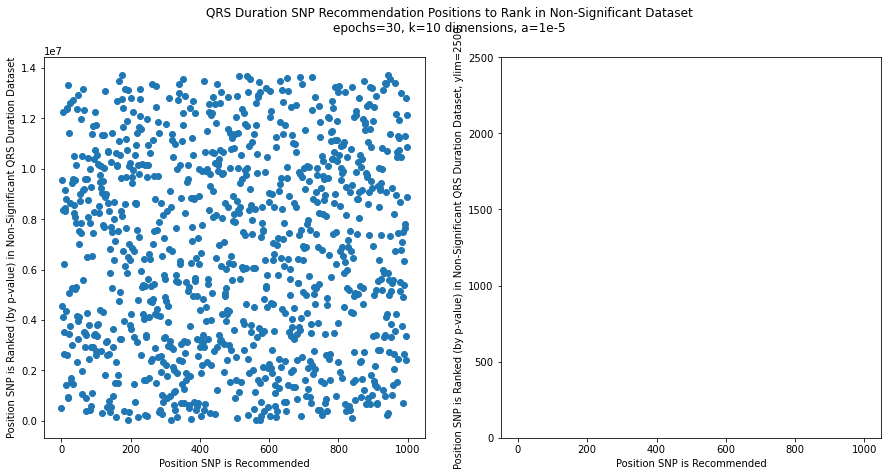

In [99]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15,7))
# fig = plt.figure(figsize=(12, 10))
fig.patch.set_facecolor('white')
ax1.scatter(range(len(non_significant_qrs_duration_recs_position[:1000])), non_significant_qrs_duration_recs_position[:1000])
ax2.scatter(range(len(non_significant_qrs_duration_recs_position[:1000])), non_significant_qrs_duration_recs_position[:1000])
ax2.set_ylim(0,2500)

# ax1.set_title('No ylim')
# ax2.set_title('ylim=2500')
ax1.set_xlabel('Position SNP is Recommended')
ax1.set_ylabel('Position SNP is Ranked (by p-value) in Non-Significant QRS Duration Dataset')
ax2.set_xlabel('Position SNP is Recommended')
ax2.set_ylabel('Position SNP is Ranked (by p-value) in Non-Significant QRS Duration Dataset, ylim=2500')
fig.suptitle('QRS Duration SNP Recommendation Positions to Rank in Non-Significant Dataset\nepochs=30, k=10 dimensions, a=1e-5')

In [102]:
trait_names_4c

['lupus',
 'mean_corpuscular_haemoglobin_concentration',
 'QRS_duration',
 'Corneal_hysteresis_left',
 'unsuccessful_stop_smoking_attempts',
 'female_genital_prolapse',
 'father_chronic_bronchitis_emphysema',
 'reticulocyte_count',
 'pulse_rate_automated_reading']

In [121]:
#removing recs that are not in qrs full data
rec_info_qrs_duration_SNPs = rec_info_4c_lupus_mchc_qrsduration[2][0]
not_in_qrs_duration_non_significant_full_data = ['rs375829783', 'rs556642707', 'rs201681851', 'rs115674060', 'rs145177562', 'rs546358522', 'rs148527788', 'rs111722751', 'rs138443906', 'rs570224400', 'rs199796609', 'rs568878521', 'rs554751435', 'rs138172966', 'rs536683304', 'rs541288921', 'rs548563662', 'rs560585459', 'rs574813846', 'rs565024096', 'rs115009304', 'rs530087387', 'rs538223867', 'rs35224402', 'rs199514462', 'rs138545268', 'rs189822486', 'rs2068243', 'rs150511923', 'rs538372230', 'rs540414385', 'rs569068324', 'rs35654708', 'rs142188467', 'rs148215125', 'rs142806010', 'rs138763496', 'rs61740147', 'rs571793569', 'rs113444393', 'rs536449046', 'rs115702747', 'rs373701632', 'rs77815840', 'rs141371381', 'rs567007654', 'rs147306012', 'rs540415870', 'rs140623081', 'rs199553775', 'rs561603477', 'rs187430722', 'rs148444990', 'rs142277567', 'rs139437329', 'rs562804818', 'rs141751043', 'rs150004751', 'rs200576346', 'rs61734045', 'rs531594229', 'rs370110205', 'rs138395129', 'rs137909519', 'rs116600135', 'rs151208219', 'rs200547024', 'rs62000453', 'rs536264084', 'rs148478498', 'rs200655179', 'rs148355444', 'rs548367126', 'rs149516161', 'rs146574385', 'rs139784416', 'rs199580679', 'rs145395391', 'rs149130310', 'rs528173288', 'rs111926990', 'rs142253130', 'rs75008861', 'rs57725422', 'rs575669681', 'rs185448327', 'rs147634480', 'rs143691369', 'rs150017839', 'rs540832166', 'rs182725627', 'rs191499924', 'rs532053506', 'rs180736640', 'rs201302371', 'rs34041945', 'rs144389427', 'rs202055538', 'rs376411203', 'rs371973497', 'rs35036619', 'rs181260849', 'rs371706716', 'rs34256013', 'rs575691378', 'rs373808092', 'rs555368347', 'rs138673535', 'rs111326671', 'rs377166311', 'rs35375999', 'rs374544992', 'rs61746392', 'rs34803755', 'rs192598874', 'rs567491448', 'rs371140684', 'rs371139134', 'rs28940885', 'rs145950613', 'rs184211583', 'rs532644782', 'rs143520192', 'rs137871355', 'rs199639247', 'rs147685072', 'rs61743383', '11:48239137_CT_C', 'rs372810597', 'rs138953266', 'rs75471387', 'rs116238028', 'rs546219561', 'rs146157839', 'rs111759871', 'rs191723490', 'rs533121789', 'rs139634188', 'rs138208049', 'rs150585610', 'rs568303257', 'rs143547637', 'rs199497561', 'rs138285636', 'rs149190046', 'rs183795056', 'rs371962113', 'rs139974951', 'rs146921625', 'rs201865282', 'rs377296839', 'rs371870934', 'rs186151755', 'rs141529027', 'rs141271240', 'rs560732386', 'rs186902443', 'rs543657618', 'rs199821391', 'rs192158429', 'rs148733148', 'rs148950746', 'rs192243687', 'rs538965336', 'rs189876952', 'rs138408187', 'rs144724390', 'rs148693918', 'rs141373924', 'rs140908390', 'rs141624294', 'rs529881754', 'rs539211233', 'rs543092318', 'rs35432631', 'rs201618273', 'rs139888108', 'rs146098391', 'rs201304559', 'rs143610596', 'rs183392250', 'rs374794979', 'rs186809089', 'rs138537245', 'rs138492532', 'rs113225770', 'rs145174974', 'rs137958059', 'rs112889393', 'rs118066970', 'rs2232787', 'rs186606579', 'rs201189180', 'rs145848231', 'rs146067486', 'rs533733453', 'rs79096553', 'rs76992529', 'rs541621477', 'rs139031286', 'rs141122140', 'rs551141144', 'rs142662990', 'rs79984281', 'rs142163721', 'rs143384624', 'rs199767748', 'rs566219944', 'rs149244748', 'rs528604984', 'rs200351774', 'rs140589234', 'rs201231959', 'rs141724442', 'rs373827792', 'rs201688116', 'rs148448946', 'rs140719911', 'rs144292473', 'rs148480631', 'rs190316360', 'rs149011538', 'rs546171608', 'rs16840956', 'rs113597275', 'rs138888235', 'rs544381487', 'rs149507464', 'rs139640936', 'rs540340877', 'rs368896641', 'rs558049660', '9:140109389_G_A', 'rs61746192', 'rs113451915', 'rs140126918', 'rs118062293', 'rs533099097', 'rs141529529', 'rs145708001', 'rs188175424', 'rs147275739', 'rs182651188', 'rs115647449', 'rs191798690', 'rs533249283', 'rs140984413', 'rs147136470', 'rs200840954', 'rs193179116', 'rs553093185', 'rs148393062', 'rs61729593', 'rs16989105', 'rs148931659', 'rs2297417', 'rs114513539', 'rs181570462', 'rs141552726', 'rs193265694', 'rs55656713', 'rs201686148', 'rs767920285', 'rs543685758', 'rs141719529', 'rs147152497', 'rs34524265', 'rs144791420', 'rs73517551', 'rs138465494', 'rs545585481', 'rs140794370', 'rs17060941', 'rs562635733', 'rs61734412', 'rs189104598', 'rs141684275', 'rs149772688', 'rs377370844', 'rs142120837', 'rs567079410', 'rs368417374', 'rs115530122', 'rs536266992', 'rs139185707', 'rs143696910', 'rs141324828', 'rs36216910', 'rs150595465', 'rs202010872', 'rs181901202', 'rs374863227', 'rs549746836', 'rs545834123', 'rs146226591', 'rs201032908', 'rs77245714', 'rs113160746', 'rs537181001', 'rs76755411', 'rs145165443', 'rs200329367', 'rs568877287', 'rs73692606', 'rs145299598', 'rs17096969', 'rs574248032', 'rs114789019', 'rs570106143', 'rs1051949', 'rs779861392', 'rs111974142', 'rs199861876', 'rs201334709', 'rs201992648', 'rs149335809', 'rs184559206', 'rs186156814', 'rs201707139', 'rs567832274', 'rs111630745', 'rs114197223', 'rs139693607', 'rs201443444', 'rs111499130', 'rs185330237', 'rs1110020', 'rs564734737', 'rs144061396', 'rs200935930', 'rs34448930', 'rs61743943', 'rs141845943', 'rs376630294', 'rs201616473', 'rs569695290', 'rs531482489', 'rs529657121', 'rs112206544', 'rs149552496', 'rs139046850', 'rs577525219', 'rs141424464', 'rs187099869', 'rs548780711', 'rs143010465', 'rs370529416', 'rs115124215', 'rs137914136', 'rs201259331', 'rs191617067', 'rs141738557', 'rs150871246', 'rs142005186', 'rs371906160', 'rs377498068', 'rs150375746', 'rs143821486', 'rs577379114', 'rs55902832', 'rs145256530', 'rs138901264', 'rs141969833', 'rs373009795', 'rs147785481', 'rs150997327', 'rs571708422', 'rs139476931', 'rs536216899', 'rs74135743', 'rs115783644', 'rs149550268', 'rs560948877', 'rs114600103', 'rs80130403', 'rs563851361', 'rs140430323', 'rs377011618', 'rs534747867', 'rs199537775', 'rs149065924', 'rs371992268', 'rs187914531', '3:58304301_AG_A', 'rs2228656', '9:140332516_C_T', 'rs141484570', 'rs577168872', 'rs73767784', 'rs59461308', 'rs200747448', 'rs193249052', 'rs144936776', 'rs569434437', 'rs554891628', 'rs571300871', 'rs369180703', 'rs561138914', 'rs73967112', 'rs148663600', 'rs542634007', 'rs144097137', 'rs144484046', 'rs145302297', 'rs139841411', 'rs138778256', 'rs187848097', 'rs77504671', 'rs185040860', 'rs138852178', 'rs368007583', 'rs146552050', 'rs35791889', 'rs371089226', 'rs547676556', 'rs74408211', 'rs79756836', 'rs558639756', 'rs546904374', 'rs367564020', 'rs199553530', 'rs371283478', 'rs535615357', 'rs17335452', 'rs145964223', 'rs181142643', 'rs56089364', 'rs371867108', 'rs559356352', 'rs74826042', 'rs73928631', 'rs144670021', 'rs545434777', 'rs147315081', 'rs77122651', 'rs141309351', 'rs113049675', 'rs569188659', 'rs141178444', 'rs570840624', 'rs183392673', 'rs143931022', 'rs191314989', 'rs552116966', 'rs368370389', 'rs576608701', 'rs147402577', 'rs77561254', 'rs531715668', 'rs370582561', 'rs138701701', 'rs377533687', 'rs77170752', 'rs574694398', 'rs370337184', 'rs183269704', 'rs567462605', 'rs35720809', 'rs121908202', 'rs77922978', 'rs150379192', 'rs558650011', 'rs149474517', 'rs139056290', 'rs141531709', 'rs146575678', 'rs146456583', 'rs116718869', 'rs544273625', 'rs36028197', 'rs142962530', 'rs139202319', 'rs141843958', 'rs8178332', 'rs112196547', 'rs149008212', 'rs142693095', 'rs148131699', 'rs112026097', 'rs149099749', 'rs146382972', 'rs4537', 'rs115031907', 'rs138563147', 'rs554714928', 'rs146352763', 'rs533138514', 'rs370673410', 'rs141578108', 'rs111631396', 'rs190783749', 'rs562891814', 'rs201618488', 'rs192992102', 'rs77154598', 'rs140617954', 'rs548401870', 'rs115348383', 'rs187643707', 'rs200562564', 'rs142408719', 'rs544251129', 'rs75912940', 'rs114039410', 'rs148881682', 'rs142929495', 'rs115042261', 'rs139632884', 'rs190975208', 'rs182450773', 'rs151019291', 'rs144512255', 'rs113027102', 'rs376162444', 'rs150904756', 'rs148777356', 'rs116417406', 'rs201861005', 'rs7742995', 'rs149836624', 'rs562407605', 'rs556636235', 'rs138799019', 'rs370681036', 'rs566197619', 'rs370938067', 'rs150977455', 'rs77327236', 'rs140540931', 'rs144476686', 'rs371935054', 'rs560209839', 'rs201413781', 'rs546855219', 'rs149410116', 'rs373730937', 'rs75272959', 'rs186098993', 'rs114222189', 'rs7215148', 'rs145106493', 'rs79466425', 'rs113704391', 'rs5959969', 'rs147152025', 'rs12685968', 'rs192612525', 'rs376537890', 'rs374554351', 'rs35234213', 'rs150743664', 'rs185257851', 'rs186717254', 'rs118181419', 'rs558581290', 'rs538000912', 'rs566757618', 'rs199978081', 'rs146164508', 'rs10427371', 'rs141136161', 'rs138711511', 'rs144612088', 'rs150956774', 'rs536554797', 'rs190044046', '9:140328778_G_A', 'rs150928521', 'rs201772546', 'rs57682233', 'rs144233469', 'rs149921520', 'rs114667676', 'rs544177015', 'rs138646616', 'rs549934568', 'rs148193280', 'rs139699062', 'rs184824201', 'rs116293399', 'rs553337725', 'rs141729484', 'rs145654028', 'rs143959915', 'rs142659036', 'rs528209014', 'rs570317622', 'rs150253672', 'rs539060063', 'rs199735542', 'rs368544526', 'rs35567709', 'rs116475741', 'rs148888527', 'rs541328826', 'rs115827904', 'rs541489372', 'rs371035141', 'rs138567683', 'rs61750769', 'rs150597836', 'rs531603937', 'rs374987545', 'rs111945364', 'rs146692150', 'rs373106011', 'rs147001069', 'rs732186', 'rs115378494', 'rs202054993', 'rs61747888', 'rs201502121', 'rs199591078', 'rs570291736', 'rs563910734', 'rs139657703', 'rs544267389', 'rs538529396', 'rs533336501', 'rs140745215', 'rs149508924', 'rs201166676', 'rs567429522', 'rs139606197', 'rs569792948', 'rs143116225', 'rs142147961', 'rs116663267', 'rs45460497', 'rs148320274', 'rs34737938', 'rs142335229', 'rs149923357', 'rs115861271', 'rs549504969', 'rs34459048', 'rs111363334', 'rs142667203', 'rs546981627', 'rs16910366', 'rs138245177', 'rs140973670', 'rs9988907', 'rs146740233', 'rs371636673', 'rs78211237', 'rs370136916', 'rs9390227', 'rs144778412', 'rs570536169', 'rs114409213', 'rs144903475', 'rs200804305', 'rs147381270', 'rs138562746', 'rs150696057', 'rs146660838', 'rs149714173', 'rs140912550', 'rs140669662', 'rs144672667', 'rs574093895', 'rs372668741', 'rs76751052', 'rs377300136', 'rs140842472', 'rs373148836', 'rs188245257', 'rs782327901', 'rs200579750', 'rs114223788', 'rs556499474', 'rs35802968', 'rs551335241', 'rs56081375', 'rs104894005', 'rs141763753', 'rs146748659', 'rs143972395', 'rs151200929', 'rs138567317', '7:21948130_TAA_T', 'rs143802836', 'rs201936380', 'rs567369483', 'rs150297407', 'rs374216085', 'rs200735729', 'rs112913154', 'rs114345151', 'rs34817773', 'rs150154438', 'rs367606595', 'rs377221649', 'rs148426184', 'rs35134032', 'rs148254002', 'rs150407952', 'rs146231360', 'rs150374461', 'rs546844787', 'rs75880769', 'rs114601626', 'rs79327004', 'rs534407654', 'rs78888823', 'rs2478007', 'rs373762797', 'rs146614254', 'rs144742248', 'rs149693049', 'rs186859650', 'rs561899797', 'rs146914457', 'rs113445311', 'rs368247345', 'rs191151496', 'rs538504593', 'rs184535083', 'rs574842437', 'rs138527852', 'rs201282046', 'rs141399719', '6:158535756_TTTC_T', 'rs150498801', 'rs61742691', 'rs138951793', 'rs537313022', 'rs140734493', '9:140140138_C_A', 'rs142956522', 'rs185641221', 'rs145070635', 'rs148341631', 'rs111909281', 'rs150537161', 'rs72552768', 'rs148963657', 'rs148357753', 'rs559068139', 'rs115657588', 'rs558558313', 'rs141228360', 'rs548709190', 'rs141357439', 'rs572193263', 'rs564692287', 'rs115307391', 'rs200686705', 'rs558291525', 'rs562337249', 'rs549610610', 'rs568427370', 'rs574924831', 'rs148986484', 'rs148752234', 'rs374627950', 'rs143305160', 'rs150994160', 'rs151333396', 'rs544815967', 'rs138824749', 'rs372975124', 'rs149677108', 'rs569359058', 'rs73407439', 'rs530222076', 'rs191945631', 'rs115615162', 'rs199755535', 'rs79991946', 'rs146475540', 'rs139517699', 'rs535530460', 'rs116127803', 'rs114424225', 'rs200786509', 'rs78225840', 'rs80083279', 'rs201550309', 'rs145720393', 'rs200373607', 'rs181495977', 'rs200303706', 'rs143330576', 'rs376045281', 'rs577325129', 'rs61729389', 'rs111476645', 'rs61735142', 'rs61746946', 'rs180787507', 'rs143334635', 'rs200453196', 'rs201062535', 'rs371289114', 'rs56035657', 'rs147022968', 'rs377452240', 'rs146700531', 'rs140699115', 'rs78215199', 'rs201938606', 'rs149180041', 'rs563144839', 'rs533512435', 'rs533508558', '2:84924864_AG_A', 'rs544391736', 'rs61736031', 'rs140902364', 'rs149262326', 'rs57174146', 'rs576846295', 'rs79336371', 'rs535869886', 'rs537380923', 'rs547001287', 'rs143395310', 'rs3745226', 'rs146090173', 'rs75846927', 'rs538235131', 'rs543436991', 'rs557347375', 'rs145214707', 'rs148771081', 'rs34550263', 'rs115261157', 'rs7664937', 'rs542344827', 'rs144015985', 'rs577248023', 'rs202214902', 'rs150060329', 'rs139956268', 'rs189452931', 'rs34714252', 'rs574761772', 'rs559721706', 'rs201380388', 'rs574634251', 'rs371663744', 'rs114464632', 'rs149887824', 'rs367789559', 'rs372824730', 'rs150440100', 'rs190710814', 'rs200190513', 'rs74899279', 'rs143014223', 'rs114819623', 'rs566555617', 'rs73930983', 'rs34986695', 'rs150043409', 'rs114332129', 'rs183494414', 'rs368646606', 'rs35398830', 'rs112779751', 'rs372232106', 'rs34080917', 'rs377451293', 'rs142359030', 'rs577156253', 'rs372619852', 'rs181925915', 'rs147415938', 'rs147377810', 'rs148365707', 'rs139863822', 'rs35884667', 'rs536119962', 'rs74795999', 'rs183150602', 'rs371241326', 'rs61741747', 'rs568978951', 'rs61764219', 'rs182989479', 'rs17884957', 'rs143044329', 'rs371935614', 'rs150393255', 'rs56291926', 'rs35978122', 'rs138839050', 'rs199760830', 'rs6965052', 'rs111422841', 'rs373462130', 'rs139638496', 'rs150779994', 'rs538068390', 'rs142179394', 'rs76082832', 'rs151058158', 'rs144294657', 'rs112777023', 'rs143979324', 'rs150717829', 'rs371851319', 'rs143084059', 'rs200726158', 'rs145919469', 'rs181342861', 'rs143915496', 'rs144359957', 'rs139146419', 'rs190718878', 'rs201924750', 'rs147366495', 'rs557974240', 'rs369504609', 'rs201357046', 'rs370747546', 'rs199986147', 'rs114829238', 'rs371030507', 'rs192870663', 'rs141937467', 'rs147393144', 'rs142958800', 'rs114937221', 'rs137967085', 'rs145504661', 'rs61740198', 'rs149903072', 'rs546336948', 'rs377385599', 'rs551080631', 'rs552213670', 'rs371601286', 'rs142498651', 'rs34841026', 'rs139116362', 'rs112475590', 'rs144139038', 'rs560780645', 'rs554868657', 'rs116395665', 'rs114399480', 'rs569304686', 'rs184660818', 'rs144704761', 'rs578049597', 'rs73414297', 'rs80089865', 'rs61742358', 'rs139985763', 'rs567950713', 'rs149010855', 'rs57507652', 'rs148158774', 'rs7282000', 'rs560671190', 'rs149555004', 'rs141440299', 'rs141334238', 'rs566501356', 'rs564037543', 'rs186960598', 'rs113301188', 'rs146528078', 'rs200537682', 'rs75187071', 'rs118003416', 'rs111033470', 'rs16879428', 'rs182154149', 'rs527915264', 'rs149495656', 'rs149027544', 'rs528462079', 'rs73058408', 'rs148543951', 'rs148013345', 'rs561515144', 'rs139038037', 'rs147806327', 'rs139952669', 'rs45616934', 'rs200405668', 'rs574512459', 'rs17172932', 'rs770943330', 'rs567122633', 'rs569717972', 'rs115474010', 'rs139263656', 'rs141234977', 'rs543598247', 'rs74026080', 'rs143346098', 'rs370836330', 'rs184548649', 'rs148499769', 'rs139163410', 'rs527588054', 'rs180718678', 'rs368677084', 'rs568753504', '2:85628670_TG_T', 'rs148377179', 'rs202005375', 'rs551393418', 'rs375044295', 'rs73438721', 'rs142138388', 'rs35717484', 'rs146209392', 'rs534795814', 'rs140375314', 'rs145794885', 'rs145179934', 'rs542705120', 'rs140485421', 'rs185514403', 'rs183035645', 'rs72655932', 'rs74928753', 'rs555428254', 'rs147562770', 'rs111336910', 'rs187126645', 'rs181924090', 'rs201292469', 'rs141941529', 'rs147827424', 'rs78656612', 'rs147404752', 'rs73831520', 'rs76169061', 'rs138552151', 'rs113314442', 'rs563990497', 'rs145874381', 'rs181091976', 'rs527659781', 'rs13330140', 'rs147194699', 'rs35327613', 'rs555266791', 'rs145641921', 'rs550188620', 'rs189743904', 'rs145294678', 'rs151292848', 'rs528884233', 'rs142108380', 'rs548962568', 'rs555044911', 'rs145691791', 'rs34852821', 'rs141045937', 'rs140528029', 'rs139349071', 'rs142120776', 'rs142098764', 'rs574670755', 'rs114183970', 'rs145182736', 'rs181920301', 'rs150452598', 'rs202229437', 'rs139596791', 'rs552285360', 'rs200436988', 'rs370924181', 'rs182292920', 'rs566482981', 'rs58453991', 'rs576427704', 'rs145368715', 'rs137905415', 'rs372412953', 'rs528673871', 'rs373427977', 'rs200994796', 'rs192023702', 'rs139985267', 'rs115335815', 'rs150964903', 'rs147218371', 'rs144461387', 'rs150812210', 'rs148398789', 'rs12671170', 'rs183497281', 'rs115970610', 'rs114241857', 'rs556208173', 'rs139346586', 'rs182389290', 'rs114189752', 'rs141847429', 'rs535261258', 'rs145450590', 'rs80239392', 'rs138917285', 'rs141481685', 'rs60226346', 'rs142190608', '17:73230909_TC_T', 'rs58449083', 'rs139403831', 'rs574453051', 'rs146091043', 'rs144152945', 'rs548760913', 'rs570361429', 'rs535994306', 'rs145245598', 'rs183808038', 'rs79656636', 'rs150424002', 'rs201209222', 'rs556351859', 'rs76492332', 'rs181685539', 'rs368116064', 'rs553994940', 'rs201528843', 'rs139129340', 'rs138221907', 'rs367835325', 'rs550381432', 'rs200675546', 'rs183331344', 'rs140510249', 'rs61745973', 'rs530726373', 'rs142906924', 'rs35369023', 'rs142775124', 'rs143708376', 'rs200908650', 'rs561369653', 'rs143361353', 'rs115824313', 'rs138111872', 'rs11063987', 'rs368917948', 'rs548097476', 'rs527366898', 'rs201001175', 'rs572525971', 'rs199942404', 'rs782505264', 'rs200011964', 'rs116121413', 'rs149434443', 'rs555535399', 'rs556469651', 'rs149479551', 'rs78221443', 'rs201187340', 'rs543155783', 'rs371084198', 'rs560954150', 'rs370768036', 'rs563421722', 'rs201860546', 'rs78504541', 'rs549846374', 'rs554397041', 'rs375627540', 'rs536436049', 'rs570409272', 'rs201635559', 'rs144583373', 'rs148199351', 'rs34362004', 'rs114095548', 'rs150098757', 'rs548495900', 'rs111631528', 'rs562320787', 'rs139938503', 'rs117635810', 'rs562717417', 'rs151307981', 'rs75485863', 'rs146558057', 'rs538416195', 'rs144773469', 'rs565294240', 'rs560111886', 'rs543974514', 'rs552494717', 'rs142053338', 'rs145327448', 'rs143033560', 'rs548750725', 'rs563830215', 'rs539919372', 'rs77776247', 'rs149851021', 'rs145273391', 'rs549744145', 'rs140772502', 'rs187760483', 'rs533057264', 'rs560310742', 'rs148450184', 'rs143002700', 'rs576197715', 'rs144539468', 'rs115937003', 'rs548513201', 'rs143021112', 'rs116065398', 'rs147245145', 'rs566156848', 'rs147924883', 'rs374745886', 'rs112728182', 'rs138134914', 'rs17122412', 'rs539136401', 'rs34971004', 'rs112829970', 'rs185615367', 'rs370360126', 'rs534823543', 'rs539490014', 'rs72885819', 'rs28720350', 'rs141190148', 'rs553771451', 'rs367926389', 'rs140075877', 'rs374961373', 'rs564119472', 'rs117857885', 'rs558834892', 'rs111822893', 'rs201777829', 'rs12943824', 'rs148662857', 'rs200731018', 'rs142278952', 'rs114056442', 'rs370044528', 'rs116698077', 'rs138066240', 'rs144717803', '9:140332610_A_G', 'rs148929910', 'rs200593845', 'rs200992340', 'rs538599868', 'rs547418317', 'rs375012171', 'rs186232617', 'rs567823759', 'rs553844519', 'rs142623073', 'rs147043971', 'rs3748934', 'rs76547444', 'rs12001631', 'rs372847962', 'rs551310703', 'rs373034990', 'rs531891863', 'rs74315352', 'rs141570904', 'rs150388299', 'rs572119016', 'rs143363612', 'rs569021434', 'rs62620172', 'rs114216623', 'rs376471769', 'rs181069353', 'rs555142180', 'rs143689515', 'rs74507746', 'rs559993963', 'rs546617253', 'rs140251743', 'rs149527164', 'rs73733789', 'rs146940267', 'rs571875463', 'rs575873204', 'rs541615844', 'rs146065064', 'rs544736620', 'rs374719362', 'rs116038324', 'rs187499384', 'rs149075315', 'rs114249678', 'rs200385471', 'rs143379489', 'rs115503048', 'rs376396220', 'rs61748989', 'rs369424218', 'rs61743043', 'rs150388476', 'rs143171724', 'rs137989705', 'rs572079060', 'rs549662786', 'rs144353308', 'rs563266139', 'rs148334511', 'rs148784140', 'rs546432678', 'rs76268440', 'rs148293064', 'rs116226041', 'rs141314140', 'rs552868630', 'rs202109366', 'rs146165026', 'rs144863210', 'rs145939178', 'rs759933264', 'rs532383266', 'rs149471226', 'rs140863311', 'rs144253083', 'rs138750713', 'rs115746833', '9:140139289_C_T', 'rs535523717', 'rs539790989', 'rs569130866', 'rs374744182', 'rs367759946', 'rs532897882', 'rs146069171', 'rs201931616', 'rs142488101', 'rs527636188', 'rs202193367', 'rs187382639', 'rs150637770', 'rs371175801', 'rs144108474', 'rs139975529', 'rs376338996', 'rs530672818', 'rs574808065', 'rs373009361', 'rs146802703', 'rs35976098', 'rs77793692', 'rs138657959', 'rs369306278', 'rs77296801', 'rs149897266', 'rs144999621', 'rs184367458', 'rs145921136', 'rs570863189', 'rs141177570', 'rs148813418', 'rs140386372', 'rs549544710', 'rs372640159', 'rs34514482', 'rs369445382', 'rs115594989', 'rs142505459', 'rs147057333', 'rs76100543', 'rs146677916', 'rs199938294', 'rs79725985', 'rs372794745', 'rs74097352', 'rs144375581', 'rs142931494', 'rs540234409', 'rs111239786', 'rs150323671', 'rs34064543', 'rs142822908', 'rs144086685', 'rs568935223', 'rs199818878', 'rs574535436', 'rs569558990', 'rs560982223', 'rs116281803', 'rs145696105', 'rs149899336', 'rs140065005', 'rs544539173', 'rs147712872', 'rs140414813', 'rs139815591', 'rs146002202', 'rs76231557', 'rs116632009', 'rs115928916', 'rs16941036', 'rs184610937', 'rs113126355', 'rs61746364', 'rs141885902', 'rs550339074', 'rs73527668', 'rs140931278', 'rs186227392', 'rs567535305', 'rs149028713', 'rs564835434', 'rs188648849', 'rs552097729', 'rs574369653', 'rs10171090', 'rs530097928', 'rs538179355', 'rs141226650', 'rs372681735', 'rs149894086', 'rs564655462', 'rs150459624', 'rs201366322', 'rs112613526', 'rs368942099', 'Affx-52341077', 'rs35769851', 'rs150645094', 'rs143027666', 'rs368726362', 'rs147984699', 'rs145221265', 'rs587770919', 'rs372173050', 'rs201705049', 'rs369181343', 'rs368475161', 'rs144273747', 'rs149921775', 'rs114051835', 'rs78626330', 'rs370022660', 'rs187290995', 'rs561439651', 'rs201922087', 'rs143564011', 'rs572886978', 'rs185178790', 'rs202236298', 'rs527922844', 'rs143652476', 'rs367547310', 'rs200373323', 'rs548120520', 'rs148490439', 'rs199734308', 'rs576833928', 'rs565639153', 'rs111485276', 'rs112971942', 'rs201684735', 'rs141276821', 'rs116448422', 'rs557897530', 'rs139119204', 'rs201804825', 'rs78644100', 'rs570379635', 'rs560514658', 'rs147860570', 'rs147026086', 'rs200965700', 'rs199802058', 'rs148518212', 'rs148002629', 'rs61524789', 'rs145239390', 'rs143738959', 'rs143191258', 'rs142588247', 'rs115585711', 'rs12449', 'rs140742872', 'rs556562482', 'rs142794598', 'rs35400293', 'rs570857982', 'rs537811182', 'rs117793265', 'rs140942477', 'rs146193091', 'rs144984094', 'rs571863743', 'rs139212069', 'rs74996907', 'rs150695752', 'rs57497763', 'rs142358238', 'rs149978591', 'rs200178842', 'rs141531302', 'rs142372468', 'rs115618657', 'rs370128756', 'rs139558505', 'rs145573310', 'rs138671319', 'rs181340777', 'rs1062656', 'rs201437777', 'rs372720433', 'rs563042955', 'rs5959130', 'rs142558157', 'rs539158429', 'rs188271713', 'rs562754099', 'rs558273652', 'rs17875379', 'rs61740553', 'rs140186161', 'rs41521545', 'rs146986172', 'rs7047681', 'rs146421591', 'rs565025247', 'rs376586626', 'rs148202016', 'rs62640871', 'rs72648903', 'rs368689811', 'rs551421793', 'rs200387345', 'rs376449068', 'rs140435814', 'rs116784032', 'rs149686889', 'rs74607574', 'rs144166773', 'rs185704649', 'rs114999931', 'rs201282523', 'rs117008450', 'rs183481368', 'rs149147457', 'rs200818459', 'rs532714506', 'rs570264215', 'rs185819767', 'rs138487121', 'rs571909632', 'rs537114438', 'rs200744016', 'rs199672312', 'rs116285844', 'rs113998384', 'rs146969620', 'rs201717101', 'rs543828502', 'rs201177523', 'rs571944994', 'rs574068134', 'rs528262308', 'rs72861448', 'rs374530192', 'rs568498010', 'rs199735447', 'rs74327902', 'rs111402402', 'rs61754762', 'rs538319943', 'rs200427772', 'rs147819380', 'rs149473090', 'rs147484679', 'rs371862356', 'rs142260841', 'rs28378907', 'rs529241246', 'rs376573960', 'rs150530456', 'rs572746963', 'rs201209495', 'rs147838234', 'rs115057148', 'rs115907080', 'rs201954301', 'rs141381958', 'rs201894404', 'rs116454042', 'rs35129924', 'rs199803784', 'rs371789705', 'rs11111008', 'rs35755074', 'rs138540912', 'rs182583278', 'rs62637581', 'rs73074874', 'rs148523845', 'rs529987315', 'rs373698539', 'rs141723721', 'rs150423564', 'rs531054649', 'rs72546675', 'rs140584840', 'rs148627417', 'rs189222545', 'rs72470556', 'rs114716391', 'rs79742727', 'rs78593056', 'rs77359014', 'rs200627167', 'rs575687014', 'rs150082041', 'rs138918545', 'rs190257381', 'rs187008307', 'rs2071072', 'rs191928354', 'rs61733342', 'rs146729759', 'rs61756145', 'rs147548483', 'rs142944742', 'rs201042184', 'rs369804807', 'rs572278827', 'rs148080392', 'rs144333010', 'rs142638391', 'rs555522471', 'rs201688964', 'rs144429524', 'rs193280002', 'rs115300336', 'rs148686768', 'rs367995491', 'rs544224850', 'rs139540399', 'rs186654489', 'rs190344718', 'rs116879618', 'rs561923616', 'rs530657692', 'rs9475580', 'rs146458320', 'rs371048513', 'rs61735762', 'rs61746204', 'rs538389504', 'rs75637615', 'rs546606582', 'rs544231293', 'rs201058595', 'rs61732410', 'rs369282113', 'rs144914640', 'rs371020371', 'rs187958003', 'rs139026931', 'rs530549118', 'rs114650711', 'rs536586608', 'rs548275322', 'rs191683092', 'rs79809527', 'rs201129554', 'rs191662435', 'rs200864918', 'rs191091347', 'rs145630307', 'rs527326290', 'rs115007185', 'rs545865972', 'rs370710210', 'rs200057311', 'rs150091985', 'rs183191346', 'rs60551236', 'rs538241344', 'rs201957775', 'rs148091091', 'rs368802969', 'rs141549106', 'rs145822369', 'rs147612968', 'rs148003788', 'rs559503020', 'rs144418972', 'rs189273585', 'rs17003166', 'rs145876711', 'rs377630367', 'rs149022976', 'rs138770585', 'rs545702407', 'rs61738655', 'rs78915828', 'rs201615050', 'rs114908705', 'rs377200766', 'rs201644816', 'rs553242967', 'rs371295542', 'rs149417595', 'rs200105999', 'rs187385288', 'rs139280000', '9:140325772_G_A', 'rs145834168', 'rs111881084', 'rs372726982', 'rs117013822', 'rs369983423', 'rs73693125', 'rs545577153', 'rs141658242', 'rs184216853', 'rs148129112', 'rs532323423', 'rs542408280', 'rs143629026', 'rs555135854', 'rs77107178', 'rs79967289', 'rs146418089', 'rs182692156', 'rs150444926', 'rs72477393', 'rs201709535', 'rs376105192', 'rs147017625', 'rs527696306', 'rs147343281', 'rs183942740', 'rs115388023', '9:140135863_C_T', 'rs142089852', 'rs181020996', 'rs373761987', 'rs554318943', 'rs76562800', 'rs573487550', 'rs79164465', 'rs374079400', 'rs76200272', 'rs528510028', 'rs150017918', '1:28835423_CTG_C', 'rs146280598', 'rs148868529', 'rs371774101', 'rs547495754', 'rs191443253', 'rs577597607', 'rs138678049', 'rs528866197', 'rs572047686', 'rs115503884', 'rs200022152', 'rs73499790', 'rs200959519', 'rs150448499', 'rs73764462', 'rs79645637', 'rs144843179', 'rs541434931', 'rs574391638', 'rs202092368', 'rs114043407', 'rs530232493', 'rs140354638', 'rs7103932', 'rs150581567', 'rs192910254', 'rs79483116', 'rs145839001', 'rs111352477', 'rs553549691', 'rs141559731', 'rs146760649', 'rs372991016', 'rs546060091', 'rs577346796', 'rs551301563', 'rs563106937', 'rs201517784', 'rs199645058', 'rs374612024', 'rs140462332', 'rs11000008', 'rs184121520', 'rs45565936', 'rs28705326', 'rs538459412', 'rs73854411', 'rs201894544', 'rs202033888', 'rs116837130', 'rs200214226', 'rs528874319', 'rs148234399', 'rs140643849', 'rs144742201', 'rs140493415', 'rs200318120', 'rs115793379', 'rs144039601', 'rs200707525', 'rs201533499', 'rs181923542', 'rs45458701', 'rs142191000', 'rs531700611', 'rs539526159', 'rs374891672', 'rs114955344', 'rs112896959', 'rs560671239', 'rs61747598', 'rs139690921', 'rs543968189', 'rs45518335', 'rs191924584', 'rs562768546', 'rs560348247', 'rs373617404', 'rs199568117', '9:139983329_T_C', 'rs140538499', 'rs113840840', 'rs561184346', 'rs369168742', 'rs142273664', 'rs573103442', 'rs372936004', 'rs75076520', 'rs546842447', 'rs573747830', 'rs201142286', 'rs115060838', 'rs76212539', 'rs17865175', 'rs115503899', 'rs61736337', 'rs149585221', 'rs185924078', 'rs200703509', 'rs372037200', 'rs531129353', 'rs72477383', 'rs72477384', 'rs150751171', 'rs115258403', 'rs148459448', 'rs146234015', 'rs568818694', 'rs181705702', 'rs558012795', 'rs569634993', 'rs147855137', 'rs147060997', 'rs10417532', 'rs564211780', 'rs35586212', 'rs55642287', 'rs150098320', 'rs536992900', 'rs34612917', 'rs180934785', 'rs569411702', 'rs148497570', 'rs568135080', 'rs3733748', 'rs141060878', 'rs528631558', 'rs138915422', 'rs141844806', 'rs537340027', 'rs73741344', 'rs568109142', 'rs373912778', 'rs188372756', 'rs139404083', 'rs147689373', 'rs142976966', 'rs149253278', 'rs141787544', 'rs145663467', 'rs6879044', 'rs532538118', 'rs534658921', 'rs151202823', 'rs536482365', 'rs140031589', 'rs528875608', 'rs138035523', 'rs140862613', 'rs114860054', 'rs545421792', 'rs372181308', 'rs147938299', 'rs200151026', 'rs368940692', 'rs142048126', 'rs532463670', 'rs558410105', 'rs564485342', 'rs138647261', 'rs142953140', 'rs113506045', 'rs183053881', 'rs79906565', 'rs113595171', 'rs74456733', 'rs113978418', 'rs145896080', 'rs150441263', 'rs199774840', '15:42983017_TTAA_T', 'rs562477828', 'rs200432206', 'rs17184058', 'rs144029141', 'rs377346267', 'rs546236816', 'rs142685897', 'rs141412552', 'rs144614895', 'rs150161484', '7:64453199_G_C', 'rs137912279', 'rs547868223', 'rs116425421', 'rs144056103', 'rs2234016', 'rs150361670', 'rs111483355', 'rs201905010', 'rs565160327', 'rs143665378', 'rs146821586', 'rs200344943', 'rs78751736', 'rs4647750', 'rs377227289', 'rs200703629', 'rs140976108', 'rs143372639', 'rs182236814', 'rs575970926', 'rs28590040', 'rs35212254', 'rs201733523', 'rs370215970', 'rs144336324', 'rs144151968', 'rs370968831', 'rs113438034', 'rs147439442', 'rs144592458', 'rs139625756', 'rs375370012', 'rs138819759', 'rs190324060', 'rs3802774', 'rs143197341', 'rs373065987', 'rs577650666', 'rs148618359', 'rs151091410', 'rs140901243', 'rs138064276', 'rs572347248', 'rs375778014', 'rs141337128', 'rs143380213', 'rs143613026', 'rs150511473', 'rs150341628', 'rs200417501', 'rs145744729', 'rs188002937', 'rs138003548', 'rs542917020', 'rs376832252', 'rs200519273', 'rs139387430', 'rs375665368', 'rs145178582', 'rs538688612', 'rs200312432', 'rs35438756', 'rs34887859', 'rs79245589', 'rs189197382', 'rs35694910', 'rs143496445', 'rs76081119', 'rs148539877', 'rs376711157', 'rs34748076', 'rs76850132', 'rs11539947', 'rs555235729', 'rs200249696', 'rs571744728', 'rs184926354', 'rs9995771', 'rs201757338', 'rs141840169', 'rs139575643', 'rs146401647', 'rs138672467', 'rs139727469', 'rs11941441', 'rs5273', 'rs573965743', 'rs4551616', 'rs200509134', 'rs192512106', 'rs139485288', 'rs577602507', 'rs550577283', 'rs147850775', 'rs370795866', 'rs148089397', 'rs529007014', 'rs146385150', 'rs138733039', 'rs191135679', 'rs73814539', 'rs192657438', 'rs529334290', 'rs199927578', 'rs73494464', 'rs114585401', 'rs533663796', 'rs560353070', 'rs141428904', 'rs202235772', 'rs202228898', 'rs141682815', 'rs145414185', 'rs757313613', 'rs557513677', 'rs79982539', 'rs202095663', 'rs371172036', 'rs150686604', 'rs80145928', 'rs368954457', 'rs78046731', 'rs111687262', 'rs149526922', 'rs141725405', 'rs150603065', 'rs150993247', 'rs374753323', 'rs559552668', 'rs144021070', 'rs199997031', 'rs371466859', 'rs146586865', 'rs551570946', 'rs183268816', 'rs150809894', 'rs141906162', 'rs145936388', 'rs143945485', 'rs74945428', 'rs530397959', 'rs558930019', 'rs536111967', 'rs111474643', 'rs61735576', 'rs115646828', 'rs372673436', 'rs201331308', 'rs116793188', 'rs142301612', 'rs142234201', 'rs199855026', 'rs112029722', 'rs146127028', 'rs189318877', 'rs192588830', 'rs536495962', 'rs200828005', 'rs183536507', 'rs28504322', 'rs145377551', 'rs35098282', 'rs145577568', 'rs74109744', 'rs187173455', 'rs370503382', 'rs140950764', 'rs151200657', 'rs17879685', 'rs143568996', 'rs201593796', 'rs146700420', 'rs199917289', 'rs143470802', 'rs201134613', 'rs140521544', 'rs141876588', 'rs201484462', 'rs555757931', 'rs185908015', 'rs139680176', 'rs61743033', 'rs146009413', 'rs561486183', 'rs549177191', 'rs111846078', 'rs375897439', 'rs576955344', 'rs374693794', 'rs115033268', 'rs375278162', 'rs2232902', 'rs143526587', 'rs377761509', 'rs374964128', 'rs201958902', 'rs61738724', 'rs542498051', 'rs115658425', 'rs369732120', 'rs61729334', 'rs34412692', 'rs61744962', 'rs138729211', 'rs78255362', 'rs80169877', 'rs16866477', 'rs58241708', 'rs148757465', 'rs35021228', 'rs149143221', 'rs535662451', 'rs577136681', 'rs201260827', 'rs555361670', '9:140246557_C_T', 'rs139493548', 'rs147970737', 'rs11573581', 'rs77915386', 'rs139745617', 'rs35051256', 'rs140599630', 'rs186386802', 'rs137950394', 'rs141910644', 'rs112910113', 'rs199556208', 'rs146651553', 'rs138489743', 'rs150092512', 'rs201145311', 'rs374565904', 'rs73007784', 'rs189783666', 'rs76224047', 'rs144604909', 'rs143043221', 'rs536159419', 'rs574786070', 'rs148851846', 'rs530814439', 'rs373169282', 'rs201883107', '9:140137237_C_T', 'rs116584693', 'rs142616407', 'rs193006130', 'rs376035565', 'rs116536846', 'rs115992022', 'rs552049134', '14:76330194_GCCCGGC_G', 'rs144889716', 'rs142693813', '9:140329411_C_T', 'rs139728770', 'rs374159387', 'rs572225798', 'rs191767705', 'rs145732118', 'rs114594978', 'rs550700273', 'rs116840681', 'rs147132354', 'rs201537364', 'rs570884354', 'rs369429157', 'rs138092357', 'rs148439082', 'rs540169574', 'rs61747186', 'rs139672829', 'rs186329393', 'rs371336985', 'rs529120446', '9:140115257_C_A', 'rs151188411', 'rs141015974', 'rs363212', 'rs142719833', 'rs143572782', 'rs150527574', 'rs35100425', 'rs540420817', 'rs567853124', 'rs537285931', 'rs139760966', 'rs144383443', 'rs75618094', 'rs149245922', 'rs553164974', 'rs545106279', 'rs149165530', 'rs61729653', 'rs137861730', 'rs547911655', 'rs8191472', 'rs140455646', 'rs149500485', 'rs200517074', 'rs115822333', 'rs191499985', 'rs114645401', 'rs202185529', 'rs202087119', 'rs199642534', 'rs140358824', 'rs530585966', 'rs138881803', 'rs78919061', 'rs74136386', 'rs150109347', 'rs372162375', 'rs116406284', 'rs539153516', 'rs148210603', 'rs116088871', 'rs183549458', 'rs115742687', 'rs146800609', 'rs561939015', 'rs34123123', 'rs542200430', 'rs543121899', 'rs183356632', 'rs374855183', 'rs116448324', 'rs191382130', 'rs138583090', 'rs528676420', 'rs140048797', 'rs34671330', 'rs374021225', 'rs61753551', 'rs141430018', 'rs148810594', 'rs556460791', 'rs142752739', 'rs569101326', 'rs143681721', 'rs114187957', 'rs372692701', 'rs141346724', 'rs113210971', 'rs116520088', 'rs144409622', 'rs138358489', 'rs61740190', 'rs553550581', 'rs568397466', 'rs564383457', 'rs114854839', 'rs138502131', 'rs536031300', 'rs560435453', 'rs140495935', 'rs78345508', 'rs151134465', 'rs140654562', 'rs74137740', 'rs201492867', 'rs367793265', 'rs372759495', 'rs146319184', 'rs34838640', 'rs560991616', 'rs144483053', 'rs566357407', 'rs115885893', 'rs549122604', 'rs563483217', 'rs139620478', 'rs186965235', 'rs142728622', 'rs191263181', 'rs377528277', 'rs9282546', 'rs111390143', 'rs114392274', 'rs560902570', 'rs536471811', 'rs200397589', 'rs183265310', 'rs187867808', 'rs201287604', 'rs148149998', 'rs202014798', 'rs56387705', 'rs534918636', 'rs147638039', 'rs199772940', 'rs200375563', 'rs192497923', 'rs373601877', 'rs192617380', 'rs146051624', 'rs75780325', 'rs76701112', 'rs142816072', 'rs200140585', 'rs145042066', 'rs114693585', 'rs139743836', 'rs150393340', 'rs546423899', 'rs201341174', 'rs529554075', 'rs200630681', 'rs577167954', 'rs372409338', 'rs201063442', 'rs61736441', 'rs12849161', 'rs201046527', 'rs146469983', 'rs143359617', 'rs148809294', 'rs113051141', 'rs148684762', 'rs17147990', 'rs372290126', 'rs116670960', 'rs142874874', 'rs145959014', 'rs201659121', 'rs139879021', 'rs7252882', 'rs576609606', 'rs574607334', 'rs77177699', 'rs11843248', 'rs200824426', 'rs144874807', 'rs148298609', 'rs80325569', 'rs199789467', 'rs180844882', 'rs565301304', 'rs142236563', 'rs113179382', 'rs201009066', 'rs185000816', 'rs200024416', 'rs201229761', 'rs45563247', 'rs139809600', 'rs139511040', 'rs61480474', 'rs115932273', 'rs541279648', 'rs115073548', 'rs572336497', 'rs377740820', 'rs141950704', 'rs146986676', 'rs544061459', 'rs188945281', 'rs2233251', 'rs150417087', 'rs150672640', 'rs554853285', 'rs200947459', 'rs551643471', 'rs534729039', 'rs145035405', 'rs574071543', 'rs145991142', 'rs548352099', 'rs375404483', 'rs140641227', 'rs550493250', 'rs143407310', 'rs374445335', 'rs146530640', 'rs147929881', 'rs187273590', 'rs61739311', 'rs200318773', 'rs61751206', 'rs557427510', 'rs202179884', 'rs116796602', 'rs144980188', 'rs189746589', 'rs370636849', 'rs139679311', 'rs151332463', 'rs77517837', 'rs575878889', 'rs185034442', 'rs199862207', 'rs144256653', 'rs139173313', 'rs541193805', 'rs185103458', 'rs150456852', 'rs75758339', 'rs191753687', 'rs143801580', 'rs150032924', 'rs557898007', 'rs143042511', 'rs200773637', 'rs111330705', 'rs138900187', 'rs34254650', 'rs562381353', 'rs566005827', 'rs115719809', 'rs201375865', 'rs75479230', 'rs114380004', 'rs146326563', 'rs61730866', 'rs180869501', 'rs78386089', 'rs201856127', 'rs6926561', 'rs139755404', 'rs201300780', 'rs189185131', 'rs112622656', 'rs61733794', 'rs374830003', 'rs186608585', 'rs34039531', 'rs146398243', 'rs149738203', 'rs200872109', 'rs535770515', 'rs141405321', 'rs201835306', 'rs199952882', 'rs76163409', 'rs188415093', 'rs199543911', 'rs541648385', 'rs570866961', 'rs369536346', 'rs371601937', 'rs140596899', 'rs377481358', 'rs141277535', 'rs562561003', 'rs150957564', 'rs61732835', 'rs145458791', 'rs140138182', 'rs4134901', 'rs145245264', 'rs148942084', 'rs573384985', 'rs201518545', 'rs182276812', 'rs143148436', 'rs368245255', 'rs538400292', 'rs144616937', '9:140000708_C_T', 'rs146934927', 'rs372830873', 'rs141742272', 'rs140327344', 'rs201583640', 'rs531246319', 'rs200710259', 'rs527499981', 'rs145131028', 'rs138911578', 'rs139880372', 'rs142629362', 'rs147162720', 'rs201883887', 'rs192391968', 'rs746210905', 'rs367984367', 'rs114688628', 'rs112807920', 'rs146623514', 'rs115672213', 'rs200330582', 'rs35937181', 'rs191229293', 'rs113652402', 'rs554346890', 'rs61729361', 'rs146081504', 'rs372080024', 'rs200545205', 'rs138848276', 'rs140018008', 'rs142607263', 'rs367566750', 'rs202059067', 'rs2243187', 'rs74573581', 'rs201598677', 'rs554085056', 'rs150194589', 'rs587682214', 'rs115738650', 'rs116804719', 'rs374650137', 'rs115426998', 'rs112415970', 'rs372489280', 'rs140329120', 'rs193002939', 'rs144336585', 'rs79920259', 'rs575283731', 'rs149232525', 'rs368937798', 'rs150297602', 'rs575475266', 'rs115307318', 'rs562297321', 'rs143204051', 'rs149067310', 'rs146727497', 'rs115714027', 'rs112667487', 'rs77465152', 'rs191505000', 'rs573872184', 'rs113534388', 'rs148493313', 'rs371547096', 'rs374874347', 'rs374313004', 'rs150595875', 'rs150245488', 'rs148427051', 'rs61735534', 'rs139002546', 'rs537627129', 'rs368222195', 'rs147516990', 'rs5203', 'rs74466658', 'rs149717631', 'rs546427209', 'rs139843226', 'rs137975172', 'rs138719219', 'rs575003767', 'rs559475635', 'rs546754201', 'rs17851642', 'rs200130461', 'rs567621235', 'rs182565081', 'rs150900282', 'rs190197851', 'rs146725149', 'rs566179741', 'rs113640022', 'rs115782087', 'rs374524735', 'rs17156893', 'rs138852341', 'rs200308666', 'rs187645447', 'rs61353224', 'rs530216146', 'rs16866490', 'rs200370699', 'rs190999185', 'rs138351858', 'rs139335342', 'rs202231256', 'rs139393604', 'rs201294610', 'rs149806516', 'rs61742882', 'rs111835858', 'rs145609436', 'rs551624003', 'rs189432330', 'rs111918827', 'rs374390884', 'rs142254384', 'rs151127945', 'rs758302822', 'rs145824229', 'rs181577831', 'rs61729405', 'rs529243486', 'rs375918282', 'rs201715627', 'rs149758992', 'rs200940788', 'rs149747801', 'rs149257166', 'rs200532524', 'rs140485896', 'rs139283268', 'rs200256772', 'rs140877474', 'rs35729907', 'rs372464585', 'rs113096800', 'rs372042825', 'rs143473050', 'rs373069459', 'rs56974135', 'rs141405119', 'rs544095442', 'rs34682707', 'rs113058610', 'rs10407047', 'rs150230127', 'rs532846531', 'rs142368982', 'rs139517301', 'rs139276077', 'rs140983832', 'rs144673801', 'rs147259744', 'rs115093728', 'rs371515629', 'rs562541959', 'rs74991942', 'rs113953699', 'rs114155983', 'rs138871406', 'rs150562707', 'rs149120109', 'rs376586172', 'rs141906655', 'rs79019010', 'rs537190557', 'rs536899986', 'rs147494970', 'rs4321039', 'rs370070204', 'rs200529521', 'rs144761622', 'rs149100313', 'rs34419732', 'rs183968646', 'rs61745836', 'rs575956298', 'rs568533425', 'rs564465845', 'rs535159862', 'rs150727372', 'rs566434375', 'rs181647494', 'rs549269195', 'rs141928852', 'rs112808093', 'rs200747610', 'rs148383425', 'rs201256321', 'rs183396708', 'rs142912996', 'rs144789254', 'rs142443879', 'rs374104909', 'rs151144845', 'rs550270595', 'rs150820542', 'rs190719786', 'rs78319441', 'rs202123221', 'rs144943422', 'rs111903177', 'rs148397357', 'rs79454633', 'rs571579404', 'rs139802337', 'rs56077582', 'rs145199320', 'rs35757547', 'rs200374261', 'rs137942569', 'rs371276097', 'rs2228240', 'rs114585674', 'rs533295376', 'rs553756390', 'rs76102696', 'rs200428112', 'rs35073849', 'rs527556722', 'rs539485113', 'rs376129674', 'rs368964809', 'rs142785985', 'rs184935940', 'rs116276815', 'rs190255875', 'rs143336539', 'rs549084069', 'rs200031449', 'rs199989702', 'rs150206007', 'rs145663124', 'rs559446017', 'rs370179180', 'rs150811488', 'rs547585011', 'rs375331074', 'rs370523367', 'rs117797834', 'rs149155920', 'rs116051216', 'rs60854777', 'rs555238210', 'rs565435346', 'rs116792594', 'rs140828306', 'rs61737499', 'rs34664437', 'rs200009167', 'rs199950234', 'rs146321347', 'rs546330651', 'rs147168137', 'rs76567936', 'rs144473968', 'rs182221105', 'rs145410701', 'rs151140317', 'rs138236905', '9:140320714_C_T', 'rs115240670', 'rs147939107', 'rs114554088', 'rs183524387', 'rs78185568', 'rs548946020', 'rs200343420', 'rs550372274', 'rs145638188', 'rs534654534', 'rs113241501', 'rs143210369', 'rs148650737', 'rs138741584', 'rs199911947', 'rs149346027', 'rs560660167', 'rs546023898', 'rs199952690', 'rs116681444', 'rs540133010', 'rs61729948', 'rs139499433', 'rs201737764', 'rs563531168', 'rs138989209', 'rs201510850', 'rs143112068', 'rs549465351', 'rs377716628', 'rs75988779', 'rs77712233', 'rs190602950', 'rs146777193', 'rs16866489', 'rs139339372', 'rs34431085', 'rs372286619', 'rs200165340', 'rs200226647', 'rs143411522', 'rs147193772', 'rs143475803', 'rs201469408', 'rs574894457', 'rs573304415', 'rs201316005', 'rs148876598', 'rs187247861', 'rs200149460', 'rs151204027', 'rs140347847', 'rs150345313', 'rs73620932', 'rs116271948', 'rs151075470', 'rs553822688', 'rs369210045', 'rs147886632', 'rs114933334', 'rs143087712', 'rs10416799', 'rs113940082', 'rs151112761', 'rs191405175', '8:133819962_TG_T', 'rs544968716', 'rs199704028', '15:42982582_GGCA_G', 'rs200669105', 'rs114354377', 'rs370711135', 'rs149656913', 'rs140365536', 'rs549931514', 'rs146785063', 'rs148879560', 'rs138167675', 'rs539982627', 'rs550073900', 'rs552201239', 'rs142374527', 'rs372269463', 'rs139025287', 'rs34863826', 'rs34394477', 'rs372932175', 'rs34060770', 'rs56069016', 'rs140404507', 'rs556815713', 'rs140295451', 'rs114234514', 'rs201926426', 'rs16872923', 'rs34688192', 'rs375472780', 'rs572929447', 'rs181516672', 'rs140432105', 'rs201686718', 'rs77256337', 'rs74629680', 'rs183274811', 'rs35759430', 'rs569346127', 'rs2232034', 'rs143131504', 'rs78686282', 'rs189914793', 'rs143639783', 'rs563477880', 'rs138764398', 'rs372629459', 'rs202211100', 'rs112168987', 'rs571232531', 'rs190314042', 'rs144814689', 'rs142186054', 'rs146212021', 'rs147634857', 'rs569576386', 'rs146906622', 'rs200129355', 'rs9930526', 'rs199739700', 'rs116670456', 'rs142091462', 'rs138405277', 'rs367657995', 'rs539433347', 'rs139962336', 'rs10034987', 'rs146344936', 'rs114899589', 'rs140674300', 'rs374898440', 'rs148352897', 'rs201586656', 'rs73341383', 'rs142792812', 'rs74681806', 'rs199831047', 'rs540592253', 'rs111970336', 'rs192896520', 'rs112614800', 'rs373297258', 'rs139089184', 'rs138605791', 'rs138208452', 'rs115149308', 'rs111350670', 'rs373562734', 'rs74718983', 'rs138382714', 'rs145762575', 'rs114827737', 'rs188091523', 'rs78694994', 'rs78054727', 'rs536704812', 'rs75161557', 'rs537698189', 'rs141011007', 'rs74775599', 'rs139847292', '9:140160395_C_T', 'rs112181141', 'rs74056006', 'rs61739913', 'rs72554691', 'rs201354316', 'rs546933810', 'rs191132880', 'rs141670583', 'rs112433681', 'rs149301273', 'rs150849833', 'rs567638929', 'rs146196275', 'rs377397902', 'rs1791634', 'rs140635687', 'rs144089286', 'rs140389540', 'rs115050754', 'rs190007176', 'rs36111383', 'rs145081312', 'rs61738376', 'rs142445351', 'rs572964548', 'rs372124226', 'rs143173043', 'rs531002886', 'rs75527781', 'rs149490245', 'rs231696', 'rs138691968', 'rs141121485', 'rs576775922', 'rs41316657', 'rs112039037', 'rs78127134', 'rs148320735', 'rs146870581', 'rs556124970', 'rs548600419', 'rs782074571', 'rs201081598', 'rs140761053', 'rs564858245', 'rs9981448', 'rs140164718', 'rs150795805', 'rs148823310', 'rs768905127', 'rs189107499', 'rs201067487', 'rs370792058', 'rs144926997', 'rs556615358', 'rs61733368', 'rs570885620', 'rs145698662', 'rs567442828', 'rs367627396', 'rs61738535', 'rs115841196', 'rs13106984', 'rs138693096', 'rs139394937', 'rs141510885', 'rs531649047', 'rs116695220', 'rs188002348', 'rs114988042', 'rs200002006', 'rs115423919', 'rs140163631', 'rs201901788', 'rs148921654', 'rs368479596', 'rs552527048', 'rs57213993', 'rs554214225', 'rs34159425', 'rs143092715', 'rs142147619', 'rs147553247', 'rs115624293', 'rs115190774', 'rs112091150', 'rs146065311', 'rs143104528', 'rs147151035', 'rs36006687', 'rs34074602', 'rs554287463', 'rs143014711', 'rs572467913', 'rs545740321', 'rs150727510', 'rs200831077', 'rs201983499', 'rs372557659', 'rs35730749', 'rs34174579', 'rs184664440', 'rs142854411', 'rs201064128', 'rs200033549', 'rs569743283', 'rs192442382', 'rs576196849', 'rs140781730', 'rs148376498', 'rs569747701', 'rs139549309', 'rs541265571', 'rs200936208', 'rs572567724', 'rs535281825', 'rs150813673', 'rs550932911', 'rs12091253', 'rs368295198', 'rs141862095', 'rs376519670', 'rs142712023', 'rs191938301', 'rs76262546', 'rs556897576', 'rs140959510', 'rs560873168', 'rs541848444', 'rs61738809', 'rs568646514', 'rs368924701', 'rs777568037', 'rs144234953', 'rs545061292', 'rs148948883', 'rs146683642', 'rs199902400', 'rs150585317', 'rs148993724', 'rs62636646', 'rs1027354', 'rs111391305', 'rs140182583', 'rs199836181', 'rs75044156', 'rs200317285', 'rs185758366', 'rs150248027', 'rs566793359', 'rs147230738', 'rs114324097', 'rs377082277', 'rs9311404', 'rs144465202', 'rs188974824', 'rs144532430', 'rs142427583', 'rs140544152', 'rs150395736', 'rs370578308', 'rs74112013', 'rs148129437', 'rs587674418', 'rs193272323', 'rs572813532', 'rs200010499', 'rs151261114', 'rs139214563', 'rs369570128', 'rs112891247', 'rs782221537', 'rs376502125', 'rs200906758', 'rs142545038', 'rs146728457', 'rs145976909', 'rs146838609', 'rs368098236', 'rs571920415', 'rs375440698', 'rs201553400', 'rs374895319', 'rs149697053', 'rs538922436', 'rs143006779', 'rs112360515', 'rs115518597', 'rs376308554', 'rs368953071', 'rs145894839', 'rs74003243', 'rs202175324', 'rs150895924', 'rs200398000', 'rs559221175', 'rs138929210', 'rs367770672', 'rs146945979', 'rs144893101', 'rs560253984', 'rs142551229', 'rs766488151', 'rs141171220', 'rs78131558', 'rs782499429', 'rs75255607', 'rs146924036', 'rs192828572', 'rs114396949', 'rs377402929', 'rs539031498', 'rs541226358', 'rs143707360', 'rs71539660', 'rs144689801', 'rs534234510', 'rs537777022', 'rs34830957', 'rs567215968', 'rs111989463', 'rs147045459', 'rs116506890', 'rs527280375', 'rs546120018', 'rs148399552', 'rs114564370', 'rs138161346', 'rs111838162', 'rs141086589', 'rs577912292', 'rs147559750', 'rs140020979', 'rs189435656', 'rs56815474', 'rs536224198', 'rs544150173', 'rs75903943', 'rs114321099', 'rs191058952', 'rs141852866', 'rs200571955', 'rs147671915', 'rs17333991', 'rs373486170', 'rs200078273', 'rs114539190', 'rs201091314', 'rs200786116', 'rs114356103', 'rs150401236', 'rs376005400', 'rs186818358', 'rs182571219', 'rs201116532', 'rs536989518', 'rs147039791', 'rs79114668', 'rs571387243', 'rs373762233', 'rs193251825', 'rs147920229', 'rs149435957', 'rs548487383', 'rs61731415', 'rs529413096', 'rs141025324', 'rs181172875', 'rs141811542', 'rs138553563', 'rs142057815', 'rs114286292', 'rs140901922', 'rs141393426', 'rs147413603', 'rs114891085', 'rs200543207', 'rs138071140', 'rs149497882', 'rs370791782', 'rs113784788', 'rs549661384', 'rs142764338', 'rs536787443', 'rs147885320', 'rs551410388', 'rs575854499', 'rs34208374', 'rs376374139', 'rs144562701', 'rs61748864', 'rs34010066', 'rs201775145', 'rs536394383', 'rs545598317', 'rs139044055', 'rs546080230', 'rs141409999', 'rs145520330', 'rs369417840', 'rs56030954', 'rs146998954', 'rs376965444', 'rs560101290', 'rs201078519', 'rs528406956', 'rs145177921', 'rs557590687', 'rs76927441', 'rs555032553', 'rs202000474', 'rs552921278', 'rs144894118', 'rs141774124', 'rs72551366', 'rs531032132', 'rs75658132', 'rs144266676', 'rs138134552', 'rs113127952', 'rs541515893', 'rs531097892', 'rs150614702', 'rs112909663', 'rs61729332', 'rs76891512', 'rs149329546', 'rs201932458', 'rs189359524', 'rs576653617', 'rs181154175', 'rs568096368', 'rs77779696', 'rs61737803', 'rs150808805', 'rs75288720', 'rs114799541', 'rs149476860', 'rs568396377', 'rs538489921', 'rs536104053', 'rs575419412', 'rs150589352', 'rs146732803', 'rs554359056', 'rs7931716', 'rs146819341', 'rs201455737', 'rs138311234', 'rs190073399', 'rs76401288', 'rs191796885', 'rs201306244', 'rs201460078', 'rs146125423', 'rs35936107', 'rs79890174', 'rs557342659', 'rs376545140', 'rs75152480', 'rs141319367', 'rs116662669', 'rs571092818', 'rs200007082', 'rs57389274', 'rs190483418', 'rs571320078', 'rs371780656', 'rs145033652', 'rs145821235', 'rs112267968', 'rs79117792', 'rs148549870', 'rs142826385', 'rs112406141', 'rs545258288', 'rs143832445', 'rs555914644', 'rs149496915', 'rs78410316', 'rs73483491', 'rs140746680', 'rs553009645', 'rs543186261', 'rs369183362', 'rs139942119', 'rs376581530', 'rs61747713', 'rs115581743', 'rs139685051', 'rs569823173', 'rs61755309', 'rs76886140', 'rs45585331', 'rs189773500', 'rs151325176', 'rs139105351', 'rs2229997', 'rs373694632', 'rs59815620', 'rs150161276', 'rs557350005', 'rs543630562', 'rs568805921', 'rs373876902', 'rs574573425', 'rs148078992', 'rs200166889', 'rs149338186', 'rs532429180', 'rs201665089', 'rs148220303', 'rs571113285', 'rs114343410', 'rs150286220', 'rs114336218', 'rs145480281', 'rs76860541', 'rs138437710', 'rs369723671', 'rs539261829', 'rs369754208', 'rs200700973', 'rs571669847', 'rs145453817', 'rs200801518', 'rs150159924', 'rs368050604', 'rs16945153', 'rs61741739', 'rs115704147', 'rs528039246', 'rs368338951', 'rs114855926', 'rs144605010', 'rs182100722', 'rs200604082', 'rs5959371', 'rs189750959', 'rs202238018', 'rs147253969', 'rs74879881', 'rs202048164', 'rs79954518', 'rs146858930', 'rs200064118', 'rs61733242', 'rs375976726', 'rs554615274', 'rs368482545', 'rs147272417', 'rs149739256', 'rs114373840', 'rs34505045', 'rs533805081', 'rs545298846', 'rs201370124', 'rs75843082', 'rs138154416', 'rs370743740', 'rs184777792', 'rs77898224', 'rs376171108', 'rs147705864', 'rs184312176', 'rs147462573', 'rs561456947', 'rs149820236', 'rs546538459', 'rs78894866', 'rs79489715', 'rs142075904', 'rs34938201', 'rs577716494', 'rs150502485', 'rs117325492', 'rs539558133', 'rs371819463', 'rs114888059', 'rs541940275', 'rs183137634', 'rs116313397', 'rs117579862', 'rs143421824', 'rs181321699', 'rs531243590', 'rs151153639', 'rs375834100', 'rs7824402', 'rs150111949', 'rs138254226', 'rs16026', 'rs61731394', 'rs3818664', 'rs148418437', 'rs139897319', 'rs142412711', 'rs569044558', 'rs201558480', 'rs144101770', 'rs140624304', 'rs5933', 'rs374474509', 'rs183358698', 'rs140752551', 'rs373515634', 'rs371194644', 'rs183989129', 'rs61742750', 'rs374551287', 'rs113496703', 'rs4687793', 'rs142480773', 'rs146202052', 'rs9891515', 'rs539027617', 'rs139739780', 'rs34595034', 'rs556383112', 'rs139431813', 'rs201045619', 'rs144109844', 'rs10122075', 'rs535192955', 'rs182399786', 'rs371530091', 'rs138096293', 'rs113325473', 'rs140552892', 'rs112968834', 'rs183840901', 'rs188375130', 'rs56079833', 'rs146640631', 'rs140065746', 'rs148169214', 'rs144898250', 'rs141508989', 'rs143306274', 'rs556974571', 'rs76130496', 'rs28521141', 'rs571090574', 'rs112272688', 'rs147117209', 'rs182236509', 'rs138915508', 'rs112860684', 'rs200702801', 'rs142154718', 'rs189308172', 'rs191242701', 'rs567532943', 'rs149797505', 'rs570369820', 'rs112120821', 'rs577045079', 'rs377213314', 'rs182800030', 'rs199591849', 'rs6094114', 'rs562018506', 'rs145057589', 'rs187877947', 'rs372885040', 'rs192459454', 'rs538818272', 'rs61214343', 'rs77857435', 'rs550219867', 'rs201023213', 'rs147863754', 'rs140603482', 'rs147502184', 'rs35664900', 'rs557333548', 'rs570011811', 'rs149518721', 'rs144924394', 'rs143909555', 'rs139603676', 'rs186199942', 'rs530750510', 'rs534190996', 'rs145672201', 'rs72885818', 'rs537603113', 'rs116054286', 'rs114644008', 'rs34590975', 'rs141979961', 'rs374979239', 'rs550415903', 'rs568151115', 'rs200075214', 'rs376289858', 'rs149664498', 'rs143332338', 'rs574533269', 'rs142674758', 'rs186776679', 'rs370825353', 'rs140442757', 'rs141062211', 'rs114053717', 'rs143004930', 'rs115896530', 'rs6031671', 'rs551873219', 'rs575707726', 'rs143826852', 'rs150682094', 'rs111718014', 'rs150397923', 'rs111654536', 'rs529414786', 'rs144417314', 'rs6031841', 'rs138787124', 'rs5769', 'rs141756791', 'rs536076311', 'rs201546188', '9:140128695_G_A', 'rs556366714', 'rs75871009', 'rs547035706', 'rs558131244', 'rs181227741', 'rs576331951', 'rs534273229', 'rs200986442', 'rs555992054', 'rs562481054', 'rs145655367', 'rs34727372', 'rs200922006', 'rs559197009', 'rs150988512', 'rs79662083', 'rs570737533', 'rs140542184', 'rs114509251', 'rs556624097', 'rs564826890', 'rs377335499', 'rs200157449', 'rs565063566', 'rs201180565', 'rs556382162', 'rs141585213', 'rs147296471', 'rs61737360', 'rs563811542', 'rs191742480', 'rs114446594', 'rs190135698', 'rs574994287', 'rs532463222', 'rs142065196', 'rs115263911', 'rs77944398', 'rs116304324', 'rs76260917', 'rs34830712', 'rs369366328', 'rs35877350', 'rs140024206', 'rs201220955', 'rs540759685', 'rs16903518', 'rs374250280', 'rs189943166', 'rs151286081', 'rs199770076', 'rs147087346', 'rs34989499', 'rs138352828', 'rs147590133', 'rs151224923', 'rs142052016', '9:140146952_A_G', 'rs371501265', 'rs541360853', 'rs374208742', 'rs141996268', 'rs140048484', 'rs144858315', 'rs149022790', 'rs76024639', 'rs145662674', 'rs189041235', 'rs571117694', 'rs201274551', 'Affx-80271222', 'rs537338046', 'rs17096302', 'rs34970037', 'rs564730444', 'rs199732295', 'rs189858078', 'rs56212569', 'rs534419629', '11:61126896_AC_A', 'rs374489610', 'rs148381251', 'rs373979297', 'rs576985376', 'rs151241025', 'rs143498431', 'rs115203824', 'rs530773745', 'rs142086969', 'rs192306349', 'rs114505631', 'rs199515473', 'rs73829668', 'rs577755756', 'rs34052957', 'rs201581065', 'rs537094698', 'rs149034301', 'rs61749192', 'rs143766591', 'rs374145708', 'rs79243763', 'rs150836526', 'rs374812491', 'rs369063518', 'rs552466064', 'rs537692426', 'rs149863373', 'rs35661574', 'rs138792854', 'rs112617226', 'rs138435606', 'rs147127000', 'rs561959447', 'rs528505626', 'rs144333151', 'rs369762787', 'rs148378635', 'rs145668984', 'rs75501143', 'rs74126911', 'rs537552094', 'rs200799369', 'rs368232843', 'rs566781996', 'rs138307707', 'rs78598590', 'rs541378922', 'rs16908484', 'rs149789123', 'rs144516487', 'Affx-52349413', 'rs34871247', 'rs144262960', 'rs150889470', 'rs139145302', 'rs61741717', 'rs530077580', 'rs145996525', 'rs61741557', 'rs140513440', 'rs549760830', 'rs199963684', 'rs115453277', 'rs145146038', 'rs147765457', 'rs139508776', 'rs201784236', 'rs17847065', 'rs375741346', 'rs17848516', 'rs373559194', 'rs78179759', 'rs201203425', 'rs201269607', 'rs140418667', 'rs374168031', 'rs202090294', 'rs115714636', 'rs184189038', 'rs139167759', 'rs539806326', 'rs549981671', 'rs140726013', 'rs139815542', 'rs149079787', 'rs572700834', 'rs139564557', 'rs61750924', 'rs146897402', 'rs141703809', 'rs200666107', 'rs139534727', 'rs143175019', 'rs558181629', 'rs146150239', 'rs191065032', 'rs138165581', 'rs374962575', 'rs377236152', 'rs150072531', 'rs145761179', 'rs201043063', 'rs182579196', 'rs144332316', 'rs778717253', 'rs532670344', 'rs75707968', 'rs148040990', 'rs545389586', 'rs181433061', 'rs143595580', 'rs186432755', 'rs367598413', 'rs527322992', 'rs534035579', 'rs555507350', 'rs112931776', 'rs558351382', 'rs558020104', 'rs147760980', 'rs200570010', 'rs569143026', 'rs35843660', 'rs147465498', 'rs199630660', 'rs550050643', '9:139982579_C_T', 'rs145180020', 'rs199964506', 'rs377187180', 'rs558900997', 'rs144993798', 'rs539230939', 'rs115011238', 'rs144286675', 'rs529917428', 'rs149134342', 'rs28913887', 'rs149734213', 'rs531443561', 'rs140151836', 'rs149765742', 'rs144527582', 'rs546943843', 'rs369157142', 'rs201968871', 'rs186772669', 'rs150968668', 'rs34062020', 'rs35909286', 'rs542056284', 'rs151304762', 'rs61733980', 'rs542942282', 'rs143715117', 'rs557597598', 'rs35737596', 'rs146025917', 'rs138211175', 'rs574957190', 'rs373000501', 'rs543385215', 'rs534907927', 'rs61734669', 'rs372890994', 'rs115177266', 'rs147337704', 'rs147277630', 'rs201972471', 'rs150594739', 'rs200126480', 'rs199841978', 'rs185961871', 'rs73078542', 'rs145985334', 'rs564132684', 'rs535179470', 'rs531440944', 'rs139379772', 'rs192941869', 'rs200001809', 'rs529972175', 'rs56048258', 'rs141016436', 'rs555364985', 'rs116405083', 'rs567247021', 'rs146998210', 'rs140158248', 'rs141568382', 'rs538973084', 'rs143861381', 'rs557372169', 'rs551105924', 'rs182097373', 'rs73339100', 'rs148867165', 'rs199910176', 'rs190366874', 'rs36079186', 'rs563375231', 'rs146087696', 'rs74827372', 'rs141978531', 'rs114349810', 'rs532012059', 'rs58848916', 'rs141050339', 'rs145248590', 'rs35694840', 'rs35297226', 'rs115830715', 'rs200389362', 'rs371505721', 'rs142128351', 'rs115326368', 'rs147303161', 'rs558623154', 'rs145275611', 'rs3802771', 'rs373460308', 'rs145541648', 'rs28424187', 'rs188220033', 'rs147143904', 'rs112868646', 'rs148078521', 'rs370406948', 'rs190809517', 'rs374963897', 'rs569676680', 'rs147794418', 'rs535384375', 'rs146962706', 'rs140752943', 'rs578023026', 'rs150696959', 'rs187040898', 'rs139871286', 'rs56769649', 'rs112771575', 'rs115350827', 'rs35135181', 'rs143086237', 'rs200503388', 'rs569142727', 'rs186161405', 'rs147670958', 'rs201820631', 'rs139865930', 'rs116224124', 'rs116581016', 'rs201979443', 'rs375318596', 'rs567713103', 'rs147655878', 'rs138331412', 'rs148362631', 'rs558748119', 'rs573067546', 'rs537033742', 'rs200507601', 'rs564853803', 'rs730031', 'rs373411879', 'rs183437633', 'rs151161560', 'rs6512', 'rs144604113', 'rs147407889', 'rs184556274', 'rs114361948', 'rs140702961', 'rs77291049', 'rs569511768', 'rs142248480', 'rs542398863', 'rs143191002', 'rs200639395', 'rs200304190', 'rs373510945', 'rs373708198', 'rs75034975', 'rs61737297', 'rs58080629', 'rs554911037', 'rs142114415', 'rs75217405', 'rs564139178', 'rs146346317', 'rs115268049', 'rs545581940', 'rs201547344', 'rs144757870', 'rs112750421', 'rs372321802', 'rs7594136', 'rs375749944', 'rs370817439', 'rs137958291', 'rs543455254', 'rs140811480', '19:39521673_CAG_C', 'rs150844852']
print(len(not_in_qrs_duration_non_significant_full_data))
rec_info_qrs_duration_SNPs_np = np.array(rec_info_qrs_duration_SNPs)
print(len(rec_info_qrs_duration_SNPs_np))
not_in_qrs_duration_non_significant_full_data_np = np.array(not_in_qrs_duration_non_significant_full_data)
rec_info_qrs_duration_SNPs = list(rec_info_qrs_duration_SNPs_np[~np.isin(rec_info_qrs_duration_SNPs_np, not_in_qrs_duration_non_significant_full_data_np)])
print(len(rec_info_qrs_duration_SNPs))

3944
2089869
2085925


In [122]:
#finding p-values for the first 10000 recommended SNP
rec_info_lupus_SNPs = rec_info_4c_lupus_mchc_qrsduration[0][0]
rec_info_mchc_SNPs = rec_info_4c_lupus_mchc_qrsduration[1][0]
#rec_info_qrs_duration_SNPs = rec_info_4c_lupus_mchc_qrsduration[2][0] see above, had to filter recs
full_data_check_lupus_10000 = list(check_full_data_2(lupus_full_df, rec_info_lupus_SNPs[:10000]))
full_data_check_mchc_10000 = list(check_full_data_2(mean_corpuscular_haemoglobin_concentration_full_df, rec_info_mchc_SNPs[:10000]))
full_data_check_qrs_duration_10000 = list(check_full_data_2(qrs_duration_full_df, rec_info_qrs_duration_SNPs[:10000]))
full_data_check_2_pvals = [full_data_check_lupus_10000, full_data_check_mchc_10000, full_data_check_qrs_duration_10000]

In [127]:
trait_names_4c = ['lupus', 'mean_corpuscular_haemoglobin_concentration', 'QRS_duration']
traits

['Non-cancer illness code, self-reported: systemic lupus erythematosis/sle',
 'Mean corpuscular haemoglobin concentration',
 'QRS duration']

In [42]:
traits=[]
traits.append('Pulse rate, automated reading')
trait_names_4c = ['pulse_rate_automated_reading']

In [53]:
rec_info_4c_prar = sample_recommendation(gwas_model_e30_d10_reg00001, data_e30_d10_reg00001, traits, print_num=1)

Disease: Pulse rate, automated reading (2798)
   Known Positives (31435):
      Reference SNP cluster ID: rs422068, chr14:23395595-23395596, p-value = 1.21393e-184
      ...

   Recommended:
      Reference SNP cluster ID: rs149266115, chr19:17322016-17322017


In [54]:
traits

['Pulse rate, automated reading']

In [45]:
#pulse rate, automated reading
pulse_rate_automated_reading_full_df['p-value'] = pulse_rate_automated_reading_full_df['p-value'].astype(float)
pulse_rate_automated_reading_full_df = pulse_rate_automated_reading_full_df.sort_values('p-value')
pulse_rate_automated_reading_full_df_non_significant = pulse_rate_automated_reading_full_df[pulse_rate_automated_reading_full_df['p-value']>5e-8]
pulse_rate_automated_reading_full_df_non_significant = pulse_rate_automated_reading_full_df_non_significant.reset_index()
pulse_rate_automated_reading_full_df_non_significant['index'] = pulse_rate_automated_reading_full_df_non_significant.index
pulse_rate_automated_reading_full_df_non_significant = pulse_rate_automated_reading_full_df_non_significant.set_index(['Reference SNP cluster ID'])
pulse_rate_automated_reading_full_df_non_significant_ser = pulse_rate_automated_reading_full_df_non_significant['index']
non_significant_pulse_rate_automated_reading_recs_position = list(pulse_rate_automated_reading_full_df_non_significant_ser[rec_info_prar_SNPs])

KeyError: "['rs547184186', 'rs200378080', 'rs149421061', 'rs139939708', 'rs577146764', 'rs551310703', 'rs146098584', 'rs568545677', 'rs115886527', 'rs148052992', 'rs566316997', 'rs146731847', 'rs578153711', 'rs34048750', 'rs551306070', 'rs143624178', 'rs142686490', 'rs140953760', 'rs200247168', 'rs143159188', 'rs150417087', 'rs145157757', 'rs557492102', 'rs146869026', 'rs151310741', 'rs372114733', 'rs201200809', 'rs192082799', 'rs138959125', 'rs201395121', '9:140100304_T_G', 'rs201037199', 'rs537132263', 'rs201571160', 'rs142672037', 'rs371588466', 'rs142694106', 'rs143468867', 'rs146918957', 'rs141629669', 'rs200855023', 'rs112741962', 'rs142982022', 'rs377136573', 'rs202059926', 'rs142770993', 'rs533678426', 'rs537187201', 'rs200641486', 'rs530632587', 'rs144853671', 'rs542535033', 'rs114854192', 'rs202043080', 'rs200844382', 'rs202143633', 'rs536784549', 'rs528882488', 'rs202126938', 'rs182629060', 'rs534091136', 'rs61758791', 'rs536001903', 'rs370155844', 'rs554755706', 'rs55689868

In [44]:
rec_info_prar_SNPs = rec_info_4c_prar[0][0]

In [47]:
#finding p-values for the first 10000 recommended SNP
full_data_check_pulse_rate_automated_reading_10000 = list(check_full_data_2(pulse_rate_automated_reading_full_df, rec_info_prar_SNPs[:10000]))
full_data_check_2_pvals = [full_data_check_pulse_rate_automated_reading_10000]

In [49]:
traits

['Pulse rate, automated reading']

In [50]:
trait_names_4c

['pulse_rate_automated_reading']

In [55]:
#saving recs as bed files for iceberg plots
today = date.today()
for j in range(len(traits)):
    bed_path_name = os.path.join('/home/ctrader/Hold/GWAS/recommendations/', 'GWAS_e30_d10_reg00001_rec_info_' + trait_names_4c[j] + '_CT' + today.strftime("%Y%m%d") + '.bed')
    f= open(bed_path_name, 'w')
    for i in range(10000):
        f.write(rec_info_4c_prar[j][1][i] + '\t' + str(rec_info_4c_prar[j][2][i]) + '\t' + str(rec_info_4c_prar[j][3][i]) + '\t' + str(rec_info_4c_prar[j][4][i]) + '\t' + str(rec_info_4c_prar[j][0][i]) + '\t' + str(full_data_check_2_pvals[j][i]) + '\t' + str(ranks[i]) + '\n')
    f.close()

In [ ]:
traits = []
traits.append('Reticulocyte count')
traits.append('Pulse rate, automated reading')

In [ ]:
trait_names_4c_rc_prar = ['reticulocyte_count', 'pulse_rate_automated_reading']

In [ ]:
rec_info_4c_rc_prar = sample_recommendation(gwas_model_e30_d10_reg00001, data_e30_d10_reg00001, traits, print_num=1)

In [ ]:
today = date.today()
for j in range(len(traits)):
    bed_path_name = os.path.join('/home/ctrader/Hold/GWAS/recommendations/', 'GWAS_e30_d10_reg00001_rec_info_' + trait_names_4c_rc_prar[j] + '_CT' + today.strftime("%Y%m%d") + '.bed')
    f= open(bed_path_name, 'w')
    for i in range(len(rec_info_4c_rc_prar[j][1])):
        f.write(rec_info_4c_rc_prar[j][1][i] + '\t' + str(rec_info_4c_rc_prar[j][2][i]) + '\t' + str(rec_info_4c_rc_prar[j][3][i]) + '\t' + str(rec_info_4c_rc_prar[j][4][i]) + '\t' + str(rec_info_4c_rc_prar[j][0][i]) + '\n')
    f.close()

In [ ]:
#generating recs from first model
traits = ['Non-cancer illness code, self-reported: systemic lupus erythematosis/sle', 'Mean corpuscular haemoglobin concentration']
rec_info_4c_lupus_mchc = sample_recommendation(gwas_model_e30_d10, gwas_data_e30_d10, traits, print_num=1)

In [ ]:
trait_names_lupus_mchc = ['lupus', 'mean_corpuscular_haemoglobin_concentration']

In [ ]:
today = date.today()
for j in range(len(traits)):
    bed_path_name = os.path.join('/home/ctrader/Hold/GWAS/recommendations/', 'GWAS_e30_d10_rec_info_' + trait_names_lupus_mchc[j] + '_CT' + today.strftime("%Y%m%d") + '.bed')
    f= open(bed_path_name, 'w')
    for i in range(len(rec_info_4c_lupus_mchc[j][1])):
        f.write(rec_info_4c_lupus_mchc[j][1][i] + '\t' + str(rec_info_4c_lupus_mchc[j][2][i]) + '\t' + str(rec_info_4c_lupus_mchc[j][3][i]) + '\t' + str(rec_info_4c_lupus_mchc[j][4][i]) + '\t' + str(rec_info_4c_lupus_mchc[j][0][i]) + '\n')
    f.close()

In [ ]:
len(rec_info_4c_top_traits[0])

In [ ]:
today = date.today()
for j in range(len(traits)):
    pickle_path_name = os.path.join('/home/ctrader/AG/AugmentedGenomics/recommendersystems/lightfm/GWAS/recommendations/', 'GWAS_rec_info_' + trait_names_4c[j] + '_CT' + today.strftime("%Y%m%d") + '.pickle')
    pickle_out = open(pickle_path_name, 'wb')
    pickle.dump(rec_info_4c_top_traits[j], pickle_out)
    pickle_out.close()

In [ ]:
today = date.today()
for j in range(len(traits)):
    bed_path_name = os.path.join('/home/ctrader/AG/AugmentedGenomics/recommendersystems/lightfm/GWAS/recommendations/', 'GWAS_rec_info_' + trait_names_4c[j] + '_CT' + today.strftime("%Y%m%d") + '.bed')
    f= open(bed_path_name, 'w')
    for i in range(len(rec_info_4c_top_traits[j][1])):
        f.write(rec_info_4c_top_traits[j][1][i] + '\t' + str(rec_info_4c_top_traits[j][2][i]) + '\t' + str(rec_info_4c_top_traits[j][3][i]) + '\t' + str(rec_info_4c_top_traits[j][4][i]) + '\t' + str(rec_info_4c_top_traits[j][0][i]) + '\n')
    f.close()

In [ ]:
rec_info_CONGEN_HEART_ARTER = sample_recommendation(gwas_model_e30_d10_reg00001, data_e30_d10_reg00001, ['Congenital malformations of heart and great arteries'], print_num=1)
# pickle_out = open('/home/ctrader/AG/AugmentedGenomics/recommendersystems/lightfm/GWAS/recommendations/GWAS_rec_info_CONGEN_HEART_ARTER_CT20211117.pickle', 'wb')
# pickle.dump(rec_info_CONGEN_HEART_ARTER, pickle_out)
# pickle_out.close()

In [ ]:
bed_path_name = os.path.join('/home/ctrader/AG/AugmentedGenomics/recommendersystems/lightfm/GWAS/recommendations/', 'GWAS_rec_info_CONGEN_HEART_ARTER_CT' + today.strftime("%Y%m%d") + '.bed')
f= open(bed_path_name, 'w')
for i in range(len(rec_info_CONGEN_HEART_ARTER[0][1])):
    f.write(rec_info_CONGEN_HEART_ARTER[0][1][i] + '\t' + str(rec_info_CONGEN_HEART_ARTER[0][2][i]) + '\t' + str(rec_info_CONGEN_HEART_ARTER[0][3][i]) + '\t' + str(rec_info_CONGEN_HEART_ARTER[0][4][i]) + '\t' + str(rec_info_CONGEN_HEART_ARTER[0][0][i]) + '\n')
f.close()

**Gathering data for Iceberg plots for "Non-cancer illness code, self-reported: systemic lupus erythematosis/sle"**

In [ ]:
trait = 'Non-cancer illness code, self-reported: systemic lupus erythematosis/sle'
trait_ind = ts[ts['Trait'] == trait]['trait_ind'].tolist()[0]
#genes known to relate to the disease
known_ranked_df = ts[(ts['Trait']==trait)].sort_values('pval_mlog', ascending=False)
known_ranked = list(known_ranked_df['snp_ind'])

In [ ]:
ts_first = ts.groupby(by=['snp_ind']).first().reset_index()
df_first = df[df['Trait']==trait]
df_first = df_first.groupby(by=['Reference SNP cluster ID']).first()
known_s = list(ts_first.loc[known_ranked]['Reference SNP cluster ID'])
known_chrom = list(df_first.loc[known_s]['Chromosome'])
known_p1 = list(df_first.loc[known_s]['p1'])
known_p2 = list(df_first.loc[known_s]['p2'])
known_pval = list(df_first.loc[known_s]['p-value'])
known_pval_np = np.array(known_pval)
known_pval_mlog = list(-np.log(list(map(float, known_pval_np))))

In [ ]:
today = date.today()
bed_path_name = os.path.join('/home/ctrader/Hold/GWAS/recommendations/', 'GWAS_known_positives_lupus_CT' + today.strftime("%Y%m%d") + '.bed')
f= open(bed_path_name, 'w')
for i in range(len(known_pval)):
    f.write(known_chrom[i] + '\t' + str(known_p1[i]) + '\t' + str(known_p2[i]) + '\t' + str(known_pval[i]) + '\t' + str(known_s[i]) + '\t' + str(known_pval_mlog[i]) + '\n')
f.close()

In [29]:
lupus_full_data = []
with gzip.open('/home/nasi4/proj/GWAS/UKBB_201807/phenotypes/20002_1381.gwas.imputed_v3.both_sexes/20002_1381.hg38.bed.gz','r') as f:        
    for line in f:        
        lupus_full_data.append(line.decode("utf-8").strip('\n').split('\t'))
lupus_full_df = pd.DataFrame(lupus_full_data, columns=['Chromosome', 'Start', 'End', 'Reference SNP cluster ID', 'p-value'])

In [ ]:
lupus_full_df['pval_mlog'] = -np.log(list(map(float, list(lupus_full_df['p-value']))))

In [ ]:
lupus_full_df = lupus_full_df.sort_values(by=['pval_mlog'], ascending=False)
lupus_full_df = lupus_full_df.dropna(subset=['pval_mlog'])
lupus_full_df = lupus_full_df[lupus_full_df['pval_mlog']<(-np.log(5e-8))]
lupus_full_df

In [ ]:
lupus_full_s = list(lupus_full_df['Reference SNP cluster ID'])
lupus_full_chrm = list(lupus_full_df['Chromosome'])
lupus_full_start = list(lupus_full_df['Start'])
lupus_full_end = list(lupus_full_df['End'])
lupus_full_pval = list(lupus_full_df['p-value'])
lupus_full_pval_mlog = list(lupus_full_df['pval_mlog'])

In [ ]:
today = date.today()
bed_path_name = os.path.join('/home/ctrader/Hold/GWAS/recommendations/', 'GWAS_full_data_lupus_CT' + today.strftime("%Y%m%d") + '.bed')
f= open(bed_path_name, 'w')
for i in range(len(lupus_full_pval)):
    f.write(lupus_full_chrm[i] + '\t' + str(lupus_full_start[i]) + '\t' + str(lupus_full_end[i]) + '\t' + str(lupus_full_pval[i]) + '\t' + str(lupus_full_s[i]) + '\t' + str(lupus_full_pval_mlog[i]) + '\n')
f.close()

**Gathering data for Iceberg plots for "Mean corpuscular haemoglobin concentration"**

In [ ]:
trait = 'Mean corpuscular haemoglobin concentration'
trait_ind = ts[ts['Trait'] == trait]['trait_ind'].tolist()[0]
#genes known to relate to the disease
known_ranked_df = ts[(ts['Trait']==trait)].sort_values('pval_mlog', ascending=False)
known_ranked = list(known_ranked_df['snp_ind'])

In [ ]:
ts_first = ts.groupby(by=['snp_ind']).first().reset_index()
df_first = df[df['Trait']==trait]
df_first = df_first.groupby(by=['Reference SNP cluster ID']).first()
known_s = list(ts_first.loc[known_ranked]['Reference SNP cluster ID'])
known_chrom = list(df_first.loc[known_s]['Chromosome'])
known_p1 = list(df_first.loc[known_s]['p1'])
known_p2 = list(df_first.loc[known_s]['p2'])
known_pval = list(df_first.loc[known_s]['p-value'])
known_pval_np = np.array(known_pval)
known_pval_mlog = list(-np.log(list(map(float, known_pval_np))))

In [ ]:
today = date.today()
bed_path_name = os.path.join('/home/ctrader/Hold/GWAS/recommendations/', 'GWAS_known_positives_mean_corpuscular_haemoglobin_concentration_CT' + today.strftime("%Y%m%d") + '.bed')
f= open(bed_path_name, 'w')
for i in range(len(known_pval)):
    f.write(known_chrom[i] + '\t' + str(known_p1[i]) + '\t' + str(known_p2[i]) + '\t' + str(known_pval[i]) + '\t' + str(known_s[i]) + '\t' + str(known_pval_mlog[i]) + '\n')
f.close()

In [28]:
mean_corpuscular_haemoglobin_concentration_full_data = []
with gzip.open('/home/nasi4/proj/GWAS/UKBB_201807/phenotypes/30060_irnt.gwas.imputed_v3.both_sexes/30060_irnt.hg38.bed.gz','r') as f:        
    for line in f:        
        mean_corpuscular_haemoglobin_concentration_full_data.append(line.decode("utf-8").strip('\n').split('\t'))
mean_corpuscular_haemoglobin_concentration_full_df = pd.DataFrame(mean_corpuscular_haemoglobin_concentration_full_data, columns=['Chromosome', 'Start', 'End', 'Reference SNP cluster ID', 'p-value'])

In [ ]:
mean_corpuscular_haemoglobin_concentration_full_df['pval_mlog'] = -np.log(list(map(float, list(mean_corpuscular_haemoglobin_concentration_full_df['p-value']))))

In [ ]:
mean_corpuscular_haemoglobin_concentration_full_df = mean_corpuscular_haemoglobin_concentration_full_df.sort_values(by=['pval_mlog'], ascending=False)
mean_corpuscular_haemoglobin_concentration_full_df = mean_corpuscular_haemoglobin_concentration_full_df.dropna(subset=['pval_mlog'])
mean_corpuscular_haemoglobin_concentration_full_df = mean_corpuscular_haemoglobin_concentration_full_df[mean_corpuscular_haemoglobin_concentration_full_df['pval_mlog']<(-np.log(5e-8))]
mean_corpuscular_haemoglobin_concentration_full_df

In [ ]:
mean_corpuscular_haemoglobin_concentration_full_s = list(mean_corpuscular_haemoglobin_concentration_full_df['Reference SNP cluster ID'])
mean_corpuscular_haemoglobin_concentration_full_chrm = list(mean_corpuscular_haemoglobin_concentration_full_df['Chromosome'])
mean_corpuscular_haemoglobin_concentration_full_start = list(mean_corpuscular_haemoglobin_concentration_full_df['Start'])
mean_corpuscular_haemoglobin_concentration_full_end = list(mean_corpuscular_haemoglobin_concentration_full_df['End'])
mean_corpuscular_haemoglobin_concentration_full_pval = list(mean_corpuscular_haemoglobin_concentration_full_df['p-value'])
mean_corpuscular_haemoglobin_concentration_full_pval_mlog = list(mean_corpuscular_haemoglobin_concentration_full_df['pval_mlog'])

In [ ]:
today = date.today()
bed_path_name = os.path.join('/home/ctrader/Hold/GWAS/recommendations/', 'GWAS_full_data_mean_corpuscular_haemoglobin_concentration_CT' + today.strftime("%Y%m%d") + '.bed')
f= open(bed_path_name, 'w')
for i in range(len(mean_corpuscular_haemoglobin_concentration_full_pval)):
    f.write(mean_corpuscular_haemoglobin_concentration_full_chrm[i] + '\t' + str(mean_corpuscular_haemoglobin_concentration_full_start[i]) + '\t' + str(mean_corpuscular_haemoglobin_concentration_full_end[i]) + '\t' + str(mean_corpuscular_haemoglobin_concentration_full_pval[i]) + '\t' + str(mean_corpuscular_haemoglobin_concentration_full_s[i]) + '\t' + str(mean_corpuscular_haemoglobin_concentration_full_pval_mlog[i]) + '\n')
f.close()

**Gathering data for Iceberg plots for "QRS duration"**

In [64]:
trait = 'QRS duration'
trait_ind = ts[ts['Trait'] == trait]['trait_ind'].tolist()[0]
#genes known to relate to the disease
known_ranked_df = ts[(ts['Trait']==trait)].sort_values('pval_mlog', ascending=False)
known_ranked = list(known_ranked_df['snp_ind'])

In [65]:
ts_first = ts.groupby(by=['snp_ind']).first().reset_index()
df_first = df[df['Trait']==trait]
df_first = df_first.groupby(by=['Reference SNP cluster ID']).first()
known_s = list(ts_first.loc[known_ranked]['Reference SNP cluster ID'])
known_chrom = list(df_first.loc[known_s]['Chromosome'])
known_p1 = list(df_first.loc[known_s]['p1'])
known_p2 = list(df_first.loc[known_s]['p2'])
known_pval = list(df_first.loc[known_s]['p-value'])
known_pval_np = np.array(known_pval)
known_pval_mlog = list(-np.log(list(map(float, known_pval_np))))

In [66]:
today = date.today()
bed_path_name = os.path.join('/home/ctrader/Hold/GWAS/recommendations/', 'GWAS_known_positives_qrs_duration_CT' + today.strftime("%Y%m%d") + '.bed')
f= open(bed_path_name, 'w')
for i in range(len(known_pval)):
    f.write(known_chrom[i] + '\t' + str(known_p1[i]) + '\t' + str(known_p2[i]) + '\t' + str(known_pval[i]) + '\t' + str(known_s[i]) + '\t' + str(known_pval_mlog[i]) + '\n')
f.close()

In [70]:
qrs_duration_full_data = []
with gzip.open('/home/nasi4/proj/GWAS/UKBB_201807/phenotypes/12340_irnt.gwas.imputed_v3.both_sexes/12340_irnt.hg38.bed.gz','r') as f:        
    for line in f:        
        qrs_duration_full_data.append(line.decode("utf-8").strip('\n').split('\t'))
qrs_duration_full_df = pd.DataFrame(qrs_duration_full_data, columns=['Chromosome', 'Start', 'End', 'Reference SNP cluster ID', 'p-value'])

In [71]:
qrs_duration_full_df['pval_mlog'] = -np.log(list(map(float, list(qrs_duration_full_df['p-value']))))

In [72]:
qrs_duration_full_df = qrs_duration_full_df.sort_values(by=['pval_mlog'], ascending=False)
qrs_duration_full_df = qrs_duration_full_df.dropna(subset=['pval_mlog'])
qrs_duration_full_df = qrs_duration_full_df[qrs_duration_full_df['pval_mlog']<(-np.log(5e-8))]
qrs_duration_full_df

,Chromosome,Start,End,Reference SNP cluster ID,p-value,pval_mlog
11829293,chr7,116482889,116482890,rs6976316,5.14775e-08,16.782121
7776501,chr3,38628530,38628531,rs41312045,5.15125e-08,16.781441
10596190,chr6,36648589,36648590,rs112794976,5.15715e-08,16.780297
7776084,chr3,38549358,38549359,rs4073796,5.16966e-08,16.777874
10596491,chr6,36692155,36692156,rs6937605,5.17645e-08,16.776561
...,...,...,...,...,...,...
13285088,chr9,123382479,123382480,rs2808409,1.00000e+00,-0.000000
8167542,chr3,125118840,125118841,rs621383,1.00000e+00,-0.000000
508550,chr1,109924087,109924088,rs333971,1.00000e+00,-0.000000
1970498,chr11,46681370,46681371,rs4268467,1.00000e+00,-0.000000


In [73]:
qrs_duration_full_s = list(qrs_duration_full_df['Reference SNP cluster ID'])
qrs_duration_full_chrm = list(qrs_duration_full_df['Chromosome'])
qrs_duration_full_start = list(qrs_duration_full_df['Start'])
qrs_duration_full_end = list(qrs_duration_full_df['End'])
qrs_duration_full_pval = list(qrs_duration_full_df['p-value'])
qrs_duration_full_pval_mlog = list(qrs_duration_full_df['pval_mlog'])

In [74]:
today = date.today()
bed_path_name = os.path.join('/home/ctrader/Hold/GWAS/recommendations/', 'GWAS_full_data_qrs_duration_CT' + today.strftime("%Y%m%d") + '.bed')
f= open(bed_path_name, 'w')
for i in range(len(qrs_duration_full_pval)):
    f.write(qrs_duration_full_chrm[i] + '\t' + str(qrs_duration_full_start[i]) + '\t' + str(qrs_duration_full_end[i]) + '\t' + str(qrs_duration_full_pval[i]) + '\t' + str(qrs_duration_full_s[i]) + '\t' + str(qrs_duration_full_pval_mlog[i]) + '\n')
f.close()

**Gathering data for Iceberg plots for "Pulse rate, automated reading"**

In [31]:
trait = 'Pulse rate, automated reading'
trait_ind = ts[ts['Trait'] == trait]['trait_ind'].tolist()[0]
#genes known to relate to the disease
known_ranked_df = ts[(ts['Trait']==trait)].sort_values('pval_mlog', ascending=False)
known_ranked = list(known_ranked_df['snp_ind'])

In [32]:
ts_first = ts.groupby(by=['snp_ind']).first().reset_index()
df_first = df[df['Trait']==trait]
df_first = df_first.groupby(by=['Reference SNP cluster ID']).first()
known_s = list(ts_first.loc[known_ranked]['Reference SNP cluster ID'])
known_chrom = list(df_first.loc[known_s]['Chromosome'])
known_p1 = list(df_first.loc[known_s]['p1'])
known_p2 = list(df_first.loc[known_s]['p2'])
known_pval = list(df_first.loc[known_s]['p-value'])
known_pval_np = np.array(known_pval)
known_pval_mlog = list(-np.log(list(map(float, known_pval_np))))

In [33]:
today = date.today()
bed_path_name = os.path.join('/home/ctrader/Hold/GWAS/recommendations/', 'GWAS_known_positives_pulse_rate_automated_reading_CT' + today.strftime("%Y%m%d") + '.bed')
f= open(bed_path_name, 'w')
for i in range(len(known_pval)):
    f.write(known_chrom[i] + '\t' + str(known_p1[i]) + '\t' + str(known_p2[i]) + '\t' + str(known_pval[i]) + '\t' + str(known_s[i]) + '\t' + str(known_pval_mlog[i]) + '\n')
f.close()

In [34]:
pulse_rate_automated_reading_full_data = []
with gzip.open('/home/nasi4/proj/GWAS/UKBB_201807/phenotypes/102_irnt.gwas.imputed_v3.both_sexes/102_irnt.hg38.bed.gz','r') as f:        
    for line in f:        
        pulse_rate_automated_reading_full_data.append(line.decode("utf-8").strip('\n').split('\t'))
pulse_rate_automated_reading_full_df = pd.DataFrame(pulse_rate_automated_reading_full_data, columns=['Chromosome', 'Start', 'End', 'Reference SNP cluster ID', 'p-value'])

In [35]:
pulse_rate_automated_reading_full_df['pval_mlog'] = -np.log(list(map(float, list(pulse_rate_automated_reading_full_df['p-value']))))

In [36]:
pulse_rate_automated_reading_full_df = pulse_rate_automated_reading_full_df.sort_values(by=['pval_mlog'], ascending=False)
pulse_rate_automated_reading_full_df = pulse_rate_automated_reading_full_df.dropna(subset=['pval_mlog'])
pulse_rate_automated_reading_full_df = pulse_rate_automated_reading_full_df[pulse_rate_automated_reading_full_df['pval_mlog']<(-np.log(5e-8))]
pulse_rate_automated_reading_full_df

,Chromosome,Start,End,Reference SNP cluster ID,p-value,pval_mlog
10644632,chr6,46005619,46005620,rs12197310,5.00259e-08,16.810725
6855856,chr2,232561872,232561873,2:233426582_ATT_A,5.00573e-08,16.810097
10110668,chr5,128919468,128919469,rs72795293,5.00624e-08,16.809996
2102336,chr11,78507510,78507511,rs7934912,5.00722e-08,16.809800
5206334,chr18,29044927,29044928,rs9965402,5.00794e-08,16.809656
...,...,...,...,...,...,...
12811927,chr9,4955290,4955291,rs182979870,9.99999e-01,0.000001
4596651,chr16,71576342,71576343,rs200016864,9.99999e-01,0.000001
3886790,chr14,96956621,96956622,rs182376138,9.99999e-01,0.000001
9540067,chr5,8489453,8489454,rs72733900,1.00000e+00,-0.000000


In [37]:
pulse_rate_automated_reading_full_s = list(pulse_rate_automated_reading_full_df['Reference SNP cluster ID'])
pulse_rate_automated_reading_full_chrm = list(pulse_rate_automated_reading_full_df['Chromosome'])
pulse_rate_automated_reading_full_start = list(pulse_rate_automated_reading_full_df['Start'])
pulse_rate_automated_reading_full_end = list(pulse_rate_automated_reading_full_df['End'])
pulse_rate_automated_reading_full_pval = list(pulse_rate_automated_reading_full_df['p-value'])
pulse_rate_automated_reading_full_pval_mlog = list(pulse_rate_automated_reading_full_df['pval_mlog'])

In [38]:
today = date.today()
bed_path_name = os.path.join('/home/ctrader/Hold/GWAS/recommendations/', 'GWAS_full_data_pulse_rate_automated_reading_CT' + today.strftime("%Y%m%d") + '.bed')
f= open(bed_path_name, 'w')
for i in range(len(pulse_rate_automated_reading_full_pval)):
    f.write(pulse_rate_automated_reading_full_chrm[i] + '\t' + str(pulse_rate_automated_reading_full_start[i]) + '\t' + str(pulse_rate_automated_reading_full_end[i]) + '\t' + str(pulse_rate_automated_reading_full_pval[i]) + '\t' + str(pulse_rate_automated_reading_full_s[i]) + '\t' + str(pulse_rate_automated_reading_full_pval_mlog[i]) + '\n')
f.close()